# Phase 2 — FDIC Bank-Quarter Data Audit & Failure-Label Design
<a id="p2-overview"></a>

**FDIC Bank Failure Early Warning System | Full historical scope: 1984Q1–2026Q2**

**Goal.** Verify the 1,682,616-row bank-quarter panel, investigate missing values and exits, reconcile FDIC failure and institutional-history events, and prepare a reproducible label/split handoff for Phase 3. All 24,064 original bank identifiers and 170 reporting quarters remain within the full-history audit.

**Read this notebook in order.** Sections 2.0–2.7 document earlier, narrower **2005-based exploratory experiments**; the full-history pipeline and **event-based V3 label** are later additions. Earlier results are retained for provenance, but **V3 plus the final split in Sections 6–8 governs the proposed modeling workflow**. Do not mix counts from differing label policies.

**Two targets, different interpretations.** V2 is a strict observed-continuation target; V3 asks whether an FDIC-confirmed failure occurs within the next four quarters, irrespective of future reporting continuity. V3 negatives mean **no recorded failure within a matured 4Q window**, not proof that a bank remained solvent or independent. `CERT` and `REPDTE` are join keys, never predictors; failure, assistance, institutional changes, future reports and audit fields must not leak into features.

**Execution:** Run code cells from top to bottom in a configured project environment. Downloaded FDIC History and output manifests are source-pinned; the existing cell outputs are preserved as snapshots, not independently rerun in this edited copy.

## Contents — Navigation
<a id="p2-contents"></a>

| Section | Scope | Jump |
|---|---|---|
| **2.0** | Environment, source contracts & Bronze schema | [Open](#p2-s20) |
| **2.1** | Panel continuity and CERT linkage | [Open](#p2-s21) |
| **2.2** | Missingness, reporting regimes, field availability | [Open](#p2-s22) |
| **2.3** | Financial anomalies, zeros and outliers | [Open](#p2-s23) |
| **2.4–2.5** | Treatment policies and lossless Silver output | [Open](#p2-s24) |
| **2.6–2.7** | Legacy label experiments and provisional quality gates | [Open](#p2-s26) |
| **3** | Current full-history source, History download & label evidence | [Open](#p2-s3) |
| **4** | Deep forensic analysis, scientific gates & FIX audits | [Open](#p2-s4) |
| **5** | FDIC History V2 reconciliation and source-verified labels | [Open](#p2-s5) |
| **6** | Event-based V3 label, NA resolution & timeline | [Open](#p2-s6) |
| **7** | Literature-guided chronological splitting and diagnostics | [Open](#p2-s7) |
| **8** | Final findings and Phase 3 handoff | [Open](#p2-s8) |

**Legend:** *Evidence* = observed output; *Decision* = analysis policy; *Caution* = what the output does **not** establish. `V2` and `V3` label statuses are audit-only columns and must not be features.

> **Reproducibility note.** Source checks, historical labeling experiments and correction patches are retained. Early 2005-based splits and old label/exit decisions are **historical diagnostics, not the final V3 specification**. Previously stored outputs remain unchanged; rerun relevant cells against your pinned inputs before publishing new results.

<a id="p2-s20"></a>
### 2.0.1 — Environment & Dependency Check

**Purpose:** Verify that the required Python libraries are available before loading the FDIC dataset.
**Check:** Inspect package availability without modifying the environment.
**Readout:** All required libraries are installed and ready for Phase 2 data exploration.

In [1]:
# 2.0.1 — Environment & Dependency Check

import sys
import importlib.util
import pandas as pd

required_packages = [
    "polars",
    "pyarrow",
    "pandas",
    "numpy",
    "matplotlib"
]

results = []

for package in required_packages:
    installed = importlib.util.find_spec(package) is not None

    results.append({
        "package": package,
        "status": "PASS" if installed else "MISSING"
    })

dependency_df = pd.DataFrame(results)

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)

display(dependency_df)

print(
    "\nEnvironment status:",
    "PASS" if (dependency_df["status"] == "PASS").all()
    else "ACTION REQUIRED"
)

Python version: 3.13.7
Python executable: c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\python.exe


,package,status
0,polars,PASS
1,pyarrow,PASS
2,pandas,PASS
3,numpy,PASS
4,matplotlib,PASS



Environment status: PASS


### 2.0.2 — Project Structure & Phase 1 Handoff Discovery

**Purpose:** Locate the project root, Phase 1 handoff, and Bronze financial datasets.
**Check:** Inspect existing directories and files without loading or modifying financial data.
**Readout:** Verified paths to the Phase 1 handoff and Bronze datasets, establishing the inputs for Phase 2.

In [4]:
# 2.0.2 — Project Structure & Phase 1 Handoff Discovery

from pathlib import Path

# 1. Identify project root
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]

def project_score(path):
    return sum([
        (path / "data" / "bronze" / "financials").exists(),
        (path / "outputs" / "phase1_from_phase0").exists(),
        (path / "docs").exists()
    ])

ROOT = max(candidates, key=project_score)

print("Current working directory:", cwd)
print("Detected project root:", ROOT)
print("Project structure score:", project_score(ROOT), "/ 3")

# 2. Locate Phase 0 and Phase 1 handoffs
phase0_handoffs = sorted(
    (ROOT / "docs").glob("*handoff*.json")
)

phase1_output = ROOT / "outputs" / "phase1_from_phase0"

phase1_handoffs = (
    sorted(phase1_output.rglob("*handoff*.json"))
    if phase1_output.exists()
    else []
)

# 3. Locate Bronze datasets
BRONZE_DIR = ROOT / "data" / "bronze" / "financials"

contracts = (
    sorted(BRONZE_DIR.glob("contract_*"))
    if BRONZE_DIR.exists()
    else []
)

# 4. Summarize discovered inputs
discovery = pd.DataFrame([
    {
        "Component": "Phase 0 Handoff",
        "Found": len(phase0_handoffs),
        "Status": "FOUND" if phase0_handoffs else "NOT FOUND"
    },
    {
        "Component": "Phase 1 Handoff",
        "Found": len(phase1_handoffs),
        "Status": "FOUND" if phase1_handoffs else "NOT FOUND"
    },
    {
        "Component": "Bronze Contracts",
        "Found": len(contracts),
        "Status": "FOUND" if contracts else "NOT FOUND"
    }
])

display(discovery)

print("\nPhase 0 handoffs:")
for p in phase0_handoffs:
    print(" -", p.relative_to(ROOT))

print("\nPhase 1 handoffs:")
for p in phase1_handoffs:
    print(" -", p.relative_to(ROOT))

print("\nBronze contracts:")
for p in contracts:
    year_files = sorted(p.glob("year=*/financials_*.parquet"))
    print(f" - {p.name}: {len(year_files)} annual Parquet files")

if project_score(ROOT) == 0:
    print("\nWARNING: Project root not identified.")
    print("Set ROOT manually to your project directory.")

Current working directory: C:\học tập\kì 7\Big data\Final\Bản nháp\notebooks
Detected project root: C:\học tập\kì 7\Big data\Final\Bản nháp
Project structure score: 3 / 3


,Component,Found,Status
0,Phase 0 Handoff,1,FOUND
1,Phase 1 Handoff,1,FOUND
2,Bronze Contracts,1,FOUND



Phase 0 handoffs:
 - docs\phase0_phase1_field_handoff_v2.json

Phase 1 handoffs:
 - outputs\phase1_from_phase0\runs\20261123T153505Z_b669ff\reports\phase1_to_phase2_handoff.json

Bronze contracts:
 - contract_a1cd7440e6a09ca8: 43 annual Parquet files


In [6]:
# ALIGNMENT-ONLY: Phase 0 v3 / Phase 1 consolidated full-history handoff pin.
# This is an inserted compatibility/security check. The 420 original analyses are retained.
import json
import hashlib
from pathlib import Path
import pandas as pd

P2_PIN_ROOT = Path(ROOT)
P2_PIN_FIELDS = P2_PIN_ROOT / 'docs/phase0_phase1_field_handoff_v2.json'
P2_PIN_SCOPE = P2_PIN_ROOT / 'docs/phase0_data_scope_contract.json'
P2_PIN_BUNDLE = P2_PIN_ROOT / 'docs/phase0_artifact_bundle_manifest.json'

def p2_pin_sha(path):
    sha = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            sha.update(chunk)
    return sha.hexdigest()

def p2_pin_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

for p in [P2_PIN_FIELDS, P2_PIN_SCOPE, P2_PIN_BUNDLE]:
    if not p.is_file():
        raise FileNotFoundError(f'Phase0 v3 pinned artifact missing: {p}')

P2_SCOPE = p2_pin_json(P2_PIN_SCOPE)
P2_FDOC = p2_pin_json(P2_PIN_FIELDS)
P2_BUNDLE = p2_pin_json(P2_PIN_BUNDLE)
P2_FIELDS = P2_FDOC.get('fields_to_request')
if P2_SCOPE.get('protocol_version') != 'full-source-research-2.0':
    raise ValueError('Phase 0 is NOT the expected full-history research scope')
if P2_SCOPE.get('financials', {}).get('no_development_cutoff') is not True:
    raise ValueError('Phase0 full history cannot be truncated by a development cutoff')
if P2_SCOPE.get('no_model_training_or_testing_in_phase0_1') is not True:
    raise ValueError('Phase0/1 modeling split contract violation')
if P2_SCOPE.get('report_unit') != ['CERT','REPDTE']:
    raise ValueError('Wrong observation-unit contract')
if not isinstance(P2_FIELDS, list) or len(P2_FIELDS) != len(set(P2_FIELDS)) or not {'CERT','REPDTE'} <= set(P2_FIELDS):
    raise ValueError('Invalid Phase0 ordered financial field list')

P2_RUN_FILES = sorted((P2_PIN_ROOT/'outputs/phase1_from_phase0/runs').glob(
    '*/reports/phase1_to_phase2_handoff.json'))
P2_ELIGIBLE = []
for p in P2_RUN_FILES:
    h = p2_pin_json(p)
    if h.get('scope') == 'full' and h.get('validation_status') == 'FULL_SCOPE_PASS':
        P2_ELIGIBLE.append((p,h))
if not P2_ELIGIBLE:
    raise FileNotFoundError('Missing Phase1 consolidated FULL_SCOPE_PASS handoff')
# Compatible with the original cell 2.0.4 policy: latest created_utc.
P2_SELECTED_HANDOFF, P2_SELECTED_P1 = max(
    P2_ELIGIBLE, key=lambda pair: (pair[1].get('created_utc', ''), str(pair[0])))
P2_OLD_FIELDS_SHA = p2_pin_sha(P2_PIN_FIELDS)
P2_OLD_SCOPE_SHA = p2_pin_sha(P2_PIN_SCOPE)
if P2_SELECTED_P1.get('phase0_handoff_sha256') != P2_OLD_FIELDS_SHA:
    raise RuntimeError('Phase 1 to Phase 0 FIELD HANDOFF SHA mismatch')
if P2_SELECTED_P1.get('phase0_scope_sha256') != P2_OLD_SCOPE_SHA:
    raise RuntimeError('Phase 1 to Phase 0 SCOPE SHA mismatch')
if P2_SELECTED_P1.get('fields_acquired') != P2_FIELDS:
    raise RuntimeError('Phase 1 fields differ from Phase 0 ordered field contract')
P2_FIELDS_CONTRACT = hashlib.sha256(json.dumps(
    P2_FIELDS, separators=(',', ':')).encode('utf-8')).hexdigest()[:16]
if P2_SELECTED_P1.get('phase0_contract_hash') != P2_FIELDS_CONTRACT:
    raise RuntimeError('Phase 1 acquisition contract hash mismatch')
P2_REQUIRED_QUARTERS = [str(q) for q in pd.period_range('1984Q1','2026Q2',freq='Q')]
if P2_SELECTED_P1.get('source_quarters') != P2_REQUIRED_QUARTERS:
    raise RuntimeError('Phase 1 full history is not precisely 1984Q1–2026Q2')
if P2_SELECTED_P1.get('contract_version') != '1.0':
    raise ValueError('Unsupported Phase1 handoff schema')
if P2_SELECTED_P1.get('archive_scope_not_model_scope') is not True or \
        P2_SELECTED_P1.get('model_split_status') != 'DEFERRED_TO_PHASE5':
    raise RuntimeError('Phase1 archival source cannot encode model TRAIN/TEST split')

P2_REQUIRED_PINS = {
    'handoff_json':'docs/phase0_phase1_field_handoff_v2.json',
    'scope_json':'docs/phase0_data_scope_contract.json',
    'selected_csv':'docs/phase0_phase1_selected_fields_v2.csv',
    'catalog_csv':'docs/phase0_all_fdic_financial_fields_v2.csv',
    'scorecard_csv':'docs/phase0_ALL_field_scores_v2.csv',
    'research_matrix':'docs/research_matrix.csv',
    'schema_yaml':'docs/fdic_financial_schema.yaml',
    'bundle_manifest':'docs/phase0_artifact_bundle_manifest.json',
}
P2_PINS = P2_SELECTED_P1.get('phase0_artifact_sha256', {})
if not isinstance(P2_PINS, dict) or set(P2_PINS) != set(P2_REQUIRED_PINS):
    raise RuntimeError('Incomplete/extra Phase0 artifact pins in Phase1 handoff')
for name, rel in P2_REQUIRED_PINS.items():
    path = P2_PIN_ROOT/rel
    if not path.is_file() or p2_pin_sha(path) != P2_PINS[name]:
        raise RuntimeError(f'Phase0 artifact checksum drift: {name}, {path}')
for name,spec in P2_BUNDLE.get('artifacts', {}).items():
    rel = spec.get('relative_path')
    if not rel or Path(rel).is_absolute() or '..' in Path(rel).parts:
        raise ValueError(f'Unsafe Phase0 bundle artifact path: {name}')
    path = P2_PIN_ROOT/rel
    if not path.is_file() or p2_pin_sha(path) != spec.get('sha256'):
        raise RuntimeError(f'Phase0 bundle checksum drift: {name}')
P2_SCORECARD = P2_SELECTED_HANDOFF.parent.parent/'tables/phase1_integrity_scorecard.csv'
if not P2_SCORECARD.is_file():
    raise FileNotFoundError(f'Phase1 scorecard absent: {P2_SCORECARD}')
P2_Q = pd.read_csv(P2_SCORECARD)
if 'passed' not in P2_Q or len(P2_Q)<12 or not P2_Q.passed.astype(str).str.lower().eq('true').all():
    raise RuntimeError('Phase1 acquisition technical gates are not ALL PASS')

# Compatibility bridge: unchanged CORRECTED_V2 cells 2.0.3/2.0.4 now see exactly the
# SOURCE handoff whose checksums and rows were pinned; they cannot choose an old DEV run.
phase0_handoffs = [P2_PIN_FIELDS]
phase1_handoffs = [P2_SELECTED_HANDOFF]
P2_PIN_SELECTED_ID = P2_SELECTED_HANDOFF.parents[1].name
P2_PIN_SELECTED_SHA = p2_pin_sha(P2_SELECTED_HANDOFF)
print('PINNED Phase0/1 FULL HISTORY:', P2_PIN_SELECTED_ID)
print('Fields:', len(P2_FIELDS),'| quarters:',len(P2_REQUIRED_QUARTERS),
      '| Bronze source rows:',P2_SELECTED_P1.get('rows'))
print('All Phase0 pins + Phase1 scorecard:',len(P2_Q),'technical gates VERIFIED')


PINNED Phase0/1 FULL HISTORY: 20261123T153505Z_b669ff
Fields: 136 | quarters: 170 | Bronze source rows: 1682616
All Phase0 pins + Phase1 scorecard: 12 technical gates VERIFIED


### 2.0.3 — Phase 0 & Phase 1 Handoff Verification

**Purpose:** Examine all available Phase 1 handoffs and verify their consistency with the Phase 0 field selection and Bronze contract.
**Check:** Compare metadata, run identifiers, field counts, coverage, and integrity indicators without modifying any source files.
**Readout:** A comparison of Phase 1 runs and identification of the valid input contract for subsequent exploration.

In [7]:
# 2.0.3 — Phase 0 & Phase 1 Handoff Verification
import json
# 1. Load Phase 0 handoff
with open(phase0_handoffs[0], "r", encoding="utf-8") as f:
    phase0 = json.load(f)

selected_fields = phase0.get("fields_to_request", [])

print("PHASE 0")
print("Selected fields:", len(selected_fields))
print("Declared fields:", phase0.get("n_fields_to_request"))
print("First 10 fields:", selected_fields[:10])

# 2. Inspect every Phase 1 handoff
def compact_value(value):
    if isinstance(value, list):
        return f"list[{len(value)}]"
    if isinstance(value, dict):
        return f"dict[{len(value)}]"
    return str(value)[:100] if value is not None else None

rows = []
handoff_objects = {}

for path in phase1_handoffs:
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)

    run_id = path.parent.parent.name
    handoff_objects[run_id] = obj

    rows.append({
        "run_id": run_id,
        "file": str(path.relative_to(ROOT)),
        "top_level_keys": ", ".join(obj.keys()),
        "metadata_fields": len(obj),
        "file_size_kb": round(path.stat().st_size / 1024, 2)
    })

handoff_comparison = pd.DataFrame(rows)

print("\nPHASE 1 HANDOFF INVENTORY")
display(handoff_comparison)

# 3. Examine metadata structures
for run_id, obj in handoff_objects.items():
    print(f"\n{'='*60}")
    print("RUN:", run_id)
    print(f"{'='*60}")

    metadata_preview = pd.DataFrame([
        {
            "key": key,
            "value_or_structure": compact_value(value)
        }
        for key, value in obj.items()
    ])

    display(metadata_preview)

# 4. Verify Bronze contract folders
print("\nBRONZE CONTRACTS")

for contract_dir in contracts:
    files = sorted(contract_dir.glob("year=*/financials_*.parquet"))

    years = sorted({
        int(p.parent.name.split("=")[1])
        for p in files
    })

    print("Contract:", contract_dir.name)
    print("Annual files:", len(files))
    print("First year:", min(years) if years else None)
    print("Last year:", max(years) if years else None)
    print("Total size (MB):",
          round(sum(p.stat().st_size for p in files) / 1024**2, 2))

PHASE 0
Selected fields: 136
Declared fields: 136
First 10 fields: ['CERT', 'REPDTE', 'STNAME', 'EQ', 'DEP', 'ASSET', 'ROA', 'ROE', 'LNLSGR', 'RBC1AAJ']

PHASE 1 HANDOFF INVENTORY


,run_id,file,top_level_keys,metadata_fields,file_size_kb
0,20261123T153505Z_b669ff,outputs\phase1_from_phase0\runs\20261123T15350...,"contract_version, phase0_contract_hash, phase0...",30,7.72



RUN: 20261123T153505Z_b669ff


,key,value_or_structure
0,contract_version,1.0
1,phase0_contract_hash,a1cd7440e6a09ca8
2,phase0_handoff_source,docs\phase0_phase1_field_handoff_v2.json
3,phase0_handoff_sha256,ba300900d5c26090ea91204da9c219794c58bbfea08db6...
4,phase0_scope_source,docs\phase0_data_scope_contract.json
5,phase0_scope_sha256,b3849732a177722ce2442699e71e519191777d520156ea...
6,phase0_artifact_sha256,dict[8]
7,phase0_bundle_status,COMMITTED_BUNDLE_SHA256_VERIFIED_AND_PINNED_NO...
8,n_fields_acquired,136
9,fields_acquired,list[136]



BRONZE CONTRACTS
Contract: contract_a1cd7440e6a09ca8
Annual files: 43
First year: 1984
Last year: 2026
Total size (MB): 456.35


### 2.0.4 — Full-Scope Contract Reconciliation

**Purpose:** Select a validated full-scope Phase 1 run and verify its compatibility with the current Phase 0 handoff and Bronze dataset.
**Check:** Compare the field lists, contract identifiers, source coverage, file counts, and Phase 0 handoff checksum.
**Readout:** One verified Phase 1 run and a confirmed Bronze data source for subsequent exploration.

In [8]:
# 2.0.4 — Full-Scope Contract Reconciliation

import hashlib  # New dependency; import once only

# 1. Select the most recent validated full-scope run
eligible_runs = [
    (run_id, obj)
    for run_id, obj in handoff_objects.items()
    if obj.get("scope") == "full"
    and obj.get("validation_status") == "FULL_SCOPE_PASS"
]

assert eligible_runs, "No validated full-scope Phase 1 run found."

RUN_ID, PHASE1 = max(
    eligible_runs,
    key=lambda item: item[1].get("created_utc", "")
)

# 2. Verify Phase 0 field selection
phase0_fields = phase0["fields_to_request"]
phase1_fields = PHASE1["fields_acquired"]

field_match = phase0_fields == phase1_fields

# 3. Verify Phase 0 handoff checksum
current_sha = hashlib.sha256(
    phase0_handoffs[0].read_bytes()
).hexdigest()

checksum_match = (
    current_sha == PHASE1["phase0_handoff_sha256"]
)

# 4. Locate Bronze dataset for selected contract
CONTRACT_HASH = PHASE1["phase0_contract_hash"]

BRONZE_PATH = (
    ROOT / "data" / "bronze" / "financials"
    / f"contract_{CONTRACT_HASH}"
)

BRONZE_FILES = sorted(
    BRONZE_PATH.glob("year=*/financials_*.parquet")
)

# 5. Build verification results
checks = {
    "Full-scope validation": (
        PHASE1["validation_status"] == "FULL_SCOPE_PASS"
    ),
    "Field list exact match": field_match,
    "Field count match": (
        len(phase0_fields) == PHASE1["n_fields_acquired"]
    ),
    "No duplicate field codes": (
        len(phase1_fields) == len(set(phase1_fields))
    ),
    "Phase 0 checksum match": checksum_match,
    "Bronze directory exists": BRONZE_PATH.is_dir(),
    "Annual file count match": (
        len(BRONZE_FILES) == PHASE1["annual_bronze_files"]
    )
}

verification_df = pd.DataFrame([
    {"Check": name, "Status": "PASS" if passed else "REVIEW"}
    for name, passed in checks.items()
])

print("SELECTED RUN:", RUN_ID)
print("CONTRACT:", CONTRACT_HASH)
print("FIELDS:", len(phase1_fields))
print("REPORTED ROWS:", PHASE1["rows"])
print("REPORTED QUARTERS:", len(PHASE1["source_quarters"]))
print("BRONZE FILES FOUND:", len(BRONZE_FILES))

display(verification_df)

# 6. Final decision
# Phase0 source pin is mandatory under the current P0/P1 contract.
critical_checks = checks

if not all(critical_checks.values()):
    raise ValueError(
        "Critical contract checks failed. Do not load Bronze."
    )

if not checksum_match:
    print(
        "\nWARNING: Phase 0 handoff file changed. "
        "Field lists match, but document provenance requires review."
    )
else:
    print("\nPhase 0 handoff checksum verified.")

print("\nContract verification completed.")

SELECTED RUN: 20261123T153505Z_b669ff
CONTRACT: a1cd7440e6a09ca8
FIELDS: 136
REPORTED ROWS: 1682616
REPORTED QUARTERS: 170
BRONZE FILES FOUND: 43


,Check,Status
0,Full-scope validation,PASS
1,Field list exact match,PASS
2,Field count match,PASS
3,No duplicate field codes,PASS
4,Phase 0 checksum match,PASS
5,Bronze directory exists,PASS
6,Annual file count match,PASS



Phase 0 handoff checksum verified.

Contract verification completed.


### 2.0.4A — Phase 0 Handoff Provenance Audit

**Purpose:** Investigate the Phase 0 checksum mismatch and determine whether it affects the selected FDIC field contract.
**Check:** Compare recorded checksums, field lists, and contract identifiers across all Phase 1 runs.
**Readout:** A documented provenance assessment before proceeding to physical Bronze validation.

In [9]:
# 2.0.4A — Phase 0 Handoff Provenance Audit

audit_rows = []

for run_id, obj in handoff_objects.items():
    audit_rows.append({
        "run_id": run_id,
        "scope": obj["scope"],
        "stored_sha256": obj["phase0_handoff_sha256"][:16],
        "current_sha_match": (
            obj["phase0_handoff_sha256"] == current_sha
        ),
        "fields_match": (
            obj["fields_acquired"] == selected_fields
        ),
        "contract_match": (
            obj["phase0_contract_hash"] == CONTRACT_HASH
        ),
        "validation": obj["validation_status"]
    })

provenance_df = pd.DataFrame(audit_rows)

display(provenance_df)

print("Current Phase 0 SHA-256:", current_sha)
print("Selected run SHA-256:", PHASE1["phase0_handoff_sha256"])

print("\nPhase 0 metadata keys:")
print(list(phase0.keys()))

if provenance_df["fields_match"].all() and provenance_df["contract_match"].all():
    print("\nFIELD CONTRACT: CONSISTENT ACROSS ALL RUNS")
else:
    print("\nFIELD CONTRACT: INVESTIGATION REQUIRED")

if provenance_df["current_sha_match"].any():
    print("PROVENANCE: Current file matches at least one previous run.")
else:
    print("PROVENANCE: Current file differs from every recorded snapshot.")

,run_id,scope,stored_sha256,current_sha_match,fields_match,contract_match,validation
0,20261123T153505Z_b669ff,full,ba300900d5c26090,True,True,True,FULL_SCOPE_PASS


Current Phase 0 SHA-256: ba300900d5c26090ea91204da9c219794c58bbfea08db6ee2c999ff0dcfbda82
Selected run SHA-256: ba300900d5c26090ea91204da9c219794c58bbfea08db6ee2c999ff0dcfbda82

Phase 0 metadata keys:
['contract_version', 'selection_status', 'source_endpoint', 'full_catalog_source', 'schema_sha256', 'research_sha256', 'studies_considered', 'all_api_field_count', 'all_fields_scored', 'prior_phase0_field_count', 'indicator_requirements_count', 'n_fields_to_request', 'n_new_vs_original', 'fields_to_request', 'identifiers', 'auxiliary_fields', 'selection_policy', 'score_use', 'priority_normalization_max_mapped_studies', 'sensitivity_scenarios', 'full_panel_coverage', 'predictive_incremental_value', 'redundancy_review_pairs', 'created_at_utc']

FIELD CONTRACT: CONSISTENT ACROSS ALL RUNS
PROVENANCE: Current file matches at least one previous run.


### 2.0.5 — Bronze Physical Data Verification

**Purpose:** Verify the physical integrity and historical coverage of the FDIC Bronze dataset.
**Check:** Inspect Parquet metadata, field schemas, record counts, and reporting dates across all annual files.
**Readout:** Confirmation of 136 fields, 1,682,616 bank-quarter observations, and 170 reporting quarters, or identification of discrepancies requiring investigation.

In [10]:
# 2.0.5 — Bronze Physical Data Verification

import pyarrow.parquet as pq  # First use of PyArrow Parquet

physical_rows = []
observed_quarters = set()

for path in BRONZE_FILES:

    pf = pq.ParquetFile(path)

    year = int(path.parent.name.split("=")[1])
    physical_fields = set(pf.schema_arrow.names)

    missing_fields = set(phase1_fields) - physical_fields
    extra_fields = physical_fields - set(phase1_fields)

    # Read only REPDTE to inspect actual reporting periods
    repdte = pf.read(columns=["REPDTE"]).column("REPDTE")

    dates = repdte.unique().to_pylist()
    quarters = set()

    for value in dates:
        if value is None:
            continue

        date_str = str(value)

        if date_str.isdigit() and len(date_str) == 8:
            dt = pd.to_datetime(date_str, format="%Y%m%d")
        else:
            dt = pd.to_datetime(value, errors="coerce")

        if pd.notna(dt):
            quarters.add(f"{dt.year}Q{dt.quarter}")

    observed_quarters.update(quarters)

    physical_rows.append({
        "year": year,
        "rows": pf.metadata.num_rows,
        "columns": len(physical_fields),
        "quarters": len(quarters),
        "missing_fields": len(missing_fields),
        "extra_fields": len(extra_fields),
        "null_dates": repdte.null_count,
        "wrong_year": any(
            int(q[:4]) != year for q in quarters
        )
    })

physical_df = pd.DataFrame(physical_rows).sort_values("year")

# Summary
total_rows = int(physical_df["rows"].sum())
total_quarters = len(observed_quarters)
expected_quarters = set(PHASE1["source_quarters"])

print("BRONZE PHYSICAL VERIFICATION")
print("-" * 45)
print("Annual files:", len(physical_df))
print("Total rows:", f"{total_rows:,}")
print("Expected rows:", f"{PHASE1['rows']:,}")
print("Observed quarters:", total_quarters)
print("Expected quarters:", len(expected_quarters))
print("Physical columns (min/max):",
      physical_df["columns"].min(),
      physical_df["columns"].max())

print("\nVERIFICATION RESULTS")

checks = {
    "Row count match": total_rows == PHASE1["rows"],
    "Quarter coverage match": observed_quarters == expected_quarters,
    "Field count match": physical_df["columns"].eq(136).all(),
    "All expected fields present": physical_df["missing_fields"].eq(0).all(),
    "No unexpected fields": physical_df["extra_fields"].eq(0).all(),
    "No missing reporting dates": physical_df["null_dates"].eq(0).all(),
    "No wrong-year records": (~physical_df["wrong_year"]).all()
}

physical_checks_df = pd.DataFrame([
    {"Check": key, "Status": "PASS" if value else "REVIEW"}
    for key, value in checks.items()
])

display(physical_checks_df)

print("\nANNUAL DATA PROFILE")
display(physical_df)

if not all(checks.values()):
    print("\nDiscrepancies require investigation before cleaning.")
else:
    print("\nBRONZE PHYSICAL VERIFICATION: PASS")

BRONZE PHYSICAL VERIFICATION
---------------------------------------------
Annual files: 43
Total rows: 1,682,616
Expected rows: 1,682,616
Observed quarters: 170
Expected quarters: 170
Physical columns (min/max): 136 136

VERIFICATION RESULTS


,Check,Status
0,Row count match,PASS
1,Quarter coverage match,PASS
2,Field count match,PASS
3,All expected fields present,PASS
4,No unexpected fields,PASS
5,No missing reporting dates,PASS
6,No wrong-year records,PASS



ANNUAL DATA PROFILE


,year,rows,columns,quarters,missing_fields,extra_fields,null_dates,wrong_year
0,1984,71760,136,4,0,0,0,False
1,1985,71961,136,4,0,0,0,False
2,1986,72182,136,4,0,0,0,False
3,1987,70399,136,4,0,0,0,False
4,1988,67715,136,4,0,0,0,False
5,1989,65397,136,4,0,0,0,False
6,1990,62769,136,4,0,0,0,False
7,1991,59949,136,4,0,0,0,False
8,1992,57025,136,4,0,0,0,False
9,1993,54487,136,4,0,0,0,False



BRONZE PHYSICAL VERIFICATION: PASS


### 2.0.6 — Data Types & Schema Exploration

**Purpose:** Examine the data types of all 136 FDIC fields and identify potential schema inconsistencies across reporting years.
**Check:** Inspect Parquet schemas, classify field types, and compare data-type consistency across all 43 annual files.
**Readout:** A field-level schema profile, data-type distribution, and a list of fields requiring further investigation.

In [11]:
# 2.0.6 — Data Types & Schema Exploration

schema_records = []

# 1. Inspect schemas from all annual files
for path in BRONZE_FILES:
    year = int(path.parent.name.split("=")[1])
    schema = pq.ParquetFile(path).schema_arrow

    for field in schema:
        schema_records.append({
            "year": year,
            "field": field.name,
            "arrow_type": str(field.type),
            "nullable": field.nullable
        })

schema_df = pd.DataFrame(schema_records)

# 2. Classify data types
def classify_type(dtype):
    dtype = dtype.lower()

    if dtype.startswith(("int", "uint")):
        return "Integer"
    elif dtype.startswith(("float", "double", "decimal", "halffloat")):
        return "Numeric / Decimal"
    elif dtype.startswith(("date", "timestamp", "time")):
        return "Date / Time"
    elif dtype.startswith(("string", "large_string", "utf8")):
        return "String"
    elif dtype.startswith("bool"):
        return "Boolean"
    else:
        return "Other"

schema_df["type_group"] = schema_df["arrow_type"].apply(classify_type)

# 3. Generate field-level profile
field_profile = (
    schema_df
    .groupby("field")
    .agg(
        years_present=("year", "nunique"),
        type_variants=("arrow_type", "nunique"),
        data_types=("arrow_type",
                    lambda x: ", ".join(sorted(set(x)))),
        type_group=("type_group", "first")
    )
    .reset_index()
)

# 4. Identify data-type inconsistencies
schema_drift = field_profile[
    field_profile["type_variants"] > 1
].copy()

# 5. Summarize data-type distribution
type_summary = (
    field_profile
    .groupby("type_group")
    .size()
    .reset_index(name="n_fields")
    .sort_values("n_fields", ascending=False)
)

type_summary["percentage"] = (
    100 * type_summary["n_fields"] / len(field_profile)
).round(2)

print("DATA TYPE DISTRIBUTION")
display(type_summary)

print("\nFIELD SCHEMA PREVIEW")
display(field_profile.head(20))

print("\nKEY FIELD TYPES")
display(
    field_profile[
        field_profile["field"].isin(["CERT", "REPDTE", "STNAME"])
    ]
)

print("\nSCHEMA DRIFT")
print("Fields with inconsistent data types:", len(schema_drift))

display(schema_drift)

# 6. Final diagnostic summary
print("\nSCHEMA EXPLORATION SUMMARY")
print("Unique fields:", field_profile["field"].nunique())
print("Fields present in all 43 years:",
      (field_profile["years_present"] == len(BRONZE_FILES)).sum())
print("Fields with type inconsistencies:", len(schema_drift))

DATA TYPE DISTRIBUTION


,type_group,n_fields,percentage
2,Numeric / Decimal,133,97.79
0,Date / Time,1,0.74
1,Integer,1,0.74
3,String,1,0.74



FIELD SCHEMA PREVIEW


,field,years_present,type_variants,data_types,type_group
0,ADDNONII,43,1,double,Numeric / Decimal
1,ADDNONIIQ,43,1,double,Numeric / Decimal
2,ADDNONINTEXP,43,1,double,Numeric / Decimal
3,ADDNONINTEXPQ,43,1,double,Numeric / Decimal
4,ASSET,43,1,double,Numeric / Decimal
5,BRO,43,1,double,Numeric / Decimal
6,CERT,43,1,int64,Integer
7,CHBAL,43,1,double,Numeric / Decimal
8,COREDEP,43,1,double,Numeric / Decimal
9,DEP,43,1,double,Numeric / Decimal



KEY FIELD TYPES


,field,years_present,type_variants,data_types,type_group
6,CERT,43,1,int64,Integer
131,REPDTE,43,1,date32[day],Date / Time
135,STNAME,43,1,string,String



SCHEMA DRIFT
Fields with inconsistent data types: 0


,field,years_present,type_variants,data_types,type_group



SCHEMA EXPLORATION SUMMARY
Unique fields: 136
Fields present in all 43 years: 136
Fields with type inconsistencies: 0


##### Interpretation 2.0.6 — Data Types & Schema Consistency

**Evidence:** Across 43 annual sources, the 136 retained fields have compatible types; 133 are financial fields.

**Decision:** Proceed without type-wide coercion; validate values and reporting conventions separately.

**Limit:** Schema consistency alone does not establish completeness or stable accounting definitions.

### 2.0.7 — Cross-Period Financial Data Exploration

**Purpose:** Inspect actual financial observations across different historical periods before conducting systematic data quality analysis.
**Check:** Extract representative samples from 1984, 2009, 2024, and 2026, focusing on bank identifiers, reporting dates, balance sheet items, and financial ratios.
**Readout:** An initial understanding of financial values, reporting conventions, and potential issues requiring further investigation.

In [12]:
# 2.0.7 — Cross-Period Financial Data Exploration

SAMPLE_YEARS = [1984, 2009, 2024, 2026]

SAMPLE_FIELDS = [
    "CERT", "REPDTE", "STNAME",
    "ASSET", "DEP", "EQ",
    "ROA", "ROE", "RBC1AAJ"
]

samples = []

for year in SAMPLE_YEARS:

    path = next(
        p for p in BRONZE_FILES
        if int(p.parent.name.split("=")[1]) == year
    )

    table = pq.ParquetFile(path).read(
        columns=SAMPLE_FIELDS
    )

    df = table.to_pandas()

    sample = df.sample(
        n=min(5, len(df)),
        random_state=42
    ).copy()

    sample.insert(0, "year", year)
    samples.append(sample)

sample_df = pd.concat(samples, ignore_index=True)

print("CROSS-PERIOD FINANCIAL DATA SAMPLE")
print("Sample observations:", len(sample_df))
print("Sampled years:", SAMPLE_YEARS)

display(sample_df)

print("\nNUMERICAL VALUE SUMMARY — SAMPLED OBSERVATIONS")

display(
    sample_df[
        ["ASSET", "DEP", "EQ", "ROA", "ROE", "RBC1AAJ"]
    ].describe().round(2)
)

CROSS-PERIOD FINANCIAL DATA SAMPLE
Sample observations: 20
Sampled years: [1984, 2009, 2024, 2026]


,year,CERT,REPDTE,STNAME,ASSET,DEP,EQ,ROA,ROE,RBC1AAJ
0,1984,15635,1984-09-30,GEORGIA,40393.0,35815.0,3829.0,0.170125,1.78,9.267372
1,1984,18686,1984-03-31,ALABAMA,26735.0,22648.0,3026.0,1.683270,15.05,11.179665
2,1984,2723,1984-09-30,KENTUCKY,34893.0,29470.0,4711.0,2.040831,15.55,13.500502
3,1984,2590,1984-12-31,MASSACHUSETTS,423289.0,377878.0,24028.0,0.278052,4.52,5.691996
4,1984,17964,1984-06-30,UTAH,51759.0,46251.0,4865.0,0.443539,4.56,9.628515
5,2009,10623,2009-09-30,MISSOURI,70027.0,62627.0,6611.0,0.610602,6.81,8.542522
6,2009,16418,2009-06-30,GEORGIA,241507.0,200330.0,23795.0,0.785496,7.85,10.089121
7,2009,1080,2009-12-31,MISSOURI,524835.0,457896.0,46173.0,0.285771,3.39,8.889321
8,2009,34046,2009-12-31,GEORGIA,177049.0,135055.0,16357.0,-1.189937,-11.96,8.959184
9,2009,18979,2009-12-31,ARKANSAS,394419.0,329743.0,55936.0,1.356851,9.42,11.676085



NUMERICAL VALUE SUMMARY — SAMPLED OBSERVATIONS


,ASSET,DEP,EQ,ROA,ROE,RBC1AAJ
count,20.00,20.00,20.00,20.00,20.00,20.00
mean,776417.20,639006.95,111270.70,1.11,8.34,13.40
std,1285429.31,1039859.34,219521.73,1.23,8.15,9.33
min,26735.00,22648.00,3026.00,-1.19,-11.96,5.69
25%,65460.00,58533.00,6178.25,0.40,4.24,9.33
50%,366963.00,265036.50,31008.00,0.76,7.30,10.69
75%,597318.25,536963.25,75111.75,1.73,12.88,13.58
max,4834846.00,3754998.00,897924.00,4.57,24.72,50.77


##### Interpretation 2.0.7 — Cross-Period Financial Data Exploration

**Evidence:** The cross-period preview contains varied bank sizes and both positive and negative profitability.

**Decision:** Use the preview to plan full-panel checks, not to set thresholds.

**Limit:** A small preview is not representative; this step samples 20 records, not a minimum modeling requirement.

<a id="p2-s21"></a>
## 2.1 — Panel continuity and institutional linkage

Verify `(CERT, REPDTE)` uniqueness, locate reporting gaps, and cross-check institutions before interpreting disappearance as failure.

### 2.1.1 — Bank-Quarter Key Integrity

**Purpose:** Examine whether each `(CERT, REPDTE)` combination uniquely identifies a bank-quarter observation.
**Check:** Evaluate missing identifiers, unique banks, reporting periods, and duplicate bank-quarter keys across the complete FDIC panel.
**Readout:** A full-panel key integrity summary and identification of duplicate records, if any.

In [13]:
# 2.1.1 — Bank-Quarter Key Integrity

import polars as pl  # First use; import only once

# Read only the two identifier columns
panel_keys = pl.scan_parquet(
    [str(p) for p in BRONZE_FILES],
    hive_partitioning=False
).select(["CERT", "REPDTE"])

# Full-panel key statistics
key_stats = panel_keys.select([
    pl.len().alias("total_rows"),
    pl.col("CERT").n_unique().alias("unique_banks"),
    pl.col("REPDTE").n_unique().alias("unique_quarters"),
    pl.struct(["CERT", "REPDTE"]).n_unique().alias("unique_keys"),
    pl.col("CERT").null_count().alias("missing_cert"),
    pl.col("REPDTE").null_count().alias("missing_repdte")
]).collect().to_pandas()

key_stats["duplicate_excess_rows"] = (
    key_stats["total_rows"] - key_stats["unique_keys"]
)

print("BANK-QUARTER KEY PROFILE")
display(key_stats.T.rename(columns={0: "Value"}))

# Identify repeated bank-quarter keys
duplicate_keys = (
    panel_keys
    .group_by(["CERT", "REPDTE"])
    .agg(pl.len().alias("occurrences"))
    .filter(pl.col("occurrences") > 1)
    .sort("occurrences", descending=True)
    .collect()
)

print("\nDuplicate bank-quarter groups:", duplicate_keys.height)
display(duplicate_keys.head(10).to_pandas())

# Verification
key_pass = (
    key_stats.loc[0, "missing_cert"] == 0
    and key_stats.loc[0, "missing_repdte"] == 0
    and key_stats.loc[0, "duplicate_excess_rows"] == 0
)

print("\nKEY INTEGRITY:", "PASS" if key_pass else "REVIEW")

BANK-QUARTER KEY PROFILE


,Value
total_rows,1682616
unique_banks,24064
unique_quarters,170
unique_keys,1682616
missing_cert,0
missing_repdte,0
duplicate_excess_rows,0



Duplicate bank-quarter groups: 0


,CERT,REPDTE,occurrences



KEY INTEGRITY: PASS


##### Interpretation 2.1.1 — Bank-Quarter Key Integrity

**Evidence:** The panel has 1,682,616 unique bank-quarters, 24,064 CERTs and 170 reporting dates; duplicate keys are zero.

**Decision:** Keep one original record per (CERT, REPDTE).

**Limit:** Key uniqueness does not prove valid financial values or bank survival.

### 2.1.2 — Bank Reporting History & Panel Continuity

**Purpose:** Examine the number of reporting quarters per bank and identify potential gaps within each bank's observed reporting history.
**Check:** Calculate reporting duration, first and last reporting dates, and the number of unobserved quarters within each bank's reporting span.
**Readout:** Bank-level reporting distributions, potential reporting gaps, and an initial assessment of the panel's temporal structure.

In [14]:
# 2.1.2 — Bank Reporting History & Panel Continuity

# 1. Convert reporting dates into sequential quarter indices
bank_timeline = (
    panel_keys
    .with_columns(
        (
            pl.col("REPDTE").dt.year() * 4
            + (pl.col("REPDTE").dt.month() - 1) // 3
        ).alias("quarter_index")
    )
)

# 2. Calculate bank-level reporting histories
bank_coverage = (
    bank_timeline
    .group_by("CERT")
    .agg([
        pl.len().alias("reported_quarters"),
        pl.col("REPDTE").min().alias("first_report"),
        pl.col("REPDTE").max().alias("last_report"),
        pl.col("quarter_index").min().alias("first_q_index"),
        pl.col("quarter_index").max().alias("last_q_index")
    ])
    .with_columns(
        (
            pl.col("last_q_index") - pl.col("first_q_index") + 1
        ).alias("quarters_in_span")
    )
    .with_columns(
        (
            pl.col("quarters_in_span") - pl.col("reported_quarters")
        ).alias("unobserved_quarters")
    )
    .collect()
)

coverage_df = bank_coverage.to_pandas()

# 3. Summarize reporting duration
print("BANK REPORTING DURATION")

display(
    coverage_df[
        ["reported_quarters", "quarters_in_span", "unobserved_quarters"]
    ].describe().round(2)
)

# 4. Classify banks by number of reported quarters
coverage_df["duration_group"] = pd.cut(
    coverage_df["reported_quarters"],
    bins=[0, 4, 20, 80, 169, 170],
    labels=["1–4", "5–20", "21–80", "81–169", "170"],
    include_lowest=True
)

duration_summary = (
    coverage_df["duration_group"]
    .value_counts(sort=False)
    .rename_axis("reporting_quarters")
    .reset_index(name="n_banks")
)

duration_summary["pct_banks"] = (
    duration_summary["n_banks"] / len(coverage_df) * 100
).round(2)

print("\nREPORTING DURATION DISTRIBUTION")
display(duration_summary)

# 5. Inspect potential gaps
banks_with_gaps = coverage_df[
    coverage_df["unobserved_quarters"] > 0
]

print("\nPANEL CONTINUITY SUMMARY")
print("Total banks:", f"{len(coverage_df):,}")
print("Banks with no internal gaps:",
      f"{(coverage_df['unobserved_quarters'] == 0).sum():,}")
print("Banks with potential gaps:",
      f"{len(banks_with_gaps):,}")
print("Total unobserved bank-quarters:",
      f"{coverage_df['unobserved_quarters'].sum():,}")
print("Banks observed in all 170 quarters:",
      f"{(coverage_df['reported_quarters'] == 170).sum():,}")

# 6. Inspect banks with the largest gaps
print("\nTOP 10 BANKS WITH POTENTIAL REPORTING GAPS")

display(
    coverage_df.nlargest(10, "unobserved_quarters")[
        [
            "CERT",
            "first_report",
            "last_report",
            "reported_quarters",
            "quarters_in_span",
            "unobserved_quarters"
        ]
    ]
)

BANK REPORTING DURATION


,reported_quarters,quarters_in_span,unobserved_quarters
count,24064.00,24064.00,24064.00
mean,69.92,69.93,0.00
std,55.92,55.92,0.23
min,1.00,1.00,0.00
25%,24.00,24.00,0.00
50%,51.00,51.00,0.00
75%,110.00,110.00,0.00
max,170.00,170.00,30.00



REPORTING DURATION DISTRIBUTION


,reporting_quarters,n_banks,pct_banks
0,1–4,1005,4.18
1,5–20,4093,17.01
2,21–80,10769,44.75
3,81–169,4864,20.21
4,170,3333,13.85



PANEL CONTINUITY SUMMARY
Total banks: 24,064
Banks with no internal gaps: 24,032
Banks with potential gaps: 32
Total unobserved bank-quarters: 92
Banks observed in all 170 quarters: 3,333

TOP 10 BANKS WITH POTENTIAL REPORTING GAPS


,CERT,first_report,last_report,reported_quarters,quarters_in_span,unobserved_quarters
18278,27120,1987-12-31,2018-12-31,95,125,30
2250,22399,1984-03-31,2001-12-31,59,72,13
1870,34575,1997-06-30,2011-03-31,47,56,9
4173,25899,1985-03-31,1993-12-31,30,36,6
15140,16340,1984-03-31,2001-03-31,66,69,3
22123,20199,1984-03-31,1991-12-31,29,32,3
654,17007,1984-03-31,1997-03-31,51,53,2
18340,33692,1987-09-30,2026-06-30,154,156,2
915,19360,1984-03-31,1998-03-31,56,57,1
2301,31004,1984-03-31,2014-09-30,122,123,1


##### Interpretation 2.1.2 — Bank Reporting History & Panel Continuity

**Evidence:** The panel is unbalanced: 24,032 of 24,064 banks have no internal reporting gap; 32 do.

**Decision:** Retain the unbalanced panel and identify gap episodes explicitly.

**Limit:** A bank leaving the panel may have failed, merged or changed reporting status.

**Figure 1 — Why an unbalanced panel matters.** The two groups are not equally informative: a small set of banks has internal gaps. Plot their share to show why blindly requiring a balanced panel could distort the banking population.

*Cached figure preview uses the previously reported audit output. Rerun the following code locally to regenerate from the actual FDIC data.*

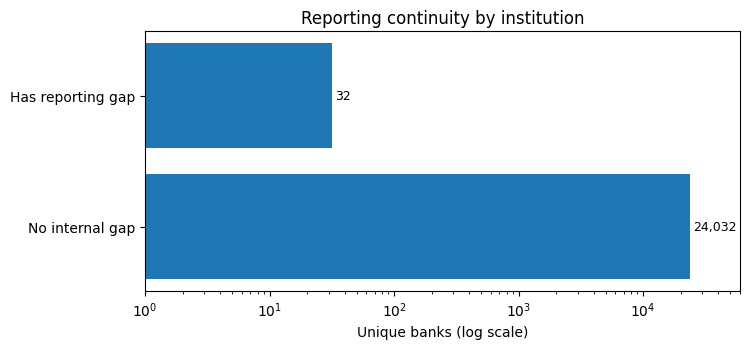

In [15]:
import matplotlib.pyplot as plt
# 32 gap banks were independently reconciled in Cell 2.1.3.
n_gap = int((coverage_df["unobserved_quarters"] > 0).sum())
n_all = len(coverage_df)
counts=[n_all-n_gap,n_gap]
fig,ax=plt.subplots(figsize=(7.6,3.6))
ax.barh(["No internal gap","Has reporting gap"],counts)
ax.set_xscale("log");ax.set(xlabel="Unique banks (log scale)",title="Reporting continuity by institution")
for j,v in enumerate(counts):ax.text(v*1.05,j,f"{v:,}",va="center",fontsize=9)
ax.set_xlim(1,max(counts)*2.5);plt.tight_layout();plt.show()

**Chart reading:** Reporting is mostly continuous *within observed lifetimes*; the small gap group still deserves investigation rather than automatic interpolation.

### 2.1.3 — Detailed Investigation of Reporting Gaps

**Purpose:** Identify the exact reporting gaps among the 32 banks with incomplete internal reporting histories.
**Check:** Compare consecutive reporting quarters and reconstruct the missing intervals without generating artificial financial observations.
**Readout:** A bank-level gap inventory showing missing periods, gap lengths, and surrounding observed quarters.

In [16]:
# 2.1.3 — Detailed Investigation of Reporting Gaps

# 1. Identify banks with internal reporting gaps
gap_certs = (
    coverage_df.loc[
        coverage_df["unobserved_quarters"] > 0, "CERT"
    ]
    .astype(int)
    .tolist()
)

# 2. Read reporting quarter indices for these banks only
gap_history = (
    bank_timeline
    .filter(pl.col("CERT").is_in(gap_certs))
    .select(["CERT", "quarter_index"])
    .sort(["CERT", "quarter_index"])
    .collect()
    .to_pandas()
)

# 3. Convert quarter index into readable year-quarter format
def quarter_label(index):
    return f"{index // 4}Q{index % 4 + 1}"

# 4. Reconstruct each reporting gap
gap_records = []

for cert, group in gap_history.groupby("CERT"):
    observed = sorted(group["quarter_index"].astype(int).unique())

    for previous, current in zip(observed[:-1], observed[1:]):
        gap_length = current - previous - 1

        if gap_length > 0:
            gap_records.append({
                "CERT": int(cert),
                "last_report_before_gap": quarter_label(previous),
                "first_missing_quarter": quarter_label(previous + 1),
                "last_missing_quarter": quarter_label(current - 1),
                "first_report_after_gap": quarter_label(current),
                "missing_quarters": gap_length
            })

gap_episodes = pd.DataFrame(gap_records)

# 5. Summary
print("DETAILED REPORTING GAP SUMMARY")
print("Banks affected:", gap_episodes["CERT"].nunique())
print("Distinct gap episodes:", len(gap_episodes))
print("Total unobserved quarters:", gap_episodes["missing_quarters"].sum())
print("Largest single gap:", gap_episodes["missing_quarters"].max())

print("\nTOP 15 LARGEST GAP EPISODES")

display(
    gap_episodes
    .sort_values("missing_quarters", ascending=False)
    .head(15)
)

print("\nGAP LENGTH DISTRIBUTION")

display(
    gap_episodes["missing_quarters"]
    .describe()
    .to_frame(name="Gap Length")
)

# 6. Reconcile with Cell 2.1.2
expected_missing = int(
    coverage_df["unobserved_quarters"].sum()
)

observed_missing = int(
    gap_episodes["missing_quarters"].sum()
)

assert observed_missing == expected_missing, (
    "Gap reconstruction does not match Cell 2.1.2"
)

print("\nGAP RECONCILIATION: PASS")

DETAILED REPORTING GAP SUMMARY
Banks affected: 32
Distinct gap episodes: 33
Total unobserved quarters: 92
Largest single gap: 30

TOP 15 LARGEST GAP EPISODES


,CERT,last_report_before_gap,first_missing_quarter,last_missing_quarter,first_report_after_gap,missing_quarters
14,27120,1989Q4,1990Q1,1997Q2,1997Q3,30
11,22399,1992Q3,1992Q4,1995Q4,1996Q1,13
32,34575,2005Q1,2005Q2,2007Q2,2007Q3,9
12,25899,1987Q1,1987Q2,1988Q3,1988Q4,6
10,20199,1987Q4,1988Q1,1988Q3,1988Q4,3
31,33692,1987Q3,1987Q4,1988Q1,1988Q2,2
4,16340,1988Q4,1989Q1,1989Q2,1989Q3,2
6,17007,1986Q2,1986Q3,1986Q4,1987Q1,2
0,1598,1988Q3,1988Q4,1988Q4,1989Q1,1
8,18342,2025Q4,2026Q1,2026Q1,2026Q2,1



GAP LENGTH DISTRIBUTION


,Gap Length
count,33.000000
mean,2.787879
std,5.521309
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,30.000000



GAP RECONCILIATION: PASS


##### Interpretation 2.1.3 — Detailed Reporting Gap Analysis

**Evidence:** There are 33 reporting-gap episodes involving 32 banks, totaling 92 unobserved quarters.

**Decision:** Preserve actual records; do not fabricate missing bank-quarters.

**Limit:** The causes of the gaps are not yet verified.

### 2.1.4 — Financial Context Around Major Reporting Gaps

**Purpose:** Examine financial observations immediately before and after the four longest reporting gaps.
**Check:** Retrieve surrounding bank-quarter records and compare key financial indicators without modifying the dataset.
**Readout:** A financial context table identifying cases requiring further investigation into reporting discontinuities or institutional changes.

In [17]:
# 2.1.4 — Financial Context Around Major Reporting Gaps

# 1. Select the four longest reporting gaps
major_gaps = (
    gap_episodes
    .nlargest(4, "missing_quarters")
    .copy()
)

major_certs = major_gaps["CERT"].astype(int).tolist()

# 2. Identify annual files surrounding each gap
relevant_years = set()

for row in major_gaps.itertuples(index=False):
    for quarter in [
        row.last_report_before_gap,
        row.first_report_after_gap
    ]:
        year = int(quarter[:4])
        relevant_years.update([year - 1, year, year + 1])

relevant_files = [
    p for p in BRONZE_FILES
    if int(p.parent.name.split("=")[1]) in relevant_years
]

# 3. Read only relevant banks and financial fields
context_fields = [
    "CERT", "REPDTE", "STNAME",
    "ASSET", "DEP", "EQ", "ROA"
]

context_data = (
    pl.scan_parquet(
        [str(p) for p in relevant_files],
        hive_partitioning=False
    )
    .filter(pl.col("CERT").is_in(major_certs))
    .select(context_fields)
    .collect()
    .to_pandas()
)

context_data["REPDTE"] = pd.to_datetime(
    context_data["REPDTE"]
)

# 4. Extract two reports before and after each gap
context_records = []

for row in major_gaps.itertuples(index=False):

    bank_data = (
        context_data[context_data["CERT"] == row.CERT]
        .sort_values("REPDTE")
    )

    before_date = pd.Period(
        row.last_report_before_gap, freq="Q"
    ).end_time.normalize()

    after_date = pd.Period(
        row.first_report_after_gap, freq="Q"
    ).end_time.normalize()

    before = bank_data[
        bank_data["REPDTE"] <= before_date
    ].tail(2).copy()

    after = bank_data[
        bank_data["REPDTE"] >= after_date
    ].head(2).copy()

    for side, frame in [("Before", before), ("After", after)]:
        frame["gap_length"] = row.missing_quarters
        frame["position"] = side
        context_records.append(frame)

gap_financial_context = pd.concat(
    context_records, ignore_index=True
)

# 5. Display observations
print("FINANCIAL CONTEXT AROUND MAJOR REPORTING GAPS")

display(
    gap_financial_context[
        [
            "CERT", "gap_length", "position",
            "REPDTE", "STNAME",
            "ASSET", "DEP", "EQ", "ROA"
        ]
    ].sort_values(["CERT", "REPDTE"])
)

# 6. Inspect available reference snapshots
print("\nAVAILABLE INSTITUTION / EVENT REFERENCES")

for name, location in PHASE1.get(
    "reference_snapshot_paths", {}
).items():
    print(f"{name}: {location}")

FINANCIAL CONTEXT AROUND MAJOR REPORTING GAPS


,CERT,gap_length,position,REPDTE,STNAME,ASSET,DEP,EQ,ROA
4,22399,13,Before,1992-06-30,NEW JERSEY,1530.0,76.0,1416.0,7.568508
5,22399,13,Before,1992-09-30,NEW JERSEY,1419.0,0.0,1402.0,3.899963
6,22399,13,After,1996-03-31,NEW JERSEY,108.0,0.0,108.0,0.000000
7,22399,13,After,1996-06-30,NEW JERSEY,108.0,0.0,108.0,0.000000
12,25899,6,Before,1986-12-31,TEXAS,49852.0,46294.0,3011.0,-1.119968
13,25899,6,Before,1987-03-31,TEXAS,52282.0,48952.0,3066.0,-0.430807
14,25899,6,After,1988-12-31,TEXAS,81595.0,0.0,79914.0,18.881059
15,25899,6,After,1989-03-31,TEXAS,105752.0,0.0,104427.0,0.000000
0,27120,30,Before,1989-09-30,MINNESOTA,1839.0,0.0,1041.0,1.248543
1,27120,30,Before,1989-12-31,MINNESOTA,1309.0,0.0,1039.0,0.072865



AVAILABLE INSTITUTION / EVENT REFERENCES
failures: C:\học tập\kì 7\Big data\Final\Bản nháp\data\raw\fdic\reference\contract_a1cd7440e6a09ca8\snapshots\failures\cf76ee1fb3a36a5745ea124b.parquet
institutions: C:\học tập\kì 7\Big data\Final\Bản nháp\data\raw\fdic\reference\contract_a1cd7440e6a09ca8\snapshots\institutions\5a738dc47527b98919aef7db.parquet


##### Interpretation 2.1.4 — Financial Context Around Reporting Gaps

**Evidence:** The largest gaps coincide with sizable changes in assets, deposits or equity for some banks.

**Decision:** Calculate temporal growth only across consecutive quarters.

**Limit:** A large change after a gap cannot be attributed to distress without institutional evidence.

### 2.1.5 — Institutional & Failure Reference Investigation

**Purpose:** Investigate whether banks with major reporting gaps have identifiable institutional characteristics or recorded failure events.
**Check:** Inspect the available FDIC Institutions and Failures reference datasets and retrieve records associated with the four banks under investigation.
**Readout:** Reference schemas, matching institution records, and potential event information requiring further verification.

In [18]:
# 2.1.5 — Institutional & Failure Reference Investigation

reference_paths = PHASE1["reference_snapshot_paths"]

major_certs = major_gaps["CERT"].astype(int).tolist()

reference_results = {}

for source, location in reference_paths.items():

    path = Path(location)

    if not path.is_absolute():
        path = ROOT / path

    print(f"\n{'='*65}")
    print("SOURCE:", source.upper())
    print("PATH:", path)

    if not path.exists():
        print("STATUS: FILE NOT FOUND")
        continue

    # 1. Inspect schema and metadata
    metadata = pq.ParquetFile(path)
    columns = metadata.schema_arrow.names

    print("Total records:", f"{metadata.metadata.num_rows:,}")
    print("Total columns:", len(columns))
    print("\nAvailable fields:")
    print(columns)

    # 2. Identify bank identifier
    cert_column = next(
        (c for c in columns if c.upper() == "CERT"),
        None
    )

    if cert_column is None:
        print("\nCERT field not found — manual mapping required.")
        continue

    # 3. Identify relevant institutional/event columns
    candidate_fields = {
        "CERT", "NAME", "INSTNAME", "NAMEHCR",
        "ACTIVE", "CHANGEC1", "CHANGEC",
        "ENDEFYMD", "FAILDATE", "RESTYPE",
        "RESTYPE1", "STNAME", "CITY",
        "DATEUPDT", "EFFDATE"
    }

    selected_columns = [
        c for c in columns
        if c.upper() in candidate_fields
    ]

    # 4. Retrieve only the four banks under investigation
    matches = (
        pl.scan_parquet(str(path))
        .filter(
            pl.col(cert_column)
            .cast(pl.Int64, strict=False)
            .is_in(major_certs)
        )
        .select(selected_columns)
        .collect()
        .to_pandas()
    )

    reference_results[source] = matches

    print("\nMATCHED RECORDS:", len(matches))

    if not matches.empty:
        display(matches.head(30))
    else:
        print("No matching records found.")


SOURCE: FAILURES
PATH: C:\học tập\kì 7\Big data\Final\Bản nháp\data\raw\fdic\reference\contract_a1cd7440e6a09ca8\snapshots\failures\cf76ee1fb3a36a5745ea124b.parquet
Total records: 4,117
Total columns: 10

Available fields:
['CERT', 'NAME', 'CITYST', 'FAILDATE', 'FAILYR', 'COST', 'QBFASSET', 'QBFDEP', 'RESTYPE', 'RESTYPE1']

MATCHED RECORDS: 0
No matching records found.

SOURCE: INSTITUTIONS
PATH: C:\học tập\kì 7\Big data\Final\Bản nháp\data\raw\fdic\reference\contract_a1cd7440e6a09ca8\snapshots\institutions\5a738dc47527b98919aef7db.parquet
Total records: 27,835
Total columns: 9

Available fields:
['CERT', 'NAME', 'STNAME', 'BKCLASS', 'ACTIVE', 'ESTYMD', 'ENDEFYMD', 'CHANGEC1', 'INSDATE']

MATCHED RECORDS: 2


,CERT,NAME,STNAME,ACTIVE,ENDEFYMD,CHANGEC1
0,22399,"Metlife Trust Company, National Association",New Jersey,0,01/01/2002,223.0
1,25899,National Loan Bank (A Bank in Liquidation),Texas,0,02/15/1994,240.0


##### Interpretation 2.1.5 — Institutional and Failure Reference Investigation

**Evidence:** The longest-gap banks show incomplete reference coverage; some listed end dates do not explain earlier gaps.

**Decision:** Keep those records and review institution histories.

**Limit:** A missing event match is not proof that an institution survived.

### 2.1.6 — Reference Coverage for Banks with Reporting Gaps (Corrected)

**Objective:** Link gap-affected bank IDs to both FDIC reference snapshots without false negatives from decimal-formatted string identifiers.

**Method:** Load the reference CERT values, normalize integral strings such as `"14571.0"` into integer identifiers **before any filter or join**, validate parsing quality, then count matches by bank.

**Expected output:** Corrected reference coverage and a conversion audit. Registry presence is **not** proof of a bank failure.

In [19]:
# 2.1.6 — Reference Coverage for Banks with Reporting Gaps
# Normalize decimal-formatted CERT strings BEFORE filtering or joining.
import numpy as np
# 1. Gap-affected cohort and validated identifier parser
gap_banks = coverage_df.loc[
    coverage_df["unobserved_quarters"] > 0,
    ["CERT", "reported_quarters", "unobserved_quarters", "first_report", "last_report"]
].copy()
gap_banks["CERT"] = pd.to_numeric(gap_banks["CERT"], errors="raise").astype("int64")
assert gap_banks["CERT"].is_unique


def normalize_reference_cert(values, label="reference CERT"):
    """Normalize integer IDs saved as strings like '14571.0'; reject malformed/noninteger IDs."""
    raw = pd.Series(values, copy=False).astype("string").str.strip().replace("", pd.NA)
    numeric = pd.to_numeric(raw, errors="coerce")
    invalid = raw.notna() & (
        numeric.isna() | ~np.isfinite(numeric.astype("float64"))
        | numeric.mod(1).ne(0).fillna(False)
    )
    if invalid.any():
        examples = raw.loc[invalid].head(5).tolist()
        raise ValueError(f"{label}: invalid/fractional CERT values: {examples}")
    return numeric.astype("Int64")

# 2. Locate reference snapshots
reference_files = {}
for source in ["institutions", "failures"]:
    path = Path(PHASE1["reference_snapshot_paths"][source])
    if not path.is_absolute():
        path = ROOT / path
    assert path.is_file(), f"Missing reference file: {path}"
    reference_files[source] = path

# 3. Read reference snapshots once, normalize full registry BEFORE filtering
reference_columns = {
    "institutions": ["CERT", "NAME", "BKCLASS", "ACTIVE", "ESTYMD", "ENDEFYMD", "CHANGEC1"],
    "failures": ["CERT", "FAILDATE", "RESTYPE", "RESTYPE1"],
}
reference_snapshots = {}
reference_conversion_audit = []
for kind, columns in reference_columns.items():
    raw = pl.scan_parquet(str(reference_files[kind])).select(columns).collect().to_pandas()
    raw["CERT"] = normalize_reference_cert(raw["CERT"], f"{kind}.CERT")
    reference_snapshots[kind] = raw
    reference_conversion_audit.append({
        "source": kind,
        "total_rows": len(raw),
        "missing_cert": int(raw["CERT"].isna().sum()),
        "valid_cert": int(raw["CERT"].notna().sum()),
        "unique_cert": int(raw["CERT"].nunique())
    })

institution_matches = reference_snapshots["institutions"].loc[
    reference_snapshots["institutions"]["CERT"].isin(gap_banks["CERT"])
].copy()
event_matches = reference_snapshots["failures"].loc[
    reference_snapshots["failures"]["CERT"].isin(gap_banks["CERT"])
].copy()

print("REFERENCE CERT CONVERSION QUALITY")
display(pd.DataFrame(reference_conversion_audit))
print("Gap IDs:", gap_banks["CERT"].dtype,
      "Institution IDs:", institution_matches["CERT"].dtype,
      "Event IDs:", event_matches["CERT"].dtype)

# 4. Count records without assuming reference keys are unique
institution_counts = institution_matches.groupby("CERT").size().rename("institution_records")
event_counts = event_matches.groupby("CERT").size().rename("failure_assistance_records")
gap_reference_audit = gap_banks.join(institution_counts, on="CERT").join(event_counts, on="CERT")
count_cols = ["institution_records", "failure_assistance_records"]
gap_reference_audit[count_cols] = gap_reference_audit[count_cols].fillna(0).astype(int)

# 5. Classify reference coverage, not exit/failure type
def reference_status(row):
    inst = row["institution_records"] > 0
    event = row["failure_assistance_records"] > 0
    if inst and event: return "Both sources"
    if inst: return "Institutions only"
    if event: return "Failures/Assistance only"
    return "Neither source"

gap_reference_audit["reference_status"] = gap_reference_audit.apply(reference_status, axis=1)

print("\nREFERENCE COVERAGE SUMMARY")
print("Gap banks:", len(gap_reference_audit))
print("Institution matches:", int(gap_reference_audit["institution_records"].gt(0).sum()))
print("Failure/Assistance matches:", int(gap_reference_audit["failure_assistance_records"].gt(0).sum()))
print("Unmatched in both:", int(gap_reference_audit["reference_status"].eq("Neither source").sum()))
display(gap_reference_audit["reference_status"].value_counts().rename_axis("reference_status").reset_index(name="n_banks"))
display(gap_reference_audit.sort_values("unobserved_quarters", ascending=False))
print("\nMATCHED REFERENCE RECORDS")
display(institution_matches.sort_values("CERT"))
display(event_matches.sort_values("CERT"))

assert len(gap_reference_audit) == len(gap_certs)
assert gap_reference_audit["CERT"].is_unique
assert set(gap_reference_audit["CERT"]) == set(gap_certs)
print("\nREFERENCE COVERAGE RECONCILIATION: PASS")

REFERENCE CERT CONVERSION QUALITY


,source,total_rows,missing_cert,valid_cert,unique_cert
0,institutions,27835,0,27835,27835
1,failures,4117,488,3629,3585


Gap IDs: int64 Institution IDs: Int64 Event IDs: Int64

REFERENCE COVERAGE SUMMARY
Gap banks: 32
Institution matches: 28
Failure/Assistance matches: 2
Unmatched in both: 4


,reference_status,n_banks
0,Institutions only,26
1,Neither source,4
2,Both sources,2


,CERT,reported_quarters,unobserved_quarters,first_report,last_report,institution_records,failure_assistance_records,reference_status
18278,27120,95,30,1987-12-31,2018-12-31,0,0,Neither source
2250,22399,59,13,1984-03-31,2001-12-31,1,0,Institutions only
1870,34575,47,9,1997-06-30,2011-03-31,0,0,Neither source
4173,25899,30,6,1985-03-31,1993-12-31,1,0,Institutions only
15140,16340,66,3,1984-03-31,2001-03-31,1,0,Institutions only
22123,20199,29,3,1984-03-31,1991-12-31,1,0,Institutions only
18340,33692,154,2,1987-09-30,2026-06-30,1,0,Institutions only
654,17007,51,2,1984-03-31,1997-03-31,1,0,Institutions only
4891,29657,169,1,1984-03-31,2026-06-30,1,0,Institutions only
5454,1598,42,1,1984-03-31,1994-09-30,1,0,Institutions only



MATCHED REFERENCE RECORDS


,CERT,NAME,BKCLASS,ACTIVE,ESTYMD,ENDEFYMD,CHANGEC1
1040,1598,First of America Bank-Ann Arbor,SM,0,04/11/1905,12/31/1994,223.0
7647,11990,"Lafayette Savings Bank, FSB",SB,0,06/26/1869,11/01/2014,221.0
8216,13012,First Community Bank,SM,1,01/07/1920,12/31/9999,810.0
10194,15967,Goshen Savings Bank,SB,0,04/08/1871,03/30/2001,223.0
10512,16340,"First Midwest Trust Company, National Association",NC,0,12/01/1945,06/29/2001,223.0
11066,17007,KeyBank National Association,N,0,04/02/1951,06/30/1997,223.0
12110,18205,Tolland Bank,SI,0,01/01/1841,04/01/2004,223.0
13153,19360,"Beneficial Savings Bank, F.S.B.",SB,0,01/26/1965,06/30/1998,223.0
13866,20199,National Asset Bank (A Bank In Liquidation),NC,0,06/19/1970,09/30/1992,240.0
15578,22399,"Metlife Trust Company, National Association",NC,0,01/04/1977,01/01/2002,223.0


,CERT,FAILDATE,RESTYPE,RESTYPE1
3854,28612,9/17/2010,FAILURE,PA
3983,31581,1/20/2012,FAILURE,PA



REFERENCE COVERAGE RECONCILIATION: PASS


##### Interpretation 2.1.6 — Corrected Reference Coverage

**Evidence:** Report the actual institution and event match counts from the corrected cell. Previous event counts based on `cast(Int64, strict=False)` applied to string identifiers were unreliable.

**Decision:** Preserve all gap-affected banks, flag unmatched records, and never infer failure status solely from registry coverage.

**Limit:** This audit checks snapshot linkage, not historical event-type classification or report-vintage completeness.

### 2.1.7 — Reference Coverage Comparison: Gap vs. Non-Gap Banks

**Purpose:** Determine whether incomplete institutional reference coverage is disproportionately associated with banks experiencing internal reporting gaps.
**Check:** Compare Institution and Failure/Assistance linkage rates between banks with and without reporting gaps across the complete FDIC panel.
**Readout:** Population-level reference coverage rates and evidence on whether the 32 gap-affected banks warrant additional investigation.

In [20]:
# 2.1.7 — Gap vs. non-gap banks: reference linkage using NORMALIZED identifiers
# No stale zero-event result or hard-coded 28/0/4 assumptions.
institution_ids = set(reference_snapshots["institutions"]["CERT"].dropna().astype("int64"))
event_ids = set(reference_snapshots["failures"]["CERT"].dropna().astype("int64"))

bank_ref_audit = coverage_df[["CERT", "reported_quarters", "unobserved_quarters"]].copy()
bank_ref_audit["CERT"] = pd.to_numeric(bank_ref_audit["CERT"], errors="raise").astype("int64")
bank_ref_audit["group"] = bank_ref_audit["unobserved_quarters"].gt(0).map({
    True: "With gaps", False: "Without gaps"
})
bank_ref_audit["institution_match"] = bank_ref_audit["CERT"].isin(institution_ids)
bank_ref_audit["event_match"] = bank_ref_audit["CERT"].isin(event_ids)
bank_ref_audit["unmatched_both"] = ~bank_ref_audit["institution_match"] & ~bank_ref_audit["event_match"]

coverage_comparison = (bank_ref_audit.groupby("group")
    .agg(n_banks=("CERT", "size"), institution_matches=("institution_match", "sum"),
         event_matches=("event_match", "sum"), unmatched_both=("unmatched_both", "sum"))
    .reset_index())
for col in ["institution_matches", "event_matches", "unmatched_both"]:
    coverage_comparison[col + "_pct"] = (
        100 * coverage_comparison[col] / coverage_comparison["n_banks"]
    ).round(2)

print("REFERENCE COVERAGE COMPARISON (NORMALIZED CERT)")
display(coverage_comparison)
unmatched_gap_banks = bank_ref_audit.loc[
    bank_ref_audit["group"].eq("With gaps") & bank_ref_audit["unmatched_both"]
].sort_values("unobserved_quarters", ascending=False)
print("\nUNMATCHED BANKS WITH REPORTING GAPS")
display(unmatched_gap_banks)

gap_subset = bank_ref_audit.loc[bank_ref_audit["group"].eq("With gaps")]
reconciled = gap_subset.merge(
    gap_reference_audit[["CERT", "institution_records", "failure_assistance_records"]],
    on="CERT", how="left", validate="one_to_one"
)
checks = {
    "Gap-bank cohort matches Section 2.1.6": set(gap_subset["CERT"]) == set(gap_reference_audit["CERT"]),
    "Institution matches agree with source record counts": (
        reconciled["institution_match"] == reconciled["institution_records"].gt(0)
    ).all(),
    "Event matches agree with source record counts": (
        reconciled["event_match"] == reconciled["failure_assistance_records"].gt(0)
    ).all(),
    "Full panel bank IDs retained": (len(bank_ref_audit) == coverage_df["CERT"].nunique()),
    "Event coverage is nonzero, consistent with raw registry": int(bank_ref_audit["event_match"].sum()) > 0,
}
print("\nREFERENCE COVERAGE VALIDATION")
display(pd.DataFrame([{"check": k, "status": "PASS" if bool(v) else "FAIL"} for k,v in checks.items()]))
assert all(checks.values()), "Reference coverage did not reconcile; inspect normalized CERTs."
print("\nCELL 2.1.7: PASS")

REFERENCE COVERAGE COMPARISON (NORMALIZED CERT)


,group,n_banks,institution_matches,event_matches,unmatched_both,institution_matches_pct,event_matches_pct,unmatched_both_pct
0,With gaps,32,28,2,4,87.50,6.25,12.50
1,Without gaps,24032,23801,3239,231,99.04,13.48,0.96



UNMATCHED BANKS WITH REPORTING GAPS


,CERT,reported_quarters,unobserved_quarters,group,institution_match,event_match,unmatched_both
18278,27120,95,30,With gaps,False,False,True
1870,34575,47,9,With gaps,False,False,True
14373,32816,36,1,With gaps,False,False,True
19719,18342,169,1,With gaps,False,False,True



REFERENCE COVERAGE VALIDATION


,check,status
0,Gap-bank cohort matches Section 2.1.6,PASS
1,Institution matches agree with source record c...,PASS
2,Event matches agree with source record counts,PASS
3,Full panel bank IDs retained,PASS
4,"Event coverage is nonzero, consistent with raw...",PASS



CELL 2.1.7: PASS


##### Interpretation 2.1.7 — Population-Level Reference Coverage (Corrected)

**Evidence:** Institution and Failure/Assistance linkage rates now use the normalized identifiers from Section 2.1.6. The earlier zero-event table was caused by unsafe conversion of decimal-formatted CERT strings and **must not be used**.

**Decision:** Use `coverage_comparison` from this corrected cell for the gap/non-gap comparison; Section 2.1.8A independently documents the source of the former parsing error.

**Limit:** Event-registry matches include assistance/reorganization events; they are not equivalent to confirmed failures.

### 2.1.8 — Failure Registry Identifier Verification

**Purpose:** Independently verify integer CERT normalization in the FDIC Failures/Assistance registry after the corrected linkage of Sections 2.1.6–2.1.7.
**Check:** Inspect raw identifier formatting and compare normalized identifier sets with the financials reference population.
**Readout:** A reproducible conversion and linkage verification, without introducing an inconsistent intermediate join.

In [21]:
# 2.1.8 — Failure Registry Identifier Investigation

# 1. Read failure identifiers and essential event information
failure_check = pq.read_table(
    reference_files["failures"],
    columns=["CERT", "NAME", "FAILDATE", "RESTYPE"]
).to_pandas()

# 2. Inspect raw identifiers
print("FAILURE REGISTRY — RAW IDENTIFIERS")
print("Total event records:", len(failure_check))
print("CERT dtype:", failure_check["CERT"].dtype)
print("Missing CERT:", failure_check["CERT"].isna().sum())

display(failure_check.head(10))

# 3. Convert identifiers for comparison (diagnostic only)
failure_check["CERT_numeric"] = normalize_reference_cert(
    failure_check["CERT"], "failure_check.CERT"
)

financial_ids = set(
    pd.to_numeric(coverage_df["CERT"], errors="raise").astype("int64")
)

failure_ids = set(
    failure_check["CERT_numeric"]
    .dropna()
    .astype("int64")
)

# 4. Compare identifiers
common_ids = financial_ids & failure_ids

print("\nIDENTIFIER COMPARISON")
print("Unique Financials CERT:", len(financial_ids))
print("Unique Failures CERT:", len(failure_ids))
print("Common CERT:", len(common_ids))
print("Failure CERT conversion errors:",
      failure_check["CERT_numeric"].isna().sum()
      - failure_check["CERT"].isna().sum())

print("\nIDENTIFIER RANGES")
print("Financials CERT min/max:",
      min(financial_ids), max(financial_ids))

if failure_ids:
    print("Failures CERT min/max:",
          min(failure_ids), max(failure_ids))

# 5. Inspect unmatched event identifiers
print("\nSAMPLE FAILURE CERT VALUES")

display(
    failure_check[
        ["CERT", "CERT_numeric", "NAME", "FAILDATE", "RESTYPE"]
    ].head(20)
)

print("\nFAILURE IDENTIFIER DIAGNOSTIC")

if not failure_ids:
    print("REVIEW: No usable numeric failure identifiers.")
elif len(common_ids) == 0:
    print("REVIEW: Financials and Failures CERT sets do not overlap.")
else:
    print("MATCHES FOUND:", len(common_ids))
    print("Sections 2.1.6–2.1.7 already use the normalized identifiers.")

FAILURE REGISTRY — RAW IDENTIFIERS
Total event records: 4117
CERT dtype: object
Missing CERT: 488


,CERT,NAME,FAILDATE,RESTYPE
0,None,BANK OF AMERICA TRUST CO.,4/19/1934,FAILURE
1,None,FON DU LAC STATE BANK,5/28/1934,FAILURE
2,None,FIRST NATIONAL BANK OF LIMA,7/18/1934,FAILURE
3,None,FLORENCE DEPOSIT BANK,7/18/1934,FAILURE
4,None,BANK OF LEWISPORT,8/6/1934,FAILURE
5,None,FARMERS STATE BANK OF BONGARDS,9/13/1934,FAILURE
6,None,FARMERS & TRADERS BANK,10/11/1934,FAILURE
7,None,PICKENS COUNTY BANK,10/13/1934,FAILURE
8,None,THE STATE BANK,11/16/1934,FAILURE
9,None,CLIFFSIDE PARK TITLE GUARANTEE & TRUST CO.,1/3/1935,FAILURE



IDENTIFIER COMPARISON
Unique Financials CERT: 24064
Unique Failures CERT: 3585
Common CERT: 3241
Failure CERT conversion errors: 0

IDENTIFIER RANGES
Financials CERT min/max: 8 91393
Failures CERT min/max: 40 91189

SAMPLE FAILURE CERT VALUES


,CERT,CERT_numeric,NAME,FAILDATE,RESTYPE
0,None,<NA>,BANK OF AMERICA TRUST CO.,4/19/1934,FAILURE
1,None,<NA>,FON DU LAC STATE BANK,5/28/1934,FAILURE
2,None,<NA>,FIRST NATIONAL BANK OF LIMA,7/18/1934,FAILURE
3,None,<NA>,FLORENCE DEPOSIT BANK,7/18/1934,FAILURE
4,None,<NA>,BANK OF LEWISPORT,8/6/1934,FAILURE
5,None,<NA>,FARMERS STATE BANK OF BONGARDS,9/13/1934,FAILURE
6,None,<NA>,FARMERS & TRADERS BANK,10/11/1934,FAILURE
7,None,<NA>,PICKENS COUNTY BANK,10/13/1934,FAILURE
8,None,<NA>,THE STATE BANK,11/16/1934,FAILURE
9,None,<NA>,CLIFFSIDE PARK TITLE GUARANTEE & TRUST CO.,1/3/1935,FAILURE



FAILURE IDENTIFIER DIAGNOSTIC
MATCHES FOUND: 3241
Sections 2.1.6–2.1.7 already use the normalized identifiers.


### 2.1.8A — Historical Parsing-Error Diagnosis (Verification Only)

**Purpose:** Demonstrate why direct `cast(Int64, strict=False)` of strings such as `"14571.0"` produced false negative matches in an earlier implementation.
**Check:** Compare this unsafe cast as a *diagnostic example* with the verified normalized identifier sets already used in Sections 2.1.6–2.1.7.
**Readout:** Evidence of unsafe parsing and an independent assertion that the corrected linkage is internally consistent. **No downstream code depends on the bad cast.**

In [22]:
# 2.1.8A — Diagnose an unsafe historical cast; certify the corrected linkage
print("CERT NORMALIZATION DIAGNOSTIC")
print("Normalized event IDs used in Section 2.1.7:", len(event_ids))
print("Raw CERT examples:", failure_check["CERT"].dropna().head(10).tolist())

# Diagnostic only. Never use directly cast IDs for joins or labels.
unsafe_parse_examples = (
    pl.scan_parquet(str(reference_files["failures"]))
    .select([
        pl.col("CERT").alias("raw_cert"),
        pl.col("CERT").cast(pl.Int64, strict=False).alias("unsafe_int_cast")
    ])
    .filter(pl.col("raw_cert").is_not_null() & pl.col("unsafe_int_cast").is_null())
    .limit(10).collect().to_pandas()
)
print("\nDECIMAL-FORMATTED VALUES MISSED BY DIRECT CAST (examples)")
display(unsafe_parse_examples)

verified_event_ids = set(failure_check["CERT_numeric"].dropna().astype("int64"))
verified_financial_ids = set(pd.to_numeric(coverage_df["CERT"], errors="raise").astype("int64"))
verified_common_ids = verified_financial_ids & verified_event_ids

assert event_ids == verified_event_ids, "Event IDs differ between normalized snapshots and independent audit."
assert financial_ids == verified_financial_ids, "Financial IDs differ between independent audits."
assert bank_ref_audit["event_match"].equals(bank_ref_audit["CERT"].isin(verified_event_ids))
assert int(bank_ref_audit["event_match"].sum()) == len(verified_common_ids)

# Backwards-compatible names used in later notebook sections
common_ids = verified_common_ids
corrected_coverage = coverage_comparison.copy()

print("\nVERIFIED IDENTIFIER MATCHING")
print("Unique event CERT:", len(verified_event_ids))
print("Unique financial CERT:", len(verified_financial_ids))
print("Common financials–event CERT:", len(verified_common_ids))
display(corrected_coverage)
print("\n2.1.8A LINKAGE VERIFICATION: PASS")

CERT NORMALIZATION DIAGNOSTIC
Normalized event IDs used in Section 2.1.7: 3585
Raw CERT examples: ['14571.0', '14987.0', '13164.0', '19276.0', '12227.0', '19791.0', '1876.0', '18254.0', '18316.0', '10472.0']

DECIMAL-FORMATTED VALUES MISSED BY DIRECT CAST (examples)


,raw_cert,unsafe_int_cast
0,14571.0,NaN
1,14987.0,NaN
2,13164.0,NaN
3,19276.0,NaN
4,12227.0,NaN
5,19791.0,NaN
6,1876.0,NaN
7,18254.0,NaN
8,18316.0,NaN
9,10472.0,NaN



VERIFIED IDENTIFIER MATCHING
Unique event CERT: 3585
Unique financial CERT: 24064
Common financials–event CERT: 3241


,group,n_banks,institution_matches,event_matches,unmatched_both,institution_matches_pct,event_matches_pct,unmatched_both_pct
0,With gaps,32,28,2,4,87.50,6.25,12.50
1,Without gaps,24032,23801,3239,231,99.04,13.48,0.96



2.1.8A LINKAGE VERIFICATION: PASS


##### Interpretation 2.1.8A — Identifier Normalization

**Evidence:** Decimal-formatted string IDs can fail a direct Polars integer cast but are correctly recovered by validated numeric normalization. Inspect the actual normalized registry overlap printed in this run; any previously cached counts belong to the old execution.

**Decision:** All reference joins use normalized integral CERT identifiers *from the first linkage step*.

**Limit:** The Failures/Assistance registry includes other event types, so event matching must not be confused with confirmed failure-label assignment.

### 2.1.9 — Event Investigation for Banks with Reporting Gaps

**Purpose:** Examine Failure/Assistance events associated with banks experiencing reporting interruptions.
**Check:** Retrieve matched event records, compare event dates with reporting histories, and identify potential temporal inconsistencies.
**Readout:** Verified event types, dates, and temporal relationships requiring further investigation.

In [23]:
# 2.1.9 — Event Investigation for Banks with Reporting Gaps

# 1. Identify gap-affected banks with event matches
matched_gap_certs = sorted(
    bank_ref_audit.loc[
        (bank_ref_audit["group"] == "With gaps")
        & bank_ref_audit["event_match"],
        "CERT"
    ].astype(int).tolist()
)

print("BANKS WITH GAPS AND MATCHED EVENTS:", matched_gap_certs)

# 2. Retrieve original event records
gap_events = failure_check.loc[
    failure_check["CERT_numeric"].isin(matched_gap_certs),
    ["CERT_numeric", "NAME", "FAILDATE", "RESTYPE"]
].copy()

gap_events = gap_events.rename(
    columns={"CERT_numeric": "CERT"}
)

gap_events["CERT"] = gap_events["CERT"].astype("int64")

gap_events["event_date"] = pd.to_datetime(
    gap_events["FAILDATE"],
    format="mixed",
    errors="coerce"
)

# 3. Attach reporting history
history = coverage_df[
    ["CERT", "first_report", "last_report",
     "reported_quarters", "unobserved_quarters"]
].copy()

gap_events = gap_events.merge(
    history,
    on="CERT",
    how="left",
    validate="many_to_one"
)

# 4. Classify temporal position of each event
def event_timing(row):
    date = row["event_date"]

    if pd.isna(date):
        return "UNPARSEABLE_DATE"

    if date < pd.Timestamp(row["first_report"]):
        return "BEFORE_FIRST_REPORT"

    if date > pd.Timestamp(row["last_report"]):
        return "AFTER_LAST_REPORT"

    return "WITHIN_REPORTING_SPAN"

gap_events["event_timing"] = gap_events.apply(
    event_timing, axis=1
)

print("\nMATCHED EVENT DETAILS")

display(
    gap_events
    .sort_values(["CERT", "event_date"])
    [[
        "CERT", "NAME", "RESTYPE", "FAILDATE",
        "first_report", "last_report",
        "unobserved_quarters", "event_timing"
    ]]
)

# 5. Examine event dates relative to individual gaps
gap_event_comparison = gap_episodes[
    gap_episodes["CERT"].isin(matched_gap_certs)
].merge(
    gap_events[["CERT", "RESTYPE", "event_date"]],
    on="CERT",
    how="left",
    validate="many_to_many"
)

def relation_to_gap(row):
    date = row["event_date"]

    if pd.isna(date):
        return "UNPARSEABLE_DATE"

    before = pd.Period(
        row["last_report_before_gap"], freq="Q"
    ).end_time.normalize()

    after = pd.Period(
        row["first_report_after_gap"], freq="Q"
    ).end_time.normalize()

    if date <= before:
        return "BEFORE_GAP"

    if date > after:
        return "AFTER_GAP"

    return "BETWEEN_BOUNDARY_REPORTS"

gap_event_comparison["event_vs_gap"] = (
    gap_event_comparison.apply(relation_to_gap, axis=1)
)

print("\nEVENT TIMING RELATIVE TO REPORTING GAPS")

display(
    gap_event_comparison[
        ["CERT", "last_report_before_gap",
         "first_report_after_gap", "missing_quarters",
         "RESTYPE", "event_date", "event_vs_gap"]
    ]
)

print("\nEVENT INVESTIGATION SUMMARY")
print("Matching banks:", len(matched_gap_certs))
print("Matching event records:", len(gap_events))
print("Unparseable event dates:",
      int(gap_events["event_date"].isna().sum()))

BANKS WITH GAPS AND MATCHED EVENTS: [28612, 31581]

MATCHED EVENT DETAILS


,CERT,NAME,RESTYPE,FAILDATE,first_report,last_report,unobserved_quarters,event_timing
0,28612,MARITIME SAVINGS BANK,FAILURE,9/17/2010,1984-03-31,2010-06-30,1,AFTER_LAST_REPORT
1,31581,AMERICAN EAGLE SAVINGS BANK,FAILURE,1/20/2012,1984-03-31,2011-12-31,1,AFTER_LAST_REPORT



EVENT TIMING RELATIVE TO REPORTING GAPS


,CERT,last_report_before_gap,first_report_after_gap,missing_quarters,RESTYPE,event_date,event_vs_gap
0,28612,1993Q1,1993Q3,1,FAILURE,2010-09-17,AFTER_GAP
1,31581,1995Q3,1996Q1,1,FAILURE,2012-01-20,AFTER_GAP



EVENT INVESTIGATION SUMMARY
Matching banks: 2
Matching event records: 2
Unparseable event dates: 0


##### Interpretation 2.1.9 — Event Investigation for Banks with Reporting Gaps

**Evidence:** Two gap-affected banks have later recorded failure dates, showing that reporting gaps and failures are distinct events.

**Decision:** Compare event dates to pre-event reporting history.

**Limit:** The registry alone does not establish why every other bank stopped reporting.

<a id="p2-s22"></a>
## 2.2 — Missingness and reporting-regime changes

Separate field-wide reporting discontinuities from individual missing values; do not fill structurally unavailable fields.

### 2.2.1 — Global Financial Missingness Profiling

**Purpose:** Quantify missing values across all financial variables in the FDIC bank-quarter panel.
**Check:** Calculate null and NaN counts, overall missingness rates, and variable-level missingness rankings.
**Readout:** A comprehensive missingness profile identifying variables requiring temporal investigation.

**Decision Rule:** No variables will be dropped or imputed based solely on global missingness rates.

In [24]:
# 2.2.1 — Global Financial Missingness Profiling

# 1. Identify financial variables from the verified Bronze schema
schema_columns = pq.ParquetFile(
    BRONZE_FILES[0]
).schema_arrow.names

financial_cols = [
    col for col in schema_columns
    if col not in ["CERT", "REPDTE", "STNAME"]
]

print("FINANCIAL MISSINGNESS PROFILING")
print("Number of financial variables:", len(financial_cols))

assert len(financial_cols) == 133, (
    "Unexpected number of financial variables"
)

# 2. Build lazy scan
financial_lf = pl.scan_parquet(
    [str(p) for p in BRONZE_FILES],
    hive_partitioning=False
)

# 3. Calculate NULL and NaN counts separately
expressions = [pl.len().alias("__rows")]

for col in financial_cols:
    expressions.extend([
        pl.col(col).null_count().alias(f"null__{col}"),
        pl.col(col).is_nan().fill_null(False)
        .sum().alias(f"nan__{col}")
    ])

missing_stats = financial_lf.select(
    expressions
).collect().row(0, named=True)

n_rows = int(missing_stats["__rows"])

# 4. Construct field-level missingness report
missingness_df = pd.DataFrame([
    {
        "variable": col,
        "null_count": int(missing_stats[f"null__{col}"]),
        "nan_count": int(missing_stats[f"nan__{col}"])
    }
    for col in financial_cols
])

missingness_df["missing_count"] = (
    missingness_df["null_count"]
    + missingness_df["nan_count"]
)

missingness_df["non_missing_count"] = (
    n_rows - missingness_df["missing_count"]
)

missingness_df["missing_pct"] = (
    missingness_df["missing_count"]
    / n_rows * 100
).round(2)

# 5. Global summary
print("\nGLOBAL MISSINGNESS SUMMARY")
print("Total bank-quarter observations:", f"{n_rows:,}")
print("Financial variables:", len(financial_cols))
print("Total financial data cells:",
      f"{n_rows * len(financial_cols):,}")

print("Variables with zero missing values:",
      int((missingness_df["missing_count"] == 0).sum()))

print("Variables with >50% missing:",
      int((missingness_df["missing_pct"] > 50).sum()))

print("Variables with >80% missing:",
      int((missingness_df["missing_pct"] > 80).sum()))

print("Total NULL values:",
      f"{missingness_df['null_count'].sum():,}")

print("Total NaN values:",
      f"{missingness_df['nan_count'].sum():,}")

print("Overall missingness rate:",
      round(
          missingness_df["missing_count"].sum()
          / (n_rows * len(financial_cols)) * 100,
          2
      ),
      "%"
)

# 6. Missingness distribution across variables
print("\nVARIABLE MISSINGNESS DISTRIBUTION")

display(
    missingness_df["missing_pct"]
    .describe()
    .to_frame(name="Missingness (%)")
)

# 7. Highest missingness
print("\nTOP 20 VARIABLES WITH HIGHEST MISSINGNESS")

display(
    missingness_df.sort_values(
        "missing_pct", ascending=False
    ).head(20)
)

# 8. Lowest missingness
print("\nTOP 15 VARIABLES WITH LOWEST MISSINGNESS")

display(
    missingness_df.sort_values(
        "missing_pct", ascending=True
    ).head(15)
)

# 9. Basic reconciliation
assert (
    missingness_df["missing_count"]
    <= n_rows
).all()

assert (
    missingness_df["missing_count"]
    + missingness_df["non_missing_count"]
    == n_rows
).all()

print("\nMISSINGNESS COUNT RECONCILIATION: PASS")

FINANCIAL MISSINGNESS PROFILING
Number of financial variables: 133

GLOBAL MISSINGNESS SUMMARY
Total bank-quarter observations: 1,682,616
Financial variables: 133
Total financial data cells: 223,787,928
Variables with zero missing values: 22
Variables with >50% missing: 29
Variables with >80% missing: 13
Total NULL values: 49,703,787
Total NaN values: 0
Overall missingness rate: 22.21 %

VARIABLE MISSINGNESS DISTRIBUTION


,Missingness (%)
count,133.000000
mean,22.210000
std,31.299132
min,0.000000
25%,0.250000
50%,4.750000
75%,34.730000
max,98.990000



TOP 20 VARIABLES WITH HIGHEST MISSINGNESS


,variable,null_count,nan_count,missing_count,non_missing_count,missing_pct
129,OREOTHF,1665620,0,1665620,16996,98.99
52,DRAGQ,1599168,0,1599168,83448,95.04
100,NTAG,1599141,0,1599141,83475,95.04
51,DRAG,1599141,0,1599141,83475,95.04
102,NTAGQA,1599168,0,1599168,83448,95.04
101,NTAGQ,1599168,0,1599168,83448,95.04
125,NTRENUSQ,1452483,0,1452483,230133,86.32
84,DRRENUSQ,1452480,0,1452480,230136,86.32
124,NTRENUS,1452430,0,1452430,230186,86.32
59,DRCINUSQ,1452483,0,1452483,230133,86.32



TOP 15 VARIABLES WITH LOWEST MISSINGNESS


,variable,null_count,nan_count,missing_count,non_missing_count,missing_pct
1,DEP,1,0,1,1682615,0.0
2,ASSET,0,0,0,1682616,0.0
3,ROA,0,0,0,1682616,0.0
5,LNLSGR,1,0,1,1682615,0.0
7,RBCRWAJ,0,0,0,1682616,0.0
6,RBC1AAJ,0,0,0,1682616,0.0
23,LNCI,1,0,1,1682615,0.0
19,NIMY,0,0,0,1682616,0.0
24,LNRE,1,0,1,1682615,0.0
26,CHBAL,1,0,1,1682615,0.0



MISSINGNESS COUNT RECONCILIATION: PASS


##### Interpretation 2.2.1 — Global Financial Missingness

**Evidence:** Full history has approximately 22.21% missing entries across 133 financial fields.

**Decision:** Analyze missingness by period and field before selecting any treatment.

**Limit:** The missingness rate mixes true nulls with reporting-regime changes.

### 2.2.2 — Temporal Missingness and Variable Availability

**Purpose:** Examine how financial variable availability changes over the 1984–2026 reporting period.
**Check:** Calculate annual non-missing coverage for all 133 financial variables, identify the first year with observed values, and compare historical versus recent coverage.
**Readout:** Annual missingness trends, first-observed years, and temporal coverage profiles for high-missingness and core financial variables.

**Decision Rule:** Do not classify missingness as structural or random based on annual coverage alone. No imputation or feature exclusion will be performed.

#### 2.2.2 · Block 1/2 — Annual non-missing counts for all financial variables

In [25]:
# 2.2.2 — Temporal Missingness and Variable Availability

# 1. Annual non-missing counts for all financial variables
yearly_coverage_wide = (
    financial_lf
    .with_columns(
        pl.col("REPDTE").dt.year().alias("year")
    )
    .group_by("year")
    .agg(
        [pl.len().alias("n_rows")]
        + [
            pl.col(c).count().alias(c)
            for c in financial_cols
        ]
    )
    .sort("year")
    .collect()
    .to_pandas()
)

# 2. Overall missingness by year
yearly_missingness = yearly_coverage_wide[
    ["year", "n_rows"]
].copy()

yearly_missingness["overall_missing_pct"] = (
    100 * (
        1
        - yearly_coverage_wide[financial_cols].sum(axis=1)
        / (
            yearly_coverage_wide["n_rows"]
            * len(financial_cols)
        )
    )
).round(2)

yearly_missingness["completely_missing_variables"] = (
    yearly_coverage_wide[financial_cols]
    .eq(0)
    .sum(axis=1)
)

print("ANNUAL MISSINGNESS SUMMARY")
display(yearly_missingness)

# 3. Convert wide annual coverage into field-level format
yearly_coverage_long = yearly_coverage_wide.melt(
    id_vars=["year", "n_rows"],
    value_vars=financial_cols,
    var_name="variable",
    value_name="non_missing"
)

yearly_coverage_long["coverage_pct"] = (
    yearly_coverage_long["non_missing"]
    / yearly_coverage_long["n_rows"]
    * 100
).round(2)

# 4. Determine first year with at least one reported value
first_observed_year = (
    yearly_coverage_long[
        yearly_coverage_long["non_missing"] > 0
    ]
    .groupby("variable")["year"]
    .min()
)

# 5. Examine the 20 variables with the highest global missingness
high_missing_fields = (
    missingness_df
    .sort_values("missing_pct", ascending=False)
    .head(20)
    [["variable", "missing_pct"]]
    .copy()
)

high_missing_fields["first_observed_year"] = (
    high_missing_fields["variable"]
    .map(first_observed_year)
)

for year in [2024, 2025]:

    coverage_map = (
        yearly_coverage_long[
            yearly_coverage_long["year"] == year
        ]
        .set_index("variable")["coverage_pct"]
    )

    high_missing_fields[f"coverage_{year}_pct"] = (
        high_missing_fields["variable"]
        .map(coverage_map)
    )

print("\nTOP 20 HIGH-MISSINGNESS VARIABLES: TEMPORAL COVERAGE")
display(high_missing_fields)

# 6. Compare selected years for high-missingness and core variables
core_fields = [
    "ASSET", "DEP", "EQ", "ROA", "ROE", "RBC1AAJ"
]

selected_fields_temporal = list(dict.fromkeys(
    high_missing_fields["variable"].tolist()
    + core_fields
))

snapshot_years = [
    1984, 1990, 2000, 2010,
    2020, 2024, 2025, 2026
]

coverage_snapshots = (
    yearly_coverage_long[
        yearly_coverage_long["variable"].isin(
            selected_fields_temporal
        )
        & yearly_coverage_long["year"].isin(snapshot_years)
    ]
    .pivot(
        index="variable",
        columns="year",
        values="coverage_pct"
    )
    .reindex(selected_fields_temporal)
)

print("\nVARIABLE COVERAGE BY SELECTED YEARS (%)")
display(coverage_snapshots)

ANNUAL MISSINGNESS SUMMARY


,year,n_rows,overall_missing_pct,completely_missing_variables
0,1984,71760,37.34,25
1,1985,71961,36.99,25
2,1986,72182,37.00,24
3,1987,70399,37.01,24
4,1988,67715,37.01,24
5,1989,65397,36.55,25
6,1990,62769,30.50,17
7,1991,59949,24.12,13
8,1992,57025,23.95,12
9,1993,54487,23.85,12



TOP 20 HIGH-MISSINGNESS VARIABLES: TEMPORAL COVERAGE


,variable,missing_pct,first_observed_year,coverage_2024_pct,coverage_2025_pct
129,OREOTHF,98.99,1992,1.78,1.80
52,DRAGQ,95.04,1984,1.78,1.80
100,NTAG,95.04,1984,1.78,1.80
51,DRAG,95.04,1984,1.78,1.80
102,NTAGQA,95.04,1984,1.78,1.80
101,NTAGQ,95.04,1984,1.78,1.80
125,NTRENUSQ,86.32,1984,18.88,18.79
84,DRRENUSQ,86.32,1984,18.88,18.79
124,NTRENUS,86.32,1984,18.88,18.79
59,DRCINUSQ,86.32,1984,18.88,18.79



VARIABLE COVERAGE BY SELECTED YEARS (%)


year,1984,1990,2000,2010,2020,2024,2025,2026
variable,,,,,,,,
OREOTHF,0.00,0.00,1.58,1.43,1.66,1.78,1.80,1.85
DRAGQ,3.87,7.26,12.05,1.43,1.66,1.78,1.80,1.85
NTAG,3.87,7.26,12.05,1.43,1.66,1.78,1.80,1.85
DRAG,3.87,7.26,12.05,1.43,1.66,1.78,1.80,1.85
NTAGQA,3.87,7.26,12.05,1.43,1.66,1.78,1.80,1.85
NTAGQ,3.87,7.26,12.05,1.43,1.66,1.78,1.80,1.85
NTRENUSQ,3.87,7.26,12.05,24.54,18.20,18.88,18.79,18.54
DRRENUSQ,3.87,7.26,12.05,24.54,18.20,18.88,18.79,18.54
NTRENUS,3.87,7.26,12.05,24.54,18.20,18.88,18.79,18.54


#### 2.2.2 · Block 2/2 — Reconciliation

In [26]:
# 7. Reconciliation 

annual_total = int(yearly_coverage_wide["n_rows"].sum())
expected_total = int(n_rows)

print("TEMPORAL COVERAGE VALIDATION")
print("Annual row count:", f"{annual_total:,}")
print("Expected Bronze rows:", f"{expected_total:,}")
print("Years covered:", len(yearly_coverage_wide))
print("Financial variables:", len(financial_cols))

checks = {
    "Annual rows reconcile with Bronze":
        annual_total == expected_total,

    "43 reporting years":
        len(yearly_coverage_wide) == 43,

    "133 financial variables":
        len(financial_cols) == 133,

    "Complete year-variable coverage":
        len(yearly_coverage_long) == 43 * 133,

    "Non-missing counts reconcile":
        int(yearly_coverage_wide[financial_cols].sum().sum())
        == int(missingness_df["non_missing_count"].sum())
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values()), "Temporal coverage validation failed"

print("\nTEMPORAL COVERAGE RECONCILIATION: PASS")

TEMPORAL COVERAGE VALIDATION
Annual row count: 1,682,616
Expected Bronze rows: 1,682,616
Years covered: 43
Financial variables: 133
Annual rows reconcile with Bronze: PASS
43 reporting years: PASS
133 financial variables: PASS
Complete year-variable coverage: PASS
Non-missing counts reconcile: PASS

TEMPORAL COVERAGE RECONCILIATION: PASS


##### Interpretation 2.2.2 — Temporal Missingness and Variable Availability

**Evidence:** Annual field coverage changes substantially over time, with some fields entering later reporting regimes.

**Decision:** Classify structural absence separately from irregular missingness.

**Limit:** Historical coverage does not prove consistent accounting meaning.

**Figure 2 — Missingness is not stationary.** Visualize the reporting-coverage time series rather than relying on a single global missing-rate percentage.

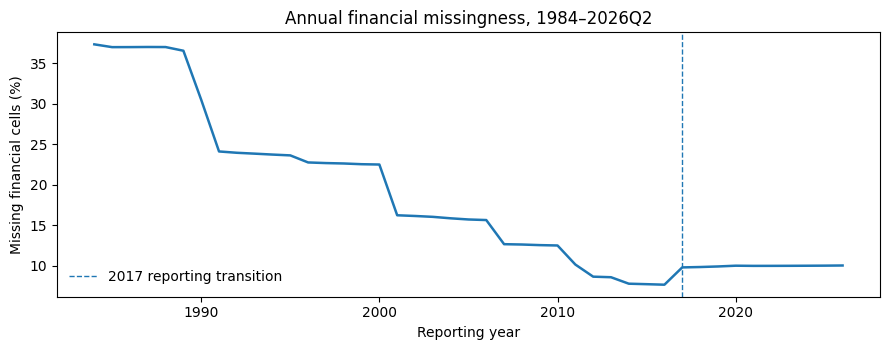

In [27]:
import matplotlib.pyplot as plt
# One lazy group_by over the existing Bronze scan, no pandas materialization.
annual_miss_chart = (financial_lf
  .with_columns(pl.col("REPDTE").dt.year().alias("year"))
  .group_by("year")
  .agg([pl.len().alias("n"),
        *[pl.col(c).is_null().sum().alias(c) for c in financial_cols]])
  .sort("year").collect().to_pandas())
annual_miss_chart["missing_pct"] = (
  100*annual_miss_chart[financial_cols].sum(axis=1) /
  (annual_miss_chart["n"]*len(financial_cols)))
fig,ax=plt.subplots(figsize=(9,3.6))
ax.plot(annual_miss_chart["year"],annual_miss_chart["missing_pct"],lw=1.8)
ax.axvline(2017,ls="--",lw=1,label="2017 reporting transition")
ax.set(xlabel="Reporting year",ylabel="Missing financial cells (%)",title="Annual financial missingness, 1984–2026Q2")
ax.legend(frameon=False);plt.tight_layout();plt.show()

**Chart reading:** Any structural break should be checked against reporting-form changes; do not interpret lower missingness as automatic improvement in model validity.

<a id="p2-s23"></a>
### 2.2.3 — Structural Coverage Breaks and Field Availability

**Purpose:** Identify variable-level coverage changes, especially the increase in missingness between 2016 and 2017.
**Check:** Compare annual coverage rates, detect fields with persistent reporting discontinuities, and identify historically sparse variables with high recent coverage.
**Readout:** Variables contributing to the 2017 coverage decline, potential reporting discontinuations, and recently available candidate features.

**Decision Rule:** Coverage transitions are diagnostic evidence, not proof of changes in FDIC reporting requirements. No variables will be removed or imputed.

In [28]:
# 2.2.3 — Structural Coverage Breaks and Field Availability

# 1. Construct exact annual coverage percentages
annual_counts = yearly_coverage_wide.set_index("year")

annual_coverage_pct = (
    annual_counts[financial_cols]
    .div(annual_counts["n_rows"], axis=0)
    * 100
)

# 2. Compare 2016 versus 2017
coverage_breaks = pd.DataFrame({
    "variable": financial_cols,
    "coverage_2016_pct": annual_coverage_pct.loc[2016].values,
    "coverage_2017_pct": annual_coverage_pct.loc[2017].values,
    "coverage_2024_pct": annual_coverage_pct.loc[2024].values,
})

coverage_breaks["change_2017_pp"] = (
    coverage_breaks["coverage_2017_pct"]
    - coverage_breaks["coverage_2016_pct"]
)

print("2016–2017 MISSINGNESS BREAK")

missing_2016 = 100 - annual_coverage_pct.loc[2016].mean()
missing_2017 = 100 - annual_coverage_pct.loc[2017].mean()

print(f"Missingness 2016: {missing_2016:.2f}%")
print(f"Missingness 2017: {missing_2017:.2f}%")
print(f"Change: {missing_2017 - missing_2016:+.2f} percentage points")

print("\nTOP 15 LARGEST COVERAGE DECLINES")

display(
    coverage_breaks
    .sort_values("change_2017_pp")
    .head(15)
    .round(2)
)

# 3. Identify fields that disappear after 2016
discontinued_candidates = [
    c for c in financial_cols
    if (
        annual_counts.loc[2016, c] > 0
        and (annual_counts.loc[2017:2026, c] == 0).all()
    )
]

print("\nFIELDS WITH NO REPORTED VALUES AFTER 2016")
print("Number of candidate fields:", len(discontinued_candidates))
print(discontinued_candidates)

# 4. Identify first and last years with observed values
field_lifecycle = []

for col in financial_cols:

    observed_years = annual_counts.index[
        annual_counts[col] > 0
    ]

    field_lifecycle.append({
        "variable": col,
        "first_observed_year": (
            int(observed_years.min())
            if len(observed_years) else None
        ),
        "last_observed_year": (
            int(observed_years.max())
            if len(observed_years) else None
        ),
        "coverage_2024_pct": annual_coverage_pct.loc[2024, col]
    })

field_lifecycle = pd.DataFrame(field_lifecycle)

# 5. Identify high historical missingness but high recent coverage
recent_candidates = (
    field_lifecycle
    .merge(
        missingness_df[["variable", "missing_pct"]],
        on="variable",
        how="left"
    )
)

recent_candidates = recent_candidates[
    (recent_candidates["missing_pct"] > 50)
    & (recent_candidates["coverage_2024_pct"] >= 95)
].sort_values("missing_pct", ascending=False)

print("\nHIGH HISTORICAL MISSINGNESS / HIGH RECENT COVERAGE")

display(recent_candidates.round(2))

# 6. Lifecycle summary
print("\nFIRST OBSERVED YEAR DISTRIBUTION")

display(
    field_lifecycle["first_observed_year"]
    .value_counts()
    .sort_index()
    .rename_axis("first_observed_year")
    .reset_index(name="n_variables")
)

# 7. Validation
assert len(field_lifecycle) == len(financial_cols)
assert len(coverage_breaks) == len(financial_cols)

print("\nFIELD COVERAGE BREAK ANALYSIS: PASS")

2016–2017 MISSINGNESS BREAK
Missingness 2016: 7.67%
Missingness 2017: 9.80%
Change: +2.14 percentage points

TOP 15 LARGEST COVERAGE DECLINES


,variable,coverage_2016_pct,coverage_2017_pct,coverage_2024_pct,change_2017_pp
68,DRDEPQ,99.72,0.00,0.00,-99.72
67,DRDEP,99.72,0.00,0.00,-99.72
58,DRCINUS,36.23,22.33,18.88,-13.90
59,DRCINUSQ,36.23,22.33,18.88,-13.90
83,DRRENUS,36.23,22.33,18.88,-13.90
84,DRRENUSQ,36.23,22.33,18.88,-13.90
125,NTRENUSQ,36.23,22.33,18.88,-13.90
124,NTRENUS,36.23,22.33,18.88,-13.90
130,P3RECONR,89.41,89.33,89.91,-0.07
101,NTAGQ,1.23,1.18,1.78,-0.05



FIELDS WITH NO REPORTED VALUES AFTER 2016
Number of candidate fields: 2
['DRDEP', 'DRDEPQ']

HIGH HISTORICAL MISSINGNESS / HIGH RECENT COVERAGE


,variable,first_observed_year,last_observed_year,coverage_2024_pct,missing_pct
34,RBCT1C,2014,2026,99.63,84.17
55,DRAUTO,2011,2026,99.63,78.99
56,DRAUTOQ,2011,2026,99.63,78.99
109,NTAUTO,2011,2026,99.63,78.99
132,NCRECNFM,2007,2026,99.63,72.01
76,DRRECNFM,2007,2026,99.63,71.09
131,LNRECNFM,2007,2026,99.63,71.09
77,DRRECNOT,2007,2026,99.63,71.09
91,IOTNIIQ,2001,2026,99.63,58.58
90,IOTNII,1996,2026,99.63,56.53



FIRST OBSERVED YEAR DISTRIBUTION


,first_observed_year,n_variables
0,1984,108
1,1986,1
2,1990,7
3,1991,4
4,1992,1
5,1996,2
6,2001,2
7,2007,4
8,2011,3
9,2014,1



FIELD COVERAGE BREAK ANALYSIS: PASS


##### Interpretation 2.2.3 — Structural Coverage Breaks

**Evidence:** Several financial fields show a marked reporting break near 2017.

**Decision:** Compare consecutive quarters and matched banks before attributing the break to a rule change.

**Limit:** A coverage discontinuity is not itself financial distress.

<a id="p2-s24"></a>
### 2.2.4 — Within-Bank Coverage Transition Analysis

**Purpose:** Determine whether the 2016–2017 coverage decline reflects changes in reporting availability within the same banks or changes in the reporting population.
**Check:** Compare variable availability between 2016Q4 and 2017Q1 for banks observed in both quarters. Examine quarterly coverage trends throughout 2016–2018.
**Readout:** Quarterly coverage rates, matched-bank availability transitions, and counts of newly missing or newly reported values.

**Decision Rule:** Do not classify reporting changes as regulatory discontinuations without supporting metadata.

#### 2.2.4 · Block 1/2 — Focus on the eight variables driving the 2017 break

In [29]:
# 2.2.4 — Within-Bank Coverage Transition Analysis

# 1. Focus on the eight variables driving the 2017 break
focus_fields = [
    "DRDEP", "DRDEPQ",
    "DRCINUS", "DRCINUSQ",
    "DRRENUS", "DRRENUSQ",
    "NTRENUS", "NTRENUSQ"
]

# 2. Read only the transition period (2016–2018)
transition_files = [
    p for p in BRONZE_FILES
    if int(p.parent.name.split("=")[1]) in [2016, 2017, 2018]
]

transition_lf = (
    pl.scan_parquet(
        [str(p) for p in transition_files],
        hive_partitioning=False
    )
    .select(["CERT", "REPDTE"] + focus_fields)
)

# 3. Quarterly coverage for all reporting banks
quarterly_counts = (
    transition_lf
    .with_columns(
        pl.concat_str([
            pl.col("REPDTE").dt.year().cast(pl.String),
            pl.lit("Q"),
            pl.col("REPDTE").dt.quarter().cast(pl.String)
        ]).alias("quarter")
    )
    .group_by("quarter")
    .agg(
        [pl.len().alias("n_banks")]
        + [
            pl.col(c).count().alias(c)
            for c in focus_fields
        ]
    )
    .sort("quarter")
    .collect()
    .to_pandas()
)

quarterly_coverage = quarterly_counts[
    ["quarter", "n_banks"]
].copy()

for c in focus_fields:
    quarterly_coverage[c] = (
        quarterly_counts[c]
        / quarterly_counts["n_banks"] * 100
    ).round(2)

print("QUARTERLY COVERAGE: 2016–2018 (%)")
display(quarterly_coverage)

# 4. Select bank observations in 2016Q4 and 2017Q1
boundary_data = (
    transition_lf
    .filter(
        pl.col("REPDTE").is_in([
            pd.Timestamp("2016-12-31").date(),
            pd.Timestamp("2017-03-31").date()
        ])
    )
    .collect()
    .to_pandas()
)

boundary_data["REPDTE"] = pd.to_datetime(
    boundary_data["REPDTE"]
)

before = (
    boundary_data[
        boundary_data["REPDTE"] == "2016-12-31"
    ]
    .drop(columns="REPDTE")
    .set_index("CERT")
)

after = (
    boundary_data[
        boundary_data["REPDTE"] == "2017-03-31"
    ]
    .drop(columns="REPDTE")
    .set_index("CERT")
)

# 5. Match the same banks across both quarters
paired = before.join(
    after,
    how="inner",
    lsuffix="_2016Q4",
    rsuffix="_2017Q1",
    validate="one_to_one"
)

print("\nBANK POPULATION TRANSITION")
print("Banks in 2016Q4:", len(before))
print("Banks in 2017Q1:", len(after))
print("Banks in both quarters:", len(paired))
print("2016Q4-only banks:", len(before) - len(paired))
print("2017Q1-only banks:", len(after) - len(paired))

# 6. Calculate within-bank availability transitions
transition_records = []

for c in focus_fields:

    available_before = paired[f"{c}_2016Q4"].notna()
    available_after = paired[f"{c}_2017Q1"].notna()

    transition_records.append({
        "variable": c,
        "matched_banks": len(paired),
        "coverage_2016Q4_pct":
            round(available_before.mean() * 100, 2),
        "coverage_2017Q1_pct":
            round(available_after.mean() * 100, 2),
        "reported_both":
            int((available_before & available_after).sum()),
        "became_missing":
            int((available_before & ~available_after).sum()),
        "became_available":
            int((~available_before & available_after).sum()),
        "missing_both":
            int((~available_before & ~available_after).sum())
    })

transition_audit = pd.DataFrame(transition_records)

print("\nWITHIN-BANK COVERAGE TRANSITIONS")
display(transition_audit)

QUARTERLY COVERAGE: 2016–2018 (%)


,quarter,n_banks,DRDEP,DRDEPQ,DRCINUS,DRCINUSQ,DRRENUS,DRRENUSQ,NTRENUS,NTRENUSQ
0,2016Q1,6193,99.73,99.73,35.98,35.98,35.98,35.98,35.98,35.98
1,2016Q2,6129,99.72,99.72,36.12,36.12,36.12,36.12,36.12,36.12
2,2016Q3,6051,99.72,99.72,36.29,36.29,36.29,36.29,36.29,36.29
3,2016Q4,5983,99.72,99.72,36.54,36.54,36.54,36.54,36.54,36.54
4,2017Q1,5925,0.00,0.00,23.11,23.11,23.11,23.11,23.11,23.11
5,2017Q2,5856,0.00,0.00,22.42,22.42,22.42,22.42,22.42,22.42
6,2017Q3,5806,0.00,0.00,22.03,22.03,22.03,22.03,22.03,22.03
7,2017Q4,5738,0.00,0.00,21.75,21.75,21.75,21.75,21.75,21.75
8,2018Q1,5674,0.00,0.00,21.40,21.40,21.40,21.40,21.40,21.40
9,2018Q2,5610,0.00,0.00,21.35,21.35,21.35,21.35,21.35,21.35



BANK POPULATION TRANSITION
Banks in 2016Q4: 5983
Banks in 2017Q1: 5925
Banks in both quarters: 5923
2016Q4-only banks: 60
2017Q1-only banks: 2

WITHIN-BANK COVERAGE TRANSITIONS


,variable,matched_banks,coverage_2016Q4_pct,coverage_2017Q1_pct,reported_both,became_missing,became_available,missing_both
0,DRDEP,5923,99.71,0.0,0,5906,0,17
1,DRDEPQ,5923,99.71,0.0,0,5906,0,17
2,DRCINUS,5923,36.54,23.1,1342,822,26,3733
3,DRCINUSQ,5923,36.54,23.1,1342,822,26,3733
4,DRRENUS,5923,36.54,23.1,1342,822,26,3733
5,DRRENUSQ,5923,36.54,23.1,1342,822,26,3733
6,NTRENUS,5923,36.54,23.1,1342,822,26,3733
7,NTRENUSQ,5923,36.54,23.1,1342,822,26,3733


#### 2.2.4 · Block 2/2 — Reconciliation

In [30]:
# 7. Reconciliation
assert len(quarterly_coverage) == 12
assert len(paired) <= min(len(before), len(after))

for row in transition_records:
    assert (
        row["reported_both"]
        + row["became_missing"]
        + row["became_available"]
        + row["missing_both"]
        == row["matched_banks"]
    )

print("\nWITHIN-BANK TRANSITION RECONCILIATION: PASS")


WITHIN-BANK TRANSITION RECONCILIATION: PASS


##### Interpretation 2.2.4 — Within-Bank Coverage Transitions

**Evidence:** The within-bank comparison confirms a pronounced transition for some reporting fields between 2016Q4 and 2017Q1.

**Decision:** Keep pre/post reporting-regime indicators for audit and candidate feature screening.

**Limit:** The evidence establishes timing, not a fully verified causal explanation.

### 2.2.5 — Missingness Transitions and Bank Size

**Purpose:** Determine whether the 2017 reporting transition is associated with bank size.
**Check:** Verify whether six financial variables share identical missingness masks, classify matched banks by availability transition, and compare their 2016Q4 asset distributions.
**Readout:** Missingness-mask consistency, bank-size distributions, and transition rates across asset quintiles.

**Decision Rule:** Bank-size associations are exploratory and do not establish regulatory reporting thresholds.

In [31]:
# 2.2.5 — Missingness Transitions and Bank Size

# 1. Verify whether all six fields have identical missingness masks
six_fields = [
    "DRCINUS", "DRCINUSQ",
    "DRRENUS", "DRRENUSQ",
    "NTRENUS", "NTRENUSQ"
]

print("MISSINGNESS MASK CONSISTENCY")

for quarter in ["2016Q4", "2017Q1"]:

    reference_mask = paired[
        f"DRCINUS_{quarter}"
    ].notna()

    comparison = {
        field: paired[f"{field}_{quarter}"]
        .notna()
        .equals(reference_mask)
        for field in six_fields
    }

    print(f"\n{quarter}")
    print(comparison)
    print("All six identical:", all(comparison.values()))

# 2. Classify bank-level transitions using DRCINUS
available_before = paired["DRCINUS_2016Q4"].notna()
available_after = paired["DRCINUS_2017Q1"].notna()

transition_status = pd.Series(
    "Missing both",
    index=paired.index
)

transition_status.loc[
    available_before & available_after
] = "Reported both"

transition_status.loc[
    available_before & ~available_after
] = "Became missing"

transition_status.loc[
    ~available_before & available_after
] = "Became available"

# 3. Retrieve 2016Q4 total assets for matched banks
asset_files = [
    p for p in BRONZE_FILES
    if int(p.parent.name.split("=")[1]) == 2016
]

asset_data = (
    pl.scan_parquet(
        [str(p) for p in asset_files],
        hive_partitioning=False
    )
    .filter(
        pl.col("REPDTE")
        == pd.Timestamp("2016-12-31").date()
    )
    .select(["CERT", "ASSET"])
    .collect()
    .to_pandas()
)

asset_data["CERT"] = asset_data["CERT"].astype("int64")

# 4. Create bank-level diagnostic table
bank_transition_profile = pd.DataFrame({
    "CERT": paired.index.astype("int64"),
    "transition": transition_status.values
})

bank_transition_profile = bank_transition_profile.merge(
    asset_data,
    on="CERT",
    how="left",
    validate="one_to_one"
)

print("\nTRANSITION GROUP DISTRIBUTION")

display(
    bank_transition_profile["transition"]
    .value_counts()
    .rename_axis("transition")
    .reset_index(name="n_banks")
)

# 5. Compare asset distributions across groups
asset_summary = (
    bank_transition_profile
    .groupby("transition")
    .agg(
        n_banks=("CERT", "size"),
        median_asset=("ASSET", "median"),
        mean_asset=("ASSET", "mean"),
        p25_asset=("ASSET", lambda x: x.quantile(0.25)),
        p75_asset=("ASSET", lambda x: x.quantile(0.75))
    )
    .reset_index()
)

print("\nASSET DISTRIBUTION BY TRANSITION GROUP")

display(asset_summary.round(2))

# 6. Divide banks into asset-size quintiles
bank_transition_profile["asset_quintile"] = (
    pd.qcut(
        bank_transition_profile["ASSET"],
        q=5,
        labels=False,
        duplicates="drop"
    ) + 1
)

quintile_distribution = pd.crosstab(
    bank_transition_profile["asset_quintile"],
    bank_transition_profile["transition"],
    normalize="index"
).mul(100).round(2)

print("\nTRANSITION DISTRIBUTION BY ASSET QUINTILE (%)")
print("Quintile 1 = smallest banks; Quintile 5 = largest banks")

display(quintile_distribution)

# 7. Validation
assert len(bank_transition_profile) == len(paired)
assert bank_transition_profile["ASSET"].notna().all()
assert bank_transition_profile["CERT"].is_unique

print("\nBANK-SIZE TRANSITION ANALYSIS: PASS")

MISSINGNESS MASK CONSISTENCY

2016Q4
{'DRCINUS': True, 'DRCINUSQ': True, 'DRRENUS': True, 'DRRENUSQ': True, 'NTRENUS': True, 'NTRENUSQ': True}
All six identical: True

2017Q1
{'DRCINUS': True, 'DRCINUSQ': True, 'DRRENUS': True, 'DRRENUSQ': True, 'NTRENUS': True, 'NTRENUSQ': True}
All six identical: True

TRANSITION GROUP DISTRIBUTION


,transition,n_banks
0,Missing both,3733
1,Reported both,1342
2,Became missing,822
3,Became available,26



ASSET DISTRIBUTION BY TRANSITION GROUP


,transition,n_banks,median_asset,mean_asset,p25_asset,p75_asset
0,Became available,26,326941.5,328381.62,310495.75,349597.75
1,Became missing,822,452622.5,494575.73,356937.00,608611.50
2,Missing both,3733,116592.0,173568.52,66897.00,188605.00
3,Reported both,1342,1091532.0,11817213.59,560688.50,2607745.00



TRANSITION DISTRIBUTION BY ASSET QUINTILE (%)
Quintile 1 = smallest banks; Quintile 5 = largest banks


transition,Became available,Became missing,Missing both,Reported both
asset_quintile,,,,
1,0.00,0.42,99.49,0.08
2,0.00,0.25,99.41,0.34
3,0.25,3.29,96.03,0.42
4,1.94,48.23,19.00,30.83
5,0.00,17.22,1.18,81.60



BANK-SIZE TRANSITION ANALYSIS: PASS


##### Interpretation 2.2.5 — Missingness Transitions and Bank Size

**Evidence:** Changes in field availability are heterogeneous across institutions and bank sizes.

**Decision:** Interpret missingness in the context of reporting eligibility rather than imputing systematically absent fields.

**Limit:** Size-group patterns do not by themselves confirm which reporting form each bank filed.

**Reporting context (2017):** Changes to Call Report forms may affect field availability. The observed within-bank discontinuity is a descriptive finding; source reporting-form eligibility and accounting definitions still require independent verification. No imputation is applied to structurally absent fields.

<a id="p2-s26"></a>
### 2.2.6 — Reporting Transition Around the 2017 Asset Threshold

**Purpose:** Examine whether changes in financial variable availability around 2017Q1 are associated with the $1 billion asset threshold relevant to FFIEC 051 eligibility.
**Check:** Classify banks using total assets reported in 2016Q2 and compare matched-bank reporting transitions across asset-size groups.
**Readout:** Transition frequencies and conditional missingness rates by pre-reform bank size.

**Decision Rule:** Associations with asset size do not establish the applicable Call Report form or prove the cause of missingness.

In [32]:
# 2.2.6 — Reporting Transition Around the 2017 Asset Threshold

# 1. Retrieve bank assets as of June 30, 2016

assets_2016q2 = (
    pl.scan_parquet(
        [str(p) for p in transition_files],
        hive_partitioning=False
    )
    .filter(
        pl.col("REPDTE")
        == pd.Timestamp("2016-06-30").date()
    )
    .select(["CERT", "ASSET"])
    .collect()
    .to_pandas()
)

assets_2016q2["CERT"] = (
    assets_2016q2["CERT"].astype("int64")
)

print("2016Q2 ASSET DATA CHECK")

# 2. Link with existing transition classifications
threshold_audit = (
    bank_transition_profile[["CERT", "transition"]]
    .merge(
        assets_2016q2,
        on="CERT",
        how="left",
        validate="one_to_one"
    )
)

print("BASELINE ASSET AVAILABILITY")
print("Matched banks:", len(threshold_audit))
print(
    "Missing 2016Q2 assets:",
    threshold_audit["ASSET"].isna().sum()
)

# 3. Create descriptive asset-size groups
# ASSET is reported in thousands of USD
# $1 billion = 1,000,000 in source units

asset_value = pd.to_numeric(threshold_audit["ASSET"], errors="coerce")
finite_assets = np.isfinite(asset_value)
valid_assets = finite_assets & asset_value.ge(0)
negative_assets = finite_assets & asset_value.lt(0)
threshold_audit["asset_group"] = pd.Series(
    "Missing/nonfinite ASSET", index=threshold_audit.index, dtype="string"
)
threshold_audit.loc[negative_assets, "asset_group"] = "Negative ASSET (review)"
threshold_audit.loc[valid_assets, "asset_group"] = pd.cut(
    asset_value.loc[valid_assets],
    bins=[0, 300_000, 500_000, 1_000_000, float("inf")],
    labels=["<$300m", "$300m–<$500m", "$500m–<$1bn", ">=$1bn"],
    right=False
).astype("string")
print("Missing/nonfinite assets:", int((~finite_assets).sum()))
print("Negative assets (review only):", int(negative_assets.sum()))

# 4. Reporting transitions by asset size
transition_counts = pd.crosstab(
    threshold_audit["asset_group"],
    threshold_audit["transition"]
)

transition_rates = pd.crosstab(
    threshold_audit["asset_group"],
    threshold_audit["transition"],
    normalize="index"
).mul(100).round(2)

print("\nTRANSITION COUNTS BY 2016Q2 ASSET SIZE")
display(transition_counts)

print("\nTRANSITION RATES BY 2016Q2 ASSET SIZE (%)")
display(transition_rates)

# 5. Focus on banks that reported in 2016Q4
# This isolates the probability of losing availability

previous_reporters = threshold_audit[
    threshold_audit["transition"].isin([
        "Reported both",
        "Became missing"
    ])
].copy()

loss_by_size = (
    previous_reporters
    .groupby("asset_group", observed=True)
    .agg(
        previously_reporting=("CERT", "size"),
        became_missing=(
            "transition",
            lambda x: (x == "Became missing").sum()
        )
    )
    .reset_index()
)

loss_by_size["loss_rate_pct"] = (
    100
    * loss_by_size["became_missing"]
    / loss_by_size["previously_reporting"]
).round(2)

print("\nREPORTING LOSS AMONG PREVIOUSLY REPORTING BANKS")
display(loss_by_size)

# 6. Validation
assert threshold_audit["CERT"].is_unique
assert len(threshold_audit) == len(paired)

assert threshold_audit["asset_group"].notna().all()
assert transition_counts.to_numpy().sum() == len(threshold_audit)

print("\nASSET THRESHOLD DIAGNOSTIC: PASS")

2016Q2 ASSET DATA CHECK
BASELINE ASSET AVAILABILITY
Matched banks: 5923
Missing 2016Q2 assets: 0
Missing/nonfinite assets: 0
Negative assets (review only): 0

TRANSITION COUNTS BY 2016Q2 ASSET SIZE


transition,Became available,Became missing,Missing both,Reported both
asset_group,,,,
$300m–<$500m,25,446,39,276
$500m–<$1bn,0,304,2,341
<$300m,1,72,3681,14
>=$1bn,0,0,11,711



TRANSITION RATES BY 2016Q2 ASSET SIZE (%)


transition,Became available,Became missing,Missing both,Reported both
asset_group,,,,
$300m–<$500m,3.18,56.74,4.96,35.11
$500m–<$1bn,0.00,46.99,0.31,52.70
<$300m,0.03,1.91,97.69,0.37
>=$1bn,0.00,0.00,1.52,98.48



REPORTING LOSS AMONG PREVIOUSLY REPORTING BANKS


,asset_group,previously_reporting,became_missing,loss_rate_pct
0,$300m–<$500m,722,446,61.77
1,$500m–<$1bn,645,304,47.13
2,<$300m,86,72,83.72
3,>=$1bn,711,0,0.00



ASSET THRESHOLD DIAGNOSTIC: PASS


##### Interpretation 2.2.6 — Asset Threshold and Reporting Discontinuity

**Evidence:** Asset-size stratification helps explain part of the 2017 reporting discontinuity.

**Decision:** Preserve source missingness and check field-level applicability for each period.

**Limit:** The observed threshold association must not be treated as proof of reporting-form eligibility.

### 2.2.7 — Missingness Across Candidate Modelling Windows

**Purpose:** Evaluate row-level missingness and feature availability across alternative modelling periods.
**Check:** Compare reporting windows beginning in 1984, 2007, 2014, 2017, and 2020, using the common observation cutoff of 2025Q2. Examine both overall and core-financial-variable missingness.
**Readout:** Window-level missingness distributions, recent feature coverage, and the highest-missingness variables in the recent sample.

**Decision Rule:** The analysis supports sample-period and feature selection but does not determine them automatically. No imputation or variable exclusion will be performed.

#### 2.2.7 · Block 1/2 — Define exploratory modelling windows

In [33]:
# 2.2.7 — Missingness Across Candidate Modelling Windows

# 1. Define exploratory modelling windows
windows = {
    "1984Q1–2025Q2": "1984-03-31",
    "2007Q1–2025Q2": "2007-03-31",
    "2014Q1–2025Q2": "2014-03-31",
    "2017Q1–2025Q2": "2017-03-31",
    "2020Q1–2025Q2": "2020-03-31"
}

cutoff = pd.Timestamp("2025-06-30")

core_fields = [
    "ASSET", "DEP", "EQ",
    "ROA", "ROE", "RBC1AAJ"
]

# 2. Calculate row-level missingness
row_missing_lf = (
    financial_lf
    .filter(
        pl.col("REPDTE").is_between(
            min(pd.Timestamp(d).date() for d in windows.values()),
            cutoff.date()
        )
    )
    .select([
        "CERT",
        "REPDTE",
        pl.sum_horizontal([
            pl.col(c).is_null().cast(pl.UInt8)
            for c in financial_cols
        ]).alias("n_missing"),
        pl.sum_horizontal([
            pl.col(c).is_null().cast(pl.UInt8)
            for c in core_fields
        ]).alias("n_core_missing")
    ])
)

row_missing_df = row_missing_lf.collect().to_pandas()

row_missing_df["REPDTE"] = pd.to_datetime(
    row_missing_df["REPDTE"]
)

row_missing_df["missing_pct"] = (
    row_missing_df["n_missing"]
    / len(financial_cols) * 100
)

# 3. Compare modelling windows
window_results = []

for name, start_date in windows.items():

    sample = row_missing_df[
        row_missing_df["REPDTE"]
        >= pd.Timestamp(start_date)
    ]

    window_results.append({
        "window": name,
        "n_rows": len(sample),
        "n_banks": sample["CERT"].nunique(),
        "mean_missing_pct": sample["missing_pct"].mean(),
        "median_missing_pct": sample["missing_pct"].median(),
        "p90_missing_pct": sample["missing_pct"].quantile(0.90),
        "rows_above_20pct": (
            sample["missing_pct"] > 20
        ).mean() * 100,
        "rows_above_50pct": (
            sample["missing_pct"] > 50
        ).mean() * 100,
        "rows_with_core_missing_pct": (
            sample["n_core_missing"] > 0
        ).mean() * 100
    })

window_comparison = pd.DataFrame(window_results)

print("MISSINGNESS ACROSS MODELLING WINDOWS")
display(window_comparison.round(2))

# 4. Calculate exact feature coverage for 2017Q1–2025Q2
recent_lf = financial_lf.filter(
    pl.col("REPDTE").is_between(
        pd.Timestamp("2017-03-31").date(),
        cutoff.date()
    )
)

recent_stats = (
    recent_lf
    .select(
        [pl.len().alias("n_rows")]
        + [
            pl.col(c).null_count().alias(c)
            for c in financial_cols
        ]
    )
    .collect()
    .row(0, named=True)
)

recent_n = int(recent_stats["n_rows"])

recent_field_profile = pd.DataFrame([
    {
        "variable": c,
        "missing_count": int(recent_stats[c]),
        "missing_pct": 100 * int(recent_stats[c]) / recent_n,
        "coverage_pct": 100 * (
            1 - int(recent_stats[c]) / recent_n
        )
    }
    for c in financial_cols
])

MISSINGNESS ACROSS MODELLING WINDOWS


,window,n_rows,n_banks,mean_missing_pct,median_missing_pct,p90_missing_pct,rows_above_20pct,rows_above_50pct,rows_with_core_missing_pct
0,1984Q1–2025Q2,1665087,24055,22.34,22.56,31.58,57.86,4.80,1.12
1,2007Q1–2025Q2,470200,9141,10.19,10.53,12.03,3.56,0.27,0.31
2,2014Q1–2025Q2,249606,6901,9.27,10.53,10.53,0.31,0.31,0.37
3,2017Q1–2025Q2,172924,6011,9.95,10.53,10.53,0.33,0.33,0.41
4,2020Q1–2025Q2,105932,5241,10.00,10.53,10.53,0.35,0.35,0.48


#### 2.2.7 · Block 2/2 — Feature availability summary

In [34]:
# 5. Feature availability summary
print("\nFEATURE AVAILABILITY: 2017Q1–2025Q2")

print("Observations:", f"{recent_n:,}")
print(
    "Variables with >=95% coverage:",
    int((recent_field_profile["coverage_pct"] >= 95).sum())
)
print(
    "Variables with >=80% coverage:",
    int((recent_field_profile["coverage_pct"] >= 80).sum())
)
print(
    "Variables with <20% coverage:",
    int((recent_field_profile["coverage_pct"] < 20).sum())
)

print("\nTOP 15 HIGHEST MISSINGNESS VARIABLES")
display(
    recent_field_profile
    .sort_values("missing_pct", ascending=False)
    .head(15)
    .round(2)
)

print("\nCORE FINANCIAL VARIABLE COVERAGE")
display(
    recent_field_profile[
        recent_field_profile["variable"].isin(core_fields)
    ].round(3)
)

# 6. Validation
expected_recent_rows = int(
    (
        row_missing_df["REPDTE"]
        >= pd.Timestamp("2017-03-31")
    ).sum()
)

assert recent_n == expected_recent_rows
assert len(recent_field_profile) == 133
assert (recent_field_profile["missing_count"] <= recent_n).all()
assert (recent_field_profile["missing_count"] >= 0).all()

print("\nMODELLING WINDOW MISSINGNESS AUDIT: PASS")


FEATURE AVAILABILITY: 2017Q1–2025Q2
Observations: 172,924
Variables with >=95% coverage: 118
Variables with >=80% coverage: 119
Variables with <20% coverage: 14

TOP 15 HIGHEST MISSINGNESS VARIABLES


,variable,missing_count,missing_pct,coverage_pct
68,DRDEPQ,172924,100.00,0.00
67,DRDEP,172924,100.00,0.00
51,DRAG,170233,98.44,1.56
52,DRAGQ,170233,98.44,1.56
101,NTAGQ,170233,98.44,1.56
129,OREOTHF,170233,98.44,1.56
102,NTAGQA,170233,98.44,1.56
100,NTAG,170233,98.44,1.56
59,DRCINUSQ,138746,80.24,19.76
125,NTRENUSQ,138746,80.24,19.76



CORE FINANCIAL VARIABLE COVERAGE


,variable,missing_count,missing_pct,coverage_pct
0,EQ,578,0.334,99.666
1,DEP,0,0.000,100.000
2,ASSET,0,0.000,100.000
3,ROA,0,0.000,100.000
4,ROE,717,0.415,99.585
6,RBC1AAJ,0,0.000,100.000



MODELLING WINDOW MISSINGNESS AUDIT: PASS


##### Interpretation 2.2.7 — Missingness Across Modelling Windows

**Evidence:** The modern window has lower overall missingness than the full 1984–2026 panel, but coverage differs by variable.

**Decision:** Use window-specific field audits to guide feature screening.

**Limit:** Higher completeness does not justify trimming the study period without assessing failure coverage.

### 2.2.8 — Severe Row-Level Missingness and Final Diagnostics

**Purpose:** Investigate the small subset of severely incomplete bank-quarter observations in the 2017Q1–2025Q2 sample.
**Check:** Examine missingness severity, temporal concentration, affected banks, and overlap with missing core financial indicators.
**Readout:** A validated summary of severe missingness patterns to support the final Section 2.2 assessment.

**Decision Rule:** Do not exclude observations or apply imputation before establishing whether severe missingness reflects source-data limitations or institutional reporting characteristics.

In [35]:
# 2.2.8 — Severe Row-Level Missingness and Final Diagnostics

# 1. Select the recent modelling window
recent_rows = row_missing_df.loc[
    row_missing_df["REPDTE"].between(
        "2017-03-31", "2025-06-30"
    )
].copy()

recent_rows["year"] = recent_rows["REPDTE"].dt.year
recent_rows["severe"] = recent_rows["missing_pct"] > 50
recent_rows["above_20pct"] = recent_rows["missing_pct"] > 20
recent_rows["core_missing"] = recent_rows["n_core_missing"] > 0

# 2. Quantify exceptional missingness
print("ROW-LEVEL MISSINGNESS SUMMARY")
print("Observations:", f"{len(recent_rows):,}")
print("Banks:", f"{recent_rows['CERT'].nunique():,}")
print("Rows >20% missing:", int(recent_rows["above_20pct"].sum()))
print("Rows >50% missing:", int(recent_rows["severe"].sum()))
print("Rows with core missing:", int(recent_rows["core_missing"].sum()))

print("\nMOST COMMON NUMBERS OF MISSING FIELDS")

display(
    recent_rows["n_missing"]
    .value_counts()
    .head(12)
    .rename_axis("n_missing_fields")
    .reset_index(name="n_rows")
)

# 3. Check overlap with missing core indicators
print("\nSEVERE MISSINGNESS VS CORE MISSINGNESS")

display(
    pd.crosstab(
        recent_rows["severe"],
        recent_rows["core_missing"],
        rownames=["Missing >50%"],
        colnames=["At least one core field missing"],
        margins=True
    )
)

# 4. Examine temporal concentration
annual_severity = (
    recent_rows
    .groupby("year")
    .agg(
        n_rows=("CERT", "size"),
        severe_rows=("severe", "sum"),
        core_missing_rows=("core_missing", "sum")
    )
    .reset_index()
)

annual_severity["severe_pct"] = (
    annual_severity["severe_rows"]
    / annual_severity["n_rows"] * 100
).round(2)

print("\nSEVERE MISSINGNESS BY YEAR")
display(annual_severity)

# 5. Identify banks with repeated severe missingness
severe_rows = recent_rows.loc[
    recent_rows["severe"]
].copy()

severe_bank_summary = (
    severe_rows
    .groupby("CERT")
    .agg(
        n_severe_quarters=("REPDTE", "size"),
        first_severe=("REPDTE", "min"),
        last_severe=("REPDTE", "max"),
        median_missing_fields=("n_missing", "median"),
        n_core_missing_quarters=("core_missing", "sum")
    )
    .reset_index()
    .sort_values("n_severe_quarters", ascending=False)
)

print("\nBANKS WITH SEVERE MISSINGNESS")
print("Unique affected banks:", len(severe_bank_summary))

display(severe_bank_summary.head(15))

# 6. Show representative observations
print("\nSAMPLE OF SEVERELY INCOMPLETE OBSERVATIONS")

display(
    severe_rows[
        ["CERT", "REPDTE", "n_missing",
         "missing_pct", "n_core_missing"]
    ]
    .sort_values("n_missing", ascending=False)
    .head(15)
    .round(2)
)

# 7. Validation
checks = {
    "Recent sample rows reconcile":
        len(recent_rows) == recent_n,

    "Missing counts within field range":
        recent_rows["n_missing"].between(
            0, len(financial_cols)
        ).all(),

    "Core missing counts within field range":
        recent_rows["n_core_missing"].between(
            0, len(core_fields)
        ).all(),

    "Severe counts reconcile by year":
        annual_severity["severe_rows"].sum()
        == len(severe_rows),

    "Severe counts reconcile by bank":
        severe_bank_summary["n_severe_quarters"].sum()
        == len(severe_rows)
}

print("\nFINAL MISSINGNESS VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nSECTION 2.2 DIAGNOSTIC VALIDATION: PASS")

ROW-LEVEL MISSINGNESS SUMMARY
Observations: 172,924
Banks: 6,011
Rows >20% missing: 578
Rows >50% missing: 578
Rows with core missing: 717

MOST COMMON NUMBERS OF MISSING FIELDS


,n_missing_fields,n_rows
0,14,122570
1,8,30443
2,15,12663
3,17,2505
4,7,1991
5,9,972
6,100,578
7,10,528
8,16,429
9,11,244



SEVERE MISSINGNESS VS CORE MISSINGNESS


At least one core field missing,False,True,All
Missing >50%,,,
False,172207,139,172346
True,0,578,578
All,172207,717,172924



SEVERE MISSINGNESS BY YEAR


,year,n_rows,severe_rows,core_missing_rows,severe_pct
0,2017,23325,68,69,0.29
1,2018,22301,68,68,0.30
2,2019,21366,68,68,0.32
3,2020,20478,68,68,0.33
4,2021,19942,68,68,0.34
5,2022,19285,68,68,0.35
6,2023,18798,68,137,0.36
7,2024,18399,68,117,0.37
8,2025,9030,34,54,0.38



BANKS WITH SEVERE MISSINGNESS
Unique affected banks: 17


,CERT,n_severe_quarters,first_severe,last_severe,median_missing_fields,n_core_missing_quarters
0,25927,34,2017-03-31,2025-06-30,100.0,34
1,26028,34,2017-03-31,2025-06-30,100.0,34
2,33646,34,2017-03-31,2025-06-30,100.0,34
3,33648,34,2017-03-31,2025-06-30,100.0,34
4,33649,34,2017-03-31,2025-06-30,100.0,34
5,33653,34,2017-03-31,2025-06-30,100.0,34
6,33656,34,2017-03-31,2025-06-30,100.0,34
7,33661,34,2017-03-31,2025-06-30,100.0,34
8,33664,34,2017-03-31,2025-06-30,100.0,34
9,33681,34,2017-03-31,2025-06-30,100.0,34



SAMPLE OF SEVERELY INCOMPLETE OBSERVATIONS


,CERT,REPDTE,n_missing,missing_pct,n_core_missing
1494723,25927,2017-03-31,100,75.19,2
1626503,33664,2023-06-30,100,75.19,2
1612237,33661,2022-09-30,100,75.19,2
1612238,33664,2022-09-30,100,75.19,2
1612240,33681,2022-09-30,100,75.19,2
1612241,33682,2022-09-30,100,75.19,2
1612242,33684,2022-09-30,100,75.19,2
1612243,33686,2022-09-30,100,75.19,2
1612244,33690,2022-09-30,100,75.19,2
1612245,33692,2022-09-30,100,75.19,2



FINAL MISSINGNESS VALIDATION
Recent sample rows reconcile: PASS
Missing counts within field range: PASS
Core missing counts within field range: PASS
Severe counts reconcile by year: PASS
Severe counts reconcile by bank: PASS

SECTION 2.2 DIAGNOSTIC VALIDATION: PASS


##### Interpretation 2.2.8 — Severe Row-Level Missingness

**Evidence:** 578 modern rows from 17 banks are exceptionally sparse, with repeated missing equity/ROE patterns.

**Decision:** Retain and flag these rows for financial-validity and eligibility review.

**Limit:** Some zero capital-ratio values may be placeholders, but this is not proven.

## 2.3 — Financial anomalies and economic validity

Negative equity, profitability tails and structural asset jumps are diagnostic evidence—not automatic deletion rules.

### 2.3.1 — Persistent Reporting Exceptions and Core Financial Missingness

**Purpose:** Investigate persistently incomplete institutions and identify which core financial fields are missing outside the severely incomplete group.
**Check:** Examine institutional classifications, shared missingness patterns, and core financial availability.
**Readout:** Institutional characteristics of 17 severely incomplete banks, shared missing-field patterns, and a breakdown of the additional 139 core-missing observations.

**Decision Rule:** Do not infer institutional status or exclude records solely from missingness. Preserve all observations pending further validation.

#### 2.3.1 · Block 1/2 — Identify the 17 persistently sparse banks

In [36]:
# 2.3.1 — Persistent Reporting Exceptions and Core Financial Missingness

# 1. Identify the 17 persistently sparse banks
severe_certs = (
    severe_bank_summary["CERT"]
    .astype("int64")
    .tolist()
)

# 2. Retrieve their financial observations
severe_financial = (
    recent_lf
    .filter(pl.col("CERT").is_in(severe_certs))
    .select(["CERT", "REPDTE"] + financial_cols)
    .collect()
    .to_pandas()
)

print("PERSISTENTLY SPARSE BANKS")
print("Banks:", len(severe_certs))
print("Observations:", len(severe_financial))

# 3. Examine shared missingness patterns
field_null_counts = (
    severe_financial[financial_cols]
    .isna()
    .sum()
)

always_missing = field_null_counts[
    field_null_counts == len(severe_financial)
].index.tolist()

always_present = field_null_counts[
    field_null_counts == 0
].index.tolist()

partially_missing = field_null_counts[
    (field_null_counts > 0)
    & (field_null_counts < len(severe_financial))
].index.tolist()

print("\nFIELD AVAILABILITY AMONG 17 BANKS")
print("Always missing fields:", len(always_missing))
print("Always available fields:", len(always_present))
print("Partially missing fields:", len(partially_missing))

print("\nCORE FIELD MISSINGNESS AMONG 17 BANKS")

display(
    severe_financial[core_fields]
    .isna()
    .sum()
    .rename("missing_rows")
    .to_frame()
)

print("\nPARTIALLY MISSING FIELDS")
print(partially_missing)

# 4. Retrieve institutional classifications
institution_detail = pq.read_table(
    reference_files["institutions"],
    columns=["CERT", "NAME", "BKCLASS", "ACTIVE"]
).to_pandas()

institution_detail["CERT"] = pd.to_numeric(
    institution_detail["CERT"],
    errors="coerce"
).astype("Int64")

institution_detail = institution_detail[
    institution_detail["CERT"].isin(severe_certs)
]

sparse_bank_audit = (
    severe_bank_summary
    .merge(
        institution_detail,
        on="CERT",
        how="left",
        validate="one_to_one"
    )
)

print("\nINSTITUTIONAL PROFILE OF SPARSE BANKS")

display(
    sparse_bank_audit[
        [
            "CERT", "NAME", "BKCLASS", "ACTIVE",
            "n_severe_quarters",
            "median_missing_fields"
        ]
    ]
)

print("\nBANK CLASS DISTRIBUTION")

display(
    sparse_bank_audit["BKCLASS"]
    .fillna("UNMATCHED")
    .value_counts()
    .rename_axis("BKCLASS")
    .reset_index(name="n_banks")
)

# 5. Investigate core-field missingness across all recent rows
recent_core = (
    recent_lf
    .select(["CERT", "REPDTE"] + core_fields)
    .collect()
    .to_pandas()
)

recent_core["REPDTE"] = pd.to_datetime(
    recent_core["REPDTE"]
)

recent_core = recent_core.merge(
    recent_rows[["CERT", "REPDTE", "severe"]],
    on=["CERT", "REPDTE"],
    how="inner",
    validate="one_to_one"
)

PERSISTENTLY SPARSE BANKS
Banks: 17
Observations: 578

FIELD AVAILABILITY AMONG 17 BANKS
Always missing fields: 100
Always available fields: 33
Partially missing fields: 0

CORE FIELD MISSINGNESS AMONG 17 BANKS


,missing_rows
ASSET,0
DEP,0
EQ,578
ROA,0
ROE,578
RBC1AAJ,0



PARTIALLY MISSING FIELDS
[]

INSTITUTIONAL PROFILE OF SPARSE BANKS


,CERT,NAME,BKCLASS,ACTIVE,n_severe_quarters,median_missing_fields
0,25927,NaN,NaN,NaN,34,100.0
1,26028,The Bank of East Asia Ltd.,NC,1,34,100.0
2,33646,The Bank of East Asia Ltd.,OI,1,34,100.0
3,33648,Bank of India,OI,1,34,100.0
4,33649,Industrial Bank of Korea,NC,0,34,100.0
5,33653,Bank of China,OI,1,34,100.0
6,33656,Metropolitan Bank and Trust Company,OI,1,34,100.0
7,33661,"Mizrahi Tefahot Bank, Ltd.",OI,1,34,100.0
8,33664,State Bank of India,OI,1,34,100.0
9,33681,Bank of Baroda,OI,1,34,100.0



BANK CLASS DISTRIBUTION


,BKCLASS,n_banks
0,OI,9
1,NC,6
2,UNMATCHED,2


#### 2.3.1 · Block 2/2 — Separate severe and non-severe observations

In [37]:
# 6. Separate severe and non-severe observations
core_missing_details = []

for group in [True, False]:

    subset = recent_core[
        recent_core["severe"] == group
    ]

    for field in core_fields:
        core_missing_details.append({
            "group": "Severe" if group else "Non-severe",
            "variable": field,
            "missing_rows": int(subset[field].isna().sum())
        })

print("\nCORE MISSINGNESS BY SEVERITY GROUP")

display(pd.DataFrame(core_missing_details))

# 7. Investigate the 139 additional observations
additional_core_missing = recent_core[
    (~recent_core["severe"])
    & recent_core[core_fields].isna().any(axis=1)
].copy()

print("\nADDITIONAL CORE-MISSING OBSERVATIONS")
print("Rows:", len(additional_core_missing))
print("Banks:", additional_core_missing["CERT"].nunique())

display(
    additional_core_missing[
        ["CERT", "REPDTE"] + core_fields
    ].head(20)
)

# 8. Validation
assert len(severe_financial) == 578
assert len(severe_certs) == 17
assert len(recent_core) == recent_n
assert len(additional_core_missing) == 139

print("\nCORE FINANCIAL EXCEPTION AUDIT: PASS")


CORE MISSINGNESS BY SEVERITY GROUP


,group,variable,missing_rows
0,Severe,ASSET,0
1,Severe,DEP,0
2,Severe,EQ,578
3,Severe,ROA,0
4,Severe,ROE,578
5,Severe,RBC1AAJ,0
6,Non-severe,ASSET,0
7,Non-severe,DEP,0
8,Non-severe,EQ,0
9,Non-severe,ROA,0



ADDITIONAL CORE-MISSING OBSERVATIONS
Rows: 139
Banks: 22


,CERT,REPDTE,ASSET,DEP,EQ,ROA,ROE,RBC1AAJ
4951,58302,2017-03-31,3325870.0,3032208.0,-112623.0,3.149621,NaN,-1.985354
127070,12013,2023-03-31,1517081.0,1533528.0,-25057.0,-0.872452,NaN,11.168331
127157,12501,2023-03-31,1247737.0,1182507.0,-24437.0,0.912023,NaN,11.628960
127158,12506,2023-03-31,923604.0,876937.0,-9293.0,1.242582,NaN,11.593255
127621,15460,2023-03-31,68313.0,69156.0,-1046.0,0.367891,NaN,8.326205
127980,17280,2023-03-31,328674.0,326872.0,-7850.0,-1.874601,NaN,8.252977
128468,2157,2023-03-31,88514.0,89402.0,-1016.0,0.645125,NaN,8.907769
128591,22867,2023-03-31,363207.0,364122.0,-3016.0,1.817466,NaN,7.517276
128660,2359,2023-03-31,617136.0,530905.0,-5021.0,0.749527,NaN,6.669531
129406,3099,2023-03-31,791438.0,760749.0,1362.0,0.661681,NaN,11.088932



CORE FINANCIAL EXCEPTION AUDIT: PASS


##### Interpretation 2.3.1 — Persistent Reporting Exceptions and Core Financial Missingness

**Evidence:** Persistent sparse reporting is concentrated in a small bank group; additional missing ROE cases have different financial characteristics.

**Decision:** Keep sparse-row and missing-core flags distinct.

**Limit:** Do not equate every missing ROE with the same reporting mechanism.

### 2.3.2 — Core Financial Distribution and ROE Missingness

**Purpose:** Examine financial value distributions and investigate whether missing ROE is associated with negative or low bank equity.
**Check:** Calculate descriptive statistics, zero and negative value frequencies, and equity-to-asset ratios for core financial variables. Compare ROE availability across equity conditions.
**Readout:** Core financial distribution diagnostics, ROE missingness by equity sign, and capital-ratio profiles.

**Decision Rule:** Negative equity, unusual profitability, and extreme financial ratios are not automatically errors. Preserve potentially meaningful distress signals until their validity has been investigated.

In [38]:
# 2.3.2 — Core Financial Distribution & ROE Missingness
import numpy as np
# 1. Descriptive statistics for six core financial variables
distribution_records = []

for c in core_fields:

    x = pd.to_numeric(recent_core[c], errors="coerce")
    valid = x.replace([np.inf, -np.inf], np.nan).dropna()

    distribution_records.append({
        "variable": c,
        "n_valid": len(valid),
        "n_missing": int(x.isna().sum()),
        "n_negative": int((valid < 0).sum()),
        "n_zero": int((valid == 0).sum()),
        "n_infinite": int(np.isinf(x).sum()),
        "min": valid.min(),
        "p01": valid.quantile(0.01),
        "median": valid.median(),
        "p99": valid.quantile(0.99),
        "max": valid.max()
    })

core_distribution = pd.DataFrame(distribution_records)

print("CORE FINANCIAL DISTRIBUTION")
display(core_distribution.round(3))


# 2. Focus on non-severe observations
non_severe = recent_core.loc[
    ~recent_core["severe"]
].copy()

non_severe["roe_missing"] = non_severe["ROE"].isna()

# Equity-to-assets ratio in percentage terms
non_severe["equity_asset_pct"] = (
    non_severe["EQ"]
    .div(non_severe["ASSET"].where(non_severe["ASSET"] > 0))
    .mul(100)
)

# 3. Classify equity sign
non_severe["equity_sign"] = np.select(
    [
        non_severe["EQ"] < 0,
        non_severe["EQ"] == 0,
        non_severe["EQ"] > 0
    ],
    ["Negative", "Zero", "Positive"],
    default="Missing"
)

print("\nROE MISSINGNESS BY EQUITY SIGN")

display(
    pd.crosstab(
        non_severe["equity_sign"],
        non_severe["roe_missing"],
        margins=True
    )
)

# 4. Compare capital ratios by ROE availability
capital_profile = (
    non_severe
    .groupby("roe_missing")
    .agg(
        n_rows=("CERT", "size"),
        n_banks=("CERT", "nunique"),
        negative_equity=("EQ", lambda x: (x < 0).sum()),
        zero_equity=("EQ", lambda x: (x == 0).sum()),
        median_equity_asset_pct=("equity_asset_pct", "median"),
        p01_equity_asset_pct=(
            "equity_asset_pct", lambda x: x.quantile(0.01)
        ),
        p99_equity_asset_pct=(
            "equity_asset_pct", lambda x: x.quantile(0.99)
        )
    )
    .reset_index()
)

print("\nEQUITY CONDITIONS BY ROE AVAILABILITY")
display(capital_profile.round(3))


# 5. Examine the 139 ROE-missing observations by year
roe_missing_cases = non_severe.loc[
    non_severe["roe_missing"]
].copy()

roe_missing_cases["year"] = (
    roe_missing_cases["REPDTE"].dt.year
)

print("\nROE-MISSING OBSERVATIONS BY YEAR")

display(
    roe_missing_cases
    .groupby("year")
    .agg(
        n_rows=("CERT", "size"),
        n_banks=("CERT", "nunique"),
        negative_equity=("EQ", lambda x: (x < 0).sum()),
        zero_equity=("EQ", lambda x: (x == 0).sum())
    )
    .reset_index()
)

# 6. Inspect positive-equity cases where ROE is missing
print("\nPOSITIVE-EQUITY OBSERVATIONS WITH MISSING ROE")

display(
    roe_missing_cases.loc[
        roe_missing_cases["EQ"] > 0,
        [
            "CERT", "REPDTE", "ASSET", "EQ",
            "equity_asset_pct", "ROA", "ROE"
        ]
    ]
    .sort_values("equity_asset_pct")
    .head(15)
    .round(4)
)

# 7. Validation
assert len(roe_missing_cases) == 139
assert len(core_distribution) == len(core_fields)
assert (
    core_distribution["n_valid"]
    + core_distribution["n_missing"]
    == len(recent_core)
).all()

print("\nCORE FINANCIAL DISTRIBUTION AUDIT: PASS")

CORE FINANCIAL DISTRIBUTION


,variable,n_valid,n_missing,n_negative,n_zero,n_infinite,min,p01,median,p99,max
0,ASSET,172924,0,0,0,0,200.000,16189.460,271640.000,4.561613e+07,3.788551e+09
1,DEP,172924,0,0,1791,0,0.000,0.000,228506.500,3.555594e+07,2.669161e+09
2,EQ,172346,578,207,0,0,-112623.000,2039.450,28467.500,5.003916e+06,3.227770e+08
3,ROA,172924,0,8052,633,0,-57.784,-1.690,1.005,7.760000e+00,5.622720e+02
4,ROE,172207,717,7991,58,0,-3841.550,-13.250,9.570,3.848000e+01,5.843663e+04
5,RBC1AAJ,172924,0,2,578,0,-1.985,6.572,10.513,8.632900e+01,9.511100e+02



ROE MISSINGNESS BY EQUITY SIGN


roe_missing,False,True,All
equity_sign,,,
Negative,84,123,207
Positive,172123,16,172139
All,172207,139,172346



EQUITY CONDITIONS BY ROE AVAILABILITY


,roe_missing,n_rows,n_banks,negative_equity,zero_equity,median_equity_asset_pct,p01_equity_asset_pct,p99_equity_asset_pct
0,False,172207,5993,84,0,10.449,4.024,85.207
1,True,139,22,123,0,-1.479,-10.212,1.211



ROE-MISSING OBSERVATIONS BY YEAR


,year,n_rows,n_banks,negative_equity,zero_equity
0,2017,1,1,1,0
1,2023,69,20,62,0
2,2024,49,14,43,0
3,2025,20,11,17,0



POSITIVE-EQUITY OBSERVATIONS WITH MISSING ROE


,CERT,REPDTE,ASSET,EQ,equity_asset_pct,ROA,ROE
143644,32968,2023-12-31,49246.0,1.0,0.0020,0.0837,NaN
130081,4199,2023-03-31,132654.0,40.0,0.0302,1.4590,NaN
171493,3639,2025-06-30,400297.0,134.0,0.0335,-0.2535,NaN
160564,17280,2024-12-31,432354.0,391.0,0.0904,1.1331,NaN
170105,2157,2025-06-30,85976.0,114.0,0.1326,-0.0661,NaN
151971,22867,2024-06-30,350980.0,557.0,0.1587,2.0326,NaN
129563,32968,2023-03-31,48449.0,83.0,0.1713,0.5633,NaN
129406,3099,2023-03-31,791438.0,1362.0,0.1721,0.6617,NaN
144127,41,2023-12-31,282344.0,595.0,0.2107,0.6393,NaN
165582,2157,2025-03-31,88124.0,287.0,0.3257,0.1129,NaN



CORE FINANCIAL DISTRIBUTION AUDIT: PASS


##### Interpretation 2.3.2 — Core Financial Distribution and ROE Missingness

**Evidence:** ROE missingness is strongly linked to negative equity, while some extreme ROA/ROE values coincide with small capital bases.

**Decision:** Preserve negative equity and profitability tails.

**Limit:** Profitability ratios are not directly comparable until denominator and reporting conventions are verified.

### 2.3.3 — Capital Ratio Zero Values and Reporting Exceptions

**Purpose:** Determine whether zero, negative, and exceptionally high RBC1AAJ values represent financial conditions or institution-specific reporting patterns.
**Check:** Compare RBC1AAJ values between severely incomplete and other observations, examine overlaps with missing equity and ROE, and inspect extreme capital-ratio records.
**Readout:** Zero-value overlap, capital-ratio exception counts, and representative bank-quarter observations.

**Decision Rule:** Zero and extreme values are diagnostic flags, not automatic errors. No replacement, clipping, or exclusion will be performed.

In [39]:
# 2.3.3 — Capital Ratio Zero Values & Reporting Exceptions

# 1. Prepare diagnostic table
capital_audit = recent_core[
    [
        "CERT", "REPDTE", "ASSET", "DEP",
        "EQ", "ROA", "ROE", "RBC1AAJ", "severe"
    ]
].copy()

capital_audit["rbc_zero"] = capital_audit["RBC1AAJ"].eq(0)
capital_audit["rbc_negative"] = capital_audit["RBC1AAJ"].lt(0)
capital_audit["rbc_above_100"] = capital_audit["RBC1AAJ"].gt(100)

capital_audit["eq_missing"] = capital_audit["EQ"].isna()
capital_audit["roe_missing"] = capital_audit["ROE"].isna()

# 2. Test overlap between RBC1AAJ = 0 and severe missingness
print("RBC1AAJ ZERO VALUES VS SEVERE MISSINGNESS")

display(
    pd.crosstab(
        capital_audit["severe"],
        capital_audit["rbc_zero"],
        rownames=["Severe missingness"],
        colnames=["RBC1AAJ = 0"],
        margins=True
    )
)

zero_count = int(capital_audit["rbc_zero"].sum())
severe_count = int(capital_audit["severe"].sum())

exact_match = (
    capital_audit["rbc_zero"]
    == capital_audit["severe"]
).all()

print("\nZERO-VALUE OVERLAP SUMMARY")
print("RBC1AAJ zero observations:", zero_count)
print("Severe observations:", severe_count)
print("Identical observation sets:", bool(exact_match))

# 3. Summary by severity group
capital_summary = (
    capital_audit
    .groupby("severe")
    .agg(
        n_rows=("CERT", "size"),
        n_banks=("CERT", "nunique"),
        rbc_zero=("rbc_zero", "sum"),
        rbc_negative=("rbc_negative", "sum"),
        rbc_above_100=("rbc_above_100", "sum"),
        eq_missing=("eq_missing", "sum"),
        roe_missing=("roe_missing", "sum")
    )
    .reset_index()
)

print("\nCAPITAL RATIO EXCEPTIONS BY SEVERITY")
display(capital_summary)

# 4. Investigate zero capital ratios
print("\nZERO RBC1AAJ — EXCEPTIONAL RECORDS")

display(
    capital_audit.loc[
        capital_audit["rbc_zero"]
        & ~capital_audit["severe"]
    ].head(15)
)

# 5. Investigate negative RBC1AAJ
print("\nNEGATIVE RBC1AAJ OBSERVATIONS")

display(
    capital_audit.loc[
        capital_audit["rbc_negative"],
        [
            "CERT", "REPDTE", "ASSET",
            "EQ", "ROA", "ROE", "RBC1AAJ", "severe"
        ]
    ].sort_values("RBC1AAJ")
)

# 6. Investigate exceptionally high RBC1AAJ
print("\nRBC1AAJ ABOVE 100 — SUMMARY")
print(
    "Observations:",
    int(capital_audit["rbc_above_100"].sum())
)
print(
    "Affected banks:",
    capital_audit.loc[
        capital_audit["rbc_above_100"], "CERT"
    ].nunique()
)

print("\nTOP 15 HIGHEST RBC1AAJ VALUES")

display(
    capital_audit.nlargest(
        15, "RBC1AAJ"
    )[
        [
            "CERT", "REPDTE", "ASSET",
            "EQ", "ROA", "ROE", "RBC1AAJ", "severe"
        ]
    ]
)

# 7. Validation
assert len(capital_audit) == recent_n

assert (
    capital_summary["rbc_zero"].sum()
    == zero_count
)

assert (
    capital_summary["n_rows"].sum()
    == recent_n
)

print("\nCAPITAL RATIO EXCEPTION AUDIT: PASS")

RBC1AAJ ZERO VALUES VS SEVERE MISSINGNESS


RBC1AAJ = 0,False,True,All
Severe missingness,,,
False,172346,0,172346
True,0,578,578
All,172346,578,172924



ZERO-VALUE OVERLAP SUMMARY
RBC1AAJ zero observations: 578
Severe observations: 578
Identical observation sets: True

CAPITAL RATIO EXCEPTIONS BY SEVERITY


,severe,n_rows,n_banks,rbc_zero,rbc_negative,rbc_above_100,eq_missing,roe_missing
0,False,172346,5994,0,2,310,0,139
1,True,578,17,578,0,0,578,578



ZERO RBC1AAJ — EXCEPTIONAL RECORDS


,CERT,REPDTE,ASSET,DEP,EQ,ROA,ROE,RBC1AAJ,severe,rbc_zero,rbc_negative,rbc_above_100,eq_missing,roe_missing



NEGATIVE RBC1AAJ OBSERVATIONS


,CERT,REPDTE,ASSET,EQ,ROA,ROE,RBC1AAJ,severe
4951,58302,2017-03-31,3325870.0,-112623.0,3.149621,NaN,-1.985354,False
13401,17719,2017-09-30,33012.0,-361.0,-10.489196,-282.79,-1.265382,False



RBC1AAJ ABOVE 100 — SUMMARY
Observations: 310
Affected banks: 59

TOP 15 HIGHEST RBC1AAJ VALUES


,CERT,REPDTE,ASSET,EQ,ROA,ROE,RBC1AAJ,severe
111663,59287,2022-03-31,33708.0,32138.0,-7.760769,-8.14,951.109796,False
101884,59265,2021-09-30,65471.0,44185.0,-1.659726,-2.46,758.671016,False
44956,59149,2018-12-31,2500.0,2500.0,0.000000,0.00,296.912114,False
140249,59349,2023-09-30,8489.0,8349.0,-36.941001,-37.56,282.538071,False
27066,35063,2018-03-31,106478.0,105400.0,5.848396,5.94,275.260277,False
91879,59199,2021-03-31,28877.0,23482.0,-8.629705,-10.61,225.129385,False
66346,59182,2019-12-31,25679.0,24245.0,-6.663032,-7.06,220.449173,False
110558,34588,2022-03-31,1273992.0,1192766.0,0.374216,0.40,201.775269,False
55764,59157,2019-06-30,27562.0,21410.0,-7.952979,-10.24,180.834530,False
66344,59176,2019-12-31,19968.0,19417.0,-4.377003,-4.50,165.293266,False



CAPITAL RATIO EXCEPTION AUDIT: PASS


**Capital-ratio interpretation note.** `RBC1AAJ = 0` appears in the same 578 rows with persistent reporting sparsity. Interpret it as a **possible placeholder**, not a confirmed zero-capital bank. The Tier 1 regulatory ratio must be checked against the FDIC field definition before any recoding.

##### Interpretation 2.3.3 — Capital Ratio Exceptions

**Evidence:** All 578 modern observations with zero RBC1AAJ coincide with the 17 severely sparse institutions.

**Decision:** Flag zero capital ratios as possible placeholders but do not recode automatically.

**Limit:** A verified field definition is needed to decide if zero is economically meaningful.

### 2.3.4 — Extreme Profitability and Financial Context

**Purpose:** Investigate unusually high or low ROA and ROE values and determine whether they are associated with unusual capital structures or temporary financial changes.
**Check:** Examine extreme-value frequencies, equity-to-assets ratios, and financial observations surrounding selected extreme events.
**Readout:** Profitability exception counts, extreme bank-quarter records, and short financial histories for selected institutions.

**Decision Rule:** Diagnostic thresholds identify observations for review, not errors. No clipping, winsorization, or observation removal will be performed.

#### 2.3.4 · Block 1/2 — Prepare profitability diagnostic data

In [40]:
# 2.3.4 — Extreme ROA/ROE & Financial Context

# 1. Prepare profitability diagnostic data
profit_audit = recent_core[
    ["CERT", "REPDTE", "ASSET", "EQ", "ROA", "ROE", "severe"]
].copy()

profit_audit["equity_asset_pct"] = (
    profit_audit["EQ"]
    / profit_audit["ASSET"].where(profit_audit["ASSET"] > 0)
    * 100
)

profit_audit["abs_roa"] = profit_audit["ROA"].abs()
profit_audit["abs_roe"] = profit_audit["ROE"].abs()

# 2. Diagnostic thresholds (not cleaning thresholds)
thresholds = {
    "ROA": 20,
    "ROE": 100
}

summary = []

for field, threshold in thresholds.items():

    extreme = profit_audit[field].abs() > threshold

    summary.append({
        "variable": field,
        "absolute_threshold_pct": threshold,
        "n_extreme_rows": int(extreme.sum()),
        "n_extreme_banks": profit_audit.loc[
            extreme, "CERT"
        ].nunique(),
        "pct_of_valid_rows": round(
            extreme.sum()
            / profit_audit[field].notna().sum() * 100,
            4
        ),
        "negative_extremes": int(
            (profit_audit[field] < -threshold).sum()
        ),
        "positive_extremes": int(
            (profit_audit[field] > threshold).sum()
        )
    })

print("EXTREME PROFITABILITY SUMMARY")
display(pd.DataFrame(summary))

# 3. Examine ROA extremes
print("\nTOP 10 ABSOLUTE ROA VALUES")

display(
    profit_audit.nlargest(10, "abs_roa")[
        [
            "CERT", "REPDTE", "ASSET", "EQ",
            "equity_asset_pct", "ROA", "ROE", "severe"
        ]
    ].round(3)
)

# 4. Examine ROE extremes
print("\nTOP 10 ABSOLUTE ROE VALUES")

display(
    profit_audit.nlargest(10, "abs_roe")[
        [
            "CERT", "REPDTE", "ASSET", "EQ",
            "equity_asset_pct", "ROA", "ROE", "severe"
        ]
    ].round(3)
)

# 5. Compare equity conditions for extreme ROE
profit_audit["roe_extreme"] = (
    profit_audit["abs_roe"] > 100
)

profit_audit["equity_condition"] = np.select(
    [
        profit_audit["EQ"] < 0,
        profit_audit["EQ"] > 0,
        profit_audit["EQ"].isna()
    ],
    ["Negative", "Positive", "Missing"],
    default="Zero"
)

print("\nEXTREME ROE BY EQUITY CONDITION")

display(
    pd.crosstab(
        profit_audit["equity_condition"],
        profit_audit["roe_extreme"],
        margins=True
    )
)

EXTREME PROFITABILITY SUMMARY


,variable,absolute_threshold_pct,n_extreme_rows,n_extreme_banks,pct_of_valid_rows,negative_extremes,positive_extremes
0,ROA,20,888,82,0.5135,69,819
1,ROE,100,293,94,0.1701,113,180



TOP 10 ABSOLUTE ROA VALUES


,CERT,REPDTE,ASSET,EQ,equity_asset_pct,ROA,ROE,severe
124890,33831,2022-12-31,136536.0,37308.0,27.325,562.272,1846.54,False
120099,33831,2022-09-30,108503.0,36180.0,33.345,537.368,1713.31,False
115276,33831,2022-06-30,105257.0,29580.0,28.103,523.705,1702.31,False
105554,33831,2021-12-31,147337.0,47889.0,32.503,486.390,1273.25,False
110437,33831,2022-03-31,105651.0,32743.0,30.992,467.545,1466.95,False
171212,33831,2025-06-30,86912.0,21154.0,24.340,463.070,1556.22,False
100617,33831,2021-09-30,102665.0,32118.0,31.284,448.276,1125.00,False
59725,33831,2019-09-30,107514.0,28042.0,26.082,430.064,1209.67,False
129644,33831,2023-03-31,118380.0,29831.0,25.199,425.310,1614.83,False
65007,33831,2019-12-31,199256.0,97433.0,48.898,422.877,1078.86,False



TOP 10 ABSOLUTE ROE VALUES


,CERT,REPDTE,ASSET,EQ,equity_asset_pct,ROA,ROE,severe
137825,20239,2023-09-30,139517.0,-1803.0,-1.292,0.749,58436.63,False
148768,41,2024-03-31,283033.0,-534.0,-0.189,0.730,6767.21,False
166160,28515,2025-03-31,353056.0,73.0,0.021,-9.178,-3841.55,False
124890,33831,2022-12-31,136536.0,37308.0,27.325,562.272,1846.54,False
120099,33831,2022-09-30,108503.0,36180.0,33.345,537.368,1713.31,False
115276,33831,2022-06-30,105257.0,29580.0,28.103,523.705,1702.31,False
129644,33831,2023-03-31,118380.0,29831.0,25.199,425.310,1614.83,False
171212,33831,2025-06-30,86912.0,21154.0,24.340,463.070,1556.22,False
134363,33831,2023-06-30,109271.0,29728.0,27.206,405.978,1526.34,False
110437,33831,2022-03-31,105651.0,32743.0,30.992,467.545,1466.95,False



EXTREME ROE BY EQUITY CONDITION


roe_extreme,False,True,All
equity_condition,,,
Missing,578,0,578
Negative,186,21,207
Positive,171867,272,172139
All,172631,293,172924


#### 2.3.4 · Block 2/2 — Select representative extreme observations

In [41]:
# 6. Select representative extreme observations
anchors = pd.concat([
    profit_audit.nlargest(2, "abs_roa"),
    profit_audit.nlargest(2, "abs_roe")
]).drop_duplicates(["CERT", "REPDTE"])

# Examine two quarters before and after each selected event
history_records = []

for row in anchors.itertuples(index=False):

    anchor_quarter = pd.Period(row.REPDTE, freq="Q")
    start_date = (anchor_quarter - 2).start_time
    end_date = (anchor_quarter + 2).end_time

    subset = profit_audit.loc[
        (profit_audit["CERT"] == row.CERT)
        & profit_audit["REPDTE"].between(
            start_date, end_date
        ),
        [
            "CERT", "REPDTE", "ASSET", "EQ",
            "equity_asset_pct", "ROA", "ROE"
        ]
    ].copy()

    subset["anchor_quarter"] = str(anchor_quarter)
    history_records.append(subset)

profit_extreme_history = pd.concat(
    history_records,
    ignore_index=True
)

print("\nFINANCIAL HISTORY AROUND SELECTED EXTREMES")

display(
    profit_extreme_history[
        [
            "CERT", "anchor_quarter", "REPDTE",
            "ASSET", "EQ", "equity_asset_pct",
            "ROA", "ROE"
        ]
    ].sort_values(
        ["CERT", "anchor_quarter", "REPDTE"]
    ).round(3)
)

# 7. Validation
assert len(profit_audit) == recent_n
assert len(summary) == 2
assert profit_audit["ASSET"].gt(0).all()

print("\nPROFITABILITY EXCEPTION AUDIT: PASS")


FINANCIAL HISTORY AROUND SELECTED EXTREMES


,CERT,anchor_quarter,REPDTE,ASSET,EQ,equity_asset_pct,ROA,ROE
15,41,2024Q1,2023-09-30,256781.0,-10528.0,-4.100,0.643,NaN
16,41,2024Q1,2023-12-31,282344.0,595.0,0.211,0.639,NaN
17,41,2024Q1,2024-03-31,283033.0,-534.0,-0.189,0.730,6767.21
18,41,2024Q1,2024-06-30,282643.0,1616.0,0.572,0.757,382.83
19,41,2024Q1,2024-09-30,296292.0,8812.0,2.974,0.776,84.61
10,20239,2023Q3,2023-03-31,135658.0,1549.0,1.142,0.789,123.18
11,20239,2023Q3,2023-06-30,135947.0,76.0,0.056,0.835,187.62
12,20239,2023Q3,2023-09-30,139517.0,-1803.0,-1.292,0.749,58436.63
13,20239,2023Q3,2023-12-31,135377.0,1063.0,0.785,0.849,541.12
14,20239,2023Q3,2024-03-31,137418.0,111.0,0.081,0.633,147.19



PROFITABILITY EXCEPTION AUDIT: PASS


##### Interpretation 2.3.4 — Extreme Profitability and Financial Context

**Evidence:** The modern window contains 888 extreme-ROA rows and 293 extreme-ROE rows under the diagnostic thresholds.

**Decision:** Investigate financial context and persistence before changing outlier values.

**Limit:** The absolute cutoffs are screening rules, not validated bank-failure thresholds.

### 2.3.5 — Extreme Profitability Concentration and Persistence

**Purpose:** Determine whether extreme ROA and ROE observations are isolated events or persistent institution-level patterns.
**Check:** Count extreme observations by bank, identify consecutive-quarter extreme episodes, and examine institutional classifications.
**Readout:** Bank-level concentration rankings, maximum consecutive extreme quarters, and institutional information for the most unusual cases.

**Decision Rule:** Persistent extremes and isolated spikes require separate investigation. No observations will be removed or transformed.

#### 2.3.5 · Block 1/2 — Create bank-level extreme profitability flags

In [42]:
# 2.3.5 — Extreme Profitability Concentration & Persistence

# 1. Create bank-level extreme profitability flags
extreme_profile = profit_audit[
    ["CERT", "REPDTE", "ROA", "ROE"]
].copy()

extreme_profile["roa_flag"] = (
    extreme_profile["ROA"].abs() > 20
)

extreme_profile["roe_flag"] = (
    extreme_profile["ROE"].abs() > 100
)

# 2. Calculate bank-level concentration
bank_extremes = (
    extreme_profile
    .groupby("CERT")
    .agg(
        observed_quarters=("REPDTE", "size"),
        extreme_roa_quarters=("roa_flag", "sum"),
        extreme_roe_quarters=("roe_flag", "sum"),
        max_abs_roa=("ROA", lambda x: x.abs().max()),
        max_abs_roe=("ROE", lambda x: x.abs().max())
    )
    .reset_index()
)

# 3. Calculate maximum consecutive extreme-quarter streak
def calculate_max_streak(df, flag_column):

    events = df.loc[
        df[flag_column],
        ["CERT", "REPDTE"]
    ].copy()

    events = events.sort_values(["CERT", "REPDTE"])

    events["quarter_index"] = (
        events["REPDTE"].dt.year * 4
        + (events["REPDTE"].dt.month - 1) // 3
    )

    events["new_episode"] = (
        events.groupby("CERT")["quarter_index"]
        .diff()
        .ne(1)
    )

    events["episode_id"] = (
        events.groupby("CERT")["new_episode"]
        .cumsum()
    )

    streaks = (
        events.groupby(["CERT", "episode_id"])
        .size()
        .groupby(level=0)
        .max()
    )

    return streaks

roa_streaks = calculate_max_streak(
    extreme_profile, "roa_flag"
)

roe_streaks = calculate_max_streak(
    extreme_profile, "roe_flag"
)

bank_extremes["max_roa_streak"] = (
    bank_extremes["CERT"]
    .map(roa_streaks)
    .fillna(0)
    .astype(int)
)

bank_extremes["max_roe_streak"] = (
    bank_extremes["CERT"]
    .map(roe_streaks)
    .fillna(0)
    .astype(int)
)

# 4. Retrieve institution names and classifications
institution_lookup = pq.read_table(
    reference_files["institutions"],
    columns=["CERT", "NAME", "BKCLASS"]
).to_pandas()

institution_lookup["CERT"] = (
    pd.to_numeric(
        institution_lookup["CERT"], errors="coerce"
    ).astype("Int64")
)

duplicate_reference_keys = int(
    institution_lookup["CERT"].dropna().duplicated().sum()
)

print("Duplicate institution CERT records:",
      duplicate_reference_keys)

institution_lookup = (
    institution_lookup
    .dropna(subset=["CERT"])
    .drop_duplicates(subset=["CERT"])
)

bank_extremes = bank_extremes.merge(
    institution_lookup,
    on="CERT",
    how="left",
    validate="one_to_one"
)

Duplicate institution CERT records: 0


#### 2.3.5 · Block 2/2 — Summary of persistence

In [43]:
# 5. Summary of persistence
print("\nEXTREME PROFITABILITY PERSISTENCE")

print(
    "Banks with extreme ROA:",
    int((bank_extremes["extreme_roa_quarters"] > 0).sum())
)

print(
    "Banks with >=4 extreme ROA quarters:",
    int((bank_extremes["extreme_roa_quarters"] >= 4).sum())
)

print(
    "Banks with >=4 consecutive extreme ROA quarters:",
    int((bank_extremes["max_roa_streak"] >= 4).sum())
)

print(
    "Banks with extreme ROE:",
    int((bank_extremes["extreme_roe_quarters"] > 0).sum())
)

print(
    "Banks with >=4 consecutive extreme ROE quarters:",
    int((bank_extremes["max_roe_streak"] >= 4).sum())
)

# 6. Most persistent ROA extremes
print("\nTOP 15 BANKS — EXTREME ROA PERSISTENCE")

display(
    bank_extremes
    .sort_values(
        ["extreme_roa_quarters", "max_roa_streak"],
        ascending=False
    )
    .head(15)
    [[
        "CERT", "NAME", "BKCLASS",
        "observed_quarters",
        "extreme_roa_quarters",
        "max_roa_streak",
        "max_abs_roa"
    ]]
    .round(2)
)

# 7. Most persistent ROE extremes
print("\nTOP 15 BANKS — EXTREME ROE PERSISTENCE")

display(
    bank_extremes
    .sort_values(
        ["extreme_roe_quarters", "max_roe_streak"],
        ascending=False
    )
    .head(15)
    [[
        "CERT", "NAME", "BKCLASS",
        "observed_quarters",
        "extreme_roe_quarters",
        "max_roe_streak",
        "max_abs_roe"
    ]]
    .round(2)
)

# 8. Inspect CERT 33831 specifically
print("\nCERT 33831 — INSTITUTIONAL PROFILE")

display(
    bank_extremes.loc[
        bank_extremes["CERT"] == 33831
    ]
)

# 9. Validation
assert int(bank_extremes["extreme_roa_quarters"].sum()) == 888
assert int(bank_extremes["extreme_roe_quarters"].sum()) == 293

assert (
    bank_extremes["max_roa_streak"]
    <= bank_extremes["extreme_roa_quarters"]
).all()

assert (
    bank_extremes["max_roe_streak"]
    <= bank_extremes["extreme_roe_quarters"]
).all()

print("\nEXTREME PROFITABILITY PERSISTENCE AUDIT: PASS")


EXTREME PROFITABILITY PERSISTENCE
Banks with extreme ROA: 82
Banks with >=4 extreme ROA quarters: 43
Banks with >=4 consecutive extreme ROA quarters: 41
Banks with extreme ROE: 94
Banks with >=4 consecutive extreme ROE quarters: 24

TOP 15 BANKS — EXTREME ROA PERSISTENCE


,CERT,NAME,BKCLASS,observed_quarters,extreme_roa_quarters,max_roa_streak,max_abs_roa
3294,18342,NaN,NaN,34,34,34,57.54
3898,25620,"Credit One Bank, National Association",N,34,34,34,59.14
4772,33239,NaN,NaN,34,34,34,111.72
4829,33831,FDS Bank,SB,34,34,34,562.27
5119,35164,Capital Bank and Trust Company,SB,34,34,34,69.52
5180,35388,SEI Private Trust Company,SB,34,34,34,51.95
5328,57337,NaN,NaN,34,34,34,63.31
5446,57793,NaN,NaN,34,34,34,46.11
5519,58011,NaN,NaN,34,34,34,89.39
4070,27102,NaN,NaN,34,32,15,43.20



TOP 15 BANKS — EXTREME ROE PERSISTENCE


,CERT,NAME,BKCLASS,observed_quarters,extreme_roe_quarters,max_roe_streak,max_abs_roe
4829,33831,FDS Bank,SB,34,34,34,1846.54
5908,59190,"Varo Bank, National Association",N,20,10,8,256.43
3898,25620,"Credit One Bank, National Association",N,34,10,4,106.97
3378,18924,Old Glory Bank,NM,34,8,8,163.11
5640,58317,Resolute Bank,SB,11,7,7,313.69
4772,33239,NaN,NaN,34,7,2,134.86
3529,20239,Bank of Cadiz and Trust Company,SM,34,6,6,58436.63
4056,27010,Young Americans Bank,NM,34,6,6,134.70
1539,9245,"The Bank of LaFayette, Georgia",NM,34,5,5,776.99
5160,35317,NaN,NaN,34,5,4,147.88



CERT 33831 — INSTITUTIONAL PROFILE


,CERT,observed_quarters,extreme_roa_quarters,extreme_roe_quarters,max_abs_roa,max_abs_roe,max_roa_streak,max_roe_streak,NAME,BKCLASS
4829,33831,34,34,34,562.271666,1846.54,34,34,FDS Bank,SB



EXTREME PROFITABILITY PERSISTENCE AUDIT: PASS


##### Interpretation 2.3.5 — Extreme Profitability Persistence

**Evidence:** Some extreme ROA/ROE readings persist for multiple quarters; they are not all isolated spikes.

**Decision:** Keep separate flags for persistent and one-off extremes.

**Limit:** Persistence alone does not prove either economic validity or data error.

### 2.3.6 — Earnings Components Behind Extreme Profitability

**Purpose:** Investigate the financial components associated with persistent and isolated extreme profitability.
**Check:** Retrieve available earnings-related fields for selected banks, compare their reported income and profitability histories, and examine the concentration of extreme observations across institution classes.
**Readout:** Financial histories for representative extreme-profitability banks and descriptive evidence on whether unusual profitability is associated with institution types or earnings patterns.

**Decision Rule:** Do not reconstruct ROA or ROE without verifying the exact FDIC numerator, denominator, and annualization conventions. Preserve original values.

#### 2.3.6 · Block 1/2 — Identify available earnings-related fields

In [44]:
# 2.3.6 — Earnings Components Behind Extreme Profitability

# 1. Identify available earnings-related fields
candidate_fields = [
    "NETINC", "NETINCQ", "NETINCY",
    "NETINCQY", "INTINC", "NONII",
    "NONIX", "ASSETAVG", "AVGASSET",
    "EQAVG"
]

income_fields = [
    c for c in candidate_fields
    if c in financial_cols
]

print("AVAILABLE EARNINGS / DENOMINATOR FIELDS")
print(income_fields)

# 2. Investigate representative extreme-profitability cases
focus_certs = [
    33831,   # FDS Bank — persistent extreme ROA/ROE
    25620,   # Credit One Bank — persistent extreme ROA
    20239,   # Bank of Cadiz — extreme ROE
    41,      # Phenix-Girard Bank — extreme ROE
    59190    # Varo Bank — repeated extreme ROE
]

base_fields = [
    "CERT", "REPDTE", "ASSET",
    "EQ", "ROA", "ROE"
]

case_fields = base_fields + income_fields

case_financials = (
    recent_lf
    .filter(pl.col("CERT").is_in(focus_certs))
    .select(case_fields)
    .sort(["CERT", "REPDTE"])
    .collect()
    .to_pandas()
)

case_financials["REPDTE"] = pd.to_datetime(
    case_financials["REPDTE"]
)

# 3. Summarize financial characteristics
case_summary = (
    case_financials
    .groupby("CERT")
    .agg(
        n_quarters=("REPDTE", "size"),
        median_asset=("ASSET", "median"),
        median_equity=("EQ", "median"),
        median_roa=("ROA", "median"),
        max_abs_roa=("ROA", lambda x: x.abs().max()),
        median_roe=("ROE", "median"),
        max_abs_roe=("ROE", lambda x: x.abs().max())
    )
    .reset_index()
)

case_summary = case_summary.merge(
    bank_extremes[["CERT", "NAME", "BKCLASS"]],
    on="CERT",
    how="left",
    validate="one_to_one"
)

print("\nREPRESENTATIVE EXTREME-PROFITABILITY BANKS")
display(case_summary.round(2))

# 4. Examine FDS Bank's historical income components
print("\nFDS BANK — FINANCIAL HISTORY 2021–2023")

fds_history = case_financials.loc[
    (case_financials["CERT"] == 33831)
    & case_financials["REPDTE"].between(
        "2021-01-01", "2023-12-31"
    )
]

display(fds_history.round(2))

# 5. Examine capital-sensitive ROE cases
print("\nEXTREME ROE CASES — 2023–2024")

roe_cases = case_financials.loc[
    case_financials["CERT"].isin([20239, 41])
    & case_financials["REPDTE"].between(
        "2023-01-01", "2024-12-31"
    )
]

display(
    roe_cases
    .sort_values(["CERT", "REPDTE"])
    .round(2)
)

# 6. Examine extreme ROA concentration by bank class
class_audit = bank_extremes.copy()

class_audit["BKCLASS"] = (
    class_audit["BKCLASS"].fillna("UNMATCHED")
)

class_audit["has_extreme_roa"] = (
    class_audit["extreme_roa_quarters"] > 0
)

class_audit["has_extreme_roe"] = (
    class_audit["extreme_roe_quarters"] > 0
)

class_summary = (
    class_audit
    .groupby("BKCLASS")
    .agg(
        n_banks=("CERT", "size"),
        extreme_roa_banks=("has_extreme_roa", "sum"),
        extreme_roe_banks=("has_extreme_roe", "sum"),
        extreme_roa_rows=("extreme_roa_quarters", "sum"),
        extreme_roe_rows=("extreme_roe_quarters", "sum")
    )
    .reset_index()
)

class_summary["extreme_roa_bank_pct"] = (
    class_summary["extreme_roa_banks"]
    / class_summary["n_banks"] * 100
).round(2)

print("\nEXTREME PROFITABILITY BY BANK CLASS")

display(
    class_summary.sort_values(
        "extreme_roa_rows", ascending=False
    )
)

AVAILABLE EARNINGS / DENOMINATOR FIELDS
['INTINC', 'NONII', 'NONIX']

REPRESENTATIVE EXTREME-PROFITABILITY BANKS


,CERT,n_quarters,median_asset,median_equity,median_roa,max_abs_roa,median_roe,max_abs_roe,NAME,BKCLASS
0,41,34,250881.0,25496.0,1.07,3.22,11.14,6767.21,Phenix-Girard Bank,NM
1,20239,34,133771.5,8994.0,0.74,1.02,10.30,58436.63,Bank of Cadiz and Trust Company,SM
2,25620,34,804847.5,333684.5,40.42,59.14,96.93,106.97,"Credit One Bank, National Association",N
3,33831,34,127831.0,38113.0,366.04,562.27,1067.97,1846.54,FDS Bank,SB
4,59190,20,500732.0,115152.0,-23.59,53.46,-93.39,256.43,"Varo Bank, National Association",N



FDS BANK — FINANCIAL HISTORY 2021–2023


,CERT,REPDTE,ASSET,EQ,ROA,ROE,INTINC,NONII,NONIX
118,33831,2021-03-31,104287.0,34586.0,344.17,788.44,47.0,193812.0,32882.0
119,33831,2021-06-30,111782.0,42083.0,410.44,977.13,61.0,410640.0,57965.0
120,33831,2021-09-30,102665.0,32118.0,448.28,1125.00,78.0,630496.0,87917.0
121,33831,2021-12-31,147337.0,47889.0,486.39,1273.25,102.0,928020.0,118664.0
122,33831,2022-03-31,105651.0,32743.0,467.54,1466.95,23.0,217861.0,30736.0
123,33831,2022-06-30,105257.0,29580.0,523.70,1702.31,125.0,450623.0,54931.0
124,33831,2022-09-30,108503.0,36180.0,537.37,1713.31,455.0,677010.0,82169.0
125,33831,2022-12-31,136536.0,37308.0,562.27,1846.54,1294.0,972031.0,114572.0
126,33831,2023-03-31,118380.0,29831.0,425.31,1614.83,721.0,204004.0,33181.0
127,33831,2023-06-30,109271.0,29728.0,405.98,1526.34,1692.0,369662.0,59439.0



EXTREME ROE CASES — 2023–2024


,CERT,REPDTE,ASSET,EQ,ROA,ROE,INTINC,NONII,NONIX
24,41,2023-03-31,266950.0,-2095.0,1.17,NaN,2719.0,563.0,1471.0
25,41,2023-06-30,259630.0,-1673.0,0.71,NaN,5460.0,751.0,2922.0
26,41,2023-09-30,256781.0,-10528.0,0.64,NaN,8326.0,1134.0,4446.0
27,41,2023-12-31,282344.0,595.0,0.64,NaN,11343.0,1419.0,5994.0
28,41,2024-03-31,283033.0,-534.0,0.73,6767.21,3159.0,390.0,1560.0
29,41,2024-06-30,282643.0,1616.0,0.76,382.83,6372.0,760.0,3148.0
30,41,2024-09-30,296292.0,8812.0,0.78,84.61,9639.0,1190.0,4831.0
31,41,2024-12-31,309995.0,-720.0,0.79,118.08,13051.0,1588.0,6390.0
58,20239,2023-03-31,135658.0,1549.0,0.79,123.18,1267.0,147.0,921.0
59,20239,2023-06-30,135947.0,76.0,0.83,187.62,2597.0,290.0,1758.0



EXTREME PROFITABILITY BY BANK CLASS


,BKCLASS,n_banks,extreme_roa_banks,extreme_roe_banks,extreme_roa_rows,extreme_roe_rows,extreme_roa_bank_pct
8,UNMATCHED,71,35,4,512,14,49.30
4,SB,295,10,8,187,52,3.39
0,N,867,10,14,126,49,1.15
2,NM,3439,18,54,47,140,0.52
7,SM,955,5,12,12,36,0.52
1,NC,10,3,0,3,0,30.00
5,SI,311,1,2,1,2,0.32
3,OI,9,0,0,0,0,0.00
6,SL,54,0,0,0,0,0.00


#### 2.3.6 · Block 2/2 — Reconciliation

In [45]:
# 7. Reconciliation
assert case_financials["CERT"].nunique() == len(focus_certs)
assert class_summary["n_banks"].sum() == len(bank_extremes)
assert class_summary["extreme_roa_rows"].sum() == 888
assert class_summary["extreme_roe_rows"].sum() == 293

print("\nEARNINGS COMPONENT DIAGNOSTIC: PASS")


EARNINGS COMPONENT DIAGNOSTIC: PASS


##### Interpretation 2.3.6 — Earnings Components and Extreme Profitability

**Evidence:** Very large noninterest income and equity-denominator effects can coincide with extreme profitability readings.

**Decision:** Preserve original earnings fields and use ratios only after confirming accounting definitions.

**Limit:** Quarterly NONII reconstructed from YTD remains provisional.

### 2.3.7 — YTD Earnings and Quarterly Income Consistency

**Purpose:** Examine the reporting-period structure of earnings variables and identify unusual changes in quarterly income.
**Check:** Calculate provisional quarterly earnings from YTD figures using consecutive observations within the same calendar year. Investigate negative increments and persistent income extremes.
**Readout:** Quarterly income reconciliation statistics and FDS Bank's estimated quarterly earnings history.

**Decision Rule:** Negative earnings adjustments and extreme income ratios are diagnostic findings, not automatic errors. Quarterly transformations will remain provisional pending field-level validation.

#### 2.3.7 · Block 1/2 — Collect earnings variables from the recent panel

In [46]:
# 2.3.7 — YTD Earnings & Quarterly Income Consistency

income_fields = ["INTINC", "NONII", "NONIX"]

# 1. Collect earnings variables from the recent panel
income_audit_df = (
    recent_lf
    .select([
        "CERT", "REPDTE", "ASSET", "ROA"
    ] + income_fields)
    .collect()
    .to_pandas()
)

income_audit_df["REPDTE"] = pd.to_datetime(
    income_audit_df["REPDTE"]
)

income_audit_df = income_audit_df.sort_values(
    ["CERT", "REPDTE"]
).reset_index(drop=True)

# 2. Establish bank-quarter continuity
income_audit_df["year"] = income_audit_df["REPDTE"].dt.year
income_audit_df["quarter"] = income_audit_df["REPDTE"].dt.quarter

income_audit_df["quarter_index"] = (
    income_audit_df["year"] * 4
    + income_audit_df["quarter"] - 1
)

grouped = income_audit_df.groupby("CERT")

previous_index = grouped["quarter_index"].shift()
previous_year = grouped["year"].shift()

consecutive_same_year = (
    (income_audit_df["quarter_index"] - previous_index == 1)
    & (income_audit_df["year"] == previous_year)
)

# 3. Calculate provisional quarterly income
# Q1 = YTD value
# Q2–Q4 = current YTD - previous YTD, only for consecutive quarters

income_records = []

for field in income_fields:

    current = income_audit_df[field]
    previous = grouped[field].shift()

    quarterly = np.where(
        income_audit_df["quarter"] == 1,
        current,
        np.where(
            consecutive_same_year,
            current - previous,
            np.nan
        )
    )

    income_audit_df[f"qtr_{field}"] = quarterly

    valid_pairs = (
        consecutive_same_year
        & current.notna()
        & previous.notna()
    )

    negative_changes = (
        valid_pairs
        & income_audit_df[f"qtr_{field}"].lt(0)
    )

    income_records.append({
        "variable": field,
        "valid_consecutive_pairs": int(valid_pairs.sum()),
        "negative_increments": int(negative_changes.sum()),
        "negative_increment_pct": round(
            100 * negative_changes.sum() / valid_pairs.sum(),
            3
        ) if valid_pairs.sum() else np.nan,
        "quarterly_values_available": int(
            income_audit_df[f"qtr_{field}"].notna().sum()
        )
    })

print("YTD-TO-QUARTERLY INCOME DIAGNOSTICS")
display(pd.DataFrame(income_records))

# 4. Inspect FDS Bank quarterly earnings
fds_quarterly = income_audit_df.loc[
    (income_audit_df["CERT"] == 33831)
    & income_audit_df["REPDTE"].between(
        "2021-01-01", "2023-12-31"
    )
].copy()

fds_quarterly["qtr_NONII_to_ASSET_pct"] = (
    fds_quarterly["qtr_NONII"]
    / fds_quarterly["ASSET"]
    * 100
)

print("\nFDS BANK — YTD AND QUARTERLY INCOME")

display(
    fds_quarterly[
        [
            "REPDTE", "ASSET", "ROA",
            "NONII", "qtr_NONII",
            "NONIX", "qtr_NONIX",
            "INTINC", "qtr_INTINC",
            "qtr_NONII_to_ASSET_pct"
        ]
    ].round(2)
)

YTD-TO-QUARTERLY INCOME DIAGNOSTICS


,variable,valid_consecutive_pairs,negative_increments,negative_increment_pct,quarterly_values_available
0,INTINC,126402,207,0.164,172279
1,NONII,126402,1503,1.189,172279
2,NONIX,126402,251,0.199,172279



FDS BANK — YTD AND QUARTERLY INCOME


,REPDTE,ASSET,ROA,NONII,qtr_NONII,NONIX,qtr_NONIX,INTINC,qtr_INTINC,qtr_NONII_to_ASSET_pct
143214,2021-03-31,104287.0,344.17,193812.0,193812.0,32882.0,32882.0,47.0,47.0,185.84
143215,2021-06-30,111782.0,410.44,410640.0,216828.0,57965.0,25083.0,61.0,14.0,193.97
143216,2021-09-30,102665.0,448.28,630496.0,219856.0,87917.0,29952.0,78.0,17.0,214.15
143217,2021-12-31,147337.0,486.39,928020.0,297524.0,118664.0,30747.0,102.0,24.0,201.93
143218,2022-03-31,105651.0,467.54,217861.0,217861.0,30736.0,30736.0,23.0,23.0,206.21
143219,2022-06-30,105257.0,523.70,450623.0,232762.0,54931.0,24195.0,125.0,102.0,221.14
143220,2022-09-30,108503.0,537.37,677010.0,226387.0,82169.0,27238.0,455.0,330.0,208.65
143221,2022-12-31,136536.0,562.27,972031.0,295021.0,114572.0,32403.0,1294.0,839.0,216.08
143222,2023-03-31,118380.0,425.31,204004.0,204004.0,33181.0,33181.0,721.0,721.0,172.33
143223,2023-06-30,109271.0,405.98,369662.0,165658.0,59439.0,26258.0,1692.0,971.0,151.60


#### 2.3.7 · Block 2/2 — Check income profiles for other representative banks

In [47]:
# 5. Check income profiles for other representative banks
representative_certs = [
    25620, 20239, 41, 59190
]

income_comparison = income_audit_df.loc[
    income_audit_df["CERT"].isin(representative_certs)
].copy()

income_comparison["qtr_NONII_to_ASSET_pct"] = (
    income_comparison["qtr_NONII"]
    / income_comparison["ASSET"]
    * 100
)

print("\nREPRESENTATIVE BANKS — QUARTERLY NONINTEREST INCOME")

display(
    income_comparison.groupby("CERT").agg(
        n_quarters=("REPDTE", "size"),
        median_roa=("ROA", "median"),
        median_qtr_NONII=("qtr_NONII", "median"),
        max_qtr_NONII=("qtr_NONII", "max"),
        median_qtr_NONII_asset_pct=(
            "qtr_NONII_to_ASSET_pct", "median"
        )
    ).reset_index().round(2)
)

# 6. Validation
assert len(income_audit_df) == recent_n
assert not income_audit_df.duplicated(
    ["CERT", "REPDTE"]
).any()

for field in income_fields:
    assert (
        income_audit_df.loc[
            income_audit_df["quarter"] == 1,
            f"qtr_{field}"
        ].equals(
            income_audit_df.loc[
                income_audit_df["quarter"] == 1,
                field
            ]
        )
    )

print("\nQUARTERLY INCOME DIAGNOSTIC: PASS")


REPRESENTATIVE BANKS — QUARTERLY NONINTEREST INCOME


,CERT,n_quarters,median_roa,median_qtr_NONII,max_qtr_NONII,median_qtr_NONII_asset_pct
0,41,34,1.07,475.5,805.0,0.21
1,20239,34,0.74,143.5,213.0,0.11
2,25620,34,40.42,213118.5,356812.0,27.28
3,59190,20,-23.59,26032.0,35698.0,5.00



QUARTERLY INCOME DIAGNOSTIC: PASS


##### Interpretation 2.3.7 — YTD Earnings and Quarterly Income Consistency

**Evidence:** YTD-to-quarter computations expose negative increments and unusual profitability profiles in some banks.

**Decision:** Treat estimated quarterly flow variables as diagnostics, not certified features.

**Limit:** Confirm which fields report YTD amounts before using them operationally.

### 2.3.8 — Unmatched Institutions and Extreme Profitability

**Purpose:** Investigate whether extreme ROA values are disproportionately concentrated among institutions not linked to the FDIC Institutions reference snapshot.
**Check:** Compare extreme-ROA prevalence between matched and unmatched banks, examine financial characteristics of unmatched institutions, and check their event-registry linkage.
**Readout:** Reference coverage comparisons, financial profiles, and institution-level rankings of persistent extreme profitability.

**Decision Rule:** An unmatched reference identifier is not evidence of an invalid institution. No banks or financial observations will be excluded.

#### 2.3.8 · Block 1/2 — Identify unmatched institutions using normalized CERT identifiers

In [48]:
# 2.3.8 — Unmatched Institutions & Extreme Profitability

# 1. Identify unmatched institutions using normalized CERT identifiers
institution_id_set = set(
    institution_lookup["CERT"]
    .dropna()
    .astype("int64")
)

unmatched_banks = bank_extremes.loc[
    ~bank_extremes["CERT"].isin(institution_id_set)
].copy()

matched_banks = bank_extremes.loc[
    bank_extremes["CERT"].isin(institution_id_set)
].copy()

unmatched_ids = unmatched_banks["CERT"].astype(int).tolist()

print("REFERENCE COVERAGE & EXTREME ROA")
print("Unmatched banks:", len(unmatched_banks))
print("Matched banks:", len(matched_banks))

# 2. Compare extreme profitability prevalence
comparison = []

for name, df in [
    ("Matched", matched_banks),
    ("Unmatched", unmatched_banks)
]:
    comparison.append({
        "group": name,
        "n_banks": len(df),
        "banks_extreme_roa": int(
            (df["extreme_roa_quarters"] > 0).sum()
        ),
        "extreme_roa_bank_pct": round(
            100 * (df["extreme_roa_quarters"] > 0).mean(), 2
        ),
        "extreme_roa_rows": int(
            df["extreme_roa_quarters"].sum()
        ),
        "extreme_roe_rows": int(
            df["extreme_roe_quarters"].sum()
        )
    })

reference_extreme_comparison = pd.DataFrame(comparison)

display(reference_extreme_comparison)

# 3. Retrieve financial profiles of unmatched banks only
unmatched_financial = (
    recent_lf
    .filter(pl.col("CERT").is_in(unmatched_ids))
    .select([
        "CERT", "REPDTE", "STNAME",
        "ASSET", "DEP", "EQ",
        "ROA", "ROE", "INTINC", "NONII"
    ])
    .collect()
    .to_pandas()
)

unmatched_financial["REPDTE"] = pd.to_datetime(
    unmatched_financial["REPDTE"]
)

# 4. Add previously calculated provisional quarterly NONII
quarterly_income_subset = income_audit_df.loc[
    income_audit_df["CERT"].isin(unmatched_ids),
    ["CERT", "REPDTE", "qtr_NONII"]
]

unmatched_financial = unmatched_financial.merge(
    quarterly_income_subset,
    on=["CERT", "REPDTE"],
    how="left",
    validate="one_to_one"
)

# 5. Calculate descriptive financial ratios
unmatched_financial["deposit_asset_pct"] = (
    100 * unmatched_financial["DEP"]
    / unmatched_financial["ASSET"]
)

unmatched_financial["equity_asset_pct"] = (
    100 * unmatched_financial["EQ"]
    / unmatched_financial["ASSET"]
)

unmatched_financial["qtr_nonii_asset_pct"] = (
    100 * unmatched_financial["qtr_NONII"]
    / unmatched_financial["ASSET"]
)

# 6. Construct bank-level profiles
unmatched_financial = unmatched_financial.sort_values(
    ["CERT", "REPDTE"]
)

unmatched_profile = (
    unmatched_financial
    .groupby("CERT")
    .agg(
        state=("STNAME", "last"),
        n_quarters=("REPDTE", "size"),
        median_assets=("ASSET", "median"),
        median_deposit_asset_pct=("deposit_asset_pct", "median"),
        median_equity_asset_pct=("equity_asset_pct", "median"),
        median_qtr_nonii_asset_pct=(
            "qtr_nonii_asset_pct", "median"
        ),
        median_roa=("ROA", "median")
    )
    .reset_index()
)

unmatched_profile = unmatched_profile.merge(
    unmatched_banks[
        [
            "CERT", "extreme_roa_quarters",
            "max_roa_streak", "max_abs_roa"
        ]
    ],
    on="CERT",
    how="left",
    validate="one_to_one"
)

unmatched_profile["event_registry_match"] = (
    unmatched_profile["CERT"].isin(event_ids)
)

REFERENCE COVERAGE & EXTREME ROA
Unmatched banks: 71
Matched banks: 5940


,group,n_banks,banks_extreme_roa,extreme_roa_bank_pct,extreme_roa_rows,extreme_roe_rows
0,Matched,5940,47,0.79,376,279
1,Unmatched,71,35,49.30,512,14


#### 2.3.8 · Block 2/2 — Show banks driving the extreme ROA concentration

In [49]:
# 7. Show banks driving the extreme ROA concentration
print("\nTOP 20 UNMATCHED BANKS — EXTREME ROA")

display(
    unmatched_profile
    .sort_values(
        ["extreme_roa_quarters", "max_abs_roa"],
        ascending=False
    )
    .head(20)
    .round(2)
)

# 8. Compare financial profiles by extreme ROA status
unmatched_profile["has_extreme_roa"] = (
    unmatched_profile["extreme_roa_quarters"] > 0
)

print("\nUNMATCHED BANKS — FINANCIAL PROFILE COMPARISON")

display(
    unmatched_profile
    .groupby("has_extreme_roa")
    .agg(
        n_banks=("CERT", "size"),
        median_assets=("median_assets", "median"),
        median_deposit_asset_pct=(
            "median_deposit_asset_pct", "median"
        ),
        median_equity_asset_pct=(
            "median_equity_asset_pct", "median"
        ),
        median_qtr_nonii_asset_pct=(
            "median_qtr_nonii_asset_pct", "median"
        ),
        event_registry_matches=("event_registry_match", "sum")
    )
    .reset_index()
    .round(2)
)

# 9. Reconciliation
checks = {
    "All banks accounted for":
        len(matched_banks) + len(unmatched_banks)
        == len(bank_extremes),

    "Unmatched observations reconcile":
        len(unmatched_financial)
        == int(unmatched_banks["observed_quarters"].sum()),

    "Unique unmatched CERT":
        unmatched_profile["CERT"].is_unique,

    "Extreme ROA counts reconcile":
        int(reference_extreme_comparison["extreme_roa_rows"].sum())
        == 888
}

print("\nREFERENCE EXTREME ANALYSIS VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nUNMATCHED INSTITUTION AUDIT: PASS")


TOP 20 UNMATCHED BANKS — EXTREME ROA


,CERT,state,n_quarters,median_assets,median_deposit_asset_pct,median_equity_asset_pct,median_qtr_nonii_asset_pct,median_roa,extreme_roa_quarters,max_roa_streak,max_abs_roa,event_registry_match
14,33239,OHIO,34,5496.0,0.00,88.75,41.80,62.48,34,34,111.72,False
48,58011,DELAWARE,34,22565.5,0.00,93.35,42.07,57.74,34,34,89.39,False
40,57337,DELAWARE,34,97547.5,0.00,76.82,32.19,51.70,34,34,63.31,False
0,18342,MASSACHUSETTS,34,51972.0,0.96,78.25,26.32,43.43,34,34,57.54,False
46,57793,PENNSYLVANIA,34,38518.5,0.00,83.35,40.63,38.50,34,34,46.11,False
6,27102,WISCONSIN,34,71985.5,0.00,84.93,30.25,24.79,32,15,43.20,False
45,57757,TEXAS,30,35088.0,0.00,94.94,24.24,48.77,30,30,73.31,False
35,57081,WEST VIRGINIA,34,6526.0,0.00,93.66,23.84,23.17,30,18,40.21,False
54,59025,DELAWARE,34,11700.0,0.00,67.50,38.58,29.62,26,25,43.97,False
58,59194,DELAWARE,24,36743.5,0.00,87.35,25.75,64.55,23,23,88.11,False



UNMATCHED BANKS — FINANCIAL PROFILE COMPARISON


,has_extreme_roa,n_banks,median_assets,median_deposit_asset_pct,median_equity_asset_pct,median_qtr_nonii_asset_pct,event_registry_matches
0,False,36,22324.5,0.0,93.40,7.29,0
1,True,35,22565.5,0.0,84.31,25.18,0



REFERENCE EXTREME ANALYSIS VALIDATION
All banks accounted for: PASS
Unmatched observations reconcile: PASS
Unique unmatched CERT: PASS
Extreme ROA counts reconcile: PASS

UNMATCHED INSTITUTION AUDIT: PASS


##### Interpretation 2.3.8 — Unmatched Institutions and Extreme Profitability

**Evidence:** 71 unmatched modern banks account for 512 of 888 extreme-ROA rows.

**Decision:** Do not remove unmatched banks in response to unusual financial distributions.

**Limit:** Reference matching does not establish FDIC insured-institution eligibility.

### 2.3.9 — Balance-Sheet Plausibility and Financial Consistency

**Purpose:** Identify unusual balance-sheet relationships and determine whether they are concentrated among unmatched institutions or extreme-profitability observations.
**Check:** Examine zero deposits, negative equity, deposits exceeding assets, equity exceeding assets, and the residual between total assets, deposits, and equity.
**Readout:** Financial consistency diagnostics by reference status, zero-deposit profitability comparisons, and representative balance-sheet exceptions.

**Decision Rule:** These relationships are diagnostic flags, not automatic accounting violations. No values will be modified or excluded without checking the relevant FDIC field definitions.

#### 2.3.9 · Block 1/2 — Prepare bank-quarter balance-sheet data

In [50]:
# 2.3.9 — Balance-Sheet Plausibility & Financial Consistency

# 1. Prepare bank-quarter balance-sheet data
balance_audit = recent_core[
    ["CERT", "REPDTE", "ASSET", "DEP", "EQ", "ROA", "severe"]
].copy()

balance_audit["reference_group"] = np.where(
    balance_audit["CERT"].isin(institution_id_set),
    "Matched",
    "Unmatched"
)

# 2. Construct diagnostic flags
balance_audit["zero_deposit"] = balance_audit["DEP"].eq(0)
balance_audit["negative_deposit"] = balance_audit["DEP"].lt(0)
balance_audit["negative_equity"] = balance_audit["EQ"].lt(0)

balance_audit["deposit_gt_assets"] = (
    balance_audit["DEP"] > balance_audit["ASSET"]
)

balance_audit["equity_gt_assets"] = (
    balance_audit["EQ"] > balance_audit["ASSET"]
)

balance_audit["extreme_roa"] = (
    balance_audit["ROA"].abs() > 20
)

# Screening proxy, NOT a verified accounting identity
balance_audit["implied_other_liabilities"] = (
    balance_audit["ASSET"]
    - balance_audit["DEP"]
    - balance_audit["EQ"]
)

# Diagnostic tolerance of 1 source unit (= USD 1,000); NOT an accounting identity.
# Tiny negative residuals may be rounding; values below -1 are review flags only.
RESIDUAL_SCREEN_TOLERANCE_USD_THOUSANDS = 1.0
balance_audit["negative_residual"] = (
    balance_audit["implied_other_liabilities"]
    < -RESIDUAL_SCREEN_TOLERANCE_USD_THOUSANDS
)
print("Implied-liabilities proxy: -1 source unit threshold = $1,000; review only.")

# 3. Compute relative financial ratios
balance_audit["deposit_asset_pct"] = (
    balance_audit["DEP"]
    / balance_audit["ASSET"]
    * 100
)

balance_audit["equity_asset_pct"] = (
    balance_audit["EQ"]
    / balance_audit["ASSET"]
    * 100
)

# 4. Overall financial exception counts
flag_columns = [
    "zero_deposit",
    "negative_deposit",
    "negative_equity",
    "deposit_gt_assets",
    "equity_gt_assets",
    "negative_residual",
    "extreme_roa"
]

overall_flags = pd.DataFrame([
    {
        "flag": col,
        "n_rows": int(balance_audit[col].sum()),
        "pct_rows": round(
            balance_audit[col].mean() * 100, 3
        ),
        "n_banks": balance_audit.loc[
            balance_audit[col], "CERT"
        ].nunique()
    }
    for col in flag_columns
])

print("BALANCE-SHEET EXCEPTION SUMMARY")
display(overall_flags)

# 5. Compare financial profiles by reference status
group_results = []

for name, group in balance_audit.groupby("reference_group"):

    row = {
        "reference_group": name,
        "n_banks": group["CERT"].nunique(),
        "n_rows": len(group),
        "median_deposit_asset_pct":
            group["deposit_asset_pct"].median(),
        "median_equity_asset_pct":
            group["equity_asset_pct"].median()
    }

    for col in flag_columns:
        row[f"{col}_pct"] = (
            group[col].mean() * 100
        )

    group_results.append(row)

balance_group_summary = pd.DataFrame(group_results)

print("\nBALANCE-SHEET PROFILE BY REFERENCE GROUP")
display(balance_group_summary.round(2))

# 6. Check whether zero deposits coincide with extreme ROA
zero_deposit_profitability = (
    balance_audit
    .groupby(["reference_group", "zero_deposit"])
    .agg(
        n_rows=("CERT", "size"),
        n_banks=("CERT", "nunique"),
        extreme_roa_rows=("extreme_roa", "sum"),
        median_roa=("ROA", "median"),
        median_equity_asset_pct=(
            "equity_asset_pct", "median"
        )
    )
    .reset_index()
)

zero_deposit_profitability["extreme_roa_pct"] = (
    zero_deposit_profitability["extreme_roa_rows"]
    / zero_deposit_profitability["n_rows"] * 100
)

print("\nZERO DEPOSITS VS EXTREME ROA")
display(zero_deposit_profitability.round(2))

Implied-liabilities proxy: -1 source unit threshold = $1,000; review only.
BALANCE-SHEET EXCEPTION SUMMARY


,flag,n_rows,pct_rows,n_banks
0,zero_deposit,1791,1.036,87
1,negative_deposit,0,0.000,0
2,negative_equity,207,0.120,43
3,deposit_gt_assets,79,0.046,21
4,equity_gt_assets,0,0.000,0
5,negative_residual,0,0.000,0
6,extreme_roa,888,0.514,82



BALANCE-SHEET PROFILE BY REFERENCE GROUP


,reference_group,n_banks,n_rows,median_deposit_asset_pct,median_equity_asset_pct,zero_deposit_pct,negative_deposit_pct,negative_equity_pct,deposit_gt_assets_pct,equity_gt_assets_pct,negative_residual_pct,extreme_roa_pct
0,Matched,5940,171144,85.69,10.41,0.12,0.0,0.12,0.05,0.0,0.0,0.22
1,Unmatched,71,1780,0.00,89.40,89.44,0.0,0.00,0.00,0.0,0.0,28.76



ZERO DEPOSITS VS EXTREME ROA


,reference_group,zero_deposit,n_rows,n_banks,extreme_roa_rows,median_roa,median_equity_asset_pct,extreme_roa_pct
0,Matched,False,170945,5934,369,1.00,10.41,0.22
1,Matched,True,199,22,7,3.33,94.40,3.52
2,Unmatched,False,188,9,51,0.56,79.38,27.13
3,Unmatched,True,1592,65,461,9.21,89.83,28.96


#### 2.3.9 · Block 2/2 — Investigate most negative balance-sheet residuals

In [51]:
# 7. Investigate most negative balance-sheet residuals
print("\nTOP 15 NEGATIVE BALANCE-SHEET RESIDUALS")

display(
    balance_audit.loc[
        balance_audit["negative_residual"]
    ]
    .sort_values("implied_other_liabilities")
    .head(15)[
        [
            "CERT", "REPDTE", "reference_group",
            "ASSET", "DEP", "EQ",
            "implied_other_liabilities",
            "deposit_asset_pct",
            "equity_asset_pct",
            "ROA"
        ]
    ].round(2)
)

# 8. Validation
checks = {
    "All recent observations retained":
        len(balance_audit) == recent_n,

    "Positive assets":
        balance_audit["ASSET"].gt(0).all(),

    "Missing equity reconciles":
        int(balance_audit["EQ"].isna().sum()) == 578,

    "Extreme ROA count reconciles":
        int(balance_audit["extreme_roa"].sum()) == 888,

    "Reference groups reconcile":
        balance_audit["reference_group"]
        .value_counts().sum() == recent_n
}

print("\nBALANCE-SHEET DIAGNOSTIC VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nBALANCE-SHEET DIAGNOSTIC: PASS")


TOP 15 NEGATIVE BALANCE-SHEET RESIDUALS


,CERT,REPDTE,reference_group,ASSET,DEP,EQ,implied_other_liabilities,deposit_asset_pct,equity_asset_pct,ROA



BALANCE-SHEET DIAGNOSTIC VALIDATION
All recent observations retained: PASS
Positive assets: PASS
Missing equity reconciles: PASS
Extreme ROA count reconciles: PASS
Reference groups reconcile: PASS

BALANCE-SHEET DIAGNOSTIC: PASS


##### Interpretation 2.3.9 — Balance-Sheet Plausibility

**Evidence:** The balance-sheet audit finds 207 negative-equity and 79 deposit-greater-than-asset observations.

**Decision:** Flag but retain these economically informative exceptions.

**Limit:** Plausibility flags are not accounting identities and do not alone certify errors.

### 2.3.10 — Negative Equity and Deposit-to-Asset Exceptions

**Purpose:** Examine the relationship between deposits exceeding assets and negative equity, and investigate the temporal persistence of capital deterioration.
**Check:** Identify overlapping balance-sheet conditions, summarize affected institutions, and detect consecutive-quarter transitions into and out of negative equity.
**Readout:** Exception overlap, bank-level concentration, negative-equity transitions, and representative financial histories.

**Decision Rule:** Negative equity and deposits exceeding assets are not automatically accounting errors. Preserve observations and treat the findings as diagnostic evidence rather than confirmed failure indicators.

#### 2.3.10 · Block 1/2 — Prepare chronological bank-quarter data

In [52]:
# 2.3.10 — Negative Equity & Deposit-to-Asset Exceptions

# 1. Prepare chronological bank-quarter data
equity_audit = balance_audit.sort_values(
    ["CERT", "REPDTE"]
).copy()

equity_audit["deposit_excess_pct"] = (
    (equity_audit["DEP"] - equity_audit["ASSET"])
    / equity_audit["ASSET"] * 100
)

# 2. Check overlap between negative equity and DEP > ASSET
print("DEPOSITS > ASSETS VS NEGATIVE EQUITY")

overlap_table = pd.crosstab(
    equity_audit["deposit_gt_assets"],
    equity_audit["negative_equity"],
    rownames=["DEP > ASSET"],
    colnames=["EQ < 0"],
    margins=True
)

display(overlap_table)

print("\nOVERLAP SUMMARY")

n_dep_gt = int(equity_audit["deposit_gt_assets"].sum())

n_both = int((
    equity_audit["deposit_gt_assets"]
    & equity_audit["negative_equity"]
).sum())

print("Observations with DEP > ASSET:", n_dep_gt)
print("Also having negative equity:", n_both)
print("DEP > ASSET without negative equity:", n_dep_gt - n_both)

# 3. Identify banks driving negative-equity observations
bank_capital_profile = (
    equity_audit.groupby("CERT")
    .agg(
        n_quarters=("REPDTE", "size"),
        negative_equity_quarters=("negative_equity", "sum"),
        deposit_gt_assets_quarters=("deposit_gt_assets", "sum"),
        min_equity_asset_pct=("equity_asset_pct", "min"),
        max_deposit_excess_pct=("deposit_excess_pct", "max")
    )
    .reset_index()
)

print("\nTOP 15 BANKS — NEGATIVE EQUITY")

display(
    bank_capital_profile
    .sort_values(
        ["negative_equity_quarters", "deposit_gt_assets_quarters"],
        ascending=False
    )
    .head(15)
    .round(3)
)

# 4. Construct consecutive-quarter transition indicators
equity_audit["quarter_index"] = (
    equity_audit["REPDTE"].dt.year * 4
    + equity_audit["REPDTE"].dt.quarter
)

bank_group = equity_audit.groupby("CERT")

equity_audit["previous_quarter_index"] = (
    bank_group["quarter_index"].shift(1)
)

equity_audit["previous_EQ"] = (
    bank_group["EQ"].shift(1)
)

equity_audit["consecutive_quarter"] = (
    equity_audit["quarter_index"]
    - equity_audit["previous_quarter_index"]
    == 1
)

# Transition from nonnegative equity to negative equity
equity_audit["new_negative_equity"] = (
    equity_audit["consecutive_quarter"]
    & equity_audit["previous_EQ"].ge(0)
    & equity_audit["EQ"].lt(0)
)

# Continued negative equity
equity_audit["persistent_negative_equity"] = (
    equity_audit["consecutive_quarter"]
    & equity_audit["previous_EQ"].lt(0)
    & equity_audit["EQ"].lt(0)
)

# Recovery from negative to nonnegative equity
equity_audit["equity_recovery"] = (
    equity_audit["consecutive_quarter"]
    & equity_audit["previous_EQ"].lt(0)
    & equity_audit["EQ"].ge(0)
)

# 5. Summarize transitions
print("\nNEGATIVE EQUITY TRANSITION SUMMARY")

transition_summary = pd.DataFrame([
    {
        "transition": "Nonnegative → Negative",
        "n_rows": int(equity_audit["new_negative_equity"].sum()),
        "n_banks": equity_audit.loc[
            equity_audit["new_negative_equity"], "CERT"
        ].nunique()
    },
    {
        "transition": "Negative → Negative",
        "n_rows": int(equity_audit["persistent_negative_equity"].sum()),
        "n_banks": equity_audit.loc[
            equity_audit["persistent_negative_equity"], "CERT"
        ].nunique()
    },
    {
        "transition": "Negative → Nonnegative",
        "n_rows": int(equity_audit["equity_recovery"].sum()),
        "n_banks": equity_audit.loc[
            equity_audit["equity_recovery"], "CERT"
        ].nunique()
    }
])

display(transition_summary)

DEPOSITS > ASSETS VS NEGATIVE EQUITY


EQ < 0,False,True,All
DEP > ASSET,,,
False,172717,128,172845
True,0,79,79
All,172717,207,172924



OVERLAP SUMMARY
Observations with DEP > ASSET: 79
Also having negative equity: 79
DEP > ASSET without negative equity: 0

TOP 15 BANKS — NEGATIVE EQUITY


,CERT,n_quarters,negative_equity_quarters,deposit_gt_assets_quarters,min_equity_asset_pct,max_deposit_excess_pct
552,3195,34,13,7,-12.369,7.717
1013,5529,34,13,7,-11.154,6.917
5268,57102,34,13,6,-8.329,4.732
2184,12501,34,13,5,-8.431,5.495
2088,12013,34,12,8,-5.187,4.609
526,3099,34,11,5,-8.492,4.143
3079,17280,34,11,1,-2.517,0.624
439,2359,34,11,0,-2.852,-3.763
629,3639,34,11,0,-0.948,-0.032
402,2157,34,10,9,-2.898,2.450



NEGATIVE EQUITY TRANSITION SUMMARY


,transition,n_rows,n_banks
0,Nonnegative → Negative,63,42
1,Negative → Negative,143,21
2,Negative → Nonnegative,49,33


#### 2.3.10 · Block 2/2 — Show first cases of capital deterioration

In [53]:
# 6. Show first cases of capital deterioration
print("\nSAMPLE — NEW NEGATIVE EQUITY EPISODES")

display(
    equity_audit.loc[
        equity_audit["new_negative_equity"],
        [
            "CERT", "REPDTE", "ASSET", "DEP",
            "previous_EQ", "EQ",
            "equity_asset_pct", "deposit_gt_assets",
            "ROA"
        ]
    ].head(20).round(3)
)

# 7. Examine large deposit-to-asset exceptions
print("\nTOP 15 DEPOSITS EXCEEDING ASSETS")

display(
    equity_audit.loc[
        equity_audit["deposit_gt_assets"]
    ]
    .sort_values("deposit_excess_pct", ascending=False)
    .head(15)[
        [
            "CERT", "REPDTE", "ASSET", "DEP", "EQ",
            "deposit_excess_pct", "equity_asset_pct",
            "implied_other_liabilities", "ROA"
        ]
    ].round(3)
)

# 8. Validation
checks = {
    "All recent observations retained":
        len(equity_audit) == recent_n,

    "Negative equity reconciles":
        int(equity_audit["negative_equity"].sum()) == 207,

    "Deposits exceeding assets reconcile":
        int(equity_audit["deposit_gt_assets"].sum()) == 79,

    "Transitions use consecutive quarters":
        equity_audit.loc[
            equity_audit[
                [
                    "new_negative_equity",
                    "persistent_negative_equity",
                    "equity_recovery"
                ]
            ].any(axis=1),
            "consecutive_quarter"
        ].all()
}

print("\nEQUITY DYNAMICS VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nNEGATIVE EQUITY DIAGNOSTIC: PASS")


SAMPLE — NEW NEGATIVE EQUITY EPISODES


,CERT,REPDTE,ASSET,DEP,previous_EQ,EQ,equity_asset_pct,deposit_gt_assets,ROA
120525,41,2022-09-30,263663.0,263236.0,1740.0,-7566.0,-2.870,False,1.087
148768,41,2024-03-31,283033.0,276535.0,595.0,-534.0,-0.189,False,0.730
162546,41,2024-12-31,309995.0,303329.0,8812.0,-720.0,-0.232,False,0.793
123220,1730,2022-12-31,108668.0,108644.0,63.0,-137.0,-0.126,False,1.057
114075,2157,2022-06-30,88933.0,89578.0,3481.0,-748.0,-0.841,True,0.365
161032,2157,2024-12-31,88991.0,88981.0,1179.0,-460.0,-0.517,False,0.002
119099,2359,2022-09-30,592149.0,540116.0,939.0,-16888.0,-2.852,False,0.882
161213,2359,2024-12-31,633758.0,604413.0,3229.0,-7517.0,-1.186,False,0.306
119836,3079,2022-09-30,103784.0,104287.0,364.0,-628.0,-0.605,True,0.693
138800,3079,2023-09-30,102813.0,97053.0,389.0,-660.0,-0.642,False,0.834



TOP 15 DEPOSITS EXCEEDING ASSETS


,CERT,REPDTE,ASSET,DEP,EQ,deposit_excess_pct,equity_asset_pct,implied_other_liabilities,ROA
171059,3195,2025-06-30,537367.0,578838.0,-46616.0,7.717,-8.675,5145.0,-0.494
138896,3195,2023-09-30,533910.0,571691.0,-66038.0,7.076,-12.369,28257.0,0.055
171830,5529,2025-06-30,753151.0,805243.0,-59406.0,6.917,-7.888,7314.0,0.146
120772,5529,2022-09-30,844270.0,898195.0,-58108.0,6.387,-6.883,4183.0,1.645
166547,3195,2025-03-31,562658.0,597253.0,-40475.0,6.148,-7.194,5880.0,-0.710
167329,5529,2025-03-31,771899.0,814441.0,-51202.0,5.511,-6.633,8660.0,-0.065
168863,12501,2025-06-30,950336.0,1002560.0,-60395.0,5.495,-6.355,8171.0,0.019
117577,12501,2022-09-30,1167313.0,1223631.0,-60970.0,4.825,-5.223,4652.0,1.385
171889,57102,2025-06-30,576926.0,604225.0,-32016.0,4.732,-5.549,4717.0,-0.918
136519,12013,2023-09-30,1400237.0,1464780.0,-72627.0,4.609,-5.187,8084.0,-0.743



EQUITY DYNAMICS VALIDATION
All recent observations retained: PASS
Negative equity reconciles: PASS
Deposits exceeding assets reconcile: PASS
Transitions use consecutive quarters: PASS

NEGATIVE EQUITY DIAGNOSTIC: PASS


##### Interpretation 2.3.10 — Negative Equity and Deposit-to-Asset Exceptions

**Evidence:** All 79 DEP > ASSET observations also have negative equity; 63 negative-equity onsets are recorded.

**Decision:** Keep both capital state and transition flags.

**Limit:** Ensure transitions are computed only for consecutive quarters.

### 2.3.11 — Quarterly Balance-Sheet Changes and Temporal Concentration

**Purpose:** Identify unusual quarter-over-quarter changes in assets, deposits, and equity, and investigate whether capital deterioration is concentrated in particular reporting quarters.
**Check:** Calculate financial changes using only consecutive bank-quarter observations. Scale equity changes by prior-quarter assets to avoid unstable percentage changes when equity is small or negative.

**Screening Thresholds:** Absolute asset change >25%, absolute deposit change >30%, and absolute equity change >5% of prior-quarter assets. These are exploratory thresholds, not cleaning rules.
**Readout:** Quarterly change distributions, anomaly counts, periods with concentrated capital deterioration, and representative financial observations.

**Decision Rule:** Preserve all financial values. Do not classify large changes as data errors without examining their historical and institutional context.

#### 2.3.11 · Block 1/2 — Prepare chronological observations

In [54]:
# 2.3.11 — Quarterly Balance-Sheet Jumps & Temporal Concentration

# 1. Prepare chronological observations
jump_audit = (
    equity_audit[
        [
            "CERT", "REPDTE", "ASSET", "DEP", "EQ",
            "ROA", "reference_group", "new_negative_equity"
        ]
    ]
    .sort_values(["CERT", "REPDTE"])
    .copy()
)

jump_audit["quarter"] = jump_audit["REPDTE"].dt.to_period("Q")

jump_audit["quarter_index"] = (
    jump_audit["REPDTE"].dt.year * 4
    + jump_audit["REPDTE"].dt.quarter
)

# 2. Retrieve previous-quarter financial values
bank_group = jump_audit.groupby("CERT")

jump_audit["previous_quarter_index"] = (
    bank_group["quarter_index"].shift(1)
)

jump_audit["consecutive_pair"] = (
    jump_audit["quarter_index"]
    - jump_audit["previous_quarter_index"]
    == 1
)

for field in ["ASSET", "DEP", "EQ"]:
    jump_audit[f"prev_{field}"] = (
        bank_group[field].shift(1)
    )

# 3. Calculate changes only for consecutive quarters
valid = jump_audit["consecutive_pair"]

asset_denominator = jump_audit["prev_ASSET"].where(
    valid & jump_audit["prev_ASSET"].gt(0)
)

deposit_denominator = jump_audit["prev_DEP"].where(
    valid & jump_audit["prev_DEP"].gt(0)
)

jump_audit["asset_qoq_pct"] = (
    100
    * (jump_audit["ASSET"] - jump_audit["prev_ASSET"])
    / asset_denominator
)

jump_audit["deposit_qoq_pct"] = (
    100
    * (jump_audit["DEP"] - jump_audit["prev_DEP"])
    / deposit_denominator
)

jump_audit["equity_change_asset_pct"] = (
    100
    * (jump_audit["EQ"] - jump_audit["prev_EQ"])
    / asset_denominator
)

# 4. Exploratory anomaly flags — NOT cleaning decisions
jump_audit["large_asset_change"] = (
    jump_audit["asset_qoq_pct"].abs() > 25
)

jump_audit["large_deposit_change"] = (
    jump_audit["deposit_qoq_pct"].abs() > 30
)

jump_audit["large_equity_change"] = (
    jump_audit["equity_change_asset_pct"].abs() > 5
)

jump_audit["large_equity_decline"] = (
    jump_audit["equity_change_asset_pct"] < -5
)

# Handle deposits transitioning to/from zero separately
jump_audit["deposit_activation"] = (
    valid
    & jump_audit["prev_DEP"].eq(0)
    & jump_audit["DEP"].gt(0)
)

jump_audit["deposit_cease"] = (
    valid
    & jump_audit["prev_DEP"].gt(0)
    & jump_audit["DEP"].eq(0)
)

# 5. Summarize quarterly changes
diagnostic_fields = [
    ("ASSET", "asset_qoq_pct", "large_asset_change"),
    ("DEP", "deposit_qoq_pct", "large_deposit_change"),
    ("EQ", "equity_change_asset_pct", "large_equity_change")
]

change_summary = []

for name, change_col, flag_col in diagnostic_fields:

    values = jump_audit[change_col].dropna()

    change_summary.append({
        "variable": name,
        "n_valid_changes": len(values),
        "median_pct": values.median(),
        "p01_pct": values.quantile(0.01),
        "p99_pct": values.quantile(0.99),
        "min_pct": values.min(),
        "max_pct": values.max(),
        "n_flagged": int(jump_audit[flag_col].sum()),
        "n_flagged_banks": jump_audit.loc[
            jump_audit[flag_col], "CERT"
        ].nunique()
    })

print("QUARTERLY FINANCIAL CHANGE DISTRIBUTIONS")

display(pd.DataFrame(change_summary).round(3))

deposit_transition_summary = pd.DataFrame([
    {"transition": "Zero_to_Positive", "n_rows": int(jump_audit["deposit_activation"].sum()),
     "n_banks": int(jump_audit.loc[jump_audit["deposit_activation"], "CERT"].nunique())},
    {"transition": "Positive_to_Zero", "n_rows": int(jump_audit["deposit_cease"].sum()),
     "n_banks": int(jump_audit.loc[jump_audit["deposit_cease"], "CERT"].nunique())}
])
print("\nDEPOSIT ZERO-TRANSITION SUMMARY")
display(deposit_transition_summary)
DEPOSIT_TRANSITION_PATH = Path(ROOT) / "reports" / "phase2" / "deposit_zero_transitions.csv"
DEPOSIT_TRANSITION_PATH.parent.mkdir(parents=True, exist_ok=True)
deposit_transition_summary.to_csv(DEPOSIT_TRANSITION_PATH, index=False)
print("Saved:", DEPOSIT_TRANSITION_PATH)

QUARTERLY FINANCIAL CHANGE DISTRIBUTIONS


,variable,n_valid_changes,median_pct,p01_pct,p99_pct,min_pct,max_pct,n_flagged,n_flagged_banks
0,ASSET,166913,1.115,-9.611,24.706,-97.442,77708.845,1838,1061
1,DEP,165202,1.082,-10.824,27.016,-100.000,1092718.421,1544,857
2,EQ,166352,0.166,-2.122,3.723,-94.000,5443.823,1541,733



DEPOSIT ZERO-TRANSITION SUMMARY


,transition,n_rows,n_banks
0,Zero_to_Positive,10,9
1,Positive_to_Zero,14,12


Saved: C:\học tập\kì 7\Big data\Final\Bản nháp\reports\phase2\deposit_zero_transitions.csv


#### 2.3.11 · Block 2/2 — Investigate temporal concentration

In [55]:
# 6. Investigate temporal concentration
quarter_review = (
    jump_audit.groupby("quarter")
    .agg(
        n_rows=("CERT", "size"),
        valid_pairs=("consecutive_pair", "sum"),
        large_asset_moves=("large_asset_change", "sum"),
        large_deposit_moves=("large_deposit_change", "sum"),
        deposit_activations=("deposit_activation", "sum"),
        deposit_ceases=("deposit_cease", "sum"),
        large_equity_moves=("large_equity_change", "sum"),
        large_equity_declines=("large_equity_decline", "sum"),
        negative_equity_onsets=("new_negative_equity", "sum"),
        median_equity_change_pct=(
            "equity_change_asset_pct", "median"
        )
    )
    .reset_index()
)

quarter_review["large_equity_decline_pct"] = (
    quarter_review["large_equity_declines"]
    / quarter_review["valid_pairs"]
    * 100
)

print("\nTOP 12 QUARTERS — NEW NEGATIVE EQUITY")

display(
    quarter_review.sort_values(
        [
            "negative_equity_onsets",
            "large_equity_declines"
        ],
        ascending=False
    ).head(12).round(3)
)

print("\nTOP 12 QUARTERS — LARGE EQUITY DECLINES")

display(
    quarter_review.sort_values(
        "large_equity_decline_pct",
        ascending=False
    ).head(12).round(3)
)

# 7. Inspect the largest equity declines
print("\nTOP 15 QUARTERLY EQUITY DECLINES")

display(
    jump_audit.nsmallest(
        15, "equity_change_asset_pct"
    )[
        [
            "CERT", "REPDTE",
            "prev_ASSET", "ASSET",
            "prev_EQ", "EQ",
            "equity_change_asset_pct",
            "asset_qoq_pct",
            "deposit_qoq_pct",
            "ROA", "reference_group"
        ]
    ].round(3)
)

# 8. Inspect largest asset changes
print("\nTOP 10 ABSOLUTE ASSET CHANGES")

largest_asset_changes = (
    jump_audit.loc[
        jump_audit["asset_qoq_pct"].notna()
    ]
    .assign(
        abs_asset_change=lambda x: x["asset_qoq_pct"].abs()
    )
    .nlargest(10, "abs_asset_change")
)

display(
    largest_asset_changes[
        [
            "CERT", "REPDTE",
            "prev_ASSET", "ASSET",
            "asset_qoq_pct",
            "prev_DEP", "DEP",
            "deposit_qoq_pct",
            "reference_group"
        ]
    ].round(3)
)

# 9. Reconciliation and validation
checks = {
    "All recent observations retained":
        len(jump_audit) == recent_n,

    "Unique bank-quarter observations":
        not jump_audit.duplicated(
            ["CERT", "REPDTE"]
        ).any(),

    "Changes require consecutive quarters":
        jump_audit.loc[
            ~jump_audit["consecutive_pair"],
            [
                "asset_qoq_pct",
                "deposit_qoq_pct",
                "equity_change_asset_pct"
            ]
        ].isna().all().all(),

    "Negative equity onset count reconciles":
        int(jump_audit["new_negative_equity"].sum()) == 63,

    "Quarterly counts reconcile":
        int(quarter_review["n_rows"].sum()) == recent_n,

    "Flag counts reconcile":
        int(quarter_review["large_equity_moves"].sum())
        == int(jump_audit["large_equity_change"].sum()),
    "Deposit activation counts reconcile":
        int(quarter_review["deposit_activations"].sum())
        == int(jump_audit["deposit_activation"].sum()),
    "Deposit cease counts reconcile":
        int(quarter_review["deposit_ceases"].sum())
        == int(jump_audit["deposit_cease"].sum())
}

print("\nQUARTERLY CHANGE VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nQUARTERLY BALANCE-SHEET DIAGNOSTIC: PASS")


TOP 12 QUARTERS — NEW NEGATIVE EQUITY


,quarter,n_rows,valid_pairs,large_asset_moves,large_deposit_moves,deposit_activations,deposit_ceases,large_equity_moves,large_equity_declines,negative_equity_onsets,median_equity_change_pct,large_equity_decline_pct
22,2022Q3,4813,4810,45,46,1,0,51,9,24,-0.227,0.187
26,2023Q3,4686,4681,22,24,0,0,40,13,14,-0.070,0.278
21,2022Q2,4838,4830,45,41,1,0,74,19,9,-0.354,0.393
31,2024Q4,4560,4555,55,48,0,0,43,22,4,-0.155,0.483
25,2023Q2,4714,4711,32,29,0,0,28,6,4,0.042,0.127
23,2022Q4,4773,4770,56,46,0,2,40,15,2,0.350,0.314
33,2025Q2,4494,4492,36,38,0,0,42,5,2,0.239,0.111
2,2017Q3,5806,5804,45,40,0,2,44,8,1,0.166,0.138
24,2023Q1,4740,4738,45,43,0,0,41,7,1,0.373,0.148
32,2025Q1,4536,4534,40,45,2,0,49,6,1,0.327,0.132



TOP 12 QUARTERS — LARGE EQUITY DECLINES


,quarter,n_rows,valid_pairs,large_asset_moves,large_deposit_moves,deposit_activations,deposit_ceases,large_equity_moves,large_equity_declines,negative_equity_onsets,median_equity_change_pct,large_equity_decline_pct
20,2022Q1,4861,4858,57,55,0,1,57,26,0,-0.608,0.535
31,2024Q4,4560,4555,55,48,0,0,43,22,4,-0.155,0.483
19,2021Q4,4904,4903,73,58,0,1,56,20,0,0.017,0.408
21,2022Q2,4838,4830,45,41,1,0,74,19,9,-0.354,0.393
27,2023Q4,4658,4657,41,38,0,2,47,17,0,0.629,0.365
7,2018Q4,5473,5471,52,46,0,0,53,19,0,0.260,0.347
15,2020Q4,5067,5064,62,54,0,0,51,17,0,0.137,0.336
11,2019Q4,5244,5241,58,56,0,0,50,17,0,0.103,0.324
23,2022Q4,4773,4770,56,46,0,2,40,15,2,0.350,0.314
3,2017Q4,5738,5737,78,61,1,1,57,18,0,-0.033,0.314



TOP 15 QUARTERLY EQUITY DECLINES


,CERT,REPDTE,prev_ASSET,ASSET,prev_EQ,EQ,equity_change_asset_pct,asset_qoq_pct,deposit_qoq_pct,ROA,reference_group
21408,35199,2017-12-31,4383.0,200.0,4220.0,100.0,-94.000,-95.437,NaN,-0.025,Unmatched
49000,33855,2019-03-31,59168.0,25053.0,58007.0,22953.0,-59.245,-57.658,0.000,23.234,Matched
79585,26392,2020-09-30,303680.0,124214.0,289326.0,109945.0,-59.069,-59.097,0.000,1.782,Matched
89734,26474,2021-03-31,17223.0,7643.0,16819.0,7158.0,-56.094,-55.623,NaN,10.906,Unmatched
105791,35206,2021-12-31,117024.0,67597.0,114397.0,56748.0,-49.263,-42.237,0.000,27.408,Matched
105787,35164,2021-12-31,203544.0,131396.0,168293.0,70571.0,-48.010,-35.446,0.000,25.970,Matched
115438,34799,2022-06-30,30905.0,16562.0,23925.0,10275.0,-44.168,-46.410,0.000,64.479,Matched
76620,58927,2020-06-30,23394.0,13291.0,22529.0,12274.0,-43.836,-43.186,NaN,1.391,Unmatched
162099,33239,2024-12-31,9019.0,5439.0,8131.0,4244.0,-43.098,-39.694,NaN,66.735,Unmatched
105492,33239,2021-12-31,7612.0,4484.0,6879.0,3711.0,-41.618,-41.093,NaN,63.218,Unmatched



TOP 10 ABSOLUTE ASSET CHANGES


,CERT,REPDTE,prev_ASSET,ASSET,asset_qoq_pct,prev_DEP,DEP,deposit_qoq_pct,reference_group
26762,33497,2018-03-31,8378.0,6518825.0,77708.845,1150.0,6011577.0,522645.826,Matched
144427,57083,2023-12-31,47834.0,6241996.0,12949.287,32437.0,4696889.0,14380.035,Matched
55543,58303,2019-06-30,24538.0,2422003.0,9770.417,500.0,2205519.0,441003.800,Matched
110558,34588,2022-03-31,21516.0,1273992.0,5821.138,0.0,0.0,NaN,Unmatched
105686,34629,2021-12-31,42779.0,1041787.0,2335.277,0.0,0.0,NaN,Unmatched
76632,59043,2020-06-30,15567.0,294999.0,1795.028,0.0,267792.0,NaN,Matched
54375,33785,2019-06-30,20652.0,350161.0,1595.531,501.0,319342.0,63640.918,Matched
109658,26881,2022-03-31,174662.0,2038881.0,1067.329,155629.0,1233056.0,692.305,Matched
122313,1213,2022-12-31,279387.0,1991593.0,612.844,266130.0,785727.0,195.242,Matched
106590,58339,2021-12-31,2514271.0,15083427.0,499.913,2497103.0,15068983.0,503.459,Unmatched



QUARTERLY CHANGE VALIDATION
All recent observations retained: PASS
Unique bank-quarter observations: PASS
Changes require consecutive quarters: PASS
Negative equity onset count reconciles: PASS
Quarterly counts reconcile: PASS
Flag counts reconcile: PASS
Deposit activation counts reconcile: PASS
Deposit cease counts reconcile: PASS

QUARTERLY BALANCE-SHEET DIAGNOSTIC: PASS


##### Interpretation 2.3.11 — Quarterly Balance-Sheet Changes and Temporal Concentration

**Evidence:** Large asset changes and negative-equity transitions cluster in selected quarters, particularly 2022–2023.

**Decision:** Retain raw changes and mark candidate structural events.

**Limit:** Large QoQ changes do not identify a merger or a reporting error without external evidence.

**Figure 3 — Capital deterioration arrives in bursts.** Instead of repeating the extreme-value table, show when transitions to negative equity cluster.

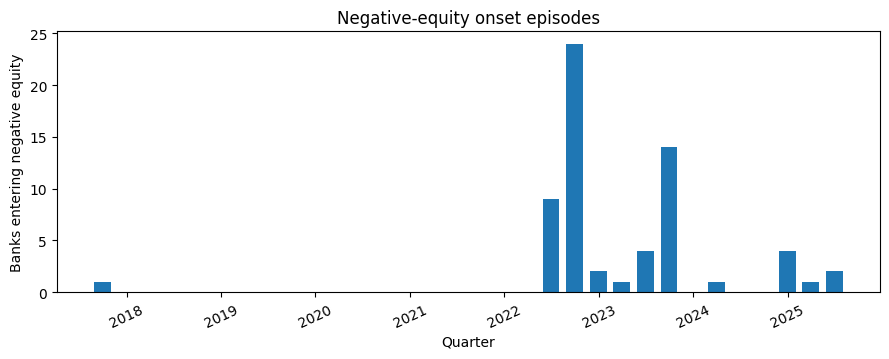

In [56]:
import matplotlib.pyplot as plt
jump_chart = jump_audit.copy()
jump_chart["REPDTE"] = pd.to_datetime(jump_chart["REPDTE"])
onsets = (jump_chart.loc[jump_chart["new_negative_equity"].fillna(False)]
          .groupby("REPDTE").size().sort_index())
fig, ax = plt.subplots(figsize=(9,3.7))
ax.bar(onsets.index, onsets.values, width=65)
ax.set(xlabel="Quarter", ylabel="Banks entering negative equity", title="Negative-equity onset episodes")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()

**Chart reading:** Spikes in 2022–2023 warrant institutional review. Onset flags do not by themselves identify FDIC failures.

### 2.3.12 — Structural Balance-Sheet Jumps and Capital Transitions

**Purpose:** Distinguish potentially structural balance-sheet changes from isolated reporting anomalies and examine concentrated negative-equity transitions.
**Check:** Compare changes in assets, deposits, and equity; inspect five-quarter histories around major asset jumps; and profile banks entering negative equity in 2022Q3 and 2023Q3.
**Readout:** Structural jump diagnostics, representative bank histories, and negative-equity onset profiles.

**Decision Rule:** Large, persistent changes may reflect legitimate institutional events. Neither extreme growth nor capital deterioration will be automatically treated as a data error.

#### 2.3.12 · Block 1/2 — Absolute changes in financial amounts

In [57]:
# 2.3.12 — Structural Balance-Sheet Jumps & Capital Transitions

audit = jump_audit.sort_values(["CERT", "REPDTE"]).copy()

# 1. Absolute changes in financial amounts
for field in ["ASSET", "DEP", "EQ"]:
    audit[f"delta_{field}"] = (
        audit[field] - audit[f"prev_{field}"]
    ).where(audit["consecutive_pair"])

# 2. Flag unusually large changes in asset scale
audit["asset_growth_over_100"] = (
    audit["asset_qoq_pct"] > 100
)
audit["asset_contraction_over_50"] = (
    audit["asset_qoq_pct"] < -50
)

large_growth = audit.loc[
    audit["asset_growth_over_100"]
].copy()

large_growth["deposit_increase"] = (
    large_growth["delta_DEP"] > 0
)

large_growth["equity_increase"] = (
    large_growth["delta_EQ"] > 0
)

print("STRUCTURAL ASSET JUMP SUMMARY")

jump_summary = pd.DataFrame([{
    "asset_growth_over_100_rows": len(large_growth),
    "asset_growth_over_100_banks": large_growth["CERT"].nunique(),
    "asset_contraction_over_50_rows": int(
        audit["asset_contraction_over_50"].sum()
    ),
    "growth_with_deposit_increase": int(
        large_growth["deposit_increase"].sum()
    ),
    "growth_with_equity_increase": int(
        large_growth["equity_increase"].sum()
    )
}])

display(jump_summary)

# 3. Top 10 largest asset growth events
top_growth = large_growth.nlargest(
    10, "asset_qoq_pct"
).copy()

print("\nTOP 10 ASSET JUMPS — FINANCIAL COMPONENTS")

display(
    top_growth[
        [
            "CERT", "REPDTE",
            "prev_ASSET", "ASSET", "delta_ASSET",
            "asset_qoq_pct",
            "prev_DEP", "DEP", "delta_DEP",
            "prev_EQ", "EQ", "delta_EQ",
            "reference_group"
        ]
    ].round(2)
)

# 4. Examine five-quarter histories around top 5 asset jumps
top_events = top_growth.head(5)[
    ["CERT", "quarter_index"]
].drop_duplicates()

histories = []

for event in top_events.itertuples(index=False):

    h = audit.loc[
        (audit["CERT"] == event.CERT)
        & audit["quarter_index"].between(
            event.quarter_index - 2,
            event.quarter_index + 2
        ),
        [
            "CERT", "REPDTE", "ASSET", "DEP", "EQ",
            "asset_qoq_pct", "deposit_qoq_pct",
            "equity_change_asset_pct"
        ]
    ].copy()

    h["event_quarter_index"] = event.quarter_index
    histories.append(h)

jump_histories = (
    pd.concat(histories, ignore_index=True)
    if histories else pd.DataFrame()
)

print("\nFINANCIAL HISTORY AROUND TOP 5 ASSET JUMPS")

display(
    jump_histories.sort_values(
        ["CERT", "event_quarter_index", "REPDTE"]
    ).round(2)
)

# 5. Examine 2022Q3 and 2023Q3 negative-equity onsets
focus_quarters = ["2022Q3", "2023Q3"]

onset_cases = audit.loc[
    audit["new_negative_equity"]
    & audit["quarter"].astype(str).isin(focus_quarters)
].copy()

# Add institution metadata from existing lookup
onset_cases = onset_cases.merge(
    bank_extremes[["CERT", "NAME", "BKCLASS"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

missing_onset_metadata = int(onset_cases[["NAME", "BKCLASS"]].isna().any(axis=1).sum())
print("Onset cases missing institution metadata:", missing_onset_metadata)
if missing_onset_metadata:
    print("REVIEW: metadata absent from the current institution snapshot; retain these events.")
print("\nNEGATIVE EQUITY ONSETS — 2022Q3 AND 2023Q3")

display(
    onset_cases[
        [
            "CERT", "NAME", "BKCLASS", "REPDTE",
            "prev_EQ", "EQ", "ASSET",
            "equity_change_asset_pct",
            "asset_qoq_pct", "deposit_qoq_pct",
            "ROA", "reference_group"
        ]
    ].sort_values(
        ["REPDTE", "equity_change_asset_pct"]
    ).round(3)
)

STRUCTURAL ASSET JUMP SUMMARY


,asset_growth_over_100_rows,asset_growth_over_100_banks,asset_contraction_over_50_rows,growth_with_deposit_increase,growth_with_equity_increase
0,147,130,31,137,126



TOP 10 ASSET JUMPS — FINANCIAL COMPONENTS


,CERT,REPDTE,prev_ASSET,ASSET,delta_ASSET,asset_qoq_pct,prev_DEP,DEP,delta_DEP,prev_EQ,EQ,delta_EQ,reference_group
26762,33497,2018-03-31,8378.0,6518825.0,6510447.0,77708.84,1150.0,6011577.0,6010427.0,6891.0,414542.0,407651.0,Matched
144427,57083,2023-12-31,47834.0,6241996.0,6194162.0,12949.29,32437.0,4696889.0,4664452.0,12085.0,1430056.0,1417971.0,Matched
55543,58303,2019-06-30,24538.0,2422003.0,2397465.0,9770.42,500.0,2205519.0,2205019.0,22811.0,171274.0,148463.0,Matched
110558,34588,2022-03-31,21516.0,1273992.0,1252476.0,5821.14,0.0,0.0,0.0,21473.0,1192766.0,1171293.0,Unmatched
105686,34629,2021-12-31,42779.0,1041787.0,999008.0,2335.28,0.0,0.0,0.0,40490.0,862976.0,822486.0,Unmatched
76632,59043,2020-06-30,15567.0,294999.0,279432.0,1795.03,0.0,267792.0,267792.0,13316.0,25173.0,11857.0,Matched
54375,33785,2019-06-30,20652.0,350161.0,329509.0,1595.53,501.0,319342.0,318841.0,15673.0,26053.0,10380.0,Matched
109658,26881,2022-03-31,174662.0,2038881.0,1864219.0,1067.33,155629.0,1233056.0,1077427.0,18226.0,773647.0,755421.0,Matched
122313,1213,2022-12-31,279387.0,1991593.0,1712206.0,612.84,266130.0,785727.0,519597.0,12198.0,354952.0,342754.0,Matched
106590,58339,2021-12-31,2514271.0,15083427.0,12569156.0,499.91,2497103.0,15068983.0,12571880.0,NaN,NaN,NaN,Unmatched



FINANCIAL HISTORY AROUND TOP 5 ASSET JUMPS


,CERT,REPDTE,ASSET,DEP,EQ,asset_qoq_pct,deposit_qoq_pct,equity_change_asset_pct,event_quarter_index
0,33497,2017-09-30,258692.0,109772.0,57447.0,5.35,-12.89,9.59,8073
1,33497,2017-12-31,8378.0,1150.0,6891.0,-96.76,-98.95,-19.54,8073
2,33497,2018-03-31,6518825.0,6011577.0,414542.0,77708.84,522645.83,4865.73,8073
3,33497,2018-06-30,9630179.0,9085639.0,533489.0,47.73,51.14,1.82,8073
4,33497,2018-09-30,13074000.0,12166000.0,832000.0,35.76,33.90,3.10,8073
15,34588,2021-09-30,21316.0,0.0,21285.0,1.30,NaN,1.50,8089
16,34588,2021-12-31,21516.0,0.0,21473.0,0.94,NaN,0.88,8089
17,34588,2022-03-31,1273992.0,0.0,1192766.0,5821.14,NaN,5443.82,8089
18,34588,2022-06-30,1327747.0,0.0,1232444.0,4.22,NaN,3.11,8089
19,34588,2022-09-30,1378632.0,0.0,1284463.0,3.83,NaN,3.92,8089


Onset cases missing institution metadata: 0

NEGATIVE EQUITY ONSETS — 2022Q3 AND 2023Q3


,CERT,NAME,BKCLASS,REPDTE,prev_EQ,EQ,ASSET,equity_change_asset_pct,asset_qoq_pct,deposit_qoq_pct,ROA,reference_group
19,12013,Union County Savings Bank,SI,2022-09-30,33166.0,-31607.0,1518786.0,-4.005,-6.096,-2.086,-4.730,Matched
4,3099,The First National Bank of Bellville,N,2022-09-30,11668.0,-17769.0,754119.0,-3.788,-2.948,1.539,1.530,Matched
5,3255,The Citizens National Bank of Hillsboro,N,2022-09-30,6886.0,-1225.0,217265.0,-3.631,-2.751,0.904,1.232,Matched
23,15326,The Union Banking Company,NM,2022-09-30,1016.0,-928.0,52951.0,-3.487,-5.016,-1.608,0.872,Matched
0,41,Phenix-Girard Bank,NM,2022-09-30,1740.0,-7566.0,263663.0,-3.469,-1.707,1.894,1.087,Matched
28,18282,First National Bank of Alvin,N,2022-09-30,4961.0,-1163.0,163054.0,-3.341,-11.042,-7.994,0.602,Matched
7,3639,First National Bank & Trust Company,N,2022-09-30,10639.0,-881.0,393056.0,-2.988,1.954,4.764,0.461,Matched
1,2359,Mauch Chunk Trust Company,NM,2022-09-30,939.0,-16888.0,592149.0,-2.973,-1.256,3.292,0.882,Matched
27,17636,Astra Bank,NM,2022-09-30,3034.0,-8297.0,389427.0,-2.825,-2.904,-3.433,0.570,Matched
36,58184,Merchants Commercial Bank,NM,2022-09-30,8202.0,-4441.0,445365.0,-2.772,-2.347,-14.600,2.489,Matched


#### 2.3.12 · Block 2/2 — Aggregate onset characteristics by quarter

In [58]:
# 6. Aggregate onset characteristics by quarter
print("\nCAPITAL TRANSITION CHARACTERISTICS")

onset_summary = (
    onset_cases
    .groupby("quarter")
    .agg(
        n_onsets=("CERT", "size"),
        n_banks=("CERT", "nunique"),
        median_previous_equity=("prev_EQ", "median"),
        median_new_equity=("EQ", "median"),
        median_equity_change_pct=(
            "equity_change_asset_pct", "median"
        ),
        median_asset_change_pct=(
            "asset_qoq_pct", "median"
        ),
        median_roa=("ROA", "median")
    )
    .reset_index()
)

display(onset_summary.round(3))

# 7. Validation
checks = {
    "All recent rows retained": len(audit) == recent_n,

    "Asset jump flags use valid pairs":
        audit.loc[
            audit["asset_growth_over_100"],
            "consecutive_pair"
        ].all(),

    "Asset contraction flags use valid pairs":
        audit.loc[
            audit["asset_contraction_over_50"],
            "consecutive_pair"
        ].all(),

    "2022Q3 onsets reconcile":
        int(
            onset_cases["quarter"].astype(str).eq("2022Q3").sum()
        ) == 24,

    "2023Q3 onsets reconcile":
        int(
            onset_cases["quarter"].astype(str).eq("2023Q3").sum()
        ) == 14
}

print("\nSTRUCTURAL JUMP AND CAPITAL AUDIT")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.3.12: PASS")


CAPITAL TRANSITION CHARACTERISTICS


,quarter,n_onsets,n_banks,median_previous_equity,median_new_equity,median_equity_change_pct,median_asset_change_pct,median_roa
0,2022Q3,24,24,2387.0,-1102.5,-2.437,-2.290,0.877
1,2023Q3,14,14,1125.5,-1714.5,-1.452,-1.171,0.750



STRUCTURAL JUMP AND CAPITAL AUDIT
All recent rows retained: PASS
Asset jump flags use valid pairs: PASS
Asset contraction flags use valid pairs: PASS
2022Q3 onsets reconcile: PASS
2023Q3 onsets reconcile: PASS

CELL 2.3.12: PASS


##### Interpretation 2.3.12 — Structural Balance-Sheet Changes and Capital Transitions

**Evidence:** 147 modern-within-window asset growth events exceed 100%; full-history lags later identify three more at the 2017 boundary.

**Decision:** Preserve raw asset values and compare transition definitions at sample boundaries.

**Limit:** Consolidated 150 events are not an error in the prior 147-event audit; they use a broader lag history.

### 2.3.13 — Consolidated Financial Anomaly Audit

**Purpose:** Consolidate reporting exceptions, institutional eligibility concerns, financial distress conditions, and extreme financial observations into one auditable bank-quarter register.
**Check:** Combine previously validated diagnostic indicators, quantify their prevalence, examine overlapping flags, and identify institutions requiring further investigation.
**Readout:** A unified anomaly summary, flag-overlap checks, and a bank-level review queue.

**Decision Rule:** Diagnostic flags do not establish invalidity. All original financial values and observations remain unchanged pending method comparison and validation in Section 2.4.

#### 2.3.13 · Block 1/2 — Base register: one row per bank-quarter

In [59]:
# 2.3.13 — Consolidated Financial Anomaly Audit

# 1. Base register: one row per bank-quarter
anomaly_register = recent_core[
    [
        "CERT", "REPDTE", "ASSET", "DEP", "EQ",
        "ROA", "ROE", "RBC1AAJ", "severe"
    ]
].copy()

# 2. Attach previous temporal diagnostics
temporal_cols = [
    "CERT", "REPDTE",
    "asset_qoq_pct", "deposit_qoq_pct",
    "equity_change_asset_pct",
    "asset_growth_over_100",
    "asset_contraction_over_50",
    "large_equity_change",
    "new_negative_equity"
]

anomaly_register = anomaly_register.merge(
    audit[temporal_cols],
    on=["CERT", "REPDTE"],
    how="left",
    validate="one_to_one"
)

# 3. Attach provisional quarterly income
anomaly_register = anomaly_register.merge(
    income_audit_df[
        ["CERT", "REPDTE", "qtr_NONII"]
    ],
    on=["CERT", "REPDTE"],
    how="left",
    validate="one_to_one"
)

# 4. Create consolidated diagnostic flags
anomaly_register["sparse_reporting"] = (
    anomaly_register["severe"]
)

anomaly_register["roe_missing_nonsevere"] = (
    ~anomaly_register["severe"]
    & anomaly_register["ROE"].isna()
)

anomaly_register["rbc_zero_sparse"] = (
    anomaly_register["RBC1AAJ"].eq(0)
    & anomaly_register["severe"]
)

anomaly_register["institution_unmatched"] = (
    ~anomaly_register["CERT"].isin(institution_id_set)
)

anomaly_register["zero_deposits"] = (
    anomaly_register["DEP"].eq(0)
)

anomaly_register["negative_equity"] = (
    anomaly_register["EQ"].lt(0)
)

anomaly_register["deposits_exceed_assets"] = (
    anomaly_register["DEP"] > anomaly_register["ASSET"]
)

anomaly_register["equity_onset"] = (
    anomaly_register["new_negative_equity"]
)

anomaly_register["extreme_roa"] = (
    anomaly_register["ROA"].abs() > 20
)

anomaly_register["extreme_roe"] = (
    anomaly_register["ROE"].abs() > 100
)

anomaly_register["rbc_negative"] = (
    anomaly_register["RBC1AAJ"].lt(0)
)

anomaly_register["rbc_above_100"] = (
    anomaly_register["RBC1AAJ"].gt(100)
)

anomaly_register["asset_growth_gt100"] = (
    anomaly_register["asset_growth_over_100"]
)

anomaly_register["asset_contraction_gt50"] = (
    anomaly_register["asset_contraction_over_50"]
)

anomaly_register["large_equity_move"] = (
    anomaly_register["large_equity_change"]
)

anomaly_register["negative_nonii_increment"] = (
    anomaly_register["REPDTE"].dt.quarter.ne(1)
    & anomaly_register["qtr_NONII"].lt(0)
)

# 5. Define categories for review
flag_categories = {
    "sparse_reporting": "Reporting",
    "roe_missing_nonsevere": "Reporting",
    "rbc_zero_sparse": "Reporting",
    "institution_unmatched": "Eligibility",
    "zero_deposits": "Institution structure",
    "negative_equity": "Financial condition",
    "deposits_exceed_assets": "Financial condition",
    "equity_onset": "Financial condition",
    "extreme_roa": "Profitability",
    "extreme_roe": "Profitability",
    "rbc_negative": "Capital ratio",
    "rbc_above_100": "Capital ratio",
    "asset_growth_gt100": "Structural change",
    "asset_contraction_gt50": "Structural change",
    "large_equity_move": "Structural change",
    "negative_nonii_increment": "Income reporting"
}

flag_columns = list(flag_categories)

#### 2.3.13 · Block 2/2 — Build summary by diagnostic flag

In [60]:
# 6. Build summary by diagnostic flag
summary_rows = []

for flag, category in flag_categories.items():

    mask = anomaly_register[flag].fillna(False)

    summary_rows.append({
        "category": category,
        "flag": flag,
        "n_rows": int(mask.sum()),
        "n_banks": anomaly_register.loc[
            mask, "CERT"
        ].nunique(),
        "pct_rows": round(
            mask.mean() * 100, 3
        )
    })

anomaly_summary = pd.DataFrame(summary_rows)

print("CONSOLIDATED ANOMALY SUMMARY")

display(
    anomaly_summary.sort_values(
        ["category", "n_rows"],
        ascending=[True, False]
    )
)

# 7. Count overlapping flags at observation level
anomaly_register["n_active_flags"] = (
    anomaly_register[flag_columns].sum(axis=1)
)

anomaly_register["has_any_flag"] = (
    anomaly_register["n_active_flags"] > 0
)

print("\nFLAG OVERLAP DISTRIBUTION")

display(
    anomaly_register["n_active_flags"]
    .value_counts()
    .sort_index()
    .rename_axis("n_active_flags")
    .reset_index(name="n_observations")
)

print("\nOBSERVATIONS WITH AT LEAST ONE FLAG")
print(int(anomaly_register["has_any_flag"].sum()))

# 8. Build a bank-level review queue
review_queue = (
    anomaly_register.groupby("CERT")
    .agg(
        n_quarters=("REPDTE", "size"),
        n_flagged_quarters=("has_any_flag", "sum"),
        total_flag_occurrences=("n_active_flags", "sum"),
        sparse_quarters=("sparse_reporting", "sum"),
        unmatched=("institution_unmatched", "max"),
        negative_equity_quarters=("negative_equity", "sum"),
        equity_onsets=("equity_onset", "sum"),
        extreme_roa_quarters=("extreme_roa", "sum"),
        asset_growth_jumps=("asset_growth_gt100", "sum")
    )
    .reset_index()
)

print("\nTOP 15 BANKS — REVIEW QUEUE")

display(
    review_queue.sort_values(
        "total_flag_occurrences",
        ascending=False
    ).head(15)
)

# 9. Reconcile known findings
checks = {
    "Unique bank-quarter keys":
        not anomaly_register.duplicated(
            ["CERT", "REPDTE"]
        ).any(),

    "All recent observations retained":
        len(anomaly_register) == recent_n,

    "Severe reporting = 578":
        int(anomaly_register["sparse_reporting"].sum()) == 578,

    "ROE missing non-severe = 139":
        int(anomaly_register["roe_missing_nonsevere"].sum()) == 139,

    "Unmatched banks = 71":
        review_queue["unmatched"].sum() == 71,

    "Negative equity = 207":
        int(anomaly_register["negative_equity"].sum()) == 207,

    "Deposits > Assets = 79":
        int(anomaly_register["deposits_exceed_assets"].sum()) == 79,

    "Equity onsets = 63":
        int(anomaly_register["equity_onset"].sum()) == 63,

    "Extreme ROA = 888":
        int(anomaly_register["extreme_roa"].sum()) == 888,

    "Extreme ROE = 293":
        int(anomaly_register["extreme_roe"].sum()) == 293,

    "Asset growth >100% = 147":
        int(anomaly_register["asset_growth_gt100"].sum()) == 147,

    "Asset contraction >50% = 31":
        int(anomaly_register["asset_contraction_gt50"].sum()) == 31,

    "RBC zero matches sparse reporting":
        anomaly_register["RBC1AAJ"].eq(0).equals(
            anomaly_register["sparse_reporting"]
        ),

    "Deposits > Assets implies negative equity":
        (
            ~anomaly_register["deposits_exceed_assets"]
            | anomaly_register["negative_equity"]
        ).all()
}

print("\nCONSOLIDATED ANOMALY VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.3.13: PASS")

CONSOLIDATED ANOMALY SUMMARY


,category,flag,n_rows,n_banks,pct_rows
11,Capital ratio,rbc_above_100,310,59,0.179
10,Capital ratio,rbc_negative,2,2,0.001
3,Eligibility,institution_unmatched,1780,71,1.029
5,Financial condition,negative_equity,207,43,0.120
6,Financial condition,deposits_exceed_assets,79,21,0.046
7,Financial condition,equity_onset,63,42,0.036
15,Income reporting,negative_nonii_increment,1503,936,0.869
4,Institution structure,zero_deposits,1791,87,1.036
8,Profitability,extreme_roa,888,82,0.514
9,Profitability,extreme_roe,293,94,0.169



FLAG OVERLAP DISTRIBUTION


,n_active_flags,n_observations
0,0,167424
1,1,2539
2,2,1939
3,3,632
4,4,335
5,5,53
6,6,2



OBSERVATIONS WITH AT LEAST ONE FLAG
5500

TOP 15 BANKS — REVIEW QUEUE


,CERT,n_quarters,n_flagged_quarters,total_flag_occurrences,sparse_quarters,unmatched,negative_equity_quarters,equity_onsets,extreme_roa_quarters,asset_growth_jumps
5258,57081,34,34,150,0,True,0,0,30,0
4772,33239,34,34,145,0,True,0,0,34,0
5328,57337,34,34,135,0,True,0,0,34,0
5519,58011,34,34,126,0,True,0,0,34,0
5438,57757,30,30,126,0,True,0,0,30,0
5867,59025,34,34,122,0,True,0,0,26,0
5446,57793,34,34,118,0,True,0,0,34,0
4864,34057,34,34,109,0,True,0,0,22,0
5647,58339,34,34,108,34,True,0,0,0,4
4070,27102,34,34,107,0,True,0,0,32,0



CONSOLIDATED ANOMALY VALIDATION
Unique bank-quarter keys: PASS
All recent observations retained: PASS
Severe reporting = 578: PASS
ROE missing non-severe = 139: PASS
Unmatched banks = 71: PASS
Negative equity = 207: PASS
Deposits > Assets = 79: PASS
Equity onsets = 63: PASS
Extreme ROA = 888: PASS
Extreme ROE = 293: PASS
Asset growth >100% = 147: PASS
Asset contraction >50% = 31: PASS
RBC zero matches sparse reporting: PASS
Deposits > Assets implies negative equity: PASS

CELL 2.3.13: PASS


### 2.3 — Consolidated financial anomaly audit

**Evidence:** The modern window contains **5,500 flagged bank-quarter observations (3.18%)**; these flags overlap and are **not** a list of erroneous records. Negative equity, unusual profitability, sparse reporting and large balance-sheet movements represent different mechanisms.

**Decision:** Preserve the original values; use anomaly flags and bank-level review queues. Section 2.4 tests what information would be lost under alternative cleaning rules.

**Limit:** Audit flags are diagnostic thresholds, not verified accounting violations or model features automatically eligible for use.

**Figure 4 — Which anomaly signals are common?** Aggregate overlapping anomaly flags (counts are **not additive**) to focus the review queue.

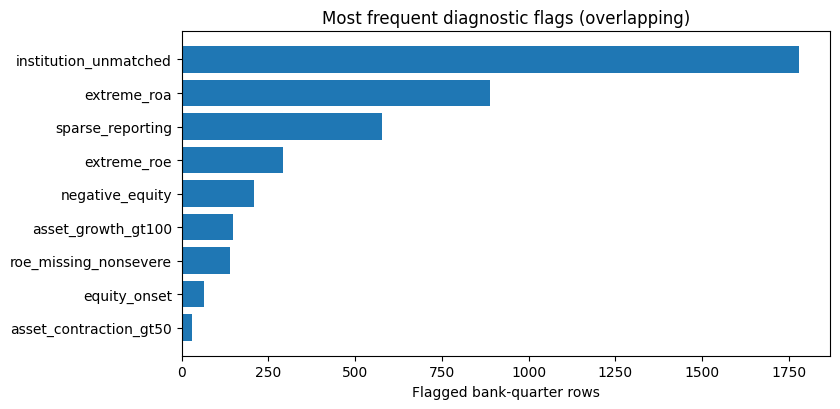

In [61]:
import matplotlib.pyplot as plt
# Use existing consolidated flags rather than an externally supplied list.
flag_cols = [x for x in anomaly_register.columns
             if x in ["sparse_reporting", "roe_missing_nonsevere", "institution_unmatched", "negative_equity", "equity_onset", "extreme_roa", "extreme_roe", "asset_growth_gt100", "asset_contraction_gt50", "rbc_zero"]
             and pd.api.types.is_bool_dtype(anomaly_register[x])]
flag_counts = anomaly_register[flag_cols].sum().sort_values(ascending=False).head(10)
if not flag_counts.empty:
    fig, ax = plt.subplots(figsize=(8.5,4.2))
    ax.barh(flag_counts.index[::-1], flag_counts.values[::-1]); ax.set(xlabel="Flagged bank-quarter rows", title="Most frequent diagnostic flags (overlapping)")
    plt.tight_layout(); plt.show()
else:
    print("No recognized boolean flags; inspect anomaly_register columns before plotting.")

**Chart reading:** High-frequency flags prioritize review; overlapping flags must not be summed to estimate the number of affected rows.

### 2.3.7A — P1 | NETINC semantics and real-world data availability

**Question:** Can FDIC `NETINC` be interpreted as quarterly profit, and would the report have been public at `REPDTE`?

**Accounting rule:** Call Report income statements are generally reported **year to date (YTD)**. Quarterly earnings are usually the current YTD value less the prior quarter's YTD value **within the same calendar year**. Q1 YTD is already Q1; never subtract across a year boundary. Mergers, re-filings and missing quarters require review rather than automatic interpolation.

**Availability rule:** `REPDTE` is a reporting **as-of** date, not an observed publication timestamp. FFIEC says individual validated filings may become available after submission, whereas **bulk quarterly files begin 45 calendar days after report-end**. A 45-day lag is a bulk-publication proxy—not evidence for the vintage of every bank-quarter row. Phase 3/4 must prevent future-vintage leakage.

**Sources:** [FDIC financial methodology](https://banks.data.fdic.gov/bankfind-suite/help?helpTopic=disclaimers-and-methodologies) · [FFIEC public data availability](https://www.cdr.ffiec.gov/Public/HelpFiles/WelcomeAdditionalInfo.htm) · [FDIC BankFind field dictionary](https://api.fdic.gov/banks/docs/).

In [62]:
# 2.3.7A.1 — Check NETINC availability and within-year YTD-to-quarter arithmetic
# Use the previously initialized Bronze LazyFrame; Silver is only created in Section 2.5
net_lf_p1 = financial_lf
net_cols_p1 = net_lf_p1.collect_schema().names()
net_fields_p1 = [c for c in ('NETINC', 'NETINCQ') if c in net_cols_p1]
print('NETINC-related columns found:', net_fields_p1)
netinc_audit_p1 = None
netinc_validation_p1 = {'NETINC_present': 'NETINC' in net_fields_p1,
                        'NETINCQ_present': 'NETINCQ' in net_fields_p1}
if 'NETINC' in net_fields_p1:
    netinc_audit_p1 = (net_lf_p1.select(['CERT','REPDTE']+net_fields_p1)
                       .collect().to_pandas())
    netinc_audit_p1['REPDTE'] = pd.to_datetime(netinc_audit_p1['REPDTE'])
    netinc_audit_p1 = netinc_audit_p1.sort_values(['CERT','REPDTE']).reset_index(drop=True)
    netinc_audit_p1['year'] = netinc_audit_p1['REPDTE'].dt.year
    netinc_audit_p1['quarter'] = netinc_audit_p1['REPDTE'].dt.quarter
    netinc_audit_p1['NETINC'] = pd.to_numeric(netinc_audit_p1['NETINC'],errors='coerce')
    grp = netinc_audit_p1.groupby(['CERT','year'],sort=False)
    prev_net = grp['NETINC'].shift()
    prev_qtr = grp['quarter'].shift()
    is_q1 = netinc_audit_p1['quarter'].eq(1)
    consecutive = netinc_audit_p1['quarter'].eq(prev_qtr+1)
    netinc_audit_p1['NETINC_quarter_derived'] = np.where(
        is_q1, netinc_audit_p1['NETINC'],
        np.where(consecutive, netinc_audit_p1['NETINC']-prev_net,np.nan))
    print('NETINC non-null:',int(netinc_audit_p1['NETINC'].notna().sum()))
    print('Derived quarterly observations:',int(pd.Series(netinc_audit_p1['NETINC_quarter_derived']).notna().sum()))
    print('Q2–Q4 missing previous consecutive quarter:', int((~is_q1 & ~consecutive).sum()))
    if 'NETINCQ' in netinc_audit_p1:
        netinc_audit_p1['NETINCQ'] = pd.to_numeric(netinc_audit_p1['NETINCQ'],errors='coerce')
        comparable = netinc_audit_p1[['NETINCQ','NETINC_quarter_derived']].dropna()
        print('NETINCQ comparisons:',len(comparable))
        if len(comparable):
            diff = comparable['NETINCQ']-comparable['NETINC_quarter_derived']
            print('Median |difference|:',round(float(diff.abs().median()),3))
            print('Share exact within 0.01:',round(float(diff.abs().le(0.01).mean()*100),2),'%')
    print('DECISION: exploratory validation only; investigate discrepancies, especially mergers/revisions.')
else:
    print('REVIEW: NETINC is not in the selected Bronze schema. Do not invent a replacement field.')

# Export compact evidence, avoiding a large row-level copy of the full bank panel.
NETINC_EVIDENCE_PATH = Path(ROOT) / 'reports' / 'phase2' / 'netinc_ytd_validation_summary.csv'
NETINC_EVIDENCE_PATH.parent.mkdir(parents=True, exist_ok=True)
netinc_summary = {
    'NETINC_present': bool(netinc_validation_p1['NETINC_present']),
    'NETINCQ_present': bool(netinc_validation_p1['NETINCQ_present']),
    'n_rows': 0 if netinc_audit_p1 is None else len(netinc_audit_p1),
    'n_netinc_nonnull': 0 if netinc_audit_p1 is None else int(netinc_audit_p1['NETINC'].notna().sum()),
    'n_derived_nonnull': 0 if netinc_audit_p1 is None else int(netinc_audit_p1['NETINC_quarter_derived'].notna().sum()),
    'n_missing_previous_quarter': 0 if netinc_audit_p1 is None else int((~is_q1 & ~consecutive).sum()),
    'n_netincq_comparable': int(len(comparable)) if netinc_audit_p1 is not None and 'NETINCQ' in netinc_audit_p1 else 0,
}
if netinc_audit_p1 is not None and 'NETINCQ' in netinc_audit_p1 and len(comparable):
    netinc_summary['median_abs_difference'] = float(diff.abs().median())
    netinc_summary['pct_within_0_01'] = float(diff.abs().le(0.01).mean() * 100)
pd.DataFrame([netinc_summary]).to_csv(NETINC_EVIDENCE_PATH, index=False)
print('NETINC exploratory validation summary saved:', NETINC_EVIDENCE_PATH)


NETINC-related columns found: []
REVIEW: NETINC is not in the selected Bronze schema. Do not invent a replacement field.
NETINC exploratory validation summary saved: C:\học tập\kì 7\Big data\Final\Bản nháp\reports\phase2\netinc_ytd_validation_summary.csv


In [63]:
# 2.3.7A.2 — Publication-vintage audit (metadata evidence, not fabricated dates)
pit_availability_p1 = pd.DataFrame([
    {'timestamp':'REPDTE','meaning':'Financial reporting reference date',
     'availability_status':'AVAILABLE — not the first public release'},
    {'timestamp':'Bank-specific filing/validation date',
     'meaning':'First usable individual Call Report (may vary by bank)',
     'availability_status':'NOT IN CURRENT SILVER — verify externally'},
    {'timestamp':'REPDTE + 45 calendar days',
     'meaning':'Approximate first quarterly FFIEC bulk-file release',
     'availability_status':'DOCUMENTED GENERAL RULE; not an exact bank-level vintage'},
    {'timestamp':'Bank-specific amended/revised vintage',
     'meaning':'Historical version actually published at prediction time',
     'availability_status':'NOT IN CURRENT SILVER — point-in-time risk remains'}
])
display(pit_availability_p1)
print('P1 status: NETINC arithmetic is testable when the field exists; actual bank-level publication dates remain OPEN.')


,timestamp,meaning,availability_status
0,REPDTE,Financial reporting reference date,AVAILABLE — not the first public release
1,Bank-specific filing/validation date,First usable individual Call Report (may vary ...,NOT IN CURRENT SILVER — verify externally
2,REPDTE + 45 calendar days,Approximate first quarterly FFIEC bulk-file re...,DOCUMENTED GENERAL RULE; not an exact bank-lev...
3,Bank-specific amended/revised vintage,Historical version actually published at predi...,NOT IN CURRENT SILVER — point-in-time risk rem...


P1 status: NETINC arithmetic is testable when the field exists; actual bank-level publication dates remain OPEN.


##### Interpretation 2.3.7A — Evidence → Decision → Limit

**Evidence:** FDIC describes year-to-date income reporting; the cell tests whether `NETINC` is available and whether a quarterly series can be derived without crossing years. **Decision:** Treat `NETINC` as YTD until field metadata and any observed `NETINCQ` discrepancies are resolved; do not use `REPDTE` as proof of public availability. **Limit:** Historical individual filing dates and data revisions are not present in the Silver panel; the 45-day rule only supports a documented bulk-release sensitivity assumption.

### 2.3.14 — Full Financial-Field Quality Audit (133/133) | Revised Method

**Objective:** Extend the Phase 2 quality inventory to **all 133 FDIC financial fields** over the complete 1984Q1–2026Q2 bank-quarter panel without treating economically meaningful tail observations as errors.

**Method (consistent with Sections 2.3.2, 2.3.4 and 2.3.11):**

1. **Distribution and data completeness (133/133):** Report null/NaN/infinity, finite coverage, negative/zero prevalence, min, P01/P05/P25/median/P75/P95/P99/max. Retain the original values.
2. **Annual reporting-regime diagnostics (133/133):** Profile financial-field coverage and P01/median/P99 by reporting year, avoiding the assumption that the entire 1984–2026 period shares the same reporting regime.
3. **Field-specific financial review rules (selected verified fields only):** Reuse the exploratory thresholds from the original notebook (ROA, ROE, RBC1AAJ, ASSET, DEP, EQ); these are **review flags, not cleaning or rejection criteria**. Other fields are *not* automatically subject to the same accounting rules.
4. **Gap-aware temporal profiling (133/133):** Report adjacent-quarter comparable pairs, absolute-change distributions, sign reversals and zero transitions. Apply *quarterly percentage-change thresholds only* to ASSET/DEP/EQ using the exact denominators and thresholds in Section 2.3.11: 25%, 30%, 5% of prior ASSET respectively.

**Outputs:** `reports/phase2/financial_field_quality_audit.csv` (133 rows), `financial_field_yearly_profile.csv` (field–year rows), `financial_field_rule_flags.csv` (targeted review rules) and `financial_field_temporal_audit.csv` (133 rows).

**Decision:** *Preserve all observations.* Statistical tails, changing availability, negative earnings and large financial movements are evidence for investigation, not grounds for clipping, deletion or imputation. The audit is diagnostic and **does not certify** every historical field definition, accounting identity or point-in-time availability.

**Prerequisite:** Run the Phase 2 initialization and Section 2.2.1 cells that define `ROOT`, `financial_lf` and `financial_cols`.

#### 2.3.14 · Block 1/3 — Complete 133-field distributions, types and missingness

In [64]:
# 2.3.14 — Block 1/3: Full financial-field distribution inventory (no clipping)
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl

Q214_DIR = Path(ROOT) / "reports" / "phase2"
Q214_DIR.mkdir(parents=True, exist_ok=True)

q214_schema = financial_lf.collect_schema()
q214_fields = list(financial_cols)
q214_numeric = [c for c in q214_fields if q214_schema[c].is_numeric()]
q214_non_numeric = sorted(set(q214_fields) - set(q214_numeric))
assert len(q214_fields) == 133, f"Expected 133 financial fields; found {len(q214_fields)}"
assert not q214_non_numeric, f"Separate type-specific audit needed: {q214_non_numeric}"
assert {"CERT", "REPDTE"}.issubset(q214_schema.names())

q214_rows = financial_lf.select(pl.len()).collect().item()
Q214_BATCH = 10                 # bounded number of wide aggregates per scan
q214_distribution_rows = []

for start in range(0, len(q214_fields), Q214_BATCH):
    group_fields = q214_fields[start:start + Q214_BATCH]
    exprs = []
    for c in group_fields:
        x = pl.col(c).cast(pl.Float64, strict=False)
        finite = x.filter(x.is_finite())
        statistics = {
            "null_count": x.is_null().sum(),
            "nan_count": x.is_nan().fill_null(False).sum(),
            "infinite_count": x.is_infinite().fill_null(False).sum(),
            "finite_count": x.is_finite().fill_null(False).sum(),
            "zero_count": (x == 0).fill_null(False).sum(),
            "negative_count": (x < 0).fill_null(False).sum(),
            "positive_count": (x > 0).fill_null(False).sum(),
            "min": finite.min(),
            "p01": finite.quantile(0.01),
            "p05": finite.quantile(0.05),
            "p25": finite.quantile(0.25),
            "median": finite.median(),
            "p75": finite.quantile(0.75),
            "p95": finite.quantile(0.95),
            "p99": finite.quantile(0.99),
            "max": finite.max(),
        }
        exprs += [v.alias(f"{k}__{c}") for k, v in statistics.items()]

    observed = financial_lf.select(exprs).collect().row(0, named=True)
    for c in group_fields:
        row = {"field": c, "dtype": str(q214_schema[c]), "n_rows": q214_rows}
        row.update({k: observed[f"{k}__{c}"] for k in statistics})
        q214_distribution_rows.append(row)
    print(f"[2.3.14/1] Profiled {min(start + Q214_BATCH, len(q214_fields))}/{len(q214_fields)} fields")

q214_profile = pd.DataFrame(q214_distribution_rows)
q214_profile["missing_count"] = q214_profile["null_count"] + q214_profile["nan_count"]
q214_profile["missing_pct"] = 100 * q214_profile["missing_count"] / q214_rows
q214_profile["finite_coverage_pct"] = 100 * q214_profile["finite_count"] / q214_rows
q214_profile["zero_pct_finite"] = 100 * q214_profile["zero_count"] / q214_profile["finite_count"].replace(0, np.nan)
q214_profile["negative_pct_finite"] = 100 * q214_profile["negative_count"] / q214_profile["finite_count"].replace(0, np.nan)

assert q214_profile["field"].is_unique
assert (q214_profile["null_count"] + q214_profile["nan_count"] + q214_profile["infinite_count"] + q214_profile["finite_count"] == q214_rows).all()
print(f"\nFIELD INVENTORY: {len(q214_profile)} fields × {q214_rows:,} observations; no data modified")
display(q214_profile.sort_values("missing_pct", ascending=False).head(15))

[2.3.14/1] Profiled 10/133 fields
[2.3.14/1] Profiled 20/133 fields
[2.3.14/1] Profiled 30/133 fields
[2.3.14/1] Profiled 40/133 fields
[2.3.14/1] Profiled 50/133 fields
[2.3.14/1] Profiled 60/133 fields
[2.3.14/1] Profiled 70/133 fields
[2.3.14/1] Profiled 80/133 fields
[2.3.14/1] Profiled 90/133 fields
[2.3.14/1] Profiled 100/133 fields
[2.3.14/1] Profiled 110/133 fields
[2.3.14/1] Profiled 120/133 fields
[2.3.14/1] Profiled 130/133 fields
[2.3.14/1] Profiled 133/133 fields

FIELD INVENTORY: 133 fields × 1,682,616 observations; no data modified


,field,dtype,n_rows,null_count,nan_count,infinite_count,finite_count,zero_count,negative_count,positive_count,...,median,p75,p95,p99,max,missing_count,missing_pct,finite_coverage_pct,zero_pct_finite,negative_pct_finite
129,OREOTHF,Float64,1682616,1665620,0,0,16996,16146,0,850,...,0.0,0.0,0.0,21000.0,1060000.0,1665620,98.989906,1.010094,94.998823,0.000000
102,NTAGQA,Float64,1682616,1599168,0,0,83448,70284,6234,6930,...,0.0,0.0,136.0,3432.0,324012.0,1599168,95.040580,4.959420,84.224907,7.470521
101,NTAGQ,Float64,1682616,1599168,0,0,83448,70284,6234,6930,...,0.0,0.0,34.0,858.0,81003.0,1599168,95.040580,4.959420,84.224907,7.470521
52,DRAGQ,Float64,1682616,1599168,0,0,83448,74770,197,8481,...,0.0,0.0,56.0,1000.0,81323.0,1599168,95.040580,4.959420,89.600709,0.236075
100,NTAG,Float64,1682616,1599141,0,0,83475,67788,6754,8933,...,0.0,0.0,105.0,1888.0,150000.0,1599141,95.038975,4.961025,81.207547,8.091045
51,DRAG,Float64,1682616,1599141,0,0,83475,71898,2,11575,...,0.0,0.0,178.0,2225.0,154000.0,1599141,95.038975,4.961025,86.131177,0.002396
59,DRCINUSQ,Float64,1682616,1452483,0,0,230133,225281,218,4634,...,0.0,0.0,0.0,700.0,762000.0,1452483,86.322904,13.677096,97.891654,0.094728
125,NTRENUSQ,Float64,1682616,1452483,0,0,230133,228433,668,1032,...,0.0,0.0,0.0,0.0,144000.0,1452483,86.322904,13.677096,99.261297,0.290267
84,DRRENUSQ,Float64,1682616,1452480,0,0,230136,228923,49,1164,...,0.0,0.0,0.0,0.0,146000.0,1452480,86.322726,13.677274,99.472920,0.021292
58,DRCINUS,Float64,1682616,1452430,0,0,230186,224091,0,6095,...,0.0,0.0,0.0,2243.0,1607000.0,1452430,86.319754,13.680246,97.352141,0.000000


#### 2.3.14 · Block 2/3 — Annual coverage, distribution shifts and field-specific financial checks (NO IQR rule)

In [65]:
# 2.3.14 — Block 2/3: Per-year distribution + existing finance-specific review rules
# No 1.5×IQR test, no uniform percentile-tail = "bad data" assumption.

# A. Field-by-year coverage and P01/median/P99 across the entire source panel
q214_yearly_rows = []
q214_year_lf = financial_lf.with_columns(pl.col("REPDTE").dt.year().alias("__year"))

for start in range(0, len(q214_fields), Q214_BATCH):
    group_fields = q214_fields[start:start + Q214_BATCH]
    agg = [pl.len().alias("__n_rows")]
    for c in group_fields:
        x = pl.col(c).cast(pl.Float64, strict=False)
        finite = x.filter(x.is_finite())
        agg += [
            x.is_finite().fill_null(False).sum().alias(f"valid__{c}"),
            finite.quantile(0.01).alias(f"p01__{c}"),
            finite.median().alias(f"median__{c}"),
            finite.quantile(0.99).alias(f"p99__{c}"),
        ]
    yearly = (q214_year_lf.group_by("__year").agg(agg)
              .sort("__year").collect())
    for data in yearly.iter_rows(named=True):
        for c in group_fields:
            n = int(data["__n_rows"])
            valid = int(data[f"valid__{c}"])
            q214_yearly_rows.append({
                "field": c, "year": int(data["__year"]), "n_rows": n,
                "finite_count": valid, "finite_coverage_pct": 100 * valid / n if n else np.nan,
                "p01": data[f"p01__{c}"], "median": data[f"median__{c}"],
                "p99": data[f"p99__{c}"],
            })
    print(f"[2.3.14/2] Annual distribution: {min(start + Q214_BATCH, len(q214_fields))}/{len(q214_fields)} fields")

q214_yearly = pd.DataFrame(q214_yearly_rows).sort_values(["field", "year"])
assert len(q214_yearly["field"].unique()) == 133
assert not q214_yearly.duplicated(["field", "year"]).any()
assert (q214_yearly.groupby("field")["n_rows"].sum() == q214_rows).all()

annual_range = (q214_yearly.groupby("field", as_index=False)
    .agg(years_in_panel=("year", "nunique"),
         annual_coverage_min_pct=("finite_coverage_pct", "min"),
         annual_coverage_max_pct=("finite_coverage_pct", "max")))
annual_range["annual_coverage_range_pp"] = (
    annual_range["annual_coverage_max_pct"] - annual_range["annual_coverage_min_pct"]
)

# B. Explicit diagnostic rules inherited from Sections 2.3.3, 2.3.4 and 2.3.10
# Rules apply only to their named financial fields; negative equity is distress, not "invalid".
q214_rule_specs = [
    ("ASSET_NONPOSITIVE", "ASSET", "ASSET <= 0; accounting plausibility review", pl.col("ASSET") <= 0),
    ("DEP_NEGATIVE", "DEP", "DEP < 0; deposit reporting review", pl.col("DEP") < 0),
    ("EQ_NEGATIVE", "EQ", "EQ < 0; legitimate distress indicator", pl.col("EQ") < 0),
    ("ROA_ABS_GT20", "ROA", "abs(ROA) > 20 (percentage units); Section 2.3.4", pl.col("ROA").abs() > 20),
    ("ROE_ABS_GT100", "ROE", "abs(ROE) > 100 (percentage units); Section 2.3.4", pl.col("ROE").abs() > 100),
    ("RBC1AAJ_NEGATIVE", "RBC1AAJ", "RBC1AAJ < 0; Section 2.3.3", pl.col("RBC1AAJ") < 0),
    ("RBC1AAJ_GT100", "RBC1AAJ", "RBC1AAJ > 100; Section 2.3.3; not necessarily incorrect", pl.col("RBC1AAJ") > 100),
    ("DEP_GT_ASSET", "DEP", "DEP > ASSET; investigate joint equity context", pl.col("DEP") > pl.col("ASSET")),
]
for rule_name, field, rule_desc, cond in q214_rule_specs:
    required = {field} | ({"ASSET"} if rule_name == "DEP_GT_ASSET" else set())
    assert required.issubset(q214_schema.names()), f"Missing field for {rule_name}: {required}"

rule_exprs = []
for name, field, desc, cond in q214_rule_specs:
    valid_cond = cond.fill_null(False)
    rule_exprs += [valid_cond.sum().alias(f"rows__{name}"),
                   pl.col("CERT").filter(valid_cond).n_unique().alias(f"banks__{name}")]
rule_vals = financial_lf.select(rule_exprs).collect().row(0, named=True)
q214_rules = pd.DataFrame([{
    "rule": name, "field": field, "description": desc,
    "flagged_rows": int(rule_vals[f"rows__{name}"]),
    "flagged_banks": int(rule_vals[f"banks__{name}"]),
    "interpretation": "DIAGNOSTIC_REVIEW_ONLY"
} for name, field, desc, cond in q214_rule_specs])

q214_yearly.to_csv(Q214_DIR / "financial_field_yearly_profile.csv", index=False, encoding="utf-8-sig")
q214_rules.to_csv(Q214_DIR / "financial_field_rule_flags.csv", index=False, encoding="utf-8-sig")
print(f"\nAnnual profiles: {len(q214_yearly):,} field-years; targeted rules: {len(q214_rules)}")
display(q214_rules)
display(annual_range.sort_values("annual_coverage_range_pp", ascending=False).head(12))

[2.3.14/2] Annual distribution: 10/133 fields
[2.3.14/2] Annual distribution: 20/133 fields
[2.3.14/2] Annual distribution: 30/133 fields
[2.3.14/2] Annual distribution: 40/133 fields
[2.3.14/2] Annual distribution: 50/133 fields
[2.3.14/2] Annual distribution: 60/133 fields
[2.3.14/2] Annual distribution: 70/133 fields
[2.3.14/2] Annual distribution: 80/133 fields
[2.3.14/2] Annual distribution: 90/133 fields
[2.3.14/2] Annual distribution: 100/133 fields
[2.3.14/2] Annual distribution: 110/133 fields
[2.3.14/2] Annual distribution: 120/133 fields
[2.3.14/2] Annual distribution: 130/133 fields
[2.3.14/2] Annual distribution: 133/133 fields

Annual profiles: 5,719 field-years; targeted rules: 8


,rule,field,description,flagged_rows,flagged_banks,interpretation
0,ASSET_NONPOSITIVE,ASSET,ASSET <= 0; accounting plausibility review,0,0,DIAGNOSTIC_REVIEW_ONLY
1,DEP_NEGATIVE,DEP,DEP < 0; deposit reporting review,0,0,DIAGNOSTIC_REVIEW_ONLY
2,EQ_NEGATIVE,EQ,EQ < 0; legitimate distress indicator,15659,2837,DIAGNOSTIC_REVIEW_ONLY
3,ROA_ABS_GT20,ROA,abs(ROA) > 20 (percentage units); Section 2.3.4,5554,1039,DIAGNOSTIC_REVIEW_ONLY
4,ROE_ABS_GT100,ROE,abs(ROE) > 100 (percentage units); Section 2.3.4,11710,4218,DIAGNOSTIC_REVIEW_ONLY
5,RBC1AAJ_NEGATIVE,RBC1AAJ,RBC1AAJ < 0; Section 2.3.3,5155,1962,DIAGNOSTIC_REVIEW_ONLY
6,RBC1AAJ_GT100,RBC1AAJ,RBC1AAJ > 100; Section 2.3.3; not necessarily ...,2786,1389,DIAGNOSTIC_REVIEW_ONLY
7,DEP_GT_ASSET,DEP,DEP > ASSET; investigate joint equity context,6204,1561,DIAGNOSTIC_REVIEW_ONLY


,field,years_in_panel,annual_coverage_min_pct,annual_coverage_max_pct,annual_coverage_range_pp
129,RBCT2,43,0.0,100.000000,100.000000
48,DRRERES,43,0.0,99.804339,99.804339
42,DRRENRES,43,0.0,99.804339,99.804339
36,DRRECNFM,43,0.0,99.804339,99.804339
40,DRRELOCQ,43,0.0,99.804339,99.804339
56,IOTNII,43,0.0,99.804339,99.804339
37,DRRECNOT,43,0.0,99.804339,99.804339
38,DRRECONS,43,0.0,99.804339,99.804339
57,IOTNIIQ,43,0.0,99.804339,99.804339
122,RB2LNRES,43,0.0,99.804339,99.804339


#### 2.3.14 · Block 3/3 — Gap-aware 133-field temporal diagnostics and selected balance-sheet rules

In [66]:
# 2.3.14 — Block 3/3: Gap-aware temporal profiling; thresholds ONLY for ASSET, DEP and EQ
# Original Section 2.3.11: abs(ASSET QoQ%) > 25, abs(DEP QoQ%) > 30,
# abs(EQ change / prior ASSET) > 5; no universal 500% rule for 133 variables.

q214_temporal_rows = []
for start in range(0, len(q214_fields), Q214_BATCH):
    group_fields = q214_fields[start:start + Q214_BATCH]
    required = list(dict.fromkeys(["CERT", "REPDTE", "ASSET"] + group_fields))
    base = (
        financial_lf.select(required)
        .with_columns((pl.col("REPDTE").dt.year() * 4 + pl.col("REPDTE").dt.quarter()).alias("__qidx"))
        .sort(["CERT", "REPDTE"])
        .with_columns(
            [((pl.col("__qidx") - pl.col("__qidx").shift(1).over("CERT")) == 1)
              .fill_null(False).alias("__adjacent"),
             pl.col("ASSET").cast(pl.Float64, strict=False)
               .shift(1).over("CERT").alias("__prev_asset")]
            + [pl.col(c).cast(pl.Float64, strict=False)
               .shift(1).over("CERT").alias(f"__lag_{i}")
               for i, c in enumerate(group_fields)]
        )
    )
    exprs = []
    for i, c in enumerate(group_fields):
        x = pl.col(c).cast(pl.Float64, strict=False)
        lag = pl.col(f"__lag_{i}")
        pair = (x.is_finite() & lag.is_finite()).fill_null(False)
        valid = (pl.col("__adjacent") & pair).fill_null(False)
        abs_change = pl.when(valid).then((x - lag).abs()).otherwise(None)
        sign_switch = ((x > 0) & (lag < 0)) | ((x < 0) & (lag > 0))
        zero_switch = ((x == 0) & (lag != 0)) | ((x != 0) & (lag == 0))
        exprs += [
            valid.sum().alias(f"valid__{i}"),
            (pair & ~pl.col("__adjacent")).fill_null(False).sum().alias(f"gap__{i}"),
            abs_change.median().alias(f"median_change__{i}"),
            abs_change.quantile(0.99).alias(f"p99_change__{i}"),
            (valid & sign_switch).fill_null(False).sum().alias(f"sign__{i}"),
            (valid & zero_switch).fill_null(False).sum().alias(f"zero__{i}"),
        ]
        if c in ("ASSET", "DEP", "EQ"):
            # Scale equity movements using previous ASSET, not near-zero/negative EQ.
            denom = lag if c in ("ASSET", "DEP") else pl.col("__prev_asset")
            valid_pct = valid & denom.is_finite().fill_null(False) & (denom > 0).fill_null(False)
            pct = pl.when(valid_pct).then(100 * (x - lag) / denom).otherwise(None)
            threshold = {"ASSET": 25, "DEP": 30, "EQ": 5}[c]
            exprs += [
                valid_pct.sum().alias(f"pct_valid__{i}"),
                pct.quantile(0.01).alias(f"pct_p01__{i}"),
                pct.median().alias(f"pct_median__{i}"),
                pct.quantile(0.99).alias(f"pct_p99__{i}"),
                (pct.abs() > threshold).fill_null(False).sum().alias(f"rule_count__{i}"),
            ]

    observed = base.select(exprs).collect().row(0, named=True)
    for i, c in enumerate(group_fields):
        rule = {
            "ASSET": "abs(ASSET QoQ %) > 25; prior ASSET > 0",
            "DEP": "abs(DEP QoQ %) > 30; prior DEP > 0",
            "EQ": "abs(EQ change / prior ASSET %) > 5; prior ASSET > 0",
        }.get(c)
        rec = {
            "field": c,
            "adjacent_comparable_pairs": int(observed[f"valid__{i}"]),
            "nonadjacent_pairs_excluded": int(observed[f"gap__{i}"]),
            "median_abs_qoq_change_in_original_units": observed[f"median_change__{i}"],
            "p99_abs_qoq_change_in_original_units": observed[f"p99_change__{i}"],
            "sign_reversal_count": int(observed[f"sign__{i}"]),
            "zero_transition_count": int(observed[f"zero__{i}"]),
            "time_threshold_rule": rule if rule else "DESCRIPTIVE_ONLY",
            "valid_percent_change_pairs": int(observed[f"pct_valid__{i}"]) if rule else None,
            "percent_change_p01": observed[f"pct_p01__{i}"] if rule else None,
            "percent_change_median": observed[f"pct_median__{i}"] if rule else None,
            "percent_change_p99": observed[f"pct_p99__{i}"] if rule else None,
            "financial_jump_flags": int(observed[f"rule_count__{i}"]) if rule else None,
        }
        q214_temporal_rows.append(rec)
    print(f"[2.3.14/3] Temporal profile: {min(start + Q214_BATCH, len(q214_fields))}/{len(q214_fields)} fields")

q214_temporal = pd.DataFrame(q214_temporal_rows)
assert q214_temporal["field"].is_unique and len(q214_temporal) == 133

# Merge a compact annual summary and domain-specific rule counts onto the full field inventory
q214_targeted_counts = (q214_rules.groupby("field", as_index=False)
    .agg(n_targeted_rules=("rule", "size"),
         n_targeted_rules_triggered=("flagged_rows", lambda s: int((s > 0).sum()))))
q214_final = (q214_profile
    .merge(annual_range, on="field", how="left", validate="one_to_one")
    .merge(q214_temporal, on="field", how="left", validate="one_to_one")
    .merge(q214_targeted_counts, on="field", how="left", validate="one_to_one"))
q214_final[["n_targeted_rules", "n_targeted_rules_triggered"]] = (
    q214_final[["n_targeted_rules", "n_targeted_rules_triggered"]].fillna(0).astype(int)
)
q214_final["review_priority"] = np.select(
    [q214_final["infinite_count"].gt(0),
     q214_final["missing_pct"].ge(50),
     q214_final["n_targeted_rules_triggered"].gt(0),
     q214_final["financial_jump_flags"].fillna(0).gt(0),
     q214_final["annual_coverage_range_pp"].gt(50)],
    ["NONFINITE_REVIEW", "HIGH_MISSINGNESS_REVIEW", "FIELD_SPECIFIC_REVIEW",
     "BALANCE_SHEET_MOVE_REVIEW", "REPORTING_REGIME_REVIEW"],
    default="DESCRIPTIVE_PROFILE_ONLY"
)

q214_quality_path = Q214_DIR / "financial_field_quality_audit.csv"
q214_temporal_path = Q214_DIR / "financial_field_temporal_audit.csv"
q214_final.to_csv(q214_quality_path, index=False, encoding="utf-8-sig")
q214_temporal.to_csv(q214_temporal_path, index=False, encoding="utf-8-sig")
assert q214_final["field"].is_unique and len(q214_final) == len(q214_fields)
assert q214_final["field"].notna().all()
assert q214_final["adjacent_comparable_pairs"].ge(0).all()
assert q214_final.loc[~q214_final["field"].isin(["ASSET", "DEP", "EQ"]), "financial_jump_flags"].isna().all()
print("\nFULL FINANCIAL-FIELD AUDIT: PROFILE GENERATED (not economic certification)")
for path in [q214_quality_path, Q214_DIR / "financial_field_yearly_profile.csv",
             Q214_DIR / "financial_field_rule_flags.csv", q214_temporal_path]:
    print("Output:", path)
display(q214_final[["field", "missing_pct", "finite_coverage_pct", "annual_coverage_range_pp",
                     "n_targeted_rules_triggered", "financial_jump_flags", "review_priority"]].head(20))

[2.3.14/3] Temporal profile: 10/133 fields
[2.3.14/3] Temporal profile: 20/133 fields
[2.3.14/3] Temporal profile: 30/133 fields
[2.3.14/3] Temporal profile: 40/133 fields
[2.3.14/3] Temporal profile: 50/133 fields
[2.3.14/3] Temporal profile: 60/133 fields
[2.3.14/3] Temporal profile: 70/133 fields
[2.3.14/3] Temporal profile: 80/133 fields
[2.3.14/3] Temporal profile: 90/133 fields
[2.3.14/3] Temporal profile: 100/133 fields
[2.3.14/3] Temporal profile: 110/133 fields
[2.3.14/3] Temporal profile: 120/133 fields
[2.3.14/3] Temporal profile: 130/133 fields
[2.3.14/3] Temporal profile: 133/133 fields

FULL FINANCIAL-FIELD AUDIT: PROFILE GENERATED (not economic certification)
Output: C:\học tập\kì 7\Big data\Final\Bản nháp\reports\phase2\financial_field_quality_audit.csv
Output: C:\học tập\kì 7\Big data\Final\Bản nháp\reports\phase2\financial_field_yearly_profile.csv
Output: C:\học tập\kì 7\Big data\Final\Bản nháp\reports\phase2\financial_field_rule_flags.csv
Output: C:\học tập\kì 7\Big 

,field,missing_pct,finite_coverage_pct,annual_coverage_range_pp,n_targeted_rules_triggered,financial_jump_flags,review_priority
0,EQ,0.246521,99.753479,0.232081,1,16233.0,FIELD_SPECIFIC_REVIEW
1,DEP,0.000059,99.999941,0.002130,1,28913.0,FIELD_SPECIFIC_REVIEW
2,ASSET,0.000000,100.000000,0.000000,0,29832.0,BALANCE_SHEET_MOVE_REVIEW
3,ROA,0.000000,100.000000,0.000000,1,NaN,FIELD_SPECIFIC_REVIEW
4,ROE,1.113920,98.886080,2.964895,1,NaN,FIELD_SPECIFIC_REVIEW
5,LNLSGR,0.000059,99.999941,0.002130,0,NaN,DESCRIPTIVE_PROFILE_ONLY
6,RBC1AAJ,0.000000,100.000000,0.000000,2,NaN,FIELD_SPECIFIC_REVIEW
7,RBCRWAJ,0.000000,100.000000,0.000000,0,NaN,DESCRIPTIVE_PROFILE_ONLY
8,EINTEXP,0.382559,99.617441,1.673673,0,NaN,DESCRIPTIVE_PROFILE_ONLY
9,LNLSRES,0.246580,99.753420,0.232081,0,NaN,DESCRIPTIVE_PROFILE_ONLY


##### Interpretation 2.3.14 — Complete Coverage, Selective Financial Interpretation

**Evidence:** All 133 financial fields are profiled for distribution, missingness, annual availability and gap-aware changes. Only **ASSET, DEP and EQ** receive the original Section 2.3.11 quarterly-movement thresholds; selected finance-specific rules (including ROA/ROE extremes and capital-ratio exceptions) are reported separately. **No global IQR or 500% movement threshold is applied.**

**Decision:** Keep every source value, including negative equity and extreme profitability. Use annual coverage shifts and field-specific flags to prioritize investigation of economic meaning, regime changes and reporting practices. Do not classify all quantile-tail observations as reporting errors.

**Limit:** This is full-field *statistical profiling* but not full-field *economic validation*. Historical definitions, relevant accounting identities and real-time availability need separate evidence before promoting a field to Phase 4 predictors. The `review_priority` column is a diagnostic triage label, not an automatic feature-exclusion decision.

## 2.4 — Compare cleaning methods; preserve information

Each comparison is **hypothetical** and measures the information lost by deleting, filling or clipping financial observations.

### 2.4.1 — Sample-Retention Policy: Who Disappears Under Cleaning?

**Question:** Would dropping sparse, unmatched or incomplete observations remove early-warning information?

**Method:** Compare four retention rules against the same modern bank-quarter population; measure lost rows, banks and distress-related cases.

**Decision rule:** Do not exclude records merely because they are incomplete or fail a snapshot match. This is a *counterfactual* comparison; the Silver panel remains unchanged.

#### 2.4.1 · Block 1/2 — Define hypothetical retention scenarios

In [67]:
# 2.4.1 — Compare Sample-Retention Policies

base = anomaly_register.copy()

# 1. Define hypothetical retention scenarios
scenarios = {
    "A_Full_sample":
        pd.Series(True, index=base.index),

    "B_Exclude_sparse":
        ~base["sparse_reporting"],

    "C_Matched_only":
        ~base["institution_unmatched"],

    "D_Matched_non_sparse":
        ~base["institution_unmatched"]
        & ~base["sparse_reporting"]
}

# 2. Baseline totals
baseline_rows = len(base)
baseline_banks = base["CERT"].nunique()

distress_flags = [
    "negative_equity",
    "equity_onset",
    "deposits_exceed_assets"
]

# 3. Evaluate each scenario
results = []

for name, mask in scenarios.items():

    sample = base.loc[mask]

    complete_core = (
        sample[core_fields].notna().all(axis=1)
    )

    row = {
        "scenario": name,
        "rows_retained": len(sample),
        "rows_removed": baseline_rows - len(sample),
        "retention_pct": 100 * len(sample) / baseline_rows,
        "banks_retained": sample["CERT"].nunique(),
        "banks_removed":
            baseline_banks - sample["CERT"].nunique(),
        "core_complete_pct": 100 * complete_core.mean(),
        "median_assets": sample["ASSET"].median(),
        "median_roa": sample["ROA"].median(),
        "flagged_rows": int(sample["has_any_flag"].sum()),
        "extreme_roa_retained": int(
            sample["extreme_roa"].sum()
        ),
        "negative_equity_retained": int(
            sample["negative_equity"].sum()
        ),
        "equity_onsets_retained": int(
            sample["equity_onset"].sum()
        )
    }

    results.append(row)

scenario_comparison = pd.DataFrame(results)

print("SAMPLE-RETENTION POLICY COMPARISON")

display(
    scenario_comparison.round(3)
)

# 4. Explicitly quantify information lost
baseline = scenario_comparison.iloc[0]

information_loss = scenario_comparison[
    ["scenario", "rows_removed", "banks_removed"]
].copy()

for field in [
    "extreme_roa_retained",
    "negative_equity_retained",
    "equity_onsets_retained"
]:
    lost_name = field.replace("_retained", "_lost")

    information_loss[lost_name] = (
        int(baseline[field])
        - scenario_comparison[field]
    )

print("\nINFORMATION LOSS BY POLICY")
display(information_loss)

# 5. Inspect overlap between sparse and unmatched banks
bank_status = (
    base.groupby("CERT")
    .agg(
        ever_sparse=("sparse_reporting", "max"),
        unmatched=("institution_unmatched", "max")
    )
    .reset_index()
)

print("\nBANK-LEVEL OVERLAP: SPARSE VS UNMATCHED")

display(
    pd.crosstab(
        bank_status["unmatched"],
        bank_status["ever_sparse"],
        margins=True
    )
)

SAMPLE-RETENTION POLICY COMPARISON


,scenario,rows_retained,rows_removed,retention_pct,banks_retained,banks_removed,core_complete_pct,median_assets,median_roa,flagged_rows,extreme_roa_retained,negative_equity_retained,equity_onsets_retained
0,A_Full_sample,172924,0,100.000,6011,0,99.585,271640.0,1.005,5500,888,207,63
1,B_Exclude_sparse,172346,578,99.666,5994,17,99.919,270583.0,1.007,4922,888,207,63
2,C_Matched_only,171144,1780,98.971,5940,71,99.621,274974.5,1.000,3720,376,207,63
3,D_Matched_non_sparse,170634,2290,98.676,5925,86,99.919,273878.5,1.002,3210,376,207,63



INFORMATION LOSS BY POLICY


,scenario,rows_removed,banks_removed,extreme_roa_lost,negative_equity_lost,equity_onsets_lost
0,A_Full_sample,0,0,0,0,0
1,B_Exclude_sparse,578,17,0,0,0
2,C_Matched_only,1780,71,512,0,0
3,D_Matched_non_sparse,2290,86,512,0,0



BANK-LEVEL OVERLAP: SPARSE VS UNMATCHED


ever_sparse,False,True,All
unmatched,,,
False,5925,15,5940
True,69,2,71
All,5994,17,6011


#### 2.4.1 · Block 2/2 — Reconciliation

In [68]:
# 2.4.1 — Reconciliation with dynamically computed baselines
base_scenario = scenario_comparison.set_index("scenario")
checks = {
    "Full row population retained": int(base_scenario.loc["A_Full_sample", "rows_retained"]) == baseline_rows,
    "Full bank population retained": int(base_scenario.loc["A_Full_sample", "banks_retained"]) == baseline_banks,
    "Sparse exclusion count reconciles": int(base_scenario.loc["B_Exclude_sparse", "rows_removed"]) == int(base["sparse_reporting"].sum()),
    "Unmatched exclusion count reconciles": int(base_scenario.loc["C_Matched_only", "rows_removed"]) == int(base["institution_unmatched"].sum()),
    "All scenario keys remain unique": all(
        not base.loc[mask].duplicated(["CERT", "REPDTE"]).any()
        for mask in scenarios.values()
    ),
    "Retention counts within baseline": scenario_comparison["rows_retained"].between(0, baseline_rows).all(),
    "Rows retained plus removed equals baseline": (
        scenario_comparison["rows_retained"] + scenario_comparison["rows_removed"] == baseline_rows
    ).all(),
}
print("\nSAMPLE POLICY VALIDATION")
for name, passed in checks.items():
    print(f"{name}: {'PASS' if bool(passed) else 'FAIL'}")
assert all(checks.values())
print("\nCELL 2.4.1: PASS")


SAMPLE POLICY VALIDATION
Full row population retained: PASS
Full bank population retained: PASS
Sparse exclusion count reconciles: PASS
Unmatched exclusion count reconciles: PASS
All scenario keys remain unique: PASS
Retention counts within baseline: PASS
Rows retained plus removed equals baseline: PASS

CELL 2.4.1: PASS


##### Interpretation 2.4.1 — Sample-Retention Comparison

**Evidence:** Excluding sparse rows removes 578 modern bank-quarters; a matched-only rule removes 1,780 rows from 71 institutions and disproportionately affects extreme-ROA cases.

**Decision:** Retain all observations in Silver; exclusion scenarios remain sensitivity analyses.

**Limit:** Unmatched reference status is not a proven indicator of invalid banking records.

**Figure 5 — The cost of sample exclusions.** Compare each hypothetical retention rule against full retention; this directly visualizes the table above.

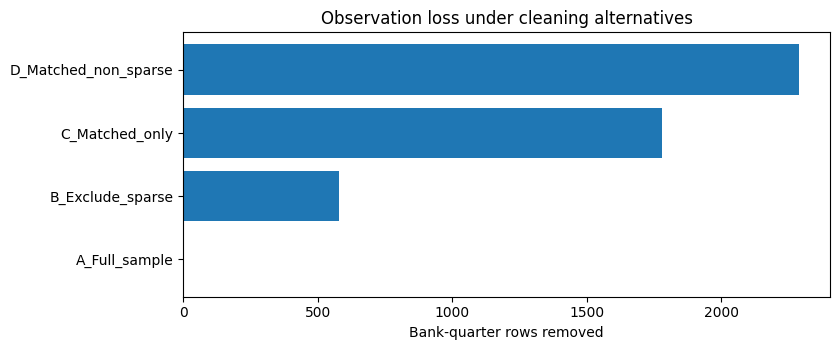

In [69]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8.5,3.6))
plot_df = scenario_comparison.copy()
name_col = "scenario" if "scenario" in plot_df else plot_df.columns[0]
ax.barh(plot_df[name_col].astype(str), plot_df["rows_removed"].astype(int))
ax.set(xlabel="Bank-quarter rows removed", title="Observation loss under cleaning alternatives")
plt.tight_layout(); plt.show()

**Chart reading:** Removing unmatched institutions or complete-case rows can selectively remove risk patterns. The figure is a counterfactual, **not** a removal instruction.

### 2.4.2 — Missing-Value Treatment: Keep, Drop, Fill or Lag?

**Question:** Does imputation retain information or conceal distress-related missingness?

**Method:** Compare no imputation, complete-case deletion, median filling and strictly backward-looking lag filling. Check whether filled ROE values could hide negative equity.

**Decision rule:** Keep source NULLs in Silver; fit any modeling imputer on training data only. Do not treat structurally unavailable fields as missing at random.

#### 2.4.2 · Block 1/3 — Identify missingness groups

In [70]:
# 2.4.2 — Compare Missing-Value Treatment Methods

missing_audit = anomaly_register[
    [
        "CERT", "REPDTE", "severe",
        "negative_equity", "equity_onset"
    ] + core_fields
].copy()

missing_audit["REPDTE"] = pd.to_datetime(
    missing_audit["REPDTE"]
)

missing_audit = missing_audit.sort_values(
    ["CERT", "REPDTE"]
).reset_index(drop=True)

# 1. Identify missingness groups
missing_audit["core_complete"] = (
    missing_audit[core_fields].notna().all(axis=1)
)

missing_audit["non_sparse_roe_missing"] = (
    ~missing_audit["severe"]
    & missing_audit["ROE"].isna()
)

# 2. Construct strictly backward-looking lag availability
missing_audit["quarter_index"] = (
    missing_audit["REPDTE"].dt.year * 4
    + missing_audit["REPDTE"].dt.quarter
)

bank_group = missing_audit.groupby("CERT")

missing_audit["previous_quarter_index"] = (
    bank_group["quarter_index"].shift()
)

missing_audit["previous_ROE"] = (
    bank_group["ROE"].shift()
)

missing_audit["previous_EQ"] = (
    bank_group["EQ"].shift()
)

missing_audit["consecutive_pair"] = (
    missing_audit["quarter_index"]
    - missing_audit["previous_quarter_index"]
    == 1
)

missing_audit["lag_roe_available"] = (
    missing_audit["non_sparse_roe_missing"]
    & missing_audit["consecutive_pair"]
    & missing_audit["previous_ROE"].notna()
)

# 3. Summarize missingness mechanisms
print("MISSING ROE — FINANCIAL CONTEXT")

missing_context = pd.DataFrame([
    {
        "group": "Persistent sparse reporting",
        "missing_roe_rows": int(missing_audit["severe"].sum()),
        "negative_equity_rows": 0,
        "equity_unavailable_rows": int(
            missing_audit["severe"].sum()
        )
    },
    {
        "group": "Non-sparse, negative equity",
        "missing_roe_rows": int((
            missing_audit["non_sparse_roe_missing"]
            & missing_audit["negative_equity"]
        ).sum()),
        "negative_equity_rows": int((
            missing_audit["non_sparse_roe_missing"]
            & missing_audit["negative_equity"]
        ).sum()),
        "equity_unavailable_rows": 0
    },
    {
        "group": "Non-sparse, nonnegative equity",
        "missing_roe_rows": int((
            missing_audit["non_sparse_roe_missing"]
            & ~missing_audit["negative_equity"]
        ).sum()),
        "negative_equity_rows": 0,
        "equity_unavailable_rows": 0
    }
])

display(missing_context)

# 4. Hypothetical treatment policies
# No financial values are actually imputed.

keep_all = pd.Series(True, index=missing_audit.index)
fill_none = pd.Series(False, index=missing_audit.index)

methods = {
    "A_Preserve_missing": (
        keep_all,
        fill_none
    ),
    "B_Complete_case": (
        missing_audit["core_complete"],
        fill_none
    ),
    "C_Training_median_ROE": (
        keep_all,
        missing_audit["non_sparse_roe_missing"]
    ),
    "D_Previous_quarter_ROE": (
        keep_all,
        missing_audit["lag_roe_available"]
    )
}

MISSING ROE — FINANCIAL CONTEXT


,group,missing_roe_rows,negative_equity_rows,equity_unavailable_rows
0,Persistent sparse reporting,578,0,578
1,"Non-sparse, negative equity",123,123,0
2,"Non-sparse, nonnegative equity",16,0,0


#### 2.4.2 · Block 2/3 — Quantify retention and potential signal distortion

In [71]:
# 5. Quantify retention and potential signal distortion
method_results = []

for method, (keep, would_fill) in methods.items():

    retained = missing_audit.loc[keep]
    filled = would_fill & keep

    complete_after = (
        missing_audit["core_complete"] | filled
    ) & keep

    remaining_roe_missing = (
        missing_audit["ROE"].isna()
        & keep
        & ~filled
    )

    method_results.append({
        "method": method,
        "rows_retained": int(keep.sum()),
        "rows_removed": int((~keep).sum()),
        "core_complete_after": int(complete_after.sum()),
        "remaining_missing_roe": int(
            remaining_roe_missing.sum()
        ),
        "hypothetical_roe_fills": int(filled.sum()),
        "negative_equity_retained": int(
            retained["negative_equity"].sum()
        ),
        "equity_onsets_retained": int(
            retained["equity_onset"].sum()
        ),
        "negative_equity_values_filled": int((
            filled & missing_audit["negative_equity"]
        ).sum()),
        "equity_onsets_values_filled": int((
            filled & missing_audit["equity_onset"]
        ).sum())
    })

method_comparison = pd.DataFrame(method_results)

method_comparison["core_complete_pct"] = (
    100
    * method_comparison["core_complete_after"]
    / method_comparison["rows_retained"].replace(0, np.nan)
)

print("\nMISSING-VALUE METHOD COMPARISON")

display(method_comparison.round(3))

# 6. Assess whether historical ROE could be misleading
lag_candidates = missing_audit.loc[
    missing_audit["lag_roe_available"]
].copy()

lag_risk_summary = pd.DataFrame([{
    "lag_fill_candidates": len(lag_candidates),
    "candidates_with_negative_equity": int(
        lag_candidates["negative_equity"].sum()
    ),
    "candidates_with_positive_previous_ROE": int(
        lag_candidates["previous_ROE"].gt(0).sum()
    ),
    "negative_equity_with_positive_previous_ROE": int((
        lag_candidates["negative_equity"]
        & lag_candidates["previous_ROE"].gt(0)
    ).sum()),
    "previous_ROE_abs_above_100": int(
        lag_candidates["previous_ROE"].abs().gt(100).sum()
    )
}])

print("\nPREVIOUS-QUARTER IMPUTATION RISK")
display(lag_risk_summary)

print("\nSAMPLE — PREVIOUS-QUARTER ROE CANDIDATES")

display(
    lag_candidates[
        [
            "CERT", "REPDTE",
            "previous_EQ", "EQ",
            "previous_ROE", "ROE",
            "negative_equity", "equity_onset"
        ]
    ].head(20).round(3)
)


MISSING-VALUE METHOD COMPARISON


,method,rows_retained,rows_removed,core_complete_after,remaining_missing_roe,hypothetical_roe_fills,negative_equity_retained,equity_onsets_retained,negative_equity_values_filled,equity_onsets_values_filled,core_complete_pct
0,A_Preserve_missing,172924,0,172207,717,0,207,63,0,0,99.585
1,B_Complete_case,172207,717,172207,0,0,84,54,0,0,100.000
2,C_Training_median_ROE,172924,0,172346,578,139,207,63,123,9,99.666
3,D_Previous_quarter_ROE,172924,0,172229,695,22,207,63,19,4,99.598



PREVIOUS-QUARTER IMPUTATION RISK


,lag_fill_candidates,candidates_with_negative_equity,candidates_with_positive_previous_ROE,negative_equity_with_positive_previous_ROE,previous_ROE_abs_above_100
0,22,19,20,17,9



SAMPLE — PREVIOUS-QUARTER ROE CANDIDATES


,CERT,REPDTE,previous_EQ,EQ,previous_ROE,ROE,negative_equity,equity_onset
126,41,2023-03-31,-8395.0,-2095.0,41.83,NaN,True,False
12171,2157,2023-03-31,-1460.0,-1016.0,21.13,NaN,True,False
13282,2359,2023-03-31,-13354.0,-5021.0,62.92,NaN,True,False
15843,3099,2023-03-31,-6171.0,1362.0,33.26,NaN,False,False
16679,3195,2023-03-31,-32000.0,-22067.0,285.19,NaN,True,False
19052,3639,2023-03-31,-2334.0,-3145.0,2.82,NaN,True,False
23142,4199,2023-03-31,-685.0,40.0,61.28,NaN,False,False
30518,5529,2023-03-31,-43814.0,-30908.0,139.09,NaN,True,False
55799,10804,2023-09-30,611.0,-2686.0,247.53,NaN,True,True
62666,12013,2023-03-31,-28593.0,-25057.0,-76.83,NaN,True,False


#### 2.4.2 · Block 3/3 — Validation

In [72]:
# 7. Validation
checks = {
    "Recent observations reconcile":
        len(missing_audit) == recent_n,

    "Missing ROE = 717":
        int(missing_audit["ROE"].isna().sum()) == 717,

    "Structural missingness = 578":
        int(missing_audit["severe"].sum()) == 578,

    "Non-sparse missing ROE = 139":
        int(missing_audit["non_sparse_roe_missing"].sum()) == 139,

    "Negative-equity missing ROE = 123":
        int((
            missing_audit["non_sparse_roe_missing"]
            & missing_audit["negative_equity"]
        ).sum()) == 123,

    "Complete-case count reconciles":
        int(missing_audit["core_complete"].sum()) == 172207,

    "Lag method uses previous consecutive quarter only":
        lag_candidates["consecutive_pair"].all(),

    "No structural observations selected for imputation":
        not (
            missing_audit["severe"]
            & (
                missing_audit["non_sparse_roe_missing"]
                | missing_audit["lag_roe_available"]
            )
        ).any(),


}

# The original-ROE comparison is also verified by key-based joining.
original_check = missing_audit[
    ["CERT", "REPDTE", "ROE"]
].merge(
    anomaly_register[
        ["CERT", "REPDTE", "ROE"]
    ],
    on=["CERT", "REPDTE"],
    how="inner",
    suffixes=("_audit", "_original"),
    validate="one_to_one"
)

checks["Original ROE preserved by key"] = (
    len(original_check) == recent_n
    and original_check["ROE_audit"].equals(original_check["ROE_original"])
)

print("\nMISSING-VALUE COMPARISON VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.4.2: PASS")


MISSING-VALUE COMPARISON VALIDATION
Recent observations reconcile: PASS
Missing ROE = 717: PASS
Structural missingness = 578: PASS
Non-sparse missing ROE = 139: PASS
Negative-equity missing ROE = 123: PASS
Complete-case count reconciles: PASS
Lag method uses previous consecutive quarter only: PASS
No structural observations selected for imputation: PASS
Original ROE preserved by key: PASS

CELL 2.4.2: PASS


### 2.4.2 — Comparative Evaluation of Missing-Value Treatment Methods

**Evidence:** Dropping incomplete ROE observations removes 717 modern rows, including 123 of 207 negative-equity cases; median or last-observation filling can obscure deteriorating capital.

**Decision:** Retain NULLs and contextual flags in Silver; postpone train-only imputation to Phase 4.

**Limit:** Lag filling may incorrectly carry forward stale profitability and requires exact reporting-date availability.

### 2.4.3 — Extreme Values: Clipping Versus Preservation

**Question:** What happens to financial tail information if ROA and ROE are winsorized?

**Method:** Estimate winsorization thresholds on an illustrative training period; compare global clipping, subgroup clipping and monotone ASINH transformation.

**Decision rule:** Keep raw profitability; use transformations only as separately fitted modeling robustness checks. Avoid learning clipping cutoffs from held-out data.

#### 2.4.3 · Block 1/3 — Illustrative temporal split

In [73]:
# 2.4.3 — Compare Financial Outlier Treatment Methods

outlier_audit = anomaly_register[
    [
        "CERT", "REPDTE", "ROA", "ROE",
        "institution_unmatched",
        "negative_equity", "equity_onset"
    ]
].copy()

outlier_audit["REPDTE"] = pd.to_datetime(
    outlier_audit["REPDTE"]
)

outlier_audit["reference_group"] = np.where(
    outlier_audit["institution_unmatched"],
    "Unmatched",
    "Matched"
)

# 1. Illustrative temporal split
cutoff = pd.Timestamp("2023-01-01")

train_mask = outlier_audit["REPDTE"] < cutoff
evaluation_mask = ~train_mask

print("TEMPORAL SPLIT")
print("Training observations:", int(train_mask.sum()))
print("Evaluation observations:", int(evaluation_mask.sum()))
assert train_mask.any(), "Empty training period: cannot fit outlier thresholds."
assert evaluation_mask.any(), "Empty evaluation period: temporal comparison invalid."
assert outlier_audit.loc[train_mask, "REPDTE"].max() < outlier_audit.loc[evaluation_mask, "REPDTE"].min()

# 2. Estimate thresholds strictly from training data
threshold_records = []
scale_records = []

for field in ["ROA", "ROE"]:

    train_values = outlier_audit.loc[
        train_mask, field
    ].dropna()

    assert len(train_values) >= 2, f"Insufficient finite {field} training observations"
    global_lower = train_values.quantile(0.01)
    global_upper = train_values.quantile(0.99)

    # Method B: global winsorization
    outlier_audit[f"{field}_global"] = (
        outlier_audit[field].clip(
            lower=global_lower,
            upper=global_upper
        )
    )

    threshold_records.append({
        "variable": field,
        "group": "Global",
        "n_training": len(train_values),
        "p01": global_lower,
        "p99": global_upper
    })

    # Method C: group-conditional winsorization
    outlier_audit[f"{field}_group"] = outlier_audit[field]

    for group_name in ["Matched", "Unmatched"]:

        group_mask = (
            outlier_audit["reference_group"] == group_name
        )

        group_train = outlier_audit.loc[
            train_mask & group_mask, field
        ].dropna()

        if len(group_train) >= 100:
            lower = group_train.quantile(0.01)
            upper = group_train.quantile(0.99)
        else:
            lower = global_lower
            upper = global_upper

        outlier_audit.loc[
            group_mask, f"{field}_group"
        ] = outlier_audit.loc[
            group_mask, field
        ].clip(lower=lower, upper=upper)

        threshold_records.append({
            "variable": field,
            "group": group_name,
            "n_training": len(group_train),
            "p01": lower,
            "p99": upper
        })

    # Method D: robust signed transformation
    q25 = train_values.quantile(0.25)
    q75 = train_values.quantile(0.75)

    robust_scale = q75 - q25

    if not np.isfinite(robust_scale) or robust_scale <= 0:
        robust_scale = max(
            abs(train_values.median()), 1.0
        )

    outlier_audit[f"{field}_asinh"] = np.arcsinh(
        outlier_audit[field] / robust_scale
    )

    scale_records.append({
        "variable": field,
        "training_iqr_scale": robust_scale,
        "training_median": train_values.median()
    })

print("\nTRAINING-FITTED WINSORIZATION THRESHOLDS")
display(pd.DataFrame(threshold_records).round(3))

print("\nROBUST TRANSFORMATION PARAMETERS")
display(pd.DataFrame(scale_records).round(3))

TEMPORAL SPLIT
Training observations: 126697
Evaluation observations: 46227

TRAINING-FITTED WINSORIZATION THRESHOLDS


,variable,group,n_training,p01,p99
0,ROA,Global,126697,-1.551,7.441
1,ROA,Matched,125453,-1.541,3.997
2,ROA,Unmatched,1244,-2.690,77.622
3,ROE,Global,126288,-12.093,32.920
4,ROE,Matched,125092,-12.141,30.840
5,ROE,Unmatched,1196,-4.351,95.173



ROBUST TRANSFORMATION PARAMETERS


,variable,training_iqr_scale,training_median
0,ROA,0.741,1.015
1,ROE,7.160,9.320


#### 2.4.3 · Block 2/3 — Compare winsorization effects

In [74]:
# 3. Compare winsorization effects
effect_records = []

for field in ["ROA", "ROE"]:

    for method, suffix in [
        ("Global_P01_P99", "global"),
        ("Group_P01_P99", "group")
    ]:

        original = outlier_audit[field]
        adjusted = outlier_audit[f"{field}_{suffix}"]

        changed = (
            original.notna()
            & adjusted.ne(original)
        )

        for period_name, period_mask in [
            ("Full", pd.Series(True, index=outlier_audit.index)),
            ("Evaluation_2023_2025", evaluation_mask)
        ]:

            affected = changed & period_mask

            effect_records.append({
                "variable": field,
                "method": method,
                "period": period_name,
                "valid_rows": int(
                    (original.notna() & period_mask).sum()
                ),
                "clipped_rows": int(affected.sum()),
                "clipped_pct": round(
                    100 * affected.sum()
                    / max(
                        (original.notna() & period_mask).sum(),
                        1
                    ),
                    3
                ),
                "unmatched_rows_clipped": int((
                    affected
                    & outlier_audit["institution_unmatched"]
                ).sum()),
                "negative_equity_rows_clipped": int((
                    affected
                    & outlier_audit["negative_equity"]
                ).sum()),
                "equity_onsets_clipped": int((
                    affected
                    & outlier_audit["equity_onset"]
                ).sum()),
                "max_absolute_adjustment": (
                    (original - adjusted)
                    .abs()
                    .where(period_mask)
                    .max()
                )
            })

outlier_method_comparison = pd.DataFrame(effect_records)

print("\nWINSORIZATION — INFORMATION DISTORTION")

display(outlier_method_comparison.round(3))

# 4. Compare representative extreme cases
selected_cases = (
    (
        (outlier_audit["CERT"] == 33831)
        & (outlier_audit["REPDTE"] == "2022-12-31")
    )
    | (
        (outlier_audit["CERT"] == 33831)
        & (outlier_audit["REPDTE"] == "2025-06-30")
    )
    | (
        (outlier_audit["CERT"] == 20239)
        & (outlier_audit["REPDTE"] == "2023-09-30")
    )
    | (
        (outlier_audit["CERT"] == 41)
        & (outlier_audit["REPDTE"] == "2024-03-31")
    )
)

print("\nREPRESENTATIVE CASES — RAW VS TREATED VALUES")

display(
    outlier_audit.loc[
        selected_cases,
        [
            "CERT", "REPDTE", "reference_group",
            "negative_equity",
            "ROA", "ROA_global", "ROA_group", "ROA_asinh",
            "ROE", "ROE_global", "ROE_group", "ROE_asinh"
        ]
    ].round(3)
)


WINSORIZATION — INFORMATION DISTORTION


,variable,method,period,valid_rows,clipped_rows,clipped_pct,unmatched_rows_clipped,negative_equity_rows_clipped,equity_onsets_clipped,max_absolute_adjustment
0,ROA,Global_P01_P99,Full,172924,3691,2.134,1030,16,5,554.831
1,ROA,Global_P01_P99,Evaluation_2023_2025,46227,1157,2.503,336,13,3,455.629
2,ROA,Group_P01_P99,Full,172924,3781,2.187,70,16,5,558.275
3,ROA,Group_P01_P99,Evaluation_2023_2025,46227,1245,2.693,44,13,3,459.073
4,ROE,Global_P01_P99,Full,172207,4401,2.556,383,49,27,58403.710
5,ROE,Global_P01_P99,Evaluation_2023_2025,45919,1876,4.085,134,18,16,58403.710
6,ROE,Group_P01_P99,Full,172207,4506,2.617,66,50,28,58405.790
7,ROE,Group_P01_P99,Evaluation_2023_2025,45919,1983,4.318,42,18,16,58405.790



REPRESENTATIVE CASES — RAW VS TREATED VALUES


,CERT,REPDTE,reference_group,negative_equity,ROA,ROA_global,ROA_group,ROA_asinh,ROE,ROE_global,ROE_group,ROE_asinh
124890,33831,2022-12-31,Matched,False,562.272,7.441,3.997,7.325,1846.54,32.92,30.84,6.246
137825,20239,2023-09-30,Matched,True,0.749,0.749,0.749,0.889,58436.63,32.92,30.84,9.700
148768,41,2024-03-31,Matched,True,0.730,0.730,0.730,0.871,6767.21,32.92,30.84,7.544
171212,33831,2025-06-30,Matched,False,463.070,7.441,3.997,7.131,1556.22,32.92,30.84,6.075


#### 2.4.3 · Block 3/3 — Validate preservation of missingness and signs

In [75]:
# 5. Validate preservation of missingness and signs
checks = {
    "All rows preserved":
        len(outlier_audit) == recent_n,

    "ROA missingness preserved":
        all(
            outlier_audit["ROA"].isna().equals(
                outlier_audit[f"ROA_{suffix}"].isna()
            )
            for suffix in ["global", "group", "asinh"]
        ),

    "ROE missingness preserved":
        all(
            outlier_audit["ROE"].isna().equals(
                outlier_audit[f"ROE_{suffix}"].isna()
            )
            for suffix in ["global", "group", "asinh"]
        ),

    "ASINH preserves ROA sign":
        (
            np.sign(outlier_audit["ROA"].dropna())
            == np.sign(
                outlier_audit["ROA_asinh"].dropna()
            )
        ).all(),

    "ASINH preserves ROE sign":
        (
            np.sign(outlier_audit["ROE"].dropna())
            == np.sign(
                outlier_audit["ROE_asinh"].dropna()
            )
        ).all(),

    "Training period precedes evaluation":
        outlier_audit.loc[
            train_mask, "REPDTE"
        ].max()
        < outlier_audit.loc[
            evaluation_mask, "REPDTE"
        ].min(),

    "Original extreme ROA unchanged":
        int((anomaly_register["ROA"].abs() > 20).sum())
        == 888,

    "Original extreme ROE unchanged":
        int((anomaly_register["ROE"].abs() > 100).sum())
        == 293
}

print("\nOUTLIER METHOD VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.4.3: PASS")


OUTLIER METHOD VALIDATION
All rows preserved: PASS
ROA missingness preserved: PASS
ROE missingness preserved: PASS
ASINH preserves ROA sign: PASS
ASINH preserves ROE sign: PASS
Training period precedes evaluation: PASS
Original extreme ROA unchanged: PASS
Original extreme ROE unchanged: PASS

CELL 2.4.3: PASS


##### Interpretation 2.4.3 — Financial Outlier Treatment and Information Preservation

**Evidence:** Global winsorization collapses much of the extreme ROA/ROE tail; ASINH keeps rank and distinct values while reducing numerical scale.

**Decision:** Keep the raw profitability variables. Evaluate ASINH and train-fitted clipping as sensitivity, not as Silver cleaning.

**Limit:** The thresholds are exploratory and have not been shown to improve out-of-time failure prediction.

### 2.4.4 — Tail-Information Loss in Distressed Banks

**Question:** Does clipping disproportionately remove negative-equity signals?

**Method:** Count unique tail values remaining under different treatments and compare clipping among negative-equity/onset groups.

**Decision rule:** Prefer preserving economically meaningful tail variation. Quantify any information loss before adopting a model-specific transform.

#### 2.4.4 · Block 1/2 — Compare how many distinct extreme values survive each treatment

In [76]:
# 2.4.4 — Tail Information Loss & Distress-Sensitive Treatment

# 1. Compare how many distinct extreme values survive each treatment
tail_results = []

for field, threshold in [("ROA", 20), ("ROE", 100)]:

    raw = outlier_audit[field]
    extreme_mask = raw.abs() > threshold

    for method, column in [
        ("A_Raw", field),
        ("B_Global_winsor", f"{field}_global"),
        ("C_Group_winsor", f"{field}_group"),
        ("D_ASINH", f"{field}_asinh")
    ]:

        treated = outlier_audit[column]

        tail_results.append({
            "variable": field,
            "method": method,
            "original_extreme_rows": int(extreme_mask.sum()),
            "distinct_extreme_values_after": int(
                treated.loc[extreme_mask].nunique()
            ),
            "distinct_extreme_values_before": int(
                raw.loc[extreme_mask].nunique()
            ),
            "minimum_after": treated.loc[extreme_mask].min(),
            "maximum_after": treated.loc[extreme_mask].max()
        })

tail_resolution = pd.DataFrame(tail_results)

tail_resolution["distinct_values_retained_pct"] = (
    100
    * tail_resolution["distinct_extreme_values_after"]
    / tail_resolution["distinct_extreme_values_before"].replace(0, np.nan)
)

print("EXTREME-TAIL INFORMATION RESOLUTION")

display(tail_resolution.round(3))


# 2. Measure ROE clipping within financially relevant subgroups
roe_valid = outlier_audit["ROE"].notna()

subgroups = {
    "All reported ROE": roe_valid,

    "Negative equity": (
        roe_valid & outlier_audit["negative_equity"]
    ),

    "Negative-equity onset": (
        roe_valid & outlier_audit["equity_onset"]
    ),

    "Reported ROE, without negative equity": (
        roe_valid & ~outlier_audit["negative_equity"]
    )
}

distress_results = []

for group_name, group_mask in subgroups.items():

    for method, column in [
        ("B_Global_winsor", "ROE_global"),
        ("C_Group_winsor", "ROE_group")
    ]:

        clipped = (
            roe_valid
            & outlier_audit["ROE"].ne(outlier_audit[column])
        )

        n_eligible = int(group_mask.sum())
        n_clipped = int((group_mask & clipped).sum())

        distress_results.append({
            "subgroup": group_name,
            "method": method,
            "reported_roe_rows": n_eligible,
            "clipped_rows": n_clipped,
            "clipped_pct": (
                100 * n_clipped / n_eligible
                if n_eligible else np.nan
            )
        })

distress_clipping = pd.DataFrame(distress_results)

print("\nROE CLIPPING BY FINANCIAL CONDITION")

display(distress_clipping.round(3))

EXTREME-TAIL INFORMATION RESOLUTION


,variable,method,original_extreme_rows,distinct_extreme_values_after,distinct_extreme_values_before,minimum_after,maximum_after,distinct_values_retained_pct
0,ROA,A_Raw,888,888,888,-57.784,562.272,100.000
1,ROA,B_Global_winsor,888,2,888,-1.551,7.441,0.225
2,ROA,C_Group_winsor,888,479,888,-2.690,77.622,53.941
3,ROA,D_ASINH,888,888,888,-5.049,7.325,100.000
4,ROE,A_Raw,293,291,291,-3841.550,58436.630,100.000
5,ROE,B_Global_winsor,293,2,291,-12.093,32.920,0.687
6,ROE,C_Group_winsor,293,4,291,-12.141,95.173,1.375
7,ROE,D_ASINH,293,291,291,-6.978,9.700,100.000



ROE CLIPPING BY FINANCIAL CONDITION


,subgroup,method,reported_roe_rows,clipped_rows,clipped_pct
0,All reported ROE,B_Global_winsor,172207,4401,2.556
1,All reported ROE,C_Group_winsor,172207,4506,2.617
2,Negative equity,B_Global_winsor,84,49,58.333
3,Negative equity,C_Group_winsor,84,50,59.524
4,Negative-equity onset,B_Global_winsor,54,27,50.000
5,Negative-equity onset,C_Group_winsor,54,28,51.852
6,"Reported ROE, without negative equity",B_Global_winsor,172123,4352,2.528
7,"Reported ROE, without negative equity",C_Group_winsor,172123,4456,2.589


#### 2.4.4 · Block 2/2 — Examine clipping rates across evaluation years

In [77]:
# 3. Examine clipping rates across evaluation years
evaluation = outlier_audit.loc[
    evaluation_mask
].copy()

assert not evaluation.empty, "No evaluation records for the selected temporal cutoff."
evaluation["year"] = evaluation["REPDTE"].dt.year

annual_results = []

for year, subset in evaluation.groupby("year"):

    for field in ["ROA", "ROE"]:

        valid = subset[field].notna()

        for method, suffix in [
            ("Global_winsor", "global"),
            ("Group_winsor", "group")
        ]:

            changed = (
                valid
                & subset[field].ne(
                    subset[f"{field}_{suffix}"]
                )
            )

            annual_results.append({
                "year": int(year),
                "variable": field,
                "method": method,
                "n_valid": int(valid.sum()),
                "n_clipped": int(changed.sum()),
                "clipped_pct": (
                    100 * changed.sum() / valid.sum()
                    if valid.sum() else np.nan
                )
            })

annual_clipping = pd.DataFrame(annual_results)

print("\nEVALUATION-PERIOD CLIPPING BY YEAR")

display(
    annual_clipping
    .sort_values(["variable", "year", "method"])
    .round(3)
)


# 4. Focus on available ROE during negative-equity events
print("\nDISTRESS SIGNAL COVERAGE")

distress_coverage = pd.DataFrame([{
    "negative_equity_total": int(
        outlier_audit["negative_equity"].sum()
    ),

    "negative_equity_with_ROE": int(
        (
            outlier_audit["negative_equity"]
            & roe_valid
        ).sum()
    ),

    "equity_onsets_total": int(
        outlier_audit["equity_onset"].sum()
    ),

    "equity_onsets_with_ROE": int(
        (
            outlier_audit["equity_onset"]
            & roe_valid
        ).sum()
    )
}])

display(distress_coverage)


# 5. Validate original data and tail comparisons
checks = {
    "Full sample retained":
        len(outlier_audit) == recent_n,

    "Extreme ROA reconciles":
        int((outlier_audit["ROA"].abs() > 20).sum()) == 888,

    "Extreme ROE reconciles":
        int((outlier_audit["ROE"].abs() > 100).sum()) == 293,

    "Negative-equity cases with ROE = 84":
        int((
            outlier_audit["negative_equity"] & roe_valid
        ).sum()) == 84,

    "Equity onsets with ROE = 54":
        int((
            outlier_audit["equity_onset"] & roe_valid
        ).sum()) == 54,

    "ASINH retains distinct extreme ROA values":
        outlier_audit.loc[
            outlier_audit["ROA"].abs() > 20, "ROA"
        ].nunique() == outlier_audit.loc[
            outlier_audit["ROA"].abs() > 20, "ROA_asinh"
        ].nunique(),

    "ASINH retains distinct extreme ROE values":
        outlier_audit.loc[
            outlier_audit["ROE"].abs() > 100, "ROE"
        ].nunique() == outlier_audit.loc[
            outlier_audit["ROE"].abs() > 100, "ROE_asinh"
        ].nunique(),

    "Evaluation rows reconcile":
        int(
            evaluation["year"].value_counts().sum()
        ) == int(evaluation_mask.sum())
}

print("\nTAIL INFORMATION VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.4.4: PASS")


EVALUATION-PERIOD CLIPPING BY YEAR


,year,variable,method,n_valid,n_clipped,clipped_pct
0,2023,ROA,Global_winsor,18798,461,2.452
1,2023,ROA,Group_winsor,18798,525,2.793
4,2024,ROA,Global_winsor,18399,463,2.516
5,2024,ROA,Group_winsor,18399,488,2.652
8,2025,ROA,Global_winsor,9030,233,2.580
9,2025,ROA,Group_winsor,9030,232,2.569
2,2023,ROE,Global_winsor,18661,922,4.941
3,2023,ROE,Group_winsor,18661,1000,5.359
6,2024,ROE,Global_winsor,18282,664,3.632
7,2024,ROE,Group_winsor,18282,686,3.752



DISTRESS SIGNAL COVERAGE


,negative_equity_total,negative_equity_with_ROE,equity_onsets_total,equity_onsets_with_ROE
0,207,84,63,54



TAIL INFORMATION VALIDATION
Full sample retained: PASS
Extreme ROA reconciles: PASS
Extreme ROE reconciles: PASS
Negative-equity cases with ROE = 84: PASS
Equity onsets with ROE = 54: PASS
ASINH retains distinct extreme ROA values: PASS
ASINH retains distinct extreme ROE values: PASS
Evaluation rows reconcile: PASS

CELL 2.4.4: PASS


**Figure — Tail values lost to clipping.** Compare the number of distinct extreme values preserved by each treatment, rather than inferring it from a single winsorized quantile.

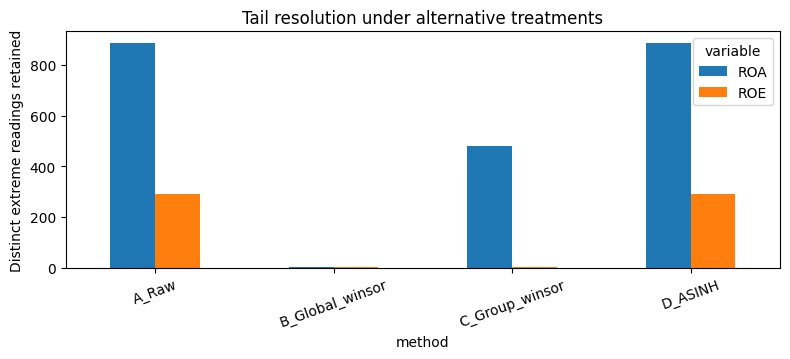

In [78]:
import matplotlib.pyplot as plt
p = tail_resolution.copy()
if {"variable","method","distinct_extreme_values_after"}.issubset(p.columns):
    display_p = p.pivot_table(index="method", columns="variable", values="distinct_extreme_values_after", aggfunc="first")
    ax=display_p.plot(kind="bar",figsize=(8,3.7),rot=20)
    ax.set(ylabel="Distinct extreme readings retained",title="Tail resolution under alternative treatments")
    plt.tight_layout();plt.show()
else:
    print("Review tail_resolution columns:",p.columns.tolist())

**Chart reading:** Compression of many distinct extremes into a few endpoints reduces information; ASINH is a candidate robustness transform, not the Silver default.

##### Interpretation 2.4.4 — Tail Information Loss and Distress-Sensitive Outlier Treatment

**Evidence:** Among negative-equity cases with available ROE, global clipping affects 49 of 84 readings; 27 of 54 negative-equity onsets with ROE are clipped.

**Decision:** Prioritize tail-information preservation and audit subgroup-specific impacts.

**Limit:** This is an information-loss analysis, not a test of predictive performance.

### 2.4.5 — Structural Asset Jumps: Preserve or Delete?

**Question:** Are very large asset changes necessarily erroneous?

**Method:** Compare raw changes, event-quarter removal, event-bank removal and log-ratio transformation. Inspect adjacent balance-sheet components; future quarters are *audit only*.

**Decision rule:** Keep event observations and record non-destructive flags until merger, transfer and institution histories are independently verified.

#### 2.4.5 · Block 1/2 — Prepare previously validated financial-event data

In [79]:
# 2.4.5 — Structural Jump Treatment Comparison

# 1. Prepare previously validated financial-event data
structural = audit[
    [
        "CERT", "REPDTE", "quarter_index",
        "ASSET", "prev_ASSET", "DEP", "EQ",
        "delta_DEP", "delta_EQ",
        "asset_qoq_pct",
        "asset_growth_over_100",
        "asset_contraction_over_50",
        "new_negative_equity",
        "reference_group"
    ]
].sort_values(["CERT", "REPDTE"]).copy()

structural["negative_equity"] = structural["EQ"].lt(0)

structural["structural_event"] = (
    structural["asset_growth_over_100"]
    | structural["asset_contraction_over_50"]
)

structural["event_type"] = np.select(
    [
        structural["asset_growth_over_100"],
        structural["asset_contraction_over_50"]
    ],
    ["Growth >100%", "Contraction <-50%"],
    default="No event"
)

# 2. Method D: non-destructive logarithmic asset change
valid_change = (
    structural["prev_ASSET"].gt(0)
    & structural["asset_qoq_pct"].notna()
)

structural["log_asset_change_pct"] = (
    100 * np.log(
        structural["ASSET"]
        / structural["prev_ASSET"]
    )
).where(valid_change)

# 3. Compare four retention policies
event_banks = set(
    structural.loc[
        structural["structural_event"], "CERT"
    ]
)

policies = {
    "A_Raw_retention":
        pd.Series(True, index=structural.index),

    "B_Drop_event_quarters":
        ~structural["structural_event"],

    "C_Drop_event_banks":
        ~structural["CERT"].isin(event_banks),

    "D_Event_aware_retention":
        pd.Series(True, index=structural.index)
}

baseline_negative = int(structural["negative_equity"].sum())
baseline_onsets = int(structural["new_negative_equity"].sum())

policy_results = []

for method, mask in policies.items():

    sample = structural.loc[mask]

    policy_results.append({
        "method": method,
        "rows_retained": len(sample),
        "rows_removed": len(structural) - len(sample),
        "banks_retained": sample["CERT"].nunique(),
        "banks_removed":
            structural["CERT"].nunique() - sample["CERT"].nunique(),
        "structural_events_retained": int(
            sample["structural_event"].sum()
        ),
        "negative_equity_lost": (
            baseline_negative - int(sample["negative_equity"].sum())
        ),
        "equity_onsets_lost": (
            baseline_onsets
            - int(sample["new_negative_equity"].sum())
        )
    })

structural_policy_comparison = pd.DataFrame(policy_results)

print("STRUCTURAL JUMP — POLICY COMPARISON")
display(structural_policy_comparison)


# 4. Investigate simultaneous changes in funding and capital
event_rows = structural.loc[
    structural["structural_event"]
].copy()

event_rows["deposit_same_direction"] = np.where(
    event_rows["asset_growth_over_100"],
    event_rows["delta_DEP"] > 0,
    event_rows["delta_DEP"] < 0
)

event_rows["equity_same_direction"] = np.where(
    event_rows["asset_growth_over_100"],
    event_rows["delta_EQ"] > 0,
    event_rows["delta_EQ"] < 0
)

print("\nSTRUCTURAL EVENTS — FINANCIAL CO-MOVEMENT")

display(
    event_rows.groupby("event_type").agg(
        n_events=("CERT", "size"),
        n_banks=("CERT", "nunique"),
        deposit_same_direction=(
            "deposit_same_direction", "sum"
        ),
        equity_same_direction=(
            "equity_same_direction", "sum"
        ),
        negative_equity=("negative_equity", "sum"),
        equity_onsets=("new_negative_equity", "sum")
    ).reset_index()
)

STRUCTURAL JUMP — POLICY COMPARISON


,method,rows_retained,rows_removed,banks_retained,banks_removed,structural_events_retained,negative_equity_lost,equity_onsets_lost
0,A_Raw_retention,172924,0,6011,0,178,0,0
1,B_Drop_event_quarters,172746,178,6011,0,0,0,0
2,C_Drop_event_banks,168457,4467,5865,146,0,0,0
3,D_Event_aware_retention,172924,0,6011,0,178,0,0



STRUCTURAL EVENTS — FINANCIAL CO-MOVEMENT


,event_type,n_events,n_banks,deposit_same_direction,equity_same_direction,negative_equity,equity_onsets
0,Contraction <-50%,31,27,23,18,0,0
1,Growth >100%,147,130,137,126,0,0


#### 2.4.5 · Block 2/2 — Check next-quarter persistence — AUDIT ONLY

In [80]:
# 5. Check next-quarter persistence — AUDIT ONLY
# Future-quarter information must NOT become a modeling feature.

bank_group = structural.groupby("CERT")

structural["next_quarter_index"] = (
    bank_group["quarter_index"].shift(-1)
)

structural["next_ASSET"] = (
    bank_group["ASSET"].shift(-1)
)

structural["next_consecutive"] = (
    structural["next_quarter_index"]
    - structural["quarter_index"] == 1
)

structural["next_asset_qoq_pct"] = (
    100 * (
        structural["next_ASSET"]
        / structural["ASSET"] - 1
    )
).where(structural["next_consecutive"])

followup = structural.loc[
    structural["structural_event"]
].copy()

followup["reversal"] = (
    (
        followup["asset_growth_over_100"]
        & followup["next_asset_qoq_pct"].lt(-50)
    )
    | (
        followup["asset_contraction_over_50"]
        & followup["next_asset_qoq_pct"].gt(100)
    )
)

print("\nNEXT-QUARTER EVENT PERSISTENCE — AUDIT ONLY")

display(
    followup.groupby("event_type").agg(
        n_events=("CERT", "size"),
        n_with_next_quarter=("next_consecutive", "sum"),
        median_next_asset_change_pct=(
            "next_asset_qoq_pct", "median"
        ),
        immediate_reversals=("reversal", "sum")
    ).reset_index().round(3)
)


# 6. Compare raw and log asset changes for representative events
print("\nREPRESENTATIVE EXTREME EVENTS — RAW VS LOG CHANGE")

display(
    structural.loc[
        structural["structural_event"]
    ].assign(
        absolute_growth=lambda x: x["asset_qoq_pct"].abs()
    ).nlargest(12, "absolute_growth")[
        [
            "CERT", "REPDTE", "reference_group",
            "prev_ASSET", "ASSET",
            "asset_qoq_pct", "log_asset_change_pct",
            "event_type"
        ]
    ].round(3)
)


# 7. Validation
checks = {
    "All original observations preserved":
        len(structural) == recent_n,

    "Asset growth events reconcile":
        int(structural["asset_growth_over_100"].sum()) == 147,

    "Asset contraction events reconcile":
        int(structural["asset_contraction_over_50"].sum()) == 31,

    "Total structural events reconcile":
        int(structural["structural_event"].sum()) == 178,

    "Negative equity reconciles":
        baseline_negative == 207,

    "Equity onsets reconcile":
        baseline_onsets == 63,

    "Log changes preserve sign":
        (
            np.sign(
                structural.loc[valid_change, "asset_qoq_pct"]
            ).to_numpy()
            ==
            np.sign(
                structural.loc[valid_change, "log_asset_change_pct"]
            ).to_numpy()
        ).all(),

    "Audit-only follow-up uses consecutive quarters":
        structural.loc[
            structural["next_asset_qoq_pct"].notna(),
            "next_consecutive"
        ].all()
}

print("\nSTRUCTURAL TREATMENT VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.4.5: PASS")


NEXT-QUARTER EVENT PERSISTENCE — AUDIT ONLY


,event_type,n_events,n_with_next_quarter,median_next_asset_change_pct,immediate_reversals
0,Contraction <-50%,31,26,-3.789,1
1,Growth >100%,147,144,2.063,5



REPRESENTATIVE EXTREME EVENTS — RAW VS LOG CHANGE


,CERT,REPDTE,reference_group,prev_ASSET,ASSET,asset_qoq_pct,log_asset_change_pct,event_type
26762,33497,2018-03-31,Matched,8378.0,6518825.0,77708.845,665.684,Growth >100%
144427,57083,2023-12-31,Matched,47834.0,6241996.0,12949.287,487.132,Growth >100%
55543,58303,2019-06-30,Matched,24538.0,2422003.0,9770.417,459.213,Growth >100%
110558,34588,2022-03-31,Unmatched,21516.0,1273992.0,5821.138,408.111,Growth >100%
105686,34629,2021-12-31,Unmatched,42779.0,1041787.0,2335.277,319.265,Growth >100%
76632,59043,2020-06-30,Matched,15567.0,294999.0,1795.028,294.182,Growth >100%
54375,33785,2019-06-30,Matched,20652.0,350161.0,1595.531,283.058,Growth >100%
109658,26881,2022-03-31,Matched,174662.0,2038881.0,1067.329,245.730,Growth >100%
122313,1213,2022-12-31,Matched,279387.0,1991593.0,612.844,196.409,Growth >100%
106590,58339,2021-12-31,Unmatched,2514271.0,15083427.0,499.913,179.161,Growth >100%



STRUCTURAL TREATMENT VALIDATION
All original observations preserved: PASS
Asset growth events reconcile: PASS
Asset contraction events reconcile: PASS
Total structural events reconcile: PASS
Negative equity reconciles: PASS
Equity onsets reconcile: PASS
Log changes preserve sign: PASS
Audit-only follow-up uses consecutive quarters: PASS

CELL 2.4.5: PASS


##### Interpretation 2.4.5 — Structural Jump Treatment and Information Preservation

**Evidence:** Event-quarter deletion removes 178 rows; event-bank deletion removes 4,467 rows from 146 banks in the tested comparison.

**Decision:** Keep structural jumps; record review flags and optional log-ratio features.

**Limit:** Large asset changes can involve mergers or transfers; the cause is unverified without institutional history.

### 2.4.6 — Cleaning Decision Register

**Objective:** Consolidate the competing-method evidence into clear Silver-layer rules.

**Decision:** Preserve all original financial values, NULLs and temporal gaps; append traceable flags. No automatic clipping, forward filling or snapshot-based removal.

**Boundary:** Statistical cleaning is not the same as complete financial validity or model preprocessing. Verification of field definitions and institution exits remains open.

#### 2.4.6 · Block 1/2 — Reuse previously evaluated method comparisons

In [81]:
# 2.4.6 — Consolidated Cleaning Policy & Decision Register

# 1. Reuse previously evaluated method comparisons
sample = scenario_comparison.set_index("scenario")
missing = method_comparison.set_index("method")
tail = tail_resolution.set_index(["variable", "method"])
structural_methods = structural_policy_comparison.set_index("method")

# 2. Quantitative evidence across treatment domains
tradeoff_evidence = pd.DataFrame([
    {
        "domain": "Sample restriction",
        "method": "Exclude sparse",
        "rows_removed": int(
            sample.loc["B_Exclude_sparse", "rows_removed"]
        ),
        "key_effect": (
            f"Core completeness: "
            f"{sample.loc['B_Exclude_sparse', 'core_complete_pct']:.3f}%"
        )
    },
    {
        "domain": "Sample restriction",
        "method": "Matched only",
        "rows_removed": int(
            sample.loc["C_Matched_only", "rows_removed"]
        ),
        "key_effect": (
            f"Extreme ROA lost: "
            f"{888 - int(sample.loc['C_Matched_only', 'extreme_roa_retained'])}"
        )
    },
    {
        "domain": "Missingness",
        "method": "Complete-case deletion",
        "rows_removed": int(
            missing.loc["B_Complete_case", "rows_removed"]
        ),
        "key_effect": (
            f"Negative-equity rows lost: "
            f"{207 - int(missing.loc['B_Complete_case', 'negative_equity_retained'])}"
        )
    },
    {
        "domain": "Missingness",
        "method": "Training-median ROE",
        "rows_removed": 0,
        "key_effect": (
            f"Would fill "
            f"{int(missing.loc['C_Training_median_ROE', 'negative_equity_values_filled'])}"
            f" negative-equity ROE values"
        )
    },
    {
        "domain": "Profitability outliers",
        "method": "Global ROE winsorization",
        "rows_removed": 0,
        "key_effect": (
            f"Distinct extreme ROE values: "
            f"{int(tail.loc[('ROE', 'B_Global_winsor'), 'distinct_extreme_values_after'])}"
            f"/291"
        )
    },
    {
        "domain": "Profitability outliers",
        "method": "ASINH ROE",
        "rows_removed": 0,
        "key_effect": (
            f"Distinct extreme ROE values: "
            f"{int(tail.loc[('ROE', 'D_ASINH'), 'distinct_extreme_values_after'])}"
            f"/291"
        )
    },
    {
        "domain": "Structural events",
        "method": "Drop event quarters",
        "rows_removed": int(
            structural_methods.loc[
                "B_Drop_event_quarters", "rows_removed"
            ]
        ),
        "key_effect": "Creates additional panel discontinuities"
    },
    {
        "domain": "Structural events",
        "method": "Drop event banks",
        "rows_removed": int(
            structural_methods.loc[
                "C_Drop_event_banks", "rows_removed"
            ]
        ),
        "key_effect": (
            f"Banks removed: "
            f"{int(structural_methods.loc['C_Drop_event_banks', 'banks_removed'])}"
        )
    }
])

print("CROSS-METHOD INFORMATION TRADEOFFS")
display(tradeoff_evidence)

CROSS-METHOD INFORMATION TRADEOFFS


,domain,method,rows_removed,key_effect
0,Sample restriction,Exclude sparse,578,Core completeness: 99.919%
1,Sample restriction,Matched only,1780,Extreme ROA lost: 512
2,Missingness,Complete-case deletion,717,Negative-equity rows lost: 123
3,Missingness,Training-median ROE,0,Would fill 123 negative-equity ROE values
4,Profitability outliers,Global ROE winsorization,0,Distinct extreme ROE values: 2/291
5,Profitability outliers,ASINH ROE,0,Distinct extreme ROE values: 291/291
6,Structural events,Drop event quarters,178,Creates additional panel discontinuities
7,Structural events,Drop event banks,4467,Banks removed: 146


#### 2.4.6 · Block 2/2 — Provisional policy decisions

In [82]:
# 3. Provisional policy decisions
phase2_policy_register = pd.DataFrame([
    {
        "domain": "Sample selection",
        "baseline": "Preserve full audit panel",
        "alternative": "Exclude sparse banks — sensitivity only",
        "main_risk": "Selection / survivorship bias",
        "pending_validation": "Institution eligibility and failure-label coverage",
        "status": "PROVISIONAL"
    },
    {
        "domain": "Missing values",
        "baseline": "Preserve NaN + missingness indicators",
        "alternative": "Training-fitted imputation — robustness",
        "main_risk": "Loss or distortion of distress information",
        "pending_validation": "Model-specific preprocessing and temporal CV",
        "status": "PROVISIONAL"
    },
    {
        "domain": "ROA / ROE extremes",
        "baseline": "Preserve raw financial ratios",
        "alternative": "ASINH; global winsorization as robustness",
        "main_risk": "Extreme-tail information compression",
        "pending_validation": "Predictive performance and financial consistency",
        "status": "PROVISIONAL"
    },
    {
        "domain": "Structural asset jumps",
        "baseline": "Preserve observations + event flags",
        "alternative": "Log asset growth candidate feature",
        "main_risk": "Structural breaks and artificial panel gaps",
        "pending_validation": "Institution-event verification and lag continuity",
        "status": "PROVISIONAL"
    },
    {
        "domain": "Reference linkage",
        "baseline": "Preserve unmatched CERT identifiers",
        "alternative": "Eligibility-based selection after verification",
        "main_risk": "False nonfailure labels and incomplete coverage",
        "pending_validation": "Reconcile historical institutions and events",
        "status": "UNRESOLVED"
    }
])

print("\nPROVISIONAL PREPROCESSING DECISION REGISTER")
display(phase2_policy_register)


# 4. Summarize baseline data preservation
baseline_integrity = pd.DataFrame([{
    "original_bank_quarters": recent_n,
    "original_banks": anomaly_register["CERT"].nunique(),
    "original_missing_roe": int(
        anomaly_register["ROE"].isna().sum()
    ),
    "original_negative_equity": int(
        anomaly_register["negative_equity"].sum()
    ),
    "original_equity_onsets": int(
        anomaly_register["equity_onset"].sum()
    ),
    "original_extreme_roa": int(
        anomaly_register["extreme_roa"].sum()
    ),
    "original_extreme_roe": int(
        anomaly_register["extreme_roe"].sum()
    )
}])

print("\nORIGINAL DATA — PRESERVATION CHECK")
display(baseline_integrity)


# 5. Cross-method validation
checks = {
    "Original sample retained":
        len(anomaly_register) == 172924,

    "Original bank count retained":
        anomaly_register["CERT"].nunique() == 6011,

    "Complete-case loss reconciles":
        int(missing.loc["B_Complete_case", "rows_removed"]) == 717,

    "Structural-quarter loss reconciles":
        int(structural_methods.loc[
            "B_Drop_event_quarters", "rows_removed"
        ]) == 178,

    "ASINH preserves extreme ROE resolution":
        int(tail.loc[
            ("ROE", "D_ASINH"), "distinct_extreme_values_after"
        ]) == 291,

    "All decisions explicitly provisional or unresolved":
        phase2_policy_register["status"].isin(
            ["PROVISIONAL", "UNRESOLVED"]
        ).all(),

    "Decision domains are unique":
        phase2_policy_register["domain"].is_unique
}

print("\nSECTION 2.4 CONSOLIDATED VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.4.6: PASS")


PROVISIONAL PREPROCESSING DECISION REGISTER


,domain,baseline,alternative,main_risk,pending_validation,status
0,Sample selection,Preserve full audit panel,Exclude sparse banks — sensitivity only,Selection / survivorship bias,Institution eligibility and failure-label cove...,PROVISIONAL
1,Missing values,Preserve NaN + missingness indicators,Training-fitted imputation — robustness,Loss or distortion of distress information,Model-specific preprocessing and temporal CV,PROVISIONAL
2,ROA / ROE extremes,Preserve raw financial ratios,ASINH; global winsorization as robustness,Extreme-tail information compression,Predictive performance and financial consistency,PROVISIONAL
3,Structural asset jumps,Preserve observations + event flags,Log asset growth candidate feature,Structural breaks and artificial panel gaps,Institution-event verification and lag continuity,PROVISIONAL
4,Reference linkage,Preserve unmatched CERT identifiers,Eligibility-based selection after verification,False nonfailure labels and incomplete coverage,Reconcile historical institutions and events,UNRESOLVED



ORIGINAL DATA — PRESERVATION CHECK


,original_bank_quarters,original_banks,original_missing_roe,original_negative_equity,original_equity_onsets,original_extreme_roa,original_extreme_roe
0,172924,6011,717,207,63,888,293



SECTION 2.4 CONSOLIDATED VALIDATION
Original sample retained: PASS
Original bank count retained: PASS
Complete-case loss reconciles: PASS
Structural-quarter loss reconciles: PASS
ASINH preserves extreme ROE resolution: PASS
All decisions explicitly provisional or unresolved: PASS
Decision domains are unique: PASS

CELL 2.4.6: PASS


##### Interpretation 2.4.6 — Consolidated Preprocessing Decisions

**Evidence:** Across method comparisons, deletion, filling and clipping can remove distress-relevant observations or compress tail variation.

**Decision:** Adopt non-destructive Silver: retain original financial values, missingness and genuine historical gaps; add explicit audit flags.

**Limit:** Business validity, merger/other-exit classification and modeling imputation remain separate downstream tasks.

## 2.5 — Build and verify the Silver bank-quarter panel

Keep the full 1984Q1–2026Q2 history and distinguish historical, feature-eligible and outcome-lookahead roles.

### 2.5.1 — Silver Panel Contract and Temporal Scope

**Objective:** Establish the structure, observation boundaries, and validation requirements of the Silver banking panel before performing any transformations or writing output files.

**Method:** Build or verify the non-destructive Silver panel: original fields, reporting flags, consecutive-quarter lags and source-value reconciliation.

**Decision:** Define the Silver panel as an auditable historical dataset, with model-specific observation windows applied explicitly. No data will be deleted, imputed, winsorized, or exported in this preflight step.

#### 2.5.1 · Block 1/2 — Define temporal boundaries

In [83]:
# 2.5.1 — Silver Panel Contract & Temporal Scope

# 1. Define temporal boundaries
FEATURE_START = pd.Timestamp("2017-01-01")
FEATURE_CUTOFF = pd.Timestamp("2025-06-30")
OUTCOME_HORIZON_END = pd.Timestamp("2026-06-30")

SILVER_DIR = ROOT / "data" / "silver"
SILVER_PANEL_PATH = SILVER_DIR / "clean_bank_quarter.parquet"
SILVER_LABEL_PATH = SILVER_DIR / "bank_quarter_labels.parquet"

# 2. Validate source schema
source_schema = financial_lf.collect_schema()
source_columns = source_schema.names()

identifier_fields = ["CERT", "REPDTE", "STNAME"]
expected_fields = identifier_fields + financial_cols

missing_fields = sorted(set(expected_fields) - set(source_columns))
unexpected_fields = sorted(set(source_columns) - set(expected_fields))

print("SILVER SOURCE SCHEMA")
print("Source columns:", len(source_columns))
print("Identifier fields:", len(identifier_fields))
print("Financial fields:", len(financial_cols))
print("Missing expected fields:", missing_fields)
print("Unexpected fields:", unexpected_fields)

# 3. Assign temporal roles without removing observations
silver_source_lf = financial_lf.with_columns(
    pl.when(
        pl.col("REPDTE") < pl.date(2017, 1, 1)
    )
    .then(pl.lit("01_Historical_context"))

    .when(
        pl.col("REPDTE") <= pl.date(2025, 6, 30)
    )
    .then(pl.lit("02_Feature_eligible"))

    .when(
        pl.col("REPDTE") <= pl.date(2026, 6, 30)
    )
    .then(pl.lit("03_Outcome_lookahead"))

    .otherwise(pl.lit("04_Beyond_horizon"))
    .alias("record_role")
)

# 4. Audit each temporal window
silver_scope_audit = (
    silver_source_lf
    .group_by("record_role")
    .agg(
        pl.len().alias("n_rows"),
        pl.col("CERT").n_unique().alias("n_banks"),
        pl.col("REPDTE").n_unique().alias("n_quarters"),
        pl.col("REPDTE").min().alias("first_quarter"),
        pl.col("REPDTE").max().alias("last_quarter"),
        pl.col("EQ").is_null().sum().alias("missing_equity"),
        pl.col("ROE").is_null().sum().alias("missing_roe")
    )
    .collect()
    .to_pandas()
    .sort_values("record_role")
    .reset_index(drop=True)
)

print("\nSILVER TEMPORAL COVERAGE")
display(silver_scope_audit)

# 5. Audit full historical bank-quarter uniqueness
silver_key_audit = (
    financial_lf
    .select(
        pl.len().alias("n_rows"),
        pl.struct(["CERT", "REPDTE"])
        .n_unique().alias("n_unique_keys"),
        pl.col("CERT").n_unique().alias("n_banks"),
        pl.col("REPDTE").min().alias("min_date"),
        pl.col("REPDTE").max().alias("max_date")
    )
    .collect()
    .to_pandas()
)

print("\nFULL HISTORICAL KEY AUDIT")
display(silver_key_audit)

# 6. Establish an explicit construction contract
silver_contract = pd.DataFrame([
    {
        "property": "Primary key",
        "value": "CERT + REPDTE"
    },
    {
        "property": "Financial fields",
        "value": str(len(financial_cols))
    },
    {
        "property": "Feature period",
        "value": "2017Q1–2025Q2"
    },
    {
        "property": "Last feature quarter",
        "value": "2025Q2"
    },
    {
        "property": "Four-quarter horizon end",
        "value": "2026Q2"
    },
    {
        "property": "Original financial values",
        "value": "Preserve without modification"
    },
    {
        "property": "Missingness and extremes",
        "value": "Preserve and flag"
    },
    {
        "property": "Failure labels",
        "value": "Not yet constructed"
    },
    {
        "property": "Silver panel destination",
        "value": str(SILVER_PANEL_PATH)
    }
])

print("\nSILVER CONSTRUCTION CONTRACT")
display(silver_contract)

SILVER SOURCE SCHEMA
Source columns: 136
Identifier fields: 3
Financial fields: 133
Missing expected fields: []
Unexpected fields: []

SILVER TEMPORAL COVERAGE


,record_role,n_rows,n_banks,n_quarters,first_quarter,last_quarter,missing_equity,missing_roe
0,01_Historical_context,1492163,23967,132,1984-03-31,2016-12-31,3502,17952
1,02_Feature_eligible,172924,6011,34,2017-03-31,2025-06-30,578,717
2,03_Outcome_lookahead,17529,4461,4,2025-09-30,2026-06-30,68,74



FULL HISTORICAL KEY AUDIT


,n_rows,n_unique_keys,n_banks,min_date,max_date
0,1682616,1682616,24064,1984-03-31,2026-06-30



SILVER CONSTRUCTION CONTRACT


,property,value
0,Primary key,CERT + REPDTE
1,Financial fields,133
2,Feature period,2017Q1–2025Q2
3,Last feature quarter,2025Q2
4,Four-quarter horizon end,2026Q2
5,Original financial values,Preserve without modification
6,Missingness and extremes,Preserve and flag
7,Failure labels,Not yet constructed
8,Silver panel destination,C:\học tập\kì 7\Big data\Final\Bản nháp\data\s...


#### 2.5.1 · Block 2/2 — Preflight validation

In [84]:
# 7. Preflight validation
feature_rows = int(
    silver_scope_audit.loc[
        silver_scope_audit["record_role"] == "02_Feature_eligible",
        "n_rows"
    ].sum()
)

feature_banks = int(
    silver_scope_audit.loc[
        silver_scope_audit["record_role"] == "02_Feature_eligible",
        "n_banks"
    ].sum()
)

beyond_rows = int(
    silver_scope_audit.loc[
        silver_scope_audit["record_role"] == "04_Beyond_horizon",
        "n_rows"
    ].sum()
)

checks = {
    "Expected 136 source fields":
        len(source_columns) == 136,

    "Source schema matches contract":
        not missing_fields and not unexpected_fields,

    "Full historical rows reconcile":
        int(silver_key_audit["n_rows"].iloc[0]) == n_rows,

    "Unique bank-quarter keys":
        int(silver_key_audit["n_rows"].iloc[0])
        == int(silver_key_audit["n_unique_keys"].iloc[0]),

    "Feature-window observations reconcile":
        feature_rows == recent_n,

    "Feature-window banks reconcile":
        feature_banks == 6011,

    "Temporal windows preserve all rows":
        int(silver_scope_audit["n_rows"].sum()) == n_rows,

    "No observations beyond recorded horizon":
        beyond_rows == 0
}

print("\nSILVER PREFLIGHT VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.5.1: PASS")
print("No Silver files written at this stage.")


SILVER PREFLIGHT VALIDATION
Expected 136 source fields: PASS
Source schema matches contract: PASS
Full historical rows reconcile: PASS
Unique bank-quarter keys: PASS
Feature-window observations reconcile: PASS
Feature-window banks reconcile: PASS
Temporal windows preserve all rows: PASS
No observations beyond recorded horizon: PASS

CELL 2.5.1: PASS
No Silver files written at this stage.


##### Interpretation 2.5.1 — Silver Panel Contract and Temporal Scope

**Method:** The 43 source Parquet files were audited for schema consistency, bank-quarter uniqueness, financial-field coverage, and temporal separation between historical observations, eligible predictors, and future outcome verification.

**Key Findings**

- **Integrity confirmed:** All 1,682,616 observations have unique bank-quarter keys, with 136 expected fields and no schema discrepancies.
- **Temporal coverage established:** The panel contains 1,492,163 historical observations, 172,924 feature-eligible observations (2017Q1–2025Q2), and 17,529 subsequent observations through 2026Q2.
- **Information preservation:** The feature period retains 578 missing-equity and 717 missing-ROE observations. Future-period financial data remains strictly separated from predictor construction.

**Decision:** Proceed with an auditable Silver panel that preserves original financial values, missingness, and institutional histories. Construct only contemporaneous or backward-looking financial indicators; reserve future information for outcome verification. The previously identified source-provenance mismatch remains unresolved.

### 2.5.2 — Reporting Quality Flags and Time-Safe Financial Indicators

**Objective:** Construct transparent reporting-quality indicators and backward-looking financial variables while preserving the original Silver financial data.

**Method:** Build or verify the non-destructive Silver panel: original fields, reporting flags, consecutive-quarter lags and source-value reconciliation.

**Decision:** Retain original financial fields and append separately named audit indicators and candidate features. No imputation, clipping, exclusion, failure labeling, or Silver-file export is performed in this step.

#### 2.5.2 · Block 1/3 — Work from the full historical panel.

In [85]:
# 2.5.2 — Reporting Quality & Time-Safe Financial Indicators

# 1. Work from the full historical panel.
# Do NOT filter to 2017Q1 before creating lagged variables.

silver_flags_lf = (
    silver_source_lf
    .sort(["CERT", "REPDTE"])
    .with_columns([
        pl.sum_horizontal([
            pl.col(c).is_null().cast(pl.Int16)
            for c in financial_cols
        ]).alias("audit_missing_financial_count"),

        pl.col("REPDTE").dt.year().mul(4)
        .add(pl.col("REPDTE").dt.quarter())
        .alias("_quarter_index"),

        pl.col("REPDTE").shift(1).over("CERT")
        .alias("_prev_date"),

        pl.col("ASSET").shift(1).over("CERT")
        .alias("_prev_asset"),

        pl.col("EQ").shift(1).over("CERT")
        .alias("_prev_equity")
    ])
)

# 2. Determine whether the previous observation is the
# immediately preceding calendar quarter.

silver_flags_lf = silver_flags_lf.with_columns([
    (
        pl.col("_quarter_index")
        - (
            pl.col("_prev_date").dt.year() * 4
            + pl.col("_prev_date").dt.quarter()
        )
        == 1
    )
    .fill_null(False)
    .alias("_consecutive_previous"),

    pl.col("EQ").is_null().alias("audit_missing_eq"),
    pl.col("ROE").is_null().alias("audit_missing_roe"),
    pl.col("RBC1AAJ").eq(0).alias("audit_rbc_zero"),

    (
        (pl.col("record_role") == "02_Feature_eligible")
        & pl.col("CERT").is_in(unmatched_ids)
    ).alias("audit_unmatched_modern_reference"),

    pl.col("EQ").lt(0).fill_null(False)
    .alias("feat_negative_equity"),

    pl.sum_horizontal([
        pl.col(c).is_null().cast(pl.Int8)
        for c in core_fields
    ]).alias("audit_missing_core_count")
])

# 3. Row-level sparse reporting: current-quarter data only.
# The severe-reporting flag is an audit indicator.

silver_flags_lf = silver_flags_lf.with_columns([
    (
        pl.col("audit_missing_financial_count")
        > len(financial_cols) / 2
    ).alias("audit_sparse_current"),

    (
        pl.col("_consecutive_previous")
        & pl.col("_prev_asset").gt(0)
    )
    .fill_null(False)
    .alias("_valid_asset_lag")
])

# 4. Backward-looking financial changes
silver_flags_lf = silver_flags_lf.with_columns([
    pl.when(pl.col("_valid_asset_lag"))
    .then(
        100 * (
            pl.col("ASSET") / pl.col("_prev_asset") - 1
        )
    )
    .otherwise(None)
    .alias("feat_asset_qoq_pct"),

    pl.when(pl.col("_valid_asset_lag"))
    .then(
        100 * (
            (pl.col("EQ") - pl.col("_prev_equity"))
            / pl.col("_prev_asset")
        )
    )
    .otherwise(None)
    .alias("feat_equity_change_prev_assets_pct"),

    (
        pl.col("_consecutive_previous")
        & pl.col("_prev_equity").ge(0)
        & pl.col("EQ").lt(0)
    )
    .fill_null(False)
    .alias("feat_negative_equity_onset")
])

# 5. Non-destructive structural-event indicators
silver_flags_lf = silver_flags_lf.with_columns([
    pl.col("feat_asset_qoq_pct").gt(100)
    .fill_null(False)
    .alias("feat_asset_growth_gt100"),

    pl.col("feat_asset_qoq_pct").lt(-50)
    .fill_null(False)
    .alias("feat_asset_contraction_gt50"),

    pl.when(
        pl.col("_valid_asset_lag")
        & pl.col("ASSET").gt(0)
    )
    .then(
        100 * (
            pl.col("ASSET") / pl.col("_prev_asset")
        ).log()
    )
    .otherwise(None)
    .alias("feat_log_asset_growth_pct"),

    (
        pl.col("audit_sparse_current")
        & pl.col("audit_rbc_zero")
    )
    .alias("audit_possible_rbc_placeholder")
])

#### 2.5.2 · Block 2/3 — Summarize indicators by temporal role

In [86]:

# ============================================================
# SILVER INDICATORS — OPTIMIZED TEMPORAL AUDIT
# Preserve original outputs and calculations
# ============================================================

import polars as pl
import pandas as pd
from IPython.display import display

# 1. Query A: overall temporal-role indicators
audit_query = (
    silver_flags_lf
    .group_by("record_role")
    .agg([
        pl.len().alias("n_rows"),
        pl.col("CERT").n_unique().alias("n_banks"),
        pl.col("audit_sparse_current").sum().alias("sparse_rows"),
        pl.col("audit_missing_eq").sum().alias("missing_eq"),
        pl.col("audit_missing_roe").sum().alias("missing_roe"),
        pl.col("audit_unmatched_modern_reference")
        .sum().alias("unmatched_rows"),
        pl.col("audit_possible_rbc_placeholder")
        .sum().alias("possible_rbc_placeholders"),
        pl.col("feat_negative_equity").sum().alias("negative_eq"),
        pl.col("feat_negative_equity_onset").sum().alias("equity_onsets"),
        pl.col("feat_asset_growth_gt100").sum().alias("asset_growth_events"),
        pl.col("feat_asset_contraction_gt50")
        .sum().alias("asset_contraction_events")
    ])
)

# 2. Query B: 2017Q2–2025Q2 reconciliation
modern_query = (
    silver_flags_lf
    .filter(
        (pl.col("REPDTE") >= pl.date(2017, 6, 30))
        & (pl.col("REPDTE") <= pl.date(2025, 6, 30))
    )
    .select([
        pl.col("feat_negative_equity_onset")
        .sum().alias("equity_onsets"),
        pl.col("feat_asset_growth_gt100")
        .sum().alias("asset_growth_events"),
        pl.col("feat_asset_contraction_gt50")
        .sum().alias("asset_contraction_events")
    ])
)

# 3. Execute both queries together
audit_result, modern_result = pl.collect_all(
    [audit_query, modern_query]
)

silver_flag_audit = (
    audit_result
    .to_pandas()
    .sort_values("record_role")
    .reset_index(drop=True)
)

modern_from_q2 = modern_result.to_pandas().iloc[0]

# ============================================================
# OUTPUT 1 — TEMPORAL AUDIT
# ============================================================

print("SILVER INDICATORS — TEMPORAL AUDIT")
display(silver_flag_audit)

# ============================================================
# OUTPUT 2 — MODERN FEATURE WINDOW
# ============================================================

modern_rows = silver_flag_audit.loc[
    silver_flag_audit["record_role"] == "02_Feature_eligible"
]

if modern_rows.empty:
    raise ValueError(
        "No record_role='02_Feature_eligible' found"
    )

modern = modern_rows.iloc[0]

print("\nMODERN FEATURE WINDOW — INDICATOR SUMMARY")
display(modern_rows)

# ============================================================
# OUTPUT 3 — HISTORICAL RECONCILIATION
# ============================================================

previous_diagnostics = jump_audit.loc[
    jump_audit["REPDTE"] >= pd.Timestamp("2017-06-30")
]

continuity_comparison = pd.DataFrame([
    {
        "indicator": "Equity onsets",
        "previous_diagnostic": int(
            previous_diagnostics["new_negative_equity"].sum()
        ),
        "silver_result": int(modern_from_q2["equity_onsets"])
    },
    {
        "indicator": "Asset growth >100%",
        "previous_diagnostic": int(
            previous_diagnostics["asset_qoq_pct"].gt(100).sum()
        ),
        "silver_result": int(
            modern_from_q2["asset_growth_events"]
        )
    },
    {
        "indicator": "Asset contraction >50%",
        "previous_diagnostic": int(
            previous_diagnostics["asset_qoq_pct"].lt(-50).sum()
        ),
        "silver_result": int(
            modern_from_q2["asset_contraction_events"]
        )
    }
])

continuity_comparison["match"] = (
    continuity_comparison["previous_diagnostic"]
    == continuity_comparison["silver_result"]
)

print("\nTIME-SAFE INDICATORS — HISTORICAL RECONCILIATION")
display(continuity_comparison)

print("\nOptimization: queries executed together.")


SILVER INDICATORS — TEMPORAL AUDIT


,record_role,n_rows,n_banks,sparse_rows,missing_eq,missing_roe,unmatched_rows,possible_rbc_placeholders,negative_eq,equity_onsets,asset_growth_events,asset_contraction_events
0,01_Historical_context,1492163,23967,79275,3502,17952,0,78730,15446,2145,3185,754
1,02_Feature_eligible,172924,6011,578,578,717,1780,578,207,63,150,32
2,03_Outcome_lookahead,17529,4461,68,68,74,0,68,6,1,11,1



MODERN FEATURE WINDOW — INDICATOR SUMMARY


,record_role,n_rows,n_banks,sparse_rows,missing_eq,missing_roe,unmatched_rows,possible_rbc_placeholders,negative_eq,equity_onsets,asset_growth_events,asset_contraction_events
1,02_Feature_eligible,172924,6011,578,578,717,1780,578,207,63,150,32



TIME-SAFE INDICATORS — HISTORICAL RECONCILIATION


,indicator,previous_diagnostic,silver_result,match
0,Equity onsets,63,63,True
1,Asset growth >100%,147,147,True
2,Asset contraction >50%,31,31,True



Optimization: queries executed together.


#### 2.5.2 · Block 3/3 — Validation

In [87]:
# 9. Validation
checks = {
    "Historical row count preserved":
        int(silver_flag_audit["n_rows"].sum()) == n_rows,

    "Modern rows preserved":
        int(modern["n_rows"]) == recent_n,

    "Modern equity missing = 578":
        int(modern["missing_eq"]) == 578,

    "Modern ROE missing = 717":
        int(modern["missing_roe"]) == 717,

    "Modern sparse reporting = 578":
        int(modern["sparse_rows"]) == 578,

    "Modern RBC placeholder overlap = 578":
        int(modern["possible_rbc_placeholders"]) == 578,

    "Modern unmatched observations = 1780":
        int(modern["unmatched_rows"]) == 1780,

    "Modern negative equity = 207":
        int(modern["negative_eq"]) == 207,

    "Consecutive-quarter indicators reconcile":
        continuity_comparison["match"].all()
}

print("\nSILVER INDICATOR VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.5.2: PASS")
print("Original financial fields preserved.")
print("No Silver files written.")


SILVER INDICATOR VALIDATION
Historical row count preserved: PASS
Modern rows preserved: PASS
Modern equity missing = 578: PASS
Modern ROE missing = 717: PASS
Modern sparse reporting = 578: PASS
Modern RBC placeholder overlap = 578: PASS
Modern unmatched observations = 1780: PASS
Modern negative equity = 207: PASS
Consecutive-quarter indicators reconcile: PASS

CELL 2.5.2: PASS
Original financial fields preserved.
No Silver files written.


##### Interpretation 2.5.2 — Reporting Indicators and Time-Safe Financial Features

**Method:** Reporting-quality flags and financial-change indicators were constructed across the full historical panel. Lagged features use only consecutive observations from the same institution, with the modern feature window evaluated separately.

**Key Findings**

- **Historical continuity:** The modern window contains 150 asset-growth events above 100% and 32 contractions above 50%, compared with 147 and 31 in earlier diagnostics. The additional events are consistent with incorporating the 2016Q4 reporting boundary; all indicators reconcile exactly for 2017Q2–2025Q2.
- **Data preservation:** All 172,924 modern observations remain intact, including 578 missing-equity records, 717 missing-ROE records, and 207 negative-equity observations.
- **Reporting-regime differences:** Historical severe missingness does not always coincide with zero RBC1AAJ, indicating that reporting patterns should not be generalized across periods without validation.

**Decision:** Retain the backward-looking indicators and original financial values. Validate cross-boundary lag calculations and source-value fidelity before exporting the Silver panel.

### 2.5.3 — Cross-Boundary Lag Validation and Source-Value Fidelity

**Objective**

Verify that historical lag construction is accurate across temporal boundaries and that adding reporting and financial indicators does not alter the original source data.

**Validation Methods**

- **Source-value fidelity:** Compare all 136 original fields between the Phase 1 source and the Silver candidate for selected boundary quarters: 2016Q4, 2017Q1, 2025Q2, 2025Q3, and 2026Q2.
- **Historical lag reconciliation:** Independently reconstruct 2017Q1 asset growth and equity transitions using actual 2016Q4 observations, matching institutions by CERT.
- **Temporal separation:** Verify the assigned roles of boundary observations and ensure that lagged indicators refer only to earlier reporting dates.

**Expected Findings**

The three additional asset-growth events and one additional asset-contraction event observed in Cell 2.5.2 should be attributable to valid 2016Q4–2017Q1 observation pairs.

**Decision Rule**

Silver construction may proceed only if source values remain unchanged, reconstructed boundary indicators reconcile, and all temporal checks pass. No source observations will be modified or exported in this step.

#### 2.5.3 · Block 1/3 — Select representative temporal boundaries

In [88]:
# 2.5.3 — Cross-Boundary Lag & Source-Value Fidelity

# 1. Select representative temporal boundaries
boundary_dates = [
    pd.Timestamp(d).date()
    for d in [
        "2016-12-31",
        "2017-03-31",
        "2025-06-30",
        "2025-09-30",
        "2026-06-30"
    ]
]

source_fields = identifier_fields + financial_cols

diagnostic_fields = [
    "record_role",
    "_prev_date",
    "_prev_asset",
    "_prev_equity",
    "_consecutive_previous",
    "feat_asset_qoq_pct",
    "feat_equity_change_prev_assets_pct",
    "feat_negative_equity_onset",
    "feat_asset_growth_gt100",
    "feat_asset_contraction_gt50"
]

# 2. Collect original and candidate values for the same quarters
source_boundary = (
    financial_lf
    .filter(pl.col("REPDTE").is_in(boundary_dates))
    .select(source_fields)
    .collect()
    .to_pandas()
)

silver_boundary = (
    silver_flags_lf
    .filter(pl.col("REPDTE").is_in(boundary_dates))
    .select(source_fields + diagnostic_fields)
    .collect()
    .to_pandas()
)

for df in [source_boundary, silver_boundary]:
    df["REPDTE"] = pd.to_datetime(df["REPDTE"])

source_boundary = source_boundary.sort_values(
    ["CERT", "REPDTE"]
).reset_index(drop=True)

silver_boundary = silver_boundary.sort_values(
    ["CERT", "REPDTE"]
).reset_index(drop=True)

silver_boundary["_prev_date"] = pd.to_datetime(
    silver_boundary["_prev_date"]
)

# 3. Compare all original fields exactly
key_match = source_boundary[
    ["CERT", "REPDTE"]
].equals(
    silver_boundary[["CERT", "REPDTE"]]
)

field_comparison = pd.DataFrame([
    {
        "field": field,
        "exact_match": source_boundary[field].equals(
            silver_boundary[field]
        )
    }
    for field in source_fields
])

print("ORIGINAL FINANCIAL FIELD FIDELITY")
print("Boundary observations:", len(source_boundary))
print("Original fields checked:", len(source_fields))
print("Bank-quarter keys identical:", key_match)
print("Fields matching exactly:", int(
    field_comparison["exact_match"].sum()
))
print("Fields with discrepancies:", int(
    (~field_comparison["exact_match"]).sum()
))

display(
    field_comparison.loc[
        ~field_comparison["exact_match"]
    ]
)

# 4. Independently reconstruct 2017Q1 changes from 2016Q4
q4_2016 = source_boundary.loc[
    source_boundary["REPDTE"] == "2016-12-31",
    ["CERT", "ASSET", "EQ"]
].rename(columns={
    "ASSET": "asset_2016q4",
    "EQ": "equity_2016q4"
})

q1_2017 = silver_boundary.loc[
    silver_boundary["REPDTE"] == "2017-03-31"
].copy()

q1_2017 = q1_2017.merge(
    q4_2016,
    on="CERT",
    how="left",
    validate="one_to_one",
    indicator="prior_link"
)

q1_2017["has_2016q4"] = (
    q1_2017["prior_link"] == "both"
)

q1_2017["expected_asset_qoq_pct"] = (
    100 * (
        q1_2017["ASSET"] / q1_2017["asset_2016q4"] - 1
    )
).where(
    q1_2017["has_2016q4"]
    & q1_2017["asset_2016q4"].gt(0)
)

q1_2017["expected_growth_gt100"] = (
    q1_2017["expected_asset_qoq_pct"] > 100
)

q1_2017["expected_contraction_gt50"] = (
    q1_2017["expected_asset_qoq_pct"] < -50
)

q1_2017["expected_equity_onset"] = (
    q1_2017["has_2016q4"]
    & q1_2017["equity_2016q4"].ge(0)
    & q1_2017["EQ"].lt(0)
)

ORIGINAL FINANCIAL FIELD FIDELITY
Boundary observations: 25167
Original fields checked: 136
Bank-quarter keys identical: True
Fields matching exactly: 136
Fields with discrepancies: 0


,field,exact_match


#### 2.5.3 · Block 2/3 — Compare independently reconstructed and Silver flags

In [89]:
# 5. Compare independently reconstructed and Silver flags
boundary_reconciliation = pd.DataFrame([
    {
        "indicator": "Asset growth >100%",
        "independent_count": int(
            q1_2017["expected_growth_gt100"].sum()
        ),
        "silver_count": int(
            q1_2017["feat_asset_growth_gt100"].sum()
        )
    },
    {
        "indicator": "Asset contraction >50%",
        "independent_count": int(
            q1_2017["expected_contraction_gt50"].sum()
        ),
        "silver_count": int(
            q1_2017["feat_asset_contraction_gt50"].sum()
        )
    },
    {
        "indicator": "Negative-equity onset",
        "independent_count": int(
            q1_2017["expected_equity_onset"].sum()
        ),
        "silver_count": int(
            q1_2017["feat_negative_equity_onset"].sum()
        )
    }
])

boundary_reconciliation["match"] = (
    boundary_reconciliation["independent_count"]
    == boundary_reconciliation["silver_count"]
)

print("\n2017Q1 — HISTORICAL BOUNDARY RECONCILIATION")
print("2017Q1 observations:", len(q1_2017))
print("Banks with a 2016Q4 observation:", int(
    q1_2017["has_2016q4"].sum()
))

display(boundary_reconciliation)

# 6. Show events newly detectable using 2016Q4 data
boundary_events = q1_2017.loc[
    q1_2017["expected_growth_gt100"]
    | q1_2017["expected_contraction_gt50"]
    | q1_2017["expected_equity_onset"]
].copy()

boundary_events["event_type"] = np.select(
    [
        boundary_events["expected_growth_gt100"],
        boundary_events["expected_contraction_gt50"],
        boundary_events["expected_equity_onset"]
    ],
    [
        "Asset growth >100%",
        "Asset contraction >50%",
        "Negative-equity onset"
    ],
    default="Other"
)

print("\n2017Q1 — ADDITIONAL HISTORICAL-LAG EVENTS")

display(
    boundary_events[
        [
            "CERT", "REPDTE", "event_type",
            "asset_2016q4", "ASSET",
            "expected_asset_qoq_pct",
            "equity_2016q4", "EQ"
        ]
    ].sort_values("CERT").round(3)
)

# 7. Verify temporal roles at selected boundaries
print("\nTEMPORAL ROLE — BOUNDARY OBSERVATIONS")

boundary_role_summary = (
    silver_boundary
    .groupby(["REPDTE", "record_role"])
    .agg(
        n_rows=("CERT", "size"),
        n_banks=("CERT", "nunique")
    )
    .reset_index()
)

display(boundary_role_summary)


2017Q1 — HISTORICAL BOUNDARY RECONCILIATION
2017Q1 observations: 5925
Banks with a 2016Q4 observation: 5923


,indicator,independent_count,silver_count,match
0,Asset growth >100%,3,3,True
1,Asset contraction >50%,1,1,True
2,Negative-equity onset,0,0,True



2017Q1 — ADDITIONAL HISTORICAL-LAG EVENTS


,CERT,REPDTE,event_type,asset_2016q4,ASSET,expected_asset_qoq_pct,equity_2016q4,EQ
849,4705,2017-03-31,Asset growth >100%,791951.0,3093933.0,290.672,137847.0,454396.0
2696,15437,2017-03-31,Asset growth >100%,642654.0,1662201.0,158.646,62921.0,177011.0
4982,34613,2017-03-31,Asset contraction >50%,41378.0,17407.0,-57.932,17825.0,16990.0
5178,35385,2017-03-31,Asset growth >100%,355960.0,2554715.0,617.697,33358.0,254574.0



TEMPORAL ROLE — BOUNDARY OBSERVATIONS


,REPDTE,record_role,n_rows,n_banks
0,2016-12-31,01_Historical_context,5983,5983
1,2017-03-31,02_Feature_eligible,5925,5925
2,2025-06-30,02_Feature_eligible,4494,4494
3,2025-09-30,03_Outcome_lookahead,4452,4452
4,2026-06-30,03_Outcome_lookahead,4313,4313


#### 2.5.3 · Block 3/3 — Validate lag accuracy and forward-looking separation

In [90]:
# 8. Validate lag accuracy and forward-looking separation
valid_q1_lags = q1_2017["has_2016q4"]

asset_lag_match = np.allclose(
    q1_2017.loc[
        valid_q1_lags, "_prev_asset"
    ].to_numpy(dtype=float),
    q1_2017.loc[
        valid_q1_lags, "asset_2016q4"
    ].to_numpy(dtype=float),
    equal_nan=True
)

equity_lag_match = np.allclose(
    q1_2017.loc[
        valid_q1_lags, "_prev_equity"
    ].to_numpy(dtype=float),
    q1_2017.loc[
        valid_q1_lags, "equity_2016q4"
    ].to_numpy(dtype=float),
    equal_nan=True
)

asset_change_match = np.allclose(
    q1_2017["feat_asset_qoq_pct"].to_numpy(dtype=float),
    q1_2017["expected_asset_qoq_pct"].to_numpy(dtype=float),
    equal_nan=True
)

lag_dates_valid = (
    silver_boundary.loc[
        silver_boundary["_prev_date"].notna(),
        "_prev_date"
    ]
    <
    silver_boundary.loc[
        silver_boundary["_prev_date"].notna(),
        "REPDTE"
    ]
).all()

checks = {
    "Boundary observation counts match":
        len(source_boundary) == len(silver_boundary),

    "Bank-quarter keys match":
        key_match,

    "All 136 source fields unchanged":
        field_comparison["exact_match"].all(),

    "2017Q1 prior-quarter linkage matches":
        q1_2017["has_2016q4"].equals(
            q1_2017["_consecutive_previous"]
        ),

    "Previous assets match source":
        asset_lag_match,

    "Previous equity matches source":
        equity_lag_match,

    "Asset changes match independent calculation":
        asset_change_match,

    "2017Q1 event flags reconcile":
        boundary_reconciliation["match"].all(),

    "2017Q1 includes 3 additional growth events":
        int(q1_2017["feat_asset_growth_gt100"].sum()) == 3,

    "2017Q1 includes 1 additional contraction":
        int(q1_2017["feat_asset_contraction_gt50"].sum()) == 1,

    "All selected lags refer to earlier dates":
        lag_dates_valid,

    "2025Q2 belongs to feature window":
        (
            silver_boundary.loc[
                silver_boundary["REPDTE"] == "2025-06-30",
                "record_role"
            ] == "02_Feature_eligible"
        ).all(),

    "2025Q3 belongs to outcome lookahead":
        (
            silver_boundary.loc[
                silver_boundary["REPDTE"] == "2025-09-30",
                "record_role"
            ] == "03_Outcome_lookahead"
        ).all()
}

print("\nSILVER BOUNDARY AND FIDELITY VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.5.3: PASS")
print("No Silver files written.")


SILVER BOUNDARY AND FIDELITY VALIDATION
Boundary observation counts match: PASS
Bank-quarter keys match: PASS
All 136 source fields unchanged: PASS
2017Q1 prior-quarter linkage matches: PASS
Previous assets match source: PASS
Previous equity matches source: PASS
Asset changes match independent calculation: PASS
2017Q1 event flags reconcile: PASS
2017Q1 includes 3 additional growth events: PASS
2017Q1 includes 1 additional contraction: PASS
All selected lags refer to earlier dates: PASS
2025Q2 belongs to feature window: PASS
2025Q3 belongs to outcome lookahead: PASS

CELL 2.5.3: PASS
No Silver files written.


##### Interpretation 2.5.3 — Cross-Boundary Lag Validation and Source Fidelity

**Method:** Independently reconstructed 2017Q1 financial changes using 2016Q4 observations and compared all 136 original source fields across five selected boundary quarters.

**Key Findings**

- **Source fidelity:** All 136 fields match exactly across 25,167 boundary observations, with no key discrepancies.
- **Historical continuity:** Valid 2016Q4 records are available for 5,923 of 5,925 banks in 2017Q1. Cross-boundary calculations identify three additional asset-growth events (>100%) and one contraction event (<−50%), all independently reconciled.
- **Temporal integrity:** Previous-quarter values and event indicators match independent calculations, while feature and outcome-lookahead periods remain correctly separated.

**Decision:** Approve the Silver candidate for provisional Parquet export. Preserve original financial values and maintain an explicit audit trail for unresolved source provenance and future label validation.

### 2.5.4 — Silver Parquet Export and Final Reconciliation

**Objective:** Export the validated Silver banking panel while preserving historical financial observations, original source variables, and independently audited financial indicators.

**Method:** Build or verify the non-destructive Silver panel: original fields, reporting flags, consecutive-quarter lags and source-value reconciliation.

**Decision:** The exported panel remains provisional until unresolved source provenance, institutional eligibility, and failure-label coverage have been validated.

#### 2.5.4 · Block 1/4 — Define permanent Silver fields

In [91]:
# 2.5.4 — Silver Parquet Export & Final Reconciliation

SILVER_DIR.mkdir(parents=True, exist_ok=True)

RECONCILIATION_PATH = SILVER_DIR / "row_reconciliation.csv"
MANIFEST_PATH = SILVER_DIR / "silver_export_manifest.json"

TEMP_SILVER_PATH = SILVER_DIR / "clean_bank_quarter.writing.parquet"

# --------------------------------------------------
# 1. Define permanent Silver fields
# --------------------------------------------------

candidate_schema = silver_flags_lf.collect_schema()
candidate_columns = candidate_schema.names()

indicator_fields = [
    c for c in candidate_columns
    if c.startswith("audit_") or c.startswith("feat_")
]

export_fields = (
    source_fields
    + ["record_role"]
    + indicator_fields
)

assert len(export_fields) == len(set(export_fields))

# Reference matching was assessed only for the modern window.
# Outside that window, null means NOT ASSESSED, not matched.

silver_export_lf = (
    silver_flags_lf
    .with_columns(
        pl.when(
            pl.col("record_role") == "02_Feature_eligible"
        )
        .then(pl.col("audit_unmatched_modern_reference"))
        .otherwise(pl.lit(None, dtype=pl.Boolean))
        .alias("audit_unmatched_modern_reference")
    )
    .select(export_fields)
)

export_schema = silver_export_lf.collect_schema()

source_types_preserved = all(
    source_schema[field] == export_schema[field]
    for field in source_fields
)

print("SILVER EXPORT SCHEMA")
print("Original fields:", len(source_fields))
print("Indicator fields:", len(indicator_fields))
print("Total export columns:", len(export_fields))
print("Original field types preserved:", source_types_preserved)


# --------------------------------------------------
# 2. Write provisional Parquet to a temporary file
# --------------------------------------------------

# Lazy Parquet export avoids materializing the full panel
# as a pandas DataFrame.

silver_export_lf.sink_parquet(
    str(TEMP_SILVER_PATH),
    compression="zstd",
    compression_level=3,
    statistics=True
)

print("\nTEMPORARY SILVER PARQUET WRITTEN")
print(TEMP_SILVER_PATH)


# --------------------------------------------------
# 3. Read back and independently audit the file
# --------------------------------------------------

exported_lf = pl.scan_parquet(str(TEMP_SILVER_PATH))

exported_schema = exported_lf.collect_schema()

export_key_audit = (
    exported_lf
    .select(
        pl.len().alias("n_rows"),
        pl.col("CERT").n_unique().alias("n_banks"),
        pl.col("REPDTE").n_unique().alias("n_quarters"),
        pl.struct(["CERT", "REPDTE"])
        .n_unique().alias("n_unique_keys"),
        pl.col("REPDTE").min().alias("first_date"),
        pl.col("REPDTE").max().alias("last_date")
    )
    .collect()
    .to_pandas()
)

print("\nEXPORTED SILVER — KEY AUDIT")
display(export_key_audit)


# --------------------------------------------------

SILVER EXPORT SCHEMA
Original fields: 136
Indicator fields: 15
Total export columns: 152
Original field types preserved: True

TEMPORARY SILVER PARQUET WRITTEN
C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\clean_bank_quarter.writing.parquet

EXPORTED SILVER — KEY AUDIT


,n_rows,n_banks,n_quarters,n_unique_keys,first_date,last_date
0,1682616,24064,170,1682616,1984-03-31,2026-06-30


#### 2.5.4 · Block 2/4 — Reconcile records by temporal role

In [92]:
# 4. Reconcile records by temporal role
# --------------------------------------------------

export_role_audit = (
    exported_lf
    .group_by("record_role")
    .agg(
        pl.len().alias("export_rows"),
        pl.col("CERT").n_unique().alias("export_banks"),
        pl.col("EQ").is_null().sum().alias("export_missing_eq"),
        pl.col("ROE").is_null().sum().alias("export_missing_roe"),
        pl.col("feat_negative_equity").sum()
        .alias("negative_equity"),
        pl.col("feat_negative_equity_onset").sum()
        .alias("equity_onsets"),
        pl.col("feat_asset_growth_gt100").sum()
        .alias("asset_growth_events"),
        pl.col("feat_asset_contraction_gt50").sum()
        .alias("asset_contraction_events")
    )
    .collect()
    .to_pandas()
)

expected_role_audit = silver_scope_audit[
    [
        "record_role",
        "n_rows",
        "n_banks",
        "missing_equity",
        "missing_roe"
    ]
].rename(columns={
    "n_rows": "source_rows",
    "n_banks": "source_banks",
    "missing_equity": "source_missing_eq",
    "missing_roe": "source_missing_roe"
})

row_reconciliation = expected_role_audit.merge(
    export_role_audit,
    on="record_role",
    how="outer",
    validate="one_to_one"
).sort_values("record_role").reset_index(drop=True)

row_reconciliation["row_difference"] = (
    row_reconciliation["export_rows"]
    - row_reconciliation["source_rows"]
)

row_reconciliation["bank_difference"] = (
    row_reconciliation["export_banks"]
    - row_reconciliation["source_banks"]
)

row_reconciliation["reconciled"] = (
    row_reconciliation["row_difference"].eq(0)
    & row_reconciliation["bank_difference"].eq(0)
    & row_reconciliation["source_missing_eq"].eq(
        row_reconciliation["export_missing_eq"]
    )
    & row_reconciliation["source_missing_roe"].eq(
        row_reconciliation["export_missing_roe"]
    )
)

print("\nSOURCE-TO-SILVER ROW RECONCILIATION")
display(row_reconciliation)


# --------------------------------------------------
# 5. Recheck original source values after export
# --------------------------------------------------

export_boundary = (
    exported_lf
    .filter(pl.col("REPDTE").is_in(boundary_dates))
    .select(source_fields)
    .collect()
    .to_pandas()
)

export_boundary["REPDTE"] = pd.to_datetime(
    export_boundary["REPDTE"]
)

export_boundary = export_boundary.sort_values(
    ["CERT", "REPDTE"]
).reset_index(drop=True)

boundary_keys_match = source_boundary[
    ["CERT", "REPDTE"]
].equals(
    export_boundary[["CERT", "REPDTE"]]
)

boundary_fields_match = all(
    source_boundary[field].equals(export_boundary[field])
    for field in source_fields
)

print("\nEXPORTED ORIGINAL-VALUE FIDELITY")
print("Boundary rows:", len(export_boundary))
print("Keys identical:", boundary_keys_match)
print("All 136 fields identical:", boundary_fields_match)


# --------------------------------------------------


SOURCE-TO-SILVER ROW RECONCILIATION


,record_role,source_rows,source_banks,source_missing_eq,source_missing_roe,export_rows,export_banks,export_missing_eq,export_missing_roe,negative_equity,equity_onsets,asset_growth_events,asset_contraction_events,row_difference,bank_difference,reconciled
0,01_Historical_context,1492163,23967,3502,17952,1492163,23967,3502,17952,15446,2145,3185,754,0,0,True
1,02_Feature_eligible,172924,6011,578,717,172924,6011,578,717,207,63,150,32,0,0,True
2,03_Outcome_lookahead,17529,4461,68,74,17529,4461,68,74,6,1,11,1,0,0,True



EXPORTED ORIGINAL-VALUE FIDELITY
Boundary rows: 25167
Keys identical: True
All 136 fields identical: True


#### 2.5.4 · Block 3/4 — Validate modern-window financial indicators

In [93]:
# 6. Validate modern-window financial indicators
# --------------------------------------------------

modern_export = row_reconciliation.loc[
    row_reconciliation["record_role"]
    == "02_Feature_eligible"
].iloc[0]

checks = {
    "All historical rows exported":
        int(export_key_audit["n_rows"].iloc[0]) == n_rows,

    "All bank-quarter keys unique":
        int(export_key_audit["n_unique_keys"].iloc[0])
        == n_rows,

    "All historical quarters preserved":
        int(export_key_audit["n_quarters"].iloc[0]) == 170,

    "All original source fields included":
        set(source_fields).issubset(
            set(exported_schema.names())
        ),

    "All original field types preserved":
        source_types_preserved,

    "All temporal roles reconcile":
        row_reconciliation["reconciled"].all(),

    "Feature-window rows = 172924":
        int(modern_export["export_rows"]) == 172924,

    "Feature-window missing ROE = 717":
        int(modern_export["export_missing_roe"]) == 717,

    "Feature-window negative equity = 207":
        int(modern_export["negative_equity"]) == 207,

    "Feature-window equity onsets = 63":
        int(modern_export["equity_onsets"]) == 63,

    "Feature-window asset growth events = 150":
        int(modern_export["asset_growth_events"]) == 150,

    "Feature-window asset contractions = 32":
        int(modern_export["asset_contraction_events"]) == 32,

    "Boundary keys unchanged":
        boundary_keys_match,

    "Boundary financial values unchanged":
        boundary_fields_match
}

print("\nSILVER EXPORT VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values()), (
    "Silver verification failed. Temporary file retained "
    "for investigation; final export not promoted."
)


# --------------------------------------------------
# 7. Promote validated temporary file to Silver path
# --------------------------------------------------

TEMP_SILVER_PATH.replace(SILVER_PANEL_PATH)

row_reconciliation.to_csv(
    RECONCILIATION_PATH,
    index=False,
    encoding="utf-8-sig"
)


# --------------------------------------------------
# 8. Compute export SHA-256
# --------------------------------------------------

silver_hasher = hashlib.sha256()

with open(SILVER_PANEL_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        silver_hasher.update(chunk)

silver_sha256 = silver_hasher.hexdigest()


# --------------------------------------------------


SILVER EXPORT VALIDATION
All historical rows exported: PASS
All bank-quarter keys unique: PASS
All historical quarters preserved: PASS
All original source fields included: PASS
All original field types preserved: PASS
All temporal roles reconcile: PASS
Feature-window rows = 172924: PASS
Feature-window missing ROE = 717: PASS
Feature-window negative equity = 207: PASS
Feature-window equity onsets = 63: PASS
Feature-window asset growth events = 150: PASS
Feature-window asset contractions = 32: PASS
Boundary keys unchanged: PASS
Boundary financial values unchanged: PASS


#### 2.5.4 · Block 4/4 — Save a reproducible manifest

In [94]:
# 9. Save a reproducible manifest
# --------------------------------------------------

manifest = {
    "artifact": "FDIC Bank Failure EWS Silver Panel",
    "status": "PROVISIONAL",
    "created_utc": pd.Timestamp.now(tz="UTC").isoformat(),

    "source": {
        "bronze_parquet_files": len(BRONZE_FILES),
        "original_columns": len(source_fields),
        "financial_columns": len(financial_cols),
        "original_values_modified": False
    },

    "silver": {
        "path": str(SILVER_PANEL_PATH),
        "rows": int(export_key_audit["n_rows"].iloc[0]),
        "banks": int(export_key_audit["n_banks"].iloc[0]),
        "quarters": int(export_key_audit["n_quarters"].iloc[0]),
        "columns": len(export_fields),
        "primary_key": ["CERT", "REPDTE"],
        "sha256": silver_sha256,
        "size_bytes": SILVER_PANEL_PATH.stat().st_size
    },

    "methodology": {
        "financial_values": "Preserved",
        "missing_values": "Preserved and flagged",
        "outliers": "Preserved; no winsorization",
        "institution_exclusions": "None",
        "lag_policy": "Consecutive previous quarter only",
        "future_information_in_predictors": False,
        "reference_flag_scope": "2017Q1–2025Q2 only",
        "reference_status_outside_scope": "Null / not assessed",
        "failure_labels": "Not yet constructed"
    },

    "open_issues": [
        "Phase 0 handoff SHA-256 mismatch remains unresolved",
        "Institution eligibility and historical reference coverage",
        "Failure/assistance event classification and label validation",
        "Reporting publication delays before predictive modeling"
    ],

    "validation": {
        "checks_passed": int(sum(checks.values())),
        "checks_total": len(checks),
        "all_passed": bool(all(checks.values())),
        "boundary_rows_checked": len(export_boundary),
        "boundary_source_fields_checked": len(source_fields)
    }
}

MANIFEST_PATH.write_text(
    json.dumps(
        manifest,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


# --------------------------------------------------
# 10. Final export summary
# --------------------------------------------------

print("\nSILVER EXPORT SUMMARY")

print("Parquet:", SILVER_PANEL_PATH)
print("Reconciliation:", RECONCILIATION_PATH)
print("Manifest:", MANIFEST_PATH)

print("\nRows:", manifest["silver"]["rows"])
print("Banks:", manifest["silver"]["banks"])
print("Quarters:", manifest["silver"]["quarters"])
print("Columns:", manifest["silver"]["columns"])

print(
    "File size (MB):",
    round(manifest["silver"]["size_bytes"] / 1024**2, 2)
)

print("SHA-256:", silver_sha256)
print("Status:", manifest["status"])

print("\nCELL 2.5.4: PASS")


SILVER EXPORT SUMMARY
Parquet: C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\clean_bank_quarter.parquet
Reconciliation: C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\row_reconciliation.csv
Manifest: C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\silver_export_manifest.json

Rows: 1682616
Banks: 24064
Quarters: 170
Columns: 152
File size (MB): 363.02
SHA-256: b44d3309dc9f6c7b7f319e7916f56e7a22b942bd65873ed4f1fc873fff4c7974
Status: PROVISIONAL

CELL 2.5.4: PASS


##### Interpretation 2.5.4 — Silver Export and Data Integrity

**Method:** Exported the full historical panel to Parquet and performed source-to-Silver reconciliation, primary-key validation, schema verification, and selected boundary-value comparisons.

**Key Findings**

- **Complete preservation:** All 1,682,616 bank-quarter observations, 24,064 institutions, and 170 reporting quarters were retained, with zero reconciliation differences.
- **Financial integrity:** All 136 original fields retain their source data types, while 15 new audit and financial indicators were added without modifying original values.
- **Distress information retained:** The modern panel preserves 207 negative-equity observations, 63 equity onsets, and all identified structural asset events.

**Decision:** Accept the 152-column Silver panel as a provisional, auditable dataset. The remaining priorities are source-provenance verification, institutional eligibility, and accurate failure-event classification before model-ready labels can be constructed.

### 2.5.5 — Full-Panel Source-to-Silver Value Fidelity (136/136 Original Fields)

**Purpose:** Extend the 2.5.3–2.5.4 boundary-quarter fidelity checks to **all bank-quarter records and all 136 original source fields**, preserving the same key and data-type contracts.
**Check:** Compare Bronze and Silver separately for each reporting year, sorting both by the unique `(CERT, REPDTE)` key. Require exact key equality, original data-type equality, and value equality with corresponding nulls treated as equal. Year-wise processing avoids loading the entire 152-column Silver panel and full Bronze history into RAM simultaneously.
**Readout:** `reports/phase2/full_source_silver_year_audit.csv`, `full_source_silver_column_audit.csv`, and `full_source_silver_fidelity_summary.json`.

**Release Rule:** Fail closed on missing/duplicate/misaligned keys, type mismatches or any source-value mismatch. No Bronze or Silver record is modified.

**Limit:** Value fidelity validates transformation preservation; it is not proof that original FDIC data, disclosure vintages, or historical accounting definitions are accurate.

#### 2.5.5 · Block 1/2 — Compare complete Bronze and Silver values by year

In [95]:
# 2.5.5 — Block 1/2: Full-year Bronze -> Silver source-value fidelity audit
import json
from collections import defaultdict

Q255_DIR = Path(ROOT) / 'reports' / 'phase2'
Q255_DIR.mkdir(parents=True, exist_ok=True)
assert SILVER_PANEL_PATH.exists(), f'Missing Silver file: {SILVER_PANEL_PATH}'

q255_original_cols = list(source_fields)
q255_keys = ['CERT','REPDTE']
q255_bronze_schema = financial_lf.collect_schema()
q255_silver_lf = pl.scan_parquet(str(SILVER_PANEL_PATH))
q255_silver_schema = q255_silver_lf.collect_schema()
assert len(q255_original_cols)==136
assert set(q255_original_cols).issubset(set(q255_silver_schema.names()))
assert all(q255_bronze_schema[c] == q255_silver_schema[c] for c in q255_original_cols), 'Source dtype mismatch'

q255_by_year = defaultdict(list)
for path in BRONZE_FILES:
    q255_by_year[int(path.parent.name.split('=')[1])].append(str(path))

q255_year_results = []
q255_field_results = []
for year, files in sorted(q255_by_year.items()):
    source = (
        pl.scan_parquet(files, hive_partitioning=False)
        .select(q255_original_cols)
        .collect()
        .sort(q255_keys)
    )
    target = (
        q255_silver_lf
        .filter(pl.col('REPDTE').dt.year() == year)
        .select(q255_original_cols)
        .collect()
        .sort(q255_keys)
    )
    source_unique = source.select(pl.struct(q255_keys).n_unique()).item() == source.height
    target_unique = target.select(pl.struct(q255_keys).n_unique()).item() == target.height
    key_match = (
        source.height == target.height
        and source_unique and target_unique
        and all(source[c].equals(target[c], null_equal=True) for c in q255_keys)
    )
    mismatched_fields = 0
    if key_match:
        for c in q255_original_cols:
            match = source[c].equals(target[c], null_equal=True)
            if match:
                difference_count = 0
            else:
                difference_count = (
                    pl.DataFrame({'bronze': source[c], 'silver': target[c]})
                    .select((~pl.col('bronze').eq_missing(pl.col('silver'))).sum())
                    .item()
                )
                mismatched_fields += 1
            q255_field_results.append({'year':year,'field':c,'mismatch_rows':int(difference_count),'status':'PASS' if match else 'FAIL'})
    else:
        for c in q255_original_cols:
            q255_field_results.append({'year':year,'field':c,'mismatch_rows':None,'status':'NOT_CHECKED_KEY_MISMATCH'})
    q255_year_results.append({
        'year':year,'bronze_rows':source.height,'silver_rows':target.height,
        'bronze_keys_unique':source_unique,'silver_keys_unique':target_unique,
        'keys_match':key_match,'mismatched_fields':mismatched_fields,
        'status':'PASS' if key_match and mismatched_fields == 0 else 'FAIL'
    })
    print(f'{year}: {q255_year_results[-1]["status"]} | Bronze {source.height:,} | Silver {target.height:,} | field failures {mismatched_fields}')

q255_year_df = pd.DataFrame(q255_year_results)
q255_field_df = pd.DataFrame(q255_field_results)


1984: PASS | Bronze 71,760 | Silver 71,760 | field failures 0
1985: PASS | Bronze 71,961 | Silver 71,961 | field failures 0
1986: PASS | Bronze 72,182 | Silver 72,182 | field failures 0
1987: PASS | Bronze 70,399 | Silver 70,399 | field failures 0
1988: PASS | Bronze 67,715 | Silver 67,715 | field failures 0
1989: PASS | Bronze 65,397 | Silver 65,397 | field failures 0
1990: PASS | Bronze 62,769 | Silver 62,769 | field failures 0
1991: PASS | Bronze 59,949 | Silver 59,949 | field failures 0
1992: PASS | Bronze 57,025 | Silver 57,025 | field failures 0
1993: PASS | Bronze 54,487 | Silver 54,487 | field failures 0
1994: PASS | Bronze 51,875 | Silver 51,875 | field failures 0
1995: PASS | Bronze 49,108 | Silver 49,108 | field failures 0
1996: PASS | Bronze 46,942 | Silver 46,942 | field failures 0
1997: PASS | Bronze 44,941 | Silver 44,941 | field failures 0
1998: PASS | Bronze 43,079 | Silver 43,079 | field failures 0
1999: PASS | Bronze 41,705 | Silver 41,705 | field failures 0
2000: PA

#### 2.5.5 · Block 2/2 — Save complete reconciliation evidence and enforce release gate

In [96]:
# 2.5.5 — Block 2/2: Summary, evidence export, and release gate
q255_full_silver_rows = q255_silver_lf.select(pl.len()).collect().item()
q255_year_df.to_csv(Q255_DIR / 'full_source_silver_year_audit.csv', index=False)
q255_field_df.to_csv(Q255_DIR / 'full_source_silver_column_audit.csv', index=False)

q255_pass = bool(
    q255_year_df['status'].eq('PASS').all()
    and q255_field_df['status'].eq('PASS').all()
    and q255_year_df['bronze_rows'].sum() == q255_year_df['silver_rows'].sum()
    and q255_year_df['silver_rows'].sum() == q255_full_silver_rows
    and len(q255_year_df)==len(q255_by_year)
)
q255_summary = {
    'audit':'Full source-to-Silver value reconciliation',
    'source':'Bronze annual Parquet',
    'target':str(SILVER_PANEL_PATH),
    'n_years':len(q255_year_df),
    'n_source_columns':len(q255_original_cols),
    'n_bronze_rows':int(q255_year_df['bronze_rows'].sum()),
    'n_silver_rows':int(q255_full_silver_rows),
    'n_field_year_checks':len(q255_field_df),
    'n_failed_field_year_checks':int(q255_field_df['status'].ne('PASS').sum()),
    'status':'PASS' if q255_pass else 'FAIL',
    'meaning':'Value and dtype equality after sorting by unique bank-quarter keys; not binary file equality or historical definition verification.'
}
(Q255_DIR / 'full_source_silver_fidelity_summary.json').write_text(json.dumps(q255_summary,indent=2), encoding='utf-8')
display(q255_year_df)
print(json.dumps(q255_summary,indent=2))
assert q255_pass, 'Full Source-to-Silver fidelity FAILED. Inspect the two audit CSV files before Phase 3.'


,year,bronze_rows,silver_rows,bronze_keys_unique,silver_keys_unique,keys_match,mismatched_fields,status
0,1984,71760,71760,True,True,True,0,PASS
1,1985,71961,71961,True,True,True,0,PASS
2,1986,72182,72182,True,True,True,0,PASS
3,1987,70399,70399,True,True,True,0,PASS
4,1988,67715,67715,True,True,True,0,PASS
5,1989,65397,65397,True,True,True,0,PASS
6,1990,62769,62769,True,True,True,0,PASS
7,1991,59949,59949,True,True,True,0,PASS
8,1992,57025,57025,True,True,True,0,PASS
9,1993,54487,54487,True,True,True,0,PASS


{
  "audit": "Full source-to-Silver value reconciliation",
  "source": "Bronze annual Parquet",
  "target": "C:\\h\u1ecdc t\u1eadp\\k\u00ec 7\\Big data\\Final\\B\u1ea3n nh\u00e1p\\data\\silver\\clean_bank_quarter.parquet",
  "n_years": 43,
  "n_source_columns": 136,
  "n_bronze_rows": 1682616,
  "n_silver_rows": 1682616,
  "n_field_year_checks": 5848,
  "n_failed_field_year_checks": 0,
  "status": "PASS",
  "meaning": "Value and dtype equality after sorting by unique bank-quarter keys; not binary file equality or historical definition verification."
}


##### Interpretation 2.5.5 — Full Source-Value Preservation

**Evidence:** The audit reports a year-by-year and field-by-field reconciliation status for every original source variable.

**Decision:** Proceed to Phase 3 with immutable Silver inputs only if all keys, data types, and values match.

**Limit:** This result concerns technical consistency and does not resolve the documented provenance, field-definition or publication-vintage open issues.

## 2.6 — Event registry, candidate labels and coverage

The FDIC registry contains **FAILURE and ASSISTANCE**. Keep separate the assignment’s quarter-end label and the operational 45-day availability sensitivity.

### 2.6.1 — Failure Registry Profiling and Event Classification

**Objective:** Examine the structure, completeness, and institutional coverage of the FDIC failure/assistance reference dataset before constructing binary bank-failure labels.

**Method:** Classify and link FAILURE/ASSISTANCE events using CERT and dated financial records; audit temporal eligibility, coverage and potential leakage.

**Decision:** No bank-failure labels will be created until eligible failure events have been distinguished from assistance or other resolution events, event dates have been validated, and institutional linkage rules have been established.

#### 2.6.1 · Block 1/2 — Load reference datasets

In [97]:
# 2.6.1 — FDIC Event Registry Profiling

# 1. Load reference datasets
event_df = pl.read_parquet(
    str(reference_files["failures"])
).to_pandas()

institution_schema = pl.scan_parquet(
    str(reference_files["institutions"])
).collect_schema()

print("FDIC REFERENCE DATASETS")
print("Event registry rows:", len(event_df))
print("Event registry columns:", len(event_df.columns))
print("Institution reference fields:", len(institution_schema.names()))

print("\nEVENT REGISTRY COLUMNS")
display(pd.DataFrame({
    "column": event_df.columns,
    "dtype": event_df.dtypes.astype(str).values
}))

# 2. Profile individual fields
field_profile = []

for col in event_df.columns:

    values = event_df[col]

    examples = (
        values.dropna()
        .astype(str)
        .drop_duplicates()
        .head(3)
        .tolist()
    )

    field_profile.append({
        "field": col,
        "dtype": str(values.dtype),
        "missing_rows": int(values.isna().sum()),
        "missing_pct": round(
            100 * values.isna().mean(), 2
        ),
        "unique_values": int(values.nunique(dropna=True)),
        "examples": " | ".join(examples)
    })

registry_field_profile = pd.DataFrame(field_profile)

print("\nEVENT REGISTRY — FIELD PROFILE")
display(registry_field_profile)

# 3. Discover possible event classification columns
event_terms = [
    "TYPE", "EVENT", "ASSIST", "RESOL",
    "ACTION", "STATUS", "TRANSACTION",
    "FAILURE", "CLOSURE"
]

event_type_candidates = [
    col for col in event_df.columns
    if any(term in col.upper() for term in event_terms)
    and "DATE" not in col.upper()
    and not col.upper().endswith("DT")
]

event_type_distributions = []

for col in event_type_candidates:

    n_unique = event_df[col].nunique(dropna=True)

    if n_unique <= 40:

        counts = (
            event_df[col]
            .fillna("<MISSING>")
            .astype(str)
            .value_counts()
            .head(15)
        )

        for value, count in counts.items():
            event_type_distributions.append({
                "field": col,
                "value": value,
                "n_records": int(count)
            })

event_classification_profile = pd.DataFrame(
    event_type_distributions,
    columns=["field", "value", "n_records"]
)

print("\nPOTENTIAL EVENT-TYPE DISTRIBUTIONS")

if event_classification_profile.empty:
    print("No low-cardinality event-type field identified.")
else:
    display(event_classification_profile)

# 4. Examine date fields
date_candidates = [
    col for col in event_df.columns
    if (
        "DATE" in col.upper()
        or col.upper().endswith("DT")
    )
]

date_results = []

for col in date_candidates:

    parsed = pd.to_datetime(
        event_df[col],
        errors="coerce"
    )

    date_results.append({
        "date_field": col,
        "valid_dates": int(parsed.notna().sum()),
        "missing_or_invalid": int(parsed.isna().sum()),
        "earliest_date": parsed.min(),
        "latest_date": parsed.max()
    })

registry_date_profile = pd.DataFrame(
    date_results,
    columns=[
        "date_field", "valid_dates",
        "missing_or_invalid",
        "earliest_date", "latest_date"
    ]
)

print("\nEVENT DATE COVERAGE")
display(registry_date_profile)

FDIC REFERENCE DATASETS
Event registry rows: 4117
Event registry columns: 10
Institution reference fields: 9

EVENT REGISTRY COLUMNS


,column,dtype
0,CERT,object
1,NAME,object
2,CITYST,object
3,FAILDATE,object
4,FAILYR,object
5,COST,object
6,QBFASSET,object
7,QBFDEP,object
8,RESTYPE,object
9,RESTYPE1,object



EVENT REGISTRY — FIELD PROFILE


,field,dtype,missing_rows,missing_pct,unique_values,examples
0,CERT,object,488,11.85,3585,14571.0 | 14987.0 | 13164.0
1,NAME,object,0,0.00,3717,BANK OF AMERICA TRUST CO. | FON DU LAC STATE B...
2,CITYST,object,0,0.00,2423,"PITTSBURGH, PA | EAST PEORIA, IL | LIMA, MT"
3,FAILDATE,object,0,0.00,1874,4/19/1934 | 5/28/1934 | 7/18/1934
4,FAILYR,object,0,0.00,88,1934 | 1935 | 1936
5,COST,object,637,15.47,3395,87.774 | 126.78 | 221.154
6,QBFASSET,object,154,3.74,3888,1435.0 | 374.0 | 91.0
7,QBFDEP,object,2,0.05,3981,1064.0 | 238.0 | 42.0
8,RESTYPE,object,0,0.00,2,FAILURE | ASSISTANCE
9,RESTYPE1,object,0,0.00,11,PO | P&A | A/A



POTENTIAL EVENT-TYPE DISTRIBUTIONS


,field,value,n_records
0,RESTYPE,FAILURE,3524
1,RESTYPE,ASSISTANCE,593
2,RESTYPE1,PA,2107
3,RESTYPE1,A/A,579
4,RESTYPE1,PO,573
5,RESTYPE1,IDT,386
6,RESTYPE1,P&A,251
7,RESTYPE1,PI,143
8,RESTYPE1,MGR,37
9,RESTYPE1,ABT,16



EVENT DATE COVERAGE


,date_field,valid_dates,missing_or_invalid,earliest_date,latest_date
0,FAILDATE,4117,0,1934-04-19,2026-07-17


#### 2.6.1 · Block 2/2 — Normalize CERT for linkage diagnostics only

In [98]:
# 5. Normalize CERT for linkage diagnostics only
assert "CERT" in event_df.columns, (
    "Registry CERT field not found. "
    "Inspect the field profile before mapping identifiers."
)

cert_numeric = pd.to_numeric(
    event_df["CERT"],
    errors="coerce"
)

valid_cert = (
    cert_numeric.notna()
    & np.isfinite(cert_numeric)
    & cert_numeric.gt(0)
    & cert_numeric.eq(np.floor(cert_numeric))
)

event_df["cert_normalized"] = (
    cert_numeric.where(valid_cert).astype("Int64")
)

# 6. Compare event coverage with Silver populations
historical_certs = set(
    pl.scan_parquet(str(SILVER_PANEL_PATH))
    .select("CERT")
    .unique()
    .collect()["CERT"]
    .drop_nulls()
    .to_list()
)

modern_certs = set(
    anomaly_register["CERT"].dropna().astype(int)
)

registry_certs = set(
    event_df["cert_normalized"]
    .dropna()
    .astype(int)
)

historical_overlap = registry_certs & historical_certs
modern_overlap = registry_certs & modern_certs

registry_linkage = pd.DataFrame([{
    "registry_records": len(event_df),
    "records_missing_or_invalid_cert": int(
        (~valid_cert).sum()
    ),
    "records_with_valid_cert": int(valid_cert.sum()),
    "unique_registry_certs": len(registry_certs),
    "unique_historical_silver_certs": len(historical_certs),
    "unique_modern_silver_certs": len(modern_certs),
    "registry_certs_in_historical_panel": len(historical_overlap),
    "registry_certs_in_modern_panel": len(modern_overlap),
    "registry_certs_outside_historical_panel": len(
        registry_certs - historical_certs
    ),
    "repeated_cert_records": int(
        event_df["cert_normalized"].notna().sum()
        - len(registry_certs)
    )
}])

print("\nFAILURE / ASSISTANCE REGISTRY — PANEL LINKAGE")
display(registry_linkage)

# 7. Preview original event records without classification
preview_cols = [
    col for col in event_df.columns
    if col != "cert_normalized"
]

print("\nSAMPLE EVENT RECORDS — UNCLASSIFIED")
display(event_df[preview_cols].head(8))

# 8. Structural validation — no labels generated
checks = {
    "Registry records loaded":
        len(event_df) > 0,

    "CERT field available":
        "CERT" in event_df.columns,

    "Reference schema available":
        len(institution_schema.names()) > 0,

    "Identifier counts reconcile":
        int(valid_cert.sum()) + int((~valid_cert).sum())
        == len(event_df),

    "Registry identifier overlap is valid":
        registry_certs.issuperset(historical_overlap)
        and registry_certs.issuperset(modern_overlap),

    "Historical Silver population reconciles":
        len(historical_certs) == 24064,

    "Modern Silver population reconciles":
        len(modern_certs) == 6011,

    "Event records preserved":
        len(event_df) == 4117
}

print("\nEVENT REGISTRY PREFLIGHT VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.6.1: PASS")
print("No failure labels created.")
print("No event records removed or deduplicated.")


FAILURE / ASSISTANCE REGISTRY — PANEL LINKAGE


,registry_records,records_missing_or_invalid_cert,records_with_valid_cert,unique_registry_certs,unique_historical_silver_certs,unique_modern_silver_certs,registry_certs_in_historical_panel,registry_certs_in_modern_panel,registry_certs_outside_historical_panel,repeated_cert_records
0,4117,488,3629,3585,24064,6011,3241,37,344,44



SAMPLE EVENT RECORDS — UNCLASSIFIED


,CERT,NAME,CITYST,FAILDATE,FAILYR,COST,QBFASSET,QBFDEP,RESTYPE,RESTYPE1
0,None,BANK OF AMERICA TRUST CO.,"PITTSBURGH, PA",4/19/1934,1934,None,1435.0,1064.0,FAILURE,PO
1,None,FON DU LAC STATE BANK,"EAST PEORIA, IL",5/28/1934,1934,None,374.0,238.0,FAILURE,PO
2,None,FIRST NATIONAL BANK OF LIMA,"LIMA, MT",7/18/1934,1934,None,91.0,42.0,FAILURE,PO
3,None,FLORENCE DEPOSIT BANK,"FLORENCE, IN",7/18/1934,1934,None,105.0,69.0,FAILURE,PO
4,None,BANK OF LEWISPORT,"LEWISPORT, KY",8/6/1934,1934,None,81.0,68.0,FAILURE,PO
5,None,FARMERS STATE BANK OF BONGARDS,"BONGARDS, MN",9/13/1934,1934,None,91.0,73.0,FAILURE,PO
6,None,FARMERS & TRADERS BANK,"PORTERFIELD, WI",10/11/1934,1934,None,46.0,32.0,FAILURE,PO
7,None,PICKENS COUNTY BANK,"JASPER, GA",10/13/1934,1934,None,243.0,210.0,FAILURE,PO



EVENT REGISTRY PREFLIGHT VALIDATION
Registry records loaded: PASS
CERT field available: PASS
Reference schema available: PASS
Identifier counts reconcile: PASS
Registry identifier overlap is valid: PASS
Historical Silver population reconciles: PASS
Modern Silver population reconciles: PASS
Event records preserved: PASS

CELL 2.6.1: PASS
No failure labels created.
No event records removed or deduplicated.


##### Interpretation 2.6.1 — Failure Registry Structure and Linkage

**Method:** Profiled 4,117 FDIC failure/assistance records by event classification, date availability, certificate validity, and linkage with the historical and modern financial panels.

**Key Findings**

- **Event classification:** The registry contains 3,524 FAILURE records and 593 ASSISTANCE records. Treating all events as failures would introduce label misclassification.
- **Linkage limitations:** 488 records (11.85%) lack valid CERT identifiers. Although 3,241 unique event identifiers match the historical panel, only 37 overlap the modern financial population; these are not necessarily failures during the study period.
- **Temporal coverage:** Event dates span 1934–2026 and are fully populated, but some events occur beyond the available financial reporting horizon.

**Decision:** Treat RESTYPE = FAILURE as the candidate positive-event definition, retain ASSISTANCE separately, and investigate event timing, repeated identifiers, and pre-failure reporting availability before creating prediction labels.

### 2.6.2 — Failure Event Timing and Historical Linkage Audit

**Objective:** Identify failure events that can potentially support four-quarter-ahead bank-failure prediction, while distinguishing historical events, assistance transactions, duplicate identifiers, and failures without usable pre-event financial observations.

**Method:** Classify and link FAILURE/ASSISTANCE events using CERT and dated financial records; audit temporal eligibility, coverage and potential leakage.

**Decision:** No labels will be generated in this step. Only events with valid failure classification, timing, and institutional linkage will proceed to subsequent eligibility evaluation.

#### 2.6.2 · Block 1/3 — Standardize event dates and categories

In [99]:
# 2.6.2 — Failure Event Timing & Historical Linkage Audit

# 1. Standardize event dates and categories
events_262 = event_df.copy()

events_262["event_date"] = pd.to_datetime(
    events_262["FAILDATE"],
    format="%m/%d/%Y",
    errors="coerce"
)

events_262["event_type"] = (
    events_262["RESTYPE"]
    .astype("string")
    .str.strip()
    .str.upper()
)

events_262["resolution_type"] = (
    events_262["RESTYPE1"]
    .astype("string")
    .str.strip()
    .str.upper()
)

events_262["cert_clean"] = (
    events_262["cert_normalized"].astype("Int64")
)

# 2. Define event timing relative to the Silver panel
events_262["event_period"] = np.select(
    [
        events_262["event_date"] < pd.Timestamp("1984-01-01"),

        events_262["event_date"].between(
            "1984-01-01", "2016-12-31"
        ),

        events_262["event_date"].between(
            "2017-01-01", "2025-06-30"
        ),

        events_262["event_date"].between(
            "2025-07-01", "2026-06-30"
        ),

        events_262["event_date"] > pd.Timestamp("2026-06-30")
    ],
    [
        "00_Pre_1984",
        "01_Historical_1984_2016",
        "02_Feature_period",
        "03_Outcome_lookahead",
        "04_Beyond_horizon"
    ],
    default="INVALID_DATE"
)

events_262["in_historical_panel"] = (
    events_262["cert_clean"].isin(historical_certs)
)

events_262["in_modern_panel"] = (
    events_262["cert_clean"].isin(modern_certs)
)

events_262["modern_matched_cert"] = (
    events_262["cert_clean"].where(
        events_262["in_modern_panel"]
    )
)

# 3. Event type by time period
print("EVENT CLASSIFICATION BY TIME PERIOD")

event_period_table = pd.crosstab(
    events_262["event_period"],
    events_262["event_type"]
)

event_period_table["TOTAL"] = (
    event_period_table.sum(axis=1)
)

display(event_period_table)

# 4. Resolution type comparison
print("\nFAILURE VS ASSISTANCE — RESOLUTION TYPES")

resolution_table = pd.crosstab(
    events_262["event_type"],
    events_262["resolution_type"]
)

display(resolution_table)

# 5. Linkage by event date
period_linkage = (
    events_262
    .groupby("event_period")
    .agg(
        n_events=("NAME", "size"),
        missing_cert=("cert_clean", lambda s: s.isna().sum()),
        valid_cert=("cert_clean", lambda s: s.notna().sum()),
        unique_certs=("cert_clean", "nunique"),
        modern_overlap_records=("in_modern_panel", "sum"),
        modern_overlap_banks=("modern_matched_cert", "nunique")
    )
    .reset_index()
    .sort_values("event_period")
)

print("\nEVENT-DATE LINKAGE COVERAGE")
display(period_linkage)

EVENT CLASSIFICATION BY TIME PERIOD


event_type,ASSISTANCE,FAILURE,TOTAL
event_period,,,
00_Pre_1984,181,661,842
01_Historical_1984_2016,412,2834,3246
02_Feature_period,0,25,25
03_Outcome_lookahead,0,2,2
04_Beyond_horizon,0,2,2



FAILURE VS ASSISTANCE — RESOLUTION TYPES


resolution_type,A/A,ABT,DINB,IDT,MGR,OBAM,P&A,PA,PI,PO,REP
event_type,,,,,,,,,,,
ASSISTANCE,579,0,0,0,0,13,0,0,0,0,1
FAILURE,0,16,9,386,37,0,251,2107,143,573,2



EVENT-DATE LINKAGE COVERAGE


,event_period,n_events,missing_cert,valid_cert,unique_certs,modern_overlap_records,modern_overlap_banks
0,00_Pre_1984,842,488,354,352,1,1
1,01_Historical_1984_2016,3246,0,3246,3211,10,10
2,02_Feature_period,25,0,25,25,22,22
3,03_Outcome_lookahead,2,0,2,2,2,2
4,04_Beyond_horizon,2,0,2,2,2,2


#### 2.6.2 · Block 2/3 — Examine repeated CERT identifiers

In [100]:
# 6. Examine repeated CERT identifiers
repeated_cert_audit = (
    events_262
    .dropna(subset=["cert_clean"])
    .groupby("cert_clean")
    .agg(
        n_records=("NAME", "size"),
        n_event_dates=("event_date", "nunique"),
        n_event_types=("event_type", "nunique"),
        earliest_event=("event_date", "min"),
        latest_event=("event_date", "max")
    )
    .reset_index()
)

repeated_cert_audit = repeated_cert_audit.loc[
    repeated_cert_audit["n_records"] > 1
].sort_values(
    ["n_records", "n_event_dates"],
    ascending=False
)

print("\nREPEATED CERT — EVENT AUDIT")
print("CERTs with multiple records:", len(repeated_cert_audit))
print(
    "CERTs with multiple event dates:",
    int((repeated_cert_audit["n_event_dates"] > 1).sum())
)

display(repeated_cert_audit.head(15))

# 7. Identify FAILURE records overlapping modern population
candidate_failures = events_262.loc[
    events_262["event_type"].eq("FAILURE")
    & events_262["in_modern_panel"]
    & events_262["event_date"].between(
        "2017-01-01", "2026-06-30"
    )
].copy()

# Audit linkage to last strictly earlier quarterly report
modern_reports = recent_core[
    ["CERT", "REPDTE"]
].copy()

modern_reports["CERT"] = pd.to_numeric(
    modern_reports["CERT"]
).astype("int64")

modern_reports["REPDTE"] = pd.to_datetime(
    modern_reports["REPDTE"]
)

modern_reports = modern_reports.rename(
    columns={"CERT": "cert_int"}
).sort_values(
    ["REPDTE", "cert_int"]
).reset_index(drop=True)

candidate_failures["cert_int"] = (
    candidate_failures["cert_clean"].astype("int64")
)

candidate_failures = candidate_failures.sort_values(
    ["event_date", "cert_int"]
).reset_index(drop=True)

candidate_failures["event_date"] = (
    pd.to_datetime(candidate_failures["event_date"])
    .astype("datetime64[ns]")
)

modern_reports["REPDTE"] = (
    pd.to_datetime(modern_reports["REPDTE"])
    .astype("datetime64[ns]")
)

# Ensure both CERT keys use the same integer dtype
candidate_failures["cert_int"] = (
    candidate_failures["cert_int"].astype("int64")
)

modern_reports["cert_int"] = (
    modern_reports["cert_int"].astype("int64")
)

# merge_asof requires sorting primarily by date
candidate_failures = candidate_failures.sort_values(
    ["event_date", "cert_int"]
).reset_index(drop=True)

modern_reports = modern_reports.sort_values(
    ["REPDTE", "cert_int"]
).reset_index(drop=True)

# Link each failure to its latest strictly earlier report
failure_report_linkage = pd.merge_asof(
    candidate_failures,
    modern_reports,
    by="cert_int",
    left_on="event_date",
    right_on="REPDTE",
    direction="backward",
    allow_exact_matches=False
)

print("MERGE_ASOF: PASS")
print("Failure records:", len(failure_report_linkage))
print(
    "Events with prior reports:",
    failure_report_linkage["REPDTE"].notna().sum()
)
failure_report_linkage["has_prior_report"] = (
    failure_report_linkage["REPDTE"].notna()
)

failure_report_linkage["days_since_prior_report"] = (
    failure_report_linkage["event_date"]
    - failure_report_linkage["REPDTE"]
).dt.days

failure_report_linkage["within_4_quarters"] = (
    failure_report_linkage["has_prior_report"]
    & (
        failure_report_linkage["event_date"]
        <= (
            failure_report_linkage["REPDTE"]
            + pd.offsets.QuarterEnd(4)
        )
    )
)


REPEATED CERT — EVENT AUDIT
CERTs with multiple records: 44
CERTs with multiple event dates: 44


,cert_clean,n_records,n_event_dates,n_event_types,earliest_event,latest_event
62,1722,2,2,2,1988-04-20,1992-10-30
112,3093,2,2,2,1988-04-20,1992-10-30
115,3120,2,2,2,1988-04-20,1992-10-30
122,3164,2,2,2,1987-07-17,1990-01-26
136,3227,2,2,2,1988-04-20,1992-10-30
148,3316,2,2,2,1988-04-20,1992-10-30
149,3318,2,2,2,1988-04-20,1992-10-30
154,3344,2,2,2,1988-04-20,1992-10-30
163,3374,2,2,2,1988-04-20,1992-10-30
280,5506,2,2,2,1988-04-20,1992-10-30


MERGE_ASOF: PASS
Failure records: 24
Events with prior reports: 24


#### 2.6.2 · Block 3/3 — Summarize prospective failure-linkage eligibility

In [101]:
# 8. Summarize prospective failure-linkage eligibility
failure_linkage_summary = pd.DataFrame([{
    "modern_overlap_failure_records": len(candidate_failures),
    "unique_failure_certs": candidate_failures[
        "cert_clean"
    ].nunique(),
    "events_with_prior_feature_report": int(
        failure_report_linkage["has_prior_report"].sum()
    ),
    "events_without_prior_feature_report": int(
        (~failure_report_linkage["has_prior_report"]).sum()
    ),
    "events_with_prior_report_within_4q": int(
        failure_report_linkage["within_4_quarters"].sum()
    ),
    "events_outside_4q_or_without_prior": int(
        (~failure_report_linkage["within_4_quarters"]).sum()
    )
}])

print("\nMODERN FAILURE — PRE-EVENT REPORT LINKAGE")
display(failure_linkage_summary)

print("\nCANDIDATE MODERN FAILURES — CASE REVIEW")

display(
    failure_report_linkage[
        [
            "cert_int", "NAME", "event_date",
            "resolution_type", "REPDTE",
            "days_since_prior_report",
            "has_prior_report", "within_4_quarters"
        ]
    ].sort_values("event_date").tail(20)
)

# 9. Check unresolved events within the relevant horizon
unlinked_recent = events_262.loc[
    events_262["event_type"].eq("FAILURE")
    & events_262["event_date"].between(
        "2017-01-01", "2026-06-30"
    )
    & ~events_262["in_modern_panel"]
]

print("\nRECENT FAILURES WITHOUT MODERN PANEL MATCH")
print("Records:", len(unlinked_recent))
print(
    "Unique valid CERTs:",
    unlinked_recent["cert_clean"].nunique()
)
print(
    "Records without CERT:",
    int(unlinked_recent["cert_clean"].isna().sum())
)

# 10. Validation — no labels constructed
checks = {
    "All registry records retained":
        len(events_262) == 4117,

    "All event dates valid":
        events_262["event_date"].notna().all(),

    "Failure records = 3524":
        int(events_262["event_type"].eq("FAILURE").sum())
        == 3524,

    "Assistance records = 593":
        int(events_262["event_type"].eq("ASSISTANCE").sum())
        == 593,

    "Missing CERT = 488":
        int(events_262["cert_clean"].isna().sum())
        == 488,

    "Unique valid CERT = 3585":
        events_262["cert_clean"].nunique() == 3585,

    "Repeated CERT excess = 44":
        int(
            (
                repeated_cert_audit["n_records"] - 1
            ).sum()
        ) == 44,

    "Event periods reconcile":
        int(event_period_table["TOTAL"].sum()) == 4117,

    "No invalid event-date categories":
        not events_262["event_period"].eq(
            "INVALID_DATE"
        ).any(),

    "Prior financial reports strictly precede failures":
        (
            failure_report_linkage.loc[
                failure_report_linkage["has_prior_report"],
                "REPDTE"
            ]
            <
            failure_report_linkage.loc[
                failure_report_linkage["has_prior_report"],
                "event_date"
            ]
        ).all(),

    "Failure linkage counts reconcile":
        (
            int(
                failure_linkage_summary[
                    "events_with_prior_feature_report"
                ].iloc[0]
            )
            +
            int(
                failure_linkage_summary[
                    "events_without_prior_feature_report"
                ].iloc[0]
            )
        ) == len(candidate_failures)
}

print("\nEVENT TIMING & LINKAGE VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.6.2: PASS")
print("No failure labels created.")


MODERN FAILURE — PRE-EVENT REPORT LINKAGE


,modern_overlap_failure_records,unique_failure_certs,events_with_prior_feature_report,events_without_prior_feature_report,events_with_prior_report_within_4q,events_outside_4q_or_without_prior
0,24,24,24,0,24,0



CANDIDATE MODERN FAILURES — CASE REVIEW


,cert_int,NAME,event_date,resolution_type,REPDTE,days_since_prior_report,has_prior_report,within_4_quarters
4,30570,WASHINGTON FEDERAL BANK FOR SAVINGS,2017-12-15,PI,2017-09-30,76,True,True
5,10716,ENLOE STATE BANK,2019-05-31,PI,2019-03-31,61,True,True
6,58112,LOUISA COMMUNITY BANK,2019-10-25,PA,2019-09-30,25,True,True
7,58317,RESOLUTE BANK,2019-10-25,PA,2019-09-30,25,True,True
8,21111,CITY NATIONAL BANK OF NEW JERSEY,2019-11-01,PA,2019-09-30,32,True,True
9,18265,ERICSON STATE BANK,2020-02-14,PA,2019-12-31,45,True,True
10,14361,THE FIRST STATE BANK,2020-04-03,PA,2020-03-31,3,True,True
11,16748,FIRST CITY BANK OF FLORIDA,2020-10-16,PA,2020-09-30,16,True,True
12,15426,ALMENA STATE BANK,2020-10-23,PA,2020-09-30,23,True,True
13,24735,SILICON VALLEY BANK,2023-03-10,PA,2022-12-31,69,True,True



RECENT FAILURES WITHOUT MODERN PANEL MATCH
Records: 3
Unique valid CERTs: 3
Records without CERT: 0

EVENT TIMING & LINKAGE VALIDATION
All registry records retained: PASS
All event dates valid: PASS
Failure records = 3524: PASS
Assistance records = 593: PASS
Missing CERT = 488: PASS
Unique valid CERT = 3585: PASS
Repeated CERT excess = 44: PASS
Event periods reconcile: PASS
No invalid event-date categories: PASS
Prior financial reports strictly precede failures: PASS
Failure linkage counts reconcile: PASS

CELL 2.6.2: PASS
No failure labels created.


##### Interpretation 2.6.2 — Failure Timing and Pre-Event Linkage

**Method:** Classified FDIC events by type and date, investigated repeated CERT identifiers, and linked modern failures to their latest strictly earlier financial reports.

**Key Findings**

- **Limited positive-event population:** Only 27 failures occurred within the 2017Q1–2026Q2 study and lookahead periods, of which 24 match the modern financial panel.
- **Pre-failure coverage:** All 24 matched failures have a preceding quarterly report within four quarters of the event, supporting the feasibility of forward-looking failure labels.
- **Outstanding risks:** Three recent failures lack modern-panel matches, while historical repeated CERT records and financial-report publication delays require further investigation.

**Decision:** Proceed with event-level eligibility and four-quarter reporting-window analysis before constructing binary labels. Keep the 24 matched failures as provisional candidate positive events, not finalized labeled observations.

### 2.6.3 — Failure Eligibility and Four-Quarter Warning Coverage

**Objective:** Evaluate whether confirmed FDIC failure events have sufficient pre-failure financial history to support four-quarter-ahead prediction, while identifying institutions excluded by the modern reporting window.

**Method:** Classify and link FAILURE/ASSISTANCE events using CERT and dated financial records; audit temporal eligibility, coverage and potential leakage.

**Decision:** A confirmed failure event should enter the modeling population only when its institutional identity and eligible pre-failure financial observations are established. Reporting dates are not equivalent to publication dates, so final feature availability remains subject to verification.

#### 2.6.3 · Block 1/2 — Select confirmed failures within the observable event horizon

In [102]:
# 2.6.3 — Failure Eligibility & Four-Quarter Warning Coverage

# 1. Select confirmed failures within the observable event horizon
failures_scope = events_262.loc[
    events_262["event_type"].eq("FAILURE")
    & events_262["event_date"].between(
        "2017-01-01", "2026-06-30"
    )
].copy().reset_index(drop=True)

failures_scope["event_id"] = np.arange(len(failures_scope))

failures_scope["cert_int"] = (
    failures_scope["cert_clean"].astype("Int64")
)

failure_certs = (
    failures_scope["cert_int"]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

# 2. Retrieve complete historical reporting histories
# Only for banks with relevant failure events.

failure_reports = (
    pl.scan_parquet(str(SILVER_PANEL_PATH))
    .filter(pl.col("CERT").is_in(failure_certs))
    .select([
        "CERT", "REPDTE", "record_role",
        "ASSET", "EQ", "ROA", "ROE",
        "audit_missing_core_count",
        "audit_sparse_current"
    ])
    .collect()
    .to_pandas()
)

failure_reports["REPDTE"] = (
    pd.to_datetime(failure_reports["REPDTE"])
    .astype("datetime64[ns]")
)

report_lookup = {
    int(cert): group.sort_values("REPDTE")
    for cert, group in failure_reports.groupby("CERT")
}

empty_reports = failure_reports.iloc[0:0].copy()

# 3. Construct event-level warning-window audit
event_results = []

for _, event in failures_scope.iterrows():

    cert = event["cert_int"]
    event_date = pd.Timestamp(event["event_date"])

    bank_reports = (
        report_lookup.get(int(cert), empty_reports)
        if pd.notna(cert)
        else empty_reports
    )

    # Reports strictly dated before the event
    pre_event = bank_reports.loc[
        bank_reports["REPDTE"] < event_date
    ]

    feature_reports = pre_event.loc[
        pre_event["record_role"] == "02_Feature_eligible"
    ].copy()

    # Only observations with event within next 4 quarters
    within_4q = feature_reports.loc[
        feature_reports["REPDTE"]
        .add(pd.offsets.QuarterEnd(4))
        .ge(event_date)
    ].copy()

    # Reports dated after failure: diagnostic only
    post_event = bank_reports.loc[
        bank_reports["REPDTE"] > event_date
    ]

    latest_feature_date = (
        feature_reports["REPDTE"].max()
        if len(feature_reports) else pd.NaT
    )

    event_results.append({
        "event_id": int(event["event_id"]),
        "CERT": int(cert) if pd.notna(cert) else pd.NA,
        "NAME": event["NAME"],
        "event_date": event_date,
        "event_period": event["event_period"],
        "in_modern_panel": bool(event["in_modern_panel"]),
        "total_historical_reports": len(bank_reports),
        "pre_event_reports_all_history": len(pre_event),
        "pre_event_feature_reports": len(feature_reports),
        "feature_reports_within_4q": len(within_4q),
        "complete_core_reports_4q": int(
            within_4q["audit_missing_core_count"].eq(0).sum()
        ),
        "non_sparse_reports_4q": int(
            (~within_4q["audit_sparse_current"]).sum()
        ),
        "latest_feature_report": latest_feature_date,
        "days_latest_feature_to_failure": (
            (event_date - latest_feature_date).days
            if pd.notna(latest_feature_date)
            else np.nan
        ),
        "post_failure_dated_reports": len(post_event)
    })

failure_eligibility_audit = pd.DataFrame(event_results)

failure_eligibility_audit["has_4q_feature_coverage"] = (
    failure_eligibility_audit["feature_reports_within_4q"] > 0
)

failure_eligibility_audit["has_complete_core_4q"] = (
    failure_eligibility_audit["complete_core_reports_4q"] > 0
)

#### 2.6.3 · Block 2/2 — Summarize event coverage

In [103]:
# 4. Summarize event coverage
print("FAILURE ELIGIBILITY — SUMMARY")

eligibility_summary = pd.DataFrame([{
    "total_failure_events": len(failure_eligibility_audit),
    "modern_matched_events": int(
        failure_eligibility_audit["in_modern_panel"].sum()
    ),
    "modern_unmatched_events": int(
        (~failure_eligibility_audit["in_modern_panel"]).sum()
    ),
    "events_with_4q_feature_reports": int(
        failure_eligibility_audit["has_4q_feature_coverage"].sum()
    ),
    "events_with_complete_core_4q": int(
        failure_eligibility_audit["has_complete_core_4q"].sum()
    ),
    "total_candidate_positive_quarters": int(
        failure_eligibility_audit["feature_reports_within_4q"].sum()
    ),
    "events_with_post_failure_dated_reports": int(
        failure_eligibility_audit["post_failure_dated_reports"].gt(0).sum()
    )
}])

display(eligibility_summary)

# 5. Examine the number of available pre-failure quarters
print("\nFOUR-QUARTER WARNING WINDOW — COVERAGE")

display(
    failure_eligibility_audit[
        "feature_reports_within_4q"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("n_feature_quarters")
    .reset_index(name="n_failure_events")
)

# 6. Investigate the three unmatched events
print("\nFAILURES WITHOUT MODERN FINANCIAL MATCH")

display(
    failure_eligibility_audit.loc[
        ~failure_eligibility_audit["in_modern_panel"],
        [
            "CERT", "NAME", "event_date",
            "total_historical_reports",
            "pre_event_reports_all_history",
            "pre_event_feature_reports",
            "feature_reports_within_4q"
        ]
    ]
)

# 7. Review matched failure histories
print("\nMATCHED FAILURES — PRE-EVENT COVERAGE")

display(
    failure_eligibility_audit.loc[
        failure_eligibility_audit["in_modern_panel"],
        [
            "CERT", "NAME", "event_date",
            "feature_reports_within_4q",
            "complete_core_reports_4q",
            "latest_feature_report",
            "days_latest_feature_to_failure",
            "post_failure_dated_reports"
        ]
    ].sort_values("event_date")
)

# 8. Validation
checks = {
    "Relevant failure events = 27":
        len(failure_eligibility_audit) == 27,

    "Modern matched events = 24":
        int(failure_eligibility_audit["in_modern_panel"].sum()) == 24,

    "Modern unmatched events = 3":
        int((~failure_eligibility_audit["in_modern_panel"]).sum()) == 3,

    "Matched failures have a 4q report":
        failure_eligibility_audit.loc[
            failure_eligibility_audit["in_modern_panel"],
            "has_4q_feature_coverage"
        ].all(),

    "Warning windows contain at most 4 quarters":
        failure_eligibility_audit[
            "feature_reports_within_4q"
        ].le(4).all(),

    "Complete-core reports cannot exceed total reports":
        (
            failure_eligibility_audit["complete_core_reports_4q"]
            <= failure_eligibility_audit["feature_reports_within_4q"]
        ).all(),

    "Non-sparse reports cannot exceed total reports":
        (
            failure_eligibility_audit["non_sparse_reports_4q"]
            <= failure_eligibility_audit["feature_reports_within_4q"]
        ).all(),

    "Latest feature dates precede failures":
        (
            failure_eligibility_audit.loc[
                failure_eligibility_audit["latest_feature_report"].notna(),
                "latest_feature_report"
            ]
            <
            failure_eligibility_audit.loc[
                failure_eligibility_audit["latest_feature_report"].notna(),
                "event_date"
            ]
        ).all(),

    "Event counts reconcile":
        int(
            eligibility_summary["modern_matched_events"].iloc[0]
            + eligibility_summary["modern_unmatched_events"].iloc[0]
        ) == 27
}

print("\nFAILURE ELIGIBILITY VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.6.3: PASS")
print("No failure labels created.")

FAILURE ELIGIBILITY — SUMMARY


,total_failure_events,modern_matched_events,modern_unmatched_events,events_with_4q_feature_reports,events_with_complete_core_4q,total_candidate_positive_quarters,events_with_post_failure_dated_reports
0,27,24,3,24,23,77,0



FOUR-QUARTER WARNING WINDOW — COVERAGE


,n_feature_quarters,n_failure_events
0,0,3
1,1,4
2,2,1
3,3,5
4,4,14



FAILURES WITHOUT MODERN FINANCIAL MATCH


,CERT,NAME,event_date,total_historical_reports,pre_event_reports_all_history,pre_event_feature_reports,feature_reports_within_4q
0,34951,HARVEST COMMUNITY BANK,2017-01-13,68,68,0,0
1,19328,SEAWAY BANK AND TRUST COMPANY,2017-01-27,132,132,0,0
2,35495,PROFICIO BANK,2017-03-03,67,67,0,0



MATCHED FAILURES — PRE-EVENT COVERAGE


,CERT,NAME,event_date,feature_reports_within_4q,complete_core_reports_4q,latest_feature_report,days_latest_feature_to_failure,post_failure_dated_reports
3,58302,FIRST NBC BANK,2017-04-28,1,0,2017-03-31,28.0,0
4,30003,GUARANTY BANK,2017-05-05,1,1,2017-03-31,35.0,0
5,1802,FAYETTE COUNTY BANK,2017-05-26,1,1,2017-03-31,56.0,0
6,17719,THE FARMERS AND MERCHANTS STATE BANK OF ARGONIA,2017-10-13,3,3,2017-09-30,13.0,0
7,30570,WASHINGTON FEDERAL BANK FOR SAVINGS,2017-12-15,3,3,2017-09-30,76.0,0
8,10716,ENLOE STATE BANK,2019-05-31,4,4,2019-03-31,61.0,0
9,58112,LOUISA COMMUNITY BANK,2019-10-25,4,4,2019-09-30,25.0,0
10,58317,RESOLUTE BANK,2019-10-25,4,4,2019-09-30,25.0,0
11,21111,CITY NATIONAL BANK OF NEW JERSEY,2019-11-01,4,4,2019-09-30,32.0,0
12,18265,ERICSON STATE BANK,2020-02-14,4,4,2019-12-31,45.0,0



FAILURE ELIGIBILITY VALIDATION
Relevant failure events = 27: PASS
Modern matched events = 24: PASS
Modern unmatched events = 3: PASS
Matched failures have a 4q report: PASS
Warning windows contain at most 4 quarters: PASS
Complete-core reports cannot exceed total reports: PASS
Non-sparse reports cannot exceed total reports: PASS
Latest feature dates precede failures: PASS
Event counts reconcile: PASS

CELL 2.6.3: PASS
No failure labels created.


##### Interpretation 2.6.3 — Failure Eligibility and Four-Quarter Coverage

**Method:** Evaluated 27 confirmed failures against historical financial records and the four-quarter pre-failure warning window.

**Key Findings**

- **Limited positive observations:** Only 24 failures have eligible modern financial histories, generating 77 candidate positive bank-quarters. This severely limits the statistical power of supervised failure prediction.
- **Temporal-boundary exclusion:** Three unmatched failures occurred in 2017Q1 and have pre-2017 financial histories. Their exclusion results from the selected feature window rather than absent historical records.
- **Financial coverage and timing:** Twenty-three matched failures have at least one complete-core report. However, reporting dates alone do not establish when financial information became publicly available.

**Decision:** Reassess the historical training-window design before finalizing failure labels. Prioritize positive-event coverage, financial-variable comparability, and publication-lag controls.

### 2.6.4 — Full-History Modeling-Window Feasibility (1984 Included)

**Objective:** Compare using the **entire available history from 1984Q1**, versus starting from 2000, 2005, 2010 or 2017, for the supervised failure-prediction subset. The full Silver dataset is retained regardless of this decision.

**Method:** For each start year, measure bank-quarter coverage, six-core-field completeness, distinct confirmed failure events with usable pre-failure reports, and positive bank-quarters in the assignment's four-quarter window. Then inspect the different reporting eras, including **1984–2004**, before choosing a predictive sample.

**Decision:** A later modeling start date is acceptable *only with evidence* of reporting comparability and feature definitions; it is not implied by the data source or assignment. This audit does **not** relabel the years before 2005 or modify Silver.

#### 2.6.4 · Block 1/3 — Eligible confirmed failure events

In [104]:
# 2.6.4 — Historical Window Feasibility Audit

window_starts = [1984, 2000, 2005, 2010, 2017]
last_feature_date = pd.Timestamp("2025-06-30")
last_outcome_date = pd.Timestamp("2026-06-30")

silver_scan = pl.scan_parquet(str(SILVER_PANEL_PATH))

# 1. Eligible confirmed failure events
historical_failures = events_262.loc[
    events_262["event_type"].eq("FAILURE")
    & events_262["event_date"].between(
        "1984-01-01", last_outcome_date
    )
    & events_262["cert_clean"].notna()
].copy()

historical_failures["CERT"] = (
    historical_failures["cert_clean"].astype("int64")
)

historical_failures["event_date"] = (
    pd.to_datetime(historical_failures["event_date"])
    .astype("datetime64[ns]")
)

# 2. Retrieve financial histories only for failure banks
failure_bank_ids = historical_failures["CERT"].unique().tolist()

failure_histories = (
    silver_scan
    .filter(pl.col("CERT").is_in(failure_bank_ids))
    .filter(
        (pl.col("REPDTE") >= pl.date(1984, 1, 1))
        & (pl.col("REPDTE") <= pl.date(2025, 6, 30))
    )
    .select([
        "CERT", "REPDTE", "audit_missing_core_count"
    ])
    .collect()
    .to_pandas()
)

failure_histories["REPDTE"] = (
    pd.to_datetime(failure_histories["REPDTE"])
    .astype("datetime64[ns]")
)

failure_history_lookup = {
    int(cert): group.sort_values("REPDTE")
    for cert, group in failure_histories.groupby("CERT")
}

#### 2.6.4 · Block 2/3 — Compare alternative study windows

In [105]:
# 3. Compare alternative study windows
window_results = []
event_window_details = []

for start_year in window_starts:

    start = pd.Timestamp(f"{start_year}-01-01")

    # Population-wide financial completeness
    population = (
        silver_scan
        .filter(
            (pl.col("REPDTE") >= pl.date(start_year, 1, 1))
            & (pl.col("REPDTE") <= pl.date(2025, 6, 30))
        )
        .select([
            pl.len().alias("n_rows"),
            pl.col("CERT").n_unique().alias("n_banks"),
            (
                pl.col("audit_missing_core_count") == 0
            ).mean().alias("core_complete_rate")
        ])
        .collect()
        .row(0, named=True)
    )

    events_window = historical_failures.loc[
        historical_failures["event_date"] >= start
    ]

    positive_keys = set()
    complete_positive_keys = set()
    matched_events = 0
    covered_events = 0

    for event in events_window.itertuples():

        cert = int(event.CERT)
        fail_date = pd.Timestamp(event.event_date)

        bank_reports = failure_history_lookup.get(cert)

        if bank_reports is None:
            reports_4q = pd.DataFrame()
        else:
            dates = bank_reports["REPDTE"]

            eligible = (
                dates.ge(start)
                & dates.le(last_feature_date)
                & dates.lt(fail_date)
                & (
                    dates + pd.offsets.QuarterEnd(4)
                ).ge(fail_date)
            )

            reports_4q = bank_reports.loc[eligible]

            matched_events += 1

        if len(reports_4q) > 0:
            covered_events += 1

            for report in reports_4q.itertuples():

                key = (
                    int(report.CERT),
                    pd.Timestamp(report.REPDTE)
                )

                positive_keys.add(key)

                if report.audit_missing_core_count == 0:
                    complete_positive_keys.add(key)

        event_window_details.append({
            "window_start": start_year,
            "CERT": cert,
            "event_date": fail_date,
            "n_4q_reports": len(reports_4q),
            "has_4q_coverage": len(reports_4q) > 0
        })

    window_results.append({
        "window_start": start_year,
        "feature_period": f"{start_year}Q1–2025Q2",
        "n_bank_quarters": population["n_rows"],
        "n_banks": population["n_banks"],
        "core_complete_pct": (
            100 * population["core_complete_rate"]
        ),
        "failure_events_in_scope": len(events_window),
        "events_with_financial_history": matched_events,
        "events_with_4q_coverage": covered_events,
        "candidate_positive_quarters": len(positive_keys),
        "positive_quarters_complete_core": len(
            complete_positive_keys
        ),
        "candidate_positive_rate_pct": (
            100 * len(positive_keys)
            / population["n_rows"]
        )
    })

historical_window_comparison = pd.DataFrame(window_results)
historical_event_coverage = pd.DataFrame(event_window_details)

print("HISTORICAL WINDOW — MODEL FEASIBILITY")
display(historical_window_comparison.round(4))

# 4. Failure events by year
historical_failures["failure_year"] = (
    historical_failures["event_date"].dt.year
)

print("\nFAILURE EVENTS BY YEAR — 1984 TO 2026Q2")

display(
    historical_failures.groupby("failure_year")
    .agg(
        n_events=("CERT", "size"),
        n_banks=("CERT", "nunique")
    )
    .reset_index()
)

HISTORICAL WINDOW — MODEL FEASIBILITY


,window_start,feature_period,n_bank_quarters,n_banks,core_complete_pct,failure_events_in_scope,events_with_financial_history,events_with_4q_coverage,candidate_positive_quarters,positive_quarters_complete_core,candidate_positive_rate_pct
0,1984,1984Q1–2025Q2,1665087,24055,98.8787,2861,2840,2840,10870,8519,0.6528
1,2000,2000Q1–2025Q2,733793,11784,99.7231,579,579,577,2284,2249,0.3113
2,2005,2005Q1–2025Q2,541522,9819,99.7069,550,550,550,2188,2154,0.4040
3,2010,2010Q1–2025Q2,368527,8133,99.6695,382,382,341,1109,1089,0.3009
4,2017,2017Q1–2025Q2,172924,6011,99.5854,27,27,24,77,76,0.0445



FAILURE EVENTS BY YEAR — 1984 TO 2026Q2


,failure_year,n_events,n_banks
0,1984,83,83
1,1985,139,139
2,1986,162,162
3,1987,217,217
4,1988,232,232
5,1989,530,530
6,1990,381,381
7,1991,268,268
8,1992,179,179
9,1993,50,50


### 2.6.4A — Historical Reporting Coverage Before 2005

**Why this audit?** The FDIC financial panel starts in **1984**, and its early years must not disappear silently from the analysis. This independent check compares **1984–1994**, **1995–2004**, and **2005–2025Q2** on bank-quarter availability, six core financial fields, and all 133 source financial variables.

**How to interpret:** High overall completeness supports broader historical modeling; low or regime-dependent completeness calls for separate feature families or model specifications. This is a **coverage diagnostic only**—it does not certify field definitions or actual filing dates.

In [106]:
# 2.6.4A — Full source-history coverage; no modeling filters or changed labels
full_history_lf_264a = (
    silver_scan
    .filter(pl.col("REPDTE") <= pl.date(2025, 6, 30))
    .with_columns(
        pl.when(pl.col("REPDTE") < pl.date(1995, 1, 1))
        .then(pl.lit("1984–1994"))
        .when(pl.col("REPDTE") < pl.date(2005, 1, 1))
        .then(pl.lit("1995–2004"))
        .otherwise(pl.lit("2005–2025Q2"))
        .alias("historical_era")
    )
)
full_history_coverage_264a = (
    full_history_lf_264a
    .group_by("historical_era")
    .agg(
        pl.len().alias("bank_quarters"),
        pl.col("CERT").n_unique().alias("unique_banks"),
        pl.col("REPDTE").n_unique().alias("quarters"),
        (100 * pl.col("audit_missing_core_count").eq(0).mean()).alias("core_complete_pct"),
        (100 * (1 - pl.col("audit_missing_financial_count").mean() / len(financial_cols)))
        .alias("all_133_field_completeness_pct"),
        *[(100 * pl.col(c).is_not_null().mean()).alias(c) for c in financial_cols]
    )
    .collect()
    .to_pandas()
)
full_history_coverage_264a["fields_with_95pct_coverage"] = (
    full_history_coverage_264a[financial_cols].ge(95).sum(axis=1)
)
print("FULL-HISTORY FINANCIAL COVERAGE — 1984 ONWARD")
display(full_history_coverage_264a[
    ["historical_era", "bank_quarters", "unique_banks", "quarters",
     "core_complete_pct", "all_133_field_completeness_pct", "fields_with_95pct_coverage"]
].sort_values("historical_era").round(2))
assert full_history_coverage_264a["bank_quarters"].sum() == (
    n_rows - 17529
), "Historical plus feature rows should exclude only the 2025Q3–2026Q2 lookahead block."
print("FULL-HISTORY CHECK: PASS — 1984–2004 is retained and now explicitly audited")


FULL-HISTORY FINANCIAL COVERAGE — 1984 ONWARD


,historical_era,bank_quarters,unique_banks,quarters,core_complete_pct,all_133_field_completeness_pct,fields_with_95pct_coverage
2,1984–1994,705519,21436,44,97.74,67.73,50
0,1995–2004,418046,14242,40,99.73,79.63,89
1,2005–2025Q2,541522,9819,82,99.71,89.09,105


FULL-HISTORY CHECK: PASS — 1984–2004 is retained and now explicitly audited


**Figure — What does starting in 1984 change?** Compare coverage of six core fields with overall availability across all 133 financial variables by reporting era. The gap reveals why extending the predictive sample requires a feature-consistency review, even though all historical bank-quarters are preserved.

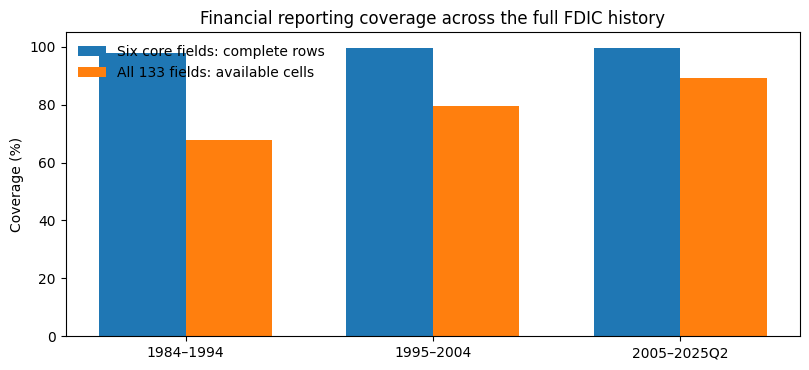

Interpretation: Missingness is assessed independently for the early historical periods. This does not automatically exclude 1984–2004 or validate their accounting definitions.


In [107]:
# 2.6.4A — Historical completeness comparison (generated from the Silver panel)
import matplotlib.pyplot as plt
plot_264a = full_history_coverage_264a.set_index("historical_era").loc[
    ["1984–1994", "1995–2004", "2005–2025Q2"]
]
x_264a = np.arange(len(plot_264a))
w_264a = 0.35
fig, ax = plt.subplots(figsize=(8.2, 3.8))
ax.bar(x_264a - w_264a/2, plot_264a["core_complete_pct"], w_264a,
       label="Six core fields: complete rows")
ax.bar(x_264a + w_264a/2, plot_264a["all_133_field_completeness_pct"], w_264a,
       label="All 133 fields: available cells")
ax.set_xticks(x_264a, plot_264a.index)
ax.set_ylim(0, 105)
ax.set_ylabel("Coverage (%)")
ax.set_title("Financial reporting coverage across the full FDIC history")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print("Interpretation: Missingness is assessed independently for the early historical periods."
      " This does not automatically exclude 1984–2004 or validate their accounting definitions.")


#### 2.6.4 · Block 3/3 — Quantify the improvement relative to 2017 baseline

In [108]:
# 5. Quantify the improvement relative to 2017 baseline
baseline = historical_window_comparison.loc[
    historical_window_comparison["window_start"] == 2017
].iloc[0]

window_gain = historical_window_comparison[
    [
        "feature_period",
        "events_with_4q_coverage",
        "candidate_positive_quarters",
        "core_complete_pct"
    ]
].copy()

window_gain["additional_covered_failures"] = (
    window_gain["events_with_4q_coverage"]
    - baseline["events_with_4q_coverage"]
)

window_gain["additional_positive_quarters"] = (
    window_gain["candidate_positive_quarters"]
    - baseline["candidate_positive_quarters"]
)

print("\nHISTORICAL EXPANSION — INFORMATION GAIN")
display(window_gain.round(3))

# 6. Validation
modern_result = historical_window_comparison.loc[
    historical_window_comparison["window_start"] == 2017
].iloc[0]

checks = {
    "Modern rows reconcile":
        int(modern_result["n_bank_quarters"]) == 172924,

    "Modern banks reconcile":
        int(modern_result["n_banks"]) == 6011,

    "Modern failures in scope = 27":
        int(modern_result["failure_events_in_scope"]) == 27,

    "Modern covered failures = 24":
        int(modern_result["events_with_4q_coverage"]) == 24,

    "Modern candidate positives = 77":
        int(modern_result["candidate_positive_quarters"]) == 77,

    "Expansion never reduces covered failures":
        historical_window_comparison[
            "events_with_4q_coverage"
        ].ge(24).all(),

    "Complete positive rows cannot exceed total positives":
        (
            historical_window_comparison[
                "positive_quarters_complete_core"
            ]
            <= historical_window_comparison[
                "candidate_positive_quarters"
            ]
        ).all(),

    "No more than 4 reports per event":
        historical_event_coverage[
            "n_4q_reports"
        ].le(4).all(),

    "Core completeness within valid range":
        historical_window_comparison[
            "core_complete_pct"
        ].between(0, 100).all()
}

print("\nHISTORICAL WINDOW VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.6.4: PASS")
print("No labels created or source values modified.")


HISTORICAL EXPANSION — INFORMATION GAIN


,feature_period,events_with_4q_coverage,candidate_positive_quarters,core_complete_pct,additional_covered_failures,additional_positive_quarters
0,1984Q1–2025Q2,2840,10870,98.879,2816,10793
1,2000Q1–2025Q2,577,2284,99.723,553,2207
2,2005Q1–2025Q2,550,2188,99.707,526,2111
3,2010Q1–2025Q2,341,1109,99.669,317,1032
4,2017Q1–2025Q2,24,77,99.585,0,0



HISTORICAL WINDOW VALIDATION
Modern rows reconcile: PASS
Modern banks reconcile: PASS
Modern failures in scope = 27: PASS
Modern covered failures = 24: PASS
Modern candidate positives = 77: PASS
Expansion never reduces covered failures: PASS
Complete positive rows cannot exceed total positives: PASS
No more than 4 reports per event: PASS
Core completeness within valid range: PASS

CELL 2.6.4: PASS
No labels created or source values modified.


**Figure 6 — Why time-based validation matters.** Visualize the number of FDIC failures by year to identify concentration in the financial crisis.

*Cached figure preview uses the previously reported audit output. Rerun the following code locally to regenerate from the actual FDIC data.*

*Cached figure preview uses the previously reported audit output. Rerun the following code locally to regenerate from the actual FDIC data.*

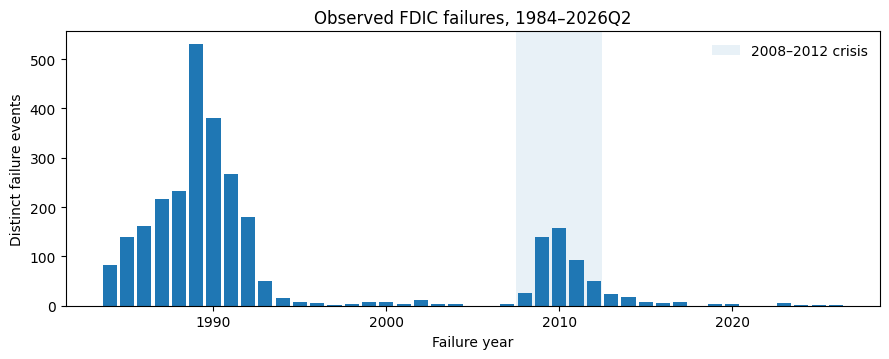

In [109]:
import matplotlib.pyplot as plt
events_yr = (historical_failures.assign(year=historical_failures["event_date"].dt.year)
             .groupby("year").size())
fig, ax = plt.subplots(figsize=(9,3.7))
ax.bar(events_yr.index, events_yr.values, width=0.82)
ax.set(xlabel="Failure year", ylabel="Distinct failure events", title="Observed FDIC failures, 1984–2026Q2")
ax.axvspan(2008-0.5, 2012+0.5, alpha=0.1, label="2008–2012 crisis")
ax.legend(frameon=False);plt.tight_layout();plt.show()

**Chart reading:** The crisis cluster dominates sample positives, so a random split would overstate temporal generalization.

##### Interpretation 2.6.4 — Full-History Modeling-Window Feasibility

**Evidence:** Silver retains financial history since **1984Q1**; this step now compares candidate prediction windows starting in **1984, 2000, 2005, 2010 and 2017**. Previous audits showed that the 2005 candidate includes 550 covered failure events and 2,188 potential positive quarters. **The 1984 result must be read from the rerun output; it has not been assumed.**

**Decision:** Keep 2005 as a **provisional comparable-feature benchmark**, not the exclusive dataset or mandatory cutoff. Evaluate 1984–2004 on field availability, event linkage and accounting comparability before deciding whether to expand supervised training to 1984.

**Limit:** More failures can improve sample size but do not establish point-in-time correctness or stable predictor meanings. Do not treat the existing 2005-based label file as covering 1984–2004.

### 2.6.5 — Longitudinal Financial-Feature Coverage and Reporting Consistency

**Objective:** Conduct an independent audit of this section’s financial and temporal evidence.

**Method:** Classify and link FAILURE/ASSISTANCE events using CERT and dated financial records; audit temporal eligibility, coverage and potential leakage.

**Decision:** The 2005 starting date will remain provisional until longitudinal coverage is assessed. Original financial values and missingness patterns will remain unchanged.

#### 2.6.5 · Block 1/3 — Select candidate modeling period

In [110]:
# 2.6.5 — Longitudinal Financial-Feature Coverage Audit

# 1. Select candidate modeling period
longitudinal_lf = (
    pl.scan_parquet(str(SILVER_PANEL_PATH))
    .filter(
        (pl.col("REPDTE") >= pl.date(2005, 1, 1))
        & (pl.col("REPDTE") <= pl.date(2025, 6, 30))
    )
    .with_columns(
        pl.col("REPDTE").dt.year().alias("year")
    )
)

# 2. Calculate annual coverage for all 133 financial fields
longitudinal_yearly = (
    longitudinal_lf
    .group_by("year")
    .agg(
        pl.len().alias("n_rows"),
        pl.col("CERT").n_unique().alias("n_banks"),
        pl.col("REPDTE").n_unique().alias("n_quarters"),

        (
            100 * pl.col("audit_missing_core_count")
            .eq(0).mean()
        ).alias("core_complete_pct"),

        (
            100 * (
                1 - pl.col(
                    "audit_missing_financial_count"
                ).mean() / len(financial_cols)
            )
        ).alias("financial_complete_pct"),

        (
            100 * pl.col("audit_sparse_current").mean()
        ).alias("sparse_reporting_pct"),

        *[
            (100 * pl.col(c).is_not_null().mean()).alias(c)
            for c in financial_cols
        ]
    )
    .collect()
    .to_pandas()
    .sort_values("year")
    .reset_index(drop=True)
)

longitudinal_yearly["n_fields_95pct"] = (
    longitudinal_yearly[financial_cols]
    .ge(95)
    .sum(axis=1)
)

print("ANNUAL FINANCIAL COVERAGE — 2005 TO 2025Q2")

display(
    longitudinal_yearly[
        [
            "year", "n_rows", "n_banks", "n_quarters",
            "core_complete_pct",
            "financial_complete_pct",
            "sparse_reporting_pct",
            "n_fields_95pct"
        ]
    ].round(3)
)

# 3. Compare coverage across three reporting periods
eras = {
    "2005_2009": (2005, 2009),
    "2010_2016": (2010, 2016),
    "2017_2025": (2017, 2025)
}

era_masks = {
    name: longitudinal_yearly["year"].between(start, end)
    for name, (start, end) in eras.items()
}

field_results = []

for field in financial_cols:

    record = {
        "field": field,
        "minimum_annual_pct": (
            longitudinal_yearly[field].min()
        )
    }

    for name, mask in era_masks.items():

        subset = longitudinal_yearly.loc[mask]

        record[f"{name}_pct"] = np.average(
            subset[field],
            weights=subset["n_rows"]
        )

    field_results.append(record)

longitudinal_field_audit = pd.DataFrame(field_results)

era_cols = [
    f"{name}_pct" for name in eras
]

longitudinal_field_audit["coverage_gap_pp"] = (
    longitudinal_field_audit[era_cols].max(axis=1)
    - longitudinal_field_audit[era_cols].min(axis=1)
)

longitudinal_field_audit["stable_95_all_eras"] = (
    longitudinal_field_audit[era_cols]
    .ge(95)
    .all(axis=1)
)

longitudinal_field_audit["stable_95_every_year"] = (
    longitudinal_field_audit["minimum_annual_pct"] >= 95
)

ANNUAL FINANCIAL COVERAGE — 2005 TO 2025Q2


,year,n_rows,n_banks,n_quarters,core_complete_pct,financial_complete_pct,sparse_reporting_pct,n_fields_95pct
0,2005,35915,9190,4,99.788,84.280,0.212,94
1,2006,35407,9047,4,99.802,84.351,0.198,94
2,2007,34754,8892,4,99.804,87.330,0.196,97
3,2008,34003,8649,4,99.794,87.372,0.200,97
4,2009,32916,8359,4,99.742,87.446,0.207,97
5,2010,31545,8035,4,99.750,87.491,0.216,97
6,2011,30230,7666,4,99.759,89.843,0.225,100
7,2012,29157,7394,4,99.760,91.340,0.230,119
8,2013,27989,7105,4,99.743,91.409,0.239,119
9,2014,26805,6812,4,99.743,92.208,0.254,120


#### 2.6.5 · Block 2/3 — Summary by reporting period

In [111]:
# 4. Summary by reporting period
era_results = []

for name, mask in era_masks.items():

    subset = longitudinal_yearly.loc[mask]

    rows = int(subset["n_rows"].sum())

    era_results.append({
        "period": name,
        "n_rows": rows,
        "quarters": int(subset["n_quarters"].sum()),
        "core_complete_pct": np.average(
            subset["core_complete_pct"],
            weights=subset["n_rows"]
        ),
        "overall_financial_complete_pct": np.average(
            subset["financial_complete_pct"],
            weights=subset["n_rows"]
        ),
        "fields_at_least_95pct": int(
            longitudinal_field_audit[
                f"{name}_pct"
            ].ge(95).sum()
        ),
        "fields_95pct_every_year": int(
            subset[financial_cols]
            .ge(95)
            .all(axis=0)
            .sum()
        )
    })

longitudinal_era_summary = pd.DataFrame(era_results)

print("\nREPORTING-PERIOD COVERAGE COMPARISON")
display(longitudinal_era_summary.round(3))

# 5. Identify the most stable candidate financial fields
print("\nLONGITUDINALLY STABLE FINANCIAL FIELDS")

print(
    "Fields >=95% across all eras:",
    int(longitudinal_field_audit[
        "stable_95_all_eras"
    ].sum())
)

print(
    "Fields >=95% in every year:",
    int(longitudinal_field_audit[
        "stable_95_every_year"
    ].sum())
)

display(
    longitudinal_field_audit.loc[
        longitudinal_field_audit["stable_95_every_year"],
        ["field", "minimum_annual_pct", "coverage_gap_pp"]
    ]
    .sort_values(
        ["minimum_annual_pct", "coverage_gap_pp"],
        ascending=[False, True]
    )
    .head(20)
    .round(3)
)

# 6. Identify variables with changing reporting availability
print("\nTOP 15 FIELDS — REPORTING COVERAGE INSTABILITY")

display(
    longitudinal_field_audit.sort_values(
        "coverage_gap_pp",
        ascending=False
    ).head(15)[
        ["field"] + era_cols
        + ["minimum_annual_pct", "coverage_gap_pp"]
    ].round(3)
)

# 7. Examine concentration of historical failures
failures_2005 = historical_failures.loc[
    historical_failures["event_date"]
    >= pd.Timestamp("2005-01-01")
].copy()

failure_periods = {
    "2005–2007": (2005, 2007),
    "2008–2012": (2008, 2012),
    "2013–2022": (2013, 2022),
    "2023–2026Q2": (2023, 2026)
}

failure_concentration = pd.DataFrame([
    {
        "period": name,
        "failure_events": int(
            failures_2005["event_date"]
            .dt.year.between(start, end).sum()
        )
    }
    for name, (start, end) in failure_periods.items()
])

failure_concentration["share_pct"] = (
    100 * failure_concentration["failure_events"]
    / len(failures_2005)
)

print("\nFAILURE EVENT CONCENTRATION — 2005 WINDOW")
display(failure_concentration.round(3))


REPORTING-PERIOD COVERAGE COMPARISON


,period,n_rows,quarters,core_complete_pct,overall_financial_complete_pct,fields_at_least_95pct,fields_95pct_every_year
0,2005_2009,172995,20,99.787,86.117,94,94
1,2010_2016,195603,28,99.744,90.861,116,97
2,2017_2025,172924,34,99.585,90.054,118,118



LONGITUDINALLY STABLE FINANCIAL FIELDS
Fields >=95% across all eras: 94
Fields >=95% in every year: 94


,field,minimum_annual_pct,coverage_gap_pp
1,DEP,100.0,0.0
2,ASSET,100.0,0.0
3,ROA,100.0,0.0
5,LNLSGR,100.0,0.0
6,RBC1AAJ,100.0,0.0
7,RBCRWAJ,100.0,0.0
10,NALNLS,100.0,0.0
11,NCLNLS,100.0,0.0
17,P9LNLS,100.0,0.0
19,NIMY,100.0,0.0



TOP 15 FIELDS — REPORTING COVERAGE INSTABILITY


,field,2005_2009_pct,2010_2016_pct,2017_2025_pct,minimum_annual_pct,coverage_gap_pp
34,RBCT1C,0.000,39.099,99.666,0.000,99.666
109,NTAUTO,0.000,83.665,99.666,0.000,99.666
56,DRAUTOQ,0.000,83.665,99.666,0.000,99.666
55,DRAUTO,0.000,83.665,99.666,0.000,99.666
68,DRDEPQ,90.177,96.824,0.000,0.000,96.824
67,DRDEP,90.198,96.824,0.000,0.000,96.824
132,NCRECNFM,53.014,96.824,99.666,0.000,46.652
77,DRRECNOT,58.654,99.758,99.666,0.000,41.103
76,DRRECNFM,58.654,99.758,99.666,0.000,41.103
131,LNRECNFM,58.654,99.758,99.666,0.000,41.103



FAILURE EVENT CONCENTRATION — 2005 WINDOW


,period,failure_events,share_pct
0,2005–2007,3,0.545
1,2008–2012,465,84.545
2,2013–2022,71,12.909
3,2023–2026Q2,11,2.000


#### 2.6.5 · Block 3/3 — Validation

In [112]:
# 8. Validation
weighted_core = np.average(
    longitudinal_yearly["core_complete_pct"],
    weights=longitudinal_yearly["n_rows"]
)

checks = {
    "2005 window rows = 541522":
        int(longitudinal_yearly["n_rows"].sum()) == 541522,

    "2005 window quarters = 82":
        int(longitudinal_yearly["n_quarters"].sum()) == 82,

    "133 financial variables audited":
        len(longitudinal_field_audit) == 133,

    "Historical core completeness reconciles":
        abs(weighted_core - 99.7069) < 0.01,

    "2017+ observations reconcile":
        int(
            longitudinal_yearly.loc[
                longitudinal_yearly["year"] >= 2017,
                "n_rows"
            ].sum()
        ) == 172924,

    "2005+ failure events = 550":
        len(failures_2005) == 550,

    "Crisis failure events = 465":
        int(
            failure_concentration.loc[
                failure_concentration["period"] == "2008–2012",
                "failure_events"
            ].iloc[0]
        ) == 465,

    "All reporting coverage values valid":
        longitudinal_field_audit[era_cols]
        .ge(0).all().all()
        and longitudinal_field_audit[era_cols]
        .le(100).all().all(),

    "All years covered":
        set(longitudinal_yearly["year"])
        == set(range(2005, 2026))
}

print("\nLONGITUDINAL COVERAGE VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.6.5: PASS")
print("No financial values modified or labels created.")


LONGITUDINAL COVERAGE VALIDATION
2005 window rows = 541522: PASS
2005 window quarters = 82: PASS
133 financial variables audited: PASS
Historical core completeness reconciles: PASS
2017+ observations reconcile: PASS
2005+ failure events = 550: PASS
Crisis failure events = 465: PASS
All reporting coverage values valid: PASS
All years covered: PASS

CELL 2.6.5: PASS
No financial values modified or labels created.


**Figure 7 — Financial-field availability evolves.** Plot yearly coverage and the number of variables exceeding 95%; this visualizes reporting-regime changes that an average can hide.

*Cached figure preview uses the previously reported audit output. Rerun the following code locally to regenerate from the actual FDIC data.*

*Cached figure preview uses the previously reported audit output. Rerun the following code locally to regenerate from the actual FDIC data.*

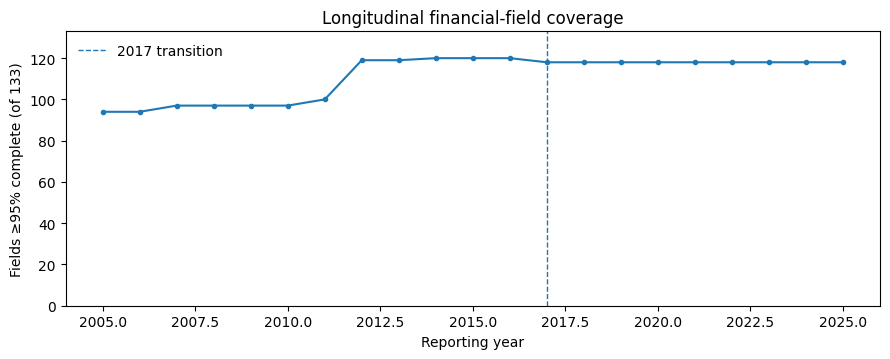

In [113]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9,3.7))
ax.plot(longitudinal_yearly["year"], longitudinal_yearly["n_fields_95pct"], marker="o", ms=3)
ax.axvline(2017, ls="--", lw=1, label="2017 transition")
ax.set(xlabel="Reporting year", ylabel="Fields ≥95% complete (of 133)", title="Longitudinal financial-field coverage")
ax.set_ylim(0,133);ax.legend(frameon=False);plt.tight_layout();plt.show()

**Chart reading:** A high-completeness year does not guarantee that variables mean the same thing in earlier reporting regimes.

##### Interpretation 2.6.5 — Longitudinal Financial-Feature Coverage

**Method:** Evaluated 133 financial variables across three reporting periods (2005–2009, 2010–2016, and 2017–2025Q2), focusing on annual completeness and historical consistency.

**Key Findings**

- **Stable feature coverage:** 94 of 133 variables (70.68%) maintain at least 95% completeness in every year, supporting the feasibility of a consistent historical predictor set.
- **Reporting-regime shifts:** Variables such as RBCT1C and DRAUTO become widely available only in later periods, while DRDEP disappears after 2016. These structural differences cannot be resolved through conventional missing-value imputation.
- **Crisis concentration:** Of 550 failures, 465 (84.55%) occurred during 2008–2012, whereas only 11 occurred during 2023–2026Q2. This raises substantial concerns about temporal generalization.

**Decision:** Retain 2005Q1–2025Q2 as the provisional primary window and prioritize the 94 consistently reported variables for further definition and leakage audits. Evaluate predictive performance using time-aware validation, including separate post-crisis testing.

### 2.6.6 — Reporting Lag Sensitivity and Positive-Event Observability

**Objective:** Assess how assumed financial-report availability delays affect the number of usable pre-failure observations and the coverage of confirmed bank failures.

**Method:** Classify and link FAILURE/ASSISTANCE events using CERT and dated financial records; audit temporal eligibility, coverage and potential leakage.

**Decision:** No final reporting delay or failure label is selected at this stage. The results will inform a time-consistent labeling protocol and identify cases requiring verification of actual financial-information availability.

#### 2.6.6 · Block 1/3 — Reconstruct candidate positive bank-quarters

In [114]:
# 2.6.6 — Reporting Lag Sensitivity & Positive Coverage

# 1. Reconstruct candidate positive bank-quarters
# Reuses failures_2005 and failure_history_lookup from prior cells.

events_2005 = failures_2005.reset_index(drop=True).copy()

candidate_records = []

for event_id, event in events_2005.iterrows():

    cert = int(event["CERT"])
    failure_date = pd.Timestamp(event["event_date"])

    reports = failure_history_lookup.get(cert)

    if reports is None:
        continue

    report_dates = pd.to_datetime(reports["REPDTE"])

    eligible = (
        report_dates.ge(pd.Timestamp("2005-01-01"))
        & report_dates.le(pd.Timestamp("2025-06-30"))
        & report_dates.lt(failure_date)
        & (
            report_dates + pd.offsets.QuarterEnd(4)
        ).ge(failure_date)
    )

    for report in reports.loc[eligible].itertuples():

        report_date = pd.Timestamp(report.REPDTE)

        candidate_records.append({
            "event_id": event_id,
            "CERT": cert,
            "report_date": report_date,
            "failure_date": failure_date,
            "failure_year": failure_date.year,
            "days_to_failure": (
                failure_date - report_date
            ).days,
            "complete_core": (
                report.audit_missing_core_count == 0
            )
        })

warning_candidates = pd.DataFrame(candidate_records)

# 2. Group events by economic period
warning_candidates["failure_period"] = np.select(
    [
        warning_candidates["failure_year"].between(2005, 2007),
        warning_candidates["failure_year"].between(2008, 2012),
        warning_candidates["failure_year"].between(2013, 2022),
        warning_candidates["failure_year"].between(2023, 2026)
    ],
    [
        "2005–2007",
        "2008–2012",
        "2013–2022",
        "2023–2026Q2"
    ],
    default="Other"
)

print("BASELINE POSITIVE-WINDOW COVERAGE")

print("Failure events:", len(events_2005))
print("Candidate positive records:", len(warning_candidates))
print(
    "Unique candidate positive bank-quarters:",
    len(
        warning_candidates[
            ["CERT", "report_date"]
        ].drop_duplicates()
    )
)
print(
    "Candidate positives with complete core:",
    int(warning_candidates["complete_core"].sum())
)


# 3. Compare hypothetical reporting-availability delays
lag_days_list = [0, 30, 45, 60, 90]

lag_results = []

for lag_days in lag_days_list:

    eligible = warning_candidates.loc[
        warning_candidates["days_to_failure"] > lag_days
    ].copy()

    unique_positive_rows = eligible[
        ["CERT", "report_date"]
    ].drop_duplicates()

    lag_results.append({
        "reporting_lag_days": lag_days,
        "covered_failure_events": eligible["event_id"].nunique(),
        "failure_events_without_coverage": (
            len(events_2005) - eligible["event_id"].nunique()
        ),
        "positive_bank_quarters": len(unique_positive_rows),
        "complete_core_positive_rows": int(
            eligible.loc[
                eligible["complete_core"],
                ["CERT", "report_date"]
            ].drop_duplicates().shape[0]
        ),
        "positive_rows_lost_vs_baseline": (
            len(
                warning_candidates[
                    ["CERT", "report_date"]
                ].drop_duplicates()
            ) - len(unique_positive_rows)
        )
    })

reporting_lag_comparison = pd.DataFrame(lag_results)

print("\nREPORTING LAG — POSITIVE COVERAGE")
display(reporting_lag_comparison)

BASELINE POSITIVE-WINDOW COVERAGE
Failure events: 550
Candidate positive records: 2188
Unique candidate positive bank-quarters: 2188
Candidate positives with complete core: 2154

REPORTING LAG — POSITIVE COVERAGE


,reporting_lag_days,covered_failure_events,failure_events_without_coverage,positive_bank_quarters,complete_core_positive_rows,positive_rows_lost_vs_baseline
0,0,550,0,2188,2154,0
1,30,550,0,1953,1932,235
2,45,550,0,1863,1844,325
3,60,550,0,1790,1776,398
4,90,550,0,1648,1639,540


#### 2.6.6 · Block 2/3 — Compare reporting-lag effects across failure periods

In [115]:
# 4. Compare reporting-lag effects across failure periods
period_results = []

for period, group in warning_candidates.groupby("failure_period"):

    baseline_events = group["event_id"].nunique()

    for lag_days in lag_days_list:

        remaining = group.loc[
            group["days_to_failure"] > lag_days
        ]

        period_results.append({
            "failure_period": period,
            "reporting_lag_days": lag_days,
            "baseline_failure_events": baseline_events,
            "covered_events": remaining["event_id"].nunique(),
            "candidate_positive_rows": len(
                remaining[
                    ["CERT", "report_date"]
                ].drop_duplicates()
            )
        })

reporting_lag_by_period = pd.DataFrame(period_results)

print("\nREPORTING LAG — COVERAGE BY FAILURE PERIOD")
display(reporting_lag_by_period)


# 5. Quantify how close failures occur to reporting dates
print("\nPRE-FAILURE REPORTING GAP — DISTRIBUTION")

display(
    warning_candidates["days_to_failure"]
    .describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90]
    ).to_frame("days_to_failure")
)


# 6. Identify failure events most sensitive to a 45-day buffer
event_lag_audit = (
    warning_candidates
    .groupby(["event_id", "CERT", "failure_date"])
    .agg(
        baseline_positive_rows=("report_date", "size"),
        rows_available_after_45d=(
            "days_to_failure",
            lambda s: int((s > 45).sum())
        ),
        minimum_days_to_failure=("days_to_failure", "min")
    )
    .reset_index()
)

event_lag_audit["rows_lost_45d"] = (
    event_lag_audit["baseline_positive_rows"]
    - event_lag_audit["rows_available_after_45d"]
)

print("\nFAILURES MOST AFFECTED BY 45-DAY BUFFER")

display(
    event_lag_audit.loc[
        event_lag_audit["rows_lost_45d"] > 0
    ]
    .sort_values(
        ["rows_lost_45d", "failure_date"],
        ascending=[False, True]
    )
    .head(20)
)


REPORTING LAG — COVERAGE BY FAILURE PERIOD


,failure_period,reporting_lag_days,baseline_failure_events,covered_events,candidate_positive_rows
0,2005–2007,0,3,3,10
1,2005–2007,30,3,3,10
2,2005–2007,45,3,3,10
3,2005–2007,60,3,3,10
4,2005–2007,90,3,3,9
5,2008–2012,0,465,465,1858
6,2008–2012,30,465,465,1655
7,2008–2012,45,465,465,1580
8,2008–2012,60,465,465,1518
9,2008–2012,90,465,465,1396



PRE-FAILURE REPORTING GAP — DISTRIBUTION


,days_to_failure
count,2188.000000
mean,179.246344
std,104.665357
min,1.000000
1%,8.000000
5%,21.000000
10%,30.000000
25%,93.000000
50%,183.000000
75%,275.000000



FAILURES MOST AFFECTED BY 45-DAY BUFFER


,event_id,CERT,failure_date,baseline_positive_rows,rows_available_after_45d,minimum_days_to_failure,rows_lost_45d
3,3,24660,2008-01-25,4,3,25,1
5,5,33901,2008-05-09,4,3,39,1
7,7,29730,2008-07-11,4,3,11,1
8,8,27011,2008-07-25,4,3,25,1
9,9,57961,2008-07-25,4,3,25,1
10,10,57523,2008-08-01,4,3,32,1
16,16,13789,2008-10-10,4,3,10,1
18,18,58241,2008-10-24,4,3,24,1
19,19,57930,2008-10-31,4,3,31,1
20,20,23595,2008-11-07,4,3,38,1


#### 2.6.6 · Block 3/3 — Validate time boundaries and baseline reconciliation

In [116]:
# 7. Validate time boundaries and baseline reconciliation
unique_baseline = len(
    warning_candidates[
        ["CERT", "report_date"]
    ].drop_duplicates()
)

checks = {
    "2005+ failure events reconcile":
        len(events_2005) == 550,

    "Baseline covered failures reconcile":
        warning_candidates["event_id"].nunique() == 550,

    "Baseline positive bank-quarters reconcile":
        unique_baseline == 2188,

    "Complete-core positive quarters reconcile":
        int(warning_candidates.loc[
            warning_candidates["complete_core"],
            ["CERT", "report_date"]
        ].drop_duplicates().shape[0]) == 2154,

    "All reports precede failure events":
        (
            warning_candidates["report_date"]
            < warning_candidates["failure_date"]
        ).all(),

    "All failures fall within 4-quarter warning windows":
        (
            warning_candidates["failure_date"]
            <= (
                warning_candidates["report_date"]
                + pd.offsets.QuarterEnd(4)
            )
        ).all(),

    "All feature dates within modeling window":
        warning_candidates["report_date"].between(
            "2005-01-01", "2025-06-30"
        ).all(),

    "All candidate outcome horizons observable":
        (
            warning_candidates["report_date"]
            + pd.offsets.QuarterEnd(4)
            <= pd.Timestamp("2026-06-30")
        ).all(),

    "Positive rows decline monotonically with lag":
        reporting_lag_comparison[
            "positive_bank_quarters"
        ].is_monotonic_decreasing,

    "Failure coverage declines monotonically with lag":
        reporting_lag_comparison[
            "covered_failure_events"
        ].is_monotonic_decreasing
}

print("\nREPORTING-LAG VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.6.6: PASS")
print("No labels generated or financial observations modified.")


REPORTING-LAG VALIDATION
2005+ failure events reconcile: PASS
Baseline covered failures reconcile: PASS
Baseline positive bank-quarters reconcile: PASS
Complete-core positive quarters reconcile: PASS
All reports precede failure events: PASS
All failures fall within 4-quarter warning windows: PASS
All feature dates within modeling window: PASS
All candidate outcome horizons observable: PASS
Positive rows decline monotonically with lag: PASS
Failure coverage declines monotonically with lag: PASS

CELL 2.6.6: PASS
No labels generated or financial observations modified.


**Figure 8 — Sensitivity to the assumed publication lag.** Plot the number of candidate positive quarters kept under increasingly conservative lag assumptions.

*Cached figure preview uses the previously reported audit output. Rerun the following code locally to regenerate from the actual FDIC data.*

*Cached figure preview uses the previously reported audit output. Rerun the following code locally to regenerate from the actual FDIC data.*

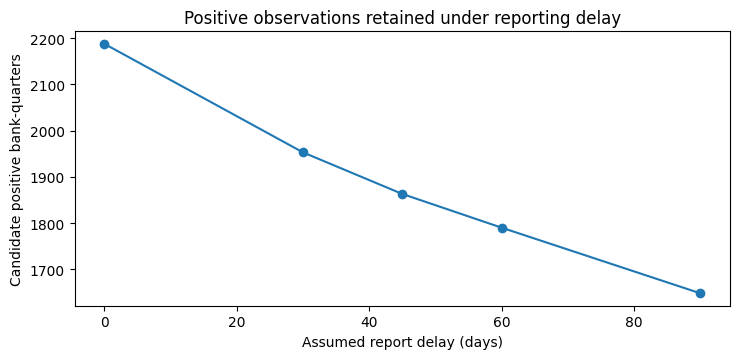

In [117]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7.5,3.7))
a = reporting_lag_comparison
ax.plot(a["reporting_lag_days"], a["positive_bank_quarters"], marker="o")
ax.set(xlabel="Assumed report delay (days)", ylabel="Candidate positive bank-quarters", title="Positive observations retained under reporting delay")
plt.tight_layout();plt.show()

**Chart reading:** Lag 45 days retains 1,863 of 2,188 candidate positives; 550 distinct failed institutions remain covered. This is sensitivity, not evidence of actual filing dates.

##### Interpretation 2.6.6 — Reporting Lag and Failure Observability

**Method:** Compared hypothetical reporting delays of 0, 30, 45, 60, and 90 days within the 2005Q1–2025Q2 feature window, keeping the four-quarter failure horizon anchored to the financial reporting date.

**Key Findings**

- **Positive-class reduction:** A 45-day buffer reduces candidate positive bank-quarters from 2,188 to 1,863 (−14.85%), while preserving coverage of all 550 confirmed failure events.
- **Look-ahead exposure:** A substantial proportion of pre-failure financial reports are dated close to failure events, creating potential information leakage if reporting dates are treated as publication dates.
- **Modern-event retention:** For failures during 2023–2026Q2, the 45-day buffer retains 33 of 36 candidate positive observations and all 11 failure events.

**Decision:** Provisionally adopt a 45-day reporting buffer and retain alternative delays for sensitivity analysis. Observations whose failures occur before assumed report availability must be excluded from the forecasting risk set rather than relabeled as nonfailures.

### 2.6.7 — Forecast-Origin Eligibility and Candidate Label Audit

**Objective:** Conduct an independent audit of this section’s financial and temporal evidence.

**Method:** Classify and link FAILURE/ASSISTANCE events using CERT and dated financial records; audit temporal eligibility, coverage and potential leakage.

**Decision:** Preserve raw financial values and treat unresolved assumptions as provisional.

#### 2.6.7 · Block 1/3 — Build the candidate modeling population

In [118]:
# 2.6.7 — Forecast-Origin Eligibility & Candidate Label Audit

# 1. Build the candidate modeling population
label_audit = (
    pl.scan_parquet(str(SILVER_PANEL_PATH))
    .filter(
        (pl.col("REPDTE") >= pl.date(2005, 1, 1))
        & (pl.col("REPDTE") <= pl.date(2025, 6, 30))
    )
    .select(["CERT", "REPDTE"])
    .collect()
    .to_pandas()
)

label_audit["CERT"] = (
    pd.to_numeric(label_audit["CERT"]).astype("int64")
)

label_audit["REPDTE"] = (
    pd.to_datetime(label_audit["REPDTE"])
    .astype("datetime64[ns]")
)

# 2. Get the earliest confirmed failure for each CERT
# Include earlier events to detect invalid post-failure records.

failure_registry = events_262.loc[
    events_262["event_type"].eq("FAILURE")
    & events_262["cert_clean"].notna(),
    ["cert_clean", "event_date"]
].copy()

failure_registry["CERT"] = (
    failure_registry["cert_clean"].astype("int64")
)

failure_registry["event_date"] = (
    pd.to_datetime(failure_registry["event_date"])
    .astype("datetime64[ns]")
)

first_failures = (
    failure_registry.groupby("CERT", as_index=False)
    .agg(
        first_failure_date=("event_date", "min"),
        n_failure_records=("event_date", "size"),
        n_distinct_failure_dates=("event_date", "nunique")
    )
)

# 3. Attach failure information for AUDITING ONLY
label_audit = label_audit.merge(
    first_failures,
    on="CERT",
    how="left",
    validate="many_to_one"
)

# 4. Define forecast origin and horizon
REPORTING_BUFFER_DAYS = 45

label_audit["forecast_origin"] = (
    label_audit["REPDTE"]
    + pd.Timedelta(days=REPORTING_BUFFER_DAYS)
)

label_audit["horizon_end"] = (
    label_audit["REPDTE"]
    + pd.offsets.QuarterEnd(4)
)

label_audit["outcome_observable"] = (
    label_audit["horizon_end"]
    <= pd.Timestamp("2026-06-30")
)

# 5. Identify observations that are not forecast-eligible
failure_date = label_audit["first_failure_date"]
report_date = label_audit["REPDTE"]

label_audit["post_failure_report"] = (
    failure_date.notna()
    & failure_date.le(report_date)
)

label_audit["failure_before_report_available"] = (
    failure_date.notna()
    & failure_date.gt(report_date)
    & failure_date.le(label_audit["forecast_origin"])
)

label_audit["forecast_eligible"] = (
    label_audit["outcome_observable"]
    & ~label_audit["post_failure_report"]
    & ~label_audit["failure_before_report_available"]
)

# 6. Construct PROVISIONAL candidate labels
# These are not final model-ready labels.

label_audit["candidate_positive"] = (
    label_audit["forecast_eligible"]
    & failure_date.notna()
    & failure_date.gt(label_audit["forecast_origin"])
    & failure_date.le(label_audit["horizon_end"])
)

label_audit["candidate_label_4q"] = pd.Series(
    pd.NA,
    index=label_audit.index,
    dtype="Int8"
)

label_audit.loc[
    label_audit["forecast_eligible"],
    "candidate_label_4q"
] = 0

label_audit.loc[
    label_audit["candidate_positive"],
    "candidate_label_4q"
] = 1

label_audit["candidate_status"] = np.select(
    [
        label_audit["post_failure_report"],
        label_audit["failure_before_report_available"],
        ~label_audit["outcome_observable"],
        label_audit["candidate_positive"]
    ],
    [
        "INELIGIBLE_POST_FAILURE",
        "INELIGIBLE_PRE_RELEASE_FAILURE",
        "INELIGIBLE_OUTCOME_CENSORED",
        "POSITIVE_PROVISIONAL"
    ],
    default="NEGATIVE_PROVISIONAL"
)

#### 2.6.7 · Block 2/3 — Summarize candidate outcomes

In [119]:
# 7. Summarize candidate outcomes
print("CANDIDATE LABEL — STATUS DISTRIBUTION")

candidate_status_summary = (
    label_audit.groupby(
        "candidate_status", dropna=False
    )
    .agg(
        n_rows=("CERT", "size"),
        n_banks=("CERT", "nunique")
    )
    .reset_index()
)

candidate_status_summary["share_pct"] = (
    100
    * candidate_status_summary["n_rows"]
    / len(label_audit)
)

display(candidate_status_summary.round(4))

# 8. Reconcile against the 45-day sensitivity audit
candidate_positive_count = int(
    label_audit["candidate_positive"].sum()
)

candidate_failure_banks = int(
    label_audit.loc[
        label_audit["candidate_positive"], "CERT"
    ].nunique()
)

label_reconciliation = pd.DataFrame([
    {
        "metric": "Candidate positive bank-quarters",
        "previous_2_6_6": 1863,
        "current_2_6_7": candidate_positive_count
    },
    {
        "metric": "Covered failure institutions",
        "previous_2_6_6": 550,
        "current_2_6_7": candidate_failure_banks
    },
    {
        "metric": "Pre-release failure observations",
        "previous_2_6_6": 325,
        "current_2_6_7": int(
            label_audit[
                "failure_before_report_available"
            ].sum()
        )
    }
])

label_reconciliation["match"] = (
    label_reconciliation["previous_2_6_6"]
    == label_reconciliation["current_2_6_7"]
)

print("\nCANDIDATE LABEL — PRIOR AUDIT RECONCILIATION")
display(label_reconciliation)

# 9. Check unusual institutional histories
print("\nINSTITUTIONAL EVENT-LINKAGE EXCEPTIONS")

exception_summary = pd.DataFrame([{
    "post_failure_report_rows": int(
        label_audit["post_failure_report"].sum()
    ),
    "post_failure_report_banks": int(
        label_audit.loc[
            label_audit["post_failure_report"], "CERT"
        ].nunique()
    ),
    "multiple_failure_date_certs": int(
        first_failures["n_distinct_failure_dates"]
        .gt(1).sum()
    ),
    "pre_release_failure_rows": int(
        label_audit["failure_before_report_available"]
        .sum()
    ),
    "unobservable_outcome_rows": int(
        (~label_audit["outcome_observable"]).sum()
    )
}])

display(exception_summary)

# 10. Modern failure case — Silicon Valley Bank
print("\nEXAMPLE — SILICON VALLEY BANK (CERT 24735)")

display(
    label_audit.loc[
        (label_audit["CERT"] == 24735)
        & label_audit["REPDTE"].between(
            "2022-03-31", "2023-03-31"
        ),
        [
            "CERT", "REPDTE", "forecast_origin",
            "horizon_end", "first_failure_date",
            "candidate_status", "candidate_label_4q"
        ]
    ].sort_values("REPDTE")
)

CANDIDATE LABEL — STATUS DISTRIBUTION


,candidate_status,n_rows,n_banks,share_pct
0,INELIGIBLE_PRE_RELEASE_FAILURE,325,325,0.060
1,NEGATIVE_PROVISIONAL,539334,9819,99.596
2,POSITIVE_PROVISIONAL,1863,550,0.344



CANDIDATE LABEL — PRIOR AUDIT RECONCILIATION


,metric,previous_2_6_6,current_2_6_7,match
0,Candidate positive bank-quarters,1863,1863,True
1,Covered failure institutions,550,550,True
2,Pre-release failure observations,325,325,True



INSTITUTIONAL EVENT-LINKAGE EXCEPTIONS


,post_failure_report_rows,post_failure_report_banks,multiple_failure_date_certs,pre_release_failure_rows,unobservable_outcome_rows
0,0,0,3,325,0



EXAMPLE — SILICON VALLEY BANK (CERT 24735)


,CERT,REPDTE,forecast_origin,horizon_end,first_failure_date,candidate_status,candidate_label_4q
343668,24735,2022-03-31,2022-05-15,2023-03-31,2023-03-10,POSITIVE_PROVISIONAL,1
343669,24735,2022-06-30,2022-08-14,2023-06-30,2023-03-10,POSITIVE_PROVISIONAL,1
343670,24735,2022-09-30,2022-11-14,2023-09-30,2023-03-10,POSITIVE_PROVISIONAL,1
343671,24735,2022-12-31,2023-02-14,2023-12-31,2023-03-10,POSITIVE_PROVISIONAL,1


#### 2.6.7 · Block 3/3 — Validation

In [120]:
# 11. Validation
checks = {
    "Full 2005 modeling panel retained":
        len(label_audit) == 541522,

    "Unique bank-quarter keys":
        not label_audit.duplicated(
            ["CERT", "REPDTE"]
        ).any(),

    "45-day candidate positives reconcile":
        candidate_positive_count == 1863,

    "550 failure institutions covered":
        candidate_failure_banks == 550,

    "Prior candidate metrics reconcile":
        label_reconciliation["match"].all(),

    "All four-quarter outcomes observable":
        label_audit["outcome_observable"].all(),

    "No post-failure observation labeled":
        label_audit.loc[
            label_audit["post_failure_report"],
            "candidate_label_4q"
        ].isna().all(),

    "No pre-release failure labeled":
        label_audit.loc[
            label_audit["failure_before_report_available"],
            "candidate_label_4q"
        ].isna().all(),

    "All provisional positives occur after forecast origin":
        (
            label_audit.loc[
                label_audit["candidate_positive"],
                "first_failure_date"
            ]
            >
            label_audit.loc[
                label_audit["candidate_positive"],
                "forecast_origin"
            ]
        ).all(),

    "All provisional positives fall within horizon":
        (
            label_audit.loc[
                label_audit["candidate_positive"],
                "first_failure_date"
            ]
            <=
            label_audit.loc[
                label_audit["candidate_positive"],
                "horizon_end"
            ]
        ).all(),

    "Candidate labels contain only 0, 1, or missing":
        label_audit["candidate_label_4q"]
        .dropna().isin([0, 1]).all()
}

print("\nCANDIDATE LABEL VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.6.7: PASS")
print("Candidate labels exist in memory only.")
print("No final label file exported.")


CANDIDATE LABEL VALIDATION
Full 2005 modeling panel retained: PASS
Unique bank-quarter keys: PASS
45-day candidate positives reconcile: PASS
550 failure institutions covered: PASS
Prior candidate metrics reconcile: PASS
All four-quarter outcomes observable: PASS
No post-failure observation labeled: PASS
No pre-release failure labeled: PASS
All provisional positives occur after forecast origin: PASS
All provisional positives fall within horizon: PASS
Candidate labels contain only 0, 1, or missing: PASS

CELL 2.6.7: PASS
Candidate labels exist in memory only.
No final label file exported.


##### Interpretation 2.6.7 — Forecast-Origin Eligibility and Candidate Labels

**Method:** Constructed provisional four-quarter failure labels using a 45-day reporting-availability buffer and the FDIC-confirmed failure dates.

**Key Findings**

- **Severe class imbalance:** The candidate dataset contains 1,863 positive and 539,334 negative bank-quarter observations, with a positive rate of approximately 0.344%.
- **Leakage prevention:** A further 325 observations are excluded because failure occurred before the assumed reporting-availability date, while coverage of all 550 failure institutions is preserved.
- **Label consistency:** No post-failure records are labeled, and all candidate positives fall strictly after the forecast origin and within the specified horizon.

**Decision:** Retain the provisional labels and 45-day reporting assumption. Before final export, audit the reliability of negative labels, historical institution eligibility, and potential panel exits. The selected prediction horizon is anchored to quarter-end rather than a full 12 months after forecast origin.

### 2.6.8 — Institutional Eligibility and Negative-Label Reliability

**Objective:** Evaluate the reliability of provisional negative labels by examining institutional reference coverage, reporting discontinuation, and repeated historical failure identifiers.

**Method:** Classify and link FAILURE/ASSISTANCE events using CERT and dated financial records; audit temporal eligibility, coverage and potential leakage.

**Decision:** Preserve all existing candidate labels. Use reference and reporting-history indicators exclusively for eligibility auditing; neither current reference status nor future reporting information may enter predictive features.

#### 2.6.8 · Block 1/3 — Normalize previously validated Institutions reference IDs

In [121]:
# 2.6.8 — Institutional Eligibility & Negative-Label Reliability

# 1. Normalize previously validated Institutions reference IDs
reference_ids = set(
    pd.to_numeric(
        pd.Series(list(institution_id_set)),
        errors="coerce"
    ).dropna().astype("int64")
)

# 2. Retrieve bank-level reporting coverage from full Silver
reporting_history = (
    pl.scan_parquet(str(SILVER_PANEL_PATH))
    .group_by("CERT")
    .agg([
        pl.col("REPDTE").min().alias("first_report"),
        pl.col("REPDTE").max().alias("last_report"),
        pl.len().alias("total_reports")
    ])
    .collect()
    .to_pandas()
)

for col in ["first_report", "last_report"]:
    reporting_history[col] = (
        pd.to_datetime(reporting_history[col])
        .astype("datetime64[ns]")
    )

# 3. Build an audit-only extension of candidate labels
eligibility_audit = label_audit[
    [
        "CERT", "REPDTE", "forecast_origin",
        "horizon_end", "candidate_status",
        "candidate_label_4q", "first_failure_date"
    ]
].copy()

eligibility_audit = eligibility_audit.merge(
    reporting_history,
    on="CERT",
    how="left",
    validate="many_to_one"
)

eligibility_audit["reference_matched"] = (
    eligibility_audit["CERT"].isin(reference_ids)
)

eligibility_audit["reporting_ends_before_horizon"] = (
    eligibility_audit["last_report"]
    < eligibility_audit["horizon_end"]
)

eligibility_audit["no_later_quarterly_report"] = (
    eligibility_audit["last_report"]
    <= eligibility_audit["REPDTE"]
)

eligibility_audit["is_negative"] = (
    eligibility_audit["candidate_status"]
    == "NEGATIVE_PROVISIONAL"
)

eligibility_audit["is_positive"] = (
    eligibility_audit["candidate_status"]
    == "POSITIVE_PROVISIONAL"
)

# 4. Compare reference coverage by label status
reference_summary = (
    eligibility_audit
    .groupby(
        ["candidate_status", "reference_matched"],
        dropna=False
    )
    .agg(
        n_rows=("CERT", "size"),
        n_banks=("CERT", "nunique")
    )
    .reset_index()
)

print("REFERENCE LINKAGE — BY CANDIDATE STATUS")
display(reference_summary)

# 5. Audit provisional negative observations
negative_audit = eligibility_audit.loc[
    eligibility_audit["is_negative"]
].copy()

negative_conditions = {
    "All provisional negatives":
        pd.Series(True, index=negative_audit.index),

    "Reference unmatched":
        ~negative_audit["reference_matched"],

    "Reporting ends before horizon":
        negative_audit["reporting_ends_before_horizon"],

    "No later quarterly report":
        negative_audit["no_later_quarterly_report"],

    "Unmatched AND reporting ends before horizon":
        (
            ~negative_audit["reference_matched"]
            & negative_audit["reporting_ends_before_horizon"]
        )
}

negative_quality_rows = []

for name, mask in negative_conditions.items():

    subset = negative_audit.loc[mask]

    negative_quality_rows.append({
        "condition": name,
        "n_rows": len(subset),
        "n_banks": subset["CERT"].nunique(),
        "share_negative_pct": (
            100 * len(subset) / len(negative_audit)
        )
    })

negative_quality_summary = pd.DataFrame(
    negative_quality_rows
)

print("\nNEGATIVE LABEL — RELIABILITY FLAGS")
display(negative_quality_summary.round(3))

REFERENCE LINKAGE — BY CANDIDATE STATUS


,candidate_status,reference_matched,n_rows,n_banks
0,INELIGIBLE_PRE_RELEASE_FAILURE,True,325,325
1,NEGATIVE_PROVISIONAL,False,5424,126
2,NEGATIVE_PROVISIONAL,True,533910,9693
3,POSITIVE_PROVISIONAL,True,1863,550



NEGATIVE LABEL — RELIABILITY FLAGS


,condition,n_rows,n_banks,share_negative_pct
0,All provisional negatives,539334,9819,100.000
1,Reference unmatched,5424,126,1.006
2,Reporting ends before horizon,19026,4972,3.528
3,No later quarterly report,4819,4819,0.894
4,Unmatched AND reporting ends before horizon,267,71,0.050


#### 2.6.8 · Block 2/3 — Examine reporting cessation across different periods

In [122]:
# 6. Examine reporting cessation across different periods
negative_audit["report_year"] = (
    negative_audit["REPDTE"].dt.year
)

negative_audit["reporting_era"] = pd.cut(
    negative_audit["report_year"],
    bins=[2004, 2007, 2012, 2016, 2022, 2025],
    labels=[
        "2005–2007",
        "2008–2012",
        "2013–2016",
        "2017–2022",
        "2023–2025Q2"
    ]
)

era_reporting_audit = (
    negative_audit
    .groupby("reporting_era", observed=True)
    .agg(
        negative_rows=("CERT", "size"),
        negative_banks=("CERT", "nunique"),
        reporting_end_flags=(
            "reporting_ends_before_horizon", "sum"
        ),
        unmatched_rows=("reference_matched",
                        lambda s: int((~s).sum()))
    )
    .reset_index()
)

era_reporting_audit["reporting_end_pct"] = (
    100
    * era_reporting_audit["reporting_end_flags"]
    / era_reporting_audit["negative_rows"]
)

print("\nNEGATIVE LABEL — REPORTING COVERAGE BY ERA")
display(era_reporting_audit.round(3))

# 7. Investigate repeated confirmed-failure identifiers
multi_failure_ids = first_failures.loc[
    first_failures["n_distinct_failure_dates"] > 1
].copy()

multi_failure_ids["rows_in_model_panel"] = (
    multi_failure_ids["CERT"].map(
        label_audit["CERT"].value_counts()
    ).fillna(0).astype(int)
)

multi_failure_ids["first_failure_date"] = (
    pd.to_datetime(multi_failure_ids["first_failure_date"])
)

print("\nREPEATED FAILURE IDENTIFIERS — MODEL RELEVANCE")

display(
    multi_failure_ids[
        [
            "CERT", "first_failure_date",
            "n_failure_records",
            "n_distinct_failure_dates",
            "rows_in_model_panel"
        ]
    ]
)

# 8. Summarize outstanding risks
negative_risk_register = pd.DataFrame([
    {
        "issue": "Unmatched provisional negatives",
        "affected_rows": int(
            (~negative_audit["reference_matched"]).sum()
        ),
        "interpretation": "Reference linkage requires verification"
    },
    {
        "issue": "Negative rows ending reporting before horizon",
        "affected_rows": int(
            negative_audit["reporting_ends_before_horizon"].sum()
        ),
        "interpretation": "Potential competing institutional exits"
    },
    {
        "issue": "Repeated historical failure identifiers",
        "affected_rows": int(
            eligibility_audit["CERT"].isin(
                multi_failure_ids["CERT"]
            ).sum()
        ),
        "interpretation": "Review historical identity and event chronology"
    }
])

print("\nNEGATIVE-LABEL RISK REGISTER")
display(negative_risk_register)


NEGATIVE LABEL — REPORTING COVERAGE BY ERA


,reporting_era,negative_rows,negative_banks,reporting_end_flags,unmatched_rows,reporting_end_pct
0,2005–2007,106022,9570,3973,1044,3.747
1,2008–2012,155971,8661,4468,1566,2.865
2,2013–2016,104494,7081,4513,1034,4.319
3,2017–2022,126642,5982,4743,1244,3.745
4,2023–2025Q2,46205,4759,1329,536,2.876



REPEATED FAILURE IDENTIFIERS — MODEL RELEVANCE


,CERT,first_failure_date,n_failure_records,n_distinct_failure_dates,rows_in_model_panel
2078,29400,1988-07-21,2,2,0
2509,31927,1986-03-27,2,2,0
2561,32059,1986-04-14,2,2,0



NEGATIVE-LABEL RISK REGISTER


,issue,affected_rows,interpretation
0,Unmatched provisional negatives,5424,Reference linkage requires verification
1,Negative rows ending reporting before horizon,19026,Potential competing institutional exits
2,Repeated historical failure identifiers,0,Review historical identity and event chronology


#### 2.6.8 · Block 3/3 — Reconciliation

In [123]:
# 9. Reconciliation
checks = {
    "All candidate rows retained":
        len(eligibility_audit) == 541522,

    "Bank-quarter keys remain unique":
        not eligibility_audit.duplicated(
            ["CERT", "REPDTE"]
        ).any(),

    "Positive labels unchanged":
        int(eligibility_audit["is_positive"].sum()) == 1863,

    "Negative labels unchanged":
        int(eligibility_audit["is_negative"].sum()) == 539334,

    "All reporting histories linked":
        eligibility_audit["last_report"].notna().all(),

    "Last report not before current observation":
        (
            eligibility_audit["last_report"]
            >= eligibility_audit["REPDTE"]
        ).all(),

    "Modern reference coverage reconciles":
        len(
            set(
                anomaly_register["CERT"].astype(int)
            ) & reference_ids
        ) == 5940,

    "Repeated failure IDs reconcile":
        len(multi_failure_ids) == 3,

    "Negative flags never exceed negative population":
        negative_quality_summary["n_rows"]
        .le(len(negative_audit)).all(),

    "Original candidate labels preserved":
        eligibility_audit["candidate_label_4q"].equals(
            label_audit["candidate_label_4q"]
        )
}

print("\nNEGATIVE-LABEL ELIGIBILITY VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.6.8: PASS")
print("Candidate labels unchanged.")
print("No final label files exported.")


NEGATIVE-LABEL ELIGIBILITY VALIDATION
All candidate rows retained: PASS
Bank-quarter keys remain unique: PASS
Positive labels unchanged: PASS
Negative labels unchanged: PASS
All reporting histories linked: PASS
Last report not before current observation: PASS
Modern reference coverage reconciles: PASS
Repeated failure IDs reconcile: PASS
Negative flags never exceed negative population: PASS
Original candidate labels preserved: PASS

CELL 2.6.8: PASS
Candidate labels unchanged.
No final label files exported.


##### Interpretation 2.6.8 — Negative-Label Reliability and Institutional Eligibility

**Method:** Audited 539,334 provisional negative observations using FDIC reference linkage, subsequent reporting coverage, and historical failure identifiers.

**Key Findings**

- **Potential competing exits:** 19,026 negative observations (3.53%) belong to institutions whose reporting histories end before the prediction horizon. This requires investigation of institutional exits but does not establish incorrect failure labels.
- **Reference-selection risk:** 5,424 negative observations from 126 institutions lack reference matches, whereas all 1,863 positives are matched. Excluding unmatched institutions could introduce survivorship bias.
- **Historical consistency:** The three CERTs with multiple confirmed failure dates have no observations in the 2005–2025 modeling panel.

**Decision:** Preserve all provisional labels and evaluate alternative negative-eligibility restrictions as sensitivity scenarios. Reference-matching and future reporting-status indicators must remain audit-only variables, not predictors.

### 2.6.9 — Negative-Label Sensitivity and Competing-Exit Risk

**Objective:** Evaluate how institutional reference coverage and subsequent reporting cessation affect the composition of the provisional negative class, while preserving confirmed failure events.

**Method:** Classify and link FAILURE/ASSISTANCE events using CERT and dated financial records; audit temporal eligibility, coverage and potential leakage.

**Decision:** Retain the full provisional risk set as the baseline. Treat restricted samples as sensitivity scenarios until institutional exit mechanisms and reference coverage are verified.

#### 2.6.9 · Block 1/2 — Examine audit flags across BOTH outcome classes

In [124]:
# 2.6.9 — Negative-Label Sensitivity & Competing-Exit Risk

risk_269 = eligibility_audit.copy()

risk_269["audit_unmatched"] = (
    ~risk_269["reference_matched"]
)

risk_269["audit_early_reporting_end"] = (
    risk_269["reporting_ends_before_horizon"]
)

risk_269["audit_no_later_report"] = (
    risk_269["no_later_quarterly_report"]
)

risk_269["audit_either_issue"] = (
    risk_269["audit_unmatched"]
    | risk_269["audit_early_reporting_end"]
)

# 1. Examine audit flags across BOTH outcome classes
label_status_reporting = (
    risk_269.loc[
        risk_269["candidate_label_4q"].notna()
    ]
    .groupby("candidate_status")
    .agg(
        n_rows=("CERT", "size"),
        n_banks=("CERT", "nunique"),
        unmatched_rows=("audit_unmatched", "sum"),
        early_reporting_end_rows=(
            "audit_early_reporting_end", "sum"
        ),
        no_later_report_rows=(
            "audit_no_later_report", "sum"
        ),
        either_issue_rows=("audit_either_issue", "sum")
    )
    .reset_index()
)

print("LABEL STATUS VS FUTURE REPORTING")
display(label_status_reporting)

# 2. Define sensitivity scenarios
is_positive = risk_269["is_positive"]
is_negative = risk_269["is_negative"]

eligible = (
    risk_269["candidate_label_4q"].notna()
)

scenario_exclusions = {
    "A_Full_provisional": pd.Series(
        False, index=risk_269.index
    ),

    "B_Exclude_unmatched_negatives": (
        is_negative & risk_269["audit_unmatched"]
    ),

    "C_Exclude_early_exit_negatives": (
        is_negative
        & risk_269["audit_early_reporting_end"]
    ),

    "D_Exclude_both_negative_flags": (
        is_negative & risk_269["audit_either_issue"]
    )
}

# 3. Quantify the effects on class composition
scenario_results = []

for name, exclude in scenario_exclusions.items():

    keep = eligible & ~exclude
    positive_keep = keep & is_positive
    negative_keep = keep & is_negative

    positives = int(positive_keep.sum())
    negatives = int(negative_keep.sum())

    scenario_results.append({
        "scenario": name,
        "positive_rows": positives,
        "negative_rows": negatives,
        "total_labeled_rows": positives + negatives,
        "negative_rows_excluded": int(exclude.sum()),
        "positive_banks": risk_269.loc[
            positive_keep, "CERT"
        ].nunique(),
        "all_banks_retained": risk_269.loc[
            keep, "CERT"
        ].nunique(),
        "positive_rate_pct": (
            100 * positives / (positives + negatives)
        )
    })

negative_sensitivity = pd.DataFrame(scenario_results)

print("\nNEGATIVE-ELIGIBILITY SENSITIVITY COMPARISON")
display(negative_sensitivity.round(4))

# 4. Investigate overlap and information at risk
negative_only = risk_269.loc[is_negative].copy()

negative_overlap = pd.DataFrame([{
    "total_negatives": len(negative_only),
    "unmatched": int(
        negative_only["audit_unmatched"].sum()
    ),
    "early_reporting_end": int(
        negative_only["audit_early_reporting_end"].sum()
    ),
    "both_flags": int((
        negative_only["audit_unmatched"]
        & negative_only["audit_early_reporting_end"]
    ).sum()),
    "either_flag": int(
        negative_only["audit_either_issue"].sum()
    ),
    "no_later_report": int(
        negative_only["audit_no_later_report"].sum()
    )
}])

print("\nNEGATIVE FLAG OVERLAP")
display(negative_overlap)

LABEL STATUS VS FUTURE REPORTING


,candidate_status,n_rows,n_banks,unmatched_rows,early_reporting_end_rows,no_later_report_rows,either_issue_rows
0,NEGATIVE_PROVISIONAL,539334,9819,5424,19026,4819,24183
1,POSITIVE_PROVISIONAL,1863,550,0,1863,223,1863



NEGATIVE-ELIGIBILITY SENSITIVITY COMPARISON


,scenario,positive_rows,negative_rows,total_labeled_rows,negative_rows_excluded,positive_banks,all_banks_retained,positive_rate_pct
0,A_Full_provisional,1863,539334,541197,0,550,9819,0.3442
1,B_Exclude_unmatched_negatives,1863,533910,535773,5424,550,9693,0.3477
2,C_Exclude_early_exit_negatives,1863,520308,522171,19026,550,9466,0.3568
3,D_Exclude_both_negative_flags,1863,515151,517014,24183,550,9349,0.3603



NEGATIVE FLAG OVERLAP


,total_negatives,unmatched,early_reporting_end,both_flags,either_flag,no_later_report
0,539334,5424,19026,267,24183,4819


#### 2.6.9 · Block 2/2 — Explicitly examine the danger of unconditional deletion

In [125]:
# 5. Explicitly examine the danger of unconditional deletion
positive_only = risk_269.loc[is_positive]

deletion_risk = pd.DataFrame([{
    "positive_rows": len(positive_only),
    "positive_with_early_reporting_end": int(
        positive_only["audit_early_reporting_end"].sum()
    ),
    "positive_with_no_later_report": int(
        positive_only["audit_no_later_report"].sum()
    ),
    "positive_unmatched": int(
        positive_only["audit_unmatched"].sum()
    )
}])

print("\nPOSITIVE-CLASS LOSS UNDER NAIVE EXIT FILTERING")
display(deletion_risk)

# 6. Validation
checks = {
    "Full modeling panel retained":
        len(risk_269) == 541522,

    "Original positives preserved":
        int(is_positive.sum()) == 1863,

    "Original negatives preserved":
        int(is_negative.sum()) == 539334,

    "Original ineligible rows preserved":
        int((~eligible).sum()) == 325,

    "Unmatched negatives reconcile":
        int(
            negative_only["audit_unmatched"].sum()
        ) == 5424,

    "Early-exit negatives reconcile":
        int(
            negative_only[
                "audit_early_reporting_end"
            ].sum()
        ) == 19026,

    "Negative flag overlap reconciles":
        int(negative_overlap["both_flags"].iloc[0])
        == 267,

    "All scenarios preserve positives":
        negative_sensitivity[
            "positive_rows"
        ].eq(1863).all(),

    "All scenarios preserve 550 failure institutions":
        negative_sensitivity[
            "positive_banks"
        ].eq(550).all(),

    "Combined restriction correctly handles overlap":
        int(
            negative_sensitivity.loc[
                negative_sensitivity["scenario"]
                == "D_Exclude_both_negative_flags",
                "negative_rows_excluded"
            ].iloc[0]
        ) == 5424 + 19026 - 267,

    "Original candidate labels unchanged":
        risk_269["candidate_label_4q"].equals(
            eligibility_audit["candidate_label_4q"]
        )
}

print("\nNEGATIVE-ELIGIBILITY VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values())

print("\nCELL 2.6.9: PASS")
print("No labels modified or exported.")


POSITIVE-CLASS LOSS UNDER NAIVE EXIT FILTERING


,positive_rows,positive_with_early_reporting_end,positive_with_no_later_report,positive_unmatched
0,1863,1863,223,0



NEGATIVE-ELIGIBILITY VALIDATION
Full modeling panel retained: PASS
Original positives preserved: PASS
Original negatives preserved: PASS
Original ineligible rows preserved: PASS
Unmatched negatives reconcile: PASS
Early-exit negatives reconcile: PASS
Negative flag overlap reconciles: PASS
All scenarios preserve positives: PASS
All scenarios preserve 550 failure institutions: PASS
Combined restriction correctly handles overlap: PASS
Original candidate labels unchanged: PASS

CELL 2.6.9: PASS
No labels modified or exported.


##### Interpretation 2.6.9 — Negative-Label Sensitivity and Competing Exits

**Method:** Compared four provisional eligibility scenarios using reference linkage and subsequent reporting cessation, while preserving all confirmed positive observations.

**Key Findings**

- **Severe survivorship risk:** All 1,863 positive observations are flagged as ending reporting before the prediction horizon. Unconditional removal of early exits would eliminate the entire positive class.
- **Limited class-balance impact:** The combined restriction removes 24,183 negatives but increases positive prevalence only from 0.3442% to 0.3603%.
- **Distinct eligibility concerns:** Only 267 negative observations have both unmatched-reference and early-reporting-exit flags, indicating that these issues should be investigated separately.

**Decision:** Retain the full provisional risk set as the primary baseline. Preserve future reporting-status indicators for auditing and sensitivity analysis only, and never use them as predictive features.

### 2.6.10 — Provisional Failure-Label Export and Reconciliation

**Objective:** Export the validated provisional four-quarter failure labels for 2005Q1–2025Q2, with a separate audit dataset documenting institutional linkage and temporal eligibility.

**Method:** Classify and link FAILURE/ASSISTANCE events using CERT and dated financial records; audit temporal eligibility, coverage and potential leakage.

**Decision:** Export provisional datasets only. Final model-ready labels require confirmation of institutional eligibility, failure-registry coverage, and reporting-availability assumptions.

#### 2.6.10 · Block 1/3 — Define export paths

In [126]:
# 2.6.10 — Provisional Label Export & Reconciliation

# 1. Define export paths
LABEL_PROVISIONAL_PATH = (
    SILVER_DIR / "bank_quarter_labels_provisional.parquet"
)

LABEL_AUDIT_PATH = (
    SILVER_DIR / "bank_quarter_label_audit.parquet"
)

LABEL_MANIFEST_PATH = (
    SILVER_DIR / "provisional_label_manifest.json"
)

label_temp = LABEL_PROVISIONAL_PATH.with_suffix(
    ".writing.parquet"
)

audit_temp = LABEL_AUDIT_PATH.with_suffix(
    ".writing.parquet"
)

# 2. Prepare the label table — no future audit fields
provisional_labels = label_audit[
    [
        "CERT",
        "REPDTE",
        "forecast_origin",
        "horizon_end",
        "candidate_label_4q",
        "candidate_status"
    ]
].copy()

provisional_labels["label_version"] = "PROVISIONAL_45D"

provisional_labels = provisional_labels.sort_values(
    ["CERT", "REPDTE"]
).reset_index(drop=True)

# 3. Prepare a separate audit table
audit_columns = [
    "CERT",
    "REPDTE",
    "first_failure_date",
    "first_report",
    "last_report",
    "total_reports",
    "reference_matched",
    "audit_unmatched",
    "audit_early_reporting_end",
    "audit_no_later_report",
    "audit_either_issue"
]

provisional_audit = (
    risk_269[audit_columns]
    .sort_values(["CERT", "REPDTE"])
    .reset_index(drop=True)
    .copy()
)

# 4. Pre-export reconciliation
assert len(provisional_labels) == 541522
assert len(provisional_audit) == 541522

assert not provisional_labels.duplicated(
    ["CERT", "REPDTE"]
).any()

assert not provisional_audit.duplicated(
    ["CERT", "REPDTE"]
).any()

assert provisional_labels[
    ["CERT", "REPDTE"]
].equals(
    provisional_audit[["CERT", "REPDTE"]]
)

expected_status = {
    "POSITIVE_PROVISIONAL": 1863,
    "NEGATIVE_PROVISIONAL": 539334,
    "INELIGIBLE_PRE_RELEASE_FAILURE": 325
}

actual_status = (
    provisional_labels["candidate_status"]
    .value_counts()
    .to_dict()
)

assert actual_status == expected_status

# 5. Write temporary Parquet files
provisional_labels.to_parquet(
    label_temp,
    engine="pyarrow",
    compression="zstd",
    index=False
)

provisional_audit.to_parquet(
    audit_temp,
    engine="pyarrow",
    compression="zstd",
    index=False
)

# 6. Independently read exported files
labels_check = pd.read_parquet(label_temp)
audit_check = pd.read_parquet(audit_temp)

# Normalize date precision for comparisons
for field in [
    "REPDTE",
    "forecast_origin",
    "horizon_end"
]:
    labels_check[field] = pd.to_datetime(
        labels_check[field]
    ).astype("datetime64[ns]")

audit_check["REPDTE"] = pd.to_datetime(
    audit_check["REPDTE"]
).astype("datetime64[ns]")

#### 2.6.10 · Block 2/3 — Validate cross-file keys and label logic

In [127]:
# 7. Validate cross-file keys and label logic
positive_mask = (
    labels_check["candidate_label_4q"] == 1
)

negative_mask = (
    labels_check["candidate_label_4q"] == 0
)

ineligible_mask = (
    labels_check["candidate_label_4q"].isna()
)

positive_dates = pd.to_datetime(
    audit_check.loc[
        positive_mask, "first_failure_date"
    ]
).astype("datetime64[ns]")

checks = {
    "All 541522 observations retained":
        len(labels_check) == 541522,

    "All audit records retained":
        len(audit_check) == 541522,

    "Bank-quarter keys unique":
        not labels_check.duplicated(
            ["CERT", "REPDTE"]
        ).any(),

    "Label-audit keys identical":
        labels_check[["CERT", "REPDTE"]].equals(
            audit_check[["CERT", "REPDTE"]]
        ),

    "Positive rows = 1863":
        int(positive_mask.sum()) == 1863,

    "Negative rows = 539334":
        int(negative_mask.sum()) == 539334,

    "Ineligible rows = 325":
        int(ineligible_mask.sum()) == 325,

    "Status distribution reconciles":
        labels_check["candidate_status"]
        .value_counts().to_dict()
        == expected_status,

    "Positive failures occur after forecast origin":
        (
            positive_dates.to_numpy()
            >
            labels_check.loc[
                positive_mask, "forecast_origin"
            ].to_numpy()
        ).all(),

    "Positive failures occur within horizon":
        (
            positive_dates.to_numpy()
            <=
            labels_check.loc[
                positive_mask, "horizon_end"
            ].to_numpy()
        ).all(),

    "All outcome horizons observable":
        labels_check["horizon_end"]
        .le(pd.Timestamp("2026-06-30")).all(),

    "No failure dates in label dataset":
        "first_failure_date"
        not in labels_check.columns,

    "No future reporting flags in label dataset":
        not any(
            c.startswith("audit_")
            for c in labels_check.columns
        ),

    "All confirmed failures retained":
        labels_check.loc[
            positive_mask, "CERT"
        ].nunique() == 550
}

print("PROVISIONAL LABEL EXPORT — VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values()), (
    "Export validation failed. "
    "Temporary files retained; final paths unchanged."
)

# 8. Promote validated files
label_temp.replace(LABEL_PROVISIONAL_PATH)
audit_temp.replace(LABEL_AUDIT_PATH)

# 9. Calculate SHA-256 for both outputs
def file_sha256(path):
    hasher = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            hasher.update(chunk)

    return hasher.hexdigest()

PROVISIONAL LABEL EXPORT — VALIDATION
All 541522 observations retained: PASS
All audit records retained: PASS
Bank-quarter keys unique: PASS
Label-audit keys identical: PASS
Positive rows = 1863: PASS
Negative rows = 539334: PASS
Ineligible rows = 325: PASS
Status distribution reconciles: PASS
Positive failures occur after forecast origin: PASS
Positive failures occur within horizon: PASS
All outcome horizons observable: PASS
No failure dates in label dataset: PASS
No future reporting flags in label dataset: PASS
All confirmed failures retained: PASS


#### 2.6.10 · Block 3/3 — Save export manifest

In [128]:
# 10. Save export manifest
label_manifest = {
    "artifact": "FDIC Provisional Bank Failure Labels",
    "status": "PROVISIONAL_NOT_MODEL_READY",

    "source": {
        "silver_panel": str(SILVER_PANEL_PATH),
        "feature_start": "2005-01-01",
        "feature_end": "2025-06-30",
        "outcome_end": "2026-06-30"
    },

    "label_definition": {
        "positive_event": "RESTYPE = FAILURE",
        "forecast_origin": "REPDTE + 45 calendar days",
        "horizon": "REPDTE + 4 quarter-ends",
        "reporting_lag_days": 45,
        "ineligible_rule": (
            "Failure occurs before or on forecast origin"
        )
    },

    "population": {
        "total_rows": len(labels_check),
        "positive_rows": int(positive_mask.sum()),
        "negative_rows": int(negative_mask.sum()),
        "ineligible_rows": int(ineligible_mask.sum()),
        "positive_failure_banks": 550
    },

    "files": {
        "labels": {
            "path": str(LABEL_PROVISIONAL_PATH),
            "sha256": file_sha256(LABEL_PROVISIONAL_PATH)
        },
        "audit": {
            "path": str(LABEL_AUDIT_PATH),
            "sha256": file_sha256(LABEL_AUDIT_PATH)
        }
    },

    "open_issues": [
        "Institutional eligibility and competing exits",
        "Actual financial report publication dates",
        "Failure registry completeness and event identity",
        "Phase 0 source-provenance checksum mismatch"
    ],

    "validation": {
        "passed": int(sum(checks.values())),
        "total": len(checks),
        "all_passed": bool(all(checks.values()))
    }
}

LABEL_MANIFEST_PATH.write_text(
    json.dumps(
        label_manifest,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# 11. Final reconciliation
print("\nPROVISIONAL LABEL — FINAL DISTRIBUTION")

display(
    labels_check.groupby("candidate_status")
    .agg(
        n_rows=("CERT", "size"),
        n_banks=("CERT", "nunique")
    )
    .reset_index()
)

print("\nPROVISIONAL LABEL — EXPORT SUMMARY")

for name, path in {
    "Labels": LABEL_PROVISIONAL_PATH,
    "Audit": LABEL_AUDIT_PATH,
    "Manifest": LABEL_MANIFEST_PATH
}.items():
    print(
        f"{name}: {path.name} | "
        f"{path.stat().st_size / 1024**2:.2f} MB"
    )

print("\nValidation:", sum(checks.values()), "/", len(checks))
print("Status:", label_manifest["status"])

print("\nCELL 2.6.10: PASS")


PROVISIONAL LABEL — FINAL DISTRIBUTION


,candidate_status,n_rows,n_banks
0,INELIGIBLE_PRE_RELEASE_FAILURE,325,325
1,NEGATIVE_PROVISIONAL,539334,9819
2,POSITIVE_PROVISIONAL,1863,550



PROVISIONAL LABEL — EXPORT SUMMARY
Labels: bank_quarter_labels_provisional.parquet | 0.21 MB
Audit: bank_quarter_label_audit.parquet | 0.20 MB
Manifest: provisional_label_manifest.json | 0.00 MB

Validation: 14 / 14
Status: PROVISIONAL_NOT_MODEL_READY

CELL 2.6.10: PASS


## 2.7 — Final reproducibility, exit evidence and Phase 3 handoff

Check artifact checksums and class definitions, enforce the ≥50 **distinct failures** test rule, and document all unresolved issues.

### 2.7.1 — Final Provenance & Institutional Eligibility Audit

**Objective:** Verify the integrity of exported Silver and provisional-label artifacts, and investigate unresolved institutional-eligibility concerns before finalizing the Phase 2 modeling population.

**Method:** Compare audit evidence, validation rules and alternative policies without silently changing the underlying labels.

**Decision:** Maintain the full provisional risk set unless independent evidence supports an eligibility restriction.

#### 2.7.1 · Block 1/4 — ARTIFACT PROVENANCE VERIFICATION

In [129]:
# ============================================================
# CELL 2.7.1 — FINAL PROVENANCE & INSTITUTIONAL ELIGIBILITY
# ============================================================

# ------------------------------------------------------------
# 1. ARTIFACT PROVENANCE VERIFICATION
# ------------------------------------------------------------

def sha256_file(path):
    hasher = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            hasher.update(chunk)

    return hasher.hexdigest()


silver_manifest_path = SILVER_DIR / "silver_export_manifest.json"
label_manifest_path = SILVER_DIR / "provisional_label_manifest.json"

with open(silver_manifest_path, "r", encoding="utf-8") as f:
    silver_manifest_check = json.load(f)

with open(label_manifest_path, "r", encoding="utf-8") as f:
    label_manifest_check = json.load(f)


artifact_specs = [
    (
        "Silver financial panel",
        SILVER_PANEL_PATH,
        silver_manifest_check["silver"]["sha256"]
    ),
    (
        "Provisional failure labels",
        SILVER_DIR / "bank_quarter_labels_provisional.parquet",
        label_manifest_check["files"]["labels"]["sha256"]
    ),
    (
        "Provisional label audit",
        SILVER_DIR / "bank_quarter_label_audit.parquet",
        label_manifest_check["files"]["audit"]["sha256"]
    )
]

artifact_results = []

for name, path, expected_hash in artifact_specs:

    path = Path(path)
    exists = path.is_file()

    actual_hash = (
        sha256_file(path) if exists else None
    )

    artifact_results.append({
        "artifact": name,
        "file_exists": exists,
        "checksum_match": (
            actual_hash == expected_hash
            if exists else False
        ),
        "size_mb": (
            round(path.stat().st_size / 1024**2, 2)
            if exists else np.nan
        )
    })

artifact_integrity = pd.DataFrame(artifact_results)

print("ARTIFACT PROVENANCE — CHECKSUM VERIFICATION")
display(artifact_integrity)


# ------------------------------------------------------------
# 2. BRONZE SOURCE INVENTORY
# ------------------------------------------------------------

bronze_paths = [Path(p) for p in BRONZE_FILES]

bronze_inventory = pd.DataFrame([
    {
        "file": str(p),
        "exists": p.is_file(),
        "size_bytes": (
            p.stat().st_size if p.is_file() else 0
        )
    }
    for p in bronze_paths
])

print("\nBRONZE SOURCE INVENTORY")

print("Expected files:", len(bronze_paths))
print("Existing files:", int(bronze_inventory["exists"].sum()))

print(
    "Available source size (GB):",
    round(
        bronze_inventory["size_bytes"].sum() / 1024**3,
        3
    )
)

# Metadata inventory is NOT a cryptographic source check.
# The original Phase 0 SHA-256 mismatch remains unresolved.

print("\nPHASE 0 PROVENANCE STATUS")
print("REVIEW — Original source checksum mismatch unresolved.")


# ------------------------------------------------------------

ARTIFACT PROVENANCE — CHECKSUM VERIFICATION


,artifact,file_exists,checksum_match,size_mb
0,Silver financial panel,True,True,363.02
1,Provisional failure labels,True,True,0.21
2,Provisional label audit,True,True,0.20



BRONZE SOURCE INVENTORY
Expected files: 43
Existing files: 43
Available source size (GB): 0.446

PHASE 0 PROVENANCE STATUS
REVIEW — Original source checksum mismatch unresolved.


#### 2.7.1 · Block 2/4 — INDEPENDENT INSTITUTIONS REFERENCE VERIFICATION

In [130]:
# 3. INDEPENDENT INSTITUTIONS REFERENCE VERIFICATION
# ------------------------------------------------------------

institutions_ref = pl.read_parquet(
    str(reference_files["institutions"])
).to_pandas()

print("\nINSTITUTIONS REFERENCE — AVAILABLE FIELDS")
print(institutions_ref.columns.tolist())

cert_candidates = [
    col for col in institutions_ref.columns
    if str(col).upper() == "CERT"
]

assert cert_candidates, (
    "CERT column not identified in Institutions reference."
)

raw_cert = pd.to_numeric(
    institutions_ref[cert_candidates[0]],
    errors="coerce"
)

valid_raw_cert = (
    raw_cert.notna()
    & raw_cert.gt(0)
    & raw_cert.eq(np.floor(raw_cert))
)

raw_reference_ids = set(
    raw_cert.loc[valid_raw_cert].astype("int64")
)

# IDs used in the previous eligibility audit
reference_ids_271 = set(
    pd.to_numeric(
        pd.Series(list(institution_id_set)),
        errors="coerce"
    ).dropna().astype("int64")
)

reference_integrity = pd.DataFrame([{
    "reference_records": len(institutions_ref),
    "valid_unique_reference_certs": len(raw_reference_ids),
    "previously_normalized_certs": len(reference_ids_271),
    "ids_only_in_raw_reference": len(
        raw_reference_ids - reference_ids_271
    ),
    "ids_only_in_prior_set": len(
        reference_ids_271 - raw_reference_ids
    ),
    "identifier_sets_match": (
        raw_reference_ids == reference_ids_271
    )
}])

print("\nINSTITUTIONAL REFERENCE — IDENTIFIER INTEGRITY")
display(reference_integrity)


# ------------------------------------------------------------
# 4. PROFILE REFERENCE-UNMATCHED NEGATIVE INSTITUTIONS
# ------------------------------------------------------------

negative_271 = risk_269.loc[
    risk_269["is_negative"]
].copy()

positive_271 = risk_269.loc[
    risk_269["is_positive"]
].copy()

unmatched_271 = negative_271.loc[
    ~negative_271["reference_matched"]
].copy()

unmatched_bank_profile = (
    unmatched_271.groupby("CERT")
    .agg(
        n_negative_rows=("REPDTE", "size"),
        first_feature_report=("REPDTE", "min"),
        last_feature_report=("REPDTE", "max"),
        last_historical_report=("last_report", "max"),
        early_exit_rows=(
            "reporting_ends_before_horizon", "sum"
        )
    )
    .reset_index()
)

unmatched_bank_profile["last_report_year"] = (
    pd.to_datetime(
        unmatched_bank_profile["last_historical_report"]
    ).dt.year
)

print("\nUNMATCHED INSTITUTIONS — SUMMARY")

unmatched_summary = pd.DataFrame([{
    "unmatched_negative_rows": len(unmatched_271),
    "unmatched_banks": unmatched_271["CERT"].nunique(),
    "unmatched_with_early_exit_rows": int(
        unmatched_271[
            "reporting_ends_before_horizon"
        ].sum()
    ),
    "unmatched_with_no_later_report_rows": int(
        unmatched_271["no_later_quarterly_report"].sum()
    ),
    "unmatched_banks_in_raw_reference": int(
        unmatched_bank_profile["CERT"]
        .isin(raw_reference_ids).sum()
    )
}])

display(unmatched_summary)

print("\nUNMATCHED BANKS — TOP 15 BY REPORTING HISTORY")

display(
    unmatched_bank_profile.sort_values(
        "n_negative_rows",
        ascending=False
    ).head(15)
)


# ------------------------------------------------------------


INSTITUTIONS REFERENCE — AVAILABLE FIELDS
['CERT', 'NAME', 'STNAME', 'BKCLASS', 'ACTIVE', 'ESTYMD', 'ENDEFYMD', 'CHANGEC1', 'INSDATE']

INSTITUTIONAL REFERENCE — IDENTIFIER INTEGRITY


,reference_records,valid_unique_reference_certs,previously_normalized_certs,ids_only_in_raw_reference,ids_only_in_prior_set,identifier_sets_match
0,27835,27835,27835,0,0,True



UNMATCHED INSTITUTIONS — SUMMARY


,unmatched_negative_rows,unmatched_banks,unmatched_with_early_exit_rows,unmatched_with_no_later_report_rows,unmatched_banks_in_raw_reference
0,5424,126,267,71,0



UNMATCHED BANKS — TOP 15 BY REPORTING HISTORY


,CERT,n_negative_rows,first_feature_report,last_feature_report,last_historical_report,early_exit_rows,last_report_year
0,18342,82,2005-03-31,2025-06-30,2026-06-30,0,2026
3,25927,82,2005-03-31,2025-06-30,2026-06-30,0,2026
8,27102,82,2005-03-31,2025-06-30,2026-06-30,0,2026
11,27479,82,2005-03-31,2025-06-30,2026-06-30,0,2026
7,26732,82,2005-03-31,2025-06-30,2026-06-30,0,2026
18,32961,82,2005-03-31,2025-06-30,2026-06-30,0,2026
24,33239,82,2005-03-31,2025-06-30,2026-06-30,0,2026
47,34732,82,2005-03-31,2025-06-30,2026-06-30,0,2026
49,34813,82,2005-03-31,2025-06-30,2026-06-30,0,2026
45,34588,82,2005-03-31,2025-06-30,2026-06-30,0,2026


#### 2.7.1 · Block 3/4 — REPORTING CESSATION AMONG NEGATIVE OBSERVATIONS

In [131]:
# 5. REPORTING CESSATION AMONG NEGATIVE OBSERVATIONS
# ------------------------------------------------------------

early_exit_negatives = negative_271.loc[
    negative_271["reporting_ends_before_horizon"]
].copy()

early_exit_negatives["last_report_year"] = (
    pd.to_datetime(
        early_exit_negatives["last_report"]
    ).dt.year
)

exit_year_summary = (
    early_exit_negatives.groupby("last_report_year")
    .agg(
        affected_negative_rows=("CERT", "size"),
        affected_banks=("CERT", "nunique")
    )
    .reset_index()
    .sort_values(
        "affected_negative_rows",
        ascending=False
    )
)

print("\nNEGATIVE REPORTING CESSATION — TOP 15 EXIT YEARS")
display(exit_year_summary.head(15))


# ------------------------------------------------------------
# 6. COMPARE POSITIVE AND NEGATIVE REPORTING CESSATION
# ------------------------------------------------------------

def profile_outcome(group, name):

    return {
        "candidate_class": name,
        "n_rows": len(group),
        "n_banks": group["CERT"].nunique(),
        "reference_unmatched_rows": int(
            (~group["reference_matched"]).sum()
        ),
        "early_reporting_end_rows": int(
            group["reporting_ends_before_horizon"].sum()
        ),
        "no_later_report_rows": int(
            group["no_later_quarterly_report"].sum()
        ),
        "early_reporting_end_pct": round(
            100 * group[
                "reporting_ends_before_horizon"
            ].mean(),
            3
        )
    }


eligibility_class_comparison = pd.DataFrame([
    profile_outcome(
        negative_271,
        "NEGATIVE_PROVISIONAL"
    ),
    profile_outcome(
        positive_271,
        "POSITIVE_PROVISIONAL"
    )
])

print("\nINSTITUTIONAL ELIGIBILITY — CLASS COMPARISON")
display(eligibility_class_comparison)


# ------------------------------------------------------------
# 7. DEFINE OUTSTANDING ELIGIBILITY ISSUES
# ------------------------------------------------------------

phase2_eligibility_issues = pd.DataFrame([
    {
        "issue": "Phase 0 source SHA-256 mismatch",
        "affected_rows": np.nan,
        "status": "REVIEW",
        "required_action": (
            "Locate original handoff hashes and reconcile "
            "with the corresponding source files"
        )
    },
    {
        "issue": "Unmatched reference institutions",
        "affected_rows": len(unmatched_271),
        "status": "REVIEW",
        "required_action": (
            "Verify bank identity and coverage in "
            "the historical Institutions reference"
        )
    },
    {
        "issue": "Negative reporting cessation",
        "affected_rows": len(early_exit_negatives),
        "status": "REVIEW",
        "required_action": (
            "Investigate institutional exits and "
            "competing outcomes"
        )
    },
    {
        "issue": "Actual reporting availability dates",
        "affected_rows": np.nan,
        "status": "REVIEW",
        "required_action": (
            "Validate the 45-day buffer or retain "
            "it as an explicit modeling assumption"
        )
    }
])

print("\nPHASE 2 — OUTSTANDING ELIGIBILITY ISSUES")
display(phase2_eligibility_issues)


# ------------------------------------------------------------


NEGATIVE REPORTING CESSATION — TOP 15 EXIT YEARS


,last_report_year,affected_negative_rows,affected_banks
2,2007,1351,340
1,2006,1349,338
10,2015,1196,299
9,2014,1196,299
3,2008,1128,284
8,2013,1072,268
11,2016,1052,263
14,2019,1024,256
7,2012,1016,254
13,2018,1008,252



INSTITUTIONAL ELIGIBILITY — CLASS COMPARISON


,candidate_class,n_rows,n_banks,reference_unmatched_rows,early_reporting_end_rows,no_later_report_rows,early_reporting_end_pct
0,NEGATIVE_PROVISIONAL,539334,9819,5424,19026,4819,3.528
1,POSITIVE_PROVISIONAL,1863,550,0,1863,223,100.000



PHASE 2 — OUTSTANDING ELIGIBILITY ISSUES


,issue,affected_rows,status,required_action
0,Phase 0 source SHA-256 mismatch,NaN,REVIEW,Locate original handoff hashes and reconcile w...
1,Unmatched reference institutions,5424.0,REVIEW,Verify bank identity and coverage in the histo...
2,Negative reporting cessation,19026.0,REVIEW,Investigate institutional exits and competing ...
3,Actual reporting availability dates,NaN,REVIEW,Validate the 45-day buffer or retain it as an ...


#### 2.7.1 · Block 4/4 — VALIDATION

In [132]:
# 8. VALIDATION
# ------------------------------------------------------------

checks = {
    "All exported artifact checksums match":
        artifact_integrity["checksum_match"].all(),

    "All 43 Bronze files exist":
        (
            len(bronze_inventory) == 43
            and bronze_inventory["exists"].all()
        ),

    "Unmatched negatives reconcile":
        len(unmatched_271) == 5424,

    "Unmatched banks reconcile":
        unmatched_271["CERT"].nunique() == 126,

    "Negative early-exit rows reconcile":
        len(early_exit_negatives) == 19026,

    "Positive observations preserved":
        len(positive_271) == 1863,

    "Negative observations preserved":
        len(negative_271) == 539334,

    "All positive reporting exits preserved":
        int(
            positive_271[
                "reporting_ends_before_horizon"
            ].sum()
        ) == 1863,

    "No candidate observations removed":
        (
            len(positive_271)
            + len(negative_271)
            + int(
                risk_269[
                    "candidate_label_4q"
                ].isna().sum()
            )
        ) == 541522,

    "Candidate labels remain unchanged":
        risk_269["candidate_label_4q"].equals(
            eligibility_audit["candidate_label_4q"]
        )
}

print("\nFINAL PROVENANCE & ELIGIBILITY VALIDATION")

for name, passed in checks.items():
    print(
        f"{name}: {'PASS' if passed else 'REVIEW'}"
    )

print(
    "\nOperational checks:",
    sum(checks.values()), "/", len(checks)
)

assert all(checks.values()), (
    "Artifact or population integrity check failed. "
    "Review the output before proceeding."
)

print("\nCELL 2.7.1: PASS — TECHNICAL INTEGRITY")
print("Phase 0 source provenance: STILL UNDER REVIEW")
print("Institutional eligibility: STILL UNDER REVIEW")
print("No candidate labels modified.")
print("No files exported.")


FINAL PROVENANCE & ELIGIBILITY VALIDATION
All exported artifact checksums match: PASS
All 43 Bronze files exist: PASS
Unmatched negatives reconcile: PASS
Unmatched banks reconcile: PASS
Negative early-exit rows reconcile: PASS
Positive observations preserved: PASS
Negative observations preserved: PASS
All positive reporting exits preserved: PASS
No candidate observations removed: PASS
Candidate labels remain unchanged: PASS

Operational checks: 10 / 10

CELL 2.7.1: PASS — TECHNICAL INTEGRITY
Phase 0 source provenance: STILL UNDER REVIEW
Institutional eligibility: STILL UNDER REVIEW
No candidate labels modified.
No files exported.


**Figure 9 — Reporting cessation is not equivalent to failure.** Plot the distribution of negative observations by last reporting year to identify where exit evidence is most needed.

*Cached figure preview uses the previously reported audit output. Rerun the following code locally to regenerate from the actual FDIC data.*

*Cached figure preview uses the previously reported audit output. Rerun the following code locally to regenerate from the actual FDIC data.*

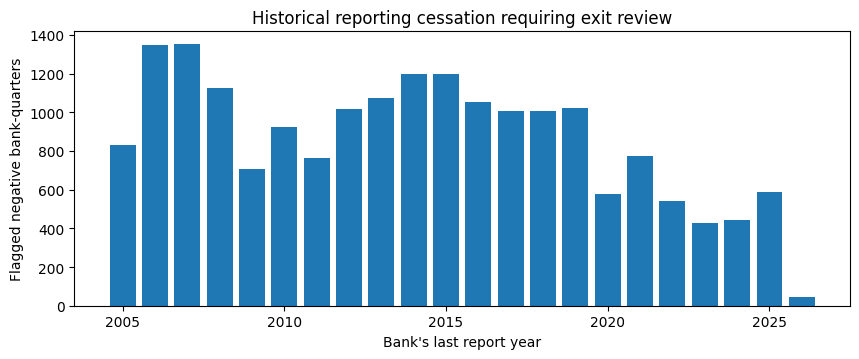

In [133]:
import matplotlib.pyplot as plt
s = exit_year_summary.sort_values("last_report_year")
fig, ax = plt.subplots(figsize=(8.7,3.7))
ax.bar(s["last_report_year"],s["affected_negative_rows"])
ax.set(xlabel="Bank's last report year", ylabel="Flagged negative bank-quarters", title="Historical reporting cessation requiring exit review")
plt.tight_layout();plt.show()

**Chart reading:** Peaks can reflect mergers, discontinuations or coverage differences; do not convert disappearance flags into failure labels.

##### Interpretation 2.7.1 — Provenance and Institutional Eligibility

**Method:** Verified exported artifact checksums, Bronze source availability, FDIC reference identifiers, unmatched institutions, and reporting cessation patterns.

**Key Findings**

- **Artifact integrity:** All three exported Parquet files match their recorded SHA-256 checksums, and all 43 Bronze files remain available. The original Phase 0 provenance mismatch is still unresolved.
- **Reference coverage:** 126 unmatched institutions account for 5,424 negative observations. Several maintain complete reporting histories through 2026Q2, indicating that unmatched status does not necessarily imply institutional inactivity.
- **Competing exits:** 19,026 negative observations are flagged for reporting cessation before the prediction horizon. However, all 1,863 positive observations share this characteristic, making unconditional exit-based filtering inappropriate.

**Decision:** Preserve the full provisional risk set. Treat unmatched reference identifiers, future reporting cessation, and unresolved source provenance as audit issues rather than automatic exclusion criteria.

### 2.7.2 — Label Robustness and Temporal Leakage Audit

**Objective:** Validate the temporal consistency and robustness of provisional bank-failure labels before model-ready dataset preparation.

**Method:** Compare audit evidence, validation rules and alternative policies without silently changing the underlying labels.

**Decision:** Retain the existing 45-day quarter-end-anchored definition as provisional unless the sensitivity analysis identifies a methodological inconsistency.

#### 2.7.2 · Block 1/4 — Prepare independent reconstruction

In [134]:
# ============================================================
# CELL 2.7.2 — LABEL ROBUSTNESS & TEMPORAL LEAKAGE AUDIT
# ============================================================

# 1. Prepare independent reconstruction
base_272 = label_audit[
    [
        "CERT", "REPDTE", "first_failure_date",
        "horizon_end", "candidate_label_4q",
        "candidate_status"
    ]
].copy()

for col in ["REPDTE", "first_failure_date", "horizon_end"]:
    base_272[col] = pd.to_datetime(
        base_272[col]
    ).astype("datetime64[ns]")

dates = base_272["REPDTE"]
failures = base_272["first_failure_date"]
horizon_qe = base_272["horizon_end"]

OUTCOME_CUTOFF = pd.Timestamp("2026-06-30")

# 2. Reconstruct labels under alternative reporting buffers
lag_results_272 = []
reconstructed_45 = None
status_45 = None

for lag in [0, 30, 45, 60, 90]:

    origin = dates + pd.Timedelta(days=lag)

    post_failure = failures.notna() & failures.le(dates)

    pre_release_failure = (
        failures.notna()
        & failures.gt(dates)
        & failures.le(origin)
    )

    censored = horizon_qe.gt(OUTCOME_CUTOFF)

    eligible = ~(
        post_failure | pre_release_failure | censored
    )

    positive = (
        eligible
        & failures.notna()
        & failures.gt(origin)
        & failures.le(horizon_qe)
    )

    negative = eligible & ~positive

    lag_results_272.append({
        "reporting_lag_days": lag,
        "positive_rows": int(positive.sum()),
        "negative_rows": int(negative.sum()),
        "ineligible_rows": int((~eligible).sum()),
        "covered_failure_banks": base_272.loc[
            positive, "CERT"
        ].nunique(),
        "positive_rate_pct": (
            100 * positive.sum() / eligible.sum()
        )
    })

    if lag == 45:

        reconstructed_45 = pd.Series(
            pd.NA, index=base_272.index, dtype="Int8"
        )

        reconstructed_45.loc[negative] = 0
        reconstructed_45.loc[positive] = 1

        status_45 = np.select(
            [
                post_failure,
                pre_release_failure,
                censored,
                positive
            ],
            [
                "INELIGIBLE_POST_FAILURE",
                "INELIGIBLE_PRE_RELEASE_FAILURE",
                "INELIGIBLE_OUTCOME_CENSORED",
                "POSITIVE_PROVISIONAL"
            ],
            default="NEGATIVE_PROVISIONAL"
        )

reporting_lag_robustness = pd.DataFrame(lag_results_272)

print("REPORTING-LAG ROBUSTNESS — RECONSTRUCTED LABELS")
display(reporting_lag_robustness.round(4))


# 3. Check exact reconstruction of the exported baseline
baseline_label_match = reconstructed_45.equals(
    base_272["candidate_label_4q"]
)

baseline_status_match = (
    pd.Series(status_45, index=base_272.index)
    .eq(base_272["candidate_status"])
    .all()
)

print("\n45-DAY LABEL RECONSTRUCTION")
print("Candidate labels identical:", baseline_label_match)
print("Candidate statuses identical:", baseline_status_match)

REPORTING-LAG ROBUSTNESS — RECONSTRUCTED LABELS


,reporting_lag_days,positive_rows,negative_rows,ineligible_rows,covered_failure_banks,positive_rate_pct
0,0,2188,539334,0,550,0.4040
1,30,1953,539334,235,550,0.3608
2,45,1863,539334,325,550,0.3442
3,60,1790,539334,398,550,0.3308
4,90,1648,539334,540,550,0.3046



45-DAY LABEL RECONSTRUCTION
Candidate labels identical: True
Candidate statuses identical: True


#### 2.7.2 · Block 2/4 — Class distribution by feature reporting period

In [135]:
# 4. Class distribution by feature reporting period
base_272["report_year"] = dates.dt.year

base_272["reporting_era"] = pd.cut(
    base_272["report_year"],
    bins=[2004, 2007, 2012, 2016, 2022, 2025],
    labels=[
        "2005–2007",
        "2008–2012",
        "2013–2016",
        "2017–2022",
        "2023–2025Q2"
    ]
)

temporal_class_summary = (
    base_272
    .groupby("reporting_era", observed=True)
    .agg(
        n_rows=("CERT", "size"),
        positive_rows=(
            "candidate_label_4q",
            lambda s: int(s.eq(1).sum())
        ),
        negative_rows=(
            "candidate_label_4q",
            lambda s: int(s.eq(0).sum())
        ),
        ineligible_rows=(
            "candidate_label_4q",
            lambda s: int(s.isna().sum())
        )
    )
    .reset_index()
)

temporal_class_summary["positive_rate_pct"] = (
    100 * temporal_class_summary["positive_rows"]
    / (
        temporal_class_summary["positive_rows"]
        + temporal_class_summary["negative_rows"]
    )
)

print("\nTEMPORAL CLASS DISTRIBUTION — REPORTING ERA")
display(temporal_class_summary.round(4))


# 5. Compare two possible prediction-horizon definitions
forecast_origin_45 = dates + pd.Timedelta(days=45)

# Alternative: 12 calendar months AFTER forecast origin
horizon_origin_12m = (
    forecast_origin_45 + pd.DateOffset(months=12)
)

censored_12m = horizon_origin_12m.gt(OUTCOME_CUTOFF)

pre_release_45 = (
    failures.notna()
    & failures.le(forecast_origin_45)
)

eligible_12m = ~(
    pre_release_45 | censored_12m
)

positive_12m = (
    eligible_12m
    & failures.notna()
    & failures.gt(forecast_origin_45)
    & failures.le(horizon_origin_12m)
)

negative_12m = eligible_12m & ~positive_12m

horizon_comparison = pd.DataFrame([
    {
        "horizon_definition": "Quarter-end + 4 quarters",
        "positive_rows": int(
            base_272["candidate_label_4q"].eq(1).sum()
        ),
        "negative_rows": int(
            base_272["candidate_label_4q"].eq(0).sum()
        ),
        "ineligible_or_censored": int(
            base_272["candidate_label_4q"].isna().sum()
        ),
        "right_censored_rows": int(
            horizon_qe.gt(OUTCOME_CUTOFF).sum()
        )
    },
    {
        "horizon_definition": "Forecast origin + 12 months",
        "positive_rows": int(positive_12m.sum()),
        "negative_rows": int(negative_12m.sum()),
        "ineligible_or_censored": int(
            (~eligible_12m).sum()
        ),
        "right_censored_rows": int(censored_12m.sum())
    }
])

print("\nPREDICTION-HORIZON SENSITIVITY")
display(horizon_comparison)

print("\nRIGHT-CENSORING — ALTERNATIVE HORIZON")
print(
    "Censored observations:",
    int(censored_12m.sum())
)
print(
    "Latest censored feature date:",
    dates.loc[censored_12m].max()
    if censored_12m.any() else None
)


TEMPORAL CLASS DISTRIBUTION — REPORTING ERA


,reporting_era,n_rows,positive_rows,negative_rows,ineligible_rows,positive_rate_pct
0,2005–2007,106076,53,106022,1,0.0500
1,2008–2012,157851,1601,155971,279,1.0160
2,2013–2016,104671,145,104494,32,0.1386
3,2017–2022,126697,45,126642,10,0.0355
4,2023–2025Q2,46227,19,46205,3,0.0411



PREDICTION-HORIZON SENSITIVITY


,horizon_definition,positive_rows,negative_rows,ineligible_or_censored,right_censored_rows
0,Quarter-end + 4 quarters,1863,539334,325,0
1,Forecast origin + 12 months,2195,534508,4819,4494



RIGHT-CENSORING — ALTERNATIVE HORIZON
Censored observations: 4494
Latest censored feature date: 2025-06-30 00:00:00


#### 2.7.2 · Block 3/4 — Predictor leakage: structural separation audit

In [136]:
# 6. Predictor leakage: structural separation audit
silver_cols_272 = (
    pl.scan_parquet(str(SILVER_PANEL_PATH))
    .collect_schema()
    .names()
)

stable_candidates_272 = (
    longitudinal_field_audit.loc[
        longitudinal_field_audit["stable_95_every_year"],
        "field"
    ].tolist()
)

audit_only_cols_272 = [
    c for c in silver_cols_272
    if c.startswith("audit_")
]

generated_feature_cols_272 = [
    c for c in silver_cols_272
    if c.startswith("feat_")
]

FORBIDDEN_PREDICTOR_FIELDS = {
    "FAILDATE",
    "FAILYR",
    "RESTYPE",
    "RESTYPE1",
    "first_failure_date",
    "candidate_label_4q",
    "candidate_status",
    "forecast_origin",
    "horizon_end",
    "last_report",
    "first_report",
    "reference_matched",
    "record_role",
}

proposed_predictors_272 = [
    c for c in stable_candidates_272
    if c in silver_cols_272
    and c not in FORBIDDEN_PREDICTOR_FIELDS
    and not c.startswith("audit_")
]

forbidden_in_predictors = sorted(
    set(proposed_predictors_272)
    & FORBIDDEN_PREDICTOR_FIELDS
)

forbidden_in_silver = sorted(
    set(silver_cols_272)
    & (
        FORBIDDEN_PREDICTOR_FIELDS
        - {"record_role"}
    )
)

feature_separation = pd.DataFrame([
    {
        "category": "Original financial fields",
        "n_columns": len(financial_cols),
        "usage": "Candidate predictors; definition audit pending"
    },
    {
        "category": "Stable financial candidates",
        "n_columns": len(proposed_predictors_272),
        "usage": "Provisional predictor shortlist"
    },
    {
        "category": "Generated feat_ fields",
        "n_columns": len(generated_feature_cols_272),
        "usage": "Review calculations and as-of availability"
    },
    {
        "category": "Audit-only fields in Silver",
        "n_columns": len(audit_only_cols_272),
        "usage": "Exclude from predictor matrix"
    },
    {
        "category": "Forbidden fields in proposed shortlist",
        "n_columns": len(forbidden_in_predictors),
        "usage": "Must equal zero"
    },
    {
        "category": "Forbidden event/label fields in Silver",
        "n_columns": len(forbidden_in_silver),
        "usage": "Must equal zero"
    }
])

print("\nFEATURE AND LABEL — STRUCTURAL LEAKAGE AUDIT")
display(feature_separation)


# 7. Compare reconstructed lag results with previous audit
expected_lag_positives = {
    0: 2188,
    30: 1953,
    45: 1863,
    60: 1790,
    90: 1648
}

lag_counts_match = all(
    int(row.positive_rows) == expected_lag_positives[
        int(row.reporting_lag_days)
    ]
    for row in reporting_lag_robustness.itertuples()
)


FEATURE AND LABEL — STRUCTURAL LEAKAGE AUDIT


,category,n_columns,usage
0,Original financial fields,133,Candidate predictors; definition audit pending
1,Stable financial candidates,94,Provisional predictor shortlist
2,Generated feat_ fields,7,Review calculations and as-of availability
3,Audit-only fields in Silver,8,Exclude from predictor matrix
4,Forbidden fields in proposed shortlist,0,Must equal zero
5,Forbidden event/label fields in Silver,0,Must equal zero


#### 2.7.2 · Block 4/4 — Final validation

In [137]:
# 8. Final validation
checks = {
    "2005 modeling observations preserved":
        len(base_272) == 541522,

    "Reporting-lag positive counts reconcile":
        lag_counts_match,

    "All reporting-lag scenarios cover 550 banks":
        reporting_lag_robustness[
            "covered_failure_banks"
        ].eq(550).all(),

    "45-day candidate labels identical":
        baseline_label_match,

    "45-day candidate statuses identical":
        baseline_status_match,

    "Temporal classes reconcile":
        int(
            temporal_class_summary["n_rows"].sum()
        ) == 541522,

    "Temporal positive rows reconcile":
        int(
            temporal_class_summary["positive_rows"].sum()
        ) == 1863,

    "Alternative horizon handles censoring":
        int(
            positive_12m.sum()
            + negative_12m.sum()
            + (~eligible_12m).sum()
        ) == 541522,

    "All 94 stable fields identified":
        len(stable_candidates_272) == 94,

    "No forbidden fields in predictor shortlist":
        len(forbidden_in_predictors) == 0,

    "No event/label fields in Silver schema":
        len(forbidden_in_silver) == 0,

    "Original labels unchanged":
        base_272["candidate_label_4q"].equals(
            label_audit["candidate_label_4q"]
        )
}

print("\nLABEL ROBUSTNESS & LEAKAGE VALIDATION")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

print(
    "\nValidation:",
    sum(checks.values()), "/", len(checks)
)

assert all(checks.values()), (
    "Review label reconstruction or leakage screening."
)

print("\nCELL 2.7.2: PASS")
print("No files exported or existing labels modified.")
print("Actual filing dates and financial definitions remain unverified.")


LABEL ROBUSTNESS & LEAKAGE VALIDATION
2005 modeling observations preserved: PASS
Reporting-lag positive counts reconcile: PASS
All reporting-lag scenarios cover 550 banks: PASS
45-day candidate labels identical: PASS
45-day candidate statuses identical: PASS
Temporal classes reconcile: PASS
Temporal positive rows reconcile: PASS
Alternative horizon handles censoring: PASS
All 94 stable fields identified: PASS
No forbidden fields in predictor shortlist: PASS
No event/label fields in Silver schema: PASS
Original labels unchanged: PASS

Validation: 12 / 12

CELL 2.7.2: PASS
No files exported or existing labels modified.
Actual filing dates and financial definitions remain unverified.


##### Interpretation 2.7.2 — Label Robustness and Temporal Leakage

**Method:** Independently reconstructed failure labels across five reporting delays, assessed temporal class imbalance, compared alternative prediction horizons, and screened candidate predictors for structural leakage.

**Key Findings**

- **Label reproducibility:** The 45-day specification exactly reproduces 1,863 positives, 539,334 negatives, and 325 ineligible observations.
- **Temporal concentration:** Approximately 85.94% of positive observations belong to the 2008–2012 reporting period, creating a substantial out-of-time generalization challenge.
- **Horizon sensitivity:** A 12-month forecast-origin horizon produces 2,195 positives but right-censors 4,494 observations.
- **Structural separation:** All 94 stable financial candidates are free of explicitly forbidden event and audit fields.

**Decision:** Retain the existing quarter-end-anchored specification as the primary provisional label definition. Use chronological validation and evaluate the alternative horizon separately, while keeping accounting definitions and actual reporting availability under review.

### 2.7.2A — Assignment Label versus Operational 45-Day Label

**Why this correction?** The course defines `y(i,q)=1` if bank *i* fails in **(q, q+4 quarters]**. Our earlier 45-day buffer describes **when the q-report may be usable**; it must not silently replace the assignment's primary event window.

**Two separate outcomes:** `label_4q_assignment` matches the rubric's quarter-end event window. `label_4q_operational45` is the previously audited lag-adjusted sensitivity outcome. Both are stored only with identifiers/label metadata, not the financial predictor table.

**Limit:** The assignment label remains an *ex-post research outcome*, not a claim that q-quarter financial data was published on q. Event dates from FDIC are used only to build/audit labels. Actual filing availability remains unverified.

In [138]:
# 2.7.2A.1 — Independent assignment-label construction (in memory)
assignment_272a = base_272[["CERT", "REPDTE", "first_failure_date", "horizon_end"]].copy()
dt = assignment_272a["REPDTE"]
fail = assignment_272a["first_failure_date"]
h = assignment_272a["horizon_end"]
assignment_272a["label_4q_assignment"] = (
    fail.notna() & fail.gt(dt) & fail.le(h)
).astype("Int8")
# Explicitly exclude failures already occurred on/before the quarter end, if any.
prior_failure = fail.notna() & fail.le(dt)
assignment_272a.loc[prior_failure, "label_4q_assignment"] = pd.NA
assignment_272a["label_4q_operational45"] = base_272["candidate_label_4q"].astype("Int8")
assignment_272a["operational_status"] = base_272["candidate_status"].values
print("ASSIGNMENT VS OPERATIONAL LABELS")
print("Assignment positives:", int(assignment_272a["label_4q_assignment"].eq(1).sum()))
print("Operational 45-day positives:", int(assignment_272a["label_4q_operational45"].eq(1).sum()))
print("Assignment positive / operational ineligible:", int((assignment_272a["label_4q_assignment"].eq(1) & assignment_272a["label_4q_operational45"].isna()).sum()))
print("Assignment distinct failed banks:", assignment_272a.loc[assignment_272a["label_4q_assignment"].eq(1), "CERT"].nunique())
assignment_label_checks = {
    "All sample keys preserved": len(assignment_272a) == len(label_audit),
    "Unique bank-quarter keys": not assignment_272a.duplicated(["CERT","REPDTE"]).any(),
    "Assignment positives reconcile with zero-lag study": int(assignment_272a["label_4q_assignment"].eq(1).sum()) == int(reporting_lag_robustness.loc[reporting_lag_robustness["reporting_lag_days"].eq(0), "positive_rows"].iloc[0]),
    "Operational positives reconcile": int(assignment_272a["label_4q_operational45"].eq(1).sum()) == int(label_audit["candidate_label_4q"].eq(1).sum()),
    "No leakage from event-date columns into predictors": "first_failure_date" not in stable_fields_273 if "stable_fields_273" in globals() else True,
}
for k,v in assignment_label_checks.items():print(k, "PASS" if v else "REVIEW")
assert all(assignment_label_checks.values())

ASSIGNMENT VS OPERATIONAL LABELS
Assignment positives: 2188
Operational 45-day positives: 1863
Assignment positive / operational ineligible: 325
Assignment distinct failed banks: 550
All sample keys preserved PASS
Unique bank-quarter keys PASS
Assignment positives reconcile with zero-lag study PASS
Operational positives reconcile PASS
No leakage from event-date columns into predictors PASS


##### Interpretation — Label-definition audit

**Evidence:** The assignment definition and 45-day operational rule answer different questions; their positive counts differ because near-failure reports may not yet be available at the assumed forecast origin.

**Decision:** Keep **both** definitions; report `label_4q_assignment` as the required research outcome and `label_4q_operational45` as the point-in-time sensitivity specification.

**Limit:** Neither automatically establishes actual financial publication dates.

In [139]:
# 2.7.2A.2 — Export a separate, clearly named assignment-label candidate file
ASSIGNMENT_LABEL_PATH = SILVER_DIR / "bank_quarter_labels_assignment_provisional.parquet"
assignment_export = assignment_272a[["CERT", "REPDTE", "label_4q_assignment", "label_4q_operational45", "operational_status"]].sort_values(["CERT", "REPDTE"])
assignment_export.to_parquet(ASSIGNMENT_LABEL_PATH, compression="zstd", index=False)
assignment_readback = pd.read_parquet(ASSIGNMENT_LABEL_PATH)
assert len(assignment_readback) == len(label_audit)
assert int(assignment_readback["label_4q_assignment"].eq(1).sum()) == int(assignment_272a["label_4q_assignment"].eq(1).sum())
assert "first_failure_date" not in assignment_readback.columns
print("ASSIGNMENT LABEL FILE: PASS —", ASSIGNMENT_LABEL_PATH)
print("Do not overwrite the original 45-day provisional labels.")

ASSIGNMENT LABEL FILE: PASS — C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\bank_quarter_labels_assignment_provisional.parquet
Do not overwrite the original 45-day provisional labels.


In [140]:
# 2.7.2B.1 — Reconcile institution snapshots and decode only sourced structural-event descriptions
inst_p0 = institutions_ref.copy()
assert {'CERT','ACTIVE','ENDEFYMD','CHANGEC1'}.issubset(inst_p0.columns), 'Review Institutions schema'
inst_p0['CERT'] = pd.to_numeric(inst_p0['CERT'],errors='coerce').astype('Int64')
inst_p0 = inst_p0.loc[inst_p0['CERT'].notna() & inst_p0['CERT'].gt(0)].copy()
assert not inst_p0['CERT'].duplicated().any(), 'Institution reference has multiple records per CERT'
inst_p0['CHANGEC1_code'] = pd.to_numeric(inst_p0['CHANGEC1'],errors='coerce').astype('Int64').astype('string')
raw_end = inst_p0['ENDEFYMD'].astype('string').str.replace(r'\.0$','',regex=True)
inst_p0['reference_end_date'] = pd.to_datetime(raw_end,format='%Y%m%d',errors='coerce')
inst_p0['reference_end_date'] = inst_p0['reference_end_date'].fillna(pd.to_datetime(raw_end.where(~raw_end.str.fullmatch(r'\d{8}').fillna(False)),errors='coerce'))

# History is optional; keep code descriptions UNKNOWN if not present.
from pathlib import Path
candidates_p0 = [ROOT/'data/reference/fdic_history_events.parquet',
                 ROOT/'data/reference/fdic_history_events.csv']
history_path_p0 = next((p for p in candidates_p0 if p.is_file()),None) if bool(globals().get('HISTORY_SOURCE_VERIFIED', False)) else None
hist_p0 = pd.DataFrame(columns=['CERT','CHANGECODE','CHANGECODE_DESC','EFFDATE'])
if history_path_p0 is not None:
    hist_p0 = (pd.read_parquet(history_path_p0) if history_path_p0.suffix=='.parquet'
               else pd.read_csv(history_path_p0,low_memory=False))
    hist_p0.columns=[str(c).upper() for c in hist_p0.columns]
    required_p0={'CERT','CHANGECODE','CHANGECODE_DESC','EFFDATE'}
    assert required_p0.issubset(hist_p0.columns), f'History needs: {required_p0}'
    hist_p0=hist_p0[list(required_p0)].copy()
    hist_p0['CERT']=pd.to_numeric(hist_p0['CERT'],errors='coerce').astype('Int64')
    hist_p0['code']=pd.to_numeric(hist_p0['CHANGECODE'],errors='coerce').astype('Int64').astype('string')
    raw_eff=hist_p0['EFFDATE'].astype('string').str.replace(r'\.0$','',regex=True)
    hist_p0['event_date']=pd.to_datetime(raw_eff,format='%Y%m%d',errors='coerce')
    hist_p0['event_date']=hist_p0['event_date'].fillna(pd.to_datetime(hist_p0['EFFDATE'],errors='coerce'))
    hist_p0['event_desc']=hist_p0['CHANGECODE_DESC'].astype('string')
    print('Dated FDIC History events loaded:',len(hist_p0),'from',history_path_p0)
else:
    print('FDIC History export not found — CHANGEC1 meaning/merger cause requires source review.')

if not hist_p0.empty:
    descriptions_p0=(hist_p0[['code','event_desc']].dropna().drop_duplicates()
                     .groupby('code')['event_desc'].agg(lambda s:' | '.join(sorted(s.astype(str).unique()))))
    inst_p0['CHANGEC1_description'] = inst_p0['CHANGEC1_code'].map(descriptions_p0)
else:
    inst_p0['CHANGEC1_description']=pd.Series(pd.NA,index=inst_p0.index,dtype='string')
print('CHANGEC1 distribution — descriptions must come from FDIC History:')
display(inst_p0.groupby(['CHANGEC1_code','CHANGEC1_description'],dropna=False)
        .size().rename('n_institutions').reset_index().sort_values('n_institutions',ascending=False).head(20))


FDIC History export not found — CHANGEC1 meaning/merger cause requires source review.
CHANGEC1 distribution — descriptions must come from FDIC History:


,CHANGEC1_code,CHANGEC1_description,n_institutions
8,223,<NA>,17703
23,<NA>,<NA>,3478
1,211,<NA>,2538
6,221,<NA>,816
5,217,<NA>,666
13,240,<NA>,575
2,213,<NA>,567
19,810,<NA>,303
11,230,<NA>,236
17,520,<NA>,203


In [141]:
# 2.7.2B.2 — Classify assignment-negative observations without silently calling exits negatives
p0_neg_audit = assignment_272a[['CERT','REPDTE','horizon_end',
                                'first_failure_date','label_4q_assignment']].copy()
p0_neg_audit['CERT']=pd.to_numeric(p0_neg_audit['CERT'],errors='raise').astype('int64')
p0_neg_audit['REPDTE']=pd.to_datetime(p0_neg_audit['REPDTE'])
p0_neg_audit['horizon_end']=pd.to_datetime(p0_neg_audit['horizon_end'])
bank_span_p0=reporting_history[['CERT','last_report']].copy()
bank_span_p0['CERT']=pd.to_numeric(bank_span_p0['CERT']).astype('int64')
bank_span_p0['last_report']=pd.to_datetime(bank_span_p0['last_report'])
p0_neg_audit=p0_neg_audit.merge(bank_span_p0,on='CERT',how='left',validate='many_to_one')
p0_neg_audit=p0_neg_audit.merge(inst_p0[['CERT','ACTIVE','CHANGEC1_code',
                             'CHANGEC1_description','reference_end_date']],on='CERT',how='left',validate='many_to_one')
p0_neg_audit['reference_matched']=p0_neg_audit['CERT'].isin(inst_p0['CERT'].astype('int64'))
p0_neg_audit['observed_through_horizon']=p0_neg_audit['last_report'].ge(p0_neg_audit['horizon_end'])
p0_neg_audit['reporting_ends_before_horizon']=p0_neg_audit['last_report'].lt(p0_neg_audit['horizon_end'])

# Dated FDIC history evidence is considered only for non-failure competing exits.
p0_neg_audit['dated_merger_event_in_window']=False
if not hist_p0.empty:
    event_descriptions=hist_p0['event_desc'].str.lower().fillna('')
    is_merger=event_descriptions.str.contains('merger|consolidat|absorp',regex=True)
    # Exclude mixed failure/resolution descriptions; failing institutions remain FAILURE-label issues.
    is_merger &= ~event_descriptions.str.contains(r'\b(?:fail(?:ure|ed)?|assisted\s+merger|resolution|receivership)\b',regex=True)
    merger_events=hist_p0.loc[is_merger & hist_p0['event_date'].notna() & hist_p0['CERT'].notna(),
                              ['CERT','event_date','code','event_desc']].copy()
    unresolved_idx=p0_neg_audit.index[p0_neg_audit['label_4q_assignment'].eq(0)
                                  & p0_neg_audit['reporting_ends_before_horizon']]
    early=p0_neg_audit.loc[unresolved_idx,['CERT','REPDTE','horizon_end']].reset_index().rename(columns={'index':'row_key'})
    if not early.empty and not merger_events.empty:
        linked=early.merge(merger_events,on='CERT',how='inner')
        hit=linked['event_date'].gt(linked['REPDTE']) & linked['event_date'].le(linked['horizon_end'])
        p0_neg_audit.loc[linked.loc[hit,'row_key'].unique(),'dated_merger_event_in_window']=True

is_pos=p0_neg_audit['label_4q_assignment'].eq(1).fillna(False)
is_neg=p0_neg_audit['label_4q_assignment'].eq(0).fillna(False)
dated_merger=p0_neg_audit['dated_merger_event_in_window'] & is_neg
confirmed_neg=(is_neg & p0_neg_audit['observed_through_horizon']
               & p0_neg_audit['reference_matched'] & ~dated_merger)
p0_neg_audit['negative_eligibility_status']=np.select(
    [np.asarray(mask.fillna(False),dtype=bool) for mask in [is_pos,~is_pos & ~is_neg,dated_merger,confirmed_neg,
     is_neg & ~p0_neg_audit['reference_matched'],
     is_neg & p0_neg_audit['reporting_ends_before_horizon']]],
    ['CONFIRMED_FAILURE_POSITIVE','INELIGIBLE_OR_PREVIOUS_FAILURE',
     'DATED_MERGER_HISTORY_EVENT','CONFIRMED_NEGATIVE_OBSERVED',
     'REFERENCE_UNMATCHED_REVIEW','UNRESOLVED_EARLY_EXIT'],
    default='UNRESOLVED_NEGATIVE_REVIEW')
p0_neg_audit['label_4q_assignment_screened']=pd.Series(pd.NA,index=p0_neg_audit.index,dtype='Int8')
p0_neg_audit.loc[is_pos,'label_4q_assignment_screened']=1
p0_neg_audit.loc[confirmed_neg,'label_4q_assignment_screened']=0
negative_status_p0=(p0_neg_audit.groupby('negative_eligibility_status',dropna=False)
                    .agg(n_rows=('CERT','size'),n_banks=('CERT','nunique')).reset_index()
                    .sort_values('n_rows',ascending=False))
print('P0 ASSIGNMENT NEGATIVE ELIGIBILITY')
display(negative_status_p0)
print('Assignment negatives:',int(is_neg.sum()))
print('Observed negatives:',int(confirmed_neg.sum()))
print('Unresolved/competing negatives:',int((is_neg & ~confirmed_neg).sum()))
print('Assignment positives (unchanged):',int(is_pos.sum()))
assert len(p0_neg_audit)==len(assignment_272a)
assert int((p0_neg_audit['label_4q_assignment_screened'].eq(1)).sum())==int(is_pos.sum())
assert int(confirmed_neg.sum())+int((is_neg & ~confirmed_neg).sum())==int(is_neg.sum())


P0 ASSIGNMENT NEGATIVE ELIGIBILITY


,negative_eligibility_status,n_rows,n_banks
1,CONFIRMED_NEGATIVE_OBSERVED,515151,9349
3,UNRESOLVED_EARLY_EXIT,18759,4901
2,REFERENCE_UNMATCHED_REVIEW,5424,126
0,CONFIRMED_FAILURE_POSITIVE,2188,550


Assignment negatives: 539334
Observed negatives: 515151
Unresolved/competing negatives: 24183
Assignment positives (unchanged): 2188


In [142]:
# 2.7.2B.3 — Export independent screened outcome; preserve raw and 45-day labels
ASSIGNMENT_SCREENED_LABEL_PATH=SILVER_DIR/'bank_quarter_labels_assignment_screened_provisional.parquet'
p0_label_export=p0_neg_audit[['CERT','REPDTE','label_4q_assignment',
                              'label_4q_assignment_screened',
                              'negative_eligibility_status']].sort_values(['CERT','REPDTE'])
assert not p0_label_export.duplicated(['CERT','REPDTE']).any()
p0_label_export.to_parquet(ASSIGNMENT_SCREENED_LABEL_PATH,compression='zstd',index=False)
p0_readback=pd.read_parquet(ASSIGNMENT_SCREENED_LABEL_PATH)
assert len(p0_readback)==len(assignment_272a)
assert int(p0_readback['label_4q_assignment_screened'].eq(1).sum())==int(assignment_272a['label_4q_assignment'].eq(1).sum())
assert not any(c in p0_readback for c in ['first_failure_date','last_report','CHANGEC1_code','ACTIVE'])
print('P0 SCREENED LABEL FILE:',ASSIGNMENT_SCREENED_LABEL_PATH)
print('Original Silver and provisional 45-day label exports not modified.')


P0 SCREENED LABEL FILE: C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\bank_quarter_labels_assignment_screened_provisional.parquet
Original Silver and provisional 45-day label exports not modified.


##### Interpretation 2.7.2B — Evidence → Decision → Limit

**Evidence:** A negative assignment outcome is not enough to establish that a bank remained observable; the financial panel and Institutions snapshot provide different types of evidence. **Decision:** Preserve all assignment positives, issue a separate *screened* label with zeros only for source-matched institutions observed through the horizon, and isolate early exits/unmatched banks for review. **Limit:** Observed non-failure is not a guarantee that every historical event was recorded; `CHANGEC1` alone cannot prove merger. A dated FDIC History record is required for stronger competing-exit classification, and this status remains audit-only.

### 2.7.3 — Feature Coverage and Provisional Chronological Split

**Full study/data scope:** **1984Q1–2026Q2**, preserved in Silver. **Current labeled modeling subset:** **2005Q1–2025Q2**, subject to the full-history feasibility audit in **2.6.4/2.6.4A**. The 1984–2004 records are **not deleted**; this cell's labels and candidate features simply have not yet been validated for that earlier period.

**Candidate split within the labeled subset:** Train **2005–2009** → embargo **2010** → validation **2011** → embargo **2012** → test **2013–2025Q2**. This is **one provisional option**, not a claim that FDIC data begins in 2005 or that pre-2005 observations should never be modeled.

**Checks:** Outcome maturity and at least **50 distinct confirmed failed institutions** in the test period, not merely 50 positive bank-quarter observations. Reassess the split if 1984-based modeling is approved after the historical-coverage and feature-definition audits.

#### 2.7.3 · Block 1/4 — Identify longitudinally stable fields

In [143]:
# ============================================================
# CELL 2.7.3 — FINAL FEATURE & SAMPLE POLICY AUDIT
# ============================================================

silver_273 = pl.scan_parquet(str(SILVER_PANEL_PATH))
schema_273 = silver_273.collect_schema()

# ------------------------------------------------------------
# 1. Identify longitudinally stable fields
# ------------------------------------------------------------

stable_fields_273 = (
    longitudinal_field_audit.loc[
        longitudinal_field_audit["stable_95_every_year"],
        "field"
    ].tolist()
)

# Economically motivated candidate shortlist.
# Exact field definitions must still be verified.

feature_families = {
    "ASSET": "Bank size",
    "DEP": "Funding",
    "EQ": "Capital",
    "ROA": "Profitability",
    "ROE": "Profitability",
    "RBC1AAJ": "Regulatory capital",
    "RBCRWAJ": "Regulatory capital",
    "LNLSGR": "Loan portfolio",
    "NALNLS": "Credit quality",
    "NCLNLS": "Credit quality",
    "P9LNLS": "Credit quality",
    "NIMY": "Profitability",
    "LNCI": "Loan portfolio",
    "LNRE": "Loan portfolio",
    "CHBAL": "Liquidity",
    "SC": "Liquidity / securities"
}

baseline_fields_273 = [
    f for f in feature_families
    if f in stable_fields_273
]

shortlist_review_273 = [
    f for f in feature_families
    if f not in stable_fields_273
]

print("FEATURE UNIVERSE")
print("Original financial fields:", len(financial_cols))
print("Stable historical fields:", len(stable_fields_273))
print("Baseline shortlist:", len(baseline_fields_273))
print("Shortlist fields requiring coverage review:", shortlist_review_273)


# ------------------------------------------------------------
# 2. Identify positive observations
# ------------------------------------------------------------

positive_keys_273 = (
    assignment_272a.loc[
        assignment_272a["label_4q_assignment"].eq(1),
        ["CERT", "REPDTE"]
    ]
    .drop_duplicates()
    .copy()
)

positive_keys_273["REPDTE"] = (
    pd.to_datetime(positive_keys_273["REPDTE"])
    .dt.date
)

positive_keys_pl = (
    pl.from_pandas(positive_keys_273)
    .with_columns(
        pl.col("CERT").cast(schema_273["CERT"]),
        pl.col("REPDTE").cast(schema_273["REPDTE"])
    )
)

positive_financials_273 = (
    silver_273
    .select(["CERT", "REPDTE"] + baseline_fields_273)
    .join(
        positive_keys_pl.lazy(),
        on=["CERT", "REPDTE"],
        how="inner"
    )
    .collect()
)

print("\nPOSITIVE FINANCIAL COVERAGE")
print("Expected assignment-label positive rows:", int(assignment_272a["label_4q_assignment"].eq(1).sum()))
print("Matched positive rows:", positive_financials_273.height)


# ------------------------------------------------------------

FEATURE UNIVERSE
Original financial fields: 133
Stable historical fields: 94
Baseline shortlist: 16
Shortlist fields requiring coverage review: []

POSITIVE FINANCIAL COVERAGE
Expected assignment-label positive rows: 2188
Matched positive rows: 2188


#### 2.7.3 · Block 2/4 — Compare overall and positive-class completeness

In [144]:
# 3. Compare overall and positive-class completeness
# ------------------------------------------------------------

feature_policy_records = []

for field in baseline_fields_273:

    annual_coverage = longitudinal_yearly[field]

    overall_coverage = np.average(
        annual_coverage,
        weights=longitudinal_yearly["n_rows"]
    )

    positive_coverage = (
        100 * positive_financials_273[
            field
        ].is_not_null().mean()
    )

    historical = longitudinal_field_audit.loc[
        longitudinal_field_audit["field"] == field
    ].iloc[0]

    feature_policy_records.append({
        "field": field,
        "family": feature_families[field],
        "source_dtype": str(schema_273[field]),
        "overall_coverage_pct": overall_coverage,
        "positive_coverage_pct": positive_coverage,
        "positive_minus_overall_pp": (
            positive_coverage - overall_coverage
        ),
        "minimum_annual_pct": historical[
            "minimum_annual_pct"
        ],
        "era_coverage_gap_pp": historical[
            "coverage_gap_pp"
        ],
        "policy": "BASELINE_CANDIDATE_REVIEW"
    })

baseline_feature_policy = pd.DataFrame(
    feature_policy_records
)

print("\nBASELINE FEATURE COVERAGE — FULL VS POSITIVE")

display(
    baseline_feature_policy.sort_values(
        "positive_minus_overall_pp"
    ).round(3)
)


# ------------------------------------------------------------
# 4. Regime-specific fields requiring separate treatment
# ------------------------------------------------------------

regime_specific_273 = (
    longitudinal_field_audit.loc[
        ~longitudinal_field_audit[
            "stable_95_every_year"
        ]
    ]
    .sort_values(
        "coverage_gap_pp",
        ascending=False
    )
    .copy()
)

print("\nREGIME-SPECIFIC FEATURE REVIEW")

display(
    regime_specific_273[
        [
            "field",
            "2005_2009_pct",
            "2010_2016_pct",
            "2017_2025_pct",
            "coverage_gap_pp"
        ]
    ].head(15).round(3)
)


# ------------------------------------------------------------


BASELINE FEATURE COVERAGE — FULL VS POSITIVE


,field,family,source_dtype,overall_coverage_pct,positive_coverage_pct,positive_minus_overall_pp,minimum_annual_pct,era_coverage_gap_pp,policy
4,ROE,Profitability,Float64,99.707,98.446,-1.261,99.271,0.201,BASELINE_CANDIDATE_REVIEW
0,ASSET,Bank size,Float64,100.000,100.000,0.000,100.000,0.000,BASELINE_CANDIDATE_REVIEW
3,ROA,Profitability,Float64,100.000,100.000,0.000,100.000,0.000,BASELINE_CANDIDATE_REVIEW
1,DEP,Funding,Float64,100.000,100.000,0.000,100.000,0.000,BASELINE_CANDIDATE_REVIEW
6,RBCRWAJ,Regulatory capital,Float64,100.000,100.000,0.000,100.000,0.000,BASELINE_CANDIDATE_REVIEW
5,RBC1AAJ,Regulatory capital,Float64,100.000,100.000,0.000,100.000,0.000,BASELINE_CANDIDATE_REVIEW
7,LNLSGR,Loan portfolio,Float64,100.000,100.000,0.000,100.000,0.000,BASELINE_CANDIDATE_REVIEW
8,NALNLS,Credit quality,Float64,100.000,100.000,0.000,100.000,0.000,BASELINE_CANDIDATE_REVIEW
12,LNCI,Loan portfolio,Float64,100.000,100.000,0.000,100.000,0.000,BASELINE_CANDIDATE_REVIEW
9,NCLNLS,Credit quality,Float64,100.000,100.000,0.000,100.000,0.000,BASELINE_CANDIDATE_REVIEW



REGIME-SPECIFIC FEATURE REVIEW


,field,2005_2009_pct,2010_2016_pct,2017_2025_pct,coverage_gap_pp
34,RBCT1C,0.000,39.099,99.666,99.666
55,DRAUTO,0.000,83.665,99.666,99.666
56,DRAUTOQ,0.000,83.665,99.666,99.666
109,NTAUTO,0.000,83.665,99.666,99.666
68,DRDEPQ,90.177,96.824,0.000,96.824
67,DRDEP,90.198,96.824,0.000,96.824
132,NCRECNFM,53.014,96.824,99.666,46.652
77,DRRECNOT,58.654,99.758,99.666,41.103
131,LNRECNFM,58.654,99.758,99.666,41.103
76,DRRECNFM,58.654,99.758,99.666,41.103


#### 2.7.3 · Block 3/4 — Define chronological splits with outcome embargo

In [145]:
# 5. Define chronological splits using ASSIGNMENT outcomes (not 45-day sensitivity)
model_dates_273=pd.to_datetime(assignment_272a['REPDTE'])
candidate_intervals_273=[
    ('TRAIN','2005-01-01','2009-12-31'),
    ('EMBARGO_2010','2010-01-01','2010-12-31'),
    ('VALIDATION','2011-01-01','2011-12-31'),
    ('EMBARGO_2012','2012-01-01','2012-12-31'),
    ('TEST','2013-01-01','2025-06-30')]
split_conditions_273=[model_dates_273.between(start,end) for _,start,end in candidate_intervals_273]
split_names=[name for name,_,_ in candidate_intervals_273]
model_split_273=pd.Series(np.select(split_conditions_273,split_names,default='OUTSIDE'),
                          index=assignment_272a.index,name='model_split')
split_records=[]
for split_name in split_names:
    subset=assignment_272a.loc[model_split_273.eq(split_name)]
    assignment_label=subset['label_4q_assignment']
    p0_sub=p0_neg_audit.loc[subset.index]
    pos=assignment_label.eq(1)
    neg=assignment_label.eq(0)
    screened_neg=p0_sub['label_4q_assignment_screened'].eq(0)
    split_records.append({
        'split':split_name,
        'first_quarter':subset['REPDTE'].min(),
        'last_quarter':subset['REPDTE'].max(),
        'n_rows':len(subset),
        'n_banks':subset['CERT'].nunique(),
        'positive_rows':int(pos.sum()),
        'positive_banks':int(subset.loc[pos,'CERT'].nunique()),
        'negative_rows':int(neg.sum()),
        'confirmed_negative_rows':int(screened_neg.sum()),
        'unresolved_negative_rows':int((neg & ~screened_neg).sum()),
        'ineligible_rows':int(assignment_label.isna().sum()),
        'positive_rate_pct':100*pos.sum()/(pos.sum()+neg.sum()) if (pos.sum()+neg.sum()) else float('nan')})
temporal_split_policy=pd.DataFrame(split_records)
print('CHRONOLOGICAL SPLIT — ASSIGNMENT LABELS; 2010/2012 EMBARGOS')
display(temporal_split_policy.round(4))

# Outcome maturity: embargo separation between finalized training and next evaluation period.
maturity_audit=pd.DataFrame([
 {'source_split':'TRAIN',
  'latest_outcome_horizon':pd.to_datetime(assignment_272a.loc[model_split_273.eq('TRAIN'),'horizon_end']).max(),
  'next_evaluation_start':pd.Timestamp('2011-01-01')},
 {'source_split':'VALIDATION',
  'latest_outcome_horizon':pd.to_datetime(assignment_272a.loc[model_split_273.eq('VALIDATION'),'horizon_end']).max(),
  'next_evaluation_start':pd.Timestamp('2013-01-01')}])
maturity_audit['matured_before_next_period']=(maturity_audit['latest_outcome_horizon']<maturity_audit['next_evaluation_start'])
print('OUTCOME MATURITY — ASSIGNMENT FOUR QUARTERS')
display(maturity_audit)


CHRONOLOGICAL SPLIT — ASSIGNMENT LABELS; 2010/2012 EMBARGOS


,split,first_quarter,last_quarter,n_rows,n_banks,positive_rows,positive_banks,negative_rows,confirmed_negative_rows,unresolved_negative_rows,ineligible_rows,positive_rate_pct
0,TRAIN,2005-03-31,2009-12-31,172995,9706,1079,325,171916,164621,0,0,0.6237
1,EMBARGO_2010,2010-03-31,2010-12-31,31545,8035,457,208,31088,29899,0,0,1.4487
2,VALIDATION,2011-03-31,2011-12-31,30230,7666,269,117,29961,28863,0,0,0.8898
3,EMBARGO_2012,2012-03-31,2012-12-31,29157,7394,129,59,29028,27705,0,0,0.4424
4,TEST,2013-03-31,2025-06-30,277595,7194,254,78,277341,264063,0,0,0.0915


OUTCOME MATURITY — ASSIGNMENT FOUR QUARTERS


,source_split,latest_outcome_horizon,next_evaluation_start,matured_before_next_period
0,TRAIN,2010-12-31,2011-01-01,True
1,VALIDATION,2012-12-31,2013-01-01,True


#### 2.7.3 · Block 4/4 — Define leakage and feature-readiness policy

In [146]:
# 7. Feature and temporal-validation policy
forbidden_273={
    'CERT','REPDTE','record_role','FAILDATE','FAILYR','RESTYPE','RESTYPE1',
    'first_failure_date','last_report','reference_matched','candidate_label_4q',
    'candidate_status','forecast_origin','horizon_end','label_4q_assignment',
    'label_4q_operational45','label_4q_assignment_screened','negative_eligibility_status',
    'ACTIVE','ENDEFYMD','CHANGEC1','CHANGEC1_code','reference_end_date'}
forbidden_shortlist_273=set(baseline_fields_273)&forbidden_273
feature_readiness=pd.DataFrame([
    {'feature_group':'Stable original financial fields','n_fields':len(stable_fields_273),
     'modeling_policy':'Validate definitions; coverage only is insufficient'},
    {'feature_group':'Interpretable baseline shortlist','n_fields':len(baseline_fields_273),
     'modeling_policy':'Source financial data only; run training-only preprocessing'},
    {'feature_group':'Generated financial features','n_fields':len(generated_feature_cols_272),
     'modeling_policy':'Verify formulas and report public availability'},
    {'feature_group':'Regime-specific original fields','n_fields':len(regime_specific_273),
     'modeling_policy':'Sensitivity / historical era comparison'},
    {'feature_group':'Audit and retrospective event fields','n_fields':len(audit_only_cols_272),
     'modeling_policy':'Exclude from predictors'}])
display(feature_readiness)

# 8. Independently verify number of failed INSTITUTIONS in TEST by their event dates.
test_start_273=pd.Timestamp('2013-01-01')
test_end_273=pd.Timestamp('2025-06-30')
test_pos_ids_273=set(pd.to_numeric(assignment_272a.loc[
    model_split_273.eq('TEST') & assignment_272a['label_4q_assignment'].eq(1),'CERT'],
    errors='coerce').dropna().astype('int64'))
dated_failure_ids_273=set(pd.to_numeric(events_262.loc[
    events_262['event_type'].eq('FAILURE') &
    pd.to_datetime(events_262['event_date']).between(test_start_273,test_end_273),
    'cert_clean'],errors='coerce').dropna().astype('int64'))
test_distinct_failures_dated_273=len(test_pos_ids_273&dated_failure_ids_273)
test_50_gate_273=test_distinct_failures_dated_273>=50
print('Independent TEST dated failures supported by positive TEST quarters:',
      test_distinct_failures_dated_273)
print('Rubric ≥50 DISTINCT failures:', 'PASS' if test_50_gate_273 else 'REVIEW — REVISE SPLIT')

# Preserve an explicit FAILED rubric gate without halting technical audit exports.
technical_checks_273={
    'All original financial fields categorized':len(stable_fields_273)+len(regime_specific_273)==len(financial_cols),
    'Positive-feature rows match ASSIGNMENT target':positive_financials_273.height==int(assignment_272a['label_4q_assignment'].eq(1).sum()),
    'Baseline fields selected from stable pool':set(baseline_fields_273).issubset(set(stable_fields_273)),
    'No prospective leakage in shortlist':len(forbidden_shortlist_273)==0,
    'All candidate rows assigned a split':not model_split_273.eq('OUTSIDE').any(),
    'Split rows reconcile':int(temporal_split_policy['n_rows'].sum())==len(assignment_272a),
    'Split positives reconcile':int(temporal_split_policy['positive_rows'].sum())==int(assignment_272a['label_4q_assignment'].eq(1).sum()),
    'Split negatives reconcile':int(temporal_split_policy['negative_rows'].sum())==int(assignment_272a['label_4q_assignment'].eq(0).sum()),
    'Split ineligible reconcile':int(temporal_split_policy['ineligible_rows'].sum())==int(assignment_272a['label_4q_assignment'].isna().sum()),
    'Split screened negatives reconcile':int(temporal_split_policy['confirmed_negative_rows'].sum())==int(p0_neg_audit['label_4q_assignment_screened'].eq(0).sum()),
    'All prior outcomes mature':bool(maturity_audit['matured_before_next_period'].all()),
    'Original +45-day labels preserved':label_audit['candidate_label_4q'].equals(eligibility_audit['candidate_label_4q'])}
print('FEATURE & SPLIT TECHNICAL CHECKS')
for check_name,passed in technical_checks_273.items():
    print(check_name,':','PASS' if passed else 'REVIEW')
assert all(technical_checks_273.values()), 'Technical split validation failed'
print('CELL 2.7.3: TECHNICAL AUDIT PASS; assignment target primary; 50-failure gate independent')


,feature_group,n_fields,modeling_policy
0,Stable original financial fields,94,Validate definitions; coverage only is insuffi...
1,Interpretable baseline shortlist,16,Source financial data only; run training-only ...
2,Generated financial features,7,Verify formulas and report public availability
3,Regime-specific original fields,39,Sensitivity / historical era comparison
4,Audit and retrospective event fields,8,Exclude from predictors


Independent TEST dated failures supported by positive TEST quarters: 76
Rubric ≥50 DISTINCT failures: PASS
FEATURE & SPLIT TECHNICAL CHECKS
All original financial fields categorized : PASS
Positive-feature rows match ASSIGNMENT target : PASS
Baseline fields selected from stable pool : PASS
No prospective leakage in shortlist : PASS
All candidate rows assigned a split : PASS
Split rows reconcile : PASS
Split positives reconcile : PASS
Split negatives reconcile : PASS
Split ineligible reconcile : PASS
Split screened negatives reconcile : PASS
All prior outcomes mature : PASS
Original +45-day labels preserved : PASS
CELL 2.7.3: TECHNICAL AUDIT PASS; assignment target primary; 50-failure gate independent


**Figure 10 — Why ≥50 positives is not the rubric threshold.** Plot both positive rows and unique failed institutions. The **distinct-bank count in TEST** is the grading-relevant measure.

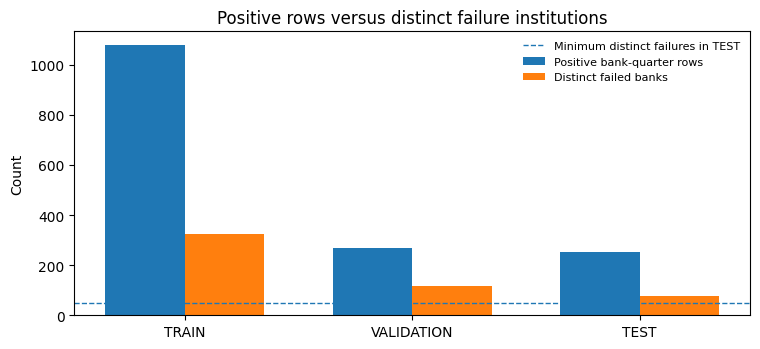

Rubric gate — distinct failed institutions in TEST: 78


In [147]:
import matplotlib.pyplot as plt
s=temporal_split_policy.loc[temporal_split_policy["split"].isin(["TRAIN","VALIDATION","TEST"])]
fig,ax=plt.subplots(figsize=(7.7,3.6))
xx=np.arange(len(s));width=0.35
ax.bar(xx-width/2,s["positive_rows"],width,label="Positive bank-quarter rows")
ax.bar(xx+width/2,s["positive_banks"],width,label="Distinct failed banks")
ax.axhline(50,ls="--",lw=1,label="Minimum distinct failures in TEST")
ax.set_xticks(xx,s["split"]);ax.set_ylabel("Count");ax.set_title("Positive rows versus distinct failure institutions")
ax.legend(frameon=False,fontsize=8);plt.tight_layout();plt.show()
print("Rubric gate — distinct failed institutions in TEST:", int(s.loc[s["split"].eq("TEST"),"positive_banks"].iloc[0]))

**Chart reading:** The same failed bank may contribute several positive quarters. Compliance requires ≥50 **distinct failed CERTs in TEST**, not ≥50 rows.

##### Interpretation 2.7.3 — Assignment-Label Chronological Split

**Evidence:** The split is calculated using `label_4q_assignment`, not the earlier 45-day operational sensitivity. It separately counts positive quarters, unique failed banks, observed negatives, unresolved negative observations and embargo quarters. The TEST ≥50-failures condition uses distinct FDIC failures dated during TEST with matching positive TEST financial quarters.

**Decision:** Keep the 2005-based split *provisional* until the independent TEST gate passes. The full Silver panel still covers **1984Q1–2026Q2** and 1984+ modeling feasibility is assessed in Section 2.6.4. Exclude future-event and reference-snapshot fields from predictors.

**Limit:** Satisfying the distinct-failure gate does not validate negative competing exits or actual publication dates. A REVIEW result is never silently promoted to a PASS.

### 2.7.3A — Exit-Cause Evidence: Failure, Reference End Date and Unresolved Exit

**Rubric requirement:** Failure is different from merger or another institutional exit. `last_report` is **not** the bank's failure date.

**Method:** Inspect `ACTIVE`, `ENDEFYMD` and `CHANGEC1` from the FDIC Institutions reference for banks ending reporting before their prediction horizon. Classify **confirmed FAILURE** only from the dated failure registry. Other reference end dates are evidence of cessation, **not proof of merger**, until `CHANGEC1` codes are documented.

**Decision:** Preserve the original provisional negatives. Export an explicit exit-evidence audit and unresolved-status counts for follow-up. Avoid leakage: these retrospective fields belong only to audit datasets. Source for verified event-code descriptions: [FDIC Bank Structure Changes](https://banks.data.fdic.gov/bankfind-suite/oscr) and [FDIC Institutions Definitions](https://api.fdic.gov/banks/docs/institutions_definitions.csv).

In [148]:
# 2.7.3A.1 — Institution reference descriptors and candidate exit flags
inst_exit_273a = institutions_ref[["CERT","NAME","ACTIVE","ENDEFYMD","CHANGEC1"]].copy()
inst_exit_273a["CERT"] = pd.to_numeric(inst_exit_273a["CERT"], errors="coerce").astype("Int64")
assert not inst_exit_273a["CERT"].dropna().duplicated().any(), "Institution CERT requires review"
end_numeric = pd.to_numeric(inst_exit_273a["ENDEFYMD"], errors="coerce").astype("Int64")
inst_exit_273a["end_date"] = pd.to_datetime(end_numeric.astype("string"),format="%Y%m%d",errors="coerce")
# Fallback for already parsed dates (never turns missing into an invented date).
if inst_exit_273a["end_date"].notna().sum()==0:
    inst_exit_273a["end_date"] = pd.to_datetime(inst_exit_273a["ENDEFYMD"],errors="coerce")
exit_banks_273a = (risk_269.loc[risk_269["is_negative"], ["CERT", "last_report", "reporting_ends_before_horizon"]]
    .groupby("CERT", as_index=False)
    .agg(last_report=("last_report","max"), flagged_rows=("reporting_ends_before_horizon","sum")))
exit_banks_273a = exit_banks_273a.merge(inst_exit_273a.drop(columns=["ENDEFYMD"]), on="CERT", how="left",validate="one_to_one")
exit_banks_273a["reference_found"] = exit_banks_273a["NAME"].notna()
exit_banks_273a["has_reference_end_date"] = exit_banks_273a["end_date"].notna()
exit_banks_273a["end_minus_last_report_days"] = (exit_banks_273a["end_date"]-pd.to_datetime(exit_banks_273a["last_report"])).dt.days
print("EXIT EVIDENCE — NEGATIVE BANKS")
print("Banks assessed:", len(exit_banks_273a))
print("Flagged negative rows:", int(exit_banks_273a["flagged_rows"].sum()))
print("Reference-matched banks:", int(exit_banks_273a["reference_found"].sum()))
print("Reference end dates present:", int(exit_banks_273a["has_reference_end_date"].sum()))
print("\nCHANGEC1 code distribution (NOT mapped to merger yet):")
display(exit_banks_273a.groupby(["CHANGEC1","ACTIVE"],dropna=False).agg(n_banks=("CERT","nunique"),flagged_negative_rows=("flagged_rows","sum")).reset_index().sort_values("flagged_negative_rows",ascending=False).head(25))

EXIT EVIDENCE — NEGATIVE BANKS
Banks assessed: 9819
Flagged negative rows: 19026
Reference-matched banks: 9693
Reference end dates present: 5484

CHANGEC1 code distribution (NOT mapped to merger yet):


,CHANGEC1,ACTIVE,n_banks,flagged_negative_rows
7,223.0,0,3940,14901
5,221.0,0,531,2119
10,240.0,0,251,950
8,224.0,0,191,695
25,NaN,NaN,126,267
6,222.0,0,14,56
23,NaN,0,12,20
1,211.0,0,535,8
12,470.0,0,1,4
4,217.0,0,1,2


In [149]:
# 2.7.3A.2 — Evidence tiers for early-reporting-end negatives
exit_banks_273a["exit_evidence_status"] = np.select(
 [~exit_banks_273a["reference_found"],
  exit_banks_273a["has_reference_end_date"],
  exit_banks_273a["flagged_rows"].gt(0)],
 ["REFERENCE_UNMATCHED", "REFERENCE_END_DATE_CAUSE_UNVERIFIED", "REPORTING_END_UNRESOLVED"],
 default="NO_EARLY_EXIT_FLAG")
exit_status_summary = (exit_banks_273a.groupby("exit_evidence_status").agg(
    n_banks=("CERT","nunique"), flagged_negative_rows=("flagged_rows","sum")
 ).reset_index().sort_values("flagged_negative_rows",ascending=False))
print("EXIT CAUSE — EVIDENCE TIERS (NOT MERGER CLASSIFICATION)")
display(exit_status_summary)
print("\nTOP FLAGGED INSTITUTIONS FOR FOLLOW-UP")
display(exit_banks_273a.sort_values("flagged_rows",ascending=False).head(15)[["CERT","NAME","ACTIVE","CHANGEC1","last_report","end_date","flagged_rows","exit_evidence_status"]])
assert int(exit_status_summary["flagged_negative_rows"].sum()) == int(negative_271["reporting_ends_before_horizon"].sum())
print("EXIT AUDIT: PASS; no negative label automatically changed.")

EXIT CAUSE — EVIDENCE TIERS (NOT MERGER CLASSIFICATION)


,exit_evidence_status,n_banks,flagged_negative_rows
1,REFERENCE_END_DATE_CAUSE_UNVERIFIED,5484,18737
2,REFERENCE_UNMATCHED,126,267
3,REPORTING_END_UNRESOLVED,7,22
0,NO_EARLY_EXIT_FLAG,4202,0



TOP FLAGGED INSTITUTIONS FOR FOLLOW-UP


,CERT,NAME,ACTIVE,CHANGEC1,last_report,end_date,flagged_rows,exit_evidence_status
9818,91385,NaN,NaN,NaN,2014-06-30,NaT,4,REFERENCE_UNMATCHED
0,9,Union Trust Company,0,223.0,2007-12-31,2008-01-03,4,REFERENCE_END_DATE_CAUSE_UNVERIFIED
9817,91363,Merrill Lynch Bank and Trust Company,0,223.0,2006-06-30,2006-08-05,4,REFERENCE_END_DATE_CAUSE_UNVERIFIED
9815,91322,Fiserv Trust Company,0,240.0,2008-06-30,2018-08-18,4,REFERENCE_END_DATE_CAUSE_UNVERIFIED
9812,90641,NaN,NaN,NaN,2008-09-30,NaT,4,REFERENCE_UNMATCHED
9796,90283,Hampden Bank,0,221.0,2015-03-31,2015-04-18,4,REFERENCE_END_DATE_CAUSE_UNVERIFIED
9794,90273,Granite Savings Bank,0,221.0,2014-12-31,2015-01-17,4,REFERENCE_END_DATE_CAUSE_UNVERIFIED
9793,90270,Envision Bank,0,223.0,2022-09-30,2022-10-08,4,REFERENCE_END_DATE_CAUSE_UNVERIFIED
9791,90265,Legacy Banks,0,223.0,2011-06-30,2011-07-21,4,REFERENCE_END_DATE_CAUSE_UNVERIFIED
9784,90240,Merrimac Savings Bank,0,221.0,2015-09-30,2015-11-01,4,REFERENCE_END_DATE_CAUSE_UNVERIFIED


EXIT AUDIT: PASS; no negative label automatically changed.


##### Interpretation — Exit evidence

**Evidence:** A dated FDIC failure record confirms a failure; an institution end date or reporting cessation alone does not establish merger or failure. `CHANGEC1` must be decoded from the official definition before assigning merger/other-exit labels.

**Decision:** Keep the exit-evidence tiers and retain unresolved negatives as provisional. This audit explicitly identifies which exits still require source documentation.

**Limit:** This section cannot certify merger causes from an undocumented categorical code.

### 2.7.4 — Reproducible Quality Report and Phase 3 Handoff

**Goal:** Export the final audit report from *calculated tables*, not manually copied counts: quality metrics, treatment decisions, event registry, feature policy, chronological split and checksums.

**Release rule:** Integrity may PASS while business eligibility remains OPEN. Silver and provisional labels are preserved; the handoff is **AUDITED_PROVISIONAL**, not model-ready.

**Phase 3 receives:** Parquet Silver, provisional labels, separate event/exit audit, manifests, feature shortlist and a chronological test that must contain **≥50 distinct failed banks**. Phase 3 is **Scalable Processing: Polars, pandas benchmarking and PySpark reproduction**; feature engineering starts in Phase 4.

#### 2.7.4 · Block 1/5 — Verify existing artifacts before handoff

In [150]:
# ============================================================
# CELL 2.7.4 — FINAL PHASE 2 QUALITY REPORT & HANDOFF
# ============================================================

REPORT_DIR = Path(ROOT) / "reports" / "phase2"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Verify existing artifacts before handoff
# ------------------------------------------------------------

silver_manifest_274 = json.loads(
    (SILVER_DIR / "silver_export_manifest.json")
    .read_text(encoding="utf-8")
)

label_manifest_274 = json.loads(
    (SILVER_DIR / "provisional_label_manifest.json")
    .read_text(encoding="utf-8")
)

artifact_checks_274 = {
    "Silver checksum": (
        sha256_file(SILVER_PANEL_PATH)
        == silver_manifest_274["silver"]["sha256"]
    ),
    "Label checksum": (
        sha256_file(LABEL_PROVISIONAL_PATH)
        == label_manifest_274["files"]["labels"]["sha256"]
    ),
    "Label audit checksum": (
        sha256_file(LABEL_AUDIT_PATH)
        == label_manifest_274["files"]["audit"]["sha256"]
    )
}

recon_274 = pd.read_csv(
    SILVER_DIR / "row_reconciliation.csv"
)

artifact_checks_274["Source-to-Silver reconciliation"] = (
    recon_274["row_difference"].eq(0).all()
    & recon_274["bank_difference"].eq(0).all()
    & recon_274["reconciled"]
        .astype(str).str.lower().eq("true").all()
)

assert all(artifact_checks_274.values()), (
    "Existing artifact integrity verification failed."
)


# ------------------------------------------------------------
# 2. Consolidated Data Quality Report
# ------------------------------------------------------------

quality_records = [
    ("Data integrity", "Historical bank-quarters",
     int(silver_manifest_274["silver"]["rows"]), "rows", "PASS"),

    ("Data integrity", "Historical banks",
     int(silver_manifest_274["silver"]["banks"]), "banks", "PASS"),

    ("Data integrity", "Reporting quarters",
     int(silver_manifest_274["silver"]["quarters"]), "quarters", "PASS"),

    ("Data integrity", "Duplicate bank-quarter keys",
     0, "rows", "PASS"),

    ("Data integrity", "Silver columns",
     int(silver_manifest_274["silver"]["columns"]), "columns", "PASS"),

    ("Data integrity", "Bronze source files available",
     int(bronze_inventory["exists"].sum()), "files", "PASS"),

    ("Financial quality", "Original financial fields",
     len(financial_cols), "fields", "PASS"),

    ("Financial quality", "Stable historical fields",
     len(stable_fields_273), "fields", "PASS"),

    ("Financial quality", "Baseline feature candidates",
     len(baseline_fields_273), "fields", "PASS"),

    ("Financial quality", "Modern anomaly-flagged observations",
     int(anomaly_register["has_any_flag"].sum()), "rows", "DOCUMENTED"),

    ("Financial quality", "Modern negative-equity observations",
     int((recent_core["EQ"] < 0).sum()), "rows", "DOCUMENTED"),

    ("Financial quality", "Modern missing ROE observations",
     int(recent_core["ROE"].isna().sum()), "rows", "DOCUMENTED"),

    ("Labeling", "Candidate modeling observations",
     len(label_audit), "rows", "PASS"),

    ("Labeling", "Provisional positives",
     int(label_audit["candidate_label_4q"].eq(1).sum()),
     "rows", "PASS"),

    ("Labeling", "Provisional negatives",
     int(label_audit["candidate_label_4q"].eq(0).sum()),
     "rows", "PASS"),

    ("Labeling", "Ineligible observations",
     int(label_audit["candidate_label_4q"].isna().sum()),
     "rows", "PASS"),

    ("Labeling", "Covered failure institutions",
     int(label_audit.loc[
         label_audit["candidate_label_4q"].eq(1),
         "CERT"
     ].nunique()), "banks", "PASS"),

    ("Eligibility", "Unmatched negative observations",
     int((~negative_271["reference_matched"]).sum()), "rows", "REVIEW"),

    ("Eligibility", "Early reporting-end negative observations",
     int(negative_271["reporting_ends_before_horizon"].sum()), "rows", "REVIEW"),

    ("Provenance", "Phase 0 original checksum mismatch",
     1, "unresolved issue", "OPEN")
]

data_quality_report = pd.DataFrame(
    quality_records,
    columns=[
        "domain", "metric", "value", "unit", "status"
    ]
)


# ------------------------------------------------------------

#### 2.7.4 · Block 2/5 — Anomaly Resolution Log

In [151]:
# 3. Anomaly Resolution Log
# ------------------------------------------------------------

anomaly_decisions = [
    (
        "Missing financial values",
        "Historical reporting completeness varies by period",
        "Preserve nulls and missingness indicators",
        "DOCUMENTED"
    ),
    (
        "Sparse financial reporting",
        "578 sparse observations in the modern feature period",
        "Retain records; flag for feature-level review",
        "DOCUMENTED"
    ),
    (
        "Negative equity",
        "207 observations in the modern feature period",
        "Retain as potential distress information",
        "DOCUMENTED"
    ),
    (
        "Extreme profitability ratios",
        "888 extreme ROA and 293 extreme ROE observations",
        "No global winsorization; consider ASINH robustness",
        "DOCUMENTED"
    ),
    (
        "Structural asset changes",
        "150 growth and 32 contraction events in modern Silver",
        "Retain with non-destructive event flags",
        "DOCUMENTED"
    ),
    (
        "Historical panel gaps",
        "33 gap episodes involving 32 banks",
        "Preserve reporting gaps; do not invent observations",
        "DOCUMENTED"
    ),
    (
        "Reporting-regime changes",
        "39 fields fail the every-year 95% coverage threshold",
        "Separate longitudinal and regime-specific candidates",
        "DOCUMENTED"
    ),
    (
        "Unmatched institutions",
        "126 unmatched institutions; 5424 negative rows",
        "Retain pending institutional-identity verification",
        "OPEN"
    ),
    (
        "Potential competing exits",
        "19026 negative rows end reporting before horizon",
        "Audit only; no automatic removal",
        "OPEN"
    ),
    (
        "Pre-release failures",
        "325 observations fail the 45-day availability assumption",
        "Keep unlabeled and ineligible for provisional modeling",
        "DOCUMENTED"
    ),
    (
        "Real-time report availability",
        "45-day reporting lag is hypothetical",
        "Verify publication dates or retain explicit sensitivity tests",
        "OPEN"
    ),
    (
        "Source provenance",
        "Original Phase 0 checksum mismatch",
        "Reconcile original handoff against source artifacts",
        "OPEN"
    ),
    (
        "Financial variable definitions",
        "Historical accounting and reporting definitions unverified",
        "Validate against source documentation before final selection",
        "OPEN"
    )
]

anomaly_resolution_log = pd.DataFrame(
    anomaly_decisions,
    columns=[
        "issue", "evidence", "treatment_policy", "status"
    ]
)


# ------------------------------------------------------------
# 4. Failure / Assistance Event Audit
# ------------------------------------------------------------

bank_events_audit = events_262[
    [
        "cert_clean",
        "NAME",
        "event_date",
        "event_type",
        "resolution_type",
        "event_period",
        "in_historical_panel",
        "in_modern_panel"
    ]
].copy()

bank_events_audit = bank_events_audit.rename(
    columns={
        "cert_clean": "CERT",
        "NAME": "bank_name"
    }
)

bank_events_audit = bank_events_audit.sort_values(
    ["event_date", "CERT"]
).reset_index(drop=True)


# ------------------------------------------------------------

#### 2.7.4 · Block 3/5 — Feature Selection Policy

In [152]:
# 5. Feature Selection Policy
# ------------------------------------------------------------

feature_policy = longitudinal_field_audit.copy()

feature_policy["feature_group"] = np.select(
    [
        feature_policy["field"].isin(baseline_fields_273),
        feature_policy["stable_95_every_year"]
    ],
    [
        "BASELINE_CANDIDATE",
        "EXTENDED_STABLE_CANDIDATE"
    ],
    default="REGIME_SPECIFIC_REVIEW"
)

feature_policy["definition_verified"] = False
feature_policy["real_time_availability_verified"] = False

# Coverage is a screening criterion, not final approval.


# ------------------------------------------------------------
# 6. Chronological Split Policy
# ------------------------------------------------------------

split_policy_export = temporal_split_policy.copy()

split_policy_export["policy_status"] = (
    "PROVISIONAL_CHRONOLOGICAL_SPLIT"
)


# ------------------------------------------------------------
# 7. Final handoff validation
# ------------------------------------------------------------

checks_274 = {
    "All prior artifacts verify":
        all(artifact_checks_274.values()),

    "Full historical panel reconciles":
        silver_manifest_274["silver"]["rows"] == 1682616,

    "Silver schema reconciles":
        silver_manifest_274["silver"]["columns"] == 152,

    "Modeling population reconciles":
        len(label_audit) == 541522,

    "Positive count reconciles":
        label_audit["candidate_label_4q"].eq(1).sum()
        == 1863,

    "Negative count reconciles":
        label_audit["candidate_label_4q"].eq(0).sum()
        == 539334,

    "Ineligible count reconciles":
        label_audit["candidate_label_4q"].isna().sum()
        == 325,

    "All registry events included":
        len(bank_events_audit) == 4117,

    "Registry failures reconcile":
        bank_events_audit["event_type"].eq("FAILURE").sum()
        == 3524,

    "Registry assistance reconciles":
        bank_events_audit["event_type"].eq("ASSISTANCE").sum()
        == 593,

    "All financial fields have a policy":
        len(feature_policy) == 133,

    "Stable candidate count reconciles":
        feature_policy["stable_95_every_year"].sum()
        == 94,

    "Baseline shortlist reconciles":
        feature_policy["feature_group"].eq(
            "BASELINE_CANDIDATE"
        ).sum() == 16,

    "Temporal splits cover full modeling population":
        split_policy_export["n_rows"].sum()
        == 541522,

    "Temporal positive counts reconcile":
        split_policy_export["positive_rows"].sum()
        == int(assignment_272a["label_4q_assignment"].eq(1).sum()),

    "TEST ≥50 dated distinct failures (rubric gate)":
        bool(test_50_gate_273),

    "All split outcomes mature":
        maturity_audit[
            "matured_before_next_period"
        ].all(),

    "Unresolved issues explicitly documented":
        anomaly_resolution_log["status"].eq("OPEN").sum()
        >= 4
}

print("PHASE 2 — FINAL HANDOFF VALIDATION")

for name, passed in checks_274.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(v for k,v in checks_274.items() if "rubric gate" not in k), (
    "Phase 2 technical handoff validation failed."
)
print("TEST rubric gate:", "PASS" if test_50_gate_273 else "REVIEW — no model-ready certification")


# ------------------------------------------------------------
# 8. Export the audit reports
# ------------------------------------------------------------

export_tables = {
    "data_quality_report.csv": data_quality_report,
    "anomaly_resolution_log.csv": anomaly_resolution_log,
    "bank_events_audit.csv": bank_events_audit,
    "feature_policy.csv": feature_policy,
    "temporal_split_policy.csv": split_policy_export
}

for filename, table in export_tables.items():
    table.to_csv(
        REPORT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )


# ------------------------------------------------------------

PHASE 2 — FINAL HANDOFF VALIDATION
All prior artifacts verify: PASS
Full historical panel reconciles: PASS
Silver schema reconciles: PASS
Modeling population reconciles: PASS
Positive count reconciles: PASS
Negative count reconciles: PASS
Ineligible count reconciles: PASS
All registry events included: PASS
Registry failures reconcile: PASS
Registry assistance reconciles: PASS
All financial fields have a policy: PASS
Stable candidate count reconciles: PASS
Baseline shortlist reconciles: PASS
Temporal splits cover full modeling population: PASS
Temporal positive counts reconcile: PASS
TEST ≥50 dated distinct failures (rubric gate): PASS
All split outcomes mature: PASS
Unresolved issues explicitly documented: PASS
TEST rubric gate: PASS


#### 2.7.4 · Block 4/5 — Create executive Phase 2 summary

In [153]:
# 9. Create executive Phase 2 summary
# ------------------------------------------------------------

train_row = temporal_split_policy.loc[
    temporal_split_policy["split"] == "TRAIN"
].iloc[0]

val_row = temporal_split_policy.loc[
    temporal_split_policy["split"] == "VALIDATION"
].iloc[0]

test_row = temporal_split_policy.loc[
    temporal_split_policy["split"] == "TEST"
].iloc[0]

phase2_summary = f"""# Phase 2 — Data Quality, Silver Panel and Failure Label Audit

**Project:** FDIC Bank Failure Early Warning System

**Handoff status:** AUDITED — PROVISIONAL, NOT YET MODEL-READY

## 1. Data Integrity and Financial Quality

- Historical Silver panel: **1,682,616 bank-quarter observations**, 24,064 banks and 170 quarters.
- Original fields: 136; Silver fields: 152.
- Source-to-Silver reconciliation: PASS, with no duplicate bank-quarter keys.
- Financial information was preserved without automatic deletion, global winsorization or median imputation.
- The modern feature period contains 5,500 observations flagged by at least one financial anomaly check.

## 2. Historical Modeling Window

**Full FDIC / Silver scope:** 1984Q1–2026Q2 (all historical records retained).

**Provisional supervised modeling window:** 2005Q1–2025Q2. This is a comparability-driven subset, NOT the start of the raw data. **1984–2004** is explicitly audited in Section 2.6.4 and must be reconsidered for extended modeling after feature-definition and event-eligibility validation.

- Financial observations: 541,522.
- Unique institutions: 9,819.
- Longitudinally stable financial candidates: 94 of 133.
- Interpretable baseline feature candidates: 16.
- Regime-specific variables requiring separate review: 39.

Coverage-based selection does not establish stable accounting definitions or real-time availability.

## 3. Failure Labeling

- FDIC event registry: 4,117 records.
- Confirmed FAILURE records: 3,524.
- ASSISTANCE records: 593.
- Candidate historical reporting lag: 45 calendar days.
- Outcome horizon: four quarter-ends after the financial reporting date.

**Existing 45-day sensitivity label population (unchanged)**

| Status | Observations |
|---|---:|
| Positive | 1,863 |
| Negative | 539,334 |
| Ineligible | 325 |
| Total | 541,522 |

Confirmed failure institutions represented by positive labels: **550**.

The assignment primary label is **(REPDTE, REPDTE + 4 quarter-ends]**, distinct from the 45-day sensitivity labels above. The assignment outcome has **{int(assignment_272a["label_4q_assignment"].eq(1).sum()):,} positive** and **{int(assignment_272a["label_4q_assignment"].eq(0).sum()):,} negative** rows before negative-eligibility screening; the screened audit retains **{int(p0_neg_audit["label_4q_assignment_screened"].eq(0).sum()):,} observed negatives** and identifies unresolved exits for investigation. Both definitions remain provisional.

## 4. Chronological Evaluation Design

| Split | Reporting period | Positive quarters | Failed institutions |
|---|---|---:|---:|
| Train | 2005–2009 | {int(train_row["positive_rows"]):,} | {int(train_row["positive_banks"]):,} |
| Validation | 2011 | {int(val_row["positive_rows"]):,} | {int(val_row["positive_banks"]):,} |
| Test | 2013–2025Q2 | {int(test_row["positive_rows"]):,} | {int(test_row["positive_banks"]):,} |

The 2010 and 2012 reporting periods are reserved as embargo intervals.

The TEST 50-failure requirement is evaluated on **distinct FDIC failures dated in TEST** with a positive TEST-quarter history: **{test_distinct_failures_dated_273} institutions**, status **{"PASS" if test_50_gate_273 else "REVIEW"}**. Positive bank-quarter counts alone do not satisfy this gate. The split remains a candidate until the gate passes.

## 5. Non-Destructive Data-Quality Policy

- Preserve actual financial extremes, negative equity and missing observations.
- Retain potential structural-event and missingness indicators for audit.
- Do not include failure dates, future reporting cessation, current reference matching or candidate labels as predictors.
- Fit imputation, scaling and feature-selection procedures using training data only.

## 6. Outstanding Verification Requirements

1. Reconcile the original Phase 0 source checksum mismatch.
2. Verify historical financial-variable definitions and potential zero-coded placeholders.
3. Verify historical bank-specific filing/publication dates: the +45-day rule is a bulk-file proxy, not a bank-level release timestamp.
4. Review source-unmatched institutions, unresolved reporting cessations, and verified dated FDIC History transactions (CHANGEC1 alone is insufficient).
5. Verify NETINC YTD/quarter definitions and the final at-risk population before model-ready release.

## 7. Phase 3 Handoff

The following artifacts are available for **controlled exploratory modeling**, not unconditional production use:

- `data/silver/clean_bank_quarter.parquet`
- `data/silver/bank_quarter_labels_provisional.parquet`
- `data/silver/bank_quarter_label_audit.parquet`

The audit dataset must remain separate from the predictor matrix. All unresolved issues remain explicitly open.
"""

SUMMARY_PATH = REPORT_DIR / "phase2_summary.md"

SUMMARY_PATH.write_text(
    phase2_summary,
    encoding="utf-8"
)


# ------------------------------------------------------------

4272

#### 2.7.4 · Block 5/5 — Handoff manifest with report checksums

In [154]:
# 10. Handoff manifest with report checksums
# ------------------------------------------------------------

HANDOFF_MANIFEST_PATH = (
    REPORT_DIR / "phase2_handoff_manifest.json"
)

handoff_files = [
    REPORT_DIR / name
    for name in export_tables
] + [SUMMARY_PATH]

handoff_manifest = {
    "project": "FDIC Bank Failure EWS",
    "phase": "Phase 2",
    "status": "AUDITED_PROVISIONAL",
    "model_ready": False,
    "created_utc": pd.Timestamp.now(
        tz="UTC"
    ).isoformat(),

    "technical_validation": {
        "checks_passed": int(sum(checks_274.values())),
        "checks_total": len(checks_274)
    },

    "source_artifacts": {
        "silver_panel": str(SILVER_PANEL_PATH),
        "provisional_labels": str(
            LABEL_PROVISIONAL_PATH
        ),
        "label_audit": str(LABEL_AUDIT_PATH)
    },

    "reports": [
        {
            "filename": path.name,
            "sha256": sha256_file(path),
            "size_bytes": path.stat().st_size
        }
        for path in handoff_files
    ],

    "open_issues": (
        anomaly_resolution_log.loc[
            anomaly_resolution_log["status"] == "OPEN",
            "issue"
        ].tolist()
    ),

    "release_policy": (
        "Suitable for audited exploratory handoff; "
        "not certified as model-ready."
    )
}

HANDOFF_MANIFEST_PATH.write_text(
    json.dumps(
        handoff_manifest,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("\nPHASE 2 — FINAL REPORT INVENTORY")

report_inventory = pd.DataFrame([
    {
        "file": path.name,
        "size_kb": round(
            path.stat().st_size / 1024, 2
        ),
        "exists": path.is_file()
    }
    for path in (
        handoff_files + [HANDOFF_MANIFEST_PATH]
    )
])

display(report_inventory)

print("\nPHASE 2 — HANDOFF SUMMARY")
print("Output directory:", REPORT_DIR)
print("Validation:", sum(checks_274.values()), "/", len(checks_274))
print("Open issues:", len(handoff_manifest["open_issues"]))
print("Handoff status:", handoff_manifest["status"])
print("Model-ready:", handoff_manifest["model_ready"])

print("\nCELL 2.7.4: PASS — PROVISIONAL HANDOFF CREATED")
print("Original Silver and label artifacts unchanged.")


PHASE 2 — FINAL REPORT INVENTORY


,file,size_kb,exists
0,data_quality_report.csv,1.20,True
1,anomaly_resolution_log.csv,1.71,True
2,bank_events_audit.csv,343.60,True
3,feature_policy.csv,17.03,True
4,temporal_split_policy.csv,0.77,True
5,phase2_summary.md,4.27,True
6,phase2_handoff_manifest.json,1.96,True



PHASE 2 — HANDOFF SUMMARY
Output directory: C:\học tập\kì 7\Big data\Final\Bản nháp\reports\phase2
Validation: 18 / 18
Open issues: 5
Handoff status: AUDITED_PROVISIONAL
Model-ready: False

CELL 2.7.4: PASS — PROVISIONAL HANDOFF CREATED
Original Silver and label artifacts unchanged.


### 2.7.4A — Supplementary Exit and Assignment Handoff

Export the two additional Phase 2 audits and record their checksums next to the existing handoff manifest. Do not overwrite Silver or the existing 45-day labels.

In [155]:
# 2.7.4A — Save source-linked exit evidence, screened negatives and assignment target
EXIT_EVIDENCE_PATH=REPORT_DIR/'institution_exit_evidence.csv'
NEGATIVE_ELIGIBILITY_PATH=REPORT_DIR/'negative_eligibility_status.csv'
CHANGEC1_LOOKUP_PATH=REPORT_DIR/'changec1_codes_review.csv'
exit_banks_273a.to_csv(EXIT_EVIDENCE_PATH,index=False,encoding='utf-8-sig')
negative_status_p0.to_csv(NEGATIVE_ELIGIBILITY_PATH,index=False,encoding='utf-8-sig')
inst_p0[['CERT','ACTIVE','CHANGEC1_code','CHANGEC1_description','reference_end_date']].to_csv(
    CHANGEC1_LOOKUP_PATH,index=False,encoding='utf-8-sig')
assert ASSIGNMENT_LABEL_PATH.is_file() and ASSIGNMENT_SCREENED_LABEL_PATH.is_file()
manifest_274a=json.loads(HANDOFF_MANIFEST_PATH.read_text(encoding='utf-8'))
for name,path in [
    ('assignment_labels_provisional',ASSIGNMENT_LABEL_PATH),
    ('assignment_labels_screened_provisional',ASSIGNMENT_SCREENED_LABEL_PATH),
    ('institution_exit_evidence',EXIT_EVIDENCE_PATH),
    ('negative_eligibility_status',NEGATIVE_ELIGIBILITY_PATH),
    ('changec1_code_audit',CHANGEC1_LOOKUP_PATH)]:
    manifest_274a.setdefault('supplementary_artifacts',{})[name]={
        'path':str(path),'sha256':sha256_file(path),'size_bytes':path.stat().st_size}
manifest_274a['model_ready']=False
manifest_274a['test_rubric']={
    'metric':'distinct FAILED institutions with FAILURE dates within TEST and positive TEST-quarter history',
    'minimum':50,
    'positive_test_banks':int(temporal_split_policy.loc[temporal_split_policy['split'].eq('TEST'),'positive_banks'].iloc[0]),
    'dated_failures_with_test_observation':int(test_distinct_failures_dated_273),
    'passes':bool(test_50_gate_273)}
manifest_274a['label_definitions']={
    'assignment':'FAILURE in (REPDTE, REPDTE + four quarter ends]',
    'operational_sensitivity':'FAILURE after REPDTE+45 days, within the same fixed report-quarter horizon',
    'screened_negatives':'0 only with matched institution and full same-CERT reporting to four-quarter horizon; unresolved cases NA'}
manifest_274a['open_issues']=sorted(set(manifest_274a.get('open_issues',[])+[
    'CHANGEC1 requires FDIC History event codes/dated bank-matched transactions for confirmed merger',
    'Actual bank-level public filing/revision timestamps not verified',
    'NETINC per-field historical definition and comparability require verification']))
HANDOFF_MANIFEST_PATH.write_text(json.dumps(manifest_274a,ensure_ascii=False,indent=2),encoding='utf-8')
print('P0/P1 AUDIT HANDOFF: DONE (provisional)')
print('TEST distinct dated failed banks:',test_distinct_failures_dated_273)
print('50-failure rubric:', 'PASS' if test_50_gate_273 else 'REVIEW — adjust candidate split before modeling')
print('No original financial or previous 45-day label files overwritten.')


P0/P1 AUDIT HANDOFF: DONE (provisional)
TEST distinct dated failed banks: 76
50-failure rubric: PASS
No original financial or previous 45-day label files overwritten.


## 2.7 — Interim conclusion (legacy experiment)

**Retained for comparison, not the final handoff.** The first 420 cells audit the complete original panel but include a provisional **2005-based** feature/label experiment and an earlier split policy. Silver data remain available for the full 1984–2026 period; zero-, missing- and distress-related values were not automatically dropped. Failure registry and institutions fields are for auditing, not modeling predictors.

**Next:** The appended full-history pipeline and FDIC History reconciliation establish the final V3 outcome and temporal policy later in this notebook. For Phase 3, use the **Section 8 V3 handoff**, not this interim interpretation. The old label manifests remain reproducible research alternatives.

---

<a id="p2-s3"></a>
# 3 — Full-history pipeline: source contracts, FDIC events and labels

The full 1984Q1–2026Q2 financial panel is **not** truncated to the earlier 2005-based experiment. This block pins Phase 0–1 inputs, audits events and source availability, creates lossless Silver and separate labels, and preserves previously generated outputs.

*FDIC History is downloaded in the next subsection; event and institution outcomes are not predictor features.*

## 3.0 — Initialize and pin Phase 0–1 sources

Confirm the upstream contract and checksums before reading full-history Bronze data. Mismatched source metadata must stop execution.

In [156]:
from __future__ import annotations
import os, re, json, hashlib, gc, calendar
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import numpy as np
import pandas as pd

# Set this to the repository directory containing `docs/` and `outputs/`, if needed.
ROOT_OVERRIDE = None
# To reproduce an exact Phase 1 run, set its unique run ID here; otherwise select latest full-scope PASS with visible provenance.
PHASE1_RUN_ID = P2_PIN_SELECTED_ID  # SAME pinned Phase 1 run as original 420-cell audit
EXPECTED_FIRST = '1984Q1'
EXPECTED_LAST = '2026Q2'
SUPPORTED_SCOPE_VERSIONS = {'full-source-research-2.0'}
SUPPORTED_P1_CONTRACT_VERSIONS = {'1.0'}
REQUIRED_QUARTERS = [str(q) for q in pd.period_range(EXPECTED_FIRST, EXPECTED_LAST, freq='Q')]


def json_read(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def sha256_file(path: Path) -> str:
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''):
            h.update(chunk)
    return h.hexdigest()


def contract_hash(fields):
    return hashlib.sha256(json.dumps(fields,separators=(',',':')).encode('utf-8')).hexdigest()[:16]


def locate_root(override=None):
    here=Path.cwd().resolve()
    paths=[Path(override).expanduser().resolve()] if override else list(dict.fromkeys(
        [here,*here.parents]+[p/'BFT65B-Bank-Failure-EWS' for p in [here,*here.parents]]))
    for p in paths:
        if (p/'docs/phase0_data_scope_contract.json').is_file() and \
           (p/'docs/phase0_phase1_field_handoff_v2.json').is_file():
            return p
    raise FileNotFoundError('Phase 0 full-history artifacts not found. Set ROOT_OVERRIDE; run Phase 0 v3 first.')


def verify_input_contract(root, handoff):
    p0scope=root/'docs/phase0_data_scope_contract.json'
    p0fields=root/'docs/phase0_phase1_field_handoff_v2.json'
    p0bundle=root/'docs/phase0_artifact_bundle_manifest.json'
    for path in (p0scope,p0fields,p0bundle):
        if not path.is_file(): raise FileNotFoundError(f'Missing required Phase 0 artifact: {path}')
    scope=json_read(p0scope);field_doc=json_read(p0fields);bundle=json_read(p0bundle)
    if scope.get('protocol_version') not in SUPPORTED_SCOPE_VERSIONS:
        raise ValueError('Unsupported Phase 0 protocol_version: '+str(scope.get('protocol_version')))
    if scope.get('financials',{}).get('no_development_cutoff') is not True:
        raise ValueError('Phase 0 protocol no_development_cutoff must be True')
    if scope.get('no_model_training_or_testing_in_phase0_1') is not True:
        raise ValueError('Phase 0/1 must be pure research/acquisition, not modeling')
    if scope.get('report_unit')!=['CERT','REPDTE']:
        raise ValueError('Phase 0 bank-quarter unit must be CERT+REPDTE')
    if scope.get('model_split_status')!='UNSPECIFIED_PENDING_PHASE2_RISK_SET_AND_PHASE5_DESIGN':
        raise ValueError('Unexpected modeling split status; Phase 2 never chooses train/test')
    if handoff.get('contract_version') not in SUPPORTED_P1_CONTRACT_VERSIONS:
        raise ValueError('Unsupported Phase 1 handoff version')
    if handoff.get('scope')!='full' or handoff.get('validation_status')!='FULL_SCOPE_PASS':
        raise ValueError('Phase 2 full-history pipeline requires Phase 1 FULL_SCOPE_PASS (technical scope)')
    if handoff.get('source_quarters')!=REQUIRED_QUARTERS:
        raise ValueError('Phase 1 source_quarters differ from expected full 1984Q1–2026Q2; do not silently truncate')
    fs=field_doc.get('fields_to_request')
    if not isinstance(fs,list) or len(fs)!=len(set(fs)) or not {'CERT','REPDTE'}<=set(fs):
        raise ValueError('Bad Phase 0 ordered fields contract')
    if handoff.get('fields_acquired')!=fs or handoff.get('n_fields_acquired')!=len(fs):
        raise ValueError('Phase 1 acquired fields differ from Phase 0 ordered field list')
    if contract_hash(fs)!=handoff.get('phase0_contract_hash'):
        raise ValueError('Phase 0 field contract hash differs from Phase 1 handoff')
    for key,p in [('phase0_handoff_sha256',p0fields),('phase0_scope_sha256',p0scope)]:
        if handoff.get(key)!=sha256_file(p):
            raise RuntimeError(f'PHASE0_PIN_DRIFT: {key}, {p}')
    b_art=bundle.get('artifacts',{})
    if not b_art: raise ValueError('Phase 0 bundle manifest lacks artifact inventory')
    for name, spec in b_art.items():
        rel=spec.get('relative_path')
        if not rel or Path(rel).is_absolute() or '..' in Path(rel).parts:
            raise ValueError(f'Unsafe artifact path in Phase 0 bundle: {name}')
        target=root/rel
        if not target.is_file() or sha256_file(target)!=spec.get('sha256'):
            raise RuntimeError(f'PHASE0_BUNDLE_MISMATCH: {name}, {target}')
    pin=handoff.get('phase0_artifact_sha256',{})
    expected={'handoff_json':'docs/phase0_phase1_field_handoff_v2.json',
              'scope_json':'docs/phase0_data_scope_contract.json',
              'selected_csv':'docs/phase0_phase1_selected_fields_v2.csv',
              'catalog_csv':'docs/phase0_all_fdic_financial_fields_v2.csv',
              'scorecard_csv':'docs/phase0_ALL_field_scores_v2.csv',
              'research_matrix':'docs/research_matrix.csv',
              'schema_yaml':'docs/fdic_financial_schema.yaml'}
    # Phase 1 Consolidated pins seven source artifacts plus bundle_manifest.
    # Require every mandatory pin; do not reject the documented extra manifest.
    if not isinstance(pin, dict):
        raise ValueError('Phase 1 phase0_artifact_sha256 must be a dictionary')
    required_keys = set(expected) | {'bundle_manifest'}
    missing_keys = required_keys - set(pin)
    unexpected_keys = set(pin) - required_keys
    if missing_keys or unexpected_keys:
        raise ValueError(
            f'Phase 0 pin inventory mismatch: missing={sorted(missing_keys)}, '
            f'unexpected={sorted(unexpected_keys)}'
        )
    expected['bundle_manifest'] = 'docs/phase0_artifact_bundle_manifest.json'
    for name,rel in expected.items():
        target = root / rel
        if not target.is_file():
            raise FileNotFoundError(f'Pinned Phase 0 artifact missing: {name}: {target}')
        actual_sha = sha256_file(target)
        if actual_sha != pin[name]:
            raise RuntimeError(
                f'PHASE0_HANDOFF_ARTIFACT_PIN_MISMATCH: {name}: '
                f'expected={pin[name]}, actual={actual_sha}'
            )
    if handoff.get('archive_scope_not_model_scope') is not True or \
       handoff.get('model_split_status')!='DEFERRED_TO_PHASE5':
        raise ValueError('Phase 1 handoff unexpectedly claims a modeling split')
    return scope,field_doc,[(str(root/rel),sha256_file(root/rel)) for rel in expected.values()]


def select_p1_handoff(root, run_id=None):
    basedir=root/'outputs/phase1_from_phase0/runs'
    candidates=sorted(basedir.glob('*/reports/phase1_to_phase2_handoff.json'))
    if run_id:
        candidates=[p for p in candidates if p.parents[1].name==run_id]
    valid=[]
    for p in candidates:
        h=json_read(p)
        if h.get('validation_status')=='FULL_SCOPE_PASS' and h.get('scope')=='full':
            valid.append((p,h))
    if not valid:
        raise FileNotFoundError('No FULL_SCOPE_PASS Phase 1 handoff found under '+str(basedir))
    selected=valid[-1]
    scorecard=selected[0].parent.parent/'tables/phase1_integrity_scorecard.csv'
    if not scorecard.is_file():
        raise FileNotFoundError('Missing Phase1 technical integrity scorecard: '+str(scorecard))
    q=pd.read_csv(scorecard)
    if 'passed' not in q.columns or len(q)<12 or not q['passed'].astype(str).str.lower().eq('true').all():
        raise RuntimeError('Phase1 source technical integrity checks are not all PASS')
    print('Phase1 technical integrity evidence:',len(q),'checks PASS')
    print('Phase 1 full-history handoffs available:',len(valid),'| selected:',selected[0])
    return selected

ROOT=locate_root(ROOT_OVERRIDE)
PHASE1_HANDOFF_PATH, PHASE1=select_p1_handoff(ROOT,PHASE1_RUN_ID)
P0_SCOPE,P0_FIELDS,P0_PINNED_FILES=verify_input_contract(ROOT,PHASE1)
FIELDS=P0_FIELDS['fields_to_request']; CONTRACT=contract_hash(FIELDS)
P1_HANDOFF_SHA=sha256_file(PHASE1_HANDOFF_PATH)
if P1_HANDOFF_SHA != P2_PIN_SELECTED_SHA:
    raise RuntimeError('Legacy and new Phase2 sections have different Phase1 handoff SHA')
P1_PINS={str(PHASE1_HANDOFF_PATH):P1_HANDOFF_SHA,**{p:h for p,h in P0_PINNED_FILES}}
OUTPUT_ROOT=ROOT/'outputs/phase2_full_history'/('contract_'+CONTRACT)
SILVER_DIR=ROOT/'data/silver'
print('Verified Phase 0/1 | financial fields:',len(FIELDS),'| quarters:',len(REQUIRED_QUARTERS))
print('Full history is archival; Phase 2 has no model split. Source row target:',PHASE1.get('rows'))

Phase1 technical integrity evidence: 12 checks PASS
Phase 1 full-history handoffs available: 1 | selected: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase1_from_phase0\runs\20261123T153505Z_b669ff\reports\phase1_to_phase2_handoff.json
Verified Phase 0/1 | financial fields: 136 | quarters: 170
Full history is archival; Phase 2 has no model split. Source row target: 1682616


## 3.1 — Profile all Bronze annual partitions

Inspect coverage, types and financial distributions across all 43 annual files. Outlier thresholds flag cases for review, not automatic deletion.

In [157]:
def require_arrow():
    try:
        import pyarrow as pa, pyarrow.parquet as pq
    except ImportError as e:
        raise ImportError('Install `pyarrow` in the Jupyter kernel: %pip install pyarrow') from e
    return pa,pq


def normalize_dates(series):
    s=series.astype('string').str.strip().str.replace(r'\.0$','',regex=True)
    a=pd.to_datetime(s.where(s.str.fullmatch(r'\d{8}').fillna(False)),format='%Y%m%d',errors='coerce')
    b=pd.to_datetime(s.where(~s.str.fullmatch(r'\d{8}').fillna(False)),errors='coerce')
    return a.fillna(b)


def cert_num(values):
    return pd.to_numeric(pd.Series(values).astype('string').str.replace(r'\.0$','',regex=True),errors='coerce').astype('Int64')


def qindex(dates):
    dates=pd.to_datetime(dates,errors='coerce')
    return (dates.dt.year*4 + dates.dt.quarter-1).astype('Int64')


def qdate(index):
    index=int(index); year=(index//4);quarter=(index%4)+1
    month=quarter*3
    return pd.Timestamp(year=year,month=month,day=calendar.monthrange(year,month)[1])


def bronze_inventory(root,contract,fields,quarters):
    pa,pq=require_arrow()
    rows=[]; observed=[]
    for year in range(int(quarters[0][:4]),int(quarters[-1][:4])+1):
        path=root/f'data/bronze/financials/contract_{contract}/year={year}/financials_{year}.parquet'
        man=root/f'data/bronze/financials/contract_{contract}/_manifests/year={year}.json'
        if not path.is_file() or not man.is_file(): raise FileNotFoundError(f'Incomplete Bronze year: {year}, {path}, {man}')
        m=json_read(man)
        if m.get('contract_hash')!=contract or m.get('fields_requested')!=fields:
            raise ValueError(f'Bronze manifest field/contract drift in year {year}')
        expected_q=[q for q in quarters if int(q[:4])==year]
        if m.get('quarters')!=expected_q:
            raise ValueError(f'Unexpected Bronze quarter selection for year {year}')
        if sha256_file(path)!=m.get('sha256'):
            raise RuntimeError(f'BRONZE_SHA_MISMATCH: year {year}')
        metadata=pq.read_metadata(path)
        if metadata.num_rows!=m.get('row_count'):
            raise ValueError(f'Bronze row count/manifest mismatch year {year}')
        if pq.read_schema(path).names!=fields:
            raise ValueError(f'Bronze column order drift year {year}')
        rows.append({'year':year,'path':str(path),'manifest':str(man),
                     'sha256':m['sha256'],'rows':metadata.num_rows,'bytes':path.stat().st_size})
    inv=pd.DataFrame(rows)
    if int(inv.rows.sum())!=int(PHASE1['rows']):
        raise ValueError(f'Annual Bronze rows {int(inv.rows.sum())} != pinned Phase1 handoff {PHASE1["rows"]}')
    if len(inv)!=int(PHASE1['annual_bronze_files']):
        raise ValueError('Bronze annual file count does not match Phase 1')
    return inv

BRONZE_INVENTORY=bronze_inventory(ROOT,CONTRACT,FIELDS,REQUIRED_QUARTERS)
print('Annual Bronze files:',len(BRONZE_INVENTORY),'| rows:',int(BRONZE_INVENTORY.rows.sum()))
print(BRONZE_INVENTORY[['year','rows','bytes']].to_string(index=False,max_rows=8))

Annual Bronze files: 43 | rows: 1682616
 year  rows    bytes
 1984 71760 14984328
 1985 71961 15024131
 1986 72182 15983953
 1987 70399 15730956
  ...   ...      ...
 2023 18798  6691347
 2024 18399  6672881
 2025 17893  6600766
 2026  8666  3259601


In [158]:
def explore_bronze(inventory,fields):
    """Bounded memory: one year at a time; only narrow numeric data retained for temporal audit."""
    pa,pq=require_arrow()
    core=[x for x in ['ASSET','EQ','DEP','DEPDOM','DEPUNINS','LNLSNET','ROA','ROE','NETINC','NCLNLSR','LIQUIDITY'] if x in fields]
    key_pieces=[]; quarter_rows=[]; missing=[]; anomalies=[]; year_profiles=[]
    for r in inventory.itertuples(index=False):
        table=pq.ParquetFile(r.path).read()  # avoid Hive partition column inference from year=YYYY path
        narrow=table.select(['CERT','REPDTE']+core).to_pandas()
        narrow['CERT']=cert_num(narrow['CERT']).to_numpy()
        narrow['REPDTE']=normalize_dates(narrow['REPDTE'])
        if narrow['CERT'].isna().any() or narrow['REPDTE'].isna().any():
            raise ValueError(f'Invalid/missing bank-quarter keys in year {r.year}')
        is_qend=narrow['REPDTE'].dt.is_quarter_end
        if not is_qend.all():raise ValueError(f'Non-quarter-end REPDTE found in year {r.year}')
        if narrow[['CERT','REPDTE']].duplicated().any():raise ValueError(f'Duplicate bank-quarter keys in year {r.year}')
        if not narrow['REPDTE'].dt.year.eq(r.year).all():raise ValueError('Rows crossed annual partition')
        qi=qindex(narrow['REPDTE']).astype('int32')
        key_pieces.append(pd.DataFrame({'CERT':narrow['CERT'].astype('int64'), 'REPDTE':narrow['REPDTE'],
                                        'Q_INDEX':qi,'ASSET':pd.to_numeric(narrow.get('ASSET'),errors='coerce') if 'ASSET' in narrow else np.nan}))
        for q,g in narrow.groupby(narrow['REPDTE'].dt.to_period('Q'),sort=True):
            quarter_rows.append({'quarter':str(q),'year':r.year,'rows':len(g),
                                 'unique_banks':g['CERT'].nunique(),
                                 'asset_median':pd.to_numeric(g['ASSET'],errors='coerce').median() if 'ASSET' in g else np.nan})
        for c in fields:
            # zero is a valid value: null-count does not treat zero as missing.
            ar=table[c];nonnull=int(len(ar)-ar.null_count)
            missing.append({'year':r.year,'field':c,'rows':len(ar),'non_null':nonnull,
                            'missing':len(ar)-nonnull,'coverage_pct':nonnull*100/len(ar) if len(ar) else np.nan})
        n=len(narrow)
        A=pd.to_numeric(narrow['ASSET'],errors='coerce') if 'ASSET' in narrow else pd.Series(np.nan,index=narrow.index)
        E=pd.to_numeric(narrow['EQ'],errors='coerce') if 'EQ' in narrow else pd.Series(np.nan,index=narrow.index)
        D=pd.to_numeric(narrow['DEP'],errors='coerce') if 'DEP' in narrow else pd.Series(np.nan,index=narrow.index)
        anomalies.append({'year':r.year,'rows':n,'asset_missing':int(A.isna().sum()),
                          'asset_nonpositive':int(A.le(0).sum()),'negative_equity':int(E.lt(0).sum()),
                          'equity_exceeds_assets':int(E.gt(A).sum()),'negative_deposits':int(D.lt(0).sum())})
        year_profiles.append({'year':r.year,'quarter_count':narrow['REPDTE'].dt.to_period('Q').nunique(),
                              'bank_count':narrow['CERT'].nunique(),'rows':n,
                              'median_assets':A.median(),'p99_assets':A.quantile(.99)})
        del table,narrow
        gc.collect()
    keys=pd.concat(key_pieces,ignore_index=True)
    if keys[['CERT','Q_INDEX']].duplicated().any():
        raise ValueError('Cross-year duplicate bank-quarter keys')
    qr=pd.DataFrame(quarter_rows).sort_values('quarter').reset_index(drop=True)
    if qr['quarter'].tolist()!=REQUIRED_QUARTERS:
        raise ValueError('Phase1 promised 170 quarters, but Bronze contains a missing or extra quarter')
    return {'keys':keys, 'quarters':qr, 'coverage':pd.DataFrame(missing),
            'anomalies':pd.DataFrame(anomalies),'years':pd.DataFrame(year_profiles),'core_fields':core}

EDA=explore_bronze(BRONZE_INVENTORY,FIELDS)
print('Bank-quarter keys:',len(EDA['keys']),'| unique banks:',EDA['keys'].CERT.nunique())
print('Anomalies: flagged for investigation, NOT deleted or imputed')
print(EDA['anomalies'].tail(7).to_string(index=False))

Bank-quarter keys: 1682616 | unique banks: 24064
Anomalies: flagged for investigation, NOT deleted or imputed
 year  rows  asset_missing  asset_nonpositive  negative_equity  equity_exceeds_assets  negative_deposits
 2020 20478              0                  0                0                      0                  0
 2021 19942              0                  0                0                      0                  0
 2022 19285              0                  0               63                      0                  0
 2023 18798              0                  0               77                      0                  0
 2024 18399              0                  0               46                      0                  0
 2025 17893              0                  0               23                      0                  0
 2026  8666              0                  0                2                      0                  0


### 3.1.1 — Reporting continuity through regime changes

Compare the same bank across consecutive quarters. A reporting break does not independently prove merger, failure or an accounting-rule change.

In [159]:
def continuity_diagnostics(keys):
    narrow=keys[['CERT','Q_INDEX','REPDTE','ASSET']].sort_values(['CERT','Q_INDEX']).copy()
    prev_q=narrow.groupby('CERT',sort=False).Q_INDEX.shift(1)
    prev_asset=narrow.groupby('CERT',sort=False).ASSET.shift(1)
    narrow['GAP_QUARTERS']=narrow.Q_INDEX-prev_q-1
    consecutive=narrow.GAP_QUARTERS.eq(0)
    amount_change=(narrow.ASSET-prev_asset)/prev_asset.where(prev_asset.gt(0))
    narrow['LARGE_ABS_ASSET_CHANGE_50PCT']=consecutive & amount_change.abs().gt(.5)
    row=narrow.groupby(narrow.REPDTE.dt.year).agg(
        reporting_gaps=('GAP_QUARTERS',lambda c:int(c.gt(0).sum())),
        missed_quarter_slots=('GAP_QUARTERS',lambda c:int(c.clip(lower=0).sum())),
        large_consecutive_asset_jumps=('LARGE_ABS_ASSET_CHANGE_50PCT','sum')).reset_index(names='year')
    return row

CONTINUITY_DIAGNOSTICS=continuity_diagnostics(EDA['keys'])
print('Reporting gaps and asset jumps (diagnostic, not deletion):')
print(CONTINUITY_DIAGNOSTICS.tail(8).to_string(index=False))

Reporting gaps and asset jumps (diagnostic, not deletion):
 year  reporting_gaps  missed_quarter_slots  large_consecutive_asset_jumps
 2019               0                     0                             65
 2020               0                     0                            125
 2021               0                     0                             76
 2022               0                     0                             68
 2023               0                     0                             41
 2024               0                     0                             26
 2025               0                     0                             37
 2026               1                     1                             27


### 3.1.2 — Evidence-to-action register

Document what is observed, what remains uncertain, and which treatments require independent source support.

In [160]:
def make_quality_actions(eda, fields):
    actions=[]; coverage=eda['coverage']
    for f in fields:
        g=coverage.loc[coverage.field.eq(f)].sort_values('year')
        low=g.loc[g.coverage_pct.lt(20),'year'].tolist()
        if low:
            actions.append({'issue':'FIELD_ERA_COVERAGE','field':f,'severity':'REVIEW',
                            'evidence':f'{len(low)} annual periods with <20% non-null',
                            'decision':'RETAIN_RAW_AND_TAG_VINTAGE; no global drop'})
    if {'DEPUNINS','DEP','DEPDOM'}<=set(fields):
        actions.append({'issue':'UNINSURED_DEPOSIT_DENOMINATOR','field':'DEPUNINS','severity':'PROVISIONAL',
                        'evidence':'Both DEP and DEPDOM available; source scope not certified here',
                        'decision':'Block production ratio; audit both candidates only'})
    if 'NETINC' in fields:
        actions.append({'issue':'NETINC_YTD_VS_QUARTER','field':'NETINC','severity':'PROVISIONAL',
                        'evidence':'Raw API NETINC present; exact quarterly flow transformation requires vintage audit',
                        'decision':'Keep source NETINC unchanged; Phase 4 derives quarter-only after validation'})
    if 'LNRE' in fields:
        actions.append({'issue':'BROAD_REAL_ESTATE_NOT_CRE','field':'LNRE','severity':'PROVISIONAL',
                        'evidence':'LNRE cannot automatically be named commercial RE',
                        'decision':'Retain native source code/name until field definition verified'})
    for r in eda['anomalies'].itertuples(index=False):
        n=int(r.asset_nonpositive)+int(r.equity_exceeds_assets)
        if n:
            actions.append({'issue':'ECONOMIC_ANOMALIES','field':'ASSET/EQ','severity':'REVIEW',
                            'evidence':f'{r.year}: asset<=0 or EQ>ASSET flags sum={n}',
                            'decision':'Preserve values; inspect institution type and reporting vintage'})
    return pd.DataFrame(actions,columns=['issue','field','severity','evidence','decision'])

QUALITY_ACTIONS=make_quality_actions(EDA,FIELDS)
print('Review/provisional actions:',len(QUALITY_ACTIONS))
print(QUALITY_ACTIONS.head(12).to_string(index=False))

Review/provisional actions: 44
             issue    field severity                             evidence                                   decision
FIELD_ERA_COVERAGE OTHBFHLB   REVIEW 17 annual periods with <20% non-null RETAIN_RAW_AND_TAG_VINTAGE; no global drop
FIELD_ERA_COVERAGE RB2LNRES   REVIEW 17 annual periods with <20% non-null RETAIN_RAW_AND_TAG_VINTAGE; no global drop
FIELD_ERA_COVERAGE   RBCT1C   REVIEW 30 annual periods with <20% non-null RETAIN_RAW_AND_TAG_VINTAGE; no global drop
FIELD_ERA_COVERAGE   RBCT1W   REVIEW 12 annual periods with <20% non-null RETAIN_RAW_AND_TAG_VINTAGE; no global drop
FIELD_ERA_COVERAGE    RBCT2   REVIEW  6 annual periods with <20% non-null RETAIN_RAW_AND_TAG_VINTAGE; no global drop
FIELD_ERA_COVERAGE     DRAG   REVIEW 43 annual periods with <20% non-null RETAIN_RAW_AND_TAG_VINTAGE; no global drop
FIELD_ERA_COVERAGE    DRAGQ   REVIEW 43 annual periods with <20% non-null RETAIN_RAW_AND_TAG_VINTAGE; no global drop
FIELD_ERA_COVERAGE   DRAUTO   REV

## 3.2 — Failure registry, institution status and dated History

Keep FDIC *failure*, *assistance*, administrative exits and reporting cessation separate. A positive label requires an appropriate official failure event; reference dates are audit-only.

In [161]:
def resolve_reference(root, phase1, endpoint):
    paths=phase1.get('reference_snapshot_paths',{})
    hashes=phase1.get('reference_snapshot_sha256',{})
    p=Path(paths.get(endpoint,''))
    if not str(paths.get(endpoint,'')):raise ValueError('Missing reference snapshot path: '+endpoint)
    if not p.is_absolute():p=root/p
    if not p.is_file():raise FileNotFoundError(f'{endpoint} reference file missing: {p}')
    if sha256_file(p)!=hashes.get(endpoint):raise RuntimeError(f'{endpoint}: reference SHA drift from Phase 1')
    meta=p.with_suffix('.json')
    if not meta.is_file():raise FileNotFoundError(f'{endpoint}: no reference source manifest: {meta}')
    m=json_read(meta)
    if m.get('sha256')!=sha256_file(p):raise RuntimeError(f'{endpoint}: snapshot manifest SHA drift')
    if m.get('contract_hash')!=CONTRACT or m.get('endpoint')!=endpoint:
        raise ValueError(f'{endpoint}: wrong contract/endpoint in snapshot manifest')
    pa,pq=require_arrow()
    if pq.read_metadata(p).num_rows!=m.get('row_count'):
        raise ValueError(f'{endpoint}: reference manifest/parquet row-count mismatch')
    return p,m


def source_asof(manifest):
    ts=manifest.get('source_retrieved_at_utc') or manifest.get('api_provenance',{}).get('fetched_utc')
    if not ts:return pd.NaT
    parsed=pd.to_datetime(ts,utc=True,errors='coerce')
    return parsed.tz_convert(None).normalize() if pd.notna(parsed) else pd.NaT


def prepare_events(fail_df, inst_df, failure_asof):
    fail=fail_df.copy();fail['source_row_id']=np.arange(len(fail))
    for c in ('CERT','RESTYPE','FAILDATE'):
        if c not in fail:raise ValueError('Failure reference missing required field '+c)
    fail['CERT_INT']=cert_num(fail.CERT)
    fail['EVENT_DATE']=normalize_dates(fail.FAILDATE)
    fail['EVENT_TYPE']=fail.RESTYPE.astype('string').str.upper().str.strip()
    raw_missing=fail.FAILDATE.astype('string').str.strip().isna() | fail.FAILDATE.astype('string').str.strip().eq('').fillna(False)
    today=pd.Timestamp.now(tz='UTC').tz_localize(None).normalize()
    audit_date_limit=min(pd.Timestamp(failure_asof),today) if pd.notna(failure_asof) else today
    reason=np.select([fail.CERT_INT.isna(),raw_missing,fail.EVENT_DATE.isna(),
                      fail.EVENT_DATE.gt(audit_date_limit),
                      ~fail.EVENT_TYPE.isin(['FAILURE','ASSISTANCE'])],
                    ['MISSING_CERT','MISSING_FAILDATE','INVALID_FAILDATE','FUTURE_DATED_EVENT','UNKNOWN_EVENT_TYPE'],default='VALID')
    fail['AUDIT_REASON']=reason
    valid=fail.loc[fail.AUDIT_REASON.eq('VALID')].copy()
    conflicts=(valid.loc[valid.EVENT_TYPE.eq('FAILURE')].groupby('CERT_INT')['EVENT_DATE'].nunique())
    ambiguous=set(conflicts.index[conflicts.gt(1)].astype(int))
    if ambiguous:
        valid.loc[valid.CERT_INT.isin(ambiguous)&valid.EVENT_TYPE.eq('FAILURE'),'AUDIT_REASON']='CONFLICTING_FAILURE_DATES'
    quarantine=fail.loc[~fail.AUDIT_REASON.eq('VALID')].copy()
    conflicting=valid.loc[valid.AUDIT_REASON.eq('CONFLICTING_FAILURE_DATES')]
    quarantine=pd.concat([quarantine,conflicting],ignore_index=True)
    valid=valid.loc[valid.AUDIT_REASON.eq('VALID')]
    failures=(valid.loc[valid.EVENT_TYPE.eq('FAILURE'),['CERT_INT','EVENT_DATE']]
              .drop_duplicates().rename(columns={'CERT_INT':'CERT','EVENT_DATE':'FAILURE_DATE'}))
    if failures.CERT.duplicated().any():raise ValueError('Contradictory FDIC failures survived quarantine')
    assistance=(valid.loc[valid.EVENT_TYPE.eq('ASSISTANCE'),['CERT_INT','EVENT_DATE']]
                .rename(columns={'CERT_INT':'CERT','EVENT_DATE':'ASSISTANCE_DATE'}))
    inst=inst_df.copy()
    if 'CERT' not in inst:raise ValueError('Institutions reference missing CERT')
    inst['CERT_INT']=cert_num(inst.CERT)
    inst['END_DATE']=normalize_dates(inst['ENDEFYMD']) if 'ENDEFYMD' in inst else pd.NaT
    if inst.CERT_INT.isna().any() or inst.CERT_INT.duplicated().any():
        raise ValueError('Institution reference missing/duplicated CERT; cannot join unambiguously')
    institution=inst[['CERT_INT','END_DATE']].rename(columns={'CERT_INT':'CERT'})
    institution['ADMIN_CHANGE_CODE']=inst['CHANGEC1'].astype('string').to_numpy() if 'CHANGEC1' in inst else pd.NA
    institution['ADMIN_ACTIVE_AUDIT_ONLY']=inst['ACTIVE'].astype('string').to_numpy() if 'ACTIVE' in inst else pd.NA
    if len(valid)+len(quarantine)!=len(fail):
        raise ValueError('Event audit rows not conserved')
    # Date failures without cert or with invalid date cannot be confidently applied to an individual CERT.
    flagged_certs=set(quarantine.CERT_INT.dropna().astype(int)) | ambiguous
    return {'raw':fail,'valid':valid,'quarantine':quarantine,'failures':failures,
            'assistance':assistance,'institutions':institution,'ambiguous_certs':flagged_certs,
            'ambiguous_failure_certs':ambiguous}

FAIL_REF_PATH,FAIL_REF_MANIFEST=resolve_reference(ROOT,PHASE1,'failures')
INST_REF_PATH,INST_REF_MANIFEST=resolve_reference(ROOT,PHASE1,'institutions')
FAILURE_ASOF=source_asof(FAIL_REF_MANIFEST)
if pd.isna(FAILURE_ASOF):
    print('WARNING: Failure snapshot retrieval date is unverified; confirmed negatives will be BLOCKED')
FAIL_REF=pd.read_parquet(FAIL_REF_PATH)
INST_REF=pd.read_parquet(INST_REF_PATH)
EVENTS=prepare_events(FAIL_REF,INST_REF,FAILURE_ASOF)
print('Failure event source rows:',len(EVENTS['raw']),'| quarantined:',len(EVENTS['quarantine']),
      '| valid failure CERT:',EVENTS['failures'].CERT.nunique())
print('Assistance events:',len(EVENTS['assistance']),'| failure source as-of:',FAILURE_ASOF)
print(EVENTS['quarantine'].AUDIT_REASON.value_counts(dropna=False).to_string())

Failure event source rows: 4117 | quarantined: 494 | valid failure CERT: 3033
Assistance events: 590 | failure source as-of: 2026-11-15 00:00:00
AUDIT_REASON
MISSING_CERT                 488
CONFLICTING_FAILURE_DATES      6


### 3.2.1 — Download and verify FDIC History (1984–2026)

**Run sequentially:** initialize → request/parse → pagination → year-cache acquisition → snapshot/manifest validation. Every original code line is preserved; long execution is separated so failed API calls can be retried without editing unrelated analytics.

In [162]:

# ============================================================
# PHASE 2 / STEP 3 — FDIC HISTORY | REPAIRED V3
# ORIGINAL CELL 433 — COMPLETE REPLACEMENT
#
# Compatible with:
#   - ROOT / FAILURE_ASOF from Phase 2
#   - Section 8.1: History verification
#   - Section 8.2A / 8.2B: Event reconciliation
#
# API: https://api.fdic.gov/banks/history
# Period: 1984-01-01 -> FAILURE_ASOF
#
# IMPORTANT:
# - Uses data["ID"] as SOURCE_ID
# - Uses supported sort_by="EFFDATE"
# - Checks every requested API page
# - Falls back from monthly to daily partitions
#   if pagination produces duplicate source IDs
# - Yearly cache with SHA256
# - No modification to LABELS, EVENTS or y
# ============================================================

from pathlib import Path
from datetime import date, datetime, timezone
import calendar
import hashlib
import json
import os

import pandas as pd
import requests

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from IPython.display import display


# ============================================================
# 0. PHASE 2 DEPENDENCIES
# ============================================================

assert "ROOT" in globals(), (
    "Run Phase 2 ROOT initialization first."
)

assert "FAILURE_ASOF" in globals(), (
    "Run Phase 2 event initialization first."
)

ROOT = Path(ROOT)

assert ROOT.is_dir(), f"Invalid ROOT: {ROOT}"

HISTORY_DATE_START = pd.Timestamp("1984-01-01")
HISTORY_DATE_END = pd.Timestamp(
    FAILURE_ASOF
).normalize()

assert pd.notna(HISTORY_DATE_END)
assert HISTORY_DATE_END >= HISTORY_DATE_START

HISTORY_API_URL = (
    "https://api.fdic.gov/banks/history"
)

HISTORY_DIR = ROOT / "data" / "reference"

HISTORY_CACHE_DIR = (
    HISTORY_DIR / "fdic_history_repaired_v3_cache"
)

HISTORY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

HISTORY_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Exact output paths expected by Section 8.1
HISTORY_CSV = (
    HISTORY_DIR / "fdic_history_events.csv"
)

HISTORY_MANIFEST = (
    HISTORY_DIR / "fdic_history_manifest.json"
)

# Keep these names compatible with Phase 2.
HISTORY_REQUIRED = [
    "CERT",
    "CHANGECODE",
    "EFFDATE",
    "CHANGECODE_DESC"
]

HISTORY_FIELDS = [
    "ID",
    "CERT",
    "CHANGECODE",
    "EFFDATE",
    "CHANGECODE_DESC",
    "TRANSNUM",
    "ORG_ROLE_CDE",
    "ORG_STAT_FLG",
    "OUT_CERT",
    "ACQ_CERT",
    "SUR_CERT",
    "UNINUM",
    "OUT_UNINUM",
    "ACQ_UNINUM",
    "FI_UNINUM",
    "INSTNAME",
    "OUT_INSTNAME",
    "ACQ_INSTNAME",
    "SUR_INSTNAME",
    "ENDDATE",
    "FI_EFFDATE",
    "PROCDATE",
    "ASSISTED_PAYOUT_FLAG",
    "VOLUNTARY_LIQUIDATION_FLAG"
]

HISTORY_COLUMNS = (
    HISTORY_FIELDS + ["SOURCE_ID"]
)

HISTORY_PAGE_SIZE = 1000

print("========== FDIC HISTORY ACQUISITION ==========")
print("Project:", ROOT)
print("API:", HISTORY_API_URL)
print("Start:", HISTORY_DATE_START.date())
print("End:", HISTORY_DATE_END.date())
print("Output:", HISTORY_CSV)


# ============================================================


========== FDIC HISTORY ACQUISITION ==========
Project: C:\học tập\kì 7\Big data\Final\Bản nháp
API: https://api.fdic.gov/banks/history
Start: 1984-01-01
End: 2026-11-15
Output: C:\học tập\kì 7\Big data\Final\Bản nháp\data\reference\fdic_history_events.csv


##### Run block 2/10 — Date normalization & record identity

In [163]:
# 1. REQUEST SESSION
# ============================================================

HISTORY_SESSION = requests.Session()

HISTORY_SESSION.mount(
    "https://",
    HTTPAdapter(
        max_retries=Retry(
            total=5,
            backoff_factor=1.5,
            status_forcelist=[
                429, 500, 502, 503, 504
            ],
            allowed_methods=["GET"],
            respect_retry_after_header=True
        )
    )
)


# ============================================================
# 2. FILE UTILITIES
# ============================================================

def history_sha256(path):

    h = hashlib.sha256()

    with open(path, "rb") as stream:
        for block in iter(
            lambda: stream.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def history_atomic_json(path, obj):

    temp = Path(str(path) + ".tmp")

    temp.write_text(
        json.dumps(
            obj,
            indent=2,
            ensure_ascii=False,
            default=str
        ),
        encoding="utf-8"
    )

    os.replace(temp, path)



def history_parse_dates(values):
    """
    Normalize FDIC History dates to pandas datetime64[ns].

    Supports:
    - 1984-01-01
    - 1984-01-01T00:00:00.000Z
    - 1984-01-01 00:00:00
    - 19840101
    - 1984/01/01

    Invalid values remain NaT for downstream validation.
    """

    s = pd.Series(values, copy=False).astype("string").str.strip()

    # Normalize common missing values
    s = s.replace({
        "": pd.NA,
        "None": pd.NA,
        "null": pd.NA,
        "NaN": pd.NA,
        "nan": pd.NA,
    })

    # YYYYMMDD or YYYYMMDD.0
    compact = s.str.fullmatch(
        r"\d{8}(?:\.0+)?",
        na=False
    )

    normalized = s.copy()

    normalized.loc[compact] = (
        normalized.loc[compact]
        .str.replace(r"\.0+$", "", regex=True)
        .str.replace(
            r"^(\d{4})(\d{2})(\d{2})$",
            r"\1-\2-\3",
            regex=True
        )
    )

    # Normalize slash-separated dates
    normalized = normalized.str.replace(
        "/",
        "-",
        regex=False
    )

    # Capture the calendar date from ISO timestamps
    # without accidentally shifting the date by timezone.
    iso = normalized.str.extract(
        r"^(\d{4}-\d{2}-\d{2})(?:$|[T\s])",
        expand=False
    )

    parsed = pd.to_datetime(
        iso,
        format="%Y-%m-%d",
        errors="coerce"
    )

    # Fallback for unusual but parseable representations
    remaining = parsed.isna() & normalized.notna()

    if remaining.any():
        fallback = pd.to_datetime(
            normalized.loc[remaining],
            format="mixed",
            errors="coerce",
            utc=True
        )

        parsed.loc[remaining] = (
            fallback.dt.tz_localize(None)
        )

    return parsed



# ============================================================


##### Run block 3/10 — Validate IDs and dates

In [164]:
# 3. NORMALIZE API RECORD
# ============================================================

def history_normalize_record(item):

    if not isinstance(item, dict):
        raise RuntimeError(
            "Unexpected FDIC API record type"
        )

    raw = item.get("data", item)

    if not isinstance(raw, dict):
        raise RuntimeError(
            "Unexpected FDIC API data structure"
        )

    # IMPORTANT:
    # FDIC's actual ID is inside item["data"]["ID"].
    source_id = raw.get("ID")

    if source_id is None:
        raise RuntimeError(
            "FDIC History record missing data['ID']"
        )

    source_id = str(source_id).strip()

    if not source_id:
        raise RuntimeError(
            "FDIC History record has empty ID"
        )

    rec = {}

    for col in HISTORY_FIELDS:

        value = raw.get(col)

        if isinstance(value, (dict, list)):
            value = json.dumps(
                value,
                sort_keys=True,
                default=str
            )

        rec[col] = (
            None if value is None
            else str(value)
        )

    rec["SOURCE_ID"] = source_id

    return rec


# ============================================================
# 4. VALIDATION
# ============================================================

def history_validate(
    df,
    start,
    end,
    expected=None
):

    if expected is not None:
        if len(df) != int(expected):
            raise RuntimeError(
                "History row-count mismatch: "
                f"{len(df)} != {expected}"
            )

    if df.empty:
        if expected in (None, 0):
            return
        raise RuntimeError(
            "Unexpected empty History result"
        )

    missing_cols = (
        set(HISTORY_COLUMNS) - set(df.columns)
    )

    if missing_cols:
        raise RuntimeError(
            f"Missing History columns: {missing_cols}"
        )

    ids = (
        df["SOURCE_ID"]
        .astype("string")
        .str.strip()
    )

    missing_ids = (
        ids.isna()
        | ids.eq("").fillna(False)
    )

    if missing_ids.any():
        raise RuntimeError(
            f"Missing source IDs: {missing_ids.sum()}"
        )

    duplicates = ids.duplicated(
        keep=False
    )

    if duplicates.any():
        sample = df.loc[
            duplicates,
            [
                "SOURCE_ID",
                "CERT",
                "EFFDATE",
                "CHANGECODE"
            ]
        ].head(10)

        raise RuntimeError(
            "Duplicate source IDs:\n"
            + sample.to_string(index=False)
        )

    dates = history_parse_dates(
        df["EFFDATE"]
    )

    bad_dates = (
        dates.isna()
        | dates.lt(pd.Timestamp(start))
        | dates.gt(pd.Timestamp(end))
    )

    if bad_dates.any():
        raise RuntimeError(
            f"Invalid History dates: {bad_dates.sum()}"
        )


# ============================================================


##### Run block 4/10 — Request/paginate API

In [165]:
# 5. API REQUEST
# ============================================================

def history_request(
    start,
    end,
    offset=0
):

    query = (
        f"EFFDATE:[{start.isoformat()} "
        f"TO {end.isoformat()}]"
    )

    params = {
        "filters": query,
        "limit": HISTORY_PAGE_SIZE,
        "offset": offset,
        "sort_by": "EFFDATE",
        "sort_order": "ASC"
    }

    response = HISTORY_SESSION.get(
        HISTORY_API_URL,
        params=params,
        headers={
            "Accept": "application/json"
        },
        timeout=(15, 90)
    )

    if response.status_code != 200:
        raise RuntimeError(
            f"FDIC API HTTP {response.status_code}\n"
            f"Query: {query}\n"
            f"Offset: {offset}\n"
            f"Response: {response.text[:500]}"
        )

    payload = response.json()

    if not isinstance(payload, dict):
        raise RuntimeError(
            "Unexpected FDIC API response"
        )

    meta = payload.get("meta", {})
    data = payload.get("data")

    if (
        "total" not in meta
        or not isinstance(data, list)
    ):
        raise RuntimeError(
            f"Invalid response structure: {query}"
        )

    return payload


# ============================================================
# 6. FETCH ONE DATE RANGE WITH PAGINATION
# ============================================================

def history_fetch_range(start, end):

    rows = []
    offset = 0
    expected = None
    page_count = 0

    while True:

        payload = history_request(
            start,
            end,
            offset
        )

        total = int(
            payload["meta"]["total"]
        )

        if expected is None:
            expected = total

        elif total != expected:
            raise RuntimeError(
                "API total changed during pagination: "
                f"{start} to {end}: "
                f"{expected} -> {total}"
            )

        batch = payload["data"]
        page_count += 1

        remaining = expected - offset

        # A short intermediate page may indicate
        # a pagination or backend inconsistency.
        expected_batch_size = min(
            HISTORY_PAGE_SIZE,
            remaining
        )

        if len(batch) != expected_batch_size:
            raise RuntimeError(
                "Unexpected page size: "
                f"{start} to {end}, "
                f"offset={offset}, "
                f"got={len(batch)}, "
                f"expected={expected_batch_size}"
            )

        rows.extend(
            history_normalize_record(item)
            for item in batch
        )

        offset += len(batch)

        if offset >= expected:
            break

    result = pd.DataFrame(
        rows,
        columns=HISTORY_COLUMNS
    )

    # Validate number, source IDs and dates.
    history_validate(
        result,
        start,
        end,
        expected
    )

    # The requested sort is chronological.
    # This does not prove a stable order for
    # records sharing the same date.
    if not result.empty:

        dates = history_parse_dates(
            result["EFFDATE"]
        )

        if not dates.is_monotonic_increasing:
            raise RuntimeError(
                "Pagination chronology is not monotonic: "
                f"{start} to {end}"
            )

    return result, expected, page_count


# ============================================================


##### Run block 5/10 — Monthly and daily fallback

In [166]:
# 7. FETCH MONTH
#    FALL BACK TO DAILY SHARDS IF PAGINATION FAILS
# ============================================================

def history_fetch_month(year, month):

    first = date(year, month, 1)

    last = date(
        year,
        month,
        calendar.monthrange(
            year, month
        )[1]
    )

    last = min(
        last,
        HISTORY_DATE_END.date()
    )

    if first > last:
        return (
            pd.DataFrame(columns=HISTORY_COLUMNS),
            0,
            "OUTSIDE_ASOF"
        )

    # First attempt: complete month.
    try:

        frame, total, pages = (
            history_fetch_range(
                first, last
            )
        )

        return frame, total, "MONTH"

    except RuntimeError as month_error:

        message = str(month_error).lower()

        # Only retry by smaller date ranges
        # for pagination/record consistency issues.
        retryable = any(
            marker in message
            for marker in [
                "duplicate source ids",
                "unexpected page size",
                "pagination chronology",
                "api total changed"
            ]
        )

        if not retryable:
            raise

        print(
            f"  {year}-{month:02d}: "
            "monthly pagination failed; "
            "checking daily partitions."
        )

    # Second attempt: individual days.
    daily_frames = []
    daily_total = 0

    for day in range(1, last.day + 1):

        current_day = date(
            year, month, day
        )

        frame, count, pages = (
            history_fetch_range(
                current_day,
                current_day
            )
        )

        daily_frames.append(frame)
        daily_total += count

    result = pd.concat(
        daily_frames,
        ignore_index=True
    )

    history_validate(
        result,
        first,
        last,
        daily_total
    )

    # If a daily query has more than 1000
    # records and repeated pages cannot be
    # ordered reliably, validation will stop.
    return result, daily_total, "DAILY_FALLBACK"


# ============================================================


##### Run block 6/10 — Year-cache read/write

In [167]:
# 8. YEARLY CACHE
# ============================================================

def history_cache_paths(year):

    data_path = (
        HISTORY_CACHE_DIR
        / f"history_{year}.parquet"
    )

    meta_path = (
        HISTORY_CACHE_DIR
        / f"history_{year}.json"
    )

    return data_path, meta_path


def history_read_cache(year):

    data_path, meta_path = (
        history_cache_paths(year)
    )

    if not (
        data_path.is_file()
        and meta_path.is_file()
    ):
        return None

    try:

        meta = json.loads(
            meta_path.read_text(
                encoding="utf-8"
            )
        )

        if meta.get("year") != year:
            return None

        if meta.get("api_url") != HISTORY_API_URL:
            return None

        if meta.get("asof") != str(
            HISTORY_DATE_END.date()
        ):
            return None

        if meta.get("sort_by") != "EFFDATE":
            return None

        if meta.get("sha256") != (
            history_sha256(data_path)
        ):
            return None

        df = pd.read_parquet(data_path)

        history_validate(
            df,
            f"{year}-01-01",
            min(
                f"{year}-12-31",
                str(HISTORY_DATE_END.date())
            ),
            expected=meta["rows"]
        )

        # Require the full 12 months except
        # for the final partial year.
        expected_months = [
            f"{m:02d}"
            for m in range(1, 13)
            if pd.Timestamp(
                f"{year}-{m:02d}-01"
            ) <= HISTORY_DATE_END
        ]

        if sorted(
            meta.get(
                "monthly_counts", {}
            ).keys()
        ) != expected_months:
            return None

        if sum(
            meta["monthly_counts"].values()
        ) != len(df):
            return None

        return df

    except Exception:
        return None


def history_write_cache(
    year,
    df,
    monthly_counts,
    fetch_modes
):

    data_path, meta_path = (
        history_cache_paths(year)
    )

    temp_path = Path(
        str(data_path) + ".tmp"
    )

    df.to_parquet(
        temp_path,
        engine="pyarrow",
        index=False,
        compression="zstd"
    )

    os.replace(
        temp_path,
        data_path
    )

    meta = {
        "year": year,
        "asof": str(
            HISTORY_DATE_END.date()
        ),
        "api_url": HISTORY_API_URL,
        "sort_by": "EFFDATE",
        "rows": int(len(df)),
        "monthly_counts": monthly_counts,
        "fetch_modes": fetch_modes,
        "sha256": history_sha256(
            data_path
        )
    }

    history_atomic_json(
        meta_path, meta
    )


# ============================================================


##### Run block 7/10 — Acquire all years (network/cache)

In [168]:
# 9. ACQUIRE HISTORY 1984–2026
# ============================================================

HISTORY_YEAR_SUMMARY = []

for year in range(
    HISTORY_DATE_START.year,
    HISTORY_DATE_END.year + 1
):

    cached = history_read_cache(year)

    if cached is not None:

        print(
            f"{year} | CACHE OK | "
            f"{len(cached):,} events"
        )

        HISTORY_YEAR_SUMMARY.append({
            "year": year,
            "rows": len(cached),
            "status": "CACHE_OK"
        })

        continue

    monthly_frames = []
    monthly_counts = {}
    fetch_modes = {}

    print(f"\nDownloading {year}...")

    for month in range(1, 13):

        if pd.Timestamp(
            f"{year}-{month:02d}-01"
        ) > HISTORY_DATE_END:
            break

        frame, count, mode = (
            history_fetch_month(
                year, month
            )
        )

        monthly_frames.append(frame)

        monthly_counts[
            f"{month:02d}"
        ] = count

        fetch_modes[
            f"{month:02d}"
        ] = mode

        print(
            f"  {year}-{month:02d} | "
            f"{count:,} events | {mode}"
        )

    year_df = pd.concat(
        monthly_frames,
        ignore_index=True
    )

    history_validate(
        year_df,
        f"{year}-01-01",
        min(
            f"{year}-12-31",
            str(HISTORY_DATE_END.date())
        ),
        expected=sum(
            monthly_counts.values()
        )
    )

    # Only cache a fully validated year.
    history_write_cache(
        year,
        year_df,
        monthly_counts,
        fetch_modes
    )

    HISTORY_YEAR_SUMMARY.append({
        "year": year,
        "rows": len(year_df),
        "status": "DOWNLOADED"
    })

    print(
        f"{year} | SAVED | "
        f"{len(year_df):,} events"
    )


# ============================================================


1984 | CACHE OK | 6,915 events
1985 | CACHE OK | 6,840 events
1986 | CACHE OK | 7,451 events
1987 | CACHE OK | 8,787 events
1988 | CACHE OK | 9,320 events
1989 | CACHE OK | 10,167 events
1990 | CACHE OK | 14,998 events
1991 | CACHE OK | 13,961 events
1992 | CACHE OK | 11,702 events
1993 | CACHE OK | 10,816 events
1994 | CACHE OK | 10,954 events
1995 | CACHE OK | 13,575 events
1996 | CACHE OK | 13,771 events
1997 | CACHE OK | 18,877 events
1998 | CACHE OK | 15,590 events
1999 | CACHE OK | 14,566 events
2000 | CACHE OK | 22,180 events
2001 | CACHE OK | 20,563 events
2002 | CACHE OK | 16,888 events
2003 | CACHE OK | 14,547 events
2004 | CACHE OK | 17,684 events
2005 | CACHE OK | 17,369 events
2006 | CACHE OK | 16,885 events
2007 | CACHE OK | 16,290 events
2008 | CACHE OK | 17,007 events
2009 | CACHE OK | 14,665 events
2010 | CACHE OK | 13,760 events
2011 | CACHE OK | 10,917 events
2012 | CACHE OK | 9,501 events
2013 | CACHE OK | 8,919 events
2014 | CACHE OK | 9,050 events
2015 | CACHE OK 

##### Run block 8/10 — Reload and verify all caches

In [169]:
# 10. RELOAD AND CHECK ALL YEAR CACHES
# ============================================================

history_frames = []

for year in range(
    HISTORY_DATE_START.year,
    HISTORY_DATE_END.year + 1
):

    frame = history_read_cache(year)

    if frame is None:
        raise RuntimeError(
            f"Year {year} cache missing/invalid"
        )

    history_frames.append(frame)

history = pd.concat(
    history_frames,
    ignore_index=True
)

history_validate(
    history,
    HISTORY_DATE_START,
    HISTORY_DATE_END
)

# Convert analysis fields to expected dtypes.
history["EFFDATE"] = (
    history_parse_dates(
        history["EFFDATE"]
    )
)

history["CERT"] = pd.to_numeric(
    history["CERT"],
    errors="coerce"
).astype("Int64")

history["CHANGECODE"] = pd.to_numeric(
    history["CHANGECODE"],
    errors="coerce"
).astype("Int64")

history["CHANGECODE_DESC"] = (
    history["CHANGECODE_DESC"]
    .astype("string")
    .fillna("")
)

history = (
    history.sort_values(
        ["EFFDATE", "SOURCE_ID"],
        kind="stable"
    )
    .reset_index(drop=True)
)

# Match Section 8.1 expectations.
assert history["SOURCE_ID"].notna().all()
assert history["SOURCE_ID"].is_unique
assert history["EFFDATE"].notna().all()
assert history["CHANGECODE"].notna().all()

assert history["EFFDATE"].between(
    HISTORY_DATE_START,
    HISTORY_DATE_END
).all()


# ============================================================


##### Run block 9/10 — Save pinned CSV and manifest

In [170]:
# 11. ATOMIC OUTPUT — CSV + MANIFEST
# ============================================================

temp_csv = Path(
    str(HISTORY_CSV) + ".tmp"
)

history.to_csv(
    temp_csv,
    index=False,
    date_format="%Y-%m-%d"
)

# Check the serialized CSV before publication.
csv_check = pd.read_csv(
    temp_csv,
    dtype={
        "SOURCE_ID": "string",
        "ID": "string"
    },
    low_memory=False
)

assert len(csv_check) == len(history)
assert csv_check["SOURCE_ID"].notna().all()
assert csv_check["SOURCE_ID"].is_unique

os.replace(
    temp_csv,
    HISTORY_CSV
)

HISTORY_SHA = history_sha256(
    HISTORY_CSV
)

manifest = {
    "source": HISTORY_API_URL,
    "api_url": HISTORY_API_URL,
    "date_start": str(
        HISTORY_DATE_START.date()
    ),
    "date_end": str(
        HISTORY_DATE_END.date()
    ),
    "rows": int(len(history)),
    "unique_source_ids": int(
        history["SOURCE_ID"].nunique()
    ),
    "unique_banks": int(
        history["CERT"].nunique()
    ),
    "source_id_field": "data.ID",
    "sha256": HISTORY_SHA,
    "snapshot_path": str(HISTORY_CSV),
    "cache_directory": str(
        HISTORY_CACHE_DIR
    ),
    "generated_at_utc": (
        datetime.now(
            timezone.utc
        ).isoformat()
    ),
    "verification_scope": (
        "API page counts, year cache checksums, "
        "source IDs and effective-date bounds"
    )
}

history_atomic_json(
    HISTORY_MANIFEST,
    manifest
)

HISTORY_SOURCE_VERIFIED = True


# ============================================================


##### Run block 10/10 — Final History summary

In [171]:
# 12. FINAL SOURCE SUMMARY
# ============================================================

print(
    "\n========== FDIC HISTORY — FINAL SUMMARY =========="
)

display(pd.DataFrame([{
    "events": len(history),
    "unique_source_ids": (
        history["SOURCE_ID"].nunique()
    ),
    "unique_banks": (
        history["CERT"].nunique()
    ),
    "first_event": (
        history["EFFDATE"].min()
    ),
    "last_event": (
        history["EFFDATE"].max()
    ),
    "missing_CERT": int(
        history["CERT"].isna().sum()
    ),
    "missing_change_code": int(
        history["CHANGECODE"].isna().sum()
    ),
    "duplicate_source_ids": int(
        history["SOURCE_ID"]
        .duplicated().sum()
    ),
    "sha256": HISTORY_SHA
}]))

display(
    pd.DataFrame(
        HISTORY_YEAR_SUMMARY
    )
)

print("\nHISTORY SNAPSHOT:", HISTORY_CSV)
print("HISTORY MANIFEST:", HISTORY_MANIFEST)

print("\nPASS — History acquisition checks completed.")
print("PASS — Section 8.1 output contract prepared.")
print("Original LABELS and EVENTS unchanged.")



========== FDIC HISTORY — FINAL SUMMARY ==========


,events,unique_source_ids,unique_banks,first_event,last_event,missing_CERT,missing_change_code,duplicate_source_ids,sha256
0,508660,508660,32340,1984-01-01,2026-11-10,14119,0,0,0a842bef973948e379a0a862965da483ec154a9a28eabf...


,year,rows,status
0,1984,6915,CACHE_OK
1,1985,6840,CACHE_OK
2,1986,7451,CACHE_OK
3,1987,8787,CACHE_OK
4,1988,9320,CACHE_OK
5,1989,10167,CACHE_OK
6,1990,14998,CACHE_OK
7,1991,13961,CACHE_OK
8,1992,11702,CACHE_OK
9,1993,10816,CACHE_OK



HISTORY SNAPSHOT: C:\học tập\kì 7\Big data\Final\Bản nháp\data\reference\fdic_history_events.csv
HISTORY MANIFEST: C:\học tập\kì 7\Big data\Final\Bản nháp\data\reference\fdic_history_manifest.json

PASS — History acquisition checks completed.
PASS — Section 8.1 output contract prepared.
Original LABELS and EVENTS unchanged.


## 3.3 — Four-quarter observability and root causes of missing labels

Build quarterly labels over the complete history and explain why `NA` arises. A missing future Call Report alone does not establish failure.

In [172]:
def add_continuation(keys):
    x=keys[['CERT','REPDTE','Q_INDEX']].copy().sort_values(['CERT','Q_INDEX']).reset_index(drop=True)
    if x[['CERT','Q_INDEX']].duplicated().any():raise ValueError('Duplicate keys before continuation audit')
    lookup=x[['CERT','Q_INDEX']].copy()
    for offset in range(1,5):
        right=lookup.copy();right['Q_INDEX']-=offset
        right[f'HAS_Q_PLUS_{offset}']=True
        x=x.merge(right,on=['CERT','Q_INDEX'],how='left',validate='one_to_one',sort=False)
        x[f'HAS_Q_PLUS_{offset}']=x[f'HAS_Q_PLUS_{offset}'].eq(True).astype(bool)
    x['NEXT4_REPORT_COUNT']=sum(x[f'HAS_Q_PLUS_{j}'].astype('int8') for j in range(1,5))
    x['CONTINUOUS_4Q']=x.NEXT4_REPORT_COUNT.eq(4)
    x['ENDPOINT_OBSERVED']=x.HAS_Q_PLUS_4
    last=x.groupby('CERT',sort=False).Q_INDEX.transform('max')
    x['LAST_OBSERVED_Q_INDEX']=last
    x['HAS_ANY_FUTURE_REPORT']=last.gt(x.Q_INDEX)
    return x


def classify_one(q, failure_date=None, assistance_date=None, admin_end_date=None,
                 failure_asof=None, ambiguous=False, next4_count=0, endpoint=False,
                 last_report_index=None):
    """Pure, independently testable decision engine. Unknown/administrative exit != merger.
    A positive is visible once the confirmed event has occurred. Screened cohort still
    needs horizon maturity to be eligible for evaluation; we retain positive audit evidence.
    """
    q=pd.Timestamp(q);h=q+pd.DateOffset(years=1)
    asof=pd.Timestamp(failure_asof) if pd.notna(failure_asof) else pd.NaT
    f=pd.Timestamp(failure_date) if pd.notna(failure_date) else pd.NaT
    a=pd.Timestamp(assistance_date) if pd.notna(assistance_date) else pd.NaT
    e=pd.Timestamp(admin_end_date) if pd.notna(admin_end_date) else pd.NaT
    mature=bool(pd.notna(asof) and asof>=h)
    z={'label_assignment_4q':pd.NA,'label_screened_4q':pd.NA,'label_competing_risk_status':'RIGHT_CENSORED',
       'label_status':'UNRESOLVED','censor_reason':'', 'horizon_mature':mature,
       'event_type_within_horizon':'NONE','evidence_status':'PROVISIONAL',
       'model_evaluation_eligible':False}
    if ambiguous:
        z.update(label_status='QUARANTINED',censor_reason='AMBIGUOUS_EVENT',
                 label_competing_risk_status='AMBIGUOUS_EVENT',evidence_status='QUARANTINED');return z
    if pd.notna(f) and f<=q:
        z.update(label_status='EXCLUDED_PRE_EXISTING_FAILURE',censor_reason='PRE_EXISTING_FAILURE',
                 label_competing_risk_status='PRE_EXISTING_FAILURE');return z
    if pd.notna(f) and q<f<=h and (pd.isna(asof) or f<=asof):
        z.update(label_assignment_4q=1,label_screened_4q=1,label_status='OBSERVED_FAILURE',
                 label_competing_risk_status='FAILURE',event_type_within_horizon='FAILURE',
                 evidence_status='VERIFIED_DATED_FDIC_FAILURE',model_evaluation_eligible=mature)
        return z
    # Unknown dates/unsourced future outcomes prohibit negative claims.
    if not mature:
        z.update(label_status='RIGHT_CENSORED',censor_reason='HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED');return z
    if pd.notna(e) and q<e<=h:
        z.update(label_status='UNKNOWN_EARLY_EXIT',censor_reason='ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE',
                 label_competing_risk_status='UNKNOWN_EXIT',event_type_within_horizon='UNKNOWN_EXIT');return z
    if pd.notna(a) and q<a<=h:
        z.update(label_status='ASSISTANCE_EVENT',censor_reason='ASSISTANCE_REQUIRES_ADJUDICATION',
                 label_competing_risk_status='ASSISTANCE_OR_CONSERVATORSHIP',event_type_within_horizon='ASSISTANCE');return z
    if endpoint and int(next4_count)==4:
        z.update(label_assignment_4q=0,label_screened_4q=0,label_status='CONFIRMED_CONTINUING_NEGATIVE',
                 label_competing_risk_status='CONTINUES_REPORTING',evidence_status='FOUR_CONSECUTIVE_REPORTS',
                 model_evaluation_eligible=True)
    elif endpoint:
        z.update(label_assignment_4q=0,label_status='PARTIAL_CONTINUATION',
                 censor_reason='MISSING_INTERMEDIATE_REPORTS',label_competing_risk_status='PARTIAL_REPORTING')
    else:
        z.update(label_status='UNKNOWN_EARLY_EXIT',censor_reason='NO_HORIZON_ENDPOINT_REPORT',
                 label_competing_risk_status='UNKNOWN_EXIT',event_type_within_horizon='UNKNOWN_EXIT')
    return z


def next_assistance_after_reporting(panel, assistance_events):
    """Find the first dated assistance event strictly after each reporting date.

    Unlike a minimum over all events per CERT, this detects a SECOND assistance event
    after a previous assistance episode. It is audit evidence, not a predictor.
    """
    out=pd.Series(pd.NaT,index=panel.index,dtype='datetime64[ns]')
    if assistance_events.empty:return out
    groups=panel.groupby('CERT',sort=False).indices
    event_data=(assistance_events[['CERT','ASSISTANCE_DATE']]
                .dropna().drop_duplicates().sort_values(['CERT','ASSISTANCE_DATE']))
    for cert,grp in event_data.groupby('CERT',sort=False):
        idx=groups.get(cert)
        if idx is None:continue
        days=grp.ASSISTANCE_DATE.to_numpy(dtype='datetime64[ns]')
        dates=panel.iloc[idx].REPDTE.to_numpy(dtype='datetime64[ns]')
        j=np.searchsorted(days, dates, side='right')
        future=np.full(len(j),np.datetime64('NaT'),dtype='datetime64[ns]')
        ok=j<len(days)
        future[ok]=days[j[ok]]
        out.iloc[idx]=pd.to_datetime(future)
    return out


def construct_labels(keys,events,asof):
    """Vectorized positive/maturity/event gates; status via bounded category masks.
    Makes one row per input bank-quarter. No modeling split is created.
    """
    x=add_continuation(keys)
    x=x.merge(events['failures'],on='CERT',how='left',validate='many_to_one')
    x['ASSISTANCE_DATE']=next_assistance_after_reporting(x, events['assistance'])
    x=x.merge(events['institutions'][['CERT','END_DATE']],on='CERT',how='left',validate='many_to_one')
    x['HORIZON_END']=(pd.PeriodIndex(x['REPDTE'],freq='Q')+4).to_timestamp(how='end').normalize()
    mature=pd.Series(False,index=x.index)
    if pd.notna(asof):mature=x.HORIZON_END.le(asof)
    pre=x.FAILURE_DATE.notna() & x.FAILURE_DATE.le(x.REPDTE)
    positive=x.FAILURE_DATE.notna() & x.FAILURE_DATE.gt(x.REPDTE) & x.FAILURE_DATE.le(x.HORIZON_END)
    if pd.notna(asof):positive &= x.FAILURE_DATE.le(asof)
    bad=x.CERT.isin(events['ambiguous_certs'])
    positive &= ~bad & ~pre
    admin_exit=x.END_DATE.notna() & x.END_DATE.gt(x.REPDTE) & x.END_DATE.le(x.HORIZON_END)
    assistance=x.ASSISTANCE_DATE.notna() & x.ASSISTANCE_DATE.gt(x.REPDTE) & x.ASSISTANCE_DATE.le(x.HORIZON_END)
    remaining=mature & ~bad & ~pre & ~positive
    unknown_end=remaining & admin_exit
    assistance_only=remaining & ~unknown_end & assistance
    neg=remaining & ~unknown_end & ~assistance_only & x.CONTINUOUS_4Q
    partial=remaining & ~unknown_end & ~assistance_only & ~neg & x.ENDPOINT_OBSERVED
    unknown=remaining & ~unknown_end & ~assistance_only & ~neg & ~partial
    immature=~mature & ~bad & ~pre & ~positive
    x['horizon_mature']=mature.astype(bool)
    x['label_assignment_4q']=pd.Series(pd.array([pd.NA]*len(x),dtype='Int8'))
    x['label_screened_4q']=pd.Series(pd.array([pd.NA]*len(x),dtype='Int8'))
    x.loc[positive,['label_assignment_4q','label_screened_4q']]=1
    x.loc[neg,['label_assignment_4q','label_screened_4q']]=0
    x.loc[partial,'label_assignment_4q']=0
    x['label_status']='UNRESOLVED';x['censor_reason']='';x['label_competing_risk_status']='RIGHT_CENSORED'
    x['event_type_within_horizon']='NONE';x['evidence_status']='PROVISIONAL'
    def mark(mask,status,reason,kind,evt='NONE',evidence='PROVISIONAL'):
        x.loc[mask,'label_status']=status;x.loc[mask,'censor_reason']=reason
        x.loc[mask,'label_competing_risk_status']=kind;x.loc[mask,'event_type_within_horizon']=evt
        x.loc[mask,'evidence_status']=evidence
    mark(immature,'RIGHT_CENSORED','HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED','RIGHT_CENSORED')
    mark(unknown,'UNKNOWN_EARLY_EXIT','NO_HORIZON_ENDPOINT_REPORT','UNKNOWN_EXIT','UNKNOWN_EXIT')
    mark(partial,'PARTIAL_CONTINUATION','MISSING_INTERMEDIATE_REPORTS','PARTIAL_REPORTING')
    mark(neg,'CONFIRMED_CONTINUING_NEGATIVE','','CONTINUES_REPORTING',evidence='FOUR_CONSECUTIVE_REPORTS')
    mark(assistance_only,'ASSISTANCE_EVENT','ASSISTANCE_REQUIRES_ADJUDICATION','ASSISTANCE_OR_CONSERVATORSHIP','ASSISTANCE')
    mark(unknown_end,'UNKNOWN_EARLY_EXIT','ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE','UNKNOWN_EXIT','UNKNOWN_EXIT')
    mark(positive,'OBSERVED_FAILURE','','FAILURE','FAILURE','VERIFIED_DATED_FDIC_FAILURE')
    mark(pre & ~bad,'EXCLUDED_PRE_EXISTING_FAILURE','PRE_EXISTING_FAILURE','PRE_EXISTING_FAILURE')
    mark(bad,'QUARANTINED','AMBIGUOUS_EVENT','AMBIGUOUS_EVENT',evidence='QUARANTINED')
    x['model_evaluation_eligible']=(positive|neg)&mature
    # Core scientific invariants: invalid negatives, event conflicts and immature negatives blocked.
    if x.loc[x.label_screened_4q.eq(0).fillna(False),'CONTINUOUS_4Q'].eq(False).any():
        raise AssertionError('SCREENED_NEGATIVE_WITHOUT_FOUR_REPORTS')
    if (x.label_screened_4q.eq(0).fillna(False) & ~mature).any():
        raise AssertionError('IMMATURE_NEGATIVE')
    if (x.label_screened_4q.eq(0).fillna(False) & (admin_exit|assistance|bad)).any():
        raise AssertionError('EARLY_EXIT_OR_ASSISTANCE_MISLABELED_NEGATIVE')
    if (x.label_screened_4q.eq(1).fillna(False) & ~positive).any():
        raise AssertionError('POSITIVE_WITHOUT_VERIFIED_FDIC_FAILURE')
    if x[['CERT','REPDTE']].duplicated().any() or len(x)!=len(keys):
        raise AssertionError('LABEL_KEY_LOSS_OR_DUPLICATION')
    keep=['CERT','REPDTE','Q_INDEX','HORIZON_END','FAILURE_DATE','ASSISTANCE_DATE','END_DATE',
          'NEXT4_REPORT_COUNT','CONTINUOUS_4Q','ENDPOINT_OBSERVED','horizon_mature',
          'label_assignment_4q','label_screened_4q','label_status','censor_reason',
          'label_competing_risk_status','event_type_within_horizon','evidence_status','model_evaluation_eligible']
    return x[keep]

LABELS=construct_labels(EDA['keys'],EVENTS,FAILURE_ASOF)
print('Label distribution (all historical quarters; NOT model metrics):')
print(LABELS.label_status.value_counts(dropna=False).to_string())
print('Distinct confirmed failure CERT:',LABELS.loc[LABELS.label_screened_4q.eq(1).fillna(False),'CERT'].nunique())
print('Label maturity:',LABELS.horizon_mature.value_counts(dropna=False).to_dict())

Label distribution (all historical quarters; NOT model metrics):
label_status
CONFIRMED_CONTINUING_NEGATIVE    1585966
UNKNOWN_EARLY_EXIT                 70901
RIGHT_CENSORED                     13070
OBSERVED_FAILURE                   10859
EXCLUDED_PRE_EXISTING_FAILURE       1176
ASSISTANCE_EVENT                     504
PARTIAL_CONTINUATION                  70
QUARANTINED                           70
Distinct confirmed failure CERT: 2836
Label maturity: {True: 1669539, False: 13077}


In [173]:

# ============================================================
# PHASE 2 — NA RESOLUTION V2 / DUAL-CLOCK ELIGIBILITY
# READ-ONLY: PRESERVE ORIGINAL LABELS
# ============================================================

import pandas as pd
from IPython.display import display

FIN_ASOF = pd.to_datetime(EDA["keys"]["REPDTE"]).max()
EVENT_ASOF = pd.Timestamp(FAILURE_ASOF)

cols = [
    "CERT", "REPDTE", "HORIZON_END",
    "label_screened_4q", "label_status",
    "censor_reason", "horizon_mature",
    "model_evaluation_eligible"
]

Y_V2_AUDIT = LABELS[cols].copy()

Y_V2_AUDIT["HORIZON_END"] = pd.to_datetime(
    Y_V2_AUDIT["HORIZON_END"]
)

h = Y_V2_AUDIT["HORIZON_END"]
y = Y_V2_AUDIT["label_screened_4q"]

Y_V2_AUDIT["EVENT_MATURE_V2"] = h.le(EVENT_ASOF)
Y_V2_AUDIT["FINANCIAL_MATURE_V2"] = h.le(FIN_ASOF)

na = y.isna()
reason = Y_V2_AUDIT["censor_reason"].fillna("")

# Preserve original reason, create refined reason separately
Y_V2_AUDIT["NA_REASON_V2"] = reason.copy()

is_endpoint = reason.eq("NO_HORIZON_ENDPOINT_REPORT")
is_admin = reason.eq(
    "ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE"
)

beyond_fin = ~Y_V2_AUDIT["FINANCIAL_MATURE_V2"]

# A. Missing endpoint only because panel ends too early
Y_V2_AUDIT.loc[
    na & is_endpoint & beyond_fin,
    "NA_REASON_V2"
] = "FINANCIAL_PANEL_RIGHT_CENSORED"

# B. True unresolved endpoint within available calendar horizon
Y_V2_AUDIT.loc[
    na & is_endpoint & ~beyond_fin,
    "NA_REASON_V2"
] = "UNRESOLVED_MISSING_ENDPOINT"

# C. Administrative exit with incomplete financial horizon
Y_V2_AUDIT.loc[
    na & is_admin & beyond_fin,
    "NA_REASON_V2"
] = "ADMIN_EXIT_AND_FINANCIAL_CENSORING"

# D. Administrative exit requires dated history evidence
Y_V2_AUDIT.loc[
    na & is_admin & ~beyond_fin,
    "NA_REASON_V2"
] = "ADMIN_EXIT_NEEDS_HISTORY_VERIFICATION"

# ============================================================
# 1. UPDATED NA CAUSE STRUCTURE
# ============================================================

print("\n=== REFINED NA REASONS ===")

NA_V2_SUMMARY = (
    Y_V2_AUDIT.loc[na]
    .groupby(["censor_reason", "NA_REASON_V2"])
    .agg(
        rows=("CERT", "size"),
        banks=("CERT", "nunique")
    )
    .reset_index()
    .sort_values("rows", ascending=False)
)

NA_V2_SUMMARY["pct_NA"] = (
    100 * NA_V2_SUMMARY["rows"] / na.sum()
).round(2)

display(NA_V2_SUMMARY)

# ============================================================
# 2. CONSERVATIVE DUAL-CLOCK MODEL ELIGIBILITY
# ============================================================

# Same label, stricter evaluation eligibility.
# No future events or administrative states become features.

Y_V2_AUDIT["MODEL_ELIGIBLE_V2"] = (
    y.notna()
    & Y_V2_AUDIT["EVENT_MATURE_V2"]
    & Y_V2_AUDIT["FINANCIAL_MATURE_V2"]
)

# Reproduce original FIX01 eligibility definition for audit
legacy_fix01 = y.notna()

comparison = pd.DataFrame([{
    "all_rows": len(Y_V2_AUDIT),
    "labeled_rows": int(y.notna().sum()),
    "NA_rows": int(na.sum()),
    "original_model_eligible": int(
        Y_V2_AUDIT["model_evaluation_eligible"].sum()
    ),
    "FIX01_eligible_old": int(legacy_fix01.sum()),
    "dual_clock_eligible": int(
        Y_V2_AUDIT["MODEL_ELIGIBLE_V2"].sum()
    ),
    "excluded_from_old_FIX01": int(
        (legacy_fix01 &
         ~Y_V2_AUDIT["MODEL_ELIGIBLE_V2"]).sum()
    )
}])

print("\n=== ELIGIBILITY COMPARISON ===")
display(comparison)

# ============================================================
# 3. INSPECT LABELS EXCLUDED BY NEW ELIGIBILITY
# ============================================================

excluded = (
    legacy_fix01 &
    ~Y_V2_AUDIT["MODEL_ELIGIBLE_V2"]
)

print("\n=== EXCLUDED LABELED CASES BY CLOCK ===")

display(
    Y_V2_AUDIT.loc[excluded]
    .groupby(
        ["EVENT_MATURE_V2", "FINANCIAL_MATURE_V2"]
    )
    .size()
    .rename("rows")
    .reset_index()
)

print("\n=== EXCLUDED LABELS BY REPORT QUARTER ===")

excluded_quarters = (
    Y_V2_AUDIT.loc[excluded]
    .assign(
        quarter=lambda d:
        pd.to_datetime(d.REPDTE).dt.to_period("Q")
    )
    .groupby(["quarter", "label_screened_4q"])
    .size()
    .rename("rows")
    .reset_index()
)

display(excluded_quarters.tail(15))

# ============================================================
# 4. INTEGRITY
# ============================================================

assert len(Y_V2_AUDIT) == len(LABELS)
assert not Y_V2_AUDIT.duplicated(
    ["CERT", "REPDTE"]
).any()

assert int(NA_V2_SUMMARY.rows.sum()) == int(na.sum())

assert not (
    Y_V2_AUDIT["MODEL_ELIGIBLE_V2"] & na
).any()

print("\nPASS — NO LABELS MODIFIED.")
print("NA diagnostic V2 and dual-clock eligibility ready.")



=== REFINED NA REASONS ===


,censor_reason,NA_REASON_V2,rows,banks,pct_NA
1,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,ADMIN_EXIT_NEEDS_HISTORY_VERIFICATION,64807,16664,75.54
4,HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED,HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED,13070,4415,15.23
6,NO_HORIZON_ENDPOINT_REPORT,FINANCIAL_PANEL_RIGHT_CENSORED,4273,4273,4.98
7,NO_HORIZON_ENDPOINT_REPORT,UNRESOLVED_MISSING_ENDPOINT,1646,869,1.92
8,PRE_EXISTING_FAILURE,PRE_EXISTING_FAILURE,1176,267,1.37
3,ASSISTANCE_REQUIRES_ADJUDICATION,ASSISTANCE_REQUIRES_ADJUDICATION,504,176,0.59
0,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,ADMIN_EXIT_AND_FINANCIAL_CENSORING,175,175,0.20
2,AMBIGUOUS_EVENT,AMBIGUOUS_EVENT,70,3,0.08
5,MISSING_INTERMEDIATE_REPORTS,MISSING_INTERMEDIATE_REPORTS,70,28,0.08



=== ELIGIBILITY COMPARISON ===


,all_rows,labeled_rows,NA_rows,original_model_eligible,FIX01_eligible_old,dual_clock_eligible,excluded_from_old_FIX01
0,1682616,1596825,85791,1596818,1596825,1596814,11



=== EXCLUDED LABELED CASES BY CLOCK ===


,EVENT_MATURE_V2,FINANCIAL_MATURE_V2,rows
0,False,False,7
1,True,False,4



=== EXCLUDED LABELS BY REPORT QUARTER ===


,quarter,label_screened_4q,rows
0,2025Q3,1,4
1,2025Q4,1,4
2,2026Q1,1,3



PASS — NO LABELS MODIFIED.
NA diagnostic V2 and dual-clock eligibility ready.


### 3.3.1 — Root causes of `NA` (read-only forensic review)

Inspect administrative exits, missing endpoints, right-censoring and quarantined events before adopting any alternative label policy.

In [174]:

# ==========================================================
# PHASE 2 / 3.B — ROOT-CAUSE AUDIT FOR y = NA (READ ONLY)
# Requires: LABELS, EVENTS, EDA, FAILURE_ASOF
# ==========================================================
import numpy as np
import pandas as pd
from IPython.display import display

required = [
    'CERT', 'REPDTE', 'Q_INDEX', 'HORIZON_END', 'FAILURE_DATE',
    'ASSISTANCE_DATE', 'END_DATE', 'NEXT4_REPORT_COUNT',
    'CONTINUOUS_4Q', 'ENDPOINT_OBSERVED', 'horizon_mature',
    'label_assignment_4q', 'label_screened_4q',
    'label_status', 'censor_reason', 'model_evaluation_eligible'
]

assert all(k in globals() for k in (
    'LABELS', 'EVENTS', 'EDA', 'FAILURE_ASOF'
))
assert set(required).issubset(LABELS.columns)

# Work only with NA cases to limit memory usage
na = LABELS.loc[
    LABELS['label_screened_4q'].isna(), required
].copy()

for c in [
    'REPDTE', 'HORIZON_END', 'FAILURE_DATE',
    'ASSISTANCE_DATE', 'END_DATE'
]:
    na[c] = pd.to_datetime(na[c], errors='coerce')

na['YEAR'] = na['REPDTE'].dt.year
na['REASON'] = (
    na['censor_reason'].fillna('')
    .replace('', 'UNSPECIFIED')
)

N = len(na)
print("SOURCE AS-OF:", FAILURE_ASOF)
print("LATEST REPORT:", pd.to_datetime(LABELS.REPDTE).max())
print(f"TOTAL NA: {N:,} / {len(LABELS):,}")
print(f"NA RATE: {N / len(LABELS):.2%}")


# ==========================================================
# 1. ROOT-CAUSE COMPOSITION
# ==========================================================

NA_REASON = (
    na.groupby(['label_status', 'REASON'], dropna=False)
    .agg(
        rows=('CERT', 'size'),
        banks=('CERT', 'nunique'),
        first_report=('REPDTE', 'min'),
        last_report=('REPDTE', 'max')
    )
    .reset_index()
    .sort_values('rows', ascending=False)
)

NA_REASON['pct_of_NA'] = (
    100 * NA_REASON.rows / N
).round(2)

print("\n========== 1. NA ROOT CAUSE ==========")
display(NA_REASON)

assert int(NA_REASON.rows.sum()) == N


# ==========================================================
# 2. HISTORICAL PATTERN / PERIOD DECOMPOSITION
# ==========================================================

bins = [1983, 1994, 2004, 2014, 2024, 2025, 2026]
eras = [
    '1984-94', '1995-04', '2005-14',
    '2015-24', '2025', '2026'
]

na['ERA'] = pd.cut(
    na.YEAR, bins=bins, labels=eras
)

all_year = pd.to_datetime(LABELS.REPDTE).dt.year
all_era = pd.cut(
    all_year, bins=bins, labels=eras
)

NA_ERA = pd.DataFrame({
    'total_rows': all_era.value_counts(sort=False),
    'NA_rows': na.ERA.value_counts(sort=False)
}).fillna(0).astype('int64')

NA_ERA.index.name = 'ERA'

NA_ERA['NA_pct'] = (
    100 * NA_ERA.NA_rows /
    NA_ERA.total_rows.replace(0, np.nan)
).round(2)

NA_ERA_REASONS = pd.crosstab(
    na.ERA, na.REASON, dropna=False
)

print("\n========== 2A. NA BY PERIOD ==========")
display(NA_ERA.reset_index())

print("\n========== 2B. CAUSES BY PERIOD ==========")
display(NA_ERA_REASONS)


# ==========================================================
# 3. REPORTING CONTINUITY / DISAPPEARANCE
# ==========================================================

bank_coverage = (
    LABELS.groupby('CERT', sort=False)
    .agg(
        LAST_REPORT=('REPDTE', 'max'),
        LAST_Q=('Q_INDEX', 'max'),
        FIRST_REPORT=('REPDTE', 'min'),
        REPORT_ROWS=('CERT', 'size')
    )
)

na = na.join(bank_coverage, on='CERT')
na['LAST_REPORT'] = pd.to_datetime(na.LAST_REPORT)

na['REPORTS_AFTER_HORIZON'] = (
    na.LAST_Q > na.Q_INDEX + 4
)

NA_FUTURE = (
    na.groupby('REASON', dropna=False)
    .agg(
        rows=('CERT', 'size'),
        banks=('CERT', 'nunique'),
        full_4Q=('CONTINUOUS_4Q', 'sum'),
        endpoint_seen=('ENDPOINT_OBSERVED', 'sum'),
        later_than_horizon=('REPORTS_AFTER_HORIZON', 'sum')
    )
    .reset_index()
    .sort_values('rows', ascending=False)
)

print("\n========== 3A. FUTURE REPORT EVIDENCE ==========")
display(NA_FUTURE)

print("\n========== 3B. NEXT FOUR QUARTERS ==========")
display(pd.crosstab(
    na.REASON, na.NEXT4_REPORT_COUNT
))


# ==========================================================


SOURCE AS-OF: 2026-11-15 00:00:00
LATEST REPORT: 2026-06-30 00:00:00
TOTAL NA: 85,791 / 1,682,616
NA RATE: 5.10%

========== 1. NA ROOT CAUSE ==========


,label_status,REASON,rows,banks,first_report,last_report,pct_of_NA
5,UNKNOWN_EARLY_EXIT,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,64982,16702,1984-03-31,2025-09-30,75.74
4,RIGHT_CENSORED,HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED,13070,4415,2025-12-31,2026-06-30,15.23
6,UNKNOWN_EARLY_EXIT,NO_HORIZON_ENDPOINT_REPORT,5919,5133,1984-03-31,2025-09-30,6.90
1,EXCLUDED_PRE_EXISTING_FAILURE,PRE_EXISTING_FAILURE,1176,267,1984-03-31,1999-12-31,1.37
0,ASSISTANCE_EVENT,ASSISTANCE_REQUIRES_ADJUDICATION,504,176,1984-03-31,2008-12-31,0.59
2,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS,70,28,1984-03-31,2025-06-30,0.08
3,QUARANTINED,AMBIGUOUS_EVENT,70,3,1984-03-31,1990-06-30,0.08



========== 2A. NA BY PERIOD ==========


,ERA,total_rows,NA_rows,NA_pct
0,1984-94,705519,28822,4.09
1,1995-04,418046,20373,4.87
2,2005-14,318721,10845,3.40
3,2015-24,213771,7856,3.67
4,2025,17893,9232,51.60
5,2026,8666,8663,99.97



========== 2B. CAUSES BY PERIOD ==========


REASON,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,AMBIGUOUS_EVENT,ASSISTANCE_REQUIRES_ADJUDICATION,HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED,MISSING_INTERMEDIATE_REPORTS,NO_HORIZON_ENDPOINT_REPORT,PRE_EXISTING_FAILURE
ERA,,,,,,,
1984-94,26263,70,458,0,60,823,1148
1995-04,19934,0,0,0,9,402,28
2005-14,10564,0,46,0,0,235,0
2015-24,7689,0,0,0,0,167,0
2025,532,0,0,4407,1,4292,0
2026,0,0,0,8663,0,0,0



========== 3A. FUTURE REPORT EVIDENCE ==========


,REASON,rows,banks,full_4Q,endpoint_seen,later_than_horizon
0,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,64982,16702,5,5,0
3,HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED,13070,4415,0,0,0
5,NO_HORIZON_ENDPOINT_REPORT,5919,5133,0,0,45
6,PRE_EXISTING_FAILURE,1176,267,343,343,221
2,ASSISTANCE_REQUIRES_ADJUDICATION,504,176,497,497,425
1,AMBIGUOUS_EVENT,70,3,58,58,55
4,MISSING_INTERMEDIATE_REPORTS,70,28,0,70,69



========== 3B. NEXT FOUR QUARTERS ==========


NEXT4_REPORT_COUNT,0,1,2,3,4
REASON,,,,,
ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,16563,16449,16222,15743,5
AMBIGUOUS_EVENT,3,3,3,3,58
ASSISTANCE_REQUIRES_ADJUDICATION,2,1,1,3,497
HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED,4415,4351,4304,0,0
MISSING_INTERMEDIATE_REPORTS,0,1,4,65,0
NO_HORIZON_ENDPOINT_REPORT,247,251,296,5125,0
PRE_EXISTING_FAILURE,267,227,178,161,343


##### Run block 2/4 — Administrative exits and missing endpoints

In [175]:
# 4. ADMINISTRATIVE EXIT FORENSICS
# Highest-priority group: ~65k NA rows
# ==========================================================

admin = na.loc[
    na.REASON.eq('ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE')
].copy()

inst = (
    EVENTS['institutions']
    .drop_duplicates('CERT')
    .set_index('CERT')
)

for src, dst in [
    ('ADMIN_CHANGE_CODE', 'CHANGE_CODE'),
    ('ADMIN_ACTIVE_AUDIT_ONLY', 'ACTIVE_REF')
]:
    if src in inst:
        admin[dst] = (
            admin.CERT.map(inst[src])
            .astype('string')
            .fillna('<MISSING>')
        )
    else:
        admin[dst] = '<UNAVAILABLE>'

# Is the administrative end date consistent with reports?
admin['END_VS_LAST_REPORT'] = np.select(
    [
        admin.LAST_REPORT.gt(admin.END_DATE),
        admin.LAST_REPORT.eq(admin.END_DATE),
        admin.LAST_REPORT.lt(admin.END_DATE)
    ],
    [
        'REPORTING_AFTER_END_DATE',
        'LAST_REPORT_EQUALS_END_DATE',
        'END_DATE_AFTER_LAST_REPORT'
    ],
    default='UNRESOLVED_DATE'
)

NA_ADMIN_CLASS = (
    admin.groupby('END_VS_LAST_REPORT')
    .agg(
        rows=('CERT', 'size'),
        banks=('CERT', 'nunique'),
        full_4Q=('CONTINUOUS_4Q', 'sum'),
        endpoint_seen=('ENDPOINT_OBSERVED', 'sum')
    )
    .reset_index()
    .sort_values('rows', ascending=False)
)

print("\n========== 4A. ADMIN END VS ACTUAL REPORTING ==========")
display(NA_ADMIN_CLASS)

# Actual change codes; do not infer merger from a code
# until its historical meaning is verified.
NA_ADMIN_CODES = (
    admin.groupby(['CHANGE_CODE', 'ACTIVE_REF'], dropna=False)
    .agg(
        rows=('CERT', 'size'),
        banks=('CERT', 'nunique'),
        with_four_reports=('CONTINUOUS_4Q', 'sum')
    )
    .reset_index()
    .sort_values('rows', ascending=False)
)

print("\n========== 4B. ADMIN CHANGE CODES ==========")
display(NA_ADMIN_CODES.head(20))

print("\n========== 4C. POSSIBLE DATE CONTRADICTIONS ==========")

display(
    admin.loc[
        admin.END_VS_LAST_REPORT.eq('REPORTING_AFTER_END_DATE'),
        [
            'CERT', 'REPDTE', 'END_DATE', 'LAST_REPORT',
            'CHANGE_CODE', 'ACTIVE_REF',
            'NEXT4_REPORT_COUNT', 'CONTINUOUS_4Q'
        ]
    ]
    .drop_duplicates('CERT')
    .head(12)
)


# ==========================================================
# 5. MISSING HORIZON ENDPOINT
# ==========================================================

noend = na.loc[
    na.REASON.eq('NO_HORIZON_ENDPOINT_REPORT')
].copy()

noend['FUTURE_PATTERN'] = np.select(
    [
        noend.REPORTS_AFTER_HORIZON,
        noend.LAST_Q.gt(noend.Q_INDEX),
        noend.LAST_Q.eq(noend.Q_INDEX)
    ],
    [
        'REAPPEARS_AFTER_Q_PLUS_4',
        'SOME_REPORTS_THEN_STOPS',
        'NO_LATER_REPORT'
    ],
    default='UNCLASSIFIED'
)

NA_NOEND = (
    noend.groupby(['FUTURE_PATTERN', 'NEXT4_REPORT_COUNT'])
    .agg(
        rows=('CERT', 'size'),
        banks=('CERT', 'nunique')
    )
    .reset_index()
    .sort_values('rows', ascending=False)
)

print("\n========== 5. MISSING ENDPOINT ANALYSIS ==========")
display(NA_NOEND)

print("\nBANKS REAPPEARING AFTER THE MISSING ENDPOINT:")
display(
    noend.loc[
        noend.FUTURE_PATTERN.eq('REAPPEARS_AFTER_Q_PLUS_4'),
        [
            'CERT', 'REPDTE', 'HORIZON_END',
            'LAST_REPORT', 'NEXT4_REPORT_COUNT'
        ]
    ]
    .drop_duplicates('CERT')
    .head(10)
)


# ==========================================================



========== 4A. ADMIN END VS ACTUAL REPORTING ==========


,END_VS_LAST_REPORT,rows,banks,full_4Q,endpoint_seen
0,END_DATE_AFTER_LAST_REPORT,64962,16697,0,0
2,REPORTING_AFTER_END_DATE,12,3,3,3
1,LAST_REPORT_EQUALS_END_DATE,8,2,2,2



========== 4B. ADMIN CHANGE CODES ==========


,CHANGE_CODE,ACTIVE_REF,rows,banks,with_four_reports
6,223.0,0,55765,14184,0
4,221.0,0,3202,808,2
11,240.0,0,1714,481,3
3,217.0,0,1571,488,0
1,213.0,0,916,240,0
7,224.0,0,720,189,0
5,222.0,0,686,173,0
10,235.0,0,271,84,0
0,211.0,0,68,20,0
9,230.0,0,41,11,0



========== 4C. POSSIBLE DATE CONTRADICTIONS ==========


,CERT,REPDTE,END_DATE,LAST_REPORT,CHANGE_CODE,ACTIVE_REF,NEXT4_REPORT_COUNT,CONTINUOUS_4Q
1102073,23053,1984-09-30,1985-07-01,1985-09-30,221.0,0,4,True
1412486,30400,2006-06-30,2007-04-20,2007-06-30,240.0,0,4,True
1519417,33647,2002-06-30,2003-05-27,2003-06-30,221.0,0,4,True



========== 5. MISSING ENDPOINT ANALYSIS ==========


,FUTURE_PATTERN,NEXT4_REPORT_COUNT,rows,banks
7,SOME_REPORTS_THEN_STOPS,3,5097,5097
6,SOME_REPORTS_THEN_STOPS,2,289,289
5,SOME_REPORTS_THEN_STOPS,1,245,245
0,NO_LATER_REPORT,0,243,243
4,REAPPEARS_AFTER_Q_PLUS_4,3,28,28
3,REAPPEARS_AFTER_Q_PLUS_4,2,7,7
2,REAPPEARS_AFTER_Q_PLUS_4,1,6,6
1,REAPPEARS_AFTER_Q_PLUS_4,0,4,4



BANKS REAPPEARING AFTER THE MISSING ENDPOINT:


,CERT,REPDTE,HORIZON_END,LAST_REPORT,NEXT4_REPORT_COUNT
80559,1598,1987-12-31,1988-12-31,1994-09-30,3
624926,13012,1987-03-31,1988-03-31,2026-06-30,3
781231,15967,1996-03-31,1997-03-31,2000-12-31,3
803723,16340,1988-03-31,1989-03-31,2001-03-31,3
842783,17007,1985-09-30,1986-09-30,1997-03-31,3
917840,18342,2025-03-31,2026-03-31,2026-06-30,3
965216,19360,1984-06-30,1985-06-30,1998-03-31,3
1000990,20199,1987-03-31,1988-03-31,1991-12-31,3
1073012,22399,1991-12-31,1992-12-31,2001-12-31,3
1187666,25899,1986-06-30,1987-06-30,1993-12-31,3


##### Run block 3/4 — Censoring, pre-existing failures and assistance

In [176]:
# 6. RIGHT CENSORING / SOURCE MATURITY
# ==========================================================

right = na.loc[
    na.REASON.eq(
        'HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED'
    )
].copy()

right['HORIZON_AFTER_ASOF'] = (
    right.HORIZON_END.gt(pd.Timestamp(FAILURE_ASOF))
    if pd.notna(FAILURE_ASOF)
    else pd.Series(True, index=right.index)
)

NA_RIGHT = (
    right.groupby(['YEAR', 'HORIZON_AFTER_ASOF'])
    .agg(
        rows=('CERT', 'size'),
        banks=('CERT', 'nunique')
    )
    .reset_index()
    .sort_values(
        ['YEAR', 'rows'],
        ascending=[False, False]
    )
)

print("\n========== 6. RIGHT CENSORING ==========")
display(NA_RIGHT.head(15))


# ==========================================================
# 7. PRE-EXISTING FAILURE AND ASSISTANCE EVENTS
# ==========================================================

pre = na.loc[
    na.REASON.eq('PRE_EXISTING_FAILURE')
].copy()

pre['YEARS_AFTER_FAILURE'] = (
    (pre.REPDTE - pre.FAILURE_DATE).dt.days / 365.25
).round(1)

print("\n========== 7A. POST-FAILURE REPORTS ==========")
print(
    "Rows >= 1 year after failure:",
    int(pre.YEARS_AFTER_FAILURE.ge(1).sum())
)

display(
    pre.sort_values(
        'YEARS_AFTER_FAILURE', ascending=False
    )[
        [
            'CERT', 'REPDTE', 'FAILURE_DATE',
            'YEARS_AFTER_FAILURE', 'LAST_REPORT'
        ]
    ]
    .drop_duplicates('CERT')
    .head(10)
)

assist = na.loc[
    na.REASON.eq('ASSISTANCE_REQUIRES_ADJUDICATION')
]

print("\n========== 7B. ASSISTANCE EVENTS ==========")

display(
    assist[
        [
            'CERT', 'REPDTE', 'ASSISTANCE_DATE',
            'HORIZON_END', 'NEXT4_REPORT_COUNT',
            'LAST_REPORT'
        ]
    ]
    .drop_duplicates('CERT')
    .head(10)
)


# ==========================================================



========== 6. RIGHT CENSORING ==========


,YEAR,HORIZON_AFTER_ASOF,rows,banks
1,2026,True,8663,4355
0,2025,True,4407,4407



========== 7A. POST-FAILURE REPORTS ==========
Rows >= 1 year after failure: 376


,CERT,REPDTE,FAILURE_DATE,YEARS_AFTER_FAILURE,LAST_REPORT
1298535,28244,1999-12-31,1982-02-20,17.9,1999-12-31
1321131,28678,1996-12-31,1981-09-08,15.3,1996-12-31
1472994,32205,1988-12-31,1986-01-09,3.0,1988-12-31
1407925,30311,1992-06-30,1990-02-16,2.4,1992-06-30
1348869,29204,1991-06-30,1989-03-09,2.3,1991-06-30
1492464,32616,1991-06-30,1989-03-09,2.3,1991-06-30
1465232,32006,1988-03-31,1986-02-14,2.1,1988-03-31
1351555,29267,1991-03-31,1989-03-16,2.0,1991-03-31
1466863,32058,1987-12-31,1986-02-12,1.9,1987-12-31
1448596,31399,1990-12-31,1989-02-17,1.9,1990-12-31



========== 7B. ASSISTANCE EVENTS ==========


,CERT,REPDTE,ASSISTANCE_DATE,HORIZON_END,NEXT4_REPORT_COUNT,LAST_REPORT
2479,55,1984-09-30,1985-08-16,1985-09-30,4,1988-03-31
63090,1211,1987-06-30,1988-04-20,1988-06-30,4,1988-06-30
89114,1722,1987-06-30,1988-04-20,1988-06-30,4,1992-09-30
148653,3093,1987-06-30,1988-04-20,1988-06-30,4,1992-09-30
150999,3120,1987-06-30,1988-04-20,1988-06-30,4,1992-09-30
154369,3164,1986-09-30,1987-07-17,1987-09-30,4,1989-12-31
159113,3227,1987-06-30,1988-04-20,1988-06-30,4,1992-09-30
165402,3316,1987-06-30,1988-04-20,1988-06-30,4,1992-09-30
165437,3318,1987-06-30,1988-04-20,1988-06-30,4,1992-09-30
167278,3344,1987-06-30,1988-04-20,1988-06-30,4,1992-09-30


##### Run block 4/4 — Quarantines and residual diagnoses

In [177]:
# 8. QUARANTINED EVENT ROOT CAUSES
# ==========================================================

bad = na.loc[
    na.REASON.eq('AMBIGUOUS_EVENT')
]

q = EVENTS['quarantine']

q_sub = (
    q.loc[q.CERT_INT.isin(bad.CERT.unique())]
    if 'CERT_INT' in q
    else q.iloc[0:0]
)

print("\n========== 8. QUARANTINE SOURCE DIAGNOSIS ==========")

if len(q_sub):
    NA_QUARANTINE = (
        q_sub.groupby(
            ['CERT_INT', 'AUDIT_REASON'], dropna=False
        )
        .size()
        .rename('source_rows')
        .reset_index()
    )
    display(NA_QUARANTINE)

    evidence_cols = [
        c for c in [
            'CERT_INT', 'EVENT_TYPE', 'EVENT_DATE',
            'AUDIT_REASON', 'FAILDATE'
        ] if c in q_sub.columns
    ]

    display(q_sub[evidence_cols].head(12))
else:
    print("No CERT-level source evidence found.")


# ==========================================================
# 9. MISSING INTERMEDIATE REPORTS
# Identify q+1, q+2, q+3, q+4 missingness
# ==========================================================

partial = na.loc[
    na.REASON.eq('MISSING_INTERMEDIATE_REPORTS')
].copy()

if len(partial):
    observed_keys = pd.MultiIndex.from_frame(
        EDA['keys'][['CERT', 'Q_INDEX']]
    )

    for step in range(1, 5):
        probe = pd.MultiIndex.from_arrays([
            partial.CERT.to_numpy(),
            (partial.Q_INDEX + step).to_numpy()
        ])

        partial[f'Q_PLUS_{step}_EXISTS'] = (
            probe.isin(observed_keys)
        )

    pattern_cols = [
        f'Q_PLUS_{step}_EXISTS'
        for step in range(1, 5)
    ]

    NA_PARTIAL = (
        partial.groupby(pattern_cols, dropna=False)
        .agg(
            rows=('CERT', 'size'),
            banks=('CERT', 'nunique')
        )
        .reset_index()
        .sort_values('rows', ascending=False)
    )

    print("\n========== 9. EXACT GAP PATTERNS ==========")
    display(NA_PARTIAL)
    display(
        partial[['CERT', 'REPDTE'] + pattern_cols]
        .head(12)
    )


# ==========================================================
# 10. KNOWN POSITIVES OUTSIDE EVALUATION COHORT
# ==========================================================

immature_pos = LABELS.loc[
    LABELS.label_screened_4q.eq(1).fillna(False)
    & ~LABELS.model_evaluation_eligible,
    [
        'CERT', 'REPDTE', 'HORIZON_END',
        'FAILURE_DATE', 'horizon_mature'
    ]
]

print("\n========== 10. IMMATURE POSITIVE CASES ==========")
print("Count:", len(immature_pos))
display(immature_pos.head(10))

print("\nAUDIT COMPLETED.")
print("Original LABELS and EVENTS unchanged.")



========== 8. QUARANTINE SOURCE DIAGNOSIS ==========


,CERT_INT,AUDIT_REASON,source_rows
0,29400,CONFLICTING_FAILURE_DATES,2
1,31927,CONFLICTING_FAILURE_DATES,2
2,32059,CONFLICTING_FAILURE_DATES,2


,CERT_INT,EVENT_TYPE,EVENT_DATE,AUDIT_REASON,FAILDATE
488,31927,FAILURE,1986-03-27,CONFLICTING_FAILURE_DATES,3/27/1986
489,32059,FAILURE,1986-04-14,CONFLICTING_FAILURE_DATES,4/14/1986
490,29400,FAILURE,1988-07-21,CONFLICTING_FAILURE_DATES,7/21/1988
491,29400,FAILURE,1989-02-17,CONFLICTING_FAILURE_DATES,2/17/1989
492,31927,FAILURE,1989-02-17,CONFLICTING_FAILURE_DATES,2/17/1989
493,32059,FAILURE,1989-04-06,CONFLICTING_FAILURE_DATES,4/6/1989



========== 9. EXACT GAP PATTERNS ==========


,Q_PLUS_1_EXISTS,Q_PLUS_2_EXISTS,Q_PLUS_3_EXISTS,Q_PLUS_4_EXISTS,rows,banks
2,False,True,True,True,24,24
5,True,True,False,True,21,21
4,True,False,True,True,20,20
1,False,False,True,True,2,2
3,True,False,False,True,2,2
0,False,False,False,True,1,1


,CERT,REPDTE,Q_PLUS_1_EXISTS,Q_PLUS_2_EXISTS,Q_PLUS_3_EXISTS,Q_PLUS_4_EXISTS
80560,1598,1988-03-31,True,True,False,True
80561,1598,1988-06-30,True,False,True,True
80562,1598,1988-09-30,False,True,True,True
579094,11990,1984-03-31,False,True,True,True
624927,13012,1987-06-30,True,True,False,True
624928,13012,1987-09-30,True,False,True,True
624929,13012,1987-12-31,False,True,True,True
781232,15967,1996-06-30,True,True,False,True
781233,15967,1996-09-30,True,False,True,True
781234,15967,1996-12-31,False,True,True,True



========== 10. IMMATURE POSITIVE CASES ==========
Count: 7


,CERT,REPDTE,HORIZON_END,FAILURE_DATE,horizon_mature
1180737,25744,2025-12-31,2026-12-31,2026-07-17,False
1180738,25744,2026-03-31,2027-03-31,2026-07-17,False
1182751,25796,2025-12-31,2026-12-31,2026-05-01,False
1182752,25796,2026-03-31,2027-03-31,2026-05-01,False
1323593,28722,2025-12-31,2026-12-31,2026-07-10,False
1323594,28722,2026-03-31,2027-03-31,2026-07-10,False
1621940,57488,2025-12-31,2026-12-31,2026-01-30,False



AUDIT COMPLETED.
Original LABELS and EVENTS unchanged.


In [178]:

# ============================================================
# PHASE 2 — FINAL NA DECISION AUDIT
# READ-ONLY / NO RELABELING
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

a = LABELS.loc[
    LABELS["label_screened_4q"].isna()
].copy()

a["REPDTE"] = pd.to_datetime(a["REPDTE"])
a["HORIZON_END"] = pd.to_datetime(a["HORIZON_END"])

financial_asof = pd.to_datetime(
    EDA["keys"]["REPDTE"]
).max()

failure_asof = pd.Timestamp(FAILURE_ASOF)

# ------------------------------------------------------------
# A. TWO INDEPENDENT OBSERVATION CLOCKS
# ------------------------------------------------------------

a["EVENT_MATURE"] = a.HORIZON_END.le(failure_asof)
a["FINANCIAL_HORIZON_AVAILABLE"] = (
    a.HORIZON_END.le(financial_asof)
)

a["BEYOND_FINANCIAL_PANEL"] = (
    ~a.FINANCIAL_HORIZON_AVAILABLE
)

print("========== A. TWO-CLOCK DIAGNOSIS ==========")

print("Failure events as-of:", failure_asof)
print("Financial panel as-of:", financial_asof)

clock_summary = (
    a.groupby([
        "censor_reason",
        "EVENT_MATURE",
        "FINANCIAL_HORIZON_AVAILABLE"
    ], dropna=False)
    .agg(
        rows=("CERT", "size"),
        banks=("CERT", "nunique")
    )
    .reset_index()
    .sort_values("rows", ascending=False)
)

display(clock_summary)

print("\nNO ENDPOINT — REPORT QUARTER DISTRIBUTION")

no_end = a.loc[
    a.censor_reason.eq("NO_HORIZON_ENDPOINT_REPORT")
].copy()

no_end["quarter"] = (
    no_end.REPDTE.dt.to_period("Q").astype(str)
)

display(
    no_end.groupby(
        ["quarter", "BEYOND_FINANCIAL_PANEL"]
    )
    .size()
    .rename("rows")
    .reset_index()
    .sort_values("quarter")
)


# ------------------------------------------------------------
# B. ADMIN CHANGE CODES — FAILURE SOURCE DISCREPANCY
# ------------------------------------------------------------

inst = EVENTS["institutions"][
    ["CERT", "ADMIN_CHANGE_CODE"]
].drop_duplicates("CERT").copy()

inst["CHANGE_CODE"] = pd.to_numeric(
    inst.ADMIN_CHANGE_CODE, errors="coerce"
).astype("Int64")

admin = a.loc[
    a.censor_reason.eq(
        "ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE"
    )
].merge(
    inst[["CERT", "CHANGE_CODE"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

# Provisional categories for source investigation only.
# Not sufficient to validate event type or change y.

failure_review_codes = {
    211, 213, 215, 216, 217, 230, 235, 260
}

merger_review_codes = {
    221, 222, 223, 224, 225
}

admin["CODE_REVIEW_GROUP"] = np.select(
    [
        admin.CHANGE_CODE.isin(failure_review_codes),
        admin.CHANGE_CODE.isin(merger_review_codes),
        admin.CHANGE_CODE.eq(240).fillna(False)
    ],
    [
        "POSSIBLE_FAILURE_OR_RESOLUTION",
        "POSSIBLE_MERGER_OR_REORGANIZATION",
        "VOLUNTARY_CLOSURE_REVIEW"
    ],
    default="OTHER_OR_UNVERIFIED"
)

known_failures = set(EVENTS["failures"]["CERT"])

admin["MATCHED_VERIFIED_FAILURE_CERT"] = (
    admin.CERT.isin(known_failures)
)

print("\n========== B. ADMIN EVENT SOURCE TRIAGE ==========")

display(
    admin.groupby([
        "CODE_REVIEW_GROUP",
        "MATCHED_VERIFIED_FAILURE_CERT"
    ])
    .agg(
        rows=("CERT", "size"),
        banks=("CERT", "nunique")
    )
    .reset_index()
    .sort_values("rows", ascending=False)
)

print("\nSUSPECTED FAILURE CODES WITHOUT VERIFIED MATCH:")

suspect = admin.loc[
    admin.CODE_REVIEW_GROUP.eq(
        "POSSIBLE_FAILURE_OR_RESOLUTION"
    )
    & ~admin.MATCHED_VERIFIED_FAILURE_CERT
]

display(
    suspect.groupby("CHANGE_CODE")
    .agg(
        rows=("CERT", "size"),
        banks=("CERT", "nunique")
    )
    .reset_index()
    .sort_values("rows", ascending=False)
)

display(
    suspect[[
        "CERT", "REPDTE",
        "END_DATE", "CHANGE_CODE"
    ]]
    .drop_duplicates("CERT")
    .head(20)
)

# ------------------------------------------------------------
# C. POSSIBLE NEGATIVES REQUIRING SENSITIVITY ANALYSIS
# ------------------------------------------------------------

partial = a.censor_reason.eq(
    "MISSING_INTERMEDIATE_REPORTS"
)

last_q = (
    LABELS.groupby("CERT")["Q_INDEX"]
    .max()
)

a["LAST_Q"] = a.CERT.map(last_q)

returns_after_horizon = (
    a.censor_reason.eq("NO_HORIZON_ENDPOINT_REPORT")
    & a.LAST_Q.gt(a.Q_INDEX + 4)
)

print("\n========== C. SENSITIVITY CANDIDATES ==========")

display(pd.DataFrame([{
    "Partial continuation with endpoint": int(partial.sum()),
    "No endpoint but later reappears": int(
        returns_after_horizon.sum()
    ),
    "Total candidate rows": int(
        (partial | returns_after_horizon).sum()
    )
}]))

print("\nPASS — Original labels remain unchanged.")


========== A. TWO-CLOCK DIAGNOSIS ==========
Failure events as-of: 2026-11-15 00:00:00
Financial panel as-of: 2026-06-30 00:00:00


,censor_reason,EVENT_MATURE,FINANCIAL_HORIZON_AVAILABLE,rows,banks
1,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,True,True,64807,16664
4,HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED,False,False,13070,4415
6,NO_HORIZON_ENDPOINT_REPORT,True,False,4273,4273
7,NO_HORIZON_ENDPOINT_REPORT,True,True,1646,869
8,PRE_EXISTING_FAILURE,True,True,1176,267
3,ASSISTANCE_REQUIRES_ADJUDICATION,True,True,504,176
0,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,True,False,175,175
2,AMBIGUOUS_EVENT,True,True,70,3
5,MISSING_INTERMEDIATE_REPORTS,True,True,70,28



NO ENDPOINT — REPORT QUARTER DISTRIBUTION


,quarter,BEYOND_FINANCIAL_PANEL,rows
0,1984Q1,False,18
1,1984Q2,False,151
2,1984Q3,False,18
3,1984Q4,False,23
4,1985Q1,False,21
...,...,...,...
162,2024Q3,False,4
163,2024Q4,False,6
164,2025Q1,False,10
165,2025Q2,False,9



========== B. ADMIN EVENT SOURCE TRIAGE ==========


,CODE_REVIEW_GROUP,MATCHED_VERIFIED_FAILURE_CERT,rows,banks
2,POSSIBLE_MERGER_OR_REORGANIZATION,False,60377,15355
0,POSSIBLE_FAILURE_OR_RESOLUTION,False,2890,865
3,VOLUNTARY_CLOSURE_REVIEW,False,1714,481
1,POSSIBLE_FAILURE_OR_RESOLUTION,True,1,1


... (2 outputs left out)

,CERT,REPDTE,END_DATE,CHANGE_CODE
1902,1155,1985-12-31,1986-12-29,213
2037,1259,1987-12-31,1988-12-31,211
10099,6086,1987-06-30,1988-05-18,213
20698,14094,1986-12-31,1987-12-29,213
23353,15603,1985-09-30,1986-08-12,213
23735,15811,1987-06-30,1988-04-15,213
24269,16074,1985-03-31,1986-01-01,213
24396,16148,1984-03-31,1984-09-29,213
30764,19331,1986-03-31,1987-02-26,213
31680,19743,1987-12-31,1988-12-21,213



========== C. SENSITIVITY CANDIDATES ==========


,Partial continuation with endpoint,No endpoint but later reappears,Total candidate rows
0,70,45,115



PASS — Original labels remain unchanged.


## 3.4 — Compare screening rules without fitting a model

Measure how strict future-reporting requirements change cohort retention; save alternative definitions for sensitivity analysis.

In [179]:
def compare_screening(labels):
    data=labels.copy();data['year']=data.REPDTE.dt.year
    agg=[]
    for year,g in data.groupby('year'):
        p=int(g.label_screened_4q.eq(1).sum());strict=int(g.label_screened_4q.eq(0).sum())
        endpoint=int((g.horizon_mature & g.ENDPOINT_OBSERVED & g.FAILURE_DATE.isna()).sum())
        agg.append({'year':int(year),'bank_quarters':len(g),'observed_positive_rows':p,
                    'strict_confirmed_negative_rows':strict,'potential_endpoint_only_rows':endpoint,
                    'unresolved_or_censored_rows':int(g.label_screened_4q.isna().sum()),
                    'distinct_positive_banks':int(g.loc[g.label_screened_4q.eq(1).fillna(False),'CERT'].nunique())})
    return pd.DataFrame(agg)
SCREENING_AUDIT=compare_screening(LABELS)
print('Yearly risk-set screening, first and last years:')
print(pd.concat([SCREENING_AUDIT.head(5),SCREENING_AUDIT.tail(6)]).to_string(index=False))
print('Decision: retain strict screened labels as provisional primary. Record endpoint-only as sensitivity only; do not relabel unknowns.')

Yearly risk-set screening, first and last years:
 year  bank_quarters  observed_positive_rows  strict_confirmed_negative_rows  potential_endpoint_only_rows  unresolved_or_censored_rows  distinct_positive_banks
 1984          71760                     427                           69517                         61324                         1816                      201
 1985          71961                     555                           69690                         61603                         1716                      271
 1986          72182                     776                           68980                         61342                         2426                      332
 1987          70399                     832                           66182                         59355                         3385                      380
 1988          67715                    1862                           63245                         57984                         2608           

## 3.5 — Preserve source-valued Silver and label audit files

Do not overwrite financial values to match presumed outcomes; keep quality flags and label tables separate from raw predictors.

### Windows staging safety: explicit recovery only

The previous notebook contained a cell automatically deleting `clean_bank_quarter.stage.parquet` after an interrupted run. **That cell is removed.** A stale stage requires deliberate review: close all readers/writers, inspect the stage and manifest, and manually remove staging only after confirming no concurrent writer. The Silver publication function must never overwrite a source artifact or silently swallow a Windows file-lock error.

In [180]:
def add_quality_columns(table):
    pa,pq=require_arrow()
    src=table.select([c for c in ['CERT','REPDTE','ASSET','EQ','DEP'] if c in table.column_names]).to_pandas()
    a=pd.to_numeric(src['ASSET'],errors='coerce') if 'ASSET' in src else pd.Series(np.nan,index=src.index)
    e=pd.to_numeric(src['EQ'],errors='coerce') if 'EQ' in src else pd.Series(np.nan,index=src.index)
    d=pd.to_numeric(src['DEP'],errors='coerce') if 'DEP' in src else pd.Series(np.nan,index=src.index)
    flags={'P2_ASSET_MISSING':a.isna(),'P2_ASSET_NONPOSITIVE':a.le(0).fillna(False),
           'P2_NEGATIVE_EQUITY':e.lt(0).fillna(False),
           'P2_EQUITY_GT_ASSET':e.gt(a).fillna(False),
           'P2_NEGATIVE_DEPOSITS':d.lt(0).fillna(False)}
    for name, v in flags.items():table=table.append_column(name,pa.array(v.to_numpy(dtype=bool)))
    return table


def export_silver(inventory, output, field_cols, p1_sha, contract):
    pa,pq=require_arrow()
    output=Path(output);meta=output.with_suffix('.manifest.json')
    if output.exists() or meta.exists():
        if not output.is_file() or not meta.is_file():
            raise RuntimeError('Incomplete Silver/manifest pair; manually inspect instead of overwriting')
        old=json_read(meta)
        if old.get('phase1_handoff_sha256')!=p1_sha or old.get('phase0_field_contract_hash')!=contract \
           or old.get('source_annual_bronze_sha256')!=[{'year':int(r.year),'sha256':r.sha256} for r in inventory.itertuples(index=False)] \
           or sha256_file(output)!=old.get('sha256'):
            raise RuntimeError('Existing Silver source lineage or checksum mismatch; use a new versioned destination')
        return old
    output.parent.mkdir(parents=True,exist_ok=True)
    stage=output.with_suffix('.stage.parquet')
    if stage.exists():raise RuntimeError('Stale Silver staging file; inspect previous interrupted run')
    writer=None;row_total=0;source_sha=[];n=0
    stage_manifest=meta.with_suffix('.stage.json')
    try:
        for r in inventory.itertuples(index=False):
            table=pq.ParquetFile(r.path).read()
            augmented=add_quality_columns(table)
            if writer is None: writer=pq.ParquetWriter(str(stage),augmented.schema,compression='snappy')
            if augmented.schema != writer.schema:
                raise ValueError(f'Silver Arrow schema mismatch across annual partitions: {r.year}')
            # Every source column remains Arrow-identical in memory.
            if not augmented.select(field_cols).equals(table.select(field_cols)):
                raise AssertionError(f'Source financial values changed before Silver write in year {r.year}')
            writer.write_table(augmented,row_group_size=50000)
            row_total+=table.num_rows;source_sha.append({'year':int(r.year),'sha256':r.sha256})
            n+=1;del table,augmented;gc.collect()
        writer.close();writer=None
        if pq.read_metadata(stage).num_rows!=row_total:
            raise ValueError('Silver Parquet rowcount mismatch after writing')
        # Post-write source value verification: year-wise exact Arrow equality.
        pf=pq.ParquetFile(stage); part=0
        try:
            for r in inventory.itertuples(index=False):
                # Explicitly close every ParquetFile; Windows locks open handles.
                source_pf=pq.ParquetFile(r.path)
                try:
                    original=source_pf.read(columns=field_cols)
                finally:
                    source_pf.close()
                start=part;read_chunks=[];rows=0
                while rows<original.num_rows:
                    g=pf.read_row_group(part,columns=field_cols)
                    read_chunks.append(g)
                    rows+=g.num_rows;part+=1
                if rows!=original.num_rows or not pa.concat_tables(read_chunks).equals(original):
                    raise AssertionError(f'Post-write source value mismatch year {r.year}, rowgroups {start}:{part}')
                del original,read_chunks,g
        finally:
            pf.close()
            del pf
            gc.collect()
        manifest={'kind':'phase2_full_history_silver','phase1_handoff_sha256':p1_sha,
                  'phase0_field_contract_hash':contract,'rows':row_total,
                  'annual_partitions':n,'source_annual_bronze_sha256':source_sha,
                  'sha256':sha256_file(stage),'generated_utc':datetime.now(timezone.utc).isoformat(),
                  'source_columns_preserved':field_cols,
                  'audit_columns':['P2_ASSET_MISSING','P2_ASSET_NONPOSITIVE','P2_NEGATIVE_EQUITY',
                                   'P2_EQUITY_GT_ASSET','P2_NEGATIVE_DEPOSITS']}
        stage_manifest.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
        # Windows may briefly lock a closed file (e.g., indexing/AV). Retry only
        # sharing violations, not arbitrary permission failures.
        import time
        def replace_with_windows_retry(source, destination, attempts=6):
            for attempt in range(attempts):
                try:
                    os.replace(source, destination)
                    return
                except PermissionError as exc:
                    if getattr(exc, 'winerror', None) not in (32, 33) or attempt == attempts-1:
                        raise
                    gc.collect()
                    time.sleep(0.25 * (attempt + 1))
        replace_with_windows_retry(stage, output)
        replace_with_windows_retry(stage_manifest, meta)
        return manifest
    finally:
        if writer is not None:
            writer.close()
        gc.collect()
        # Do not auto-delete an interrupted stage. It may belong to another writer.
        for leftover in (stage, stage_manifest):
            if leftover.exists():
                print(f'REVIEW_REQUIRED: staging artifact retained for manual recovery: {leftover}')

# Versioned Silver: do not overwrite an existing legacy Phase-2 canonical file.
# Phase 3 should read the new manifest's silver_panel path (migration documented in report).
RUN_FINGERPRINT=hashlib.sha256((P1_HANDOFF_SHA+CONTRACT+sha256_file(FAIL_REF_PATH)+sha256_file(INST_REF_PATH)+'phase2_label_policy_v3_all_assistance_20261115').encode()).hexdigest()[:20]
SILVER_PATH=SILVER_DIR/'full_history'/('contract_'+CONTRACT)/('run_'+RUN_FINGERPRINT)/'clean_bank_quarter.parquet'
SILVER_MANIFEST=export_silver(BRONZE_INVENTORY,SILVER_PATH,FIELDS,P1_HANDOFF_SHA,CONTRACT)
if int(SILVER_MANIFEST['rows'])!=len(LABELS):raise AssertionError('Silver and label rowcounts disagree')
print('Silver verified:',SILVER_PATH,'| rows:',SILVER_MANIFEST['rows'])

Silver verified: C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\clean_bank_quarter.parquet | rows: 1682616


## 3.6 — Source-pinned outputs and legacy Phase 3 manifest

Export the complete financial Silver panel and audit evidence. This manifest describes the **strict label policy**; the final event-based V3 handoff is written in Section 8.

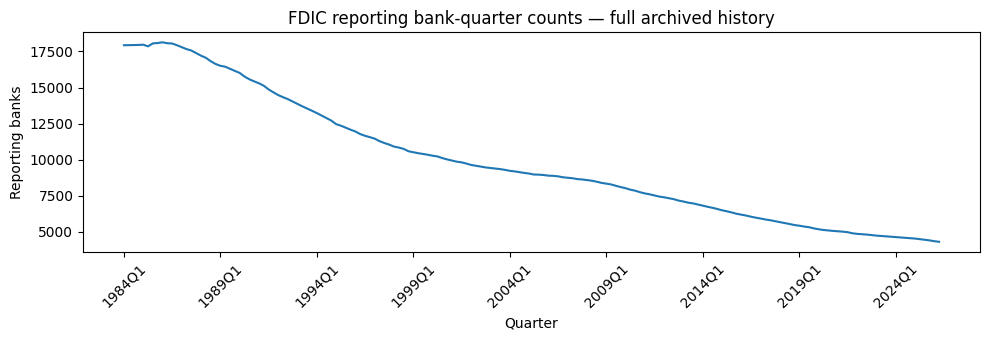

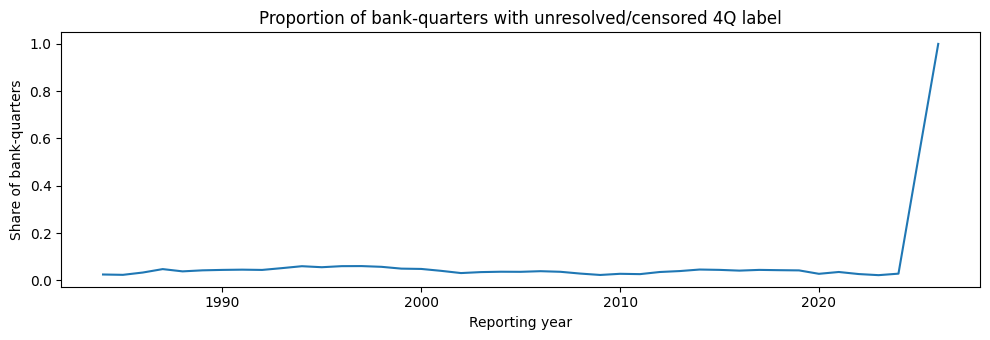

In [181]:
def write_csv_verified(df,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    staging=path.with_suffix('.stage.csv')
    if staging.exists():raise RuntimeError(f'Interrupted CSV stage exists: {staging}')
    df.to_csv(staging,index=False,encoding='utf-8-sig')
    if path.exists():
        if sha256_file(path)!=sha256_file(staging):
            staging.unlink()
            raise RuntimeError(f'Existing evidence CSV differs in content: {path}')
        staging.unlink();return
    os.replace(staging,path)

RUN_DIR=OUTPUT_ROOT/('run_'+RUN_FINGERPRINT)
RUN_DIR.mkdir(parents=True,exist_ok=True)
# Reproducible descriptive visualizations from the current full-history source (never cached old numbers).
try:
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(figsize=(10,3.5))
    ax.plot(EDA['quarters']['quarter'],EDA['quarters']['rows'])
    ax.set_title('FDIC reporting bank-quarter counts — full archived history')
    ax.set_xlabel('Quarter');ax.set_ylabel('Reporting banks')
    ax.set_xticks(range(0,len(EDA['quarters']),20))
    ax.tick_params(axis='x',rotation=45)
    fig.tight_layout();fig.savefig(RUN_DIR/'bank_counts_by_quarter.png',dpi=140)
    plt.show();plt.close(fig)
    rate=SCREENING_AUDIT[['year','unresolved_or_censored_rows','bank_quarters']].copy()
    rate['share']=rate.unresolved_or_censored_rows/rate.bank_quarters
    fig,ax=plt.subplots(figsize=(10,3.5));ax.plot(rate.year,rate.share)
    ax.set_title('Proportion of bank-quarters with unresolved/censored 4Q label')
    ax.set_xlabel('Reporting year');ax.set_ylabel('Share of bank-quarters')
    fig.tight_layout();fig.savefig(RUN_DIR/'label_censoring_by_year.png',dpi=140)
    plt.show();plt.close(fig)
except ImportError:
    print('Matplotlib not installed: data tables generated, plots NOT_RUN')
if 'LABELS_PATH' not in globals():
    LABELS_PATH=RUN_DIR/'labels_4q.parquet'
LABELS_EXPORT=LABELS.copy()
# pd.NA Int8 nullable is retained in Parquet; partition-free table supports 1-to-1 joins.
if LABELS_PATH.exists():
    _audit_cols=['CERT','REPDTE','label_assignment_4q','label_screened_4q','label_status','censor_reason','horizon_mature']
    previous=pd.read_parquet(LABELS_PATH,columns=_audit_cols)
    if len(previous)!=len(LABELS_EXPORT) or not previous.equals(LABELS_EXPORT[_audit_cols]):
        raise RuntimeError('Existing label output differs in values/status; choose new versioned policy ID')
else:
    _label_stage=LABELS_PATH.with_suffix('.stage.parquet')
    if _label_stage.exists():raise RuntimeError('Stale label output stage exists')
    LABELS_EXPORT.to_parquet(_label_stage,index=False)
    os.replace(_label_stage,LABELS_PATH)
for name,df in [('bronze_inventory',BRONZE_INVENTORY),('quarterly_coverage',EDA['quarters']),
                ('annual_coverage',EDA['coverage']),('annual_anomalies',EDA['anomalies']),
                ('annual_bank_profile',EDA['years']),('continuity_diagnostics',CONTINUITY_DIAGNOSTICS),('quality_actions',QUALITY_ACTIONS),
                ('event_raw_audit',EVENTS['raw']),('event_quarantine',EVENTS['quarantine']),
                ('event_failure_registry',EVENTS['failures']),('event_assistance_registry',EVENTS['assistance']),
                ('screening_comparison',SCREENING_AUDIT)]:
    write_csv_verified(df,RUN_DIR/f'{name}.csv')

In [182]:
def finish_phase2(root,inputs,run_dir,labels,events,inv,silver_manifest):
    source_pins={str(p):sha256_file(Path(p)) for p in inputs}
    for f in P0_PINNED_FILES:
        if sha256_file(Path(f[0]))!=f[1]:raise RuntimeError('Phase0 file changed during Phase2')
    if sha256_file(PHASE1_HANDOFF_PATH)!=P1_HANDOFF_SHA:
        raise RuntimeError('Phase1 handoff changed during Phase2')
    if sha256_file(SILVER_PATH)!=silver_manifest['sha256']:
        raise RuntimeError('Silver output SHA mismatch')
    checks=[
      ('P2_01_FULL_HISTORY_SOURCE',len(inv)==43 and len(EDA['quarters'])==170),
      ('P2_02_SOURCE_ROWS_RECONCILE',int(inv.rows.sum())==len(labels)==int(silver_manifest['rows'])),
      ('P2_03_LABEL_KEYS_UNIQUE',not labels[['CERT','REPDTE']].duplicated().any()),
      ('P2_04_SCREENED_NEGATIVE_EVIDENCE',not (labels.label_screened_4q.eq(0).fillna(False)&~labels.CONTINUOUS_4Q).any()),
      ('P2_05_IMMATURE_NEGATIVE_EXCLUDED',not (labels.label_screened_4q.eq(0).fillna(False)&~labels.horizon_mature).any()),
      ('P2_06_EVENT_QUARANTINE_RECONCILED',len(events['valid'])+len(events['quarantine'])==len(events['raw'])),
      ('P2_07_NO_MODEL_SPLITS','model_split' not in labels.columns and 'TRAIN' not in labels.columns),
      ('P2_08_SOURCE_FINANCIAL_FIELDS_PRESERVED',silver_manifest['source_columns_preserved']==FIELDS),
      ('P2_09_SOURCE_SNAPSHOT_ASOF',pd.notna(FAILURE_ASOF)),
    ]
    gate=pd.DataFrame([{'gate':k,'status':'PASS' if bool(v) else 'BLOCKED'} for k,v in checks])
    gate.to_csv(run_dir/'phase2_quality_gates.csv',index=False)
    stats=labels.label_status.value_counts(dropna=False).to_dict()
    manifest={'phase':'PHASE2','version':'2.0','source_scope':'FULL_HISTORY',
      'first_quarter':EXPECTED_FIRST,'last_quarter':EXPECTED_LAST,
      'phase0_field_contract_hash':CONTRACT,'phase0_protocol_version':P0_SCOPE['protocol_version'],
      'phase1_handoff':str(PHASE1_HANDOFF_PATH),'phase1_handoff_sha256':P1_HANDOFF_SHA,
      'phase1_source_row_count':int(PHASE1['rows']),'phase1_source_scope':'FULL_SCOPE_PASS',
      'input_artifact_sha256':source_pins,
      'silver_panel':str(SILVER_PATH),'silver_sha256':silver_manifest['sha256'],
      'label_file':str(LABELS_PATH),'label_sha256':sha256_file(LABELS_PATH),
      'event_snapshot_asof':str(FAILURE_ASOF) if pd.notna(FAILURE_ASOF) else None,
      'event_snapshot_sha256':sha256_file(FAIL_REF_PATH),
      'institutions_snapshot_sha256':sha256_file(INST_REF_PATH),
      'label_status_counts':{str(k):int(v) for k,v in stats.items()},
      'distinct_failure_cert':int(labels.loc[labels.label_screened_4q.eq(1).fillna(False),'CERT'].nunique()),
      'event_quarantine_rows':len(events['quarantine']),
      'quality_gates':gate.to_dict(orient='records'),
      'label_certification':'PROVISIONAL_REQUIRES_EXIT_ADJUDICATION_AND_ASOF_RELEASE_REVIEW',
      'financial_semantics_certification':'PROVISIONAL_SOURCE_VINTAGE_PENDING',
      'model_split_status':'NOT_DEFINED_PHASE2_FULL_HISTORY',
      'reporting_availability_lag':'PENDING_PER_FIELD_VINTAGE_VERIFICATION',
      'forbidden_model_predictor_columns':['CERT','REPDTE','FAILDATE','FAILYR','RESTYPE','RESTYPE1',
            'ACTIVE','ENDEFYMD','CHANGEC1','label_assignment_4q','label_screened_4q',
            'label_status','censor_reason','FAILURE_DATE','ASSISTANCE_DATE','END_DATE','HORIZON_END'],
      'generated_utc':datetime.now(timezone.utc).isoformat()}
    target=run_dir/'phase2_to_phase3_handoff.json'
    if target.is_file():
        previous=json_read(target)
        current_comparable={k:v for k,v in manifest.items() if k!='generated_utc'}
        previous_comparable={k:v for k,v in previous.items() if k!='generated_utc'}
        if previous_comparable!=current_comparable:
            raise RuntimeError('Phase2 handoff content changed within version; use a new run fingerprint')
        manifest=previous  # preserve byte-identical handoff on reruns
    else:
        stage=target.with_suffix('.stage.json')
        if stage.exists():raise RuntimeError('Interrupted Phase2 handoff stage exists')
        stage.write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
        os.replace(stage,target)
    report=run_dir/'phase2_exploration_decision_report.md'
    lines=['# Phase 2 full-history — evidence, decisions & limitations',
           f'Phase 1 input: `{PHASE1_HANDOFF_PATH}` (SHA `{P1_HANDOFF_SHA}`).',
           f'Bronze: {len(inv)} annual files; {len(labels):,} bank-quarter rows, {labels.CERT.nunique():,} distinct CERT.',
           f'Failure snapshot as-of: {FAILURE_ASOF}; event rows quarantined: {len(events["quarantine"])}.',
           '## Outcomes by status']
    lines += [f'- {k}: {v:,}' for k,v in stats.items()]
    lines += ['## Decision register',
              '- Keep all financial source rows and financial values; anomaly flags are for review.',
              '- Strict label_screened_4q negatives require four consecutive subsequent reports, mature horizon, no event conflict or assistance.',
              '- Unknown/administrative exit, incomplete continuation and unmatured horizons remain nullable.',
              '- Assistance is separate from FDIC failure. CHANGEC1/ENDEFYMD not assumed merger without verified historical mapping.',
              '- DEPUNINS denominators, NETINC YTD semantics, historical field vintage remain provisional.',
              '- No chronological split or model/TEST evaluation in Phase 2.',
              '## Acceptance gates']
    lines += [f'- {r.gate}: {r.status}' for r in gate.itertuples(index=False)]
    lines += ['## Important constraints',
              '- Institutional metadata are retrospective audit-only; as-of releases must be established before using such fields for prediction.',
              '- Event snapshot retrieval date controls maturation; source snapshot isolation has not been externally certified.',
              '- If any source is unresolved, treat labels as provisional rather than confirmed solvent negatives.',
              '- Historical cohort counts above are computed only when the user runs the notebook with their actual FDIC Parquet data.']
    report.write_text('\n\n'.join(lines)+'\n',encoding='utf-8')
    return gate,manifest,report

INPUT_FILES=[PHASE1_HANDOFF_PATH,ROOT/'docs/phase0_data_scope_contract.json',
             ROOT/'docs/phase0_phase1_field_handoff_v2.json',FAIL_REF_PATH,INST_REF_PATH]
GATES,PHASE2_HANDOFF,REPORT_PATH=finish_phase2(ROOT,INPUT_FILES,RUN_DIR,LABELS,EVENTS,
                                                BRONZE_INVENTORY,SILVER_MANIFEST)
print(GATES.to_string(index=False))
print('Phase 3 handoff:',RUN_DIR/'phase2_to_phase3_handoff.json')
print('Phase 2 substantive status:',PHASE2_HANDOFF['label_certification'])

                                   gate status
              P2_01_FULL_HISTORY_SOURCE   PASS
            P2_02_SOURCE_ROWS_RECONCILE   PASS
                P2_03_LABEL_KEYS_UNIQUE   PASS
       P2_04_SCREENED_NEGATIVE_EVIDENCE   PASS
       P2_05_IMMATURE_NEGATIVE_EXCLUDED   PASS
      P2_06_EVENT_QUARANTINE_RECONCILED   PASS
                  P2_07_NO_MODEL_SPLITS   PASS
P2_08_SOURCE_FINANCIAL_FIELDS_PRESERVED   PASS
             P2_09_SOURCE_SNAPSHOT_ASOF   PASS
Phase 3 handoff: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\phase2_to_phase3_handoff.json
Phase 2 substantive status: PROVISIONAL_REQUIRES_EXIT_ADJUDICATION_AND_ASOF_RELEASE_REVIEW


<a id="p2-s4"></a>
# 4 — Deep forensic investigation and release checks

**Audit sequence:** field/year coverage → missing endpoints → event quarantine → financial anomalies → publication sensitivity → scientific quality gates. The helper library below is split into independent definition blocks without changing the function bodies. No fitting, imputation or test-based feature selection occurs here.

In [183]:
# Phase 2 deep diagnostics library. Embedded into the consolidated notebook at build time.
# No fitting, split design, imputation, or alteration of Phase 2 labels/source columns.
import re
import hashlib
import math
import unicodedata
from pathlib import Path

DEEP_POLICY_VERSION = 'p2_deep_root_cause_v1_20261115'
DEEP_REQUIRED = ['CERT', 'REPDTE']
DEEP_REVIEW_FIELDS = ['ASSET','EQ','DEP','DEPDOM','DEPUNINS','NETINC','NETINCQ',
                      'ROA','ROE','RBC1AAJ','LNLSGR','NCLNLSR','CHBAL','SC']
DEEP_BREAK_FIELDS = ['DRDEP','DRDEPQ','DRCINUS','DRCINUSQ','DRRENUS','DRRENUSQ','NTRENUS','NTRENUSQ']

def deep_same_quarter(index, dates):
    """Calendar-aware quarter comparison; missing rows never treated as previous quarter."""
    if len(index)!=len(dates):
        raise ValueError('Mismatch in quarter-index lengths')
    return pd.Series(index, index=range(len(index))).diff().eq(1) & pd.Series(dates, index=range(len(dates))).notna()

def deep_cert_normalize(values):
    """Only exact nonnegative integer representations: 12, '12', '12.0'.
    Refuse ambiguous values such as 12.5, '1e3', '12.00x'.
    """
    s=pd.Series(values,copy=False).astype('string').str.strip()
    good=s.str.fullmatch(r'\d+(?:\.0+)?').fillna(False)
    digits=s.where(good).str.replace(r'\.0+$','',regex=True)
    out=pd.to_numeric(digits, errors='coerce').astype('Int64')
    out=out.where(out.gt(0))
    return out

def deep_normalize_name(s):
    if pd.isna(s): return ''
    norm=unicodedata.normalize('NFKD',str(s)).encode('ascii','ignore').decode('ascii')
    return re.sub(r'[^A-Z0-9]+',' ',norm.upper()).strip()

def deep_annual_field_profile(inventory, field_cols):
    """One annual Bronze file in memory at a time, cover all original fields."""
    _,pq=require_arrow()
    results=[];n_annual=0
    numeric_fields=[c for c in field_cols if c not in ('CERT','REPDTE','STNAME')]
    for r in inventory.itertuples(index=False):
        pf=pq.ParquetFile(r.path)
        try: tbl=pf.read(columns=numeric_fields)
        finally: pf.close()
        n_annual+=1
        for col in numeric_fields:
            v=tbl[col].to_pandas()
            x=pd.to_numeric(v, errors='coerce')
            finite=x[np.isfinite(x.to_numpy(dtype='float64',na_value=np.nan))].astype('float64')
            # Original null count and numeric parse failure are different defects.
            raw_null=int(v.isna().sum());num_null=int(x.isna().sum())
            results.append({'year':int(r.year),'field':col,'rows':int(len(v)),
               'raw_missing':raw_null,'numeric_coercion_count':num_null-raw_null,
               'non_null':int(len(v)-raw_null),'finite_count':int(len(finite)),
               'inf_count':int(np.isinf(x.to_numpy(dtype='float64',na_value=np.nan)).sum()),
               'zero_count':int(finite.eq(0).sum()),'negative_count':int(finite.lt(0).sum()),
               'p01':float(finite.quantile(.01)) if len(finite) else np.nan,
               'p50':float(finite.median()) if len(finite) else np.nan,
               'p99':float(finite.quantile(.99)) if len(finite) else np.nan,
               'minimum':float(finite.min()) if len(finite) else np.nan,
               'maximum':float(finite.max()) if len(finite) else np.nan})
        del tbl
        gc.collect()
    out=pd.DataFrame(results)
    if len(out)!=n_annual*len(numeric_fields):
        raise AssertionError('FULL_FIELD_PROFILE_INCOMPLETE')
    if out['numeric_coercion_count'].lt(0).any():
        raise AssertionError('NEGATIVE_PARSE_FAILURE_COUNT')
    return out

def deep_reporting_regime_profile(annual_field_stats, keys, inventory, focus=DEEP_BREAK_FIELDS):
    """Separate compositional change from matched-bank within-unit missingness change."""
    available=sorted(set(focus)&set(annual_field_stats.field))
    years=annual_field_stats[['year','field','rows','non_null']].copy()
    years['coverage_pct']=np.where(years.rows.gt(0),years.non_null/years.rows*100,np.nan)
    year_break=(years.sort_values(['field','year']).assign(
        prior_coverage_pct=lambda d:d.groupby('field').coverage_pct.shift(),
        prior_year=lambda d:d.groupby('field').year.shift()))
    year_break['coverage_change_pp']=np.where(year_break.year.eq(year_break.prior_year+1),
        year_break.coverage_pct-year_break.prior_coverage_pct,np.nan)
    year_break['structural_candidate']=year_break.coverage_change_pp.abs().ge(30)
    # Matched 2016Q4 -> 2017Q1: identify within-bank changes separately from composition.
    _,pq=require_arrow()
    subset=inventory[inventory.year.isin([2016,2017])]
    paired=pd.DataFrame()
    if len(subset)==2 and available:
        z=[]
        for r in subset.itertuples(index=False):
            pf=pq.ParquetFile(r.path)
            try:
                cols=[c for c in ['CERT','REPDTE', 'ASSET']+available if c in pf.schema_arrow.names]
                t=pf.read(columns=cols).to_pandas()
            finally:pf.close()
            t['REPDTE']=normalize_dates(t.REPDTE)
            t['CERT']=deep_cert_normalize(t.CERT).to_numpy()
            date=pd.Timestamp('2016-12-31') if r.year==2016 else pd.Timestamp('2017-03-31')
            z.append(t.loc[t.REPDTE.eq(date)].copy())
        paired=z[0].merge(z[1],on='CERT',suffixes=('_pre','_post'),validate='one_to_one')
    pieces=[]
    for f in available:
        if not paired.empty and f+'_pre' in paired and f+'_post' in paired:
            before=paired[f+'_pre'].notna();after=paired[f+'_post'].notna()
            a=pd.to_numeric(paired.get('ASSET_pre'),errors='coerce') if 'ASSET_pre' in paired else pd.Series(np.nan,index=paired.index)
            for size_group,mask in [('ALL',pd.Series(True,index=paired.index)),
                                    ('ASSET_LT_1M',a.lt(1_000_000)),('ASSET_GE_1M',a.ge(1_000_000))]:
                n=int(mask.sum())
                pieces.append({'field':f,'bank_group':size_group,'matched_banks':n,
                    'present_both':int((before&after&mask).sum()),
                    'lost_coverage':int((before&~after&mask).sum()),
                    'gained_coverage':int((~before&after&mask).sum()),
                    'missing_both':int((~before&~after&mask).sum()),
                    'missing_pre_pct':float((~before&mask).sum()/n*100) if n else np.nan,
                    'missing_post_pct':float((~after&mask).sum()/n*100) if n else np.nan})
    matched=pd.DataFrame(pieces)
    if not matched.empty:
        check=matched[['present_both','lost_coverage','gained_coverage','missing_both']].sum(axis=1)
        if not check.eq(matched.matched_banks).all():raise AssertionError('MATCHED_BANK_COVERAGE_PARTITION_FAILURE')
    return year_break,matched



##### Run block 2/6 — Exit, failure and financial anomalies

In [184]:
def deep_gap_episode_profile(keys, labels):
    """Disambiguate within-life reporting gaps from terminal reporting cessation."""
    k=keys[['CERT','REPDTE','Q_INDEX']].sort_values(['CERT','Q_INDEX']).copy()
    if k[['CERT','Q_INDEX']].duplicated().any():raise AssertionError('DUPLICATE_PANEL_KEYS')
    prior=k.groupby('CERT',sort=False)[['REPDTE','Q_INDEX']].shift()
    nxt=k.Q_INDEX-prior.Q_INDEX
    gaps=k.loc[nxt.gt(1)].copy()
    gaps['prior_report_date']=prior.loc[gaps.index,'REPDTE']
    gaps['missing_quarters']=(nxt.loc[gaps.index]-1).astype(int)
    gaps['gap_quarters']=gaps.missing_quarters+1
    # Do not infer mergers from LAST_REPORTED, ACTIVE, or ENDEFYMD.
    exits=labels[labels.label_status.eq('UNKNOWN_EARLY_EXIT')].copy()
    if exits.empty:
        return gaps,pd.DataFrame(columns=['CERT','last_report','unknown_rows','admin_end_rows'])
    last=k.groupby('CERT',as_index=False)['REPDTE'].max().rename(columns={'REPDTE':'last_report'})
    end=(exits.groupby('CERT',as_index=False).agg(
        unknown_rows=('CERT','size'),admin_end_rows=('censor_reason',lambda s:int(s.eq('ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE').sum())),
        first_affected=('REPDTE','min'),last_affected=('REPDTE','max')))
    end=end.merge(last,on='CERT',how='left',validate='one_to_one')
    if int(end.unknown_rows.sum())!=len(exits):raise AssertionError('UNKNOWN_EXIT_DISAGGREGATION_FAILED')
    return gaps,end

def deep_exit_root_cause(labels, events, keys):
    """Explain why early exits appear; avoid treating snapshot end dates as merger proof."""
    gap,bank=deep_gap_episode_profile(keys,labels)
    labels_temp=labels[['CERT','REPDTE','label_status','censor_reason','CONTINUOUS_4Q','NEXT4_REPORT_COUNT','END_DATE']].copy()
    label_counts=labels_temp.groupby(['label_status','censor_reason'],dropna=False).agg(
        affected_rows=('CERT','size'),affected_banks=('CERT','nunique')).reset_index()
    institution=events['institutions'].copy()
    institution['CERT']=deep_cert_normalize(institution.CERT).to_numpy()
    has_bank=bank.merge(institution,on='CERT',how='left',validate='many_to_one',indicator=True)
    has_bank['institution_reference_found']=has_bank['_merge'].eq('both')
    has_bank['reference_end_recorded']=has_bank.END_DATE.notna()
    has_bank['end_after_last_report']=has_bank.END_DATE.gt(has_bank.last_report)
    has_bank['admin_date_before_last_report']=has_bank.END_DATE.lt(has_bank.last_report)
    has_bank['candidate_cause_tier']=np.select([
        ~has_bank.institution_reference_found,has_bank.END_DATE.isna(),
        has_bank.admin_date_before_last_report,has_bank.end_after_last_report],
        ['UNMATCHED_INSTITUTIONS','NO_ADMIN_END_DATE','ADMIN_END_BEFORE_LAST_REPORT_CONFLICT','ADMIN_END_AFTER_LAST_REPORT_PLAUSIBLE'],
        default='SAME_DAY_OR_UNCLASSIFIED')
    has_bank['root_cause_verified']=False
    has_bank['release_decision']='HOLD_FOR_HISTORY_TRANSACTION_OR_DATED_EXIT_PROOF'
    if int(has_bank.unknown_rows.sum())!=int(labels.label_status.eq('UNKNOWN_EARLY_EXIT').sum()):
        raise AssertionError('EXIT_BANK_SUMMARY_NOT_RECONCILED')
    return gap, has_bank, label_counts

def deep_event_quarantine_diagnosis(events, inst_ref):
    raw=events['raw'].copy()
    if 'AUDIT_REASON' not in raw:raise ValueError('Missing event audit reason')
    raw['raw_cert_repr']=raw.CERT.astype('string').fillna('<NULL>')
    raw['raw_cert_type']=np.select([raw.CERT.isna(),raw.raw_cert_repr.str.fullmatch(r'\d+\.0+').fillna(False),
            raw.raw_cert_repr.str.fullmatch(r'\d+').fillna(False)],
        ['MISSING','DECIMAL_INTEGER','INTEGER_TEXT'],default='OTHER_FORMAT')
    cols=['AUDIT_REASON','EVENT_TYPE','raw_cert_type']
    summary=raw.groupby(cols,dropna=False).agg(rows=('source_row_id','size'),
        distinct_names=('NAME','nunique') if 'NAME' in raw else ('source_row_id','size')).reset_index()
    unresolved=raw[~raw.AUDIT_REASON.eq('VALID')].copy()
    # Exactly named unique institution reference is CANDIDATE ONLY; cannot automatically relabel.
    name_f=next((c for c in ['NAME','NAMEFULL'] if c in unresolved),None)
    name_i=next((c for c in ['NAME','NAMEFULL'] if c in inst_ref),None)
    candidates=pd.DataFrame(columns=['source_row_id','EVENT_TYPE','EVENT_DATE','matched_cert','candidate_evidence'])
    if name_f and name_i and not unresolved.empty:
        ref=inst_ref[['CERT',name_i]].copy()
        ref['matched_cert']=deep_cert_normalize(ref.CERT).to_numpy()
        ref['norm_name']=ref[name_i].map(deep_normalize_name)
        # Require 1-to-1, nonempty name. Full institution snapshot can contain multiple similar named entities.
        reference_groups=ref.loc[ref.norm_name.ne('')].groupby('norm_name').matched_cert.agg(lambda s:sorted(set(s.dropna().astype('int64'))))
        unique_names={name:v[0] for name,v in reference_groups.items() if len(v)==1}
        left=unresolved[['source_row_id','EVENT_TYPE','EVENT_DATE',name_f]].copy()
        left['norm_name']=left[name_f].map(deep_normalize_name)
        left['matched_cert']=left.norm_name.map(unique_names)
        candidates=left.loc[left.matched_cert.notna(),['source_row_id','EVENT_TYPE','EVENT_DATE','matched_cert']].copy()
        candidates['candidate_evidence']='EXACT_NORMALIZED_NAME_ONLY_NEEDS_DATED_FDIC_VERIFICATION'
    if int(summary.rows.sum())!=len(raw):raise AssertionError('EVENT_AUDIT_ROWS_NOT_RECONCILED')
    return summary,unresolved,candidates

def deep_negative_equity_context(inventory, field_cols):
    """Root-cause triage for negative capital and balance-sheet contradictions."""
    _,pq=require_arrow()
    cols=[x for x in ['CERT','REPDTE','ASSET','EQ','DEP','ROA','ROE','NETINC','RBC1AAJ'] if x in field_cols]
    fragments=[]
    for r in inventory.itertuples(index=False):
        pf=pq.ParquetFile(r.path)
        try:d=pf.read(columns=cols).to_pandas()
        finally:pf.close()
        d['CERT']=deep_cert_normalize(d.CERT).to_numpy()
        d['REPDTE']=normalize_dates(d.REPDTE)
        for name in cols[2:]:d[name]=pd.to_numeric(d[name],errors='coerce')
        # Bounded memory: keep only negative-equity rows and preceding 4 reports, NOT entire full numeric panel.
        neg=d.EQ.lt(0) if 'EQ' in d else pd.Series(False,index=d.index)
        risk=d[neg].copy()
        fragments.append(risk)
    detail=pd.concat(fragments,ignore_index=True) if fragments else pd.DataFrame(columns=cols)
    if detail.empty:return detail,pd.DataFrame()
    assets=detail.ASSET
    detail['equity_to_assets']=np.where(assets.gt(0),detail.EQ/assets,np.nan)
    if 'DEP' in detail:
        detail['deposits_exceed_assets']=detail.DEP.gt(assets)
        detail['deposit_to_assets']=np.where(assets.gt(0),detail.DEP/assets,np.nan)
    detail['negative_equity_bucket']=pd.cut(detail.equity_to_assets,
        bins=[-np.inf,-.25,-.10,-.05,0],labels=['BELOW_-25PCT','-25_TO_-10PCT','-10_TO_-5PCT','-5_TO_0PCT'])
    detail['year']=detail.REPDTE.dt.year
    summary=(detail.groupby(['year','negative_equity_bucket'],observed=True)
         .agg(rows=('CERT','size'),banks=('CERT','nunique'),
              median_equity_to_assets=('equity_to_assets','median')).reset_index())
    return detail,summary

def deep_ytd_income_audit(inventory, field_cols):
    """Within-year YTD differencing only; not a bank-quarter predictor transform."""
    if 'NETINC' not in field_cols:
        return pd.DataFrame(),pd.DataFrame()
    _,pq=require_arrow()
    components=[];year_stats=[]
    for r in inventory.itertuples(index=False):
        pf=pq.ParquetFile(r.path)
        try:df=pf.read(columns=['CERT','REPDTE','NETINC']+(['NETINCQ'] if 'NETINCQ' in field_cols else [])).to_pandas()
        finally:pf.close()
        df.CERT=deep_cert_normalize(df.CERT).to_numpy()
        df.REPDTE=normalize_dates(df.REPDTE)
        df['NETINC']=pd.to_numeric(df.NETINC,errors='coerce')
        df['quarter']=df.REPDTE.dt.quarter
        df['quarter_index']=qindex(df.REPDTE)
        df=df.sort_values(['CERT','REPDTE'])
        prev=df.groupby('CERT',sort=False).NETINC.shift(1)
        prevq=df.groupby('CERT',sort=False).quarter_index.shift(1)
        consecutive=df.quarter_index.sub(prevq).eq(1).fillna(False)
        quarter_ytd=np.where(df.quarter.eq(1),df.NETINC,np.where(consecutive,df.NETINC-prev,np.nan))
        df['quarterly_netinc_ytd_derived']=quarter_ytd
        df['missing_prior_quarter_for_ytd']=df.quarter.gt(1)&~consecutive
        if 'NETINCQ' in df:
            df.NETINCQ=pd.to_numeric(df.NETINCQ,errors='coerce')
            df['ytd_vs_reported_quarter_gap']=df.quarterly_netinc_ytd_derived-df.NETINCQ
        parts=['CERT','REPDTE','NETINC','quarterly_netinc_ytd_derived','missing_prior_quarter_for_ytd']
        if 'NETINCQ' in df:parts+=['NETINCQ','ytd_vs_reported_quarter_gap']
        st={'year':int(r.year),'rows':len(df),'missing_ytd_base':int(df.missing_prior_quarter_for_ytd.sum()),
            'derived_available':int(df.quarterly_netinc_ytd_derived.count())}
        if 'ytd_vs_reported_quarter_gap' in df:
            st['reported_quarter_gap_available']=int(df.ytd_vs_reported_quarter_gap.count())
            st['median_abs_ytd_gap']=float(df.ytd_vs_reported_quarter_gap.abs().median())
        year_stats.append(st)
        # Keep a small set of evidence cases; do not copy 1.68m rows into RAM.
        notable=df[df.missing_prior_quarter_for_ytd | (df.get('ytd_vs_reported_quarter_gap',pd.Series(0.,index=df.index)).abs().gt(1))]
        components.append(notable[parts].head(35))
    x=pd.concat(components,ignore_index=True) if components else pd.DataFrame()
    summary=pd.DataFrame(year_stats)
    # Important: this is a candidate, NOT a silently applied NETINC feature.
    return x,summary



##### Run block 3/6 — Sensitivity, institution linkage and reviews

In [185]:
def deep_cleaning_tradeoff(inventory, fields, review_cols=('ASSET','EQ','DEP','ROA','ROE')):
    """Compare data retention/tail changes without applying cleaning or using outcomes."""
    _,pq=require_arrow()
    review=[c for c in review_cols if c in fields]
    rows=[]
    for r in inventory.itertuples(index=False):
        pf=pq.ParquetFile(r.path)
        try:tab=pf.read(columns=review).to_pandas()
        finally:pf.close()
        for f in review:
            x=pd.to_numeric(tab[f],errors='coerce').astype('float64')
            good=x[np.isfinite(x)];n=len(x)
            if not len(good):
                rows.append({'year':r.year,'field':f,'rows':n,'missing':n,'q01':np.nan,'q99':np.nan,
                     'winsorized_observations':0,'observations_dropped_completecase':n,
                     'negative_tail_clipped':0,'signs_destroyed_zero_impute':0})
                continue
            p01,p99=good.quantile([.01,.99]);clip=good.clip(p01,p99)
            rows.append({'year':r.year,'field':f,'rows':n,'missing':int(x.isna().sum()),
               'q01':p01,'q99':p99,'winsorized_observations':int(good.lt(p01).sum()+good.gt(p99).sum()),
               'observations_dropped_completecase':int(x.isna().sum()),
               'negative_tail_clipped':int((good.lt(0)&~clip.eq(good)).sum()),
               'signs_destroyed_zero_impute':0})
    return pd.DataFrame(rows)

def deep_label_lag_sensitivity(labels, lag_days=(0,30,45,60,90)):
    """Reporting release proxy is NEVER asserted to be observed public-filing date."""
    rows=[]
    x=labels[['CERT','REPDTE','FAILURE_DATE','HORIZON_END','horizon_mature']].copy()
    x['year']=x.REPDTE.dt.year
    for lag in lag_days:
        eligible=(x.FAILURE_DATE.notna() & x.FAILURE_DATE.gt(x.REPDTE+pd.Timedelta(days=lag)) &
             x.FAILURE_DATE.le(x.HORIZON_END))
        # A positive can be observed before whole-horizon maturity; count separately.
        yearly=x.assign(candidate_positive=eligible).groupby('year').agg(
            observed_candidate_positive=('candidate_positive','sum'),
            source_bank_quarters=('CERT','size')).reset_index()
        unique=x.loc[eligible,['year','CERT']].drop_duplicates().groupby('year').size().rename('positive_banks').reset_index()
        yearly=yearly.merge(unique,on='year',how='left');yearly.positive_banks=yearly.positive_banks.fillna(0).astype(int)
        yearly['proxy_lag_days']=int(lag);yearly['timing_semantics']='HYPOTHETICAL_PUBLICATION_DELAY_ONLY'
        rows.append(yearly)
    return pd.concat(rows,ignore_index=True)

def deep_field_semantic_registry(fields, scope, root):
    """No invented definitions; report documentation link and explicit verification state."""
    sensitive={
        'NETINC':'Check YTD accounting, revision dates and quarter-only reconstruction',
        'NETINCQ':'Check whether documented quarterly profitability field is comparable historically',
        'DEPUNINS':'Check insured/uninsured share denominator scope (DEP versus DEPDOM)',
        'DEPDOM':'Check domestic deposit population versus total deposits',
        'LNRE':'Check broad real estate scope; not automatically CRE',
        'RBC1AAJ':'Check zero values, regulator capital definition and historical regime',
        'DRCINUS':'Check 2016Q4/2017Q1 reporting form discontinuity',
        'ROA':'Check percentage scaling, annualized vs YTD earnings numerator',
        'ROE':'Check ratio behavior when equity near zero/negative',
        'ASSET':'Check source units and restatements',
    }
    schema=root/'docs/fdic_financial_schema.yaml'
    registry=pd.DataFrame([{'field':f,'semantic_risk':sensitive.get(f,'Verify documented field meaning before phase 4'),
       'source_schema_available':schema.is_file(),
       'source_schema_sha256':sha256_file(schema) if schema.is_file() else '',
       'definition_confirmed':False,
       'decision':'RAW_VALUES_PRESERVED; DERIVED_USE_REQUIRES_FIELD_LEVEL_VERIFICATION'} for f in fields if f not in ['CERT','REPDTE']])
    return registry

def deep_five_issue_register(events, labels, exit_bank, event_summary, lag_table, field_semantics,
                             contract_verified, inventory):
    """Issue-level resolution *policy* and evidence; never manufacture verification status."""
    unmatched=exit_bank.loc[~exit_bank.institution_reference_found] if len(exit_bank) else exit_bank
    unknown=int(labels.label_status.eq('UNKNOWN_EARLY_EXIT').sum())
    quarantine=int(len(events['quarantine']))
    lag_sensitive=int(lag_table.loc[lag_table.proxy_lag_days.eq(0),'observed_candidate_positive'].sum()-
                      lag_table.loc[lag_table.proxy_lag_days.eq(45),'observed_candidate_positive'].sum())
    issues=[
       {'issue_id':'ISSUE_1_UNMATCHED_INSTITUTIONS',
        'observed':f'{len(unmatched):,} distinct unmatched EXIT bank CERT in full-history exit subset; NOT directly comparable with legacy modern-only 126',
        'causal_hypotheses':'Snapshot excludes inactive history; CERT formatting; entity restructuring; missing source reference',
        'causality_verified':False,'action':'Normalize CERT losslessly; export matching candidates for independent FDIC institution-history adjudication; do not drop rows',
        'release_status':'MITIGATED_BY_NULL_LABELS_PENDING_SOURCE_HISTORY'},
       {'issue_id':'ISSUE_2_EARLY_CESSATION_AND_COMPETING_EXITS',
        'observed':f'{unknown:,} bank-quarter rows with unknown early exit; source period and screening policy differ from legacy 19,026 modern-window rows',
        'causal_hypotheses':'Merger/acquisition, charter conversion, nonfailure closure, missing filings, dataset coverage gaps',
        'causality_verified':False,'action':'Decompose to distinct CERT, terminal report, administrative END_DATE, reporting gaps; require dated FDIC History event for verified exit type; retain nullable 4Q outcomes',
        'release_status':'MITIGATED_BY_CENSORING_PENDING_HISTORY_EVENTS'},
       {'issue_id':'ISSUE_3_PUBLICATION_VINTAGE',
        'observed':f'0-day versus 45-day hypothetical lag differs by {lag_sensitive:,} candidate positive rows (not observed release dates)',
        'causal_hypotheses':'Reporting as-of date differs from regulatory submission, correction and public release timestamps',
        'causality_verified':False,'action':'Export 0/30/45/60/90-day sensitivities; require actual filing/version times for operational deployment; prohibit contemporaneous-only predictor claims',
        'release_status':'MITIGATED_BY_SENSITIVITY_PENDING_RELEASE_TIMESTAMPS'},
       {'issue_id':'ISSUE_4_PHASE0_PROVENANCE',
        'observed':f'Current P0/P1 source pins verified={bool(contract_verified)}; earlier legacy Phase 0 checksum mismatch is a different lineage',
        'causal_hypotheses':'Legacy DEV protocol, stale artifacts and mismatched revisions versus new full-scope contract',
        'causality_verified':bool(contract_verified),
        'action':'Use pinned Phase 0 full-history bundle + Phase 1 FULL_SCOPE_PASS and immutable Silver source checksums; never accept legacy provenance by alias',
        'release_status':'VERIFIED_FOR_CURRENT_PINNED_LINEAGE' if contract_verified else 'BLOCKED_SOURCE_MISMATCH'},
       {'issue_id':'ISSUE_5_HISTORICAL_FINANCIAL_SEMANTICS',
        'observed':f'{int((~field_semantics.definition_confirmed).sum())} field definitions not externally certified; source units and YTD may change by era',
        'causal_hypotheses':'Form FFIEC 051/041 changes, differences in domestic/consolidated denominator, YTD vs quarter, revised report definitions',
        'causality_verified':False,'action':'Produce field-year coverage/distribution, matched-bank 2017 break and NETINC YTD audit; keep raw unchanged, defer unverified derived ratios',
        'release_status':'MITIGATED_BY_FIELD_GATING_PENDING_SOURCE_DEFINITIONS'}]
    out=pd.DataFrame(issues)
    if len(out)!=5 or not out.issue_id.is_unique:raise AssertionError('FIVE_OPEN_ISSUES_NOT_EXHAUSTIVE')
    if not contract_verified:raise RuntimeError('Current Phase 0 / Phase 1 provenance NOT verified')
    return out

def deep_institution_linkage(keys, events):
    """All-bank linkage and age-of-coverage, distinct from early-exit-only subset."""
    bank=(keys.groupby('CERT',as_index=False).agg(first_report=('REPDTE','min'),
        last_report=('REPDTE','max'),reported_quarters=('REPDTE','size')))
    inst=events['institutions'][['CERT','END_DATE','ADMIN_CHANGE_CODE','ADMIN_ACTIVE_AUDIT_ONLY']]
    out=bank.merge(inst,on='CERT',how='left',validate='one_to_one',indicator=True)
    out['reference_matched']=out['_merge'].eq('both')
    out['last_year']=out.last_report.dt.year
    out['birth_year']=out.first_report.dt.year
    out['reference_gap_tier']=np.select([
        ~out.reference_matched, out.END_DATE.notna() & out.END_DATE.lt(out.last_report),
        out.END_DATE.notna() & out.END_DATE.ge(out.last_report)],
        ['NO_INSTITUTIONS_SNAPSHOT_MATCH','END_DATE_BEFORE_LAST_FINANCIAL_REPORT',
         'ADMIN_END_ON_OR_AFTER_LAST_REPORT'],default='MATCHED_NO_DOCUMENTED_END')
    tab=out.groupby('reference_gap_tier').agg(banks=('CERT','nunique'),
         observations=('reported_quarters','sum'),first_year=('birth_year','min'),
         last_year=('last_year','max')).reset_index()
    if int(tab.banks.sum())!=out.CERT.nunique():raise AssertionError('INSTITUTION_LINKAGE_RECONCILIATION')
    return out,tab

def deep_assistance_history_risk(labels, events):
    """Check lost later assistance events when a pipeline uses only each bank's earliest event."""
    assistance=events['assistance'][['CERT','ASSISTANCE_DATE']].copy()
    if assistance.empty:return pd.DataFrame(),pd.DataFrame()
    assistance=assistance.drop_duplicates()
    multi=assistance.groupby('CERT').ASSISTANCE_DATE.agg(['size','min','max']).reset_index()
    multi=multi.rename(columns={'size':'event_count','min':'first_assistance_date','max':'last_assistance_date'})
    repeated=multi.loc[multi.event_count.gt(1)]
    if repeated.empty:return multi,pd.DataFrame(columns=['CERT','REPDTE','HORIZON_END','later_assistance_in_horizon'])
    pieces=[]
    label_groups={int(k):v for k,v in labels[labels.CERT.isin(repeated.CERT)][['CERT','REPDTE','HORIZON_END','label_status']].groupby('CERT')}
    for cert, g in assistance.groupby('CERT'):
        if cert not in label_groups:continue
        l=label_groups[cert].copy()
        dates=g.ASSISTANCE_DATE.dropna().sort_values().unique()
        if len(dates)<=1:continue
        # This is only an audit: do not replace primary Phase 2 labels silently.
        earliest=pd.Timestamp(dates[0])
        within=np.zeros(len(l),dtype=bool)
        for dt in dates[1:]:
            within |= (l.REPDTE.lt(pd.Timestamp(dt)) & l.HORIZON_END.ge(pd.Timestamp(dt))).to_numpy()
        l=l[within & l.REPDTE.ge(earliest)].copy()
        if len(l):
            l['later_assistance_in_horizon']=True
            pieces.append(l)
    detail=pd.concat(pieces,ignore_index=True) if pieces else pd.DataFrame(columns=['CERT','REPDTE','HORIZON_END','later_assistance_in_horizon'])
    return multi,detail

def deep_cross_method_negative_audit(labels):
    """Alternative definitions report only sensitivity, not a learned threshold."""
    x=labels[['CERT','REPDTE','HORIZON_END','label_screened_4q','label_assignment_4q',
              'label_status','horizon_mature','ENDPOINT_OBSERVED','CONTINUOUS_4Q']].copy()
    x['strict_negative']=x.label_screened_4q.eq(0).fillna(False)
    x['endpoint_only_potential']=x.ENDPOINT_OBSERVED & x.horizon_mature & ~x.strict_negative
    x['observable_but_unverified']=x.label_status.isin(['UNKNOWN_EARLY_EXIT','ASSISTANCE_EVENT','QUARANTINED'])
    by_year=(x.groupby(x.REPDTE.dt.year).agg(
        rows=('CERT','size'),strict_negative=('strict_negative','sum'),
        endpoint_only_potential=('endpoint_only_potential','sum'),
        observable_but_unverified=('observable_but_unverified','sum')).reset_index()
        .rename(columns={'REPDTE':'year'}))
    # Endpoint-only is *not* automatically a legitimate negative; need event gates.
    return by_year

def deep_assert_no_automatic_causal_claims(issue_register, labels, source_fields):
    if any(x in source_fields for x in ['FAILURE_DATE','END_DATE','label_status']):
        raise AssertionError('RETROSPECTIVE_EVENT_FIELDS_IN_FINANCIAL_SOURCE')
    if issue_register.issue_id.nunique()!=5 or len(issue_register)!=5:
        raise AssertionError('FIVE_ISSUE_REGISTER_INCOMPLETE')
    unresolved=issue_register.loc[issue_register.issue_id.ne('ISSUE_4_PHASE0_PROVENANCE')]
    if unresolved.causality_verified.astype(bool).any():
        raise AssertionError('EXTERNAL_EVENT_CAUSES_CANNOT_BE_CERTIFIED_WITHOUT_EXTERNAL_EVIDENCE')
    if labels.loc[labels.label_status.eq('UNKNOWN_EARLY_EXIT'),'label_screened_4q'].notna().any():
        raise AssertionError('UNKNOWN_EXIT_WAS_SILENTLY_CLASSIFIED')
    return True




##### Run block 4/6 — Exports, sparse patterns and publication checks

In [186]:
def deep_safe_write_csv(df, path, sha_file_func):
    """Immutable evidence publication. Never delete an unexplained stale stage or overwrite an existing artifact."""
    import time
    dst=Path(path);dst.parent.mkdir(parents=True,exist_ok=True)
    stage=dst.with_name(dst.name+'.stage')
    if stage.exists():
        raise RuntimeError(f'STALE_EVIDENCE_STAGE: {stage}; inspect interrupted run, do not auto-delete')
    df.to_csv(stage,index=False,encoding='utf-8-sig')
    try:
        if dst.is_file():
            if sha_file_func(dst)!=sha_file_func(stage):
                raise RuntimeError(f'IMMUTABLE_EVIDENCE_CHANGED: {dst}; new policy ID required')
            stage.unlink()
            return dst
        for attempt in range(6):
            try:
                os.replace(stage,dst);break
            except PermissionError as exc:
                if getattr(exc,'winerror',None) not in (32,33) or attempt==5:
                    raise
                gc.collect();time.sleep(.2*(attempt+1))
        return dst
    except Exception:
        # Preserve the staging artifact for forensic investigation.
        raise


def deep_artifact_handoff(root, base_run_dir, evidence, issue_register, source_sha,
                          p1_handoff_sha, field_contract, silver_sha, labels_sha):
    """Deep audit manifest is supplementary: Phase 3 pinned input handoff is unchanged."""
    out=Path(base_run_dir)/'deep_root_cause_v1'
    out.mkdir(parents=True,exist_ok=True)
    entries={}
    for name,frame in evidence.items():
        p=deep_safe_write_csv(frame,out/(name+'.csv'),sha256_file)
        entries[name]={'path':str(p),'sha256':sha256_file(p),'rows':int(len(frame))}
    x={'kind':'PHASE2_SUPPLEMENTARY_DEEP_CAUSAL_DIAGNOSTIC',
       'policy_version':DEEP_POLICY_VERSION,'source_history':'1984Q1-2026Q2',
       'phase1_handoff_sha256':p1_handoff_sha,'phase0_field_contract_hash':field_contract,
       'bronze_annual_sha256':source_sha,'silver_sha256':silver_sha,'label_sha256':labels_sha,
       'five_issue_statuses':dict(zip(issue_register.issue_id,issue_register.release_status)),
       'release':'PROVISIONAL_DESCRIPTIVE_DIAGNOSTIC_NOT_MODEL_READY',
       'model_split_status':'NOT_DEFINED_PHASE2_FULL_HISTORY','evidence':entries}
    dest=out/'phase2_root_cause_handoff.json'
    if dest.exists():
        existing=json_read(dest)
        if existing!=x:raise RuntimeError('Existing deep audit handoff different; require new policy ID')
    else:
        st=out/'phase2_root_cause_handoff.stage.json'
        if st.exists():raise RuntimeError(f'Stale handoff stage: {st}')
        st.write_text(json.dumps(x,indent=2,ensure_ascii=False),encoding='utf-8')
        os.replace(st,dest)
    return dest,x

def deep_optional_history_event_audit(history_path, history_sha256, exit_banks):
    """Optional independent FDIC /history evidence, NOT automatic merger inference.

    Supply a user-downloaded point-in-time CSV/Parquet plus its SHA256. No
    silent live requests, no guessed event code mapping, no change to labels.
    """
    empty=pd.DataFrame(columns=['CERT','EFFDATE','CHANGECODE','CHANGECODE_DESC','last_report',
       'candidate_type','source_verified','manual_review_required'])
    if history_path is None:
        return empty,pd.DataFrame([{'status':'HISTORY_NOT_PROVIDED','candidate_events':0,
            'resolution':'Export FDIC /history dated effective event evidence; pin file SHA-256; review bank-level identity and event type'}])
    path=Path(history_path).expanduser().resolve()
    if not path.is_file():raise FileNotFoundError(f'FDIC History file missing: {path}')
    if not history_sha256 or sha256_file(path)!=history_sha256:
        raise RuntimeError('HISTORY_SOURCE_SHA_MISMATCH: provide the expected frozen hash; do not infer it at runtime')
    if path.suffix.lower()=='.parquet': d=pd.read_parquet(path)
    elif path.suffix.lower()=='.csv':d=pd.read_csv(path,low_memory=False)
    else:raise ValueError('FDIC History supports only pinned CSV or Parquet')
    d.columns=[str(c).upper() for c in d.columns]
    needed={'CERT','EFFDATE','CHANGECODE_DESC','CHANGECODE'}
    if not needed<=set(d):raise ValueError(f'History snapshot missing required fields: {sorted(needed-set(d))}')
    d['CERT']=deep_cert_normalize(d['CERT']).to_numpy()
    d['EFFDATE']=normalize_dates(d['EFFDATE'])
    d=d.dropna(subset=['CERT','EFFDATE'])
    if not len(d):return empty,pd.DataFrame([{'status':'NO_VALID_DATED_HISTORY_EVENTS','candidate_events':0,'resolution':'Verify source coverage and field encoding'}])
    x=d.merge(exit_banks[['CERT','last_report']],on='CERT',how='inner',validate='many_to_one')
    x=x.loc[x.EFFDATE.gt(x.last_report) & x.EFFDATE.le(x.last_report+pd.DateOffset(years=1))].copy()
    txt=x.CHANGECODE_DESC.fillna('').astype(str).str.upper()
    x['candidate_type']=np.select([
        txt.str.contains(r'BRANCH|OFFICE',regex=True),
        txt.str.contains(r'MERG|ACQUIR|CONSOLIDAT',regex=True),
        txt.str.contains(r'LIQUIDAT|CLOSUR|CLOSED|CONVERT',regex=True)],
        ['BRANCH_OR_OFFICE_EVENT_NOT_BANK_EXIT','MERGER_COMBINATION_CANDIDATE',
         'CLOSURE_CONVERSION_CANDIDATE'],default='UNCLASSIFIED_EVENT')
    x['source_verified']=True # Provenance/date of source, NOT verified event-to-bank semantics.
    x['manual_review_required']=True
    summary=x.groupby('candidate_type',dropna=False).size().rename('candidate_events').reset_index()
    summary['status']='PINNED_HISTORY_DATE_EVIDENCE_MANUAL_ADJUDICATION_PENDING'
    return x[['CERT','EFFDATE','CHANGECODE','CHANGECODE_DESC','last_report',
               'candidate_type','source_verified','manual_review_required']],summary

def deep_sparse_pattern_causality(inventory, fields, severe_threshold=.5):
    """Decompose sparse observations into bank-persistent vs field-era patterns.

    Audit-only; full rows never dropped. Inspect all fields per annual file, but
    retain only compact severe row events and bank-year counts.
    """
    _,pq=require_arrow()
    financial=[c for c in fields if c not in ('CERT','REPDTE','STNAME')]
    core=[c for c in ['ASSET','EQ','DEP','ROA','ROE','NETINC'] if c in financial]
    flagged=[]; annual=[]
    for r in inventory.itertuples(index=False):
        pf=pq.ParquetFile(r.path)
        try:tbl=pf.read(columns=['CERT','REPDTE']+financial)
        finally:pf.close()
        # Convert one year's fields to lightweight boolean matrices; no global all-year concatenation.
        df=tbl.to_pandas()
        mask=df[financial].isna()
        fraction=mask.sum(axis=1)/len(financial)
        core_count=df[core].isna().sum(axis=1) if core else pd.Series(0,index=df.index)
        severe=fraction.gt(severe_threshold)
        annual.append({'year':int(r.year),'rows':len(df),'severe_rows':int(severe.sum()),
            'any_core_missing':int(core_count.gt(0).sum()),
            'average_missing_pct':float(fraction.mean()*100),
            'median_missing_pct':float(fraction.median()*100)})
        if severe.any():
            tiny=df.loc[severe,['CERT','REPDTE']].copy()
            tiny['CERT']=deep_cert_normalize(tiny.CERT).to_numpy()
            tiny['REPDTE']=normalize_dates(tiny.REPDTE)
            tiny['year']=int(r.year)
            tiny['missing_fraction']=fraction[severe].to_numpy()
            tiny['core_missing']=core_count[severe].to_numpy()
            # Pattern signature is the set of missing columns, not values.
            tiny['missing_field_fingerprint']=[hashlib.sha256('|'.join(mask.columns[np.flatnonzero(row)]).encode()).hexdigest()[:12]
                for row in mask.loc[severe].to_numpy(dtype=bool)]
            flagged.append(tiny)
        del tbl,df,mask
        gc.collect()
    bad=pd.concat(flagged,ignore_index=True) if flagged else pd.DataFrame(columns=[
        'CERT','REPDTE','year','missing_fraction','core_missing','missing_field_fingerprint'])
    by_bank=(bad.groupby('CERT',dropna=False).agg(severe_quarters=('CERT','size'),
            first_year=('year','min'),last_year=('year','max'),
            unique_missing_patterns=('missing_field_fingerprint','nunique'),
            mean_missing_fraction=('missing_fraction','mean')).reset_index()
        if not bad.empty else pd.DataFrame())
    annual=pd.DataFrame(annual)
    if int(annual.severe_rows.sum())!=len(bad):raise AssertionError('SPARSE_ROWS_NOT_RECONCILED')
    return annual,bad,by_bank




##### Run block 5/6 — Capital/equity and publication date diagnostics

In [187]:
def deep_capital_mechanisms(inventory, fields):
    """Distinguish onset, persistence, gap/first-observation and candidate mechanisms.

    Calendar-aware lookback across YEAR boundaries. Retain original negative-equity
    observations only; never use future values to infer past features.
    """
    _,pq=require_arrow()
    sources=[c for c in ['CERT','REPDTE','EQ','ASSET','DEP','ROA','NETINC','NCLNLSR'] if c in fields]
    if 'EQ' not in sources or 'ASSET' not in sources:return pd.DataFrame(),pd.DataFrame()
    carry=pd.DataFrame(columns=sources)
    results=[]
    for r in inventory.itertuples(index=False):
        pf=pq.ParquetFile(r.path)
        try:d=pf.read(columns=sources).to_pandas()
        finally:pf.close()
        d['CERT']=deep_cert_normalize(d.CERT).to_numpy()
        d.REPDTE=normalize_dates(d.REPDTE)
        for col in sources[2:]:d[col]=pd.to_numeric(d[col],errors='coerce')
        d=d.sort_values(['CERT','REPDTE'])
        prior=pd.concat([carry,d],ignore_index=True).sort_values(['CERT','REPDTE']) if len(carry) else d.copy()
        prev=prior.groupby('CERT',sort=False)[[c for c in sources if c not in ['CERT','REPDTE']]].shift(1)
        prevdate=prior.groupby('CERT',sort=False).REPDTE.shift(1)
        valid_gap=(qindex(prior.REPDTE)-qindex(prevdate)).eq(1).fillna(False)
        prior['is_quarter_adjacent']=valid_gap.to_numpy(dtype=bool)
        for col in ['EQ','ASSET','DEP','ROA','NETINC','NCLNLSR']:
            if col in d:
                prior['PREV_'+col]=prev[col].where(valid_gap).to_numpy()
        current=prior.loc[prior.REPDTE.dt.year.eq(r.year)].copy()
        neg=current.EQ.lt(0)
        z=current.loc[neg].copy()
        if len(z):
            before=z.PREV_EQ
            z['negative_equity_state']=np.select(
                [~z.is_quarter_adjacent | before.isna(),before.ge(0),before.lt(0)],
                ['UNOBSERVED_START_OR_GAP','VERIFIED_QTR_ONSET','PERSISTENT_NEGATIVE_EQUITY'],
                default='REVIEW')
            z['delta_equity']=z.EQ-before
            z['delta_assets']=z.ASSET-z.PREV_ASSET
            z['delta_deposits']=z.DEP-z.PREV_DEP if 'DEP' in z else np.nan
            z['candidate_mechanism']=np.select([
                z.negative_equity_state.eq('UNOBSERVED_START_OR_GAP'),
                z.delta_equity.lt(0)&z.get('ROA',pd.Series(np.nan,index=z.index)).lt(0),
                z.delta_assets.gt(z.PREV_ASSET.abs()*.25),
                z.delta_equity.gt(0)],
                ['ONSET_NOT_OBSERVABLE','CAPITAL_LOSS_WITH_NEGATIVE_EARNINGS',
                 'LARGE_ASSET_CHANGE_ACCOUNTING_OR_RESTRUCTURING_REVIEW',
                 'CAPITAL_RECOVERY_BUT_STILL_NEGATIVE'],
                default='OTHER_REQUIRES_FINANCIAL_STATEMENTS')
            z['year']=int(r.year)
            results.append(z)
        carry=d.groupby('CERT',sort=False).tail(1).copy()
    ev=pd.concat(results,ignore_index=True) if results else pd.DataFrame()
    summary=(ev.groupby(['year','negative_equity_state','candidate_mechanism'])
        .agg(rows=('CERT','size'),banks=('CERT','nunique'),
             median_delta_equity=('delta_equity','median')).reset_index()
        if not ev.empty else pd.DataFrame())
    if not ev.empty and int(summary.rows.sum())!=len(ev):
        raise AssertionError('NEGATIVE_EQUITY_TRANSITION_RECONCILIATION')
    return ev,summary

def deep_optional_publication_vintage_audit(vintage_path, expected_sha, bank_quarter_keys):
    """Verify independently sourced release timestamps; do not fabricate availability.

    Expected columns: CERT, REPDTE, PUBLIC_AVAILABLE_AT (timezone-aware or date).
    `PUBLIC_AVAILABLE_AT` may be after report-end and may reflect revisions.
    This audit is not used to populate a predictor in Phase 2.
    """
    if vintage_path is None:
        return pd.DataFrame(),pd.DataFrame([{'status':'BANK_LEVEL_RELEASE_TIMESTAMPS_NOT_PROVIDED',
            'matched_bank_quarters':0,'total_bank_quarters':int(len(bank_quarter_keys)),
            'decision':'HOLD_POINT_IN_TIME_CERTIFICATION; HYPOTHETICAL_LAG_SENSITIVITY_ONLY'}])
    p=Path(vintage_path).expanduser().resolve()
    if not p.is_file():raise FileNotFoundError(f'Publication vintage evidence missing: {p}')
    if not expected_sha or sha256_file(p)!=expected_sha:
        raise RuntimeError('PUBLICATION_VINTAGE_PIN_MISMATCH')
    if p.suffix.lower()=='.parquet':d=pd.read_parquet(p)
    elif p.suffix.lower()=='.csv':d=pd.read_csv(p,low_memory=False)
    else:raise ValueError('Only pinned CSV or Parquet vintage evidence is accepted')
    wanted={'CERT','REPDTE','PUBLIC_AVAILABLE_AT'}
    d.columns=[str(c).upper() for c in d.columns]
    if not wanted<=set(d):raise ValueError('Publication evidence missing '+str(sorted(wanted-set(d))))
    d=d[['CERT','REPDTE','PUBLIC_AVAILABLE_AT']].copy()
    d['CERT']=deep_cert_normalize(d.CERT).to_numpy()
    d['REPDTE']=normalize_dates(d.REPDTE)
    release=pd.to_datetime(d.PUBLIC_AVAILABLE_AT,utc=True,errors='coerce')
    d['PUBLIC_AVAILABLE_AT']=release.dt.tz_convert(None)
    if d.CERT.isna().any() or d.REPDTE.isna().any() or d.PUBLIC_AVAILABLE_AT.isna().any():
        raise ValueError('Invalid release timestamp or bank-quarter identifier in publication evidence')
    if d[['CERT','REPDTE']].duplicated().any():
        raise ValueError('Duplicate vintage rows; choose earliest VERIFIED release explicitly in source pre-processing')
    if d.PUBLIC_AVAILABLE_AT.lt(d.REPDTE).any():
        raise ValueError('Release before report-quarter-end; investigate source date semantics')
    k=bank_quarter_keys[['CERT','REPDTE']]
    j=d.merge(k,on=['CERT','REPDTE'],how='left',indicator=True)
    if j['_merge'].ne('both').any():
        raise ValueError('Vintage evidence contains bank-quarter keys absent from current pinned panel')
    j['public_lag_days']=(j.PUBLIC_AVAILABLE_AT-j.REPDTE).dt.total_seconds()/86400
    status=pd.DataFrame([{'status':'PINNED_PARTIAL_RELEASE_EVIDENCE_NOT_YET_MODEL_CERTIFIED',
        'matched_bank_quarters':int(len(j)),'total_bank_quarters':int(len(k)),
        'observed_median_release_lag_days':float(j.public_lag_days.median()),
        'decision':'VERIFY_FULL_COVERAGE_REVISIONS_AND_HISTORICAL_SOURCE_BEFORE_POINT_IN_TIME_MODELING'}])
    return j.drop(columns=['_merge']),status



##### Run block 6/6 — Quality gates & source lineage

In [188]:
def deep_quality_gate_table(inventory, field_cols, keys, labels, events, field_year,
                            gap_events, exit_bank, sparse_year, sparse_cases,
                            equity_cases, equity_transitions, issue_register,
                            lag_table, release_coverage):
    """Real, falsifiable scientific audit controls; technical gates != model certification."""
    fin=[c for c in field_cols if c not in ('CERT','REPDTE','STNAME')]
    tests=[
      ('D01_ALL_ANNUAL_SOURCE_ROWS',int(inventory.rows.sum())==len(keys)),
      ('D02_FIELD_YEAR_COMPLETE_GRID',len(field_year)==len(inventory)*len(fin)),
      ('D03_ALL_SOURCE_FIELDS_COVERED',set(field_year.field)==set(fin)),
      ('D04_KEY_UNIQUENESS',not keys[['CERT','REPDTE']].duplicated().any()),
      ('D05_NO_NEGATIVE_MISSING_COUNTS',field_year[['raw_missing','numeric_coercion_count','inf_count']].ge(0).all().all()),
      ('D06_EVENT_QUARANTINE_CONSERVATION',len(events['raw'])==len(events['valid'])+len(events['quarantine'])),
      ('D07_UNKNOWN_EXIT_ROWS_CONSERVED',int(exit_bank.unknown_rows.sum())==int(labels.label_status.eq('UNKNOWN_EARLY_EXIT').sum())),
      ('D08_GAP_EVENTS_ACTUAL_DISCONTINUITIES',gap_events.empty or gap_events.missing_quarters.ge(1).all()),
      ('D09_SPARSE_ROW_RECONCILIATION',int(sparse_year.severe_rows.sum())==len(sparse_cases)),
      ('D10_NEGATIVE_EQUITY_CONSISTENCY',len(equity_cases)==len(equity_transitions)),
      ('D11_ALL_NEGATIVE_EQUITY_RETAINED',equity_cases.empty or equity_cases.EQ.lt(0).all()),
      ('D12_ALL_ISSUES_REGISTERED',len(issue_register)==5 and issue_register.issue_id.is_unique),
      ('D13_NO_UNSUPPORTED_CAUSE_CERTIFICATION',not issue_register.loc[issue_register.issue_id.ne('ISSUE_4_PHASE0_PROVENANCE'),'causality_verified'].astype(bool).any()),
      ('D14_P0_P1_CURRENT_PIN_STATUS',issue_register.loc[issue_register.issue_id.eq('ISSUE_4_PHASE0_PROVENANCE'),'causality_verified'].eq(True).all()),
      ('D15_UNKNOWN_EXIT_REMAINS_NULL',labels.loc[labels.label_status.eq('UNKNOWN_EARLY_EXIT'),'label_screened_4q'].isna().all()),
      ('D16_NO_UNMATURED_SCREENED_NEGATIVES',not (labels.label_screened_4q.eq(0).fillna(False)&~labels.horizon_mature).any()),
      ('D17_LAG_AUDIT_GRID',set(lag_table.proxy_lag_days)=={0,30,45,60,90}),
      ('D18_LAG_MONOTONICITY',lag_table.groupby('proxy_lag_days').observed_candidate_positive.sum().sort_index().diff().fillna(0).le(0).all()),
      ('D19_PUBLICATION_SOURCE_ASOF_NOT_INFERRED',release_coverage.status.astype(str).str.contains('NOT_PROVIDED|EVIDENCE_NOT_YET').all()),
      ('D20_NO_MODEL_SPLITS_IN_LABEL',not any(c.upper() in {'TRAIN','VALIDATION','TEST','DATA_SPLIT','MODEL_SPLIT'} for c in labels.columns)),
    ]
    out=pd.DataFrame([{'gate_id':name,'passed':bool(ok),'status':'PASS' if ok else 'BLOCKED'} for name,ok in tests])
    bad=out.loc[~out.passed,'gate_id'].tolist()
    if bad:raise RuntimeError('DEEP_ROOT_CAUSE_QUALITY_GATE_FAILED: '+', '.join(bad))
    return out

def deep_verify_pinned_lineage(phase0_files, phase1_path, phase1_sha,
                               inventory, silver_path, silver_sha,
                               labels_path, labels_sha):
    """Repeat SHA verification *after* full deep diagnostics, before publishing audit."""
    for path, sha in phase0_files:
        if not Path(path).is_file() or sha256_file(Path(path))!=sha:
            raise RuntimeError(f'DEEP_PHASE0_ARTIFACT_CHANGED_DURING_RUN: {path}')
    for name,p,expected in [('phase1',phase1_path,phase1_sha),
        ('silver',silver_path,silver_sha),('labels',labels_path,labels_sha)]:
        if not Path(p).is_file() or sha256_file(Path(p))!=expected:
            raise RuntimeError(f'DEEP_{name.upper()}_ARTIFACT_CHANGED_DURING_RUN: {p}')
    for r in inventory.itertuples(index=False):
        if not Path(r.path).is_file() or sha256_file(Path(r.path))!=r.sha256:
            raise RuntimeError(f'DEEP_BRONZE_SOURCE_CHANGED_DURING_RUN: {r.path}')
    return True


## 4.1 — Field coverage and historical reporting regimes

Profile source financial fields annually. Separate genuine missingness from fields that did not exist in earlier reporting regimes; do not infer a regulatory cause without documentation.

In [189]:

# ============================================================
# PHASE 2 — RESTORE ORIGINAL FINANCIAL FIELDS
# Fix global FIELDS collision from FDIC History
# Insert immediately before original Cell 450
# ============================================================

import pyarrow.parquet as pq

assert "P0_FIELDS" in globals(), (
    "Phase 0/1 handoff has not been initialized."
)

assert "BRONZE_INVENTORY" in globals(), (
    "BRONZE_INVENTORY is missing."
)

# Restore the actual financial field list from Phase 0/1.
FINANCIAL_FIELDS = list(
    P0_FIELDS["fields_to_request"]
)

assert {"CERT", "REPDTE"}.issubset(
    FINANCIAL_FIELDS
), "Invalid financial field contract"

# Confirm these fields exist in the Bronze source.
bronze_path = BRONZE_INVENTORY.iloc[0]["path"]

bronze_schema = set(
    pq.ParquetFile(bronze_path).schema_arrow.names
)

missing_fields = (
    set(FINANCIAL_FIELDS) - bronze_schema
)

if missing_fields:
    raise RuntimeError(
        "Financial fields missing from Bronze: "
        f"{sorted(missing_fields)}"
    )

# Restore the global variable expected by downstream cells.
FIELDS = FINANCIAL_FIELDS.copy()

# Recheck original Phase 0/1 field contract.
assert contract_hash(FIELDS) == CONTRACT, (
    "Restored FIELDS do not match original contract"
)

print("========== FINANCIAL FIELDS RESTORED ==========")
print("Number of fields:", len(FIELDS))
print("First 15:", FIELDS[:15])
print("ID incorrectly included:", "ID" in FIELDS)
print("SOURCE_ID incorrectly included:", "SOURCE_ID" in FIELDS)
print("Financial contract:", CONTRACT)
print("\nPASS — FIELDS restored from Phase 0/1")


========== FINANCIAL FIELDS RESTORED ==========
Number of fields: 136
First 15: ['CERT', 'REPDTE', 'STNAME', 'EQ', 'DEP', 'ASSET', 'ROA', 'ROE', 'LNLSGR', 'RBC1AAJ', 'RBCRWAJ', 'EINTEXP', 'LNLSRES', 'NALNLS', 'NCLNLS']
ID incorrectly included: False
SOURCE_ID incorrectly included: False
Financial contract: a1cd7440e6a09ca8

PASS — FIELDS restored from Phase 0/1


In [190]:
FIELD_YEAR_FORENSICS=deep_annual_field_profile(BRONZE_INVENTORY,FIELDS)
COVERAGE_BREAKS,MATCHED_BANK_BREAKS=deep_reporting_regime_profile(
    FIELD_YEAR_FORENSICS,EDA['keys'],BRONZE_INVENTORY)
print('Full field-year audited:',len(FIELD_YEAR_FORENSICS),'| fields:',FIELD_YEAR_FORENSICS.field.nunique())
print('Potential >=30 pp annual coverage breaks:',int(COVERAGE_BREAKS.structural_candidate.sum()))
print('Matched-bank 2016Q4-to-2017Q1 change:')
print(MATCHED_BANK_BREAKS.head(12).to_string(index=False))

Full field-year audited: 5719 | fields: 133
Potential >=30 pp annual coverage breaks: 32
Matched-bank 2016Q4-to-2017Q1 change:
   field  bank_group  matched_banks  present_both  lost_coverage  gained_coverage  missing_both  missing_pre_pct  missing_post_pct
 DRCINUS         ALL           5923          1342            822               26          3733        63.464461         76.903596
 DRCINUS ASSET_LT_1M           5180           612            820               26          3722        72.355212         87.683398
 DRCINUS ASSET_GE_1M            743           730              2                0            11         1.480485          1.749664
DRCINUSQ         ALL           5923          1342            822               26          3733        63.464461         76.903596
DRCINUSQ ASSET_LT_1M           5180           612            820               26          3722        72.355212         87.683398
DRCINUSQ ASSET_GE_1M            743           730              2                0      

## 4.2 — Institutions, gaps and competing exits

Diagnose unmatched institutions and reported end dates; confirm mergers or closures using dated History evidence, not `CHANGEC1` alone.

In [191]:
ALL_BANK_INSTITUTIONS,REFERENCE_LINKAGE_SUMMARY=deep_institution_linkage(EDA['keys'],EVENTS)
GAP_EPISODES,EXIT_BANK_ROOT_CAUSES,EXIT_LABEL_TIERS=deep_exit_root_cause(LABELS,EVENTS,EDA['keys'])
NEGATIVE_SENSITIVITY=deep_cross_method_negative_audit(LABELS)
print('Snapshot linkage by historical cohort:')
print(REFERENCE_LINKAGE_SUMMARY.to_string(index=False))
print('Gap episodes:',len(GAP_EPISODES),'| gap banks:',GAP_EPISODES.CERT.nunique())
print('Early-exit unknown bank-quarter rows:',int(EXIT_BANK_ROOT_CAUSES.unknown_rows.sum()))
print(EXIT_BANK_ROOT_CAUSES.groupby('candidate_cause_tier').agg(banks=('CERT','nunique'),rows=('unknown_rows','sum')).to_string())
print('Check: a candidate cause tier is NOT verified merger proof.')

Snapshot linkage by historical cohort:
                   reference_gap_tier  banks  observations  first_year  last_year
    ADMIN_END_ON_OR_AFTER_LAST_REPORT  19599       1009840        1984       2026
END_DATE_BEFORE_LAST_FINANCIAL_REPORT      5           218        1984       2009
            MATCHED_NO_DOCUMENTED_END   4225        661562        1984       2026
       NO_INSTITUTIONS_SNAPSHOT_MATCH    235         10996        1984       2026
Gap episodes: 33 | gap banks: 32
Early-exit unknown bank-quarter rows: 70901
                                       banks   rows
candidate_cause_tier                               
ADMIN_END_AFTER_LAST_REPORT_PLAUSIBLE  17077  65843
ADMIN_END_BEFORE_LAST_REPORT_CONFLICT      5     23
NO_ADMIN_END_DATE                       4217   4264
SAME_DAY_OR_UNCLASSIFIED                   2     10
UNMATCHED_INSTITUTIONS                   234    761
Check: a candidate cause tier is NOT verified merger proof.


## 4.3 — Event quarantine and incompatible dates

Identify invalid identifiers, missing dates and date conflicts. Quarantined failure evidence must not silently produce labels.

In [192]:
EVENT_QUARANTINE_REASONS,EVENT_QUARANTINE_ROWS,EVENT_NAME_MATCH_CANDIDATES=(
   deep_event_quarantine_diagnosis(EVENTS,INST_REF))
ASSISTANCE_EVENT_COUNTS,REPEATED_ASSISTANCE_AUDIT=deep_assistance_history_risk(LABELS,EVENTS)
print(EVENT_QUARANTINE_REASONS.to_string(index=False))
print('Candidate name-based linkage (unverified):',len(EVENT_NAME_MATCH_CANDIDATES))
print('Banks with repeated dated assistance:',int(ASSISTANCE_EVENT_COUNTS.event_count.gt(1).sum()) if not ASSISTANCE_EVENT_COUNTS.empty else 0)
print('Affected horizon reports with later assistance event:',len(REPEATED_ASSISTANCE_AUDIT))

AUDIT_REASON EVENT_TYPE   raw_cert_type  rows  distinct_names
MISSING_CERT ASSISTANCE         MISSING     3               3
MISSING_CERT    FAILURE         MISSING   485             449
       VALID ASSISTANCE DECIMAL_INTEGER   590             532
       VALID    FAILURE DECIMAL_INTEGER  3039            2799
Candidate name-based linkage (unverified): 27
Banks with repeated dated assistance: 4
Affected horizon reports with later assistance event: 8


## 4.4 — Financial anomaly mechanisms

Distinguish capital distress, ratio denominator effects and accounting transitions. Extreme values may carry predictive signal.

In [193]:
NEG_EQUITY_CASES,NEG_EQUITY_SEVERITY=deep_negative_equity_context(BRONZE_INVENTORY,FIELDS)
YTD_EXAMPLES,YTD_YEAR_AUDIT=deep_ytd_income_audit(BRONZE_INVENTORY,FIELDS)
CLEANING_TRADEOFFS=deep_cleaning_tradeoff(BRONZE_INVENTORY,FIELDS)
print('Negative equity:',len(NEG_EQUITY_CASES),'rows,',NEG_EQUITY_CASES.CERT.nunique() if len(NEG_EQUITY_CASES) else 0,'banks')
print(NEG_EQUITY_SEVERITY.tail(14).to_string(index=False))
print('YTD NETINC continuity audit:')
print(YTD_YEAR_AUDIT.tail(9).to_string(index=False))
print('Cleaning methods are COMPARISONS ONLY; no global winsorization or imputation applied.')

Negative equity: 15659 rows, 2837 banks
 year negative_equity_bucket  rows  banks  median_equity_to_assets
 2015             -5_TO_0PCT     2      2                -0.008401
 2016           -10_TO_-5PCT     1      1                -0.064902
 2016             -5_TO_0PCT     3      3                -0.033802
 2017             -5_TO_0PCT     2      2                -0.022399
 2022           -10_TO_-5PCT     5      3                -0.052231
 2022             -5_TO_0PCT    58     35                -0.011854
 2023          -25_TO_-10PCT     2      2                -0.117616
 2023           -10_TO_-5PCT     5      5                -0.083288
 2023             -5_TO_0PCT    70     32                -0.012145
 2024           -10_TO_-5PCT     2      2                -0.055100
 2024             -5_TO_0PCT    44     16                -0.011260
 2025           -10_TO_-5PCT     7      5                -0.066333
 2025             -5_TO_0PCT    16     10                -0.006863
 2026             -5_T

### 4.4.1 — Sparse fields and persistent missingness

Test whether unusual missingness is bank-specific, period-specific or structurally related to reporting.

In [194]:
SPARSE_YEAR_SUMMARY,SPARSE_ROW_CASES,SPARSE_BANK_PROFILES=deep_sparse_pattern_causality(
   BRONZE_INVENTORY,FIELDS,severe_threshold=.5)
NEG_EQUITY_TRANSITIONS,NEG_EQUITY_MECHANISMS=deep_capital_mechanisms(BRONZE_INVENTORY,FIELDS)
print('>50% sparse rows:',len(SPARSE_ROW_CASES),'| affected banks:',SPARSE_ROW_CASES.CERT.nunique() if len(SPARSE_ROW_CASES) else 0)
print('Capital transition evidence:')
print(NEG_EQUITY_MECHANISMS.groupby('candidate_mechanism').agg(rows=('rows','sum')).to_string() if len(NEG_EQUITY_MECHANISMS) else 'NONE')
assert len(NEG_EQUITY_TRANSITIONS)==len(NEG_EQUITY_CASES)

>50% sparse rows: 79921 | affected banks: 4086
Capital transition evidence:
                                                        rows
candidate_mechanism                                         
CAPITAL_LOSS_WITH_NEGATIVE_EARNINGS                    10439
CAPITAL_RECOVERY_BUT_STILL_NEGATIVE                     3055
LARGE_ASSET_CHANGE_ACCOUNTING_OR_RESTRUCTURING_REVIEW     26
ONSET_NOT_OBSERVABLE                                     908
OTHER_REQUIRES_FINANCIAL_STATEMENTS                     1231


## 4.5 — Release-lag sensitivity and field semantics

Treat hypothetical reporting delays as scenarios, **not observed release dates**. Confirm definitions and effective periods before using fields in a forecasting pipeline.

In [195]:
REPORTING_LAG_SENSITIVITY=deep_label_lag_sensitivity(LABELS)
FINANCIAL_SEMANTICS=deep_field_semantic_registry(FIELDS,P0_SCOPE,ROOT)
lag_totals=REPORTING_LAG_SENSITIVITY.groupby('proxy_lag_days').agg(
    candidate_positive_quarters=('observed_candidate_positive','sum'),
    sum_yearly_positive_banks=('positive_banks','sum')).reset_index()
print(lag_totals.to_string(index=False))
print('Fields without independently verified historical semantics:',int((~FINANCIAL_SEMANTICS.definition_confirmed).sum()))

 proxy_lag_days  candidate_positive_quarters  sum_yearly_positive_banks
              0                        10859                       4719
             30                        10172                       4537
             45                         9763                       4423
             60                         9383                       4328
             90                         8371                       4073
Fields without independently verified historical semantics: 134


### 4.5.1 — Optional observed publication vintage

Only use separately sourced, checksum-pinned release dates when available; leave this optional audit disabled otherwise.

In [196]:
PUBLICATION_VINTAGE_PATH = None
PUBLICATION_VINTAGE_SHA256 = None
VERIFIED_RELEASE_CASES,RELEASE_COVERAGE_AUDIT=deep_optional_publication_vintage_audit(
    PUBLICATION_VINTAGE_PATH,PUBLICATION_VINTAGE_SHA256,EDA['keys'])
print(RELEASE_COVERAGE_AUDIT.to_string(index=False))

                                    status  matched_bank_quarters  total_bank_quarters                                                            decision
BANK_LEVEL_RELEASE_TIMESTAMPS_NOT_PROVIDED                      0              1682616 HOLD_POINT_IN_TIME_CERTIFICATION; HYPOTHETICAL_LAG_SENSITIVITY_ONLY


### 4.5.2 — Optional independent FDIC History input

This optional forensic hook is separate from the verified History loader in Section 3.2; unset paths intentionally mean the hook is not active.

In [197]:
# Optional. To activate, provide a locally frozen FDIC /history snapshot and its actual SHA256.
HISTORY_EVENTS_PATH = None
HISTORY_EVENTS_SHA256 = None
FDIC_HISTORY_CANDIDATES,FDIC_HISTORY_SUMMARY=deep_optional_history_event_audit(
    HISTORY_EVENTS_PATH,HISTORY_EVENTS_SHA256,EXIT_BANK_ROOT_CAUSES)
print(FDIC_HISTORY_SUMMARY.to_string(index=False))

              status  candidate_events                                                                                                       resolution
HISTORY_NOT_PROVIDED                 0 Export FDIC /history dated effective event evidence; pin file SHA-256; review bank-level identity and event type


## 4.6 — Open issues and falsifiable checks

Track evidence gaps explicitly; technical integrity checks passing does not prove every missing label was scientifically resolved.

In [198]:
CURRENT_LINEAGE_VERIFIED=deep_verify_pinned_lineage(
    P0_PINNED_FILES,PHASE1_HANDOFF_PATH,P1_HANDOFF_SHA,BRONZE_INVENTORY,
    SILVER_PATH,SILVER_MANIFEST['sha256'],LABELS_PATH,sha256_file(LABELS_PATH))
print('End-of-diagnostics provenance SHA audit:',CURRENT_LINEAGE_VERIFIED)

End-of-diagnostics provenance SHA audit: True


In [199]:
FIVE_ISSUES=deep_five_issue_register(EVENTS,LABELS,EXIT_BANK_ROOT_CAUSES,
    EVENT_QUARANTINE_REASONS,REPORTING_LAG_SENSITIVITY,FINANCIAL_SEMANTICS,
    contract_verified=CURRENT_LINEAGE_VERIFIED,inventory=BRONZE_INVENTORY)
assert deep_assert_no_automatic_causal_claims(FIVE_ISSUES,LABELS,FIELDS)
print(FIVE_ISSUES[['issue_id','observed','release_status']].to_string(index=False,max_colwidth=100))
# Supplementary audit status is NOT identical to model-ready certification.
assert not FIVE_ISSUES.release_status.str.contains('MODEL_READY').any()

                                   issue_id                                                                                             observed                                       release_status
             ISSUE_1_UNMATCHED_INSTITUTIONS 234 distinct unmatched EXIT bank CERT in full-history exit subset; NOT directly comparable with l...      MITIGATED_BY_NULL_LABELS_PENDING_SOURCE_HISTORY
ISSUE_2_EARLY_CESSATION_AND_COMPETING_EXITS 70,901 bank-quarter rows with unknown early exit; source period and screening policy differ from ...        MITIGATED_BY_CENSORING_PENDING_HISTORY_EVENTS
                ISSUE_3_PUBLICATION_VINTAGE 0-day versus 45-day hypothetical lag differs by 1,096 candidate positive rows (not observed relea...  MITIGATED_BY_SENSITIVITY_PENDING_RELEASE_TIMESTAMPS
                  ISSUE_4_PHASE0_PROVENANCE Current P0/P1 source pins verified=True; earlier legacy Phase 0 checksum mismatch is a different ...                  VERIFIED_FOR_CURRENT_PINNED_LINEAGE
     ISSUE

### 4.6.1 — Twenty quality gates

Run independent assertions for coverage, keys, lineage, events and cleaning policies.

In [200]:
DEEP_QUALITY_GATES=deep_quality_gate_table(BRONZE_INVENTORY,FIELDS,EDA['keys'],LABELS,
    EVENTS,FIELD_YEAR_FORENSICS,GAP_EPISODES,EXIT_BANK_ROOT_CAUSES,SPARSE_YEAR_SUMMARY,
    SPARSE_ROW_CASES,NEG_EQUITY_CASES,NEG_EQUITY_TRANSITIONS,FIVE_ISSUES,
    REPORTING_LAG_SENSITIVITY,RELEASE_COVERAGE_AUDIT)
print('Deep research consistency:',int(DEEP_QUALITY_GATES.passed.sum()),'/',len(DEEP_QUALITY_GATES),'PASS')

Deep research consistency: 20 / 20 PASS


## 4.7 — Supplementary SHA-pinned evidence export

Save forensic outputs without replacing the main full-history Silver or original failure/assistance snapshots.

In [201]:
DEEP_EVIDENCE={
 'financial_field_yearly_forensics':FIELD_YEAR_FORENSICS,
 'annual_field_reporting_breaks':COVERAGE_BREAKS,
 'matched_bank_2017_reporting_transition':MATCHED_BANK_BREAKS,
 'institution_all_bank_linkage':ALL_BANK_INSTITUTIONS,
 'institution_linkage_summary':REFERENCE_LINKAGE_SUMMARY,
 'reporting_gap_episodes':GAP_EPISODES,
 'exit_cause_evidence_tiers':EXIT_BANK_ROOT_CAUSES,
 'label_status_by_censor_reason':EXIT_LABEL_TIERS,
 'negative_label_method_sensitivity':NEGATIVE_SENSITIVITY,
 'fdic_event_quarantine_reasons':EVENT_QUARANTINE_REASONS,
 'fdic_event_quarantine_detail':EVENT_QUARANTINE_ROWS,
 'fdic_event_name_matching_candidates_UNVERIFIED':EVENT_NAME_MATCH_CANDIDATES,
 'assistance_event_counts':ASSISTANCE_EVENT_COUNTS,
 'assistance_repeated_event_horizon_audit':REPEATED_ASSISTANCE_AUDIT,
 'negative_equity_cases':NEG_EQUITY_CASES,
 'negative_equity_severity_by_year':NEG_EQUITY_SEVERITY,
 'negative_equity_capital_transitions':NEG_EQUITY_TRANSITIONS,
 'negative_equity_mechanism_hypotheses':NEG_EQUITY_MECHANISMS,
 'sparse_reporting_by_year':SPARSE_YEAR_SUMMARY,
 'sparse_reporting_cases':SPARSE_ROW_CASES,
 'sparse_banks_persistent_patterns':SPARSE_BANK_PROFILES,
 'netinc_ytd_audit_examples':YTD_EXAMPLES,
 'netinc_ytd_yearly_summary':YTD_YEAR_AUDIT,
 'missingness_outlier_cleaning_policy_comparison':CLEANING_TRADEOFFS,
 'hypothetical_reporting_lag_sensitivity':REPORTING_LAG_SENSITIVITY,
 'financial_semantics_verification_registry':FINANCIAL_SEMANTICS,
 'optional_publication_release_evidence':VERIFIED_RELEASE_CASES,
 'optional_publication_release_coverage':RELEASE_COVERAGE_AUDIT,
 'five_issue_root_cause_decision_register':FIVE_ISSUES,
 'research_quality_gates':DEEP_QUALITY_GATES,
 'optional_fdic_history_candidate_evidence':FDIC_HISTORY_CANDIDATES,
 'optional_fdic_history_summary':FDIC_HISTORY_SUMMARY}
DEEP_MANIFEST_PATH,DEEP_MANIFEST=deep_artifact_handoff(
 ROOT,RUN_DIR,DEEP_EVIDENCE,FIVE_ISSUES,
 [{'year':int(r.year),'sha256':str(r.sha256)} for r in BRONZE_INVENTORY.itertuples(index=False)],
 P1_HANDOFF_SHA,CONTRACT,sha256_file(SILVER_PATH),sha256_file(LABELS_PATH))
print('Deep root-cause audit:',DEEP_MANIFEST_PATH)
print('Evidence artifacts:',len(DEEP_MANIFEST['evidence']))
print('Primary Phase3 handoff retained:',RUN_DIR/'phase2_to_phase3_handoff.json')

Deep root-cause audit: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\deep_root_cause_v1\phase2_root_cause_handoff.json
Evidence artifacts: 32
Primary Phase3 handoff retained: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\phase2_to_phase3_handoff.json


## 4.8 — Interpretation: data integrity versus label readiness

**Established:** Full-history source integrity and lineaged Silver; anomalies were retained for audit. **Remaining methodological choice:** strict reporting-survival labels and the event-based V3 outcome mean different things. Section 6 reports their comparative `NA` results; do not treat an old provisional status as the final modeling policy.

## 4.9 — Guardrails for Phase 3–5

Use `CERT + REPDTE` only to join financials and outcomes. Do not include failure dates, future reporting, mergers, administrative end dates or audit flags as predictors. Imputation and scaling must be fitted on training folds only; review point-in-time availability before modeling.

In [202]:

# ============================================================
# PHASE 2 FIX 01 — NEGATIVE LABEL RECONCILIATION
# ============================================================
import pandas as pd
import numpy as np
from pathlib import Path

assert "LABELS" in globals(), "Run the full-history Phase 2 cells first."

labels_fix = LABELS.copy()
required = {
    "CERT", "REPDTE",
    "label_assignment_4q", "label_screened_4q"
}
assert required.issubset(labels_fix.columns), (
    f"Missing columns: {required - set(labels_fix.columns)}"
)

labels_fix["REPDTE"] = pd.to_datetime(labels_fix["REPDTE"])
assert not labels_fix.duplicated(["CERT", "REPDTE"]).any()

assignment = pd.to_numeric(
    labels_fix["label_assignment_4q"], errors="coerce"
)
screened = pd.to_numeric(
    labels_fix["label_screened_4q"], errors="coerce"
)

pos = assignment.eq(1).fillna(False)
neg = assignment.eq(0).fillna(False)
confirmed_neg = (neg & screened.eq(0).fillna(False))
unresolved_neg = (neg & ~confirmed_neg)

assert not (pos & confirmed_neg).any()
assert not (pos & unresolved_neg).any()
assert int(neg.sum()) == int(
    confirmed_neg.sum() + unresolved_neg.sum()
)
assert not (screened.eq(0).fillna(False) & ~neg).any()
assert not (screened.eq(1).fillna(False) & ~pos).any()

labels_fix["P2_NEGATIVE_STATUS"] = np.select(
    [pos, confirmed_neg, unresolved_neg],
    ["POSITIVE", "CONFIRMED_NEGATIVE", "UNRESOLVED_NEGATIVE"],
    default="OTHER_OR_CENSORED"
)


# Two independent clocks: verified failures versus financial reporting panel.
EVENT_ASOF_FIX = pd.Timestamp(FAILURE_ASOF)
FINANCIAL_ASOF_FIX = pd.to_datetime(EDA["keys"]["REPDTE"]).max()
HORIZON_FIX = pd.to_datetime(labels_fix["HORIZON_END"])
labels_fix["P2_MODEL_ELIGIBLE"] = (
    screened.isin([0, 1])
    & HORIZON_FIX.le(EVENT_ASOF_FIX)
    & HORIZON_FIX.le(FINANCIAL_ASOF_FIX)
).fillna(False).astype(bool)
assert not (labels_fix["P2_MODEL_ELIGIBLE"] & screened.isna()).any()
print("Eligibility event as-of:", EVENT_ASOF_FIX)
print("Eligibility financial as-of:", FINANCIAL_ASOF_FIX)

summary_fix = pd.DataFrame([{
    "total_rows": len(labels_fix),
    "positive": int(pos.sum()),
    "assignment_negative": int(neg.sum()),
    "confirmed_negative": int(confirmed_neg.sum()),
    "unresolved_negative": int(unresolved_neg.sum()),
    "other_or_censored": int((~(pos | neg)).sum()),
    "screened_model_rows": int(
    labels_fix["P2_MODEL_ELIGIBLE"].sum()
)
}])

display(summary_fix)

# Recompute legacy split table, if present.
if {"assignment_272a", "p0_neg_audit", "model_split_273"}.issubset(globals()):
    corrected_splits = []
    for split in pd.unique(model_split_273):
        idx = assignment_272a.index[model_split_273.eq(split)]
        a = assignment_272a.loc[idx, "label_4q_assignment"]
        s = p0_neg_audit.loc[idx, "label_4q_assignment_screened"]

        n = a.eq(0).fillna(False)
        c = n & s.eq(0).fillna(False)

        corrected_splits.append({
            "split": split,
            "negative_rows": int(n.sum()),
            "confirmed_negative_rows": int(c.sum()),
            "unresolved_negative_rows": int((n & ~c).sum())
        })

    corrected_split_policy = pd.DataFrame(corrected_splits)
    assert (
        corrected_split_policy["negative_rows"]
        == corrected_split_policy["confirmed_negative_rows"]
        + corrected_split_policy["unresolved_negative_rows"]
    ).all()
    display(corrected_split_policy)

print("PASS — Negative counts reconcile.")
print("Original LABELS remains unchanged.")


Eligibility event as-of: 2026-11-15 00:00:00
Eligibility financial as-of: 2026-06-30 00:00:00


,total_rows,positive,assignment_negative,confirmed_negative,unresolved_negative,other_or_censored,screened_model_rows
0,1682616,10859,1586036,1585966,70,85721,1596814


,split,negative_rows,confirmed_negative_rows,unresolved_negative_rows
0,TRAIN,171916,164621,7295
1,EMBARGO_2010,31088,29899,1189
2,VALIDATION,29961,28863,1098
3,EMBARGO_2012,29028,27705,1323
4,TEST,277341,264063,13278


PASS — Negative counts reconcile.
Original LABELS remains unchanged.


In [203]:

# ============================================================
# PHASE 2 FIX 02 — EXIT AND EVENT QUARANTINE AUDIT
# ============================================================
import re

assert "EXIT_BANK_ROOT_CAUSES" in globals()
assert "EVENT_QUARANTINE_ROWS" in globals()

exit_audit = EXIT_BANK_ROOT_CAUSES.copy()
event_audit = EVENT_QUARANTINE_ROWS.copy()

def find_column(df, candidates):
    lookup = {str(c).upper(): c for c in df.columns}
    for c in candidates:
        if c.upper() in lookup:
            return lookup[c.upper()]
    return None

# 1. Count unresolved rows by bank.
status_col = find_column(
    labels_fix,
    ["label_status", "label_competing_risk_status"]
)

assert status_col is not None

unresolved_mask = labels_fix[status_col].astype(str).str.contains(
    "UNKNOWN_EARLY_EXIT|UNKNOWN_EXIT",
    case=False, regex=True, na=False
)

unknown_exit_banks = (
    labels_fix.loc[unresolved_mask]
    .groupby("CERT", dropna=False)
    .agg(
        affected_quarters=("REPDTE", "size"),
        first_affected=("REPDTE", "min"),
        last_affected=("REPDTE", "max")
    )
    .reset_index()
)

# 2. Prioritize exits that overlap the modeling period.
unknown_exit_banks["overlap_2005_plus"] = (
    unknown_exit_banks["last_affected"]
    >= pd.Timestamp("2005-01-01")
)

unknown_exit_banks["priority"] = np.select(
    [
        unknown_exit_banks["overlap_2005_plus"]
        & unknown_exit_banks["affected_quarters"].ge(4),
        unknown_exit_banks["overlap_2005_plus"]
    ],
    ["HIGH", "MEDIUM"],
    default="LOW"
)

priority_order = {"HIGH": 0, "MEDIUM": 1, "LOW": 2}
unknown_exit_banks["_rank"] = (
    unknown_exit_banks["priority"].map(priority_order)
)
unknown_exit_banks = (
    unknown_exit_banks
    .sort_values(["_rank", "affected_quarters"],
                 ascending=[True, False])
    .drop(columns="_rank")
)

# 3. Quarantine audit — do not infer missing CERT.
event_cert_col = find_column(event_audit, ["CERT"])

if event_cert_col is not None:
    missing_cert = (
        pd.to_numeric(event_audit[event_cert_col], errors="coerce")
        .isna()
    )
    missing_cert_count = int(missing_cert.sum())
else:
    missing_cert_count = None

# 4. Existing external evidence is optional.
# These records are not automatically resolved.
exit_summary = pd.DataFrame([{
    "unknown_exit_rows": int(unresolved_mask.sum()),
    "unknown_exit_banks": int(unknown_exit_banks["CERT"].nunique()),
    "high_priority_banks": int(
        unknown_exit_banks["priority"].eq("HIGH").sum()
    ),
    "quarantined_event_rows": len(event_audit),
    "missing_cert_rows_if_available": missing_cert_count,
    "external_event_adjudication": "PENDING"
}])

display(exit_summary)
display(unknown_exit_banks.head(20))

# Preserve evidence for future adjudication.
P2_FIX_DIR = Path(ROOT) / "reports" / "phase2" / "fix_audit"
P2_FIX_DIR.mkdir(parents=True, exist_ok=True)

unknown_exit_banks.to_csv(
    P2_FIX_DIR / "unknown_exit_priority.csv", index=False
)
event_audit.to_csv(
    P2_FIX_DIR / "event_quarantine_review.csv", index=False
)
exit_audit.to_csv(
    P2_FIX_DIR / "existing_exit_evidence.csv", index=False
)

print("PASS — Exit risk inventory exported.")
print("No unresolved cases were converted to negatives.")
print("No missing CERT was guessed.")


,unknown_exit_rows,unknown_exit_banks,high_priority_banks,quarantined_event_rows,missing_cert_rows_if_available,external_event_adjudication
0,70901,21535,4851,488,488,PENDING


,CERT,affected_quarters,first_affected,last_affected,overlap_2005_plus,priority
14777,27120,8,1989-03-31,2018-12-31,True,HIGH
19490,34575,8,2004-06-30,2011-03-31,True,HIGH
15384,27942,5,1991-03-31,2011-09-30,True,HIGH
16733,30248,5,1992-06-30,2022-03-31,True,HIGH
16811,30400,5,2006-06-30,2007-06-30,True,HIGH
17091,31004,5,1991-03-31,2014-09-30,True,HIGH
17709,32429,5,1992-06-30,2005-12-31,True,HIGH
17788,32534,5,2007-09-30,2008-09-30,True,HIGH
18786,33655,5,2005-06-30,2006-06-30,True,HIGH
1,9,4,2007-03-31,2007-12-31,True,HIGH


PASS — Exit risk inventory exported.
No unresolved cases were converted to negatives.
No missing CERT was guessed.


In [204]:

# ============================================================
# PHASE 2 FIX 03 — POINT-IN-TIME AVAILABILITY POLICY
# ============================================================
import json

assert "LABELS" in globals()

pit = labels_fix[["CERT", "REPDTE"]].copy()

# 1. Assumed public availability scenarios.
lag_days = [0, 30, 45, 90]

for lag in lag_days:
    pit[f"AVAILABLE_AT_LAG_{lag}D"] = (
        pit["REPDTE"] + pd.to_timedelta(lag, unit="D")
    )

# 2. Conservative previous-quarter availability.
# This is an assumption, not verified publication evidence.
pit["PREVIOUS_QUARTER_END"] = (
    pit["REPDTE"] - pd.offsets.QuarterEnd(1)
)

# 3. Example forecast decision date:
# 45 days after quarter end.
pit["DECISION_DATE_45D"] = (
    pit["REPDTE"] + pd.Timedelta(days=45)
)

for lag in lag_days:
    pit[f"AVAILABLE_BY_DECISION_{lag}D"] = (
        pit[f"AVAILABLE_AT_LAG_{lag}D"]
        <= pit["DECISION_DATE_45D"]
    )

# 4. Validate no date is earlier than its report period.
for lag in lag_days:
    assert (
        pit[f"AVAILABLE_AT_LAG_{lag}D"] >= pit["REPDTE"]
    ).all()

# 5. Verified release evidence remains separate.
verified_release_available = (
    "VERIFIED_RELEASE_CASES" in globals()
    and len(VERIFIED_RELEASE_CASES) > 0
)

availability_policy = {
    "primary_label": "assignment_4q",
    "publication_timestamp_verified": bool(
        verified_release_available
    ),
    "primary_feature_policy": (
        "previous_quarter_financials_as_conservative_proxy"
    ),
    "sensitivity_lags_days": lag_days,
    "decision_date_example": "quarter_end_plus_45_days",
    "warning": (
        "Assumed dates are not actual public release timestamps. "
        "Do not claim fully verified point-in-time validity."
    ),
    "forbidden_predictors": [
        "FAILDATE", "FAILURE_DATE", "first_failure_date",
        "ACTIVE", "ENDEFYMD", "CHANGEC1",
        "label_assignment_4q", "label_screened_4q",
        "label_status", "censor_reason",
        "horizon_mature", "model_evaluation_eligible"
    ]
}

pit.to_parquet(
    P2_FIX_DIR / "availability_sensitivity_audit.parquet",
    index=False
)

with open(
    P2_FIX_DIR / "availability_policy.json",
    "w", encoding="utf-8"
) as f:
    json.dump(availability_policy, f, indent=2)

display(
    pit[[
        "REPDTE", "PREVIOUS_QUARTER_END",
        "DECISION_DATE_45D",
        "AVAILABLE_AT_LAG_45D",
        "AVAILABLE_AT_LAG_90D"
    ]].head()
)

print("PASS — Availability policy exported.")
print("Verified publication evidence:", verified_release_available)


,REPDTE,PREVIOUS_QUARTER_END,DECISION_DATE_45D,AVAILABLE_AT_LAG_45D,AVAILABLE_AT_LAG_90D
0,1984-03-31,1983-12-31,1984-05-15,1984-05-15,1984-06-29
1,1984-06-30,1984-03-31,1984-08-14,1984-08-14,1984-09-28
2,1984-09-30,1984-06-30,1984-11-14,1984-11-14,1984-12-29
3,1984-12-31,1984-09-30,1985-02-14,1985-02-14,1985-03-31
4,1985-03-31,1984-12-31,1985-05-15,1985-05-15,1985-06-29


PASS — Availability policy exported.
Verified publication evidence: False


In [205]:

# ============================================================
# PHASE 2 FIX 04 — FINAL ACCEPTANCE AUDIT
# ============================================================
import hashlib
from datetime import datetime, timezone

def dataframe_fingerprint(df, cols):
    canonical = df[cols].sort_values(
        ["CERT", "REPDTE"]
    ).reset_index(drop=True)
    values = pd.util.hash_pandas_object(
        canonical, index=False
    ).values
    return hashlib.sha256(values.tobytes()).hexdigest()

key_cols = [
    "CERT", "REPDTE",
    "label_assignment_4q", "label_screened_4q"
]

original_hash = dataframe_fingerprint(LABELS, key_cols)
working_hash = dataframe_fingerprint(labels_fix, key_cols)

checks = {
    "Original labels unchanged": original_hash == working_hash,
    "No duplicate bank-quarter keys":
        not labels_fix.duplicated(["CERT", "REPDTE"]).any(),
    "Negative reconciliation":
        int(neg.sum()) == int(
            confirmed_neg.sum() + unresolved_neg.sum()
        ),
    "No unresolved negative marked model eligible":
        not labels_fix.loc[
            unresolved_neg, "P2_MODEL_ELIGIBLE"
        ].any(),
    "No positive and negative overlap":
        not (pos & confirmed_neg).any(),
    "Availability rows reconcile":
        len(pit) == len(labels_fix),
    "Exit inventory generated":
        (P2_FIX_DIR / "unknown_exit_priority.csv").exists(),
    "Availability policy generated":
        (P2_FIX_DIR / "availability_policy.json").exists()
}

acceptance = pd.DataFrame([
    {"check": name, "passed": bool(ok)}
    for name, ok in checks.items()
])

display(acceptance)

assert acceptance["passed"].all(), (
    "Critical acceptance check failed."
)

# Preserve original label file. Export a separate audit overlay.
labels_fix[[
    "CERT", "REPDTE",
    "P2_NEGATIVE_STATUS", "P2_MODEL_ELIGIBLE"
]].to_parquet(
    P2_FIX_DIR / "negative_eligibility_overlay.parquet",
    index=False
)

report = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "technical_checks_passed": int(acceptance.passed.sum()),
    "technical_checks_total": len(acceptance),
    "technical_status": "PASS",
    "silver_rebuild_required": False,
    "original_labels_modified": False,
    "phase3_ready": True,
    "phase4_5_label_status": "PROVISIONAL",
    "remaining_external_evidence": [
        "Unresolved institution exits",
        "Quarantined event identifiers",
        "Actual publication timestamps"
    ],
    "label_fingerprint_sha256": original_hash
}

with open(
    P2_FIX_DIR / "phase2_fix_acceptance.json",
    "w", encoding="utf-8"
) as f:
    json.dump(report, f, indent=2, ensure_ascii=False)

print("=" * 55)
print("PHASE 2 ADDITIONAL AUDIT: PASS")
print("Phase 3: READY")
print("Phase 4/5 labels: PROVISIONAL")
print("Original Silver and LABELS: UNCHANGED")
print("Output:", P2_FIX_DIR)
print("=" * 55)


,check,passed
0,Original labels unchanged,True
1,No duplicate bank-quarter keys,True
2,Negative reconciliation,True
3,No unresolved negative marked model eligible,True
4,No positive and negative overlap,True
5,Availability rows reconcile,True
6,Exit inventory generated,True
7,Availability policy generated,True


PHASE 2 ADDITIONAL AUDIT: PASS
Phase 3: READY
Phase 4/5 labels: PROVISIONAL
Original Silver and LABELS: UNCHANGED
Output: C:\học tập\kì 7\Big data\Final\Bản nháp\reports\phase2\fix_audit


### 4.10 — Retained full-history target structure audit

This earlier cell explains how strict labels were assigned; later V3 counts are governed by Section 6. The visualization is a diagnostic, not a feature matrix.

In [206]:

# ============================================================
# 3.A — Y LABEL STRUCTURE & PROCESSING AUDIT (1984–2026)
# READ-ONLY: KHÔNG THAY ĐỔI LABELS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

assert "LABELS" in globals(), "Run construct_labels() first."

y_df = LABELS.copy()
y_df["REPDTE"] = pd.to_datetime(y_df["REPDTE"])
y_df["year"] = y_df["REPDTE"].dt.year

assignment = pd.to_numeric(
    y_df["label_assignment_4q"], errors="coerce"
)
screened = pd.to_numeric(
    y_df["label_screened_4q"], errors="coerce"
)

# ============================================================
# 1. LABEL DISTRIBUTION — y=0, y=1, NA
# ============================================================

print("\n========== 1. Y LABEL DISTRIBUTION ==========")

records = []

for name, values in [
    ("Assignment", assignment),
    ("Screened", screened)
]:
    for value, label in [(0, "y=0"), (1, "y=1"), (None, "NA")]:
        mask = values.isna() if value is None else values.eq(value)

        records.append({
            "label_method": name,
            "class": label,
            "rows": int(mask.sum()),
            "pct_all": round(100 * mask.sum() / len(y_df), 3),
            "unique_banks": y_df.loc[mask, "CERT"].nunique()
        })

Y_DISTRIBUTION = pd.DataFrame(records)
display(Y_DISTRIBUTION)

# ============================================================
# 2. SO SÁNH ASSIGNMENT VÀ SCREENED
# ============================================================

print("\n========== 2. LABEL TRANSITION ==========")

def label_name(values):
    return values.map({0: "y=0", 1: "y=1"}).fillna("NA")

Y_TRANSITION = pd.crosstab(
    label_name(assignment),
    label_name(screened),
    rownames=["Assignment"],
    colnames=["Screened"],
    dropna=False
)

display(Y_TRANSITION)

# Các trường hợp assignment=0 nhưng screened=NA
partial_neg = assignment.eq(0) & screened.isna()

print("Assignment negative but NOT screened negative:",
      int(partial_neg.sum()))

display(
    y_df.loc[
        partial_neg,
        ["CERT", "REPDTE", "NEXT4_REPORT_COUNT",
         "CONTINUOUS_4Q", "ENDPOINT_OBSERVED",
         "label_status", "censor_reason"]
    ].head(15)
)

# ============================================================



========== 1. Y LABEL DISTRIBUTION ==========


,label_method,class,rows,pct_all,unique_banks
0,Assignment,y=0,1586036,94.260,23048
1,Assignment,y=1,10859,0.645,2836
2,Assignment,NA,85721,5.095,21845
3,Screened,y=0,1585966,94.256,23048
4,Screened,y=1,10859,0.645,2836
5,Screened,NA,85791,5.099,21845



========== 2. LABEL TRANSITION ==========


Screened,NA,y=0,y=1
Assignment,,,
NA,85721,0,0
y=0,70,1585966,0
y=1,0,0,10859


Assignment negative but NOT screened negative: 70


,CERT,REPDTE,NEXT4_REPORT_COUNT,CONTINUOUS_4Q,ENDPOINT_OBSERVED,label_status,censor_reason
80560,1598,1988-03-31,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS
80561,1598,1988-06-30,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS
80562,1598,1988-09-30,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS
579094,11990,1984-03-31,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS
624927,13012,1987-06-30,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS
624928,13012,1987-09-30,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS
624929,13012,1987-12-31,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS
781232,15967,1996-06-30,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS
781233,15967,1996-09-30,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS
781234,15967,1996-12-31,3,False,True,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS


##### Run block 2/4 — Eligibility and annual breakdown

In [207]:
# 3. Y ĐƯỢC XỬ LÝ NHƯ THẾ NÀO?
# ============================================================

print("\n========== 3. LABEL STATUS / CENSOR REASONS ==========")

Y_STATUS = (
    y_df.groupby(
        ["label_status", "censor_reason"],
        dropna=False
    )
    .agg(
        rows=("CERT", "size"),
        banks=("CERT", "nunique")
    )
    .reset_index()
    .sort_values("rows", ascending=False)
)

Y_STATUS["pct_all"] = (
    100 * Y_STATUS["rows"] / len(y_df)
).round(3)

display(Y_STATUS)

# ============================================================
# 4. MODEL ELIGIBILITY
# ============================================================

print("\n========== 4. MODEL EVALUATION ELIGIBILITY ==========")

Y_ELIGIBILITY = pd.DataFrame([{
    "total_rows": len(y_df),
    "positive_y1": int(screened.eq(1).sum()),
    "confirmed_negative_y0": int(screened.eq(0).sum()),
    "unresolved_NA": int(screened.isna().sum()),
    "horizon_mature": int(y_df["horizon_mature"].sum()),
    "model_evaluation_eligible": int(
        y_df["model_evaluation_eligible"].sum()
    ),
    "not_evaluation_eligible": int(
        (~y_df["model_evaluation_eligible"]).sum()
    )
}])

display(Y_ELIGIBILITY)

# ============================================================
# 5. CƠ CẤU NHÃN THEO NĂM (1984–2026)
# ============================================================

print("\n========== 5. ANNUAL Y DISTRIBUTION ==========")

y_df["y1"] = screened.eq(1).fillna(False)
y_df["y0"] = screened.eq(0).fillna(False)
y_df["y_na"] = screened.isna()

Y_ANNUAL = (
    y_df.groupby("year")
    .agg(
        total=("CERT", "size"),
        y0=("y0", "sum"),
        y1=("y1", "sum"),
        NA=("y_na", "sum"),
        positive_banks=("CERT", lambda s: s[
            y_df.loc[s.index, "y1"]
        ].nunique())
    )
    .reset_index()
)

Y_ANNUAL["positive_rate_labeled_pct"] = (
    100 * Y_ANNUAL["y1"] /
    (Y_ANNUAL["y0"] + Y_ANNUAL["y1"]).replace(0, np.nan)
)

Y_ANNUAL["NA_rate_pct"] = (
    100 * Y_ANNUAL["NA"] / Y_ANNUAL["total"]
)

display(Y_ANNUAL.round(3))

# ============================================================



========== 3. LABEL STATUS / CENSOR REASONS ==========


,label_status,censor_reason,rows,banks,pct_all
1,CONFIRMED_CONTINUING_NEGATIVE,,1585966,23048,94.256
7,UNKNOWN_EARLY_EXIT,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,64982,16702,3.862
6,RIGHT_CENSORED,HORIZON_NOT_MATURE_OR_EVENT_ASOF_UNVERIFIED,13070,4415,0.777
3,OBSERVED_FAILURE,,10859,2836,0.645
8,UNKNOWN_EARLY_EXIT,NO_HORIZON_ENDPOINT_REPORT,5919,5133,0.352
2,EXCLUDED_PRE_EXISTING_FAILURE,PRE_EXISTING_FAILURE,1176,267,0.070
0,ASSISTANCE_EVENT,ASSISTANCE_REQUIRES_ADJUDICATION,504,176,0.030
4,PARTIAL_CONTINUATION,MISSING_INTERMEDIATE_REPORTS,70,28,0.004
5,QUARANTINED,AMBIGUOUS_EVENT,70,3,0.004



========== 4. MODEL EVALUATION ELIGIBILITY ==========


,total_rows,positive_y1,confirmed_negative_y0,unresolved_NA,horizon_mature,model_evaluation_eligible,not_evaluation_eligible
0,1682616,10859,1585966,85791,1669539,1596818,85798



========== 5. ANNUAL Y DISTRIBUTION ==========


,year,total,y0,y1,NA,positive_banks,positive_rate_labeled_pct,NA_rate_pct
0,1984,71760,69517,427,1816,201,0.61,2.531
1,1985,71961,69690,555,1716,271,0.79,2.385
2,1986,72182,68980,776,2426,332,1.112,3.361
3,1987,70399,66182,832,3385,380,1.242,4.808
4,1988,67715,63245,1862,2608,698,2.86,3.851
5,1989,65397,61015,1578,2804,660,2.521,4.288
6,1990,62769,58805,1158,2806,517,1.931,4.470
7,1991,59949,56430,777,2742,363,1.358,4.574
8,1992,57025,54102,380,2543,171,0.697,4.459
9,1993,54487,51556,85,2846,49,0.165,5.223


##### Run block 3/4 — Original label charts

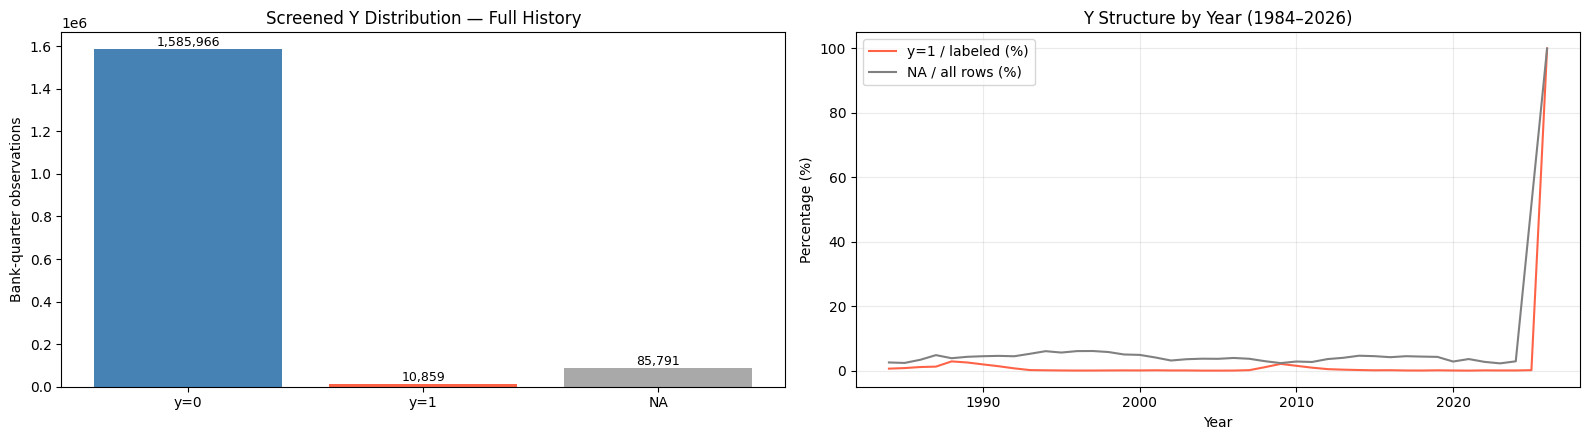

In [208]:
# 6. BIỂU ĐỒ CƠ CẤU NHÃN
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

counts = [
    int(screened.eq(0).sum()),
    int(screened.eq(1).sum()),
    int(screened.isna().sum())
]

bars = axes[0].bar(
    ["y=0", "y=1", "NA"],
    counts,
    color=["steelblue", "tomato", "darkgray"]
)

axes[0].set_title("Screened Y Distribution — Full History")
axes[0].set_ylabel("Bank-quarter observations")

for bar, count in zip(bars, counts):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{count:,}",
        ha="center", va="bottom", fontsize=9
    )

axes[1].plot(
    Y_ANNUAL["year"],
    Y_ANNUAL["positive_rate_labeled_pct"],
    label="y=1 / labeled (%)",
    color="tomato"
)

axes[1].plot(
    Y_ANNUAL["year"],
    Y_ANNUAL["NA_rate_pct"],
    label="NA / all rows (%)",
    color="gray"
)

axes[1].set_title("Y Structure by Year (1984–2026)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Percentage (%)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ============================================================


##### Run block 4/4 — Example cases & integrity checks

In [209]:
# 7. VÍ DỤ THỰC TẾ CHO TỪNG LOẠI NHÃN
# ============================================================

print("\n========== 7. REAL LABEL EXAMPLES ==========")

example_cols = [
    "CERT", "REPDTE", "HORIZON_END",
    "FAILURE_DATE", "NEXT4_REPORT_COUNT",
    "horizon_mature", "label_assignment_4q",
    "label_screened_4q", "label_status",
    "censor_reason", "model_evaluation_eligible"
]

for name, mask in [
    ("POSITIVE y=1", y_df["y1"]),
    ("NEGATIVE y=0", y_df["y0"]),
    ("UNRESOLVED NA", y_df["y_na"])
]:
    print(f"\n--- {name} ---")
    display(y_df.loc[mask, example_cols].head(5))

# ============================================================
# 8. BASIC LABEL INTEGRITY CHECKS
# ============================================================

assert len(y_df) == len(LABELS)
assert not y_df.duplicated(["CERT", "REPDTE"]).any()
assert not (screened.eq(0) & ~y_df["CONTINUOUS_4Q"]).any()
assert not (screened.eq(0) & ~y_df["horizon_mature"]).any()

print("\nPASS — Y label structure audited.")
print("Original LABELS remains unchanged.")



========== 7. REAL LABEL EXAMPLES ==========

--- POSITIVE y=1 ---


,CERT,REPDTE,HORIZON_END,FAILURE_DATE,NEXT4_REPORT_COUNT,horizon_mature,label_assignment_4q,label_screened_4q,label_status,censor_reason,model_evaluation_eligible
3713,76,1986-06-30,1987-06-30,1987-04-22,3,True,1,1,OBSERVED_FAILURE,,True
3714,76,1986-09-30,1987-09-30,1987-04-22,2,True,1,1,OBSERVED_FAILURE,,True
3715,76,1986-12-31,1987-12-31,1987-04-22,1,True,1,1,OBSERVED_FAILURE,,True
3716,76,1987-03-31,1988-03-31,1987-04-22,0,True,1,1,OBSERVED_FAILURE,,True
5184,91,2015-09-30,2016-09-30,2016-09-23,3,True,1,1,OBSERVED_FAILURE,,True



--- NEGATIVE y=0 ---


,CERT,REPDTE,HORIZON_END,FAILURE_DATE,NEXT4_REPORT_COUNT,horizon_mature,label_assignment_4q,label_screened_4q,label_status,censor_reason,model_evaluation_eligible
0,8,1984-03-31,1985-03-31,NaT,4,True,0,0,CONFIRMED_CONTINUING_NEGATIVE,,True
1,8,1984-06-30,1985-06-30,NaT,4,True,0,0,CONFIRMED_CONTINUING_NEGATIVE,,True
2,8,1984-09-30,1985-09-30,NaT,4,True,0,0,CONFIRMED_CONTINUING_NEGATIVE,,True
3,8,1984-12-31,1985-12-31,NaT,4,True,0,0,CONFIRMED_CONTINUING_NEGATIVE,,True
4,8,1985-03-31,1986-03-31,NaT,4,True,0,0,CONFIRMED_CONTINUING_NEGATIVE,,True



--- UNRESOLVED NA ---


,CERT,REPDTE,HORIZON_END,FAILURE_DATE,NEXT4_REPORT_COUNT,horizon_mature,label_assignment_4q,label_screened_4q,label_status,censor_reason,model_evaluation_eligible
63,8,1999-12-31,2000-12-31,NaT,3,True,<NA>,<NA>,UNKNOWN_EARLY_EXIT,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,False
64,8,2000-03-31,2001-03-31,NaT,2,True,<NA>,<NA>,UNKNOWN_EARLY_EXIT,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,False
65,8,2000-06-30,2001-06-30,NaT,1,True,<NA>,<NA>,UNKNOWN_EARLY_EXIT,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,False
66,8,2000-09-30,2001-09-30,NaT,0,True,<NA>,<NA>,UNKNOWN_EARLY_EXIT,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,False
159,9,2007-03-31,2008-03-31,NaT,3,True,<NA>,<NA>,UNKNOWN_EARLY_EXIT,ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE,False



PASS — Y label structure audited.
Original LABELS remains unchanged.


<a id="p2-s5"></a>
# 5 — Verified FDIC History and strict V2 labels

**History source:** 508,660 source-ID-unique records, 32,340 bank identifiers, with SHA verification reported in Section 5.1. The institutional-history audit classified 55,754 administrative bank-quarters as merger and 1,714 as closure; these are **competing events**, not automatically failures.

**V2 policy:** retain existing `y_primary_4q_v2` and audit censored/unknown outcomes. The event registry provides failure dates; `/history` provides dated organizational changes. The strong matching rules and their limitations are tested below.

*The event-based V3 target in Section 6 is an explicit alternative outcome definition, not a silent replacement for V2.*

In [210]:
# 8.1 — Verify the official full-history source and normalize dated events
import hashlib, json, re
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

assert {'LABELS', 'EVENTS', 'EDA', 'ROOT', 'FAILURE_ASOF', 'labels_fix'}.issubset(globals())
ROOT = Path(ROOT)
HISTORY_DIR_V2 = ROOT / 'data' / 'reference'
HISTORY_MANIFEST_V2 = HISTORY_DIR_V2 / 'fdic_history_manifest.json'
HISTORY_CSV_V2 = HISTORY_DIR_V2 / 'fdic_history_events.csv'
HISTORY_PARQUET_V2 = HISTORY_DIR_V2 / 'fdic_history_events.parquet'
HISTORY_ENDPOINT_V2 = 'https://api.fdic.gov/banks/history'
EVENT_ASOF_V2 = pd.Timestamp(FAILURE_ASOF)
FINANCIAL_ASOF_V2 = pd.to_datetime(EDA['keys']['REPDTE']).max()


def file_hash_v2(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

# The snapshot may have been downloaded in Section 2.7.2B.
HISTORY_PATH_V2 = (HISTORY_CSV_V2 if HISTORY_CSV_V2.is_file() else
                   HISTORY_PARQUET_V2 if HISTORY_PARQUET_V2.is_file() else None)
HISTORY_VERIFIED_V2 = False
HISTORY_STATUS_V2 = 'MISSING_HISTORY_SOURCE'
HISTORY_MANIFEST_DATA_V2 = {}
HISTORY_EVENTS_V2 = pd.DataFrame(columns=[
    'CERT', 'CHANGECODE', 'EFFDATE', 'CHANGECODE_DESC', 'SOURCE_ID'])

if HISTORY_PATH_V2 is not None:
    history_tmp = (pd.read_parquet(HISTORY_PATH_V2) if
                   HISTORY_PATH_V2.suffix == '.parquet' else
                   pd.read_csv(HISTORY_PATH_V2, low_memory=False))
    history_tmp.columns = [str(x).upper() for x in history_tmp.columns]
    required_v2 = {'CERT', 'CHANGECODE', 'EFFDATE', 'CHANGECODE_DESC'}
    if not required_v2.issubset(history_tmp.columns):
        raise ValueError('FDIC History missing fields: '+str(required_v2-set(history_tmp.columns)))
    if 'SOURCE_ID' not in history_tmp:
        history_tmp['SOURCE_ID'] = pd.NA
    if HISTORY_MANIFEST_V2.exists():
        HISTORY_MANIFEST_DATA_V2 = json.loads(HISTORY_MANIFEST_V2.read_text(encoding='utf-8'))
        metadata = HISTORY_MANIFEST_DATA_V2
        HISTORY_VERIFIED_V2 = bool(
            metadata.get('sha256') == file_hash_v2(HISTORY_PATH_V2)
            and metadata.get('rows') == len(history_tmp)
            and metadata.get('api_url') == HISTORY_ENDPOINT_V2
            and metadata.get('date_start') == '1984-01-01'
            and metadata.get('date_end') == str(EVENT_ASOF_V2.date())
            and history_tmp['SOURCE_ID'].notna().all()
            and history_tmp['SOURCE_ID'].astype('string').is_unique
        )
    HISTORY_STATUS_V2 = ('FDIC_HISTORY_SHA_VERIFIED' if HISTORY_VERIFIED_V2
                         else 'HISTORY_PRESENT_NOT_SOURCE_VERIFIED')
    HISTORY_EVENTS_V2 = history_tmp.copy()


def parse_history_date_v2(values):
    s = values.astype('string').str.strip().str.replace(r'\.0$', '', regex=True)
    a = pd.to_datetime(s, format='%Y%m%d', errors='coerce')
    return a.fillna(pd.to_datetime(s, errors='coerce'))

if not HISTORY_EVENTS_V2.empty:
    h = HISTORY_EVENTS_V2
    h['CERT'] = pd.to_numeric(h['CERT'], errors='coerce').astype('Int64')
    h['CHANGECODE'] = pd.to_numeric(h['CHANGECODE'], errors='coerce').astype('Int64')
    h['EFFDATE'] = parse_history_date_v2(h['EFFDATE'])
    h['CHANGECODE_DESC'] = h['CHANGECODE_DESC'].astype('string').fillna('')
    if h.EFFDATE.isna().any() or h.CHANGECODE.isna().any():
        raise ValueError('FDIC History has invalid effective dates or event codes')
    if not h.EFFDATE.between('1984-01-01', EVENT_ASOF_V2).all():
        raise ValueError('FDIC History EFFDATE out of verified source horizon')

print('History:', HISTORY_STATUS_V2, '| rows:', len(HISTORY_EVENTS_V2))
print('Financial as-of:', FINANCIAL_ASOF_V2.date(),
      '| event as-of:', EVENT_ASOF_V2.date())
display(pd.DataFrame([{
    'history_rows': len(HISTORY_EVENTS_V2),
    'unique_cert': HISTORY_EVENTS_V2.CERT.nunique(),
    'source_ID_present': int(HISTORY_EVENTS_V2.SOURCE_ID.notna().sum()),
    'source_sha_verified': HISTORY_VERIFIED_V2,
}]))

History: FDIC_HISTORY_SHA_VERIFIED | rows: 508660
Financial as-of: 2026-06-30 | event as-of: 2026-11-15


,history_rows,unique_cert,source_ID_present,source_sha_verified
0,508660,32340,508660,True


## 5.2 — Classify dated administrative exits

Match `CERT`, event type and dates within the forecast window. A strong event match does **not** independently confirm failure without the separate registry.

In [211]:
# 8.2A — Classify institutional history into competing exits / failure review
MERGER_CODES_V2 = {221, 222, 223, 224, 225}
FAILURE_REVIEW_CODES_V2 = {211, 213, 215, 216, 217, 230, 235}
CLOSURE_CODES_V2 = {240}
HISTORY_EVENT_FAMILY_V2 = pd.DataFrame(columns=[
    'CERT', 'EFFDATE', 'CHANGECODE', 'CHANGECODE_DESC', 'SOURCE_ID', 'EVENT_FAMILY_V2'])

if not HISTORY_EVENTS_V2.empty:
    # Narrow the full history to institutional change codes, not branch transactions.
    events = HISTORY_EVENTS_V2.loc[
        HISTORY_EVENTS_V2.CHANGECODE.isin(
            MERGER_CODES_V2 | FAILURE_REVIEW_CODES_V2 | CLOSURE_CODES_V2)
        & HISTORY_EVENTS_V2.CERT.notna()
    ].copy()
    desc = events.CHANGECODE_DESC.str.lower().fillna('')
    assisted_negation = (desc.str.replace(r'without[ -]+assistance|unassisted|not assisted|no assistance',
                                          'unassisted_no_support', regex=True))
    is_assisted = assisted_negation.str.contains(
        r'\bassisted\b|\bwith assistance\b|receiv|\bfail(?:ed|ure)?\b|resolut',
        regex=True)
    is_merger = (events.CHANGECODE.isin(MERGER_CODES_V2)
                 & desc.str.contains(r'merg|absorp|consolidat', regex=True)
                 & ~is_assisted)
    is_failure_review = (events.CHANGECODE.isin(FAILURE_REVIEW_CODES_V2)
                         & desc.str.contains(r'fail|assist|receiv|resolut|liquidat',regex=True))
    is_closure = (events.CHANGECODE.isin(CLOSURE_CODES_V2)
                  & desc.str.contains(r'clos|liquidat|voluntar', regex=True))
    events['EVENT_FAMILY_V2'] = np.select(
        [is_merger, is_failure_review, is_closure],
        ['MERGER_COMPETING','FAILURE_REVIEW','CLOSURE_COMPETING'],
        default='OTHER_OR_UNCLEAR')
    HISTORY_EVENT_FAMILY_V2 = events[[
        'CERT','EFFDATE','CHANGECODE','CHANGECODE_DESC','SOURCE_ID','EVENT_FAMILY_V2'
    ]].copy()

print('Selected institution-level history events:', len(HISTORY_EVENT_FAMILY_V2))
if not HISTORY_EVENT_FAMILY_V2.empty:
    display(HISTORY_EVENT_FAMILY_V2.EVENT_FAMILY_V2.value_counts()
            .rename_axis('event_type').reset_index(name='records'))

Selected institution-level history events: 18935


,event_type,records
0,MERGER_COMPETING,15918
1,FAILURE_REVIEW,1173
2,OTHER_OR_UNCLEAR,1025
3,CLOSURE_COMPETING,819


In [212]:
# 8.2B — One-to-one reconciliation of administrative NA bank-quarters
ADMIN_NA_V2 = LABELS.loc[
    LABELS.label_screened_4q.isna()
    & LABELS.censor_reason.eq('ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE'),
    ['CERT','REPDTE','HORIZON_END','END_DATE']
].copy()
ADMIN_NA_V2['CERT'] = pd.to_numeric(ADMIN_NA_V2.CERT, errors='raise').astype('int64')
for d in ['REPDTE','HORIZON_END','END_DATE']:
    ADMIN_NA_V2[d] = pd.to_datetime(ADMIN_NA_V2[d])
assert not ADMIN_NA_V2.duplicated(['CERT','REPDTE']).any()

# Snapshot institutions code is a clue, never proof of a dated event.
inst = EVENTS['institutions'][['CERT','ADMIN_CHANGE_CODE']].copy()
inst.CERT = pd.to_numeric(inst.CERT,errors='raise').astype('int64')
inst = inst.drop_duplicates('CERT')
ADMIN_RECON_V2 = ADMIN_NA_V2.merge(
    inst.rename(columns={'ADMIN_CHANGE_CODE':'INSTITUTIONS_CODE'}),
    on='CERT',how='left',validate='many_to_one')

matches = pd.DataFrame(columns=['CERT','REPDTE','EFFDATE','CHANGECODE',
    'CHANGECODE_DESC','SOURCE_ID','EVENT_FAMILY_V2','DAY_GAP_FROM_ADMIN_END',
    'EVENTS_CONFLICT_V2'])
if not HISTORY_EVENT_FAMILY_V2.empty and not ADMIN_NA_V2.empty:
    candidates = ADMIN_NA_V2.merge(
        HISTORY_EVENT_FAMILY_V2, on='CERT',how='inner')
    candidates = candidates.loc[
        candidates.EFFDATE.gt(candidates.REPDTE)
        & candidates.EFFDATE.le(candidates.HORIZON_END)
    ].copy()
    if not candidates.empty:
        candidates['DAY_GAP_FROM_ADMIN_END'] = (
            candidates.EFFDATE - candidates.END_DATE).abs().dt.days
        candidate_types = candidates.loc[
            candidates.EVENT_FAMILY_V2.ne('OTHER_OR_UNCLEAR')]
        ntypes = (candidate_types.groupby(['CERT','REPDTE'])
                  .EVENT_FAMILY_V2.nunique().gt(1))
        conflict_keys = set(ntypes.index[ntypes])
        candidates['EVENTS_CONFLICT_V2'] = pd.MultiIndex.from_frame(
            candidates[['CERT','REPDTE']]).isin(conflict_keys)
        candidates = candidates.sort_values(
            ['CERT','REPDTE','DAY_GAP_FROM_ADMIN_END','EFFDATE','SOURCE_ID'],
            kind='stable',na_position='last')
        matches = candidates.drop_duplicates(['CERT','REPDTE'])[
            list(matches.columns)].copy()

if not matches.empty:
    ADMIN_RECON_V2 = ADMIN_RECON_V2.merge(
        matches,on=['CERT','REPDTE'],how='left',validate='one_to_one')
else:
    for col in ['EFFDATE','CHANGECODE','CHANGECODE_DESC','SOURCE_ID',
                'EVENT_FAMILY_V2','DAY_GAP_FROM_ADMIN_END','EVENTS_CONFLICT_V2']:
        ADMIN_RECON_V2[col] = pd.NA
# Ensure datetime/timedelta types even with no downloaded History.
ADMIN_RECON_V2['EFFDATE'] = pd.to_datetime(ADMIN_RECON_V2['EFFDATE'],errors='coerce')
ADMIN_RECON_V2['DAY_GAP_FROM_ADMIN_END'] = pd.to_numeric(
    ADMIN_RECON_V2['DAY_GAP_FROM_ADMIN_END'],errors='coerce')
ADMIN_RECON_V2['EVENTS_CONFLICT_V2'] = (
    ADMIN_RECON_V2.EVENTS_CONFLICT_V2.fillna(False).astype(bool))
ADMIN_RECON_V2['HISTORY_CONFIDENT_V2'] = (
    ADMIN_RECON_V2.EFFDATE.notna()
    & ADMIN_RECON_V2.DAY_GAP_FROM_ADMIN_END.le(31).fillna(False)
    & ~ADMIN_RECON_V2.EVENTS_CONFLICT_V2
    & ADMIN_RECON_V2.EVENT_FAMILY_V2.isin(
        ['MERGER_COMPETING','FAILURE_REVIEW','CLOSURE_COMPETING'])
    & bool(HISTORY_VERIFIED_V2)
)

# Independent FDIC failure registry: matching CERT alone is not sufficient.
failures = EVENTS['failures'][['CERT','FAILURE_DATE']].copy()
failures.CERT = pd.to_numeric(failures.CERT,errors='raise').astype('int64')
failures.FAILURE_DATE = pd.to_datetime(failures.FAILURE_DATE)
assert not failures.CERT.duplicated().any()
ADMIN_RECON_V2 = ADMIN_RECON_V2.merge(
    failures,on='CERT',how='left',validate='many_to_one')
registry_in_window = (
    ADMIN_RECON_V2.FAILURE_DATE.gt(ADMIN_RECON_V2.REPDTE)
    & ADMIN_RECON_V2.FAILURE_DATE.le(ADMIN_RECON_V2.HORIZON_END))
registry_agrees = (
    registry_in_window
    & (ADMIN_RECON_V2.FAILURE_DATE-ADMIN_RECON_V2.EFFDATE).abs().dt.days.le(31))

ADMIN_RECON_V2['ADMIN_REVIEW_V2'] = 'UNRESOLVED_ADMIN_EXIT'
ADMIN_RECON_V2.loc[
    ADMIN_RECON_V2.EFFDATE.notna(), 'ADMIN_REVIEW_V2'] = 'DATED_EVENT_UNCONFIRMED'
ADMIN_RECON_V2.loc[
    ADMIN_RECON_V2.EVENTS_CONFLICT_V2,'ADMIN_REVIEW_V2'] = 'CONFLICTING_DATED_EVENTS'
mask = ADMIN_RECON_V2.HISTORY_CONFIDENT_V2
ADMIN_RECON_V2.loc[
    mask & ADMIN_RECON_V2.EVENT_FAMILY_V2.eq('MERGER_COMPETING'),
    'ADMIN_REVIEW_V2'] = 'VERIFIED_MERGER_COMPETING_EVENT'
ADMIN_RECON_V2.loc[
    mask & ADMIN_RECON_V2.EVENT_FAMILY_V2.eq('CLOSURE_COMPETING'),
    'ADMIN_REVIEW_V2'] = 'VERIFIED_CLOSURE_COMPETING_EVENT'
ADMIN_RECON_V2.loc[
    mask & ADMIN_RECON_V2.EVENT_FAMILY_V2.eq('FAILURE_REVIEW'),
    'ADMIN_REVIEW_V2'] = 'POSSIBLE_FAILURE_REQUIRES_REGISTRY'
ADMIN_RECON_V2.loc[
    mask & ADMIN_RECON_V2.EVENT_FAMILY_V2.eq('FAILURE_REVIEW') & registry_agrees,
    'ADMIN_REVIEW_V2'] = 'REGISTRY_CORROBORATED_FAILURE_REVIEW'

assert len(ADMIN_RECON_V2)==len(ADMIN_NA_V2)
assert not ADMIN_RECON_V2.duplicated(['CERT','REPDTE']).any()
ADMIN_SUMMARY_V2 = (ADMIN_RECON_V2.groupby(
    ['INSTITUTIONS_CODE','ADMIN_REVIEW_V2'],dropna=False)
    .agg(rows=('CERT','size'),banks=('CERT','nunique'))
    .reset_index().sort_values('rows',ascending=False))
print('Administrative NA reconciled:',len(ADMIN_RECON_V2))
print('Strong, dated matches:',int(ADMIN_RECON_V2.HISTORY_CONFIDENT_V2.sum()))
display(ADMIN_SUMMARY_V2.head(22))

Administrative NA reconciled: 64982
Strong, dated matches: 59747


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_9508\3291303938.py:58: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ADMIN_RECON_V2.EVENTS_CONFLICT_V2.fillna(False).astype(bool))


,INSTITUTIONS_CODE,ADMIN_REVIEW_V2,rows,banks
11,223.0,VERIFIED_MERGER_COMPETING_EVENT,55091,13995
6,221.0,DATED_EVENT_UNCONFIRMED,3175,801
16,240.0,VERIFIED_CLOSURE_COMPETING_EVENT,1714,481
4,217.0,POSSIBLE_FAILURE_REQUIRES_REGISTRY,1518,474
12,224.0,UNRESOLVED_ADMIN_EXIT,720,189
10,223.0,UNRESOLVED_ADMIN_EXIT,674,189
9,222.0,VERIFIED_MERGER_COMPETING_EVENT,663,167
2,213.0,UNRESOLVED_ADMIN_EXIT,491,126
1,213.0,POSSIBLE_FAILURE_REQUIRES_REGISTRY,425,114
15,235.0,POSSIBLE_FAILURE_REQUIRES_REGISTRY,271,84


## 5.3 — V2 label and observability audit

Strict `y_primary_4q_v2` keeps unresolved cases as `NA`. `MODEL_ELIGIBLE_V2` requires outcome and financial maturity; `y_sensitivity_4q` changes only the specified partial-continuation cases. `ADMIN_REVIEW_V2` is audit metadata.

In [213]:

# ============================================================
# PHASE 2 — ADMINISTRATIVE NA RESOLUTION AUDIT
# Insert immediately after Section 8.2B
# ============================================================

assert HISTORY_VERIFIED_V2, (
    "FDIC History is not verified. "
    "Do not interpret reconciliation as confirmed."
)

assert len(ADMIN_RECON_V2) == 64982, (
    "Administrative observation count changed"
)

audit = (
    ADMIN_RECON_V2
    .groupby("ADMIN_REVIEW_V2", dropna=False)
    .agg(
        rows=("CERT", "size"),
        banks=("CERT", "nunique"),
        confident=("HISTORY_CONFIDENT_V2", "sum")
    )
    .reset_index()
    .sort_values("rows", ascending=False)
)

audit["pct_admin"] = (
    audit["rows"] / len(ADMIN_RECON_V2) * 100
).round(2)

print("========== ADMIN EXIT RECONCILIATION ==========")
display(audit)

print("\n========== MATCH QUALITY ==========")

display(pd.DataFrame([{
    "total_admin": len(ADMIN_RECON_V2),
    "dated_event_found": int(
        ADMIN_RECON_V2["EFFDATE"].notna().sum()
    ),
    "confident_history_match": int(
        ADMIN_RECON_V2["HISTORY_CONFIDENT_V2"].sum()
    ),
    "conflicting_events": int(
        ADMIN_RECON_V2["EVENTS_CONFLICT_V2"].sum()
    ),
    "still_unresolved": int(
        ADMIN_RECON_V2["ADMIN_REVIEW_V2"]
        .isin([
            "UNRESOLVED_ADMIN_EXIT",
            "DATED_EVENT_UNCONFIRMED",
            "CONFLICTING_DATED_EVENTS",
            "POSSIBLE_FAILURE_REQUIRES_REGISTRY"
        ]).sum()
    )
}]))

print("\n========== CHANGE CODES BY REVIEW ==========")

display(
    ADMIN_RECON_V2
    .groupby(
        ["INSTITUTIONS_CODE", "ADMIN_REVIEW_V2"],
        dropna=False
    )
    .size()
    .rename("rows")
    .reset_index()
    .sort_values("rows", ascending=False)
    .head(30)
)

print("\nOriginal LABELS unchanged.")
print("Review statuses do not automatically imply y=0/1.")


========== ADMIN EXIT RECONCILIATION ==========


,ADMIN_REVIEW_V2,rows,banks,confident,pct_admin
4,VERIFIED_MERGER_COMPETING_EVENT,55754,14162,55754,85.80
0,DATED_EVENT_UNCONFIRMED,3179,802,0,4.89
1,POSSIBLE_FAILURE_REQUIRES_REGISTRY,2279,706,2279,3.51
2,UNRESOLVED_ADMIN_EXIT,2056,551,0,3.16
3,VERIFIED_CLOSURE_COMPETING_EVENT,1714,481,1714,2.64



========== MATCH QUALITY ==========


,total_admin,dated_event_found,confident_history_match,conflicting_events,still_unresolved
0,64982,62926,59747,0,7514



========== CHANGE CODES BY REVIEW ==========


,INSTITUTIONS_CODE,ADMIN_REVIEW_V2,rows
11,223.0,VERIFIED_MERGER_COMPETING_EVENT,55091
6,221.0,DATED_EVENT_UNCONFIRMED,3175
16,240.0,VERIFIED_CLOSURE_COMPETING_EVENT,1714
4,217.0,POSSIBLE_FAILURE_REQUIRES_REGISTRY,1518
12,224.0,UNRESOLVED_ADMIN_EXIT,720
10,223.0,UNRESOLVED_ADMIN_EXIT,674
9,222.0,VERIFIED_MERGER_COMPETING_EVENT,663
2,213.0,UNRESOLVED_ADMIN_EXIT,491
1,213.0,POSSIBLE_FAILURE_REQUIRES_REGISTRY,425
15,235.0,POSSIBLE_FAILURE_REQUIRES_REGISTRY,271



Original LABELS unchanged.
Review statuses do not automatically imply y=0/1.


In [214]:
# 8.3A — Versioned target, categorical outcome, sensitivity scenario
cols = ['CERT','REPDTE','HORIZON_END','label_status','censor_reason',
        'label_screened_4q','label_assignment_4q','ENDPOINT_OBSERVED','horizon_mature']
Y_LABELS_V2 = LABELS[cols].copy()
Y_LABELS_V2.REPDTE = pd.to_datetime(Y_LABELS_V2.REPDTE)
Y_LABELS_V2.HORIZON_END = pd.to_datetime(Y_LABELS_V2.HORIZON_END)
Y_LABELS_V2['y_primary_4q_v2'] = pd.to_numeric(
    Y_LABELS_V2.label_screened_4q,errors='coerce').astype('Int8')
Y_LABELS_V2['EVENT_MATURE_V2'] = Y_LABELS_V2.HORIZON_END.le(EVENT_ASOF_V2)
Y_LABELS_V2['FINANCIAL_MATURE_V2'] = Y_LABELS_V2.HORIZON_END.le(FINANCIAL_ASOF_V2)
Y_LABELS_V2['MODEL_ELIGIBLE_V2'] = (
    Y_LABELS_V2.y_primary_4q_v2.notna()
    & Y_LABELS_V2.EVENT_MATURE_V2
    & Y_LABELS_V2.FINANCIAL_MATURE_V2
).fillna(False)

na = Y_LABELS_V2.y_primary_4q_v2.isna()
reason = Y_LABELS_V2.censor_reason.fillna('')
Y_LABELS_V2['outcome_status_4q_v2'] = (
    Y_LABELS_V2.label_status.astype('string').fillna('UNRESOLVED'))
Y_LABELS_V2.loc[na & reason.eq('NO_HORIZON_ENDPOINT_REPORT')
    & ~Y_LABELS_V2.FINANCIAL_MATURE_V2,
    'outcome_status_4q_v2'] = 'FINANCIAL_PANEL_RIGHT_CENSORED'
Y_LABELS_V2.loc[na & reason.eq('NO_HORIZON_ENDPOINT_REPORT')
    & Y_LABELS_V2.FINANCIAL_MATURE_V2,
    'outcome_status_4q_v2'] = 'UNRESOLVED_MISSING_ENDPOINT'
Y_LABELS_V2.loc[na & reason.eq('ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE'),
               'outcome_status_4q_v2'] = 'UNRESOLVED_ADMIN_EXIT'

Y_LABELS_V2 = Y_LABELS_V2.merge(
    ADMIN_RECON_V2[['CERT','REPDTE','ADMIN_REVIEW_V2']],
    on=['CERT','REPDTE'],how='left',validate='one_to_one')
Y_LABELS_V2['ADMIN_REVIEW_V2'] = Y_LABELS_V2.ADMIN_REVIEW_V2.fillna('NOT_ADMIN_CASE')
confirmed_review = na & Y_LABELS_V2.ADMIN_REVIEW_V2.isin([
    'VERIFIED_MERGER_COMPETING_EVENT','VERIFIED_CLOSURE_COMPETING_EVENT',
    'REGISTRY_CORROBORATED_FAILURE_REVIEW'])
Y_LABELS_V2.loc[confirmed_review,'outcome_status_4q_v2'] = (
    Y_LABELS_V2.loc[confirmed_review,'ADMIN_REVIEW_V2'].astype('string'))
# Preserve evidence of incomplete financial coverage separately for 175 late administrative exits.
Y_LABELS_V2['ADMIN_AND_FINANCIAL_CENSORED_V2'] = (
    na & reason.eq('ADMIN_END_WITHOUT_VERIFIED_MERGER_CODE')
    & ~Y_LABELS_V2.FINANCIAL_MATURE_V2)

# Sensitivity: only partial reporting but known Q+4 endpoint.
Y_LABELS_V2['y_sensitivity_4q'] = Y_LABELS_V2.y_primary_4q_v2.copy()
partial = (na & reason.eq('MISSING_INTERMEDIATE_REPORTS')
           & Y_LABELS_V2.ENDPOINT_OBSERVED.fillna(False).astype(bool)
           & Y_LABELS_V2.EVENT_MATURE_V2 & Y_LABELS_V2.FINANCIAL_MATURE_V2
           & Y_LABELS_V2.ADMIN_REVIEW_V2.eq('NOT_ADMIN_CASE'))
Y_LABELS_V2.loc[partial,'y_sensitivity_4q'] = 0
Y_LABELS_V2['SENSITIVITY_ONLY_V2'] = partial
Y_LABELS_V2['SENSITIVITY_ELIGIBLE_V2'] = (
    Y_LABELS_V2.y_sensitivity_4q.notna()
    & Y_LABELS_V2.EVENT_MATURE_V2 & Y_LABELS_V2.FINANCIAL_MATURE_V2)

# Exact key-aligned comparison with FIX 01.
legacy = labels_fix[['CERT','REPDTE','P2_MODEL_ELIGIBLE']].copy()
legacy.REPDTE = pd.to_datetime(legacy.REPDTE)
chk = Y_LABELS_V2[['CERT','REPDTE','MODEL_ELIGIBLE_V2']].merge(
    legacy,on=['CERT','REPDTE'],how='inner',validate='one_to_one')
assert len(chk)==len(Y_LABELS_V2)==len(LABELS)
assert (chk.MODEL_ELIGIBLE_V2 == chk.P2_MODEL_ELIGIBLE).all()
assert Y_LABELS_V2.y_primary_4q_v2.equals(
    LABELS.label_screened_4q.reset_index(drop=True).astype('Int8'))
assert not Y_LABELS_V2.duplicated(['CERT','REPDTE']).any()
assert Y_LABELS_V2.outcome_status_4q_v2.notna().all()
assert not (Y_LABELS_V2.MODEL_ELIGIBLE_V2 & na).any()

V2_COUNTS = pd.DataFrame([{
    'rows':len(Y_LABELS_V2),
    'primary_y1':int(Y_LABELS_V2.y_primary_4q_v2.eq(1).sum()),
    'primary_y0':int(Y_LABELS_V2.y_primary_4q_v2.eq(0).sum()),
    'primary_NA':int(na.sum()),
    'eligible_dual_clock':int(Y_LABELS_V2.MODEL_ELIGIBLE_V2.sum()),
    'sensitivity_extra_negatives':int(partial.sum()),
    'admin_rows_reconciled':len(ADMIN_RECON_V2),
    'history_source_verified':bool(HISTORY_VERIFIED_V2)
}])
V2_NA_STATUS = (Y_LABELS_V2.loc[na].groupby(
    'outcome_status_4q_v2',dropna=False)
    .agg(rows=('CERT','size'),banks=('CERT','nunique'))
    .reset_index().sort_values('rows',ascending=False))
display(V2_COUNTS)
display(V2_NA_STATUS)
print('Original LABELS unchanged. V2 is a new, conservative audit layer.')

,rows,primary_y1,primary_y0,primary_NA,eligible_dual_clock,sensitivity_extra_negatives,admin_rows_reconciled,history_source_verified
0,1682616,10859,1585966,85791,1596814,70,64982,True


,outcome_status_4q_v2,rows,banks
9,VERIFIED_MERGER_COMPETING_EVENT,55754,14162
5,RIGHT_CENSORED,13070,4415
6,UNRESOLVED_ADMIN_EXIT,7514,2059
2,FINANCIAL_PANEL_RIGHT_CENSORED,4273,4273
8,VERIFIED_CLOSURE_COMPETING_EVENT,1714,481
7,UNRESOLVED_MISSING_ENDPOINT,1646,869
1,EXCLUDED_PRE_EXISTING_FAILURE,1176,267
0,ASSISTANCE_EVENT,504,176
4,QUARANTINED,70,3
3,PARTIAL_CONTINUATION,70,28


Original LABELS unchanged. V2 is a new, conservative audit layer.


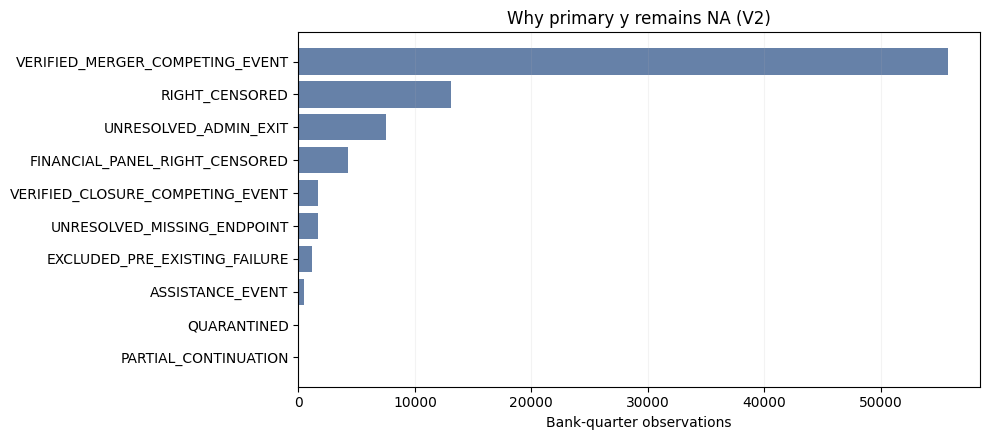

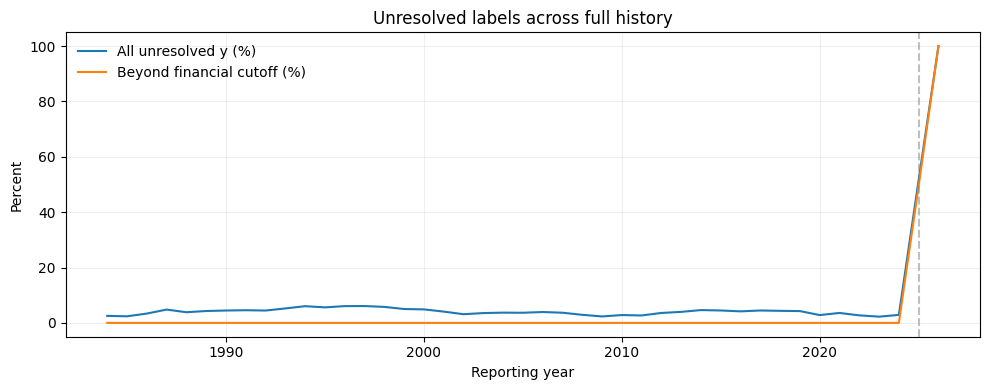

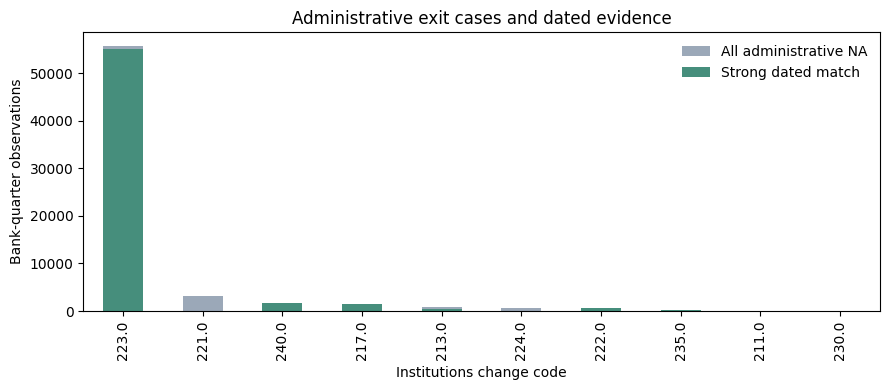

In [215]:
# 8.3B — Three distinct visual diagnostics (not redundant with summary tables)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,4.5))
top = V2_NA_STATUS.head(10).iloc[::-1]
ax.barh(top.outcome_status_4q_v2.astype(str), top.rows,color='#6681a8')
ax.set(title='Why primary y remains NA (V2)',xlabel='Bank-quarter observations')
ax.grid(axis='x',alpha=.15); fig.tight_layout();plt.show()

trend = (Y_LABELS_V2.assign(year=lambda d:d.REPDTE.dt.year,
    na=lambda d:d.y_primary_4q_v2.isna(),
    beyond_fin=lambda d:d.y_primary_4q_v2.isna() & ~d.FINANCIAL_MATURE_V2)
    .groupby('year').agg(total=('CERT','size'),na=('na','sum'),
                         beyond_fin=('beyond_fin','sum')).reset_index())
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(trend.year,100*trend.na/trend.total,label='All unresolved y (%)')
ax.plot(trend.year,100*trend.beyond_fin/trend.total,
        label='Beyond financial cutoff (%)')
ax.axvline(2025,linestyle='--',alpha=.5,color='gray')
ax.set(xlabel='Reporting year',ylabel='Percent',title='Unresolved labels across full history')
ax.legend(frameon=False);ax.grid(alpha=.2);fig.tight_layout();plt.show()

codes = (ADMIN_RECON_V2.groupby('INSTITUTIONS_CODE',dropna=False)
    .agg(rows=('CERT','size'),strong=('HISTORY_CONFIDENT_V2','sum'))
    .sort_values('rows',ascending=False).head(10))
fig, ax = plt.subplots(figsize=(9,4))
codes.rows.plot(kind='bar',ax=ax,color='#9ba8b8',label='All administrative NA')
codes.strong.plot(kind='bar',ax=ax,color='#468e7c',label='Strong dated match')
ax.set(title='Administrative exit cases and dated evidence',xlabel='Institutions change code',
       ylabel='Bank-quarter observations')
ax.legend(frameon=False);fig.tight_layout();plt.show()

## 5.4 — Archive V2 source-pinned handoff

Export the **strict V2 alternative** and its technical gates with SHA checks. It remains useful for sensitivity comparison, but **Section 8 contains the recommended V3 handoff**. Keep both labels versioned; do not change prior artifacts.

In [216]:
# 8.4 — Atomic, SHA-pinned label V2 and Phase 3 handoff
import json, os
from datetime import datetime, timezone

src_tag = (file_hash_v2(HISTORY_PATH_V2)[:12]
           if HISTORY_PATH_V2 is not None else 'history_missing')
PHASE2_V2_DIR = (Path(RUN_DIR) if 'RUN_DIR' in globals() else
                 ROOT / 'reports' / 'phase2' / 'fix_audit') / 'label_v2' / src_tag
PHASE2_V2_DIR.mkdir(parents=True, exist_ok=True)

def write_pinned_v2(df, name):
    # CSV always available, parquet preferred on machines with pyarrow.
    try:
        import pyarrow  # noqa: F401
        suffix = '.parquet'
        dest = PHASE2_V2_DIR / (name + suffix)
        stage = Path(str(dest)+'.stage')
        df.to_parquet(stage,index=False)
    except ImportError:
        suffix = '.csv'
        dest = PHASE2_V2_DIR / (name + suffix)
        stage = Path(str(dest)+'.stage')
        df.to_csv(stage,index=False)
    sha_new = file_hash_v2(stage)
    if dest.exists():
        if file_hash_v2(dest) != sha_new:
            stage.unlink()
            raise RuntimeError('Different evidence already exists: '+str(dest))
        stage.unlink()
    else:
        os.replace(stage,dest)
    return {'path':str(dest),'sha256':file_hash_v2(dest),'rows':int(len(df))}

ARTIFACT_V2 = {
    'bank_quarter_labels_v2':write_pinned_v2(Y_LABELS_V2,'bank_quarter_labels_v2'),
    'admin_exit_reconciliation_v2':write_pinned_v2(ADMIN_RECON_V2,'admin_exit_reconciliation_v2'),
    'admin_exit_summary_v2':write_pinned_v2(ADMIN_SUMMARY_V2,'admin_exit_summary_v2'),
    'na_outcome_status_v2':write_pinned_v2(V2_NA_STATUS,'na_outcome_status_v2'),
}

GATES_V2 = {
    'all_bank_quarter_rows_retained':len(Y_LABELS_V2)==len(LABELS),
    'keys_unique':not Y_LABELS_V2.duplicated(['CERT','REPDTE']).any(),
    'primary_labels_unchanged':Y_LABELS_V2.y_primary_4q_v2.equals(
        LABELS.label_screened_4q.reset_index(drop=True).astype('Int8')),
    'eligible_matches_FIX01':bool((chk.MODEL_ELIGIBLE_V2==chk.P2_MODEL_ELIGIBLE).all()),
    'no_censored_target_eligible':not (Y_LABELS_V2.MODEL_ELIGIBLE_V2
                                      & Y_LABELS_V2.y_primary_4q_v2.isna()).any(),
    'admin_cases_reconciled':len(ADMIN_RECON_V2)==len(ADMIN_NA_V2),
    'outcome_status_complete':Y_LABELS_V2.outcome_status_4q_v2.notna().all(),
}
GATES_V2 = {name: bool(ok) for name, ok in GATES_V2.items()}
assert all(GATES_V2.values()),'V2 technical gates failed'
PHASE2_V2_MANIFEST = {
    'phase':'PHASE2',
    'revision':'dual_clock_fdic_history_source_audited_v2',
    'created_at_utc':datetime.now(timezone.utc).isoformat(),
    'financial_asof':str(FINANCIAL_ASOF_V2.date()),
    'failure_asof':str(EVENT_ASOF_V2.date()),
    'history_source_status':HISTORY_STATUS_V2,
    'history_source_verified':bool(HISTORY_VERIFIED_V2),
    'history_sha256':file_hash_v2(HISTORY_PATH_V2) if HISTORY_PATH_V2 else None,
    'original_label_rows':len(LABELS),
    'primary_y1':int(Y_LABELS_V2.y_primary_4q_v2.eq(1).sum()),
    'primary_y0':int(Y_LABELS_V2.y_primary_4q_v2.eq(0).sum()),
    'primary_NA':int(Y_LABELS_V2.y_primary_4q_v2.isna().sum()),
    'model_eligible_rows':int(Y_LABELS_V2.MODEL_ELIGIBLE_V2.sum()),
    'admin_history_confident_rows':int(ADMIN_RECON_V2.HISTORY_CONFIDENT_V2.sum()),
    'phase3_label_file':ARTIFACT_V2['bank_quarter_labels_v2']['path'],
    'phase3_label_column':'y_primary_4q_v2',
    'phase3_filter_column':'MODEL_ELIGIBLE_V2',
    'phase3_sensitive_alternative':'y_sensitivity_4q',
    'phase3_forbidden_predictors':[
        'FAILURE_DATE','ASSISTANCE_DATE','END_DATE','CHANGEC1',
        'INSTITUTIONS_CODE','EFFDATE','CHANGECODE','CHANGECODE_DESC',
        'ADMIN_REVIEW_V2','outcome_status_4q_v2','censor_reason',
        'EVENT_MATURE_V2','FINANCIAL_MATURE_V2','ENDPOINT_OBSERVED',
        'HORIZON_END','y_sensitivity_4q','y_primary_4q_v2'],
    'label_release_status':'PROVISIONAL_REQUIRES_EVENT_ADJUDICATION',
    'technical_gates':GATES_V2,
    'artifacts':ARTIFACT_V2,
    'note':'Merger/closure/failure-review are audit statuses, never automatic y=0 or y=1.'
}
PHASE2_V2_HANDOFF = PHASE2_V2_DIR/'phase2_to_phase3_handoff_v2.json'
if PHASE2_V2_HANDOFF.exists():
    previous = json.loads(PHASE2_V2_HANDOFF.read_text(encoding='utf-8'))
    canonical = lambda p: {k:v for k,v in p.items() if k!='created_at_utc'}
    assert canonical(previous)==canonical(PHASE2_V2_MANIFEST), (
        'Handoff changed under same snapshot/version; inspect drift before overwriting')
else:
    stage = Path(str(PHASE2_V2_HANDOFF)+'.stage')
    stage.write_text(json.dumps(PHASE2_V2_MANIFEST,indent=2,ensure_ascii=False),encoding='utf-8')
    os.replace(stage,PHASE2_V2_HANDOFF)
print('PHASE 2 V2 TECHNICAL GATES:',sum(GATES_V2.values()),'/',len(GATES_V2),'PASS')
print('Source History:',HISTORY_STATUS_V2)
print('Handoff Phase 3:',PHASE2_V2_HANDOFF)
print('Labels:',ARTIFACT_V2['bank_quarter_labels_v2']['path'])
display(pd.DataFrame([{'gate':k,'passed':bool(v)} for k,v in GATES_V2.items()]))

PHASE 2 V2 TECHNICAL GATES: 7 / 7 PASS
Source History: FDIC_HISTORY_SHA_VERIFIED
Handoff Phase 3: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v2\0a842bef9739\phase2_to_phase3_handoff_v2.json
Labels: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v2\0a842bef9739\bank_quarter_labels_v2.parquet


,gate,passed
0,all_bank_quarter_rows_retained,True
1,keys_unique,True
2,primary_labels_unchanged,True
3,eligible_matches_FIX01,True
4,no_censored_target_eligible,True
5,admin_cases_reconciled,True
6,outcome_status_complete,True


<a id="p2-s6"></a>
# 6 — Event-based V3 target: resolving missing labels

**Decision:** `y_failure_4q_v3=1` for FDIC-confirmed failure within four quarters; `0` for mature horizons without a recorded failure; `NA` for immature or excluded cases. This definition removes the requirement of four subsequent financial reports and retains the original V2 labels for sensitivity analysis.

**Observed comparison:** V2 had 85,791 `NA`; V3 has **14,316**, resolving **71,475 (83.31%)**—all newly assigned to 0. Of the remaining cases, 13,070 are right-censored, 1,176 had failed before the prediction date, and 70 are quarantined. The 7,514 unresolved administrative cases labeled 0 under this policy are flagged for a separate robustness cohort.

**Reproducibility fix:** The uploaded notebook had the V3 *audit* but not the V3 *construction* cell. The next cell restores the exact event-based policy as a separate, additive step.

## 6.1 — Construct V3 from verified event registry

No original source, V2 label or financial predictor column is modified.

In [217]:
# ============================================================
# 6.1 — REPRODUCIBLE V3 EVENT-BASED TARGET RECONSTRUCTION
# Restores the previously used V3 construction missing in the
# uploaded notebook. Leaves LABELS, EVENTS and Y_LABELS_V2 unchanged.
# No additional imports / no network calls.
# ============================================================

for _name in ("Y_LABELS_V2", "EVENTS", "HISTORY_VERIFIED_V2", "EVENT_ASOF_V2", "FINANCIAL_ASOF_V2"):
    assert _name in globals(), f"Missing required upstream variable: {_name}"
assert bool(HISTORY_VERIFIED_V2), "FDIC History must pass the source audit"
assert "failures" in EVENTS, "Official FDIC failure registry unavailable"

Y_LABELS_V3 = Y_LABELS_V2.copy()
_required_v3 = {"CERT", "REPDTE", "HORIZON_END", "y_primary_4q_v2",
                "outcome_status_4q_v2", "ADMIN_REVIEW_V2", "MODEL_ELIGIBLE_V2"}
assert _required_v3.issubset(Y_LABELS_V3.columns), (
    "Missing V2 columns: " + str(sorted(_required_v3 - set(Y_LABELS_V3.columns))))

Y_LABELS_V3["CERT"] = pd.to_numeric(Y_LABELS_V3["CERT"], errors="raise").astype("int64")
for _col in ("REPDTE", "HORIZON_END"):
    Y_LABELS_V3[_col] = pd.to_datetime(Y_LABELS_V3[_col], errors="raise")
assert not Y_LABELS_V3.duplicated(["CERT", "REPDTE"]).any()

_v3_failure_registry = EVENTS["failures"][["CERT", "FAILURE_DATE"]].copy()
_v3_failure_registry["CERT"] = pd.to_numeric(
    _v3_failure_registry["CERT"], errors="raise").astype("int64")
_v3_failure_registry["FAILURE_DATE"] = pd.to_datetime(
    _v3_failure_registry["FAILURE_DATE"], errors="raise")
assert _v3_failure_registry["CERT"].is_unique
assert _v3_failure_registry["FAILURE_DATE"].notna().all()

Y_LABELS_V3 = Y_LABELS_V3.merge(
    _v3_failure_registry, on="CERT", how="left", validate="many_to_one")

_v3_q = Y_LABELS_V3["REPDTE"]
_v3_h = Y_LABELS_V3["HORIZON_END"]
_v3_f = Y_LABELS_V3["FAILURE_DATE"]
_v3_event_asof = pd.Timestamp(EVENT_ASOF_V2)
_v3_financial_asof = pd.Timestamp(FINANCIAL_ASOF_V2)

_v3_preexisting = _v3_f.notna() & _v3_f.le(_v3_q)
_v3_observed_failure = (
    _v3_f.gt(_v3_q) & _v3_f.le(_v3_h) & _v3_f.le(_v3_event_asof)
).fillna(False)
_v3_horizon_mature = _v3_h.le(_v3_event_asof)
_v3_ambiguous_certs = set(EVENTS.get("ambiguous_failure_certs", set()))
_v3_ambiguous = (
    Y_LABELS_V3["CERT"].isin(_v3_ambiguous_certs)
    | Y_LABELS_V3["outcome_status_4q_v2"].eq("QUARANTINED")
).fillna(False)
_v3_valid_risk = (~_v3_preexisting & ~_v3_ambiguous).fillna(False)

_v3_target = pd.Series(pd.NA, index=Y_LABELS_V3.index, dtype="Int8")
_v3_target.loc[_v3_valid_risk & _v3_observed_failure] = 1
_v3_target.loc[_v3_valid_risk & _v3_horizon_mature & ~_v3_observed_failure] = 0
Y_LABELS_V3["y_failure_4q_v3"] = _v3_target

Y_LABELS_V3["outcome_status_4q_v3"] = np.select(
    [_v3_ambiguous, _v3_preexisting,
     _v3_observed_failure & _v3_valid_risk,
     _v3_horizon_mature & _v3_valid_risk],
    ["EXCLUDED_CONFLICTING_FAILURE_DATE", "EXCLUDED_PRE_EXISTING_FAILURE",
     "FDIC_CONFIRMED_FAILURE", "NO_FDIC_FAILURE_WITHIN_4Q"],
    default="RIGHT_CENSORED"
)
Y_LABELS_V3["EVENT_MATURE_V3"] = _v3_horizon_mature
Y_LABELS_V3["MODEL_ELIGIBLE_V3"] = (
    _v3_target.notna() & _v3_horizon_mature
    & _v3_q.le(_v3_financial_asof) & _v3_valid_risk
).fillna(False)
Y_LABELS_V3["HIGH_RISK_REVIEW_V3"] = Y_LABELS_V3["ADMIN_REVIEW_V2"].isin([
    "POSSIBLE_FAILURE_REQUIRES_REGISTRY", "DATED_EVENT_UNCONFIRMED",
    "UNRESOLVED_ADMIN_EXIT", "CONFLICTING_DATED_EVENTS"])
Y_LABELS_V3["ROBUSTNESS_ELIGIBLE_V3"] = (
    Y_LABELS_V3["MODEL_ELIGIBLE_V3"] & ~Y_LABELS_V3["HIGH_RISK_REVIEW_V3"])

_v3_old_y = pd.to_numeric(Y_LABELS_V3["y_primary_4q_v2"], errors="coerce")
assert not (_v3_old_y.eq(1).fillna(False) &
            ~_v3_target.eq(1).fillna(False)).any(), "V2 positives lost in V3"
assert not (_v3_old_y.eq(0).fillna(False) &
            ~_v3_target.eq(0).fillna(False)).any(), "V2 negatives lost in V3"
assert len(Y_LABELS_V3) == len(Y_LABELS_V2)
assert not (Y_LABELS_V3["MODEL_ELIGIBLE_V3"] & _v3_target.isna()).any()

print("V3 reconstructed:", f"{len(Y_LABELS_V3):,}", "bank-quarters")
print("V2 NA:", f"{int(_v3_old_y.isna().sum()):,}",
      "| V3 NA:", f"{int(_v3_target.isna().sum()):,}")
print("V3 train-eligible:", f"{int(Y_LABELS_V3.MODEL_ELIGIBLE_V3.sum()):,}")
print("PASS — V2 and EVENTS unchanged; V3 target is a separate table.")

V3 reconstructed: 1,682,616 bank-quarters
V2 NA: 85,791 | V3 NA: 14,316
V3 train-eligible: 1,668,293
PASS — V2 and EVENTS unchanged; V3 target is a separate table.


In [218]:

# ============================================================
# PHASE 2 — V3 NA RESOLUTION | FIXED FINAL AUDIT
# Fix pandas nullable Int8 / pd.NA conversion error
# Continue from the previously computed Y_LABELS_V3
# No modification to original labels
# ============================================================

import pandas as pd
from IPython.display import display

assert "Y_LABELS_V3" in globals(), (
    "Y_LABELS_V3 not found. Run V3 construction first."
)

df = Y_LABELS_V3

old_y = pd.to_numeric(
    df["y_primary_4q_v2"],
    errors="coerce"
)

new_y = pd.to_numeric(
    df["y_failure_4q_v3"],
    errors="coerce"
)

# ============================================================
# 1. BEFORE / AFTER SUMMARY
# ============================================================

comparison = pd.DataFrame([
    {
        "version": "V2 strict",
        "y0": int(old_y.eq(0).sum()),
        "y1": int(old_y.eq(1).sum()),
        "NA": int(old_y.isna().sum()),
        "eligible": int(
            df["MODEL_ELIGIBLE_V2"].fillna(False).sum()
        )
    },
    {
        "version": "V3 event-based",
        "y0": int(new_y.eq(0).sum()),
        "y1": int(new_y.eq(1).sum()),
        "NA": int(new_y.isna().sum()),
        "eligible": int(
            df["MODEL_ELIGIBLE_V3"].fillna(False).sum()
        )
    }
])

comparison["NA_pct"] = (
    100 * comparison["NA"] / len(df)
).round(3)

print("========== V2 VS V3 LABEL COMPARISON ==========")
display(comparison)


# ============================================================


========== V2 VS V3 LABEL COMPARISON ==========


,version,y0,y1,NA,eligible,NA_pct
0,V2 strict,1585966,10859,85791,1596814,5.099
1,V3 event-based,1657441,10859,14316,1668293,0.851


##### Run block 2/5 — Resolution by root cause

In [219]:
# 2. EXACT NA RESOLUTION BY ROOT CAUSE
# ============================================================

previously_na = old_y.isna()

na_audit = df.loc[
    previously_na,
    [
        "CERT",
        "outcome_status_4q_v2",
        "y_failure_4q_v3"
    ]
].copy()

# CRITICAL FIX:
# Nullable boolean -> fillna(False) -> integer

na_audit["resolved_to_0"] = (
    na_audit["y_failure_4q_v3"]
    .eq(0)
    .fillna(False)
    .astype("int64")
)

na_audit["resolved_to_1"] = (
    na_audit["y_failure_4q_v3"]
    .eq(1)
    .fillna(False)
    .astype("int64")
)

na_audit["still_NA"] = (
    na_audit["y_failure_4q_v3"]
    .isna()
    .astype("int64")
)

resolution_detail = (
    na_audit
    .groupby(
        "outcome_status_4q_v2",
        dropna=False
    )
    .agg(
        original_NA=("CERT", "size"),
        banks=("CERT", "nunique"),
        resolved_to_0=("resolved_to_0", "sum"),
        resolved_to_1=("resolved_to_1", "sum"),
        still_NA=("still_NA", "sum")
    )
    .reset_index()
    .sort_values(
        "original_NA",
        ascending=False
    )
)

resolution_detail["resolved_total"] = (
    resolution_detail["resolved_to_0"]
    + resolution_detail["resolved_to_1"]
)

resolution_detail["resolution_pct"] = (
    100
    * resolution_detail["resolved_total"]
    / resolution_detail["original_NA"]
).round(2)

print("\n========== EXACT NA RESOLUTION ==========")
display(resolution_detail)


# ============================================================



========== EXACT NA RESOLUTION ==========


,outcome_status_4q_v2,original_NA,banks,resolved_to_0,resolved_to_1,still_NA,resolved_total,resolution_pct
9,VERIFIED_MERGER_COMPETING_EVENT,55754,14162,55754,0,0,55754,100.0
5,RIGHT_CENSORED,13070,4415,0,0,13070,0,0.0
6,UNRESOLVED_ADMIN_EXIT,7514,2059,7514,0,0,7514,100.0
2,FINANCIAL_PANEL_RIGHT_CENSORED,4273,4273,4273,0,0,4273,100.0
8,VERIFIED_CLOSURE_COMPETING_EVENT,1714,481,1714,0,0,1714,100.0
7,UNRESOLVED_MISSING_ENDPOINT,1646,869,1646,0,0,1646,100.0
1,EXCLUDED_PRE_EXISTING_FAILURE,1176,267,0,0,1176,0,0.0
0,ASSISTANCE_EVENT,504,176,504,0,0,504,100.0
4,QUARANTINED,70,3,0,0,70,0,0.0
3,PARTIAL_CONTINUATION,70,28,70,0,0,70,100.0


##### Run block 3/5 — Eligible cohorts

In [220]:
# 3. TRAINING COHORT SUMMARY
# ============================================================

training_summary = pd.DataFrame([{
    "V3_model_eligible": int(
        df["MODEL_ELIGIBLE_V3"]
        .fillna(False)
        .sum()
    ),
    "V3_robustness_eligible": int(
        df["ROBUSTNESS_ELIGIBLE_V3"]
        .fillna(False)
        .sum()
    ),
    "high_risk_admin_review": int(
        df["HIGH_RISK_REVIEW_V3"]
        .fillna(False)
        .sum()
    ),
    "V3_positive_eligible": int(
        (
            df["MODEL_ELIGIBLE_V3"].fillna(False)
            & new_y.eq(1).fillna(False)
        ).sum()
    )
}])

print("\n========== TRAINING COHORTS ==========")
display(training_summary)


# ============================================================



========== TRAINING COHORTS ==========


,V3_model_eligible,V3_robustness_eligible,high_risk_admin_review,V3_positive_eligible
0,1668293,1660779,7514,10852


##### Run block 4/5 — Reconciliation assertions

In [221]:
# 4. CONSISTENCY CHECKS
# ============================================================

assert len(df) == len(Y_LABELS_V2)

assert not df.duplicated(
    ["CERT", "REPDTE"]
).any()

assert (
    resolution_detail["original_NA"]
    == (
        resolution_detail["resolved_to_0"]
        + resolution_detail["resolved_to_1"]
        + resolution_detail["still_NA"]
    )
).all(), "NA accounting mismatch"

assert (
    resolution_detail["original_NA"].sum()
    == int(old_y.isna().sum())
), "Original NA count mismatch"

resolved_count = int(
    (
        previously_na
        & new_y.notna()
    ).sum()
)

assert resolved_count == int(
    resolution_detail["resolved_total"].sum()
)

assert (
    int(new_y.eq(0).sum())
    + int(new_y.eq(1).sum())
    + int(new_y.isna().sum())
    == len(df)
), "V3 target count mismatch"


# ============================================================


##### Run block 5/5 — Final numerical summary

In [222]:
# 5. FINAL SUMMARY
# ============================================================

print("\n========== FINAL V3 NA RESOLUTION ==========")

print(f"Original V2 NA : {old_y.isna().sum():,}")
print(f"Resolved NA    : {resolved_count:,}")
print(f"Remaining V3 NA: {new_y.isna().sum():,}")

print(
    "Resolution rate:",
    f"{100 * resolved_count / old_y.isna().sum():.2f}%"
)

print("\nPASS — V3 NA accounting checks completed.")
print("Original V2 labels remain unchanged.")
print("No files were written.")



========== FINAL V3 NA RESOLUTION ==========
Original V2 NA : 85,791
Resolved NA    : 71,475
Remaining V3 NA: 14,316
Resolution rate: 83.31%

PASS — V3 NA accounting checks completed.
Original V2 labels remain unchanged.
No files were written.


### Visual interpretation — What V3 actually resolved

The original 55,754 merger exits and 1,714 closures are predominantly recategorized as **no FDIC failure in a mature window**, not independently verified survival. The 7,514 unresolved administrative cases also become 0 under the event-based policy: evaluate both the main and robustness cohorts. Right-censoring is not forced into 0.

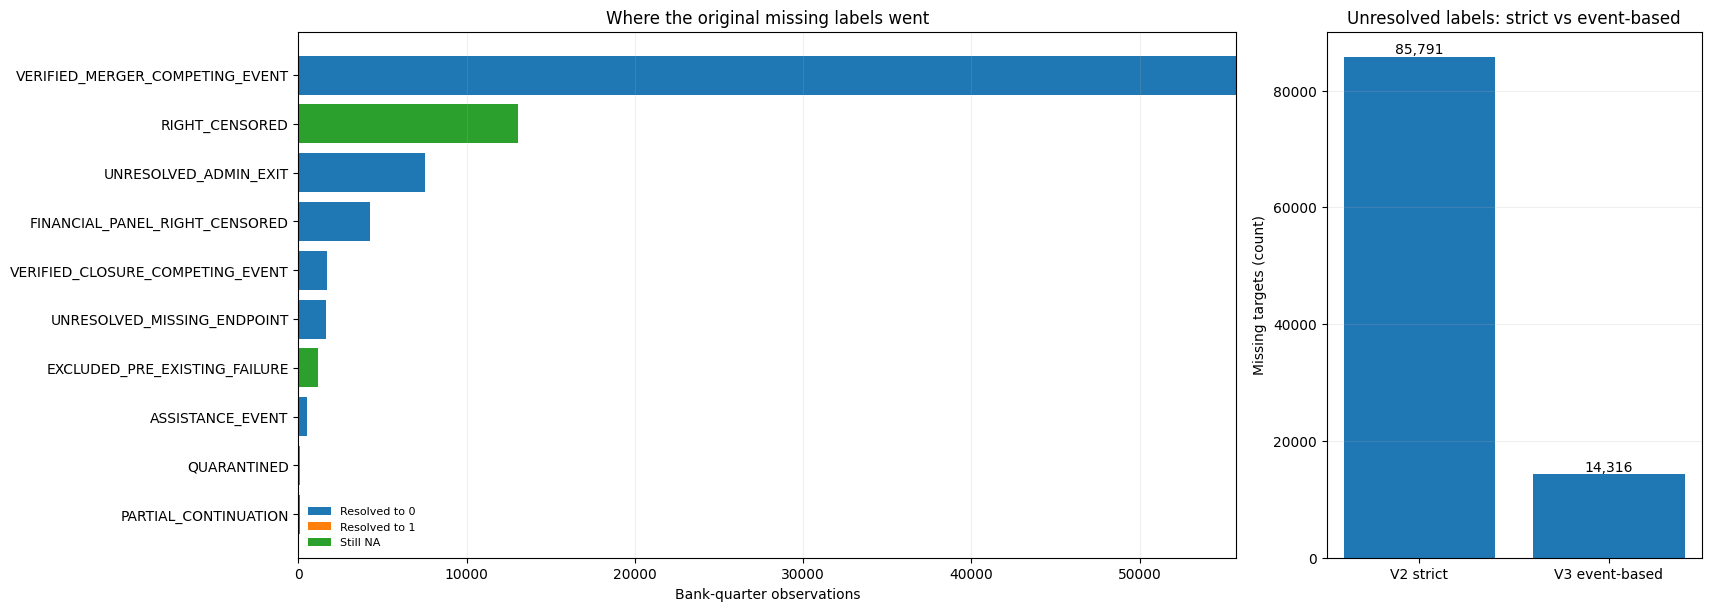

In [223]:
# 6.1 — VISUALIZE THE EXISTING V2 -> V3 NA RESOLUTION TABLE
# Only uses output tables from the preceding audit. No imports.
assert "resolution_detail" in globals() and "comparison" in globals()
_na_plot = resolution_detail.sort_values("original_NA").copy()
fig, axes = plt.subplots(1, 2, figsize=(17, 6), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2.5, 1]})
axes[0].barh(_na_plot["outcome_status_4q_v2"], _na_plot["resolved_to_0"],
             label="Resolved to 0")
axes[0].barh(_na_plot["outcome_status_4q_v2"], _na_plot["resolved_to_1"],
             left=_na_plot["resolved_to_0"], label="Resolved to 1")
axes[0].barh(_na_plot["outcome_status_4q_v2"], _na_plot["still_NA"],
             left=_na_plot["resolved_total"], label="Still NA")
axes[0].set(title="Where the original missing labels went", xlabel="Bank-quarter observations")
axes[0].grid(axis="x", alpha=.2)
axes[0].legend(frameon=False, fontsize=8)
axes[1].bar(comparison["version"], comparison["NA"])
axes[1].set(title="Unresolved labels: strict vs event-based", ylabel="Missing targets (count)")
axes[1].grid(axis="y", alpha=.2)
for idx, nval in enumerate(comparison["NA"]):
    axes[1].text(idx, nval, f"{int(nval):,}", ha="center", va="bottom")
plt.show()

## 6.2 — Distribution of positive labels by prediction date

Count eligible `y=1` by the date of prediction (`REPDTE`), then inspect yearly rates and quarterly timing. Do not confuse multiple positive bank-quarters with distinct failed banks.

In [224]:

# ============================================================
# PHASE 2 — V3 FAILURE LABEL TEMPORAL DISTRIBUTION
# Append at the very bottom of Phase 2
#
# No new imports.
# No modification to Y_LABELS_V3.
# Time reference: REPDTE (prediction date), NOT FAILURE_DATE.
# Only MODEL_ELIGIBLE_V3 == True.
# ============================================================

assert "Y_LABELS_V3" in globals(), "Run V3 label construction first."

required = [
    "CERT", "REPDTE", "y_failure_4q_v3",
    "MODEL_ELIGIBLE_V3"
]
assert set(required).issubset(Y_LABELS_V3.columns)

# ------------------------------------------------------------
# 1. PREPARE TRAINING-ELIGIBLE LABELS
# ------------------------------------------------------------

TEMPORAL_V3 = Y_LABELS_V3.loc[
    Y_LABELS_V3["MODEL_ELIGIBLE_V3"].fillna(False),
    required
].copy()

TEMPORAL_V3["REPDTE"] = pd.to_datetime(
    TEMPORAL_V3["REPDTE"], errors="raise"
)

TEMPORAL_V3["y"] = pd.to_numeric(
    TEMPORAL_V3["y_failure_4q_v3"],
    errors="raise"
).astype("int8")

assert TEMPORAL_V3["y"].isin([0, 1]).all()

TEMPORAL_V3["YEAR"] = TEMPORAL_V3["REPDTE"].dt.year
TEMPORAL_V3["QUARTER"] = TEMPORAL_V3["REPDTE"].dt.to_period("Q")

# ------------------------------------------------------------
# 2. ANNUAL STATISTICS
# ------------------------------------------------------------

Y_ANNUAL_V3 = (
    TEMPORAL_V3
    .groupby("YEAR")
    .agg(
        total_obs=("y", "size"),
        y1=("y", "sum"),
        banks=("CERT", "nunique")
    )
    .reset_index()
)

Y_ANNUAL_V3["y0"] = (
    Y_ANNUAL_V3["total_obs"] - Y_ANNUAL_V3["y1"]
)

Y_ANNUAL_V3["failure_rate_pct"] = (
    100 * Y_ANNUAL_V3["y1"] /
    Y_ANNUAL_V3["total_obs"]
)

# ------------------------------------------------------------
# 3. QUARTERLY STATISTICS
# ------------------------------------------------------------

Y_QUARTERLY_V3 = (
    TEMPORAL_V3
    .groupby("QUARTER")
    .agg(
        total_obs=("y", "size"),
        y1=("y", "sum"),
        banks=("CERT", "nunique")
    )
    .reset_index()
)

Y_QUARTERLY_V3["y0"] = (
    Y_QUARTERLY_V3["total_obs"] - Y_QUARTERLY_V3["y1"]
)

Y_QUARTERLY_V3["failure_rate_pct"] = (
    100 * Y_QUARTERLY_V3["y1"] /
    Y_QUARTERLY_V3["total_obs"]
)

Y_QUARTERLY_V3["quarter_end"] = (
    Y_QUARTERLY_V3["QUARTER"].dt.to_timestamp(how="end")
    .dt.normalize()
)

# ------------------------------------------------------------


##### Run block 2/3 — Temporal distribution charts

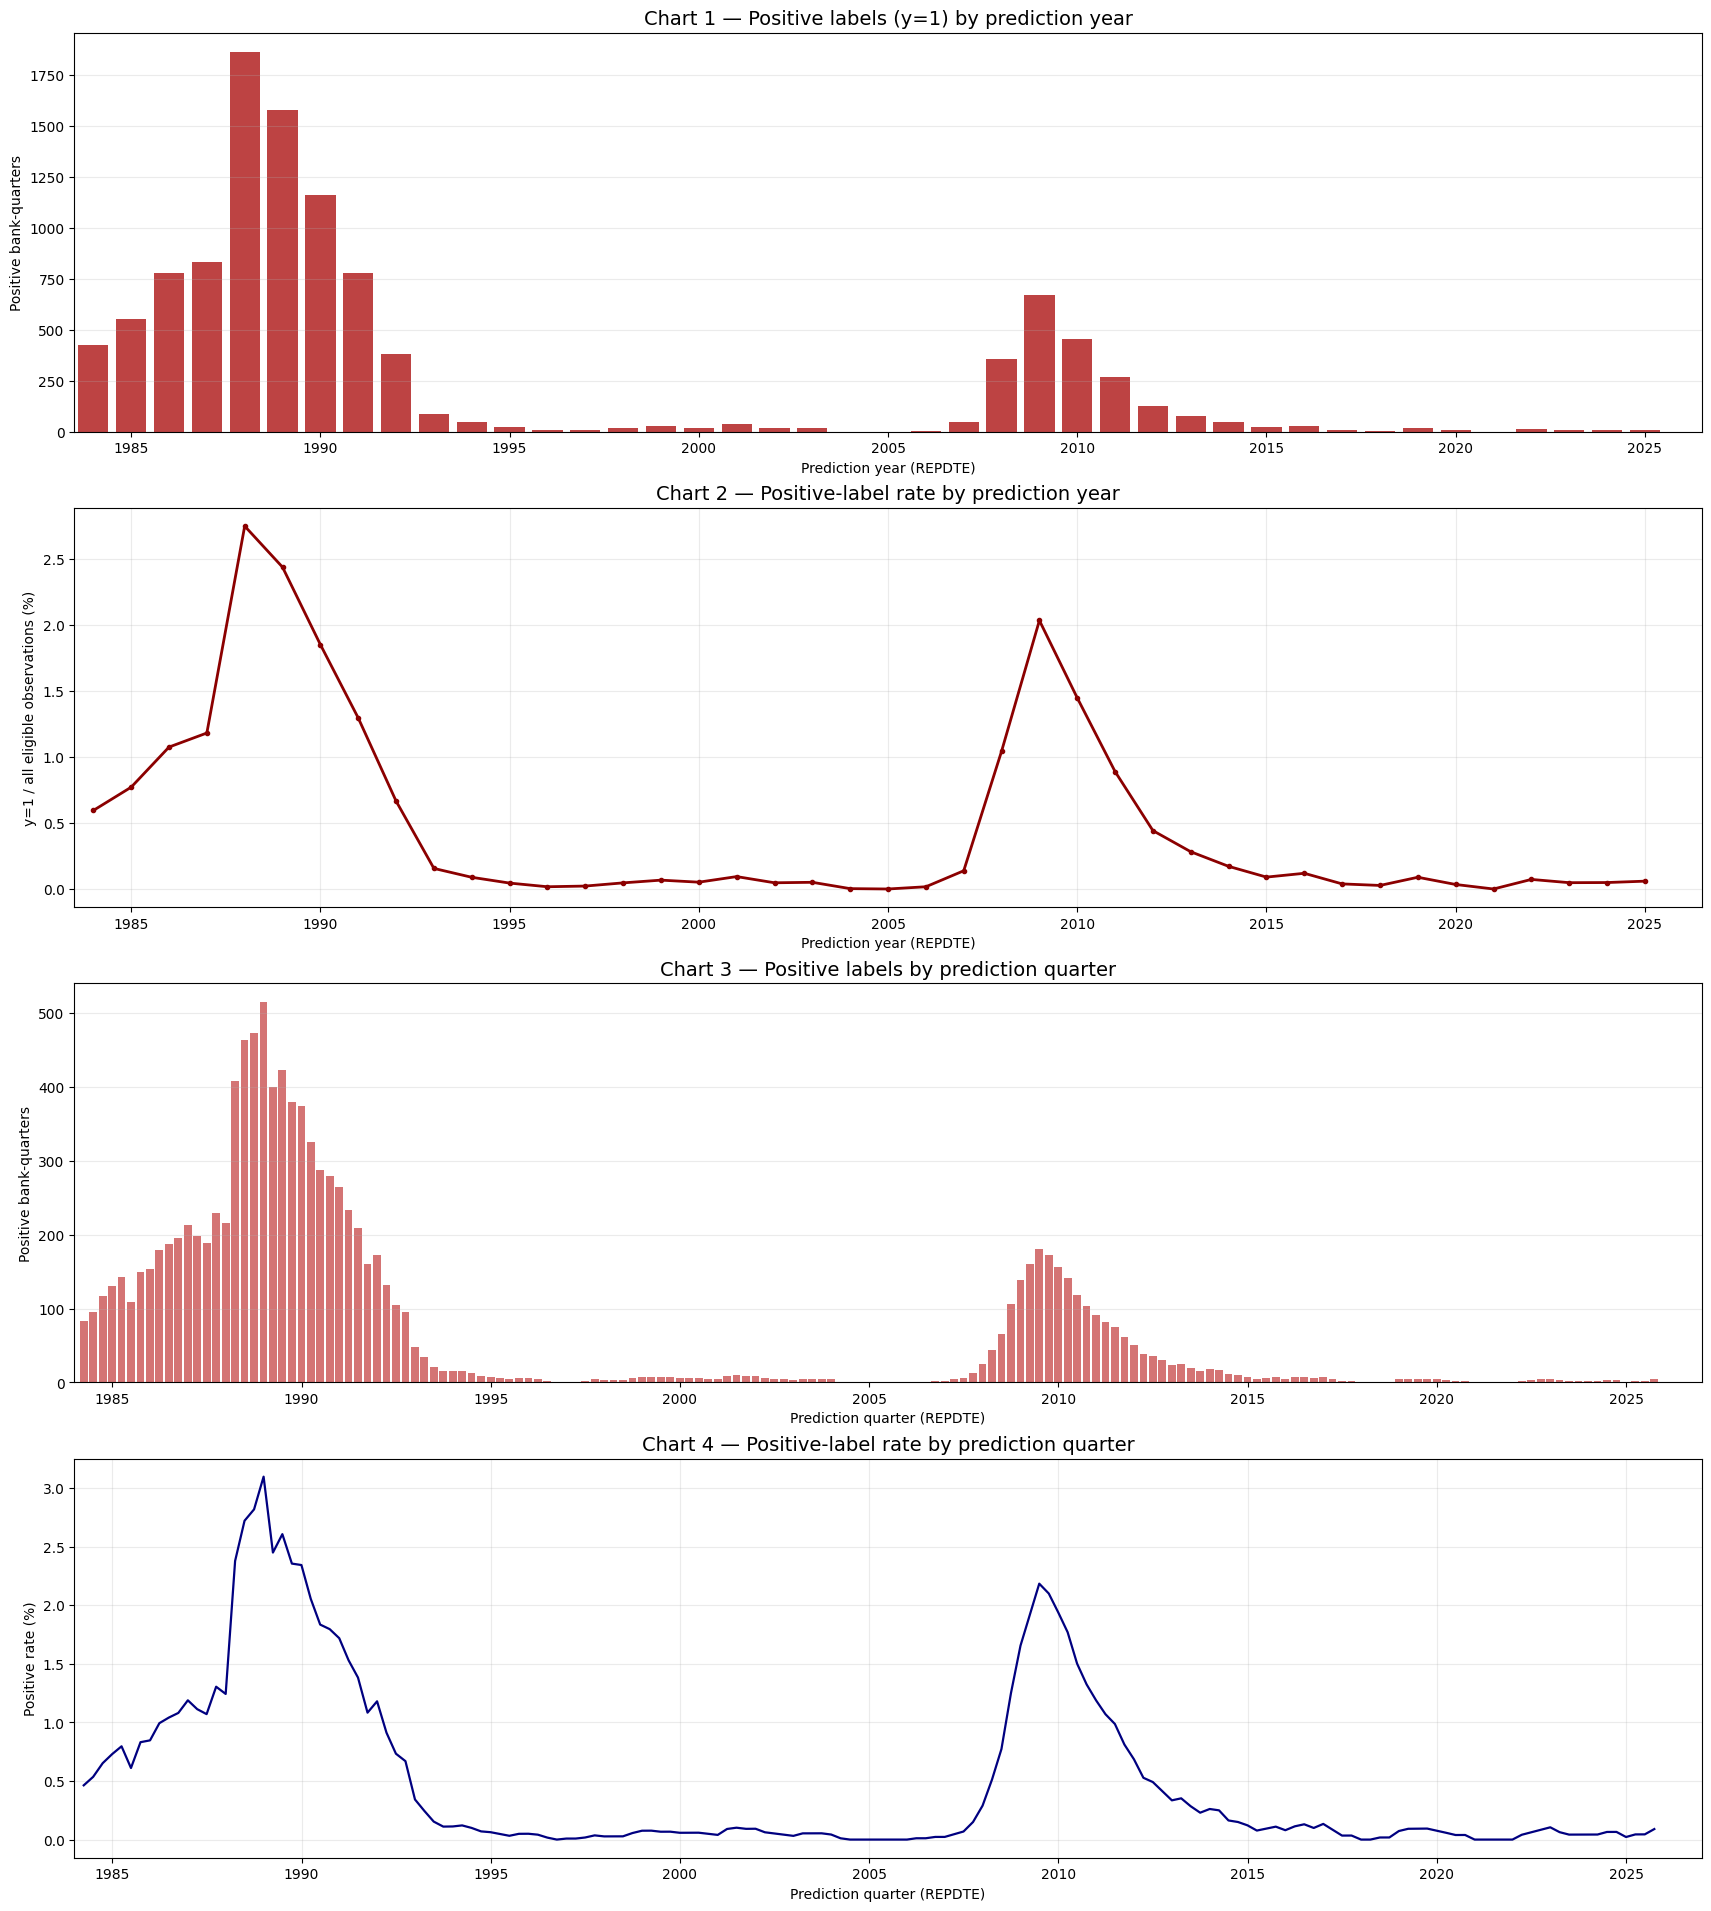

In [225]:
# 4. CHARTS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 1, figsize=(17, 19),
    constrained_layout=True
)

# Chart 1: Number of positive bank-quarters by year
axes[0].bar(
    Y_ANNUAL_V3["YEAR"],
    Y_ANNUAL_V3["y1"],
    color="firebrick",
    alpha=0.85
)
axes[0].set_title(
    "Chart 1 — Positive labels (y=1) by prediction year",
    fontsize=14
)
axes[0].set_ylabel("Positive bank-quarters")
axes[0].set_xlabel("Prediction year (REPDTE)")
axes[0].grid(axis="y", alpha=0.25)

# Chart 2: Failure label rate by year
axes[1].plot(
    Y_ANNUAL_V3["YEAR"],
    Y_ANNUAL_V3["failure_rate_pct"],
    color="darkred",
    linewidth=2,
    marker="o",
    markersize=3
)
axes[1].set_title(
    "Chart 2 — Positive-label rate by prediction year",
    fontsize=14
)
axes[1].set_ylabel("y=1 / all eligible observations (%)")
axes[1].set_xlabel("Prediction year (REPDTE)")
axes[1].grid(alpha=0.25)

# Chart 3: Positive labels by quarter
axes[2].bar(
    Y_QUARTERLY_V3["quarter_end"],
    Y_QUARTERLY_V3["y1"],
    width=75,
    color="indianred",
    alpha=0.85
)
axes[2].set_title(
    "Chart 3 — Positive labels by prediction quarter",
    fontsize=14
)
axes[2].set_ylabel("Positive bank-quarters")
axes[2].set_xlabel("Prediction quarter (REPDTE)")
axes[2].grid(axis="y", alpha=0.25)

# Chart 4: Quarterly positive-label rate
axes[3].plot(
    Y_QUARTERLY_V3["quarter_end"],
    Y_QUARTERLY_V3["failure_rate_pct"],
    color="navy",
    linewidth=1.6
)
axes[3].set_title(
    "Chart 4 — Positive-label rate by prediction quarter",
    fontsize=14
)
axes[3].set_ylabel("Positive rate (%)")
axes[3].set_xlabel("Prediction quarter (REPDTE)")
axes[3].grid(alpha=0.25)

for ax in axes:
    ax.set_xlim(
        pd.Timestamp("1984-01-01"),
        pd.Timestamp("2026-12-31")
    ) if ax in [axes[2], axes[3]] else ax.set_xlim(1983.5, 2026.5)

plt.show()

# ------------------------------------------------------------


##### Run block 3/3 — Numerical summaries for split design

In [226]:
# 5. NUMERICAL OUTPUT FOR SPLIT DECISION
# ------------------------------------------------------------

print("\n========== ANNUAL FAILURE DISTRIBUTION ==========")

display(
    Y_ANNUAL_V3.assign(
        failure_rate_pct=lambda x:
            x["failure_rate_pct"].round(3)
    )
)

print("\n========== POSITIVE LABEL CONCENTRATION ==========")

display(
    Y_ANNUAL_V3.nlargest(
        15, "y1"
    )[
        [
            "YEAR", "total_obs", "y1",
            "failure_rate_pct"
        ]
    ]
)

print("\n========== RECENT YEARS ==========")

display(
    Y_ANNUAL_V3.loc[
        Y_ANNUAL_V3["YEAR"] >= 2015,
        [
            "YEAR", "total_obs", "y0",
            "y1", "failure_rate_pct"
        ]
    ]
)

print("\n========== OVERALL ==========")

print("Eligible observations:", f"{len(TEMPORAL_V3):,}")
print("Positive bank-quarters:", f"{TEMPORAL_V3['y'].sum():,}")
print("Unique positive banks:", f"{TEMPORAL_V3.loc[TEMPORAL_V3.y.eq(1), 'CERT'].nunique():,}")
print("Prediction period:", TEMPORAL_V3.REPDTE.min(), "→", TEMPORAL_V3.REPDTE.max())
print("Positive rate:", f"{100 * TEMPORAL_V3.y.mean():.4f}%")



========== ANNUAL FAILURE DISTRIBUTION ==========


,YEAR,total_obs,y1,banks,y0,failure_rate_pct
0,1984,71740,427,18325,71313,0.595
1,1985,71913,555,18497,71358,0.772
2,1986,72131,776,18393,71355,1.076
3,1987,70363,832,18042,69531,1.182
4,1988,67689,1862,17462,65827,2.751
5,1989,64685,1578,16626,63107,2.440
6,1990,62506,1158,16161,61348,1.853
7,1991,59921,777,15460,59144,1.297
8,1992,57007,380,14582,56627,0.667
9,1993,54479,85,13923,54394,0.156



========== POSITIVE LABEL CONCENTRATION ==========


,YEAR,total_obs,y1,failure_rate_pct
4,1988,67689,1862,2.750816
5,1989,64685,1578,2.439515
6,1990,62506,1158,1.852622
3,1987,70363,832,1.182440
7,1991,59921,777,1.296707
2,1986,72131,776,1.075820
25,2009,32916,670,2.035484
1,1985,71913,555,0.771766
26,2010,31545,457,1.448724
0,1984,71740,427,0.595205



========== RECENT YEARS ==========


,YEAR,total_obs,y0,y1,failure_rate_pct
31,2015,25521,25498,23,0.090122
32,2016,24356,24327,29,0.119067
33,2017,23325,23316,9,0.038585
34,2018,22301,22295,6,0.026905
35,2019,21366,21347,19,0.088926
36,2020,20478,20471,7,0.034183
37,2021,19942,19942,0,0.000000
38,2022,19285,19271,14,0.072595
39,2023,18798,18789,9,0.047877
40,2024,18399,18390,9,0.048916



========== OVERALL ==========
Eligible observations: 1,668,293
Positive bank-quarters: 10,852
Unique positive banks: 2,836
Prediction period: 1984-03-31 00:00:00 → 2025-09-30 00:00:00
Positive rate: 0.6505%


### 6.3 — Reading the four positive-label time-series charts

**1984–1992** and **2007–2012** contain the two major waves of positive bank-quarters. Failure rates are much lower after 2013; counts alone would obscure this because the number of reporting banks also changes. Yearly and quarterly views answer different questions: broad regime patterns versus timing around turning points.

**Implication:** evaluate cross-crisis transfer and rare-event generalization separately. `y=1` here counts eligible **bank-quarter predictions**, not distinct FDIC failure events. Splits are based on **`REPDTE`**, with one-year gaps for the four-quarter horizon.

<a id="p2-s7"></a>
# 7 — Literature-guided chronological train / validation / test design

A 4Q failure horizon and strong crisis-regime imbalance rule out a random bank-quarter split. First audit the candidate windows, then compare independent positive banks and failure rates before finalizing the out-of-time tests.

## 7.1 — Initial split feasibility (superseded)

The initial 2006–2007 validation contained only 28 positive banks, motivating an expanding-window alternative. This first table is retained as an explicit comparison.

In [227]:

# ============================================================
# PHASE 2 — TEMPORAL SPLIT DIAGNOSTICS (V3)
# Append below the Markdown cell
# No additional imports
# ============================================================

assert "TEMPORAL_V3" in globals()
assert "Y_ANNUAL_V3" in globals()

# Candidate chronological split
SPLIT_WINDOWS_V3 = {
    "TRAIN": (1984, 2004),
    "VALIDATION": (2006, 2007),
    "TEST": (2009, 2012),
    "RECENT_OOT": (2014, 2025)
}

def assign_split_v3(year):
    for split, (start, end) in SPLIT_WINDOWS_V3.items():
        if start <= year <= end:
            return split
    return "PURGE_GAP"

SPLIT_DIAGNOSTICS_V3 = []

for split, (start, end) in SPLIT_WINDOWS_V3.items():

    subset = TEMPORAL_V3.loc[
        TEMPORAL_V3["YEAR"].between(start, end)
    ]

    positives = subset.loc[subset["y"].eq(1)]

    SPLIT_DIAGNOSTICS_V3.append({
        "split": split,
        "period": f"{start}–{end}",
        "observations": len(subset),
        "y0": int(subset["y"].eq(0).sum()),
        "y1": int(subset["y"].eq(1).sum()),
        "unique_banks": subset["CERT"].nunique(),
        "positive_banks": positives["CERT"].nunique(),
        "positive_rate_pct": (
            round(100 * subset["y"].mean(), 4)
            if len(subset) else 0.0
        )
    })

SPLIT_DIAGNOSTICS_V3 = pd.DataFrame(
    SPLIT_DIAGNOSTICS_V3
)

print("========== CANDIDATE SPLIT DIAGNOSTICS ==========")
display(SPLIT_DIAGNOSTICS_V3)

# Annual breakdown with split classification
SPLIT_ANNUAL_V3 = Y_ANNUAL_V3.copy()

SPLIT_ANNUAL_V3["split"] = (
    SPLIT_ANNUAL_V3["YEAR"]
    .map(assign_split_v3)
)

print("\n========== ANNUAL DISTRIBUTION BY SPLIT ==========")
display(
    SPLIT_ANNUAL_V3[
        [
            "YEAR",
            "split",
            "total_obs",
            "y1",
            "failure_rate_pct"
        ]
    ]
)

# Quantify observations falling in the purge gaps
gap = TEMPORAL_V3.loc[
    TEMPORAL_V3["YEAR"].map(assign_split_v3).eq("PURGE_GAP")
]

print("\n========== PURGE GAP SUMMARY ==========")
print("Excluded bank-quarters:", f"{len(gap):,}")
print("Excluded positive bank-quarters:", f"{int(gap['y'].sum()):,}")
print(
    "Excluded positive banks:",
    f"{gap.loc[gap['y'].eq(1), 'CERT'].nunique():,}"
)


========== CANDIDATE SPLIT DIAGNOSTICS ==========


,split,period,observations,y0,y1,unique_banks,positive_banks,positive_rate_pct
0,TRAIN,1984–2004,1122319,1113659,8660,23236,2284,0.7716
1,VALIDATION,2006–2007,70161,70107,54,9230,28,0.0770
2,TEST,2009–2012,123848,122323,1525,8379,443,1.2313
3,RECENT_OOT,2014–2025,254058,253879,179,6901,55,0.0705



========== ANNUAL DISTRIBUTION BY SPLIT ==========


,YEAR,split,total_obs,y1,failure_rate_pct
0,1984,TRAIN,71740,427,0.595205
1,1985,TRAIN,71913,555,0.771766
2,1986,TRAIN,72131,776,1.075820
3,1987,TRAIN,70363,832,1.182440
4,1988,TRAIN,67689,1862,2.750816
5,1989,TRAIN,64685,1578,2.439515
6,1990,TRAIN,62506,1158,1.852622
7,1991,TRAIN,59921,777,1.296707
8,1992,TRAIN,57007,380,0.666585
9,1993,TRAIN,54479,85,0.156023



========== PURGE GAP SUMMARY ==========
Excluded bank-quarters: 97,907
Excluded positive bank-quarters: 434
Excluded positive banks: 201


## 7.2 — How prior research informs the design

Three cited studies motivate the *evaluation structure*, **not exact FDIC cut dates**:

- [Macroeconomic Conditions and Bank Failure (2024)](https://doi.org/10.1002/for.3066) motivates **cross-crisis generalization**: train on earlier distress and reserve the 2008 episode as later evidence.
- [Time is the Witness: Bank Failure Prediction (2023)](https://www.efmaefm.org/0efmameetings/efma%20annual%20meetings/2023-uk/papers/efma%202023_stage-4455_question-full%20paper_id-180.pdf) motivates distinguishing **out-of-sample** from **out-of-time** performance; random splitting is not copied here.
- [Explainable Bank Failure Prediction Models (2026)](https://doi.org/10.1007/s10614-026-11353-4) motivates an explicit rare-failure **recent-period evaluation** and sensitivity to regime shifts.

**Dataset-driven choice:** validation in 2006–2007 had only 54 positive bank-quarters (28 positive banks); therefore it is not the sole tuning set. Instead, use expanding-window validation within 1984–2006, leave 2007 and 2013 as gaps, and keep crisis and recent OOT periods untouched.

## 7.3 — Final expanding-window split verification

Check event-horizon separation and count distinct positive banks for the untouched crisis and recent-period tests.

In [228]:

# ============================================================
# PHASE 2 — PROPOSED FINAL TEMPORAL SPLIT AUDIT
# No imports / no modification to Y_LABELS_V3
# ============================================================

assert "TEMPORAL_V3" in globals()

SPLIT_V3_PROPOSED = {
    "TRAIN_FULL": (1984, 2006),
    "PURGE_1": (2007, 2007),
    "CRISIS_TEST": (2008, 2012),
    "PURGE_2": (2013, 2013),
    "RECENT_OOT": (2014, 2025),
}

CV_V3_PROPOSED = {
    "FOLD_1": ((1984, 1986), (1987, 1987), (1988, 1990)),
    "FOLD_2": ((1984, 1990), (1991, 1991), (1992, 1994)),
    "FOLD_3": ((1984, 1995), (1996, 1996), (1997, 2000)),
    "FOLD_4": ((1984, 2000), (2001, 2001), (2002, 2004)),
}

def temporal_profile_v3(name, lo, hi):
    d = TEMPORAL_V3.loc[
        TEMPORAL_V3["YEAR"].between(lo, hi)
    ]
    p = d.loc[d["y"].eq(1)]

    return {
        "segment": name,
        "period": f"{lo}-{hi}",
        "rows": len(d),
        "y0": int(d["y"].eq(0).sum()),
        "y1": int(d["y"].eq(1).sum()),
        "unique_banks": int(d["CERT"].nunique()),
        "positive_banks": int(p["CERT"].nunique()),
        "positive_rate_pct": (
            round(100 * d["y"].mean(), 4)
            if len(d) else 0
        )
    }

print("========== PROPOSED FINAL SPLIT ==========")

FINAL_SPLIT_AUDIT_V3 = pd.DataFrame([
    temporal_profile_v3(name, lo, hi)
    for name, (lo, hi) in SPLIT_V3_PROPOSED.items()
])

display(FINAL_SPLIT_AUDIT_V3)

print("\n========== EXPANDING-WINDOW CV AUDIT ==========")

cv_rows = []

for name, (train, gap, val) in CV_V3_PROPOSED.items():
    for part, window in [
        ("TRAIN", train),
        ("GAP", gap),
        ("VALIDATION", val)
    ]:
        cv_rows.append(
            temporal_profile_v3(
                f"{name}_{part}",
                window[0],
                window[1]
            )
        )

CV_SPLIT_AUDIT_V3 = pd.DataFrame(cv_rows)
display(CV_SPLIT_AUDIT_V3)

# Check that all final periods are disjoint and exhaustive
assigned = pd.Series(
    0,
    index=TEMPORAL_V3.index,
    dtype="int8"
)

for name, (lo, hi) in SPLIT_V3_PROPOSED.items():
    assigned += TEMPORAL_V3["YEAR"].between(
        lo, hi
    ).astype("int8")

assert assigned.eq(1).all(), (
    "Final split periods overlap or omit observations"
)

# Check chronology and full calendar-year separation
assert 2006 < 2007 < 2008
assert 2012 < 2013 < 2014

# Extra event-window audit:
# Training label horizons must end before crisis test starts.
train = TEMPORAL_V3.loc[
    TEMPORAL_V3["YEAR"].between(1984, 2006)
]

assert "HORIZON_END" in Y_LABELS_V3.columns

horizon_lookup = Y_LABELS_V3[
    ["CERT", "REPDTE", "HORIZON_END"]
].copy()

horizon_lookup["REPDTE"] = pd.to_datetime(
    horizon_lookup["REPDTE"]
)

train_horizons = train[
    ["CERT", "REPDTE"]
].merge(
    horizon_lookup,
    on=["CERT", "REPDTE"],
    how="left",
    validate="one_to_one"
)

assert train_horizons["HORIZON_END"].notna().all()

assert (
    pd.to_datetime(train_horizons["HORIZON_END"])
    < pd.Timestamp("2008-01-01")
).all(), (
    "Training label horizon overlaps crisis test"
)

print("\nPASS — Final split chronology and horizon checks.")
print("This is a split proposal, not yet a fitted model.")


========== PROPOSED FINAL SPLIT ==========


,segment,period,rows,y0,y1,unique_banks,positive_banks,positive_rate_pct
0,TRAIN_FULL,1984-2006,1193641,1184975,8666,23619,2287,0.7260
1,PURGE_1,2007-2007,34754,34706,48,8892,27,0.1381
2,CRISIS_TEST,2008-2012,157851,155971,1880,8705,487,1.1910
3,PURGE_2,2013-2013,27989,27910,79,7105,38,0.2823
4,RECENT_OOT,2014-2025,254058,253879,179,6901,55,0.0705



========== EXPANDING-WINDOW CV AUDIT ==========


,segment,period,rows,y0,y1,unique_banks,positive_banks,positive_rate_pct
0,FOLD_1_TRAIN,1984-1986,215784,214026,1758,19447,578,0.8147
1,FOLD_1_GAP,1987-1987,70363,69531,832,18042,380,1.1824
2,FOLD_1_VALIDATION,1988-1990,194880,190282,4598,18241,1347,2.3594
3,FOLD_2_TRAIN,1984-1990,481027,473839,7188,20891,1985,1.4943
4,FOLD_2_GAP,1991-1991,59921,59144,777,15460,363,1.2967
5,FOLD_2_VALIDATION,1992-1994,163353,162842,511,14735,194,0.3128
6,FOLD_3_TRAIN,1984-1995,753401,744903,8498,21553,2243,1.1280
7,FOLD_3_GAP,1996-1996,46934,46926,8,12080,6,0.0170
8,FOLD_3_VALIDATION,1997-2000,170344,170265,79,12394,23,0.0464
9,FOLD_4_TRAIN,1984-2000,970679,962094,8585,22713,2266,0.8844



PASS — Final split chronology and horizon checks.
This is a split proposal, not yet a fitted model.


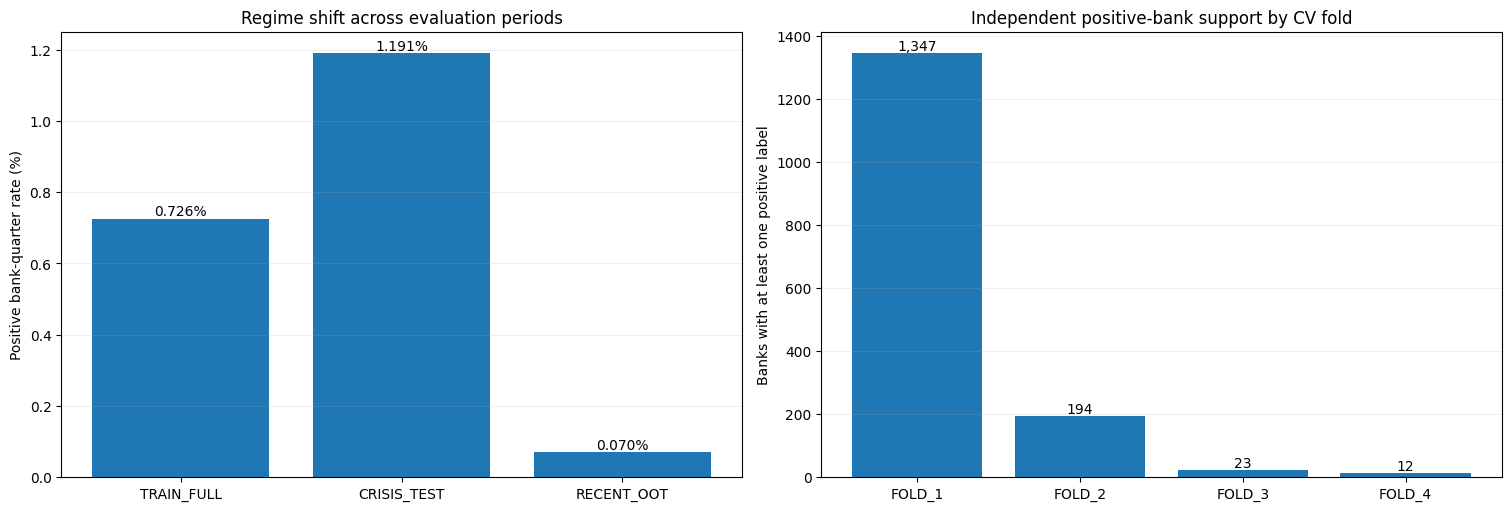

In [229]:
# 7.3 — VISUAL EVALUATION OF FINAL SPLITS & CV FOLD RISK
# Derived from already displayed audit tables; no imports, no dataset changes.
assert "FINAL_SPLIT_AUDIT_V3" in globals()
assert "CV_SPLIT_AUDIT_V3" in globals()
_main = FINAL_SPLIT_AUDIT_V3.query(
    "segment in ['TRAIN_FULL', 'CRISIS_TEST', 'RECENT_OOT']").copy()
_val = CV_SPLIT_AUDIT_V3.loc[
    CV_SPLIT_AUDIT_V3["segment"].str.endswith("_VALIDATION")
].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
axes[0].bar(_main["segment"], _main["positive_rate_pct"])
axes[0].set(title="Regime shift across evaluation periods",
            ylabel="Positive bank-quarter rate (%)")
axes[0].grid(axis="y", alpha=.2)
for idx, val in enumerate(_main["positive_rate_pct"]):
    axes[0].text(idx, val, f"{val:.3f}%", ha="center", va="bottom")
axes[1].bar(_val["segment"].str.replace("_VALIDATION", "", regex=False),
            _val["positive_banks"])
axes[1].set(title="Independent positive-bank support by CV fold",
            ylabel="Banks with at least one positive label")
axes[1].grid(axis="y", alpha=.2)
for idx, val in enumerate(_val["positive_banks"]):
    axes[1].text(idx, val, f"{int(val):,}", ha="center", va="bottom")
plt.show()

### Interpretation — Why two tests and expanding CV?

The crisis test has a substantially higher positive rate (**1.191%**) than recent OOT (**0.071%**); the model therefore faces different error tradeoffs. Expanding-validation folds contain **1,347 / 194 / 23 / 12** positive banks: report each fold and avoid choosing a threshold based on a fold with very few events. Use pooled out-of-fold predictions with per-fold diagnostics; leave both tests untouched.

## 7.4 — Final methodological decision

**Development:** 1984–2006, with four chronological expanding-window folds. **Crisis test:** 2008–2012 (1,880 positive quarters / 487 positive banks). **Recent OOT:** 2014–2025 (179 / 55). Years **2007 and 2013** are held out as horizon-separation gaps.

A single pooled validation score can obscure highly unequal positive counts: validation folds contain **1,347, 194, 23 and 12** positive banks. Select hyperparameters using out-of-fold predictions, inspect each fold separately, and fix thresholds before evaluating either test regime. These dates support a **cross-crisis research experiment**, not a claim of universal optimality or a production-ready 2026 retraining process.

The exact counts and horizon assertions are reported by the executable split audit above.

<a id="p2-s8"></a>
# 8 — Final conclusion and Phase 3 handoff

**Data integrity:** The 1984–2026 bank-quarter Silver archive is retained with lineage and SHA checks. FDIC History has **508,660 verified records** and was used to investigate institutional exits. V3 changes only the **definition of the prediction outcome**; it does not impute historical financial values or overwrite strict V2 evidence.

**Label decision:** Use `y_failure_4q_v3` on `MODEL_ELIGIBLE_V3` (1,668,293 eligible bank-quarters, 10,852 eligible positive quarters). Use `ROBUSTNESS_ELIGIBLE_V3` to exclude 7,514 administrative cases lacking strong independent closure evidence. Remaining V3 `NA` = 14,316 and are not eligible negative examples.

**Split decision:** Develop on 1984–2006 with four expanding folds; reserve **2008–2012** for crisis testing and **2014–2025** for rare-event OOT testing. Exclude 2007 and 2013 as full-year horizon gaps. These bank-level aggregates can include repeated quarters of the same failed institution.

**Phase 3 contract:** Read the original SHA-pinned Silver predictors separately from the V3 label table. Join **only on `(CERT, REPDTE)`**; filter eligibility, keep the split manifest unchanged, and exclude every outcome, future-date, administrative or audit field from features. Use Polars Lazy, benchmark against pandas, and verify PySpark calculations. Keep scaling, imputation, feature engineering for modeling and class rebalancing inside the training portions; do not fit them on test years.

The next optional export cell **writes a separate V3 label file and versioned handoff manifest** without modifying old V2 handoffs or Silver.

In [230]:
# ============================================================
# 8.1 — ADDITIVE V3 HANDOFF FOR PHASE 3 (VERSIONED, SHA-PINNED)
# Preserves the original Silver file, V2 artifacts and notebooks.
# Writes separate V3 label/split metadata ONLY when this cell runs.
# ============================================================

assert "Y_LABELS_V3" in globals() and "FINAL_SPLIT_AUDIT_V3" in globals()
assert bool(HISTORY_VERIFIED_V2), "FDIC History provenance missing"
assert "SILVER_PATH" in globals() and Path(SILVER_PATH).is_file()
assert "SILVER_MANIFEST" in globals()
assert sha256_file(SILVER_PATH) == SILVER_MANIFEST["sha256"], "Silver SHA drift"
assert "RUN_DIR" in globals() and "HISTORY_PATH_V2" in globals()

# Export audit/label columns separately from Silver financial predictors.
_export_cols = [
    "CERT", "REPDTE", "HORIZON_END", "y_primary_4q_v2", "y_failure_4q_v3",
    "MODEL_ELIGIBLE_V2", "MODEL_ELIGIBLE_V3", "ROBUSTNESS_ELIGIBLE_V3",
    "HIGH_RISK_REVIEW_V3", "outcome_status_4q_v2", "outcome_status_4q_v3",
    "ADMIN_REVIEW_V2", "EVENT_MATURE_V3"]
assert set(_export_cols).issubset(Y_LABELS_V3.columns)
_v3_export = Y_LABELS_V3[_export_cols].copy()
_v3_year = pd.to_datetime(_v3_export["REPDTE"]).dt.year
_v3_split_conditions = []
_v3_split_names = []
for _split_name, (_y_start, _y_end) in SPLIT_V3_PROPOSED.items():
    _v3_split_conditions.append(_v3_year.between(_y_start, _y_end))
    _v3_split_names.append(_split_name)
_v3_export["TEMPORAL_SPLIT_V3"] = np.select(
    _v3_split_conditions, _v3_split_names, default="OUTSIDE_SPLIT")
_v3_export["TRAINING_COHORT_V3"] = (
    _v3_export["MODEL_ELIGIBLE_V3"]
    & _v3_export["TEMPORAL_SPLIT_V3"].eq("TRAIN_FULL"))
assert not _v3_export.duplicated(["CERT", "REPDTE"]).any()
assert len(_v3_export) == len(Y_LABELS_V2)
assert not (_v3_export["TRAINING_COHORT_V3"] &
            _v3_export["y_failure_4q_v3"].isna()).any()

_v3_hist_hash = sha256_file(HISTORY_PATH_V2)
_v3_output_dir = (Path(RUN_DIR) / "label_v3_event_based" /
                  ("history_" + _v3_hist_hash[:12]))
_v3_output_dir.mkdir(parents=True, exist_ok=True)
_v3_label_path = _v3_output_dir / "bank_quarter_labels_event_based_v3.parquet"
_v3_manifest_path = _v3_output_dir / "phase2_to_phase3_handoff_v3.json"

if _v3_label_path.is_file():
    _old_export = pd.read_parquet(_v3_label_path)
    pd.testing.assert_frame_equal(
        _old_export, _v3_export, check_dtype=False, check_exact=True, check_freq=False)
else:
    _v3_stage = _v3_output_dir / "bank_quarter_labels_event_based_v3.stage.parquet"
    assert not _v3_stage.exists(), "Stale V3 stage; inspect before retry"
    _v3_export.to_parquet(_v3_stage, index=False)
    os.replace(_v3_stage, _v3_label_path)

_v3_manifest = {
    "phase": "PHASE2", "version": "3.0-event-based-4q",
    "source_scope": "FULL_HISTORY_1984Q1_TO_2026Q2",
    "silver_panel": str(SILVER_PATH),
    "silver_sha256": sha256_file(SILVER_PATH),
    "failure_registry": str(FAIL_REF_PATH),
    "failure_registry_sha256": sha256_file(FAIL_REF_PATH),
    "institutions_reference": str(INST_REF_PATH),
    "institutions_reference_sha256": sha256_file(INST_REF_PATH),
    "history_source": str(HISTORY_PATH_V2),
    "history_sha256": _v3_hist_hash,
    "label_file": str(_v3_label_path),
    "label_sha256": sha256_file(_v3_label_path),
    "rows": int(len(_v3_export)),
    "label_column": "y_failure_4q_v3",
    "eligibility_column": "MODEL_ELIGIBLE_V3",
    "robustness_column": "ROBUSTNESS_ELIGIBLE_V3",
    "label_definition": "FDIC-confirmed failure in (REPDTE, REPDTE+4Q]; mature non-failures are 0",
    "v2_comparison_target": "y_primary_4q_v2",
    "counts": {"y1": int(_v3_export.y_failure_4q_v3.eq(1).sum()),
               "y0": int(_v3_export.y_failure_4q_v3.eq(0).sum()),
               "na": int(_v3_export.y_failure_4q_v3.isna().sum()),
               "eligible": int(_v3_export.MODEL_ELIGIBLE_V3.sum())},
    "time_column": "REPDTE",
    "split_windows": {key: list(val) for key, val in SPLIT_V3_PROPOSED.items()},
    "expanding_cv_windows": {
        key: {"train": list(w[0]), "gap": list(w[1]), "validation": list(w[2])}
        for key,w in CV_V3_PROPOSED.items()},
    "training_cohort_column": "TRAINING_COHORT_V3",
    "forbidden_predictors": [
        "CERT", "REPDTE", "HORIZON_END", "y_failure_4q_v3", "y_primary_4q_v2",
        "FAILURE_DATE", "ASSISTANCE_DATE", "END_DATE", "EFFDATE", "CHANGECODE",
        "CHANGEC1", "CHANGECODE_DESC", "ENDEFYMD", "ACTIVE", "RESTYPE",
        "FAILDATE", "FAILYR", "label_status", "censor_reason",
        "label_screened_4q", "label_assignment_4q", "ENDPOINT_OBSERVED",
        "NEXT4_REPORT_COUNT", "CONTINUOUS_4Q", "ADMIN_REVIEW_V2", "outcome_status_4q_v2",
        "outcome_status_4q_v3", "MODEL_ELIGIBLE_V2", "MODEL_ELIGIBLE_V3",
        "ROBUSTNESS_ELIGIBLE_V3", "EVENT_MATURE_V3", "HIGH_RISK_REVIEW_V3",
        "TEMPORAL_SPLIT_V3", "TRAINING_COHORT_V3"],
    "status": "V3_EVENT_BASED_POLICY_APPROVED_FOR_EXPERIMENTAL_PHASE3",
    "limits": ["Verify point-in-time feature availability before fitting",
               "V3 negatives signify no recorded FDIC failure, not survival",
               "Keep 7,514 flagged administrative cases as robustness exclusion",
               "Do not tune on either held-out crisis or recent OOT test"]
}

if _v3_manifest_path.is_file():
    _previous_manifest = json.loads(_v3_manifest_path.read_text(encoding="utf-8"))
    assert _previous_manifest == _v3_manifest, (
        "V3 manifest drift under pinned source; choose a new policy version")
else:
    _manifest_stage = _v3_output_dir / "phase2_to_phase3_handoff_v3.stage.json"
    assert not _manifest_stage.exists(), "Stale V3 manifest stage"
    _manifest_stage.write_text(json.dumps(_v3_manifest, ensure_ascii=False, indent=2),
                               encoding="utf-8")
    os.replace(_manifest_stage, _v3_manifest_path)

print("V3 Phase 3 label file:", _v3_label_path)
print("V3 Phase 3 manifest:", _v3_manifest_path)
print("Source-pinned output; V2 and Silver untouched.")
display(pd.DataFrame([_v3_manifest["counts"]]))

V3 Phase 3 label file: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v3_event_based\history_0a842bef9739\bank_quarter_labels_event_based_v3.parquet
V3 Phase 3 manifest: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v3_event_based\history_0a842bef9739\phase2_to_phase3_handoff_v3.json
Source-pinned output; V2 and Silver untouched.


,y1,y0,na,eligible
0,10859,1657441,14316,1668293


## Phase 2 — Final release note

**Ready for Phase 3 exploration:** source-verified financial Silver, separate V2/V3 labels, an explicit 4Q target and a chronologically audited split policy. **Not yet a fitted or deployed model:** feature release vintages, administrative-event ambiguity, imputation choices and live calibration remain research checks.

**Handoff files:** the cell above prints the new `bank_quarter_labels_event_based_v3.parquet` and `phase2_to_phase3_handoff_v3.json` locations. Existing notebook outputs are retained for inspection; rerun the new V3 construction, audit, charts and export in the local kernel before using the resulting handoff.